# Resolution-preserving weakly supervised rice leaf disease recognition

This notebook goes from data preparation to the final results, in stage order. It is assembled by `src/build_notebook.py` from the code in `src/`, the stage launcher notebooks and the final tables and figures in `results/`, so it matches the code of the commit it was built from.

**By default nothing heavy runs.** Every launcher cell is guarded by `RUN_STAGES = False`, so the cells show the code of each step and then the saved results (reports, tables, figures), which were generated from the run records in `runs/`. No cell splits, trains or evaluates on test unless `RUN_STAGES` is set. The permanent splits are never regenerated.

Every number in a table or figure below was read from a run record; none is typed by hand. A result that does not exist yet is shown as *pending* and never filled with an estimate.

**Names and disclosures.** The method is called Attention MIL: a gated-attention head trained on the cached descriptions of a frozen DINOv3 ViT-B/16 for the tiles of a photo. It is compared with InceptionV3, EfficientNetV2-S, ConvNeXt-T and Swin-T fine-tuned on whole photos. The headline split is the session-blocked split. All audits and heat-map ratings are disclosed AI model ratings, never human ratings. Comparisons declared after the means were seen are marked post-hoc. The photos themselves are not part of this repository; the only photo images are the two figures `final_samples` and `final_heatmaps` that the paper also shows. The pipeline diagram (Fig. 1) is drawn in TikZ inside the paper.

## Setup and helpers

In [1]:
import hashlib, json, os, sys
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd

# The checkout that holds runs/, results/ and docs/ (set RICETEIN_PROJECT_ROOT to point elsewhere).
PROJECT_ROOT = Path(os.environ.get("RICETEIN_PROJECT_ROOT", "..")).resolve()
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
RUN_STAGES = False      # True re-runs the stage launchers: hours of GPU time, and it needs the data and a clean commit

def show_report(relative):
    path = PROJECT_ROOT / relative
    display(Markdown(path.read_text()) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def show_table(relative):
    path = PROJECT_ROOT / relative
    display(pd.read_csv(path) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def show_figure(relative):
    path = PROJECT_ROOT / relative
    display(Image(filename=str(path)) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def guard(label):
    print(f"Not re-run ({label}). Set RUN_STAGES = True to run it; the saved results are shown below.")

print("Project:", PROJECT_ROOT, "| re-running stages:", RUN_STAGES)


Project: /home/aztrek/ricetein-publish | re-running stages: False


## Stage 0: Groundwork

Seeds, settings files, run records, environment check.

Code: `src/skeleton.py`, `src/config.py`, `src/seeding.py`, `src/records.py`, `src/kaggle_bootstrap.py`, `src/smoke_check.py`. The code itself is in the source appendix at the end.

# Stage 0: walking skeleton (local machine)

The whole pipeline, end to end, on 20 photos: cut native-resolution tiles, describe them with
DINOv3 ViT-B/16, train a small gated-attention head for 50 steps, score the 8 held-back photos and
write a run record. The scores mean nothing. Stage 0 is done when this run and the Kaggle run give
**the same predicted labels and scores, with probabilities within 1e-3** (Stage 0).

The code lives in `src/skeleton.py`; this notebook only calls it.

In [2]:
if RUN_STAGES:
    from src.config import load_config, path_for
    from src.skeleton import compare_runs, run

    CONFIG = "configs/skeleton.yaml"
    config = load_config(CONFIG)
    runs = path_for(config, "runs")
else:
    guard('00_skeleton.ipynb')


Not re-run (00_skeleton.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 1. Run on this machine

A run name can only be used once (`RunRecorder` refuses to overwrite). Commit first, so the run
record holds a clean code version.

In [3]:
if RUN_STAGES:
    metrics = run(CONFIG, "stage0_skeleton_halo")
    metrics
else:
    guard('00_skeleton.ipynb')


Not re-run (00_skeleton.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 2. Run on Kaggle

From the terminal (the code dataset must match the current commit):

```
./scripts/kaggle_sync_code.sh
./scripts/kaggle_push.sh 00-skeleton
uv run kaggle kernels status aztrek/ricetein-00-skeleton
./scripts/kaggle_pull.sh 00-skeleton      # files runs/stage0_skeleton_kaggle/
```

## 3. Compare (the Stage 0 "done when" check)

In [4]:
if RUN_STAGES:
    ok = compare_runs(runs / "stage0_skeleton_halo", runs / "stage0_skeleton_kaggle",
                      atol=config["skeleton"]["compare_atol"])
    assert ok, "local and Kaggle runs disagree: see the FAIL lines above"
    print("Stage 0 check passed.")
else:
    guard('00_skeleton.ipynb')


Not re-run (00_skeleton.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## Stage 1: Inventory and the common leaf scale

Counts, per-photo properties, leaf width and the rescale rule.

Code: `src/inventory.py`, `src/inventory_report.py`, `src/leaf_width.py`. The code itself is in the source appendix at the end.

**Note.** The leaf-width measurements were made by disclosed AI model raters, not by people; the report names them.

# Stage 1: inventory

Turns the downloads into a fixed, fully described list of photos that every later stage builds on, and
settles whether photos are tiled at native resolution or rescaled first (Stage 1).

All logic lives in `src/inventory.py`, `src/leaf_width.py` and `src/inventory_report.py`; this notebook
only calls them. Outputs: `data/inventory.csv`, `data/paddy_inventory.csv`, `data/leaf_width_selection.csv`
and `docs/reports/inventory_report.md`.

In [5]:
if RUN_STAGES:
    from IPython.display import Markdown, display

    from src.config import load_config
    from src.inventory import write_inventories
    from src.inventory_report import write_report
    from src.leaf_width import evaluate, freeze_selection

    config = load_config("configs/inventory.yaml")
else:
    guard('01_inventory.ipynb')


Not re-run (01_inventory.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 1. Inventory of both datasets

Every file is listed (not only images), with checksum, perceptual hash, size, camera, capture time and JPEG quality. About a minute on 16 CPU threads.

In [6]:
if RUN_STAGES:
    inventories = write_inventories(config)
else:
    guard('01_inventory.ipynb')


Not re-run (01_inventory.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 2. Photos for the pixel-scale check

The 30 photos are chosen once (one per equal-width band of photo size) and frozen, so every measurer sees the same set.

In [7]:
if RUN_STAGES:
    selected = freeze_selection(config)  # reads the frozen file if it already exists
    selected
else:
    guard('01_inventory.ipynb')


Not re-run (01_inventory.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 3. Report

In [8]:
if RUN_STAGES:
    display(Markdown(write_report(config)))
else:
    guard('01_inventory.ipynb')


Not re-run (01_inventory.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 4. Leaf-width measurement (two raters, in a terminal)

Two measurers each run, on their own and without looking at the other's numbers (2026-11-07: Ahsan and
`model_rater_a`, a model rater that measured through the same tool code; the report names it as such):

```
uv run python -m src.leaf_width measure --measurer <name>
```

Then `uv run python -m src.leaf_width decide` applies the pre-declared rule and writes
`data/pixel_scale_decision.json`; re-run this notebook and section 8 of the report fills in.

In [9]:
if RUN_STAGES:
    result = evaluate(config)  # reads only; `python -m src.leaf_width decide` writes the decision
    print(result.get("reason") or (f"rho = {result['spearman_rho']:.3f} -> rescale: {result['rescale']}"
                                   if result["complete"] else f"pending: {result['answered'] or 'nobody yet'}"))
else:
    guard('01_inventory.ipynb')


Not re-run (01_inventory.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [10]:
show_report('docs/reports/inventory_report.md')

# Stage 1 inventory report

Built by `src/inventory_report.py` from `data/inventory.csv` and `data/paddy_inventory.csv`. Every number is computed; the only typed inputs are the published counts and the record of which hash groups were inspected by eye (`configs/inventory.yaml`, `report`).

## 1. Primary dataset: class counts

| class | folder | found | published (Do 2019) | difference |
|---|---|---|---|---|
| healthy | Healthy | 1488 | 1488 | 0 |
| leaf blast | LeafBlast | 779 | 779 | 0 |
| brown spot | BrownSpot | 523 | 523 | 0 |
| hispa | Hispa | 565 | 563 | 2 |

Total **3,355** files in `LabelledRice/Labelled/` (published: 3,353). The extra photos (hispa +2) are not exact copies of any other photo (section 3).

The download's other folder(s) (`RiceDiseaseDataset/`) hold 2,092 files: 2,092 are byte-identical copies of inventoried photos and 2,092 of those carry the same class. They add no photos, so they are ignored and no photo is counted twice.

## 2. File integrity

| dataset | files | decode fully | formats | modes | rotation tags |
|---|---|---|---|---|---|
| primary | 3,355 | 3,355 | JPEG | RGB | 0 |
| Paddy Doctor | 16,225 | 16,225 | JPEG | RGB | 0 |

Every file decodes fully; formats: JPEG; colour modes: RGB; no file carries a rotation tag, so photos are read as stored and orientation handling cannot differ between machines.

## 3. Exact duplicates (same SHA-256)

- **Primary:** 0 duplicate groups.
- **Between the datasets:** 0 shared files.
- **Paddy Doctor:** 144 groups covering 301 files (groups of 2: 135, groups of 3: 6, groups of 4: 2, groups of 5: 1). In the 4 classes used for zero-shot testing: 152 files in 74 groups, i.e. 78 extra copies. 1 group(s) span more than one class (`downy_mildew/PDD06425.jpg`, `tungro/PDD12798.jpg`); none of them is in the 4 test classes. Every group has the same variety and age in `metadata.csv`, so these look like files stored twice in the release, not separate photos.

**To decide in Stage 3** (`splits/paddy4.csv`): count each image once.

## 4. Photo size by class (a possible shortcut)

Shorter side in pixels.

| class | photos | shortest | median | longest | at 3120 px | median MB |
|---|---|---|---|---|---|---|
| healthy | 1488 | 826 | 2000 | 3120 | 18% | 2.47 |
| leaf blast | 779 | 734 | 1736 | 3120 | 9% | 1.58 |
| brown spot | 523 | 812 | 2080 | 3120 | 23% | 2.18 |
| hispa | 565 | 877 | 1946 | 3120 | 21% | 2.39 |

Photos are square or nearly so (longer side at most 0.06% longer than the shorter); the shorter side runs from 734 to 3120 px (median 1918). The class with the smallest photos is **leaf blast** (median 1736 px, against 2080 px for brown spot). A model could pick up size instead of disease; the photo-properties baseline (Stage 4b) measures how much.

## 5. Camera, capture day and JPEG quality by class

**Camera (EXIF make and model).**

| class | Apple iPhone 6s Plus | Apple iPhone X | Xiaomi Redmi Note 4 |
|---|---|---|---|
| healthy | 4 (<1%) | 58 (4%) | 1,426 (96%) |
| leaf blast | 111 (14%) | 60 (8%) | 608 (78%) |
| brown spot | 18 (3%) | 48 (9%) | 457 (87%) |
| hispa | 0 (0%) | 0 (0%) | 565 (100%) |

3 cameras appear. Share of photos not taken with the most common one (Xiaomi Redmi Note 4): healthy 4%, leaf blast 22%, brown spot 13%, hispa 0%. A model could pick up the camera instead of the disease; Stage 4b adds a declared camera-only baseline next to the methodology's baselines.

**Capture day (EXIF DateTimeOriginal).**

| capture day | healthy | leaf blast | brown spot | hispa |
|---|---|---|---|---|
| (none) | 1 | 0 | 0 | 0 |
| 2019-04-17 | 0 | 10 | 0 | 0 |
| 2019-04-18 | 62 | 161 | 66 | 0 |
| 2019-04-19 | 951 | 536 | 61 | 468 |
| 2019-04-20 | 67 | 62 | 330 | 44 |
| 2019-04-21 | 45 | 4 | 33 | 0 |
| 2019-04-24 | 362 | 6 | 33 | 53 |

Most common capture day per class: healthy: 64% on 2019-04-19; leaf blast: 69% on 2019-04-19; brown spot: 63% on 2019-04-20; hispa: 83% on 2019-04-19. Where classes were photographed on different days, lighting and session conditions are partly tied to the class; this is reported, not corrected, and is one more reason the zero-shot test matters.

**JPEG quality** (the IJG quality whose luminance table matches; exact for 3,355 of 3,355 photos): quality 90: 1, quality 100: 3,354. Compression is practically uniform, so it cannot act as a shortcut. Different from the rest: `Healthy/IMG_20190419_145234.jpg` (quality 90, capture time missing).

## 6. Identical perceptual hashes (preview for Stage 2b)

13 groups of primary photos share an identical 64-bit perceptual hash (27 photos); 6 of them contain more than one class. 6 of these 6 were inspected by eye (2026-11-04): different leaves with the same layout (one leaf lying diagonally on a white background), not copies. Their photos were taken 3 min to 1 d 2 h 13 min apart. A hash match alone therefore means little on this dataset: the Stage 2b duplicate search will flag look-alike pairs, and the two-person review decides.

## 7. Paddy Doctor (held out; zero-shot only)

16,225 photos in 13 classes. Sizes: 1080 x 1440: 16,219, 1440 x 1080: 6. JPEG quality: quality 75: 16,225. Camera EXIF on 0 photos. The 4 shared classes hold 8,164 files: normal 2,405, blast 2,351, brown_spot 1,257, hispa 2,151. `metadata.csv` matches the files one to one (checked when the inventory is built; variety and age are joined).

## 8. Pixel scale: crops or resized photos?

Rule (pre-declared methodology): measure leaf width on 30 photos drawn across the size range; if Spearman's rho with the shorter side is >= 0.5, rescale every photo to the median leaf width before tiling, otherwise keep native resolution. The photos are one random pick per equal-width band of photo size on a log scale (seed 0), covering 734-3120 px, frozen in `data/leaf_width_selection.csv`. 2 measurers measure each photo independently, in their own shuffled order; at least 20 photos must be measurable (protocol in `src/leaf_width.py`). If rescaling is triggered, the median leaf width comes from these 30 photos, some of which are later test photos; it is a label-free geometry calibration declared in advance.

Spearman's rho = **0.539** (p = 0.00253, n = 29; 1 photos marked unmeasurable and left out), so: **rescale every photo to the median leaf width before tiling**. Median leaf width 195 px. The two measurers (ahsan, model_rater_a) agree with Spearman 0.98; their widths differ by 3.2% at the median (largest 35.6%); rho from each measurer alone: ahsan 0.542, model_rater_a 0.528. Leaving out one photo at a time gives rho 0.488-0.613; 5 of 29 single removals would flip the verdict. Model rater(s), not people: `model_rater_a` (an AI model measuring from rendered images with a coordinate grid, through the same tool code). How the rescale is applied: a log-log fit of leaf width on shorter side (slope 0.78) estimates each photo's leaf width, and the photo is scaled so that estimate becomes the median: factor 2.03 at 734 px to 0.66 at 3120 px (`rescale_factor` in `src/leaf_width.py`). Decision record: `data/pixel_scale_decision.json`.

| photo_id | short_side | ahsan | model_rater_a | leaf_width_px | used |
|---|---|---|---|---|---|
| LeafBlast/IMG_3169.jpg | 734 | 44.6 | 46.0 | 45.3 | True |
| BrownSpot/IMG_3177.jpg | 812 | – | 131.6 | 131.6 | False |
| LeafBlast/IMG_4953.jpg | 846 | 68.8 | 68.0 | 68.4 | True |
| Hispa/IMG_20190419_095315.jpg | 877 | 84.1 | 73.0 | 78.6 | True |
| Healthy/IMG_3203.jpg | 912 | 104.3 | 106.8 | 105.6 | True |
| LeafBlast/IMG_20190419_095029.jpg | 940 | 132.5 | 132.4 | 132.4 | True |
| LeafBlast/IMG_20190419_114718.jpg | 1000 | 270.6 | 268.0 | 269.3 | True |
| Hispa/IMG_20190424_131101.jpg | 1040 | 191.0 | 198.9 | 195.0 | True |
| Healthy/IMG_20190424_130136.jpg | 1085 | 328.5 | 336.4 | 332.4 | True |
| Hispa/IMG_20190419_171917.jpg | 1136 | 113.6 | 131.5 | 122.6 | True |
| BrownSpot/IMG_20190424_131042.jpg | 1197 | 245.4 | 264.1 | 254.8 | True |
| LeafBlast/IMG_20190424_133722.jpg | 1297 | 268.1 | 263.8 | 266.0 | True |
| Hispa/IMG_20190419_152515.jpg | 1348 | 205.8 | 199.3 | 202.6 | True |
| LeafBlast/IMG_20190419_112203.jpg | 1436 | 68.9 | 48.1 | 58.5 | True |
| Hispa/IMG_20190419_095917.jpg | 1478 | 150.1 | 141.5 | 145.8 | True |
| Hispa/IMG_20190419_165718.jpg | 1566 | 145.8 | 139.4 | 142.6 | True |
| Healthy/IMG_20190419_095521.jpg | 1664 | 194.7 | 193.0 | 193.8 | True |
| Healthy/IMG_20190419_100104.jpg | 1726 | 123.7 | 102.9 | 113.3 | True |
| Hispa/IMG_20190419_173037.jpg | 1799 | 132.3 | 149.0 | 140.6 | True |
| LeafBlast/IMG_3014.jpg | 1881 | 137.5 | 134.3 | 135.9 | True |
| Hispa/IMG_20190419_163245.jpg | 1976 | 210.6 | 217.2 | 213.9 | True |
| Hispa/IMG_20190419_161346.jpg | 2111 | 238.4 | 179.5 | 209.0 | True |
| Healthy/IMG_20190419_161852.jpg | 2155 | 153.8 | 142.0 | 147.9 | True |
| Healthy/IMG_20190420_194921.jpg | 2313 | 323.1 | 308.2 | 315.6 | True |
| Hispa/IMG_20190419_163101.jpg | 2404 | 261.3 | 264.6 | 263.0 | True |
| BrownSpot/IMG_20190420_191021.jpg | 2454 | 505.2 | 467.8 | 486.5 | True |
| Hispa/IMG_20190419_110519.jpg | 2616 | 224.6 | 219.9 | 222.2 | True |
| BrownSpot/IMG_20190420_195258.jpg | 2817 | 405.3 | 385.7 | 395.5 | True |
| Hispa/IMG_20190419_140037.jpg | 2895 | 221.7 | 221.6 | 221.6 | True |
| BrownSpot/IMG_20190419_135038.jpg | 3120 | 243.5 | 249.3 | 246.4 | True |

## 9. What this means for the next stages

- **Stage 2a (backgrounds):** the photos inspected so far show single leaves on plain white; the audit
  measures how general that is. If it holds, robustness to clutter cannot be claimed from in-domain
  results.
- **Stage 2b (near-duplicates):** expect hash matches between different leaves (section 6); the two-person
  review decides. Hash with `src.inventory.load_for_hash` and the `hashing` settings in `base.yaml`.
- **Stage 3 (splits):** use `photo_id` from `data/inventory.csv` as the key. For `splits/paddy4.csv`, follow
  section 3.
- **Stage 4b (shortcuts):** sections 4 and 5 show how size, camera and capture day are spread over the
  classes; the declared baselines (plus the camera-only one) measure what a model can get from them.
- **Stage 6 (tiling):** depends on the pixel-scale result (section 8).


## Stage 2: Audits

Near-duplicates, background audit, label check, Otsu review.

Code: `src/duplicates.py`, `src/background_audit.py`, `src/label_check.py`, `src/audit_report.py`, `src/review_tool.py`, `src/otsu.py`, `src/otsu_gallery.py`. The code itself is in the source appendix at the end.

**Note.** Every judgement in this stage (duplicate review, background audit, label check, Otsu review) was made by disclosed AI model raters, not by people. Where a launcher cell below speaks of team members or human parts, it describes how the tool can be used by people; no person-made judgement is part of the results.

# Stage 2: data audits

Backgrounds (2a), near-duplicates (2b), overlap with Paddy Doctor (2c) and a label sanity check (2d)
(Stage 2). All logic lives in `src/duplicates.py`, `src/background_audit.py`, `src/label_check.py`
and `src/audit_report.py`; this notebook only calls them. The human parts (labelling, reviewing, checking)
run in a terminal; re-run this notebook afterwards and the report fills in.


In [11]:
if RUN_STAGES:
    from IPython.display import Markdown, display

    from src import background_audit, duplicates
    from src.audit_report import write_report
    from src.config import load_config

    config = load_config("configs/audits.yaml")
else:
    guard('02_audits.ipynb')


Not re-run (02_audits.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 1. Near-duplicate candidates (2b, 2c)

Hashes every photo of both datasets in 8 orientations, describes every whole photo with E1 (GPU), flags pairs by
the two pre-declared rules, runs the automatic keypoint check and writes the blind review queue. The caches are
git-ignored and reused. Refuses to run again once anyone has started reviewing (the queue is frozen).


In [12]:
if RUN_STAGES:
    from src.config import REPO_ROOT

    if not (REPO_ROOT / config["duplicates"]["review_file"]).exists():
        duplicates.flag(config)
else:
    guard('02_audits.ipynb')


Not re-run (02_audits.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 2. Background sample (2a)

60 random photos per class, drawn once with a fixed seed and frozen.


In [13]:
if RUN_STAGES:
    background_audit.sample(config)["class"].value_counts()
else:
    guard('02_audits.ipynb')


Not re-run (02_audits.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## 3. People, in a terminal

Each runs alone, without looking at anyone else's answers:

```
uv run python -m src.background_audit label --rater <name>     # two team members
uv run python -m src.duplicates review --reviewer <name>       # two team members
uv run python -m src.label_check check --checker <name>        # every team member
```

Then, together: `uv run python -m src.background_audit settle` and `uv run python -m src.duplicates settle`.
Finally `uv run python -m src.background_audit results`, `uv run python -m src.duplicates combine` and
`uv run python -m src.label_check results` write the final files.


## 4. Report

In [14]:
if RUN_STAGES:
    display(Markdown(write_report(config)))
else:
    guard('02_audits.ipynb')


Not re-run (02_audits.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [15]:
show_report('docs/reports/audit_report.md')

# Stage 2 audit report

Built by `src/audit_report.py` from the audit files; do not edit by hand.

## 1. Backgrounds (2a)

Sample: 60 random photos per class (seed 0), frozen in `data/background_audit_sample.csv`. Two raters label every photo alone, in their own shuffled order, without seeing its class: plain or cluttered, plus several leaves, hand, strong shadow. Disagreements on the background are settled together; both original labels are kept.

**Plain background: 100.0%** of 240 photos (95% CI 98.5%-100.0%). Raters model_rater_a and model_rater_b agree on 99.6% of photos (Cohen's kappa 0.00; not informative here: both raters used one category for almost every photo); 1 disagreements were settled together. Model raters, not people: `model_rater_a`, `model_rater_b` (independent instances of one AI model; initial reviews did not use each other's answers. Model agreement does not establish human inter-rater reliability). File: `data/background_audit.csv`.

| class | photos | plain | 95% CI |
|---|---|---|---|
| brown_spot | 60 | 100.0% | 94.0%-100.0% |
| healthy | 60 | 100.0% | 94.0%-100.0% |
| hispa | 60 | 100.0% | 94.0%-100.0% |
| leaf_blast | 60 | 100.0% | 94.0%-100.0% |

Flags (share of photos, per rater):

| flag | model_rater_a | model_rater_b |
|---|---|---|
| multiple_leaves | 0.0% | 0.0% |
| hand | 0.0% | 0.4% |
| strong_shadow | 15.8% | 21.2% |

## 2. Near-duplicates (2b) and overlap with Paddy Doctor (2c)

Flag rules (pre-declared methodology): perceptual hashes within 8 bits (any of 8 rotations/flips), or whole-photo E1 class-token cosine > 0.95. Automatic check: SIFT keypoints (photos at 1200 px), ratio test 0.75, each keypoint used once, RANSAC similarity transform (tolerance 8.0 px, scale 0.25-4.0x, also against the mirrored photo); a pair passes with >= 15 distinct inliers. Raters review every passed pair plus 200 random rejected pairs per comparison, blind to class and check result (deviation from "review every flagged pair", decided 2026-11-07).

| comparison | flagged | hash only | cosine only | both | pass check | queued |
|---|---|---|---|---|---|---|
| primary x Paddy Doctor | 2 | 2 | 0 | 0 | 0 | 2 |
| within primary | 84978 | 84157 | 724 | 97 | 373 | 573 |

Files: `data/duplicate_candidates.csv`, `data/duplicate_review_queue.csv`.

Reviewers model_rater_b and model_rater_c: Cohen's kappa 0.77; 61 disagreements adjudicated. Duplicate disagreements were adjudicated by model_rater_c with Ahsan's approval; original verdicts are preserved. Protocol and high-resolution rechecks: `data/duplicate_review/adjudication_protocol.json`. Model raters, not people: `model_rater_b`, `model_rater_c` (AI model instances; initial reviews did not use each other's answers. Model agreement does not establish human inter-rater reliability).

| comparison | round | passed | reviewed | confirmed same leaf |
|---|---|---|---|---|
| cross | 1 | False | 2 | 0 |
| primary | 1 | False | 200 | 0 |
| primary | 1 | True | 373 | 349 |

What the automatic check misses: primary x Paddy Doctor: 0 of 2 sampled rejected pairs confirmed (miss rate 0.0%, 95% CI 0.0%-84.2%); within primary: 0 of 200 sampled rejected pairs confirmed (miss rate 0.0%, 95% CI 0.0%-1.8%).

**Groups:** 3054 groups for 3355 photos; group sizes 1: 2840, 2: 170, 3: 24, 4: 12, 5: 1, 6: 4, 7: 1, 8: 1, 11: 1. **Label conflicts:** 21 photos in confirmed pairs with different classes (excluded from all experiments; `data/label_conflicts.csv`). **Overlap with Paddy Doctor:** 0 confirmed matches (`data/cross_dataset_overlap.csv`).

## 3. Label sanity check (2d)

Each configured checker looks at 20 random photos per class with the label shown, and says whether it looks right, looks like another class, or is unclear. No label is changed: the main results always use the original labels.

Checkers: model_rater_a. Model raters, not people: `model_rater_a` (independent instances of one AI model; initial reviews did not use each other's answers. Model agreement does not establish human inter-rater reliability). 80 answers on 80 photos; 1 answers on 1 photos look like another class (`data/suspect_labels.csv`).

| class | looks_like | answers |
|---|---|---|
| healthy | hispa | 1 |


In [16]:
show_report('docs/reports/otsu_report.md')

# Stage 5 Otsu quality check

A frozen random sample of 50 primary photos (seed 0; `data/otsu_review_sample.csv`) was inspected side by side using the actual Stage 5 preparation code. **model_rater_c is an AI model rater**, not a human segmentation annotator. Original and cleaned previews are in the ignored `cache/otsu_review/` directory; per-photo judgments are in `data/otsu_review.csv`.

A failure means visible leaf/pale symptom material was removed, or a conspicuous connected background shadow was retained. Thin boundary halos alone were not counted. These are qualitative model judgments, not pixel-level segmentation ground truth. The single batch export timestamp follows inspection; it is not a per-photo decision time.

Failures: **23/50 (46.0%; exact 95% CI 31.8%–60.7%)**: 5 with removed leaf material and 18 with a retained shadow. The fixed preprocessing recipe was not changed in response to this check. No disease-classification test scores were inspected.


## Stage 3: Splits

The locked grouped split and the session-blocked split (made once, never regenerated).

Code: `src/split.py`, `src/session_split.py`. The code itself is in the source appendix at the end.

# Stage 3: inspect the locked split

Read-only: the permanent split already exists and is never regenerated.

In [17]:
if RUN_STAGES:
    from src.config import load_config
    from src.split import read_folds, check_folds
    from IPython.display import Markdown, display
    from pathlib import Path
    config = load_config("configs/split.yaml")
    folds, checksum = read_folds(config)
    print("Locked split SHA-256:", checksum)
    print(check_folds(folds, 5, 0.02))
    display(Markdown(Path("../docs/reports/split_report.md").read_text()))
else:
    guard('03_splits.ipynb')


Not re-run (03_splits.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [18]:
show_report('docs/reports/split_report.md')

# Stage 3 split report

Built by `src/split.py`; do not edit by hand.

Primary dataset: 3334 photos in 3045 near-duplicate groups (21 photos excluded as label conflicts). StratifiedGroupKFold, 5 folds, seed 2026; validation = a stratified, grouped 1/8 of the other four folds (seed 2026 + round).

**`splits/folds.csv` SHA-256:** `9891c146c2a369ac455a4794a4707509a1508b3005a680b5d2257206f7023ba7`

Checks:

- every photo tested exactly once: **yes**
- no group in two roles within a round: **yes**
- class shares within 2% points: **yes**
- validation and test never overlap: **yes**
- worst class-share deviation: **0.21%**

| round | role | photos | healthy | leaf_blast | brown_spot | hispa |
|---|---|---|---|---|---|---|
| 1 | train | 2332 | 1036 | 541 | 361 | 394 |
| 1 | val | 335 | 148 | 78 | 52 | 57 |
| 1 | test | 667 | 296 | 154 | 104 | 113 |
| 2 | train | 2333 | 1036 | 541 | 361 | 395 |
| 2 | val | 334 | 148 | 78 | 52 | 56 |
| 2 | test | 667 | 296 | 154 | 104 | 113 |
| 3 | train | 2334 | 1036 | 541 | 362 | 395 |
| 3 | val | 333 | 148 | 77 | 52 | 56 |
| 3 | test | 667 | 296 | 155 | 103 | 113 |
| 4 | train | 2333 | 1036 | 540 | 362 | 395 |
| 4 | val | 334 | 148 | 78 | 52 | 56 |
| 4 | test | 667 | 296 | 155 | 103 | 113 |
| 5 | train | 2334 | 1036 | 540 | 362 | 396 |
| 5 | val | 334 | 148 | 78 | 52 | 56 |
| 5 | test | 666 | 296 | 155 | 103 | 112 |

Paddy Doctor test list `splits/paddy4.csv`: 8086 photos (healthy 2373, leaf_blast 2332, brown_spot 1240, hispa 2141); each byte-identical image once; SHA-256 `f07ef2a215ef9527a35417654c118c70b5b1b478f864dab933731e07480fe54d`.


In [19]:
show_report('docs/reports/session_split_report.md')

# Session-blocked split report

Built by `src/session_split.py`; do not edit by hand. A sensitivity split declared on 2026-11-14. The locked split is unchanged.

The same 3334 photos as the locked split, grouped into 74 capture blocks: runs of consecutive photos from one camera with no pause longer than 60 s, merged where they share a near-duplicate group. Block sizes: largest 287 photos (8.6% of all), median 24. StratifiedGroupKFold, 5 folds, seed 2026; validation = a stratified, grouped 1/8 of the other four folds.

**`splits/session_blocked/folds.csv` SHA-256:** `28fa6372f49bb5ff1b082c4ff7ae2b2709a6a70c59f6de1f768b15f3e09aa8f8`

Checks (class shares are reported, not enforced: whole blocks limit how even they can be):

- every photo tested exactly once: **yes**
- no group in two roles within a round: **yes**
- class shares within 2% points: **no**
- validation and test never overlap: **yes**
- worst class-share deviation: **26.53%**

| round | role | photos | healthy | leaf_blast | brown_spot | hispa |
|---|---|---|---|---|---|---|
| 1 | train | 2246 | 1006 | 544 | 290 | 406 |
| 1 | val | 350 | 194 | 75 | 34 | 47 |
| 1 | test | 738 | 280 | 154 | 193 | 111 |
| 2 | train | 2232 | 1018 | 543 | 268 | 403 |
| 2 | val | 452 | 137 | 76 | 190 | 49 |
| 2 | test | 650 | 325 | 154 | 59 | 112 |
| 3 | train | 2315 | 1009 | 543 | 364 | 399 |
| 3 | val | 332 | 178 | 76 | 24 | 54 |
| 3 | test | 687 | 293 | 154 | 129 | 111 |
| 4 | train | 2345 | 990 | 540 | 403 | 412 |
| 4 | val | 346 | 189 | 77 | 40 | 40 |
| 4 | test | 643 | 301 | 156 | 74 | 112 |
| 5 | train | 2350 | 1061 | 544 | 362 | 383 |
| 5 | val | 368 | 138 | 74 | 93 | 63 |
| 5 | test | 616 | 281 | 155 | 62 | 118 |

Share of test photos with a training photo from the same camera taken close in time (all five rounds):

| split | within 5 s | within 10 s | within 60 s |
|---|---|---|---|
| locked (`splits/folds.csv`) | 72.0% | 90.2% | 99.6% |
| session-blocked | 0.0% | 0.0% | 0.0% |


## Stage 4: Scoring and sanity baselines

Metrics, bootstrap, and baselines that never see the leaf.

Code: `src/metrics.py`, `src/stats.py`, `src/sanity_baselines.py`, `src/shortcut_baselines.py`. The code itself is in the source appendix at the end.

# Stage 4: sanity and shortcut baselines

Commit the code and split first. Every baseline has fixed settings; none is tuned on test.

In [20]:
if RUN_STAGES:
    from src.config import load_config
    from src.sanity_baselines import run, report
    from IPython.display import Markdown, display
    config = load_config("configs/sanity.yaml")
    display(Markdown(report(config, run(config, workers=4))))
else:
    guard('04_sanity.ipynb')


Not re-run (04_sanity.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [21]:
show_report('docs/reports/sanity_report.md')

# Stage 4 sanity baselines

Built by `src/sanity_baselines.py` from `runs/stage4_*`; do not edit by hand. Scores in percent on the **test** folds of the locked split (mean ± sd, 5 rounds, and the pooled out-of-fold predictions with 95% bootstrap intervals). Nothing here is tuned, so test scores are reported directly. Chance: 25% balanced accuracy.

| baseline | test macro-F1 | test balanced acc. | test accuracy | pooled macro-F1 [95% CI] | pooled balanced acc. [95% CI] | hispa recall | ECE |
|---|---|---|---|---|---|---|---|
| majority | 15.4 ± 0.0 | 25.0 ± 0.0 | 44.4 ± 0.0 | 15.4 [15.4, 15.4] | 25.0 [25.0, 25.0] | 0.0 | 0.556 |
| random_prior | 25.2 ± 2.1 | 25.2 ± 2.1 | 30.2 ± 1.8 | 25.2 [23.7, 26.6] | 25.2 [23.7, 26.6] | 18.6 | 0.698 |
| colour_only | 52.9 ± 2.5 | 55.0 ± 2.6 | 52.8 ± 2.5 | 52.9 [51.3, 54.6] | 55.0 [53.3, 56.8] | 53.7 | 0.129 |
| background_only | 48.9 ± 1.6 | 51.8 ± 1.6 | 49.2 ± 2.0 | 49.0 [47.4, 50.6] | 51.8 [50.1, 53.6] | 47.9 | 0.136 |
| properties_only | 32.3 ± 2.8 | 36.1 ± 3.2 | 37.9 ± 2.4 | 32.5 [31.0, 33.9] | 36.1 [34.6, 37.8] | 5.7 | 0.046 |
| camera_only | 17.4 ± 1.5 | 30.9 ± 1.0 | 21.7 ± 0.8 | 17.5 [16.2, 18.9] | 30.9 [30.0, 31.8] | 100.0 | 0.092 |

Background-only and photo-properties-only results exceed chance, suggesting dataset shortcuts. Imperfect Otsu masking can leave leaf material in the background inputs. See the separate Otsu quality review.

![Pooled test reliability charts](../../results/figures/stage4_reliability.svg)

Reliability bins and this figure are generated from saved predictions by `scripts/stage4_calibration.py`.


## Stage 5: Whole-image models

Fine-tuned InceptionV3, EfficientNetV2-S, ConvNeXt-T and Swin-T at 128, 224 and 448 px.

Code: `src/augment.py`, `src/photo_dataset.py`, `src/train_wholeimage.py`, `src/stage5.py`, `src/session_conditions.py`, `src/session_conditions_report.py`, `src/paired_conditions.py`. The code itself is in the source appendix at the end.

**Note.** The paired tests of Attention MIL against ConvNeXt-T at 448 px and against the 128 px and Otsu conditions were declared after the means were seen (post-hoc), and are marked so in the report.

# Stage 5: wholeimage on Kaggle

Thin launcher; all logic is in src/. Completed artifacts are preserved on resume. Do not edit src/ while workers run.

In [22]:
if RUN_STAGES:
    import sys
    from pathlib import Path
    root = Path("/kaggle/input")
    code = next(p for p in [root / "ricetein-code", *sorted(root.glob("*/*/ricetein-code"))] if p.is_dir())
    sys.path.insert(0, str(code))
    from src.kaggle_bootstrap import setup_env, run
    setup_env()
    run("src.pipeline", "--config", "configs/pipeline.yaml", "--stage", "5")
else:
    guard('05_wholeimage_kaggle.ipynb')


Not re-run (05_wholeimage_kaggle.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [23]:
show_report('docs/reports/session_conditions_report.md')

# Stage 5 other conditions on the session-blocked split

Declared on 2026-11-20 before any of these runs. Each of the four whole-image models is trained at
128 px and at 224 px with Otsu background removal; the model with the best validation score at 224 px
(convnext_tiny) is also trained at 448 px. Every model keeps the learning rate selected at 224 px on validation
photos, and the recipe and budget are those of the 224 px runs. Nothing was searched again. Every condition was
tested once, on the test photos of the 5 rounds. The 224 px rows are the runs of `docs/reports/session_report.md`.

Scores are test macro-F1 and balanced accuracy: mean ± SD over the 5 rounds, then the declared 95% photo range
and the 95% block range of the pooled test predictions (a block is a run of photos from one camera with no pause over
60 s; blocks are resampled together). In each comparison A is the run named first in the row: "A beats B" needs the
range above 0 **and** at least 4 of 5 round wins, and a row that fails either is "no clear difference". Differences are
in percentage points (A minus B). There are 9 conditions, 2 scores and 2 directions, so read a single row with that
number of comparisons in mind.

## Scores of every model and condition

| method | macro-F1 (mean ± SD) | macro-F1 photo range | macro-F1 block range | balanced acc. (mean ± SD) | balanced acc. photo range | balanced acc. block range | ECE |
|---|---|---|---|---|---|---|---|
| inceptionv3, 224 px | 72.0 ± 3.6 | [71.2, 74.3] | [68.1, 75.6] | 72.2 ± 4.9 | [71.9, 75.1] | [69.0, 76.4] | 0.072 |
| inceptionv3, 128 px | 56.9 ± 6.4 | [57.1, 60.5] | [52.5, 62.5] | 56.7 ± 5.5 | [56.6, 60.1] | [52.1, 62.0] | 0.056 |
| inceptionv3, 224 px + Otsu | 71.3 ± 3.4 | [70.9, 74.1] | [66.8, 75.4] | 70.8 ± 3.9 | [70.6, 74.0] | [66.4, 75.4] | 0.060 |
| efficientnetv2s, 224 px | 74.1 ± 4.8 | [74.3, 77.3] | [69.8, 78.8] | 73.9 ± 5.9 | [74.3, 77.4] | [69.5, 79.0] | 0.035 |
| efficientnetv2s, 128 px | 62.8 ± 4.7 | [63.2, 66.6] | [57.3, 68.5] | 62.4 ± 6.1 | [63.1, 66.7] | [57.1, 68.7] | 0.053 |
| efficientnetv2s, 224 px + Otsu | 70.2 ± 2.5 | [70.0, 73.0] | [65.0, 75.0] | 70.6 ± 4.2 | [70.8, 74.0] | [66.3, 75.6] | 0.055 |
| convnext_tiny, 224 px | 75.0 ± 5.0 | [74.4, 77.4] | [70.5, 79.1] | 75.8 ± 3.7 | [75.2, 78.3] | [71.9, 79.6] | 0.067 |
| convnext_tiny, 128 px | 67.8 ± 6.0 | [67.8, 71.0] | [63.5, 72.4] | 67.8 ± 6.4 | [67.6, 71.0] | [63.8, 72.4] | 0.082 |
| convnext_tiny, 224 px + Otsu | 73.5 ± 3.4 | [72.9, 75.8] | [69.7, 76.9] | 74.2 ± 3.3 | [74.0, 77.0] | [70.7, 77.9] | 0.071 |
| convnext_tiny, 448 px | 79.2 ± 3.8 | [78.8, 81.6] | [75.4, 82.6] | 79.1 ± 5.0 | [78.9, 81.8] | [75.5, 82.8] | 0.050 |
| swin_tiny, 224 px | 76.3 ± 4.1 | [75.8, 78.8] | [72.3, 79.8] | 75.8 ± 4.8 | [75.6, 78.7] | [71.4, 79.6] | 0.060 |
| swin_tiny, 128 px | 65.2 ± 4.4 | [64.9, 68.2] | [61.7, 69.0] | 65.6 ± 4.9 | [65.2, 68.6] | [61.6, 69.7] | 0.081 |
| swin_tiny, 224 px + Otsu | 71.7 ± 3.8 | [71.5, 74.5] | [66.9, 75.9] | 72.3 ± 4.9 | [72.0, 75.2] | [67.3, 76.6] | 0.031 |

## Does the condition beat the same model at 224 px?

| condition against 224 px of the same model | metric | difference (points) | photo range | block range | rounds won | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| inceptionv3, 128 px: condition beats 224 px | macro_f1 | -14.0 | [-16.0, -12.3] | [-17.3, -11.3] | 0/5 | no clear difference | no clear difference |
| inceptionv3, 128 px: condition beats 224 px | balanced_accuracy | -15.1 | [-17.2, -13.3] | [-18.5, -12.6] | 0/5 | no clear difference | no clear difference |
| inceptionv3, 224 px + Otsu: condition beats 224 px | macro_f1 | -0.3 | [-2.0, 1.4] | [-3.8, 2.1] | 2/5 | no clear difference | no clear difference |
| inceptionv3, 224 px + Otsu: condition beats 224 px | balanced_accuracy | -1.2 | [-3.0, 0.5] | [-5.2, 1.4] | 2/5 | no clear difference | no clear difference |
| efficientnetv2s, 128 px: condition beats 224 px | macro_f1 | -10.9 | [-12.6, -9.2] | [-14.7, -8.4] | 0/5 | no clear difference | no clear difference |
| efficientnetv2s, 128 px: condition beats 224 px | balanced_accuracy | -11.0 | [-12.7, -9.1] | [-15.0, -8.4] | 0/5 | no clear difference | no clear difference |
| efficientnetv2s, 224 px + Otsu: condition beats 224 px | macro_f1 | -4.4 | [-5.9, -2.8] | [-6.6, -2.4] | 1/5 | no clear difference | no clear difference |
| efficientnetv2s, 224 px + Otsu: condition beats 224 px | balanced_accuracy | -3.6 | [-5.2, -2.0] | [-5.5, -1.4] | 1/5 | no clear difference | no clear difference |
| convnext_tiny, 128 px: condition beats 224 px | macro_f1 | -6.6 | [-8.2, -4.8] | [-9.2, -4.2] | 0/5 | no clear difference | no clear difference |
| convnext_tiny, 128 px: condition beats 224 px | balanced_accuracy | -7.5 | [-9.2, -5.8] | [-10.2, -5.0] | 0/5 | no clear difference | no clear difference |
| convnext_tiny, 224 px + Otsu: condition beats 224 px | macro_f1 | -1.6 | [-3.0, -0.1] | [-3.7, 0.8] | 1/5 | no clear difference | no clear difference |
| convnext_tiny, 224 px + Otsu: condition beats 224 px | balanced_accuracy | -1.3 | [-2.7, 0.1] | [-3.5, 0.7] | 0/5 | no clear difference | no clear difference |
| swin_tiny, 128 px: condition beats 224 px | macro_f1 | -10.8 | [-12.6, -9.1] | [-13.5, -8.2] | 0/5 | no clear difference | no clear difference |
| swin_tiny, 128 px: condition beats 224 px | balanced_accuracy | -10.3 | [-12.0, -8.5] | [-13.0, -7.4] | 0/5 | no clear difference | no clear difference |
| swin_tiny, 224 px + Otsu: condition beats 224 px | macro_f1 | -4.3 | [-5.6, -2.8] | [-6.7, -2.4] | 0/5 | no clear difference | no clear difference |
| swin_tiny, 224 px + Otsu: condition beats 224 px | balanced_accuracy | -3.5 | [-4.9, -2.0] | [-5.7, -1.6] | 0/5 | no clear difference | no clear difference |
| convnext_tiny, 448 px: condition beats 224 px | macro_f1 | 4.3 | [2.7, 5.8] | [1.5, 7.4] | 5/5 | A beats B | A beats B |
| convnext_tiny, 448 px: condition beats 224 px | balanced_accuracy | 3.5 | [2.0, 5.1] | [0.9, 6.0] | 5/5 | A beats B | A beats B |

The verdict is the same under both ranges in every row.

## Does 224 px beat the condition?

The same test with the two sides swapped (the ranges are mirrored; only the round wins can differ, through ties).

| 224 px against the condition | metric | difference (points) | photo range | block range | rounds won | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| inceptionv3, 128 px: 224 px beats condition | macro_f1 | 14.0 | [12.3, 16.0] | [11.3, 17.3] | 5/5 | A beats B | A beats B |
| inceptionv3, 128 px: 224 px beats condition | balanced_accuracy | 15.1 | [13.3, 17.2] | [12.6, 18.5] | 5/5 | A beats B | A beats B |
| inceptionv3, 224 px + Otsu: 224 px beats condition | macro_f1 | 0.3 | [-1.4, 2.0] | [-2.1, 3.8] | 3/5 | no clear difference | no clear difference |
| inceptionv3, 224 px + Otsu: 224 px beats condition | balanced_accuracy | 1.2 | [-0.5, 3.0] | [-1.4, 5.2] | 3/5 | no clear difference | no clear difference |
| efficientnetv2s, 128 px: 224 px beats condition | macro_f1 | 10.9 | [9.2, 12.6] | [8.4, 14.7] | 5/5 | A beats B | A beats B |
| efficientnetv2s, 128 px: 224 px beats condition | balanced_accuracy | 11.0 | [9.1, 12.7] | [8.4, 15.0] | 5/5 | A beats B | A beats B |
| efficientnetv2s, 224 px + Otsu: 224 px beats condition | macro_f1 | 4.4 | [2.8, 5.9] | [2.4, 6.6] | 4/5 | A beats B | A beats B |
| efficientnetv2s, 224 px + Otsu: 224 px beats condition | balanced_accuracy | 3.6 | [2.0, 5.2] | [1.4, 5.5] | 4/5 | A beats B | A beats B |
| convnext_tiny, 128 px: 224 px beats condition | macro_f1 | 6.6 | [4.8, 8.2] | [4.2, 9.2] | 5/5 | A beats B | A beats B |
| convnext_tiny, 128 px: 224 px beats condition | balanced_accuracy | 7.5 | [5.8, 9.2] | [5.0, 10.2] | 5/5 | A beats B | A beats B |
| convnext_tiny, 224 px + Otsu: 224 px beats condition | macro_f1 | 1.6 | [0.1, 3.0] | [-0.8, 3.7] | 4/5 | A beats B | no clear difference |
| convnext_tiny, 224 px + Otsu: 224 px beats condition | balanced_accuracy | 1.3 | [-0.1, 2.7] | [-0.7, 3.5] | 5/5 | no clear difference | no clear difference |
| swin_tiny, 128 px: 224 px beats condition | macro_f1 | 10.8 | [9.1, 12.6] | [8.2, 13.5] | 5/5 | A beats B | A beats B |
| swin_tiny, 128 px: 224 px beats condition | balanced_accuracy | 10.3 | [8.5, 12.0] | [7.4, 13.0] | 5/5 | A beats B | A beats B |
| swin_tiny, 224 px + Otsu: 224 px beats condition | macro_f1 | 4.3 | [2.8, 5.6] | [2.4, 6.7] | 5/5 | A beats B | A beats B |
| swin_tiny, 224 px + Otsu: 224 px beats condition | balanced_accuracy | 3.5 | [2.0, 4.9] | [1.6, 5.7] | 5/5 | A beats B | A beats B |
| convnext_tiny, 448 px: 224 px beats condition | macro_f1 | -4.3 | [-5.8, -2.7] | [-7.4, -1.5] | 0/5 | no clear difference | no clear difference |
| convnext_tiny, 448 px: 224 px beats condition | balanced_accuracy | -3.5 | [-5.1, -2.0] | [-6.0, -0.9] | 0/5 | no clear difference | no clear difference |

The verdict differs between the two ranges for: convnext_tiny, 224 px + Otsu: 224 px beats condition (macro_f1): photo range 'A beats B', block range 'no clear difference'.

Tables: `results/tables/session_conditions_scores.csv` and `results/tables/session_conditions_paired.csv`.


In [24]:
show_report('docs/reports/paired_conditions_report.md')

# Attention against the nine Stage 5 conditions (session-blocked split, test)

Built by `src/paired_conditions.py` from `runs/`; do not edit by hand. Declared on 2026-11-21. All
scores are percentages, and differences are in percentage points.

**Which photos:** test photos of the session-blocked split (`splits/session_blocked/folds.csv`). Nothing was trained
or tested again: the predictions are those of the attention runs (tested 2026-11-17, `runs/session_evaluation_plan.json`)
and of the nine conditions (tested 2026-11-21, `runs/session_conditions_plan.json`).

**Limits to read first**

- The comparison was declared **after** both methods' test means were seen (ConvNeXt-T at 448 px has the higher mean),
  so it is post-hoc. It decides no selection.
- There are 9 conditions, 2 metrics and 2 ranges, so read a single row with that number of comparisons in mind.
- Test scores use one training seed. The two ranges are around the pooled score (every test photo once).
  "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks and is wider when
  neighbouring photos are alike.
- The conditions use the learning rate selected at 224 px; they were not tuned at their own size. Attention was tuned
  with its own search (`docs/reports/session_report.md`).

**Rule** (the decision rule, stated under both ranges). "Attention beats it" needs the 95% range of attention minus the
condition above 0 **and** attention winning at least 4 of 5 rounds. "It beats attention" is the same test with the sides
swapped. Otherwise: no clear difference. A claim that attention (or a condition) is best is made only where this rule
supports it.

## 1. Test scores (mean ± SD over the 5 rounds, then the photo range and the block range of the pooled test predictions)

| method | macro-F1 (mean ± SD) | macro-F1 photo range | macro-F1 block range | balanced acc. (mean ± SD) | balanced acc. photo range | balanced acc. block range | ECE |
|---|---|---|---|---|---|---|---|
| attention | 77.9 ± 3.1 | [77.3, 80.2] | [74.7, 80.9] | 78.0 ± 3.6 | [77.6, 80.6] | [75.3, 81.5] | 0.051 |
| ConvNeXt-T, 448 px | 79.2 ± 3.8 | [78.8, 81.6] | [75.4, 82.6] | 79.1 ± 5.0 | [78.9, 81.8] | [75.5, 82.8] | 0.050 |
| InceptionV3, 128 px | 56.9 ± 6.4 | [57.1, 60.5] | [52.5, 62.5] | 56.7 ± 5.5 | [56.6, 60.1] | [52.1, 62.0] | 0.056 |
| InceptionV3, 224 px + Otsu | 71.3 ± 3.4 | [70.9, 74.1] | [66.8, 75.4] | 70.8 ± 3.9 | [70.6, 74.0] | [66.4, 75.4] | 0.060 |
| EfficientNetV2-S, 128 px | 62.8 ± 4.7 | [63.2, 66.6] | [57.3, 68.5] | 62.4 ± 6.1 | [63.1, 66.7] | [57.1, 68.7] | 0.053 |
| EfficientNetV2-S, 224 px + Otsu | 70.2 ± 2.5 | [70.0, 73.0] | [65.0, 75.0] | 70.6 ± 4.2 | [70.8, 74.0] | [66.3, 75.6] | 0.055 |
| ConvNeXt-T, 128 px | 67.8 ± 6.0 | [67.8, 71.0] | [63.5, 72.4] | 67.8 ± 6.4 | [67.6, 71.0] | [63.8, 72.4] | 0.082 |
| ConvNeXt-T, 224 px + Otsu | 73.5 ± 3.4 | [72.9, 75.8] | [69.7, 76.9] | 74.2 ± 3.3 | [74.0, 77.0] | [70.7, 77.9] | 0.071 |
| Swin-T, 128 px | 65.2 ± 4.4 | [64.9, 68.2] | [61.7, 69.0] | 65.6 ± 4.9 | [65.2, 68.6] | [61.6, 69.7] | 0.081 |
| Swin-T, 224 px + Otsu | 71.7 ± 3.8 | [71.5, 74.5] | [66.9, 75.9] | 72.3 ± 4.9 | [72.0, 75.2] | [67.3, 76.6] | 0.031 |

## 2. Attention against each condition

| condition | metric | difference, attention minus condition (points) | photo range | block range | rounds won (attention / condition) | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| ConvNeXt-T, 448 px | macro_f1 | -1.5 | [-3.0, 0.2] | [-3.3, 0.9] | 1/4 of 5 | no clear difference | no clear difference |
| ConvNeXt-T, 448 px | balanced_accuracy | -1.2 | [-2.8, 0.5] | [-3.2, 1.8] | 1/4 of 5 | no clear difference | no clear difference |
| InceptionV3, 128 px | macro_f1 | 19.9 | [18.1, 21.9] | [16.4, 24.3] | 5/0 of 5 | attention beats it | attention beats it |
| InceptionV3, 128 px | balanced_accuracy | 20.8 | [18.9, 22.8] | [16.9, 25.6] | 5/0 of 5 | attention beats it | attention beats it |
| InceptionV3, 224 px + Otsu | macro_f1 | 6.2 | [4.5, 7.9] | [3.5, 10.0] | 5/0 of 5 | attention beats it | attention beats it |
| InceptionV3, 224 px + Otsu | balanced_accuracy | 6.9 | [5.1, 8.6] | [3.7, 11.2] | 5/0 of 5 | attention beats it | attention beats it |
| EfficientNetV2-S, 128 px | macro_f1 | 13.8 | [12.0, 15.7] | [10.7, 19.0] | 5/0 of 5 | attention beats it | attention beats it |
| EfficientNetV2-S, 128 px | balanced_accuracy | 14.3 | [12.4, 16.1] | [10.7, 20.2] | 5/0 of 5 | attention beats it | attention beats it |
| EfficientNetV2-S, 224 px + Otsu | macro_f1 | 7.2 | [5.5, 8.9] | [4.7, 11.0] | 5/0 of 5 | attention beats it | attention beats it |
| EfficientNetV2-S, 224 px + Otsu | balanced_accuracy | 6.8 | [5.1, 8.5] | [4.3, 10.4] | 5/0 of 5 | attention beats it | attention beats it |
| ConvNeXt-T, 128 px | macro_f1 | 9.3 | [7.6, 11.0] | [6.7, 12.7] | 5/0 of 5 | attention beats it | attention beats it |
| ConvNeXt-T, 128 px | balanced_accuracy | 9.9 | [8.1, 11.6] | [7.0, 13.5] | 5/0 of 5 | attention beats it | attention beats it |
| ConvNeXt-T, 224 px + Otsu | macro_f1 | 4.3 | [2.6, 6.0] | [2.1, 7.1] | 5/0 of 5 | attention beats it | attention beats it |
| ConvNeXt-T, 224 px + Otsu | balanced_accuracy | 3.7 | [1.9, 5.3] | [1.3, 6.8] | 5/0 of 5 | attention beats it | attention beats it |
| Swin-T, 128 px | macro_f1 | 12.2 | [10.4, 14.0] | [9.4, 15.7] | 5/0 of 5 | attention beats it | attention beats it |
| Swin-T, 128 px | balanced_accuracy | 12.3 | [10.5, 14.1] | [9.2, 16.3] | 5/0 of 5 | attention beats it | attention beats it |
| Swin-T, 224 px + Otsu | macro_f1 | 5.7 | [4.0, 7.2] | [3.1, 9.4] | 5/0 of 5 | attention beats it | attention beats it |
| Swin-T, 224 px + Otsu | balanced_accuracy | 5.5 | [3.8, 7.1] | [2.5, 9.8] | 5/0 of 5 | attention beats it | attention beats it |

Verdicts over the nine conditions:

- macro_f1, photo range: 8 attention beats it, 1 no clear difference, 0 it beats attention.
- macro_f1, block range: 8 attention beats it, 1 no clear difference, 0 it beats attention.
- balanced_accuracy, photo range: 8 attention beats it, 1 no clear difference, 0 it beats attention.
- balanced_accuracy, block range: 8 attention beats it, 1 no clear difference, 0 it beats attention.

Table: `results/tables/paired_conditions.csv`.


## Stage 6: Tile descriptions

Tiling at the common leaf scale and the cached frozen-encoder descriptions.

Code: `src/tiling.py`, `src/encoders.py`, `src/embed.py`, `src/cache_report.py`, `src/wholephoto_bags.py`, `src/pipeline.py`, `src/preflight.py`. The code itself is in the source appendix at the end.

# Stage 6: embed on Kaggle

Thin launcher; all logic is in src/. Completed artifacts are preserved on resume. Do not edit src/ while workers run.

In [25]:
if RUN_STAGES:
    import sys
    from pathlib import Path
    root = Path("/kaggle/input")
    code = next(p for p in [root / "ricetein-code", *sorted(root.glob("*/*/ricetein-code"))] if p.is_dir())
    sys.path.insert(0, str(code))
    from src.kaggle_bootstrap import setup_env, run
    setup_env()
    run("src.pipeline", "--config", "configs/pipeline.yaml", "--stage", "6")
else:
    guard('06_embed_kaggle.ipynb')


Not re-run (06_embed_kaggle.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


# Stage 6 caches on Kaggle: e3_dinov2_vitb14, e4_dinov3_vits16

Thin launcher; all logic is in src/. One cache at a time; a finished cache is skipped on resume (`src.embed`).
Each cache is built wholly on this machine and brought back with `scripts/import_kaggle_cache.py`.


In [26]:
if RUN_STAGES:
    import sys
    from pathlib import Path
    root = Path("/kaggle/input")
    code = next(p for p in [root / "ricetein-code", *sorted(root.glob("*/*/ricetein-code"))] if p.is_dir())
    sys.path.insert(0, str(code))
    from src.kaggle_bootstrap import setup_env, run
    setup_env()
    run("src.embed", "--config", "configs/embed/e3_dinov2_vitb14.yaml", "--workers", "4")
    run("src.embed", "--config", "configs/embed/e4_dinov3_vits16.yaml", "--workers", "4")
else:
    guard('06b_caches_a_kaggle.ipynb')


Not re-run (06b_caches_a_kaggle.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


# Stage 6 caches on Kaggle: e2_convnext_tiny, e1_tile448

Thin launcher; all logic is in src/. One cache at a time; a finished cache is skipped on resume (`src.embed`).
Each cache is built wholly on this machine and brought back with `scripts/import_kaggle_cache.py`.


In [27]:
if RUN_STAGES:
    import sys
    from pathlib import Path
    root = Path("/kaggle/input")
    code = next(p for p in [root / "ricetein-code", *sorted(root.glob("*/*/ricetein-code"))] if p.is_dir())
    sys.path.insert(0, str(code))
    from src.kaggle_bootstrap import setup_env, run
    setup_env()
    run("src.embed", "--config", "configs/embed/e2_convnext_tiny.yaml", "--workers", "4")
    run("src.embed", "--config", "configs/embed/e1_tile448.yaml", "--workers", "4")
else:
    guard('06c_caches_b_kaggle.ipynb')


Not re-run (06c_caches_b_kaggle.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## Stage 7: Probes and tile heads

Linear probes, mean and max pooling, gated attention, tuning and the follow-up study.

Code: `src/linear_probe.py`, `src/mil_models.py`, `src/train_mil.py`, `src/evaluate.py`, `src/followup.py`, `src/followup_report.py`, `src/session_study.py`, `src/session_report.py`, `src/experiment_report.py`. The code itself is in the source appendix at the end.

# Stage 7.1: whole-photo reference

Standardisation uses training only. Select L2 strength by validation macro-F1 averaged across five rounds. Test is evaluated later by src.pipeline --stage evaluate.

In [28]:
if RUN_STAGES:
    from src.config import load_config
    from src.linear_probe import run
    for size in (224, 512):
        selection = run(load_config(f"configs/mil/probe_e1_{size}.yaml"))
        print(size, selection["selected"])
else:
    guard('07a_linear_probe.ipynb')


Not re-run (07a_linear_probe.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


# Stage 7: mean, max and attention

Each aggregator receives 40 complete five-round validation trials, then final fits with seeds 0, 1 and 2. The frozen test plan is created only after all Stage 5 and Stage 7 selections finish.

In [29]:
if RUN_STAGES:
    from src.config import load_config
    from src.train_mil import tune, final
    for aggregator in ("mean", "max", "attention"):
        config = load_config(f"configs/mil/{aggregator}.yaml")
        tune(config)
        final(config, [config["seed"], *config["mil"]["stability_seeds"]])
else:
    guard('07b_mil.ipynb')


Not re-run (07b_mil.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [30]:
show_report('docs/reports/followup_report.md')

# Follow-up study: split sensitivity, extended searches and controls

Built by `src/followup_report.py` from `runs/` and `splits/session_blocked/folds.csv`; do not edit by hand.
Study plan: declared 2026-11-14. All scores are percentages.

**Which photos each number comes from**

- Sections 3 and 7 are **validation** scores (used for selection only).
- Sections 4 and 5 are **test** scores of the **locked split** (`splits/folds.csv`).
- Section 6 is **test** scores of the **session-blocked split** (`splits/session_blocked/folds.csv`).
- Sections 1 and 2 show both splits side by side (test).
- "mean ± SD" is over the five rounds. Both ranges are around the pooled score (every test photo once), so a
  mean can sit slightly outside its range when the rounds differ a lot.
- "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks (photos
  shot without a pause of more than 60 s from one camera) and is wider when neighbouring photos are alike.

**Limits to read first**

- The wider searches (edge rule, second aggregator study) and the same-head whole-photo control were declared
  **after** the core test results were seen (2026-11-14). Their selections use validation scores only.
- The session split retrains the nine core configurations with the settings chosen on locked-split validation
  photos. Some of those photos are session-split test photos, so these scores are a sensitivity analysis, not a
  clean new tuning round.
- Class shares on the session split are reported, not enforced (`docs/reports/session_split_report.md`).
- Tuning budgets are not equal in section 5: each aggregator keeps the better of two 40-trial studies, the
  whole-photo controls had one 40-trial study, and a CNN may have up to 3 added learning rates.
  Differences in section 5 therefore include a difference in search effort.
- The photo range is stratified by class; the block range resamples whole blocks and is not, so it also
  contains class-count variation. That is part of why it is wider.

## 1. Shortcut controls (test, mean ± SD over 5 rounds)

| baseline | locked macro-F1 | locked balanced acc. | session macro-F1 | session balanced acc. |
|---|---|---|---|---|
| majority | 15.4 ± 0.0 | 25.0 ± 0.0 | 15.4 ± 1.1 | 25.0 ± 0.0 |
| random_prior | 25.2 ± 2.1 | 25.2 ± 2.1 | 25.2 ± 1.6 | 25.6 ± 1.7 |
| colour_only | 52.9 ± 2.5 | 55.0 ± 2.6 | 43.5 ± 2.8 | 45.2 ± 3.6 |
| background_only | 48.9 ± 1.6 | 51.8 ± 1.6 | 39.7 ± 3.6 | 41.8 ± 4.3 |
| properties_only | 32.3 ± 2.8 | 36.1 ± 3.2 | 29.5 ± 3.1 | 33.1 ± 3.5 |
| camera_only | 17.4 ± 1.5 | 30.9 ± 1.0 | 15.1 ± 5.1 | 30.5 ± 4.2 |
| time_neighbour | 80.5 ± 1.6 | 80.5 ± 1.6 | 30.4 ± 10.8 | 33.7 ± 12.1 |
| background_strict | 45.8 ± 2.8 | 49.0 ± 2.4 | 38.9 ± 4.9 | 43.3 ± 5.4 |

## 2. Locked split against session-blocked split (test macro-F1, nine core configurations)

| method | locked macro-F1 (mean ± SD) | locked macro-F1 photo range | locked macro-F1 block range | session macro-F1 (mean ± SD) | session macro-F1 photo range | session macro-F1 block range | drop (points) |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | 80.9 ± 2.7 | [79.5, 82.3] | [76.0, 83.4] | 72.7 ± 4.3 | [72.7, 75.8] | [68.7, 76.7] | 8.3 |
| efficientnetv2s_224 | 82.8 ± 1.0 | [81.4, 84.1] | [78.4, 85.0] | 71.7 ± 7.4 | [71.8, 74.9] | [66.4, 77.1] | 11.0 |
| convnext_tiny_224 | 83.4 ± 2.6 | [82.1, 84.7] | [79.3, 85.5] | 75.0 ± 5.0 | [74.4, 77.4] | [70.5, 79.1] | 8.4 |
| swin_tiny_224 | 83.7 ± 1.3 | [82.5, 85.0] | [80.0, 85.7] | 75.9 ± 3.3 | [75.5, 78.4] | [71.9, 79.3] | 7.8 |
| probe_224 | 78.2 ± 0.7 | [76.8, 79.7] | [73.3, 80.5] | 72.0 ± 4.6 | [71.7, 74.7] | [67.7, 75.4] | 6.2 |
| probe_512 | 81.3 ± 1.1 | [79.9, 82.6] | [76.5, 83.3] | 73.5 ± 5.9 | [74.0, 77.1] | [69.2, 78.4] | 7.8 |
| mean | 76.0 ± 1.5 | [74.5, 77.6] | [70.7, 78.4] | 66.2 ± 8.7 | [66.8, 70.3] | [60.2, 72.8] | 9.8 |
| max | 82.9 ± 1.7 | [81.5, 84.2] | [79.2, 84.6] | 73.9 ± 6.7 | [74.0, 77.1] | [69.8, 78.4] | 9.0 |
| attention | 82.4 ± 2.0 | [81.0, 83.6] | [78.2, 84.5] | 75.7 ± 4.6 | [75.3, 78.2] | [71.8, 79.5] | 6.7 |

## 3. Searches (validation macro-F1, mean over 5 rounds)

| method | value tried | mean val macro-F1 | in declared grid / study | selected | selection changed |
|---|---|---|---|---|---|
| inceptionv3_224 | 3e-05 | 73.3 | yes |  | no |
| inceptionv3_224 | 0.0001 | 80.2 | yes |  | no |
| inceptionv3_224 | 0.0003 | 83.1 | yes | yes | no |
| inceptionv3_224 | 0.001 | 81.0 | added |  | no |
| efficientnetv2s_224 | 3e-05 | 74.3 | yes |  | yes |
| efficientnetv2s_224 | 0.0001 | 83.4 | yes |  | yes |
| efficientnetv2s_224 | 0.0003 | 84.7 | yes |  | yes |
| efficientnetv2s_224 | 0.001 | 85.9 | added | yes | yes |
| efficientnetv2s_224 | 0.003 | 84.6 | added |  | yes |
| convnext_tiny_224 | 3e-05 | 83.9 | yes |  | no |
| convnext_tiny_224 | 0.0001 | 85.5 | yes |  | no |
| convnext_tiny_224 | 0.0003 | 86.1 | yes | yes | no |
| convnext_tiny_224 | 0.001 | 84.8 | added |  | no |
| swin_tiny_224 | 1e-05 | 82.6 | added |  | no |
| swin_tiny_224 | 3e-05 | 86.5 | yes | yes | no |
| swin_tiny_224 | 0.0001 | 86.2 | yes |  | no |
| swin_tiny_224 | 0.0003 | 84.3 | yes |  | no |
| probe_224 | 0.001 | 73.4 | yes |  | no |
| probe_224 | 0.01 | 72.9 | yes |  | no |
| probe_224 | 0.1 | 72.8 | yes |  | no |
| probe_224 | 1 | 74.9 | yes |  | no |
| probe_224 | 10 | 75.7 | yes |  | no |
| probe_224 | 100 | 77.6 | yes | yes | no |
| probe_224 | 1000 | 76.9 | added |  | no |
| probe_512 | 0.001 | 76.5 | yes |  | no |
| probe_512 | 0.01 | 76.2 | yes |  | no |
| probe_512 | 0.1 | 77.3 | yes |  | no |
| probe_512 | 1 | 78.5 | yes |  | no |
| probe_512 | 10 | 79.9 | yes |  | no |
| probe_512 | 100 | 80.2 | yes | yes | no |
| probe_512 | 1000 | 78.6 | added |  | no |
| mean | declared | 78.5 | yes |  | yes |
| mean | wide | 80.8 | added | yes | yes |
| max | declared | 84.8 | yes | yes | no |
| max | wide | 84.6 | added |  | no |
| attention | declared | 84.7 | yes |  | yes |
| attention | wide | 84.9 | added | yes | yes |

## 4. Final selections on the locked split (test)

Core runs where the selection is unchanged, new runs where it changed; plus the two whole-photo controls.

| method | macro-F1 (mean ± SD) | macro-F1 photo range | macro-F1 block range | balanced acc. (mean ± SD) | balanced acc. photo range | balanced acc. block range | ECE |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | 80.9 ± 2.7 | [79.5, 82.3] | [76.0, 83.4] | 81.7 ± 2.2 | [80.4, 83.2] | [77.2, 84.0] | 0.049 |
| efficientnetv2s_224 | 83.5 ± 1.8 | [82.2, 84.9] | [78.9, 86.1] | 83.6 ± 2.0 | [82.2, 85.0] | [79.0, 86.0] | 0.042 |
| convnext_tiny_224 | 83.4 ± 2.6 | [82.1, 84.7] | [79.3, 85.5] | 83.5 ± 2.9 | [82.2, 85.0] | [79.5, 85.5] | 0.052 |
| swin_tiny_224 | 83.7 ± 1.3 | [82.5, 85.0] | [80.0, 85.7] | 84.5 ± 1.9 | [83.2, 85.8] | [80.5, 86.3] | 0.060 |
| probe_224 | 78.2 ± 0.7 | [76.8, 79.7] | [73.3, 80.5] | 79.0 ± 0.5 | [77.4, 80.5] | [73.9, 81.1] | 0.024 |
| probe_512 | 81.3 ± 1.1 | [79.9, 82.6] | [76.5, 83.3] | 82.0 ± 1.1 | [80.6, 83.4] | [76.9, 84.0] | 0.020 |
| mean | 78.5 ± 2.7 | [77.0, 79.9] | [73.1, 81.0] | 78.9 ± 2.5 | [77.3, 80.4] | [72.5, 81.4] | 0.116 |
| max | 82.9 ± 1.7 | [81.5, 84.2] | [79.2, 84.6] | 83.4 ± 1.7 | [82.1, 84.8] | [79.6, 85.0] | 0.122 |
| attention | 82.8 ± 1.5 | [81.5, 84.2] | [78.7, 84.8] | 83.4 ± 1.7 | [82.0, 84.8] | [79.1, 85.2] | 0.075 |
| whole224 | 80.2 ± 1.8 | [78.8, 81.6] | [75.5, 82.4] | 80.4 ± 2.0 | [78.9, 81.8] | [75.3, 82.6] | 0.085 |
| whole512 | 81.8 ± 1.8 | [80.5, 83.1] | [77.1, 84.0] | 81.5 ± 1.9 | [80.1, 82.9] | [76.0, 83.9] | 0.076 |

## 5. Attention against every other final method (locked split, test)

| A (attention) vs | metric | difference (points) | photo range | block range | rounds won | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | macro_f1 | 2.0 | [0.4, 3.4] | [0.1, 4.2] | 2/5 | no clear difference | no clear difference |
| inceptionv3_224 | balanced_accuracy | 1.6 | [0.1, 3.1] | [-0.3, 3.7] | 2/5 | no clear difference | no clear difference |
| efficientnetv2s_224 | macro_f1 | -0.7 | [-2.3, 0.8] | [-2.8, 1.5] | 1/5 | no clear difference | no clear difference |
| efficientnetv2s_224 | balanced_accuracy | -0.3 | [-1.8, 1.3] | [-2.3, 1.9] | 2/5 | no clear difference | no clear difference |
| convnext_tiny_224 | macro_f1 | -0.5 | [-2.1, 1.0] | [-2.5, 1.3] | 3/5 | no clear difference | no clear difference |
| convnext_tiny_224 | balanced_accuracy | -0.2 | [-1.6, 1.4] | [-2.1, 1.7] | 3/5 | no clear difference | no clear difference |
| swin_tiny_224 | macro_f1 | -0.9 | [-2.4, 0.5] | [-2.8, 0.7] | 1/5 | no clear difference | no clear difference |
| swin_tiny_224 | balanced_accuracy | -1.1 | [-2.5, 0.4] | [-2.8, 0.5] | 1/5 | no clear difference | no clear difference |
| probe_224 | macro_f1 | 4.6 | [2.9, 6.2] | [2.8, 7.0] | 5/5 | A beats B | A beats B |
| probe_224 | balanced_accuracy | 4.4 | [2.7, 6.1] | [2.5, 6.8] | 5/5 | A beats B | A beats B |
| probe_512 | macro_f1 | 1.6 | [0.1, 3.1] | [-0.0, 3.7] | 4/5 | A beats B | no clear difference |
| probe_512 | balanced_accuracy | 1.4 | [-0.1, 2.9] | [-0.2, 3.8] | 4/5 | no clear difference | no clear difference |
| mean | macro_f1 | 4.4 | [3.0, 5.7] | [2.9, 6.6] | 5/5 | A beats B | A beats B |
| mean | balanced_accuracy | 4.5 | [3.1, 5.9] | [3.0, 7.4] | 5/5 | A beats B | A beats B |
| max | macro_f1 | -0.0 | [-1.2, 1.2] | [-1.2, 0.9] | 2/5 | no clear difference | no clear difference |
| max | balanced_accuracy | -0.0 | [-1.2, 1.2] | [-1.3, 1.1] | 1/5 | no clear difference | no clear difference |
| whole224 | macro_f1 | 2.7 | [1.0, 4.2] | [0.8, 4.9] | 4/5 | A beats B | A beats B |
| whole224 | balanced_accuracy | 3.0 | [1.3, 4.5] | [1.0, 5.6] | 5/5 | A beats B | A beats B |
| whole512 | macro_f1 | 1.1 | [-0.4, 2.6] | [-0.6, 3.0] | 3/5 | no clear difference | no clear difference |
| whole512 | balanced_accuracy | 1.9 | [0.4, 3.3] | [0.1, 4.7] | 5/5 | A beats B | A beats B |

The verdict differs between the two ranges for: probe_512 (macro_f1): photo range 'A beats B', block range 'no clear difference'.

## 6. Attention against the other eight configurations (session-blocked split, test)

| A (attention) vs | metric | difference (points) | photo range | block range | rounds won | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | macro_f1 | 2.6 | [0.9, 4.2] | [0.5, 5.2] | 5/5 | A beats B | A beats B |
| inceptionv3_224 | balanced_accuracy | 2.7 | [0.9, 4.3] | [0.4, 5.3] | 5/5 | A beats B | A beats B |
| efficientnetv2s_224 | macro_f1 | 3.5 | [1.9, 5.1] | [0.9, 6.8] | 5/5 | A beats B | A beats B |
| efficientnetv2s_224 | balanced_accuracy | 3.1 | [1.5, 4.8] | [0.4, 6.5] | 5/5 | A beats B | A beats B |
| convnext_tiny_224 | macro_f1 | 0.9 | [-0.8, 2.5] | [-1.7, 3.8] | 4/5 | no clear difference | no clear difference |
| convnext_tiny_224 | balanced_accuracy | 0.5 | [-1.2, 2.1] | [-2.0, 3.2] | 3/5 | no clear difference | no clear difference |
| swin_tiny_224 | macro_f1 | -0.1 | [-1.7, 1.5] | [-2.2, 2.0] | 2/5 | no clear difference | no clear difference |
| swin_tiny_224 | balanced_accuracy | -0.1 | [-1.8, 1.5] | [-2.1, 2.0] | 3/5 | no clear difference | no clear difference |
| probe_224 | macro_f1 | 3.6 | [2.0, 5.3] | [1.6, 6.2] | 4/5 | A beats B | A beats B |
| probe_224 | balanced_accuracy | 3.5 | [1.8, 5.2] | [1.4, 6.0] | 4/5 | A beats B | A beats B |
| probe_512 | macro_f1 | 1.2 | [-0.4, 2.8] | [-0.7, 4.1] | 5/5 | no clear difference | no clear difference |
| probe_512 | balanced_accuracy | 1.3 | [-0.3, 2.8] | [-0.7, 4.2] | 4/5 | no clear difference | no clear difference |
| mean | macro_f1 | 8.3 | [6.8, 9.8] | [5.7, 12.8] | 5/5 | A beats B | A beats B |
| mean | balanced_accuracy | 8.6 | [7.1, 10.2] | [6.0, 13.5] | 5/5 | A beats B | A beats B |
| max | macro_f1 | 1.3 | [0.0, 2.5] | [-0.3, 3.5] | 3/5 | no clear difference | no clear difference |
| max | balanced_accuracy | 1.5 | [0.2, 2.7] | [-0.1, 4.0] | 4/5 | A beats B | no clear difference |

The verdict differs between the two ranges for: max (balanced_accuracy): photo range 'A beats B', block range 'no clear difference'.

## 7. Stability seeds (validation macro-F1)

Seed 0 is the declared run; seeds 1 and 2 are the declared stability seeds. Validation only.

| aggregator | seed | round | val macro-F1 |
|---|---|---|---|
| mean | 0 | 1 | 80.2 |
| mean | 0 | 2 | 80.6 |
| mean | 0 | 3 | 77.1 |
| mean | 0 | 4 | 78.8 |
| mean | 0 | 5 | 75.7 |
| mean | 0 | mean | 78.5 |
| mean | 1 | 1 | 78.7 |
| mean | 1 | 2 | 77.6 |
| mean | 1 | 3 | 78.0 |
| mean | 1 | 4 | 79.4 |
| mean | 1 | 5 | 76.7 |
| mean | 1 | mean | 78.1 |
| mean | 2 | 1 | 78.8 |
| mean | 2 | 2 | 79.5 |
| mean | 2 | 3 | 77.3 |
| mean | 2 | 4 | 79.8 |
| mean | 2 | 5 | 74.9 |
| mean | 2 | mean | 78.1 |
| mean | all | mean ± SD over seeds | 78.2 ± 0.2 |
| max | 0 | 1 | 88.8 |
| max | 0 | 2 | 83.3 |
| max | 0 | 3 | 81.5 |
| max | 0 | 4 | 86.7 |
| max | 0 | 5 | 83.5 |
| max | 0 | mean | 84.8 |
| max | 1 | 1 | 85.9 |
| max | 1 | 2 | 82.8 |
| max | 1 | 3 | 81.0 |
| max | 1 | 4 | 86.0 |
| max | 1 | 5 | 83.5 |
| max | 1 | mean | 83.8 |
| max | 2 | 1 | 87.3 |
| max | 2 | 2 | 82.9 |
| max | 2 | 3 | 81.6 |
| max | 2 | 4 | 87.0 |
| max | 2 | 5 | 83.2 |
| max | 2 | mean | 84.4 |
| max | all | mean ± SD over seeds | 84.3 ± 0.5 |
| attention | 0 | 1 | 86.3 |
| attention | 0 | 2 | 86.2 |
| attention | 0 | 3 | 81.8 |
| attention | 0 | 4 | 85.6 |
| attention | 0 | 5 | 83.9 |
| attention | 0 | mean | 84.7 |
| attention | 1 | 1 | 86.7 |
| attention | 1 | 2 | 82.2 |
| attention | 1 | 3 | 80.3 |
| attention | 1 | 4 | 84.8 |
| attention | 1 | 5 | 81.5 |
| attention | 1 | mean | 83.1 |
| attention | 2 | 1 | 87.4 |
| attention | 2 | 2 | 84.0 |
| attention | 2 | 3 | 80.3 |
| attention | 2 | 4 | 85.6 |
| attention | 2 | 5 | 83.1 |
| attention | 2 | mean | 84.1 |
| attention | all | mean ± SD over seeds | 84.0 ± 0.8 |


In [31]:
show_report('docs/reports/session_report.md')

# Session-blocked split: every method tuned on its own validation photos

Built by `src/session_report.py` from `runs/`, `splits/session_blocked/folds.csv` and the follow-up tables;
do not edit by hand. Protocol declared 2026-11-16. All scores are percentages.

**Which photos each number comes from**

- Sections 1 and 6 are **validation** scores of the session-blocked split (used for selection only).
- Sections 2, 3 and 5 are **test** scores of the session-blocked split (`splits/session_blocked/folds.csv`).
- Section 4 shows test scores of both splits side by side.
- "mean ± SD" is over the five rounds. Both ranges are around the pooled score (every test photo once), so a
  mean can sit slightly outside its range when the rounds differ a lot.
- "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks (photos
  shot without a pause of more than 60 s from one camera) and is wider when neighbouring photos are alike.

**Limits to read first**

- The session-blocked split was declared on 2026-11-14, **after** the test results of the locked split were seen.
- Before this protocol was declared (2026-11-16), the session-split test photos had been scored once, with the
  settings chosen on the locked split (`docs/reports/followup_report.md`, section 2). Every selection here
  uses session-split validation scores only, and each selected configuration was tested once.
- Class shares on the session split are reported, not enforced (`docs/reports/session_split_report.md`).
- Tuning budgets differ between method families: each of the five head methods keeps the better of two
  40-trial studies, a CNN has three learning rates plus up to 3 added ones, and a probe has six
  L2 strengths plus up to 3 added ones. Within a family the budget is the same.
  The head studies are widened only towards higher learning rates; a CNN or probe grid can grow at either end.
- A photo that is a validation photo in one round is a test photo in another round (41.9% of the photos). Settings
  chosen on the five-round validation mean are therefore not independent of the pooled test photos. This holds
  for every method, and a larger search can gain more from it.
- Test scores use one training seed (seed 0). The stability seeds are validation only and cover mean, max and
  attention, so the "4 of 5 rounds" rule does not include seed-to-seed variation.
- Section 1 column "selected runs differ from those tested on 2026-11-16": "no" means the search chose the
  locked-split setting again, so that method's test score was already known before this protocol was declared.
  It is always "yes" for the five head methods, whose runs are new.
- The photo range is stratified by class; the block range resamples whole blocks and is not, so it also
  contains class-count variation. That is part of why it is wider.

## 1. Searches (validation macro-F1, mean over 5 rounds)

| method | value tried | mean val macro-F1 | in declared grid / study | selected | selected runs differ from those tested on 2026-11-16 |
|---|---|---|---|---|---|
| inceptionv3_224 | 3e-05 | 65.1 | yes |  | yes |
| inceptionv3_224 | 0.0001 | 68.2 | yes |  | yes |
| inceptionv3_224 | 0.0003 | 72.8 | yes |  | yes |
| inceptionv3_224 | 0.001 | 73.1 | added | yes | yes |
| inceptionv3_224 | 0.003 | 70.7 | added |  | yes |
| efficientnetv2s_224 | 3e-05 | 64.9 | yes |  | yes |
| efficientnetv2s_224 | 0.0001 | 72.1 | yes |  | yes |
| efficientnetv2s_224 | 0.0003 | 74.4 | yes |  | yes |
| efficientnetv2s_224 | 0.001 | 75.9 | added | yes | yes |
| efficientnetv2s_224 | 0.003 | 75.1 | added |  | yes |
| convnext_tiny_224 | 3e-05 | 76.1 | yes |  | no |
| convnext_tiny_224 | 0.0001 | 76.1 | yes |  | no |
| convnext_tiny_224 | 0.0003 | 77.2 | yes | yes | no |
| convnext_tiny_224 | 0.001 | 76.5 | added |  | no |
| swin_tiny_224 | 3e-05 | 76.0 | yes |  | yes |
| swin_tiny_224 | 0.0001 | 77.1 | yes | yes | yes |
| swin_tiny_224 | 0.0003 | 75.3 | yes |  | yes |
| probe_224 | 0.001 | 65.6 | yes |  | yes |
| probe_224 | 0.01 | 65.8 | yes |  | yes |
| probe_224 | 0.1 | 66.5 | yes |  | yes |
| probe_224 | 1 | 67.6 | yes |  | yes |
| probe_224 | 10 | 68.5 | yes |  | yes |
| probe_224 | 100 | 69.9 | yes |  | yes |
| probe_224 | 1000 | 69.9 | added | yes | yes |
| probe_224 | 10000 | 67.9 | added |  | yes |
| probe_512 | 0.001 | 65.9 | yes |  | no |
| probe_512 | 0.01 | 66.1 | yes |  | no |
| probe_512 | 0.1 | 66.4 | yes |  | no |
| probe_512 | 1 | 67.8 | yes |  | no |
| probe_512 | 10 | 70.4 | yes |  | no |
| probe_512 | 100 | 71.8 | yes | yes | no |
| probe_512 | 1000 | 70.2 | added |  | no |
| mean | declared | 69.7 | yes |  | yes |
| mean | wide | 72.1 | added | yes | yes |
| max | declared | 76.3 | yes |  | yes |
| max | wide | 76.6 | added | yes | yes |
| attention | declared | 78.5 | yes | yes | yes |
| attention | wide | 77.7 | added |  | yes |
| whole224 | declared | 72.4 | yes |  | yes |
| whole224 | wide | 73.2 | added | yes | yes |
| whole512 | declared | 75.3 | yes | yes | yes |
| whole512 | wide | 75.2 | added |  | yes |

## 2. Results on the session-blocked split (test)

| method | macro-F1 (mean ± SD) | macro-F1 photo range | macro-F1 block range | balanced acc. (mean ± SD) | balanced acc. photo range | balanced acc. block range | ECE |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | 72.0 ± 3.6 | [71.2, 74.3] | [68.1, 75.6] | 72.2 ± 4.9 | [71.9, 75.1] | [69.0, 76.4] | 0.072 |
| efficientnetv2s_224 | 74.1 ± 4.8 | [74.3, 77.3] | [69.8, 78.8] | 73.9 ± 5.9 | [74.3, 77.4] | [69.5, 79.0] | 0.035 |
| convnext_tiny_224 | 75.0 ± 5.0 | [74.4, 77.4] | [70.5, 79.1] | 75.8 ± 3.7 | [75.2, 78.3] | [71.9, 79.6] | 0.067 |
| swin_tiny_224 | 76.3 ± 4.1 | [75.8, 78.8] | [72.3, 79.8] | 75.8 ± 4.8 | [75.6, 78.7] | [71.4, 79.6] | 0.060 |
| probe_224 | 73.0 ± 4.0 | [72.6, 75.6] | [68.9, 76.5] | 73.3 ± 4.0 | [73.3, 76.4] | [69.3, 77.1] | 0.031 |
| probe_512 | 73.5 ± 5.9 | [74.0, 77.1] | [69.2, 78.4] | 73.9 ± 6.8 | [74.4, 77.7] | [69.5, 78.9] | 0.058 |
| mean | 69.1 ± 8.5 | [69.8, 73.1] | [63.0, 75.6] | 68.9 ± 9.2 | [69.6, 73.1] | [62.5, 75.6] | 0.088 |
| max | 73.4 ± 7.1 | [74.1, 77.2] | [69.1, 78.9] | 74.0 ± 8.4 | [74.4, 77.6] | [69.0, 79.4] | 0.075 |
| attention | 77.9 ± 3.1 | [77.3, 80.2] | [74.7, 80.9] | 78.0 ± 3.6 | [77.6, 80.6] | [75.3, 81.5] | 0.051 |
| whole224 | 69.3 ± 7.1 | [69.1, 72.3] | [65.0, 73.6] | 69.1 ± 7.2 | [69.2, 72.5] | [65.1, 73.7] | 0.125 |
| whole512 | 73.2 ± 6.9 | [73.2, 76.4] | [68.7, 78.0] | 73.5 ± 6.9 | [73.8, 77.0] | [69.1, 78.5] | 0.050 |

## 3. Attention against every other method (session-blocked split, test)

| A (attention) vs | metric | difference (points) | photo range | block range | rounds won | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| inceptionv3_224 | macro_f1 | 5.9 | [4.2, 7.5] | [3.3, 8.8] | 5/5 | A beats B | A beats B |
| inceptionv3_224 | balanced_accuracy | 5.7 | [3.8, 7.3] | [2.8, 8.9] | 5/5 | A beats B | A beats B |
| efficientnetv2s_224 | macro_f1 | 2.9 | [1.2, 4.5] | [0.6, 6.2] | 5/5 | A beats B | A beats B |
| efficientnetv2s_224 | balanced_accuracy | 3.3 | [1.6, 4.9] | [0.6, 7.4] | 5/5 | A beats B | A beats B |
| convnext_tiny_224 | macro_f1 | 2.8 | [1.2, 4.3] | [-0.1, 6.1] | 5/5 | A beats B | no clear difference |
| convnext_tiny_224 | balanced_accuracy | 2.3 | [0.8, 3.9] | [-0.6, 5.5] | 4/5 | A beats B | no clear difference |
| swin_tiny_224 | macro_f1 | 1.4 | [-0.1, 2.9] | [-0.1, 3.5] | 5/5 | no clear difference | no clear difference |
| swin_tiny_224 | balanced_accuracy | 2.0 | [0.5, 3.6] | [0.3, 5.0] | 5/5 | A beats B | A beats B |
| probe_224 | macro_f1 | 4.6 | [3.0, 6.3] | [2.6, 7.4] | 5/5 | A beats B | A beats B |
| probe_224 | balanced_accuracy | 4.3 | [2.6, 6.0] | [2.1, 7.6] | 5/5 | A beats B | A beats B |
| probe_512 | macro_f1 | 3.1 | [1.6, 4.8] | [0.9, 6.7] | 5/5 | A beats B | A beats B |
| probe_512 | balanced_accuracy | 3.1 | [1.6, 4.7] | [0.6, 7.4] | 4/5 | A beats B | A beats B |
| mean | macro_f1 | 7.2 | [5.7, 8.8] | [4.1, 12.8] | 5/5 | A beats B | A beats B |
| mean | balanced_accuracy | 7.8 | [6.2, 9.4] | [4.0, 14.2] | 5/5 | A beats B | A beats B |
| max | macro_f1 | 3.0 | [1.7, 4.4] | [0.8, 6.5] | 5/5 | A beats B | A beats B |
| max | balanced_accuracy | 3.1 | [1.8, 4.6] | [0.1, 7.9] | 3/5 | no clear difference | no clear difference |
| whole224 | macro_f1 | 8.0 | [6.2, 9.7] | [5.5, 11.2] | 5/5 | A beats B | A beats B |
| whole224 | balanced_accuracy | 8.4 | [6.6, 10.0] | [5.6, 12.1] | 5/5 | A beats B | A beats B |
| whole512 | macro_f1 | 3.9 | [2.3, 5.6] | [1.5, 7.5] | 5/5 | A beats B | A beats B |
| whole512 | balanced_accuracy | 3.8 | [2.2, 5.5] | [1.1, 7.6] | 5/5 | A beats B | A beats B |

The verdict differs between the two ranges for: convnext_tiny_224 (macro_f1): photo range 'A beats B', block range 'no clear difference'; convnext_tiny_224 (balanced_accuracy): photo range 'A beats B', block range 'no clear difference'.

## 4. Three set-ups side by side (test macro-F1, mean ± SD over 5 rounds)

The locked split column is the final locked-split configuration of the follow-up study. The middle column
refits the nine core settings chosen on the locked split; the whole-photo controls were not part of it.

| method | locked split | session split, locked-split settings | session split, tuned on it |
|---|---|---|---|
| inceptionv3_224 | 80.9 ± 2.7 | 72.7 ± 4.3 | 72.0 ± 3.6 |
| efficientnetv2s_224 | 83.5 ± 1.8 | 71.7 ± 7.4 | 74.1 ± 4.8 |
| convnext_tiny_224 | 83.4 ± 2.6 | 75.0 ± 5.0 | 75.0 ± 5.0 |
| swin_tiny_224 | 83.7 ± 1.3 | 75.9 ± 3.3 | 76.3 ± 4.1 |
| probe_224 | 78.2 ± 0.7 | 72.0 ± 4.6 | 73.0 ± 4.0 |
| probe_512 | 81.3 ± 1.1 | 73.5 ± 5.9 | 73.5 ± 5.9 |
| mean | 78.5 ± 2.7 | 66.2 ± 8.7 | 69.1 ± 8.5 |
| max | 82.9 ± 1.7 | 73.9 ± 6.7 | 73.4 ± 7.1 |
| attention | 82.8 ± 1.5 | 75.7 ± 4.6 | 77.9 ± 3.1 |
| whole224 | 80.2 ± 1.8 | — | 69.3 ± 7.1 |
| whole512 | 81.8 ± 1.8 | — | 73.2 ± 6.9 |

## 5. Shortcut controls on the session-blocked split (test, mean ± SD over 5 rounds)

| baseline | macro-F1 | balanced acc. |
|---|---|---|
| majority | 15.4 ± 1.1 | 25.0 ± 0.0 |
| random_prior | 25.2 ± 1.6 | 25.6 ± 1.7 |
| colour_only | 43.5 ± 2.8 | 45.2 ± 3.6 |
| background_only | 39.7 ± 3.6 | 41.8 ± 4.3 |
| properties_only | 29.5 ± 3.1 | 33.1 ± 3.5 |
| camera_only | 15.1 ± 5.1 | 30.5 ± 4.2 |
| time_neighbour | 30.4 ± 10.8 | 33.7 ± 12.1 |
| background_strict | 38.9 ± 4.9 | 43.3 ± 5.4 |

## 6. Stability seeds of the selected tile studies (validation macro-F1)

Seed 0 is the declared run; seeds 1 and 2 are the declared stability seeds. Validation only.

| aggregator | seed | round | val macro-F1 |
|---|---|---|---|
| mean | 0 | 1 | 62.4 |
| mean | 0 | 2 | 78.5 |
| mean | 0 | 3 | 72.8 |
| mean | 0 | 4 | 65.4 |
| mean | 0 | 5 | 81.7 |
| mean | 0 | mean | 72.1 |
| mean | 1 | 1 | 61.3 |
| mean | 1 | 2 | 76.8 |
| mean | 1 | 3 | 71.7 |
| mean | 1 | 4 | 66.2 |
| mean | 1 | 5 | 84.2 |
| mean | 1 | mean | 72.1 |
| mean | 2 | 1 | 56.0 |
| mean | 2 | 2 | 76.0 |
| mean | 2 | 3 | 69.2 |
| mean | 2 | 4 | 64.2 |
| mean | 2 | 5 | 83.0 |
| mean | 2 | mean | 69.7 |
| mean | all | mean ± SD over seeds | 71.3 ± 1.4 |
| max | 0 | 1 | 66.8 |
| max | 0 | 2 | 80.4 |
| max | 0 | 3 | 76.5 |
| max | 0 | 4 | 73.9 |
| max | 0 | 5 | 85.3 |
| max | 0 | mean | 76.6 |
| max | 1 | 1 | 65.8 |
| max | 1 | 2 | 78.2 |
| max | 1 | 3 | 71.9 |
| max | 1 | 4 | 72.2 |
| max | 1 | 5 | 84.7 |
| max | 1 | mean | 74.6 |
| max | 2 | 1 | 69.1 |
| max | 2 | 2 | 79.6 |
| max | 2 | 3 | 71.3 |
| max | 2 | 4 | 74.3 |
| max | 2 | 5 | 83.2 |
| max | 2 | mean | 75.5 |
| max | all | mean ± SD over seeds | 75.5 ± 1.0 |
| attention | 0 | 1 | 72.8 |
| attention | 0 | 2 | 83.0 |
| attention | 0 | 3 | 72.6 |
| attention | 0 | 4 | 78.9 |
| attention | 0 | 5 | 85.2 |
| attention | 0 | mean | 78.5 |
| attention | 1 | 1 | 71.9 |
| attention | 1 | 2 | 81.8 |
| attention | 1 | 3 | 73.5 |
| attention | 1 | 4 | 74.4 |
| attention | 1 | 5 | 85.1 |
| attention | 1 | mean | 77.4 |
| attention | 2 | 1 | 70.5 |
| attention | 2 | 2 | 81.0 |
| attention | 2 | 3 | 72.1 |
| attention | 2 | 4 | 75.8 |
| attention | 2 | 5 | 85.0 |
| attention | 2 | mean | 76.9 |
| attention | all | mean ± SD over seeds | 77.6 ± 0.8 |


## Stage 8: Ablations

One change at a time on the session split.

Code: `src/session_ablations.py`. The code itself is in the source appendix at the end.

In [32]:
show_report('docs/reports/session_ablation_report.md')

# Stage 8 ablations on the session-blocked split

Built by `src/session_ablations.py` from `runs/`; do not edit by hand. Every variant changes one thing and uses the settings selected for the main configuration (no tuning for any variant, declared 2026-11-20). Five rounds, one seed.

**Limits.** Validation scores favour the main configuration: its settings were chosen on these same validation photos, the variants' were not. The settings were also tuned for the E1 class-token plus patch-average description (1,536 numbers), so a variant on another encoder or description may be handicapped (E4 has 384 dimensions; E2 gives one pooled vector, so its variant changes the encoder and the description together). The row "main, seeds 1 and 2" shows how much the same configuration moves with the training seed.

## 1. Validation macro-F1 (main and all trained variants)

| variant | what changes | validation macro-F1 | difference vs main (points) | rounds better than main |
|---|---|---|---|---|
| main | E1 + attention, selected settings | 78.5 ± 5.7 | +0.0 | – |
| main, seeds 1 and 2 | The same configuration, other training seeds (noise floor) | 77.1 ± 5.9 | -1.4 | 1 |
| otsu_on | Tiles of Otsu-cleaned photos | 74.5 ± 7.6 | -4.0 | 0 |
| native_scale | Native resolution instead of the common leaf scale | 75.0 ± 7.1 | -3.5 | 1 |
| tile448 | 448 px tiles shrunk to 224 px | 77.8 ± 4.5 | -0.7 | 2 |
| encoder_e2 | Supervised ConvNeXt-T encoder (pooled output only, so the class-token description) | 66.5 ± 6.9 | -12.0 | 0 |
| encoder_e3 | DINOv2-B encoder | 76.1 ± 6.3 | -2.4 | 1 |
| encoder_e4 | DINOv3-S encoder (384 dimensions) | 74.8 ± 7.9 | -3.7 | 1 |
| unweighted_loss | Unweighted loss | 77.9 ± 6.4 | -0.6 | 1 |
| single_version | Clean photos only (no cached augmentation) | 75.2 ± 6.8 | -3.3 | 0 |
| tile_dropout_on | Tile dropout 0.15 (the selected setting is 0) | 77.1 ± 5.3 | -1.4 | 0 |
| description_c | Class token only | 77.5 ± 6.2 | -1.0 | 0 |
| description_m | Patch average only | 74.8 ± 6.0 | -3.7 | 0 |

## 2. Headline ablations on test (main against variant)

| variant | metric | difference (points) | photo range | block range | rounds won by main | reading (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|---|
| otsu_on | macro_f1 | 5.2 | [3.8, 6.7] | [3.3, 7.3] | 5/5 | main beats variant | main beats variant |
| otsu_on | balanced_accuracy | 4.1 | [2.7, 5.6] | [2.2, 6.4] | 5/5 | main beats variant | main beats variant |
| native_scale | macro_f1 | 2.9 | [1.5, 4.4] | [1.0, 5.5] | 4/5 | main beats variant | main beats variant |
| native_scale | balanced_accuracy | 2.3 | [0.9, 3.8] | [0.3, 5.1] | 4/5 | main beats variant | main beats variant |


## Stage 9: Partition order

What happens to scores when augmentation or grouping comes in the wrong order.

Code: `src/partition_order.py`, `src/partition_splits.py`, `src/partition_report.py`. The code itself is in the source appendix at the end.

In [33]:
show_report('docs/reports/partition_order_report.md')

# Partition-order experiment

Built by `src/partition_report.py` from `runs/`; do not edit by hand. Declared on 2026-11-20.

**What this is.** A general lesson about testing practice. Testing mistakes are common across plant-disease recognition work (Xu et al., 2024). Here we repeat three of them on our own photos and models and measure how much each raises the score, compared with the correct protocol. No published study is assessed.

**Conditions.** A is the correct protocol: the session-blocked split, augmentation on training photos only (the five headline runs of each model, reused as they are). B makes eight copies of every photo with the same augmentation, then splits the copies at random, so copies of one photo land on both sides. C splits photos at random and ignores near-duplicate groups and capture blocks. D trains on every photo and scores on every photo. L is a reference row: the locked split, which groups pixel-level copies but not capture sessions, with the settings selected on it (not A's).

**How to read it.** B, C and D are deliberately wrong. Their scores are not estimates of how the models perform on new photos, and they are used nowhere else. All of them reuse A's selected settings: nothing is tuned. B takes as many training steps per epoch as A. B is scored on its test copies, which include augmented copies; `B_clean` keeps only the clean copy of each photo. D stops at A's best epoch and its five repeats use five seeds on the same photos. Inflation is the pooled score of a condition minus the pooled score of A. Its range is a bootstrap over source photos (resampled within class; all copies and repeats of a photo stay together). A condition is called higher (or lower) than A only when the range excludes 0 and at least 4 of 5 rounds agree. "Rounds above A" pairs round r of a condition with round r of A; for D (every repeat scores all photos) and for L (another split) this is a convention, not a comparison on identical photos. The same-camera-within-10-s share counts a photo's own training copy, so it is about 100% by construction for B and D.
One training seed per round and condition; the rounds are the repeats.

## EfficientNetV2-S, whole photo at 224 px

Macro-F1 (percent, test photos of each condition):

| condition | what it does | scored rows | macro-F1, pooled [95% range] | mean ± SD over rounds | inflation vs A (points) [95% range] | rounds above A | reading |
|---|---|---|---|---|---|---|---|
| A | correct: grouped by capture block, augmentation on training photos only | 3,334 | 75.9 [74.4, 77.3] | 74.1 ± 4.8 | – | – | reference |
| L | reference: locked split (duplicates grouped, capture sessions not), its own selected settings | 3,334 | 83.6 [82.3, 84.9] | 83.5 ± 1.8 | +7.7 [+6.1, +9.2] | 5/5 | clearly above A |
| B | augment first, then split the copies at random | 26,672 | 93.0 [92.5, 93.6] | 93.0 ± 0.5 | +17.2 [+15.8, +18.6] | 5/5 | clearly above A |
| B_clean | as B, scored on the clean copy of each photo only | 3,334 | 94.8 [94.0, 95.6] | 94.8 ± 0.9 | +18.9 [+17.5, +20.4] | 5/5 | clearly above A |
| C | no grouping: photos split at random | 3,334 | 84.6 [83.4, 85.8] | 84.6 ± 2.8 | +8.8 [+7.2, +10.3] | 5/5 | clearly above A |
| D | train on every photo, score on every photo | 16,670 | 86.9 [86.1, 87.7] | 87.0 ± 2.3 | +11.0 [+9.7, +12.3] | 5/5 | clearly above A |

Balanced accuracy:

| condition | balanced accuracy, pooled | inflation vs A (points) [95% range] | reading |
|---|---|---|---|
| A | 75.9 | – | reference |
| L | 83.6 | +7.7 [+6.1, +9.2] | clearly above A |
| B | 92.9 | +17.0 [+15.5, +18.4] | clearly above A |
| B_clean | 94.8 | +18.8 [+17.4, +20.4] | clearly above A |
| C | 84.5 | +8.6 [+7.0, +10.2] | clearly above A |
| D | 88.0 | +12.1 [+10.8, +13.5] | clearly above A |

Leak counter: share of the scored rows (all five rounds) whose photo, group, block or neighbour in time is also in training (percent):

| condition | same source photo | same near-duplicate group | same capture block | same camera within 10 s |
|---|---|---|---|---|
| A | 0.0 | 0.0 | 0.0 | 0.0 |
| L | 0.0 | 0.0 | 99.7 | 90.2 |
| B | 100.0 | 100.0 | 100.0 | 100.0 |
| B_clean | 100.0 | 100.0 | 100.0 | 100.0 |
| C | 0.0 | 11.4 | 99.8 | 91.9 |
| D | 100.0 | 100.0 | 100.0 | 100.0 |

## Main tile model (E1 tiles + gated-attention head)

Macro-F1 (percent, test photos of each condition):

| condition | what it does | scored rows | macro-F1, pooled [95% range] | mean ± SD over rounds | inflation vs A (points) [95% range] | rounds above A | reading |
|---|---|---|---|---|---|---|---|
| A | correct: grouped by capture block, augmentation on training photos only | 3,334 | 78.8 [77.3, 80.2] | 77.9 ± 3.1 | – | – | reference |
| L | reference: locked split (duplicates grouped, capture sessions not), its own selected settings | 3,334 | 82.9 [81.5, 84.2] | 82.8 ± 1.5 | +4.1 [+2.8, +5.4] | 5/5 | clearly above A |
| B | augment first, then split the copies at random | 26,672 | 90.2 [89.5, 90.9] | 90.2 ± 0.5 | +11.5 [+10.3, +12.7] | 5/5 | clearly above A |
| B_clean | as B, scored on the clean copy of each photo only | 3,334 | 91.1 [90.1, 92.1] | 91.1 ± 1.5 | +12.3 [+11.0, +13.7] | 5/5 | clearly above A |
| C | no grouping: photos split at random | 3,334 | 82.7 [81.4, 84.0] | 82.7 ± 2.0 | +4.0 [+2.8, +5.2] | 4/5 | clearly above A |
| D | train on every photo, score on every photo | 16,670 | 88.9 [88.0, 89.7] | 88.9 ± 2.6 | +10.1 [+8.9, +11.3] | 5/5 | clearly above A |

Balanced accuracy:

| condition | balanced accuracy, pooled | inflation vs A (points) [95% range] | reading |
|---|---|---|---|
| A | 79.2 | – | reference |
| L | 83.4 | +4.2 [+2.9, +5.5] | clearly above A |
| B | 90.8 | +11.6 [+10.4, +12.9] | clearly above A |
| B_clean | 91.7 | +12.5 [+11.1, +13.9] | clearly above A |
| C | 83.4 | +4.2 [+3.0, +5.4] | clearly above A |
| D | 90.4 | +11.2 [+9.9, +12.4] | clearly above A |

Leak counter: share of the scored rows (all five rounds) whose photo, group, block or neighbour in time is also in training (percent):

| condition | same source photo | same near-duplicate group | same capture block | same camera within 10 s |
|---|---|---|---|---|
| A | 0.0 | 0.0 | 0.0 | 0.0 |
| L | 0.0 | 0.0 | 99.7 | 90.2 |
| B | 100.0 | 100.0 | 100.0 | 100.0 |
| B_clean | 100.0 | 100.0 | 100.0 | 100.0 |
| C | 0.0 | 11.4 | 99.8 | 91.9 |
| D | 100.0 | 100.0 | 100.0 | 100.0 |


## Stage 10: Paddy Doctor zero-shot

Every trained model scored once on the second dataset.

Code: `src/paddy_embed.py`, `src/paddy_zero_shot.py`. The code itself is in the source appendix at the end.

# Stage 10: Paddy Doctor descriptions on Kaggle

Thin launcher; all logic is in src/. Describes the 8,086 photos of the four tested classes with the frozen E1 encoder at the
three declared zoom levels and as whole photos (`docs/reports/paddy_pre_declaration.md`). Resumable: finished photos are skipped.
Nothing here reads a label or a score. The caches are brought back with `scripts/import_kaggle_cache.py`.


In [34]:
if RUN_STAGES:
    import sys
    from pathlib import Path
    root = Path("/kaggle/input")
    code = next(p for p in [root / "ricetein-code", *sorted(root.glob("*/*/ricetein-code"))] if p.is_dir())
    sys.path.insert(0, str(code))
    from src.kaggle_bootstrap import setup_env, run
    setup_env()
    run("src.paddy_embed", "--config", "configs/paddy_zero_shot.yaml", "--cache", "all", "--workers", "4")
else:
    guard('10a_paddy_embed_kaggle.ipynb')


Not re-run (10a_paddy_embed_kaggle.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [35]:
show_report('docs/reports/paddy_report.md')

# Paddy Doctor zero-shot test

Built by `src/paddy_zero_shot.py` from `runs/*/paddy_predictions*.csv`; do not edit by hand. Plan: `docs/reports/paddy_pre_declaration.md` (frozen before the run). All scores are percentages on the 8086 Paddy Doctor photos of the four tested classes; nothing was trained or tuned on them. Per-round scores, per-class recall of every round and the confusion matrices are in `results/tables/paddy_rounds.csv` and `paddy_confusion.csv`.

## 1. Results (mean ± SD over the five round-models, and the 5-model committee)

| method | zoom | macro-F1 | balanced acc. | committee macro-F1 | committee recall healthy | committee recall leaf_blast | committee recall brown_spot | committee recall hispa | session test macro-F1 | drop |
|---|---|---|---|---|---|---|---|---|---|---|
| inceptionv3_224 | - | 16.6 ± 6.6 | 27.9 ± 3.7 | 11.6 | 0.0 | 100.0 | 0.0 | 0.8 | 72.0 | 55.4 ± 6.2 |
| efficientnetv2s_224 | - | 27.0 ± 5.5 | 32.5 ± 5.2 | 29.4 | 48.6 | 90.4 | 3.1 | 4.3 | 74.1 | 47.2 ± 8.5 |
| convnext_tiny_224 | - | 30.1 ± 7.3 | 35.5 ± 4.8 | 29.8 | 18.5 | 84.7 | 27.4 | 8.9 | 75.0 | 44.9 ± 9.2 |
| swin_tiny_224 | - | 27.0 ± 5.8 | 32.6 ± 2.6 | 25.0 | 21.0 | 96.3 | 11.8 | 1.0 | 76.3 | 49.4 ± 8.2 |
| probe_224 | - | 26.1 ± 4.1 | 29.3 ± 2.1 | 27.7 | 15.6 | 57.2 | 25.3 | 19.7 | 73.0 | 46.9 ± 7.4 |
| probe_512 | - | 26.1 ± 6.5 | 30.0 ± 4.8 | 29.6 | 21.2 | 69.8 | 7.7 | 28.3 | 73.5 | 47.4 ± 12.0 |
| mean | native (headline) | 16.7 ± 2.4 | 27.7 ± 1.5 | 15.2 | 0.0 | 99.5 | 0.0 | 8.6 | 69.1 | 52.4 ± 7.6 |
| mean | midway | 14.8 ± 1.0 | 26.6 ± 0.5 | 13.6 | 0.0 | 99.8 | 0.0 | 4.8 | 69.1 | 54.4 ± 7.8 |
| mean | matched | 15.2 ± 1.3 | 26.7 ± 0.6 | 14.3 | 0.0 | 99.5 | 0.3 | 6.0 | 69.1 | 54.0 ± 7.8 |
| max | native (headline) | 20.7 ± 3.8 | 29.0 ± 1.6 | 21.0 | 0.0 | 93.6 | 7.1 | 18.4 | 73.4 | 52.7 ± 4.6 |
| max | midway | 17.5 ± 4.3 | 27.5 ± 1.8 | 15.5 | 0.0 | 97.7 | 1.0 | 8.5 | 73.4 | 55.9 ± 6.1 |
| max | matched | 16.8 ± 4.9 | 27.2 ± 2.1 | 14.7 | 0.0 | 98.8 | 0.5 | 6.8 | 73.4 | 56.6 ± 7.3 |
| attention | native (headline) | 26.1 ± 4.2 | 33.8 ± 2.9 | 25.5 | 0.1 | 79.2 | 37.9 | 15.8 | 77.9 | 51.9 ± 3.5 |
| attention | midway | 21.5 ± 4.0 | 30.5 ± 2.6 | 19.8 | 0.0 | 90.0 | 20.6 | 6.4 | 77.9 | 56.5 ± 3.6 |
| attention | matched | 17.7 ± 2.9 | 28.1 ± 1.5 | 16.2 | 0.0 | 96.9 | 8.6 | 3.4 | 77.9 | 60.3 ± 2.1 |
| whole224 | - | 25.4 ± 4.2 | 30.7 ± 2.5 | 24.9 | 6.7 | 19.9 | 63.5 | 30.5 | 69.3 | 43.9 ± 10.6 |
| whole512 | - | 24.0 ± 6.4 | 32.9 ± 2.1 | 25.3 | 2.9 | 35.2 | 74.1 | 20.3 | 73.2 | 49.2 ± 12.8 |
| inceptionv3_128 | - | 18.7 ± 4.9 | 28.8 ± 2.9 | 13.8 | 1.0 | 99.1 | 4.4 | 0.0 | 56.9 | 38.2 ± 9.7 |
| inceptionv3_224_otsu | - | 13.5 ± 4.2 | 25.3 ± 2.5 | 14.4 | 0.0 | 38.7 | 58.7 | 0.0 | 71.3 | 57.7 ± 4.7 |
| efficientnetv2s_128 | - | 25.7 ± 2.2 | 32.9 ± 0.9 | 32.4 | 33.2 | 87.8 | 0.1 | 28.4 | 62.8 | 37.1 ± 6.6 |
| efficientnetv2s_224_otsu | - | 17.2 ± 7.2 | 25.3 ± 2.5 | 13.4 | 0.0 | 71.7 | 16.5 | 0.7 | 70.2 | 53.0 ± 6.0 |
| convnext_tiny_128 | - | 29.8 ± 4.9 | 33.5 ± 3.4 | 30.0 | 40.8 | 53.8 | 39.8 | 2.9 | 67.8 | 38.0 ± 6.2 |
| convnext_tiny_224_otsu | - | 18.1 ± 4.1 | 25.8 ± 2.8 | 16.4 | 2.2 | 65.5 | 31.3 | 0.6 | 73.5 | 55.4 ± 4.2 |
| swin_tiny_128 | - | 20.1 ± 5.6 | 28.5 ± 2.8 | 18.0 | 1.3 | 92.6 | 14.6 | 2.7 | 65.2 | 45.1 ± 8.1 |
| swin_tiny_224_otsu | - | 21.2 ± 4.7 | 27.8 ± 3.7 | 18.5 | 0.7 | 85.8 | 8.0 | 11.8 | 71.7 | 50.5 ± 7.8 |
| convnext_tiny_448 | - | 26.2 ± 7.7 | 32.7 ± 4.8 | 22.7 | 5.1 | 95.9 | 7.0 | 14.0 | 79.2 | 53.0 ± 10.2 |

## 2. Attention at the headline zoom (native) against every other method (committees, photo bootstrap)

| B | difference (points) | photo range | rounds won | verdict |
|---|---|---|---|---|
| inceptionv3_224 | 13.9 | [13.2, 14.7] | 5/5 | A beats B |
| efficientnetv2s_224 | -3.8 | [-4.9, -2.8] | 2/5 | no clear difference |
| convnext_tiny_224 | -4.3 | [-5.4, -3.1] | 1/5 | no clear difference |
| swin_tiny_224 | 0.5 | [-0.6, 1.6] | 3/5 | no clear difference |
| probe_224 | -2.1 | [-3.3, -1.0] | 2/5 | no clear difference |
| probe_512 | -4.1 | [-5.2, -3.0] | 2/5 | no clear difference |
| mean | 10.3 | [9.5, 11.1] | 5/5 | A beats B |
| max | 4.6 | [3.8, 5.3] | 4/5 | A beats B |
| whole224 | 0.7 | [-0.5, 1.7] | 3/5 | no clear difference |
| whole512 | 0.2 | [-0.7, 1.2] | 3/5 | no clear difference |
| inceptionv3_128 | 11.7 | [10.9, 12.6] | 4/5 | A beats B |
| inceptionv3_224_otsu | 11.1 | [10.3, 12.0] | 5/5 | A beats B |
| efficientnetv2s_128 | -6.8 | [-7.9, -5.8] | 2/5 | no clear difference |
| efficientnetv2s_224_otsu | 12.1 | [11.2, 13.0] | 5/5 | A beats B |
| convnext_tiny_128 | -4.4 | [-5.6, -3.4] | 1/5 | no clear difference |
| convnext_tiny_224_otsu | 9.2 | [8.2, 10.1] | 5/5 | A beats B |
| swin_tiny_128 | 7.6 | [6.6, 8.5] | 4/5 | A beats B |
| swin_tiny_224_otsu | 7.1 | [6.1, 8.1] | 4/5 | A beats B |
| convnext_tiny_448 | 2.9 | [1.8, 4.0] | 2/5 | no clear difference |

**H3 reading rule (pre-declaration, item 5):** attention at the native zoom beats each of the 4 fine-tuned 224 px models: no, H3 is not shown by this rule.


## Stage 11: Committee

Combining members chosen on validation.

Code: `src/committee.py`, `src/paired_committee.py`. The code itself is in the source appendix at the end.

**Note.** The paired test of the committee against ConvNeXt-T (448 px) alone was declared after both means were seen (post-hoc). ConvNeXt-T is a member of the committee, so the two are not independent. The last line of the committee report, "Cost column: pending: Stage 13", was written before Stage 13 ran; the committee's cost is in the cost table (`final_cost.csv`) shown below.

# Stage 11: committee

Does a committee of different models beat the best single model? The plan was declared on 2026-11-21 (`configs/committee.yaml`). Members and weights are chosen on session-split validation photos only; each committee is tested once; nothing is chosen on test or on Paddy Doctor.

The actions are run from a clean commit, one at a time, detached when they use the GPU (never from this notebook):

```
uv run --locked python -m src.committee select
uv run --locked python -m src.committee plan
uv run --locked python -m src.committee evaluate
uv run --locked python -m src.committee paddy
uv run --locked python -m src.committee tta
uv run --locked python -m src.committee report
```

This notebook only shows the finished tables.

In [36]:
if RUN_STAGES:
    import pandas as pd
    from IPython.display import Markdown, display
    display(pd.read_csv("results/tables/committee_results.csv"))
    display(Markdown(open("docs/reports/committee_report.md", encoding="utf-8").read()))
else:
    guard('11_committee.ipynb')


Not re-run (11_committee.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [37]:
show_report('docs/reports/committee_report.md')

# Committee: does combining models beat the best single model? (Stage 11)

Built by `src/committee.py` from `runs/`; do not edit by hand. Declared 2026-11-21 ("Stage 11
committee"), written before any committee number. All scores are percentages on the session-blocked split
(`splits/session_blocked/folds.csv`) unless the heading says Paddy Doctor.

**Which photos each number comes from.** Sections 1 and 5 are **validation** photos (used for the choice).
Sections 2, 3 and 6 are **test** photos, each committee tested once (`runs/committee_*/test_started.json`).
Section 4 is **Paddy Doctor** (8,086 photos, zero-shot, native zoom); nothing was chosen or trained on it.

**Limits to read first**

- The test scores of the already tested members were known before the choice rule was written (disclosed in the
  declaration). The rule uses validation predictions only and was fixed before any committee number was computed.
- A photo that is a validation photo in one round is a test photo in another round, so settings chosen on
  validation are not independent of the pooled test photos (the limit of the session report applies).
- Members and committees use one training seed (seed 0). "Rounds won" counts the rounds in which the committee of
  that round beats the single model of that round.
- The cost column is not measured here: a committee costs the sum of its members; Stage 13 measures it.
- Test-time augmentation was done for the best whole-image member only; it was **not** done for attention (new
  tile descriptions of every flipped and rotated test photo would be needed).

## 1. Choice on validation photos

Single members (validation macro-F1, mean over the five rounds):

| member | validation macro-F1, mean over rounds |
|---|---|
| attention_e1 | 78.5 |
| attention_e2 | 66.5 |
| attention_e3 | 76.1 |
| inceptionv3_224 | 73.1 |
| efficientnetv2s_224 | 75.9 |
| convnext_tiny_224 | 77.2 |
| swin_tiny_224 | 77.1 |
| convnext_tiny_448 | 81.1 |

Chosen committees (S = mean over the rounds of the validation macro-F1 of the average):

| committee | members (weight) | S, validation | note |
|---|---|---|---|
| 2 committee with tile models | convnext_tiny_448 + attention_e1 | 81.7 |  |
| 2 committee with tile models, weighted | convnext_tiny_448 + attention_e1 | 81.7 | same as plain, not tested again |
| 3 committee of whole-image models | convnext_tiny_448 + swin_tiny_224 | 80.1 |  |
| 3 committee of whole-image models, weighted | convnext_tiny_448 x2 + swin_tiny_224 | 82.0 |  |

## 2. Test results (session-blocked split)

| model | macro-F1 (mean ± SD) | balanced acc. (mean ± SD) |
|---|---|---|
| 1 best single model (attention, E1) | 77.9 ± 3.1 | 78.0 ± 3.6 |
| 2 committee with tile models | 81.6 ± 3.6 | 81.4 ± 4.5 |
| 3 committee of whole-image models | 80.3 ± 4.0 | 79.8 ± 5.0 |
| 3 committee of whole-image models, weighted | 80.3 ± 4.0 | 79.7 ± 5.1 |

The table file `results/tables/committee_results.csv` also holds balanced accuracy, the Paddy columns and the paired
verdicts of each row against attention.

## 3. Paired tests on test photos (A against B)

Rule (the decision rule, read in both directions): A beats B if the range is above 0 and A wins at least 4 of 5 rounds;
B beats A if the range is below 0 and B wins at least 4 (a tied round is won by neither); otherwise no clear difference.

| A | B | metric | difference (points) | photo range | block range | rounds won (A) | verdict, photo range | verdict, block range |
|---|---|---|---|---|---|---|---|---|
| 2 committee with tile models | 1 best single model (attention, E1) | macro_f1 | +3.6 | [+2.4, +4.8] | [+2.1, +5.0] | 5/5 | A beats B | A beats B |
| 2 committee with tile models | 1 best single model (attention, E1) | balanced_accuracy | +3.4 | [+2.3, +4.6] | [+1.8, +4.7] | 5/5 | A beats B | A beats B |
| 3 committee of whole-image models | 1 best single model (attention, E1) | macro_f1 | +2.5 | [+1.0, +4.0] | [+0.5, +4.1] | 5/5 | A beats B | A beats B |
| 3 committee of whole-image models | 1 best single model (attention, E1) | balanced_accuracy | +2.0 | [+0.5, +3.5] | [-0.7, +3.9] | 4/5 | A beats B | no clear difference |
| 3 committee of whole-image models, weighted | 1 best single model (attention, E1) | macro_f1 | +2.5 | [+1.0, +4.0] | [+0.4, +4.1] | 5/5 | A beats B | A beats B |
| 3 committee of whole-image models, weighted | 1 best single model (attention, E1) | balanced_accuracy | +1.9 | [+0.4, +3.4] | [-0.9, +3.8] | 4/5 | A beats B | no clear difference |
| 2 committee with tile models | 3 committee of whole-image models | macro_f1 | +1.2 | [+0.1, +2.3] | [-0.2, +2.6] | 5/5 | A beats B | no clear difference |
| 2 committee with tile models | 3 committee of whole-image models | balanced_accuracy | +1.5 | [+0.4, +2.6] | [-0.0, +3.3] | 5/5 | A beats B | no clear difference |

## 4. Paddy Doctor (native zoom, zero-shot)

Committee rows: the round committees' mean ± SD, the five-round committee, and the paired test against attention
(photo range only: Paddy photos have no capture blocks).

| model | macro-F1 (mean ± SD) | balanced acc. (mean ± SD) | five-round committee macro-F1 | difference to attention (points) | photo range | rounds won | verdict |
|---|---|---|---|---|---|---|---|
| 1 best single model (attention, E1) | 26.1 ± 4.2 | 33.8 ± 2.9 | 25.5 | – | – | – | – |
| 2 committee with tile models | 23.0 ± 5.2 | 31.3 ± 3.4 | 19.7 | -5.8 | [-6.6, -5.1] | 1/5 | attention beats committee |
| 3 committee of whole-image models | 26.4 ± 8.6 | 32.9 ± 5.1 | 22.7 | -2.8 | [-4.0, -1.7] | 2/5 | no clear difference |
| 3 committee of whole-image models, weighted | 26.8 ± 8.9 | 33.3 ± 5.5 | 22.3 | -3.3 | [-4.4, -2.1] | 2/5 | no clear difference |

## 5. Disagreement of the members on validation photos (rounds pooled)

`pair`: share of photos where two members predict different classes, and where both are wrong. `committee`: mean
pairwise disagreement of its members, the share of photos where every member is wrong, and the share where at
least one member is right (oracle).

| kind | a | b | disagreement | double_fault | oracle |
|---|---|---|---|---|---|
| pair | attention_e1 | attention_e2 | 24.5 | 9.8 | – |
| pair | attention_e1 | attention_e3 | 16.0 | 9.8 | – |
| pair | attention_e1 | inceptionv3_224 | 21.3 | 8.8 | – |
| pair | attention_e1 | efficientnetv2s_224 | 18.8 | 9.0 | – |
| pair | attention_e1 | convnext_tiny_224 | 18.1 | 8.5 | – |
| pair | attention_e1 | swin_tiny_224 | 17.5 | 8.4 | – |
| pair | attention_e1 | convnext_tiny_448 | 16.1 | 7.6 | – |
| pair | attention_e2 | attention_e3 | 23.4 | 11.7 | – |
| pair | attention_e2 | inceptionv3_224 | 26.3 | 11.9 | – |
| pair | attention_e2 | efficientnetv2s_224 | 25.3 | 11.0 | – |
| pair | attention_e2 | convnext_tiny_224 | 26.1 | 10.2 | – |
| pair | attention_e2 | swin_tiny_224 | 23.7 | 10.7 | – |
| pair | attention_e2 | convnext_tiny_448 | 23.7 | 9.2 | – |
| pair | attention_e3 | inceptionv3_224 | 21.8 | 9.8 | – |
| pair | attention_e3 | efficientnetv2s_224 | 19.9 | 9.6 | – |
| pair | attention_e3 | convnext_tiny_224 | 19.9 | 8.9 | – |
| pair | attention_e3 | swin_tiny_224 | 18.8 | 8.9 | – |
| pair | attention_e3 | convnext_tiny_448 | 17.7 | 8.2 | – |
| pair | inceptionv3_224 | efficientnetv2s_224 | 17.4 | 12.3 | – |
| pair | inceptionv3_224 | convnext_tiny_224 | 18.4 | 11.1 | – |
| pair | inceptionv3_224 | swin_tiny_224 | 17.9 | 10.9 | – |
| pair | inceptionv3_224 | convnext_tiny_448 | 17.9 | 9.7 | – |
| pair | efficientnetv2s_224 | convnext_tiny_224 | 16.1 | 11.3 | – |
| pair | efficientnetv2s_224 | swin_tiny_224 | 15.5 | 11.1 | – |
| pair | efficientnetv2s_224 | convnext_tiny_448 | 15.8 | 9.3 | – |
| pair | convnext_tiny_224 | swin_tiny_224 | 15.0 | 10.4 | – |
| pair | convnext_tiny_224 | convnext_tiny_448 | 15.1 | 9.2 | – |
| pair | swin_tiny_224 | convnext_tiny_448 | 15.2 | 8.8 | – |
| committee | row2_plain | convnext_tiny_448+attention_e1 | 16.1 | 7.6 | 92.4 |
| committee | row3_plain | convnext_tiny_448+swin_tiny_224 | 15.2 | 8.8 | 91.2 |

## 6. Test-time augmentation (eight views), best whole-image member

| model | macro-F1 (mean ± SD) | balanced acc. (mean ± SD) |
|---|---|---|
| convnext_tiny_448, one view | 79.2 ± 3.8 | 79.1 ± 5.0 |
| convnext_tiny_448, eight views | 81.3 ± 4.3 | 80.8 ± 5.9 |

| A | B | metric | difference (points) | photo range | block range | rounds won (A) | verdict, photo range | verdict, block range |
|---|---|---|---|---|---|---|---|---|
| eight views | one view | macro_f1 | +2.0 | [+1.1, +2.9] | [+1.1, +3.4] | 4/5 | A beats B | A beats B |
| eight views | one view | balanced_accuracy | +1.7 | [+0.8, +2.6] | [+0.8, +3.0] | 4/5 | A beats B | A beats B |

Cost column: pending: Stage 13.


In [38]:
show_report('docs/reports/paired_committee_report.md')

# Committee against ConvNeXt-T at 448 px alone (session-blocked split, test)

Built by `src/paired_committee.py` from `runs/`; do not edit by hand. Declared on 2026-11-21. All
scores are percentages, and differences are in percentage points.

**Which photos:** test photos of the session-blocked split (`splits/session_blocked/folds.csv`). Nothing was trained
or tested again: the predictions are those of the committee `row2_plain` (tested once, `runs/committee_plan.json`) and of
the five ConvNeXt-T 448 px runs (tested once, `runs/session_conditions_plan.json`). Every test round holds the same photos in both.

**Limits to read first**

- The comparison was declared **after** both test means were seen (they are in section 1), so it is post-hoc. It
  decides no selection. Stage 11 tested the committee against attention only.
- ConvNeXt-T at 448 px is **one of the two members** of the committee, so the two are not independent. The comparison
  asks whether adding the tile model to the best whole-image model helps.
- There are 2 metrics and 2 ranges, so read a single row with that number of comparisons in mind.
- Test scores use one training seed. The two ranges are around the pooled score (every test photo once).
  "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks and is wider when
  neighbouring photos are alike.

**Rule** (the decision rule with the Stage 11 refinement, stated under both ranges). "Committee beats ConvNeXt-T" needs the
95% range of the difference above 0 **and** the committee winning at least 4 of 5 rounds. "ConvNeXt-T beats committee"
needs the range below 0 and ConvNeXt-T winning at least 4 of 5 rounds (a tied round is won by neither). Otherwise: no
clear difference.

## 1. Test scores (mean ± SD over the 5 rounds, then the photo range and the block range of the pooled test predictions)

| method | macro-F1 (mean ± SD) | macro-F1 photo range | macro-F1 block range | balanced acc. (mean ± SD) | balanced acc. photo range | balanced acc. block range | ECE |
|---|---|---|---|---|---|---|---|
| Committee (ConvNeXt-T 448 px + attention) | 81.6 ± 3.6 | [81.0, 83.7] | [77.8, 84.9] | 81.4 ± 4.5 | [81.2, 83.9] | [78.2, 85.1] | 0.102 |
| ConvNeXt-T 448 px alone | 79.2 ± 3.8 | [78.8, 81.6] | [75.4, 82.6] | 79.1 ± 5.0 | [78.9, 81.8] | [75.5, 82.8] | 0.050 |

## 2. Committee against ConvNeXt-T at 448 px

| metric | difference, committee minus ConvNeXt-T (points) | photo range | block range | rounds won (committee / ConvNeXt-T) | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|
| macro_f1 | +2.2 | [+1.2, +3.2] | [+1.0, +3.8] | 4/1 of 5 | committee beats ConvNeXt-T | committee beats ConvNeXt-T |
| balanced_accuracy | +2.3 | [+1.3, +3.3] | [+0.9, +4.1] | 4/1 of 5 | committee beats ConvNeXt-T | committee beats ConvNeXt-T |

Verdicts:

- macro_f1, photo range: committee beats ConvNeXt-T.
- macro_f1, block range: committee beats ConvNeXt-T.
- balanced_accuracy, photo range: committee beats ConvNeXt-T.
- balanced_accuracy, block range: committee beats ConvNeXt-T.

Table: `results/tables/paired_committee.csv`.


## Stage 12: Heat maps and the deletion test

Do the attention weights point at the symptoms?

Code: `src/explain.py`, `src/heatmap_ratings.py`. The code itself is in the source appendix at the end.

**Note.** Both sets of heat-map ratings (three raters each) are disclosed AI model raters; no person rated the maps. The importer's file and column names call the second set `human`, which only records how it was imported: the provenance note in the report below says that model agents filled it in. In the paper the two sets are called model raters, set 1 and set 2.

In [39]:
show_report('docs/reports/explain_report.md')

# Stage 12: does the attention head look at real symptoms?

Generated by `python -m src.explain report` from the files in `results/explain/`; nothing is typed by hand. The declaration is `runs/explain_plan.json` (declared 2026-11-20; the Paddy Doctor extension, 2026-11-21).

## Deletion test, test photos (seed-0 models)

Percentages. `gap` = true-class probability with random-k removed minus with top-k removed; ranges = 95% paired bootstrap over photos and over whole capture blocks (decision D9). Rule: top-k matters more than random-k only if both ranges are above 0 and the gap is positive in at least 4 of 5 rounds.

| k | full_macro_f1 | top_macro_f1 | random_macro_f1 | full_p_true | top_p_true | random_p_true | gap_p_true | gap_low | gap_high | gap_block_low | gap_block_high | round_wins | rounds | verdict |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 77.9 | 65.8 | 77.8 | 67.2 | 60.6 | 67.1 | 6.5 | 5.8 | 7.3 | 4.4 | 8.5 | 5 | 5 | top-k matters more than random-k |
| 2 | 77.9 | 54.5 | 77.6 | 67.2 | 54.7 | 67.0 | 12.3 | 11.4 | 13.1 | 8.8 | 15.6 | 5 | 5 | top-k matters more than random-k |
| 4 | 77.9 | 39.2 | 77.3 | 67.2 | 48.5 | 66.8 | 18.3 | 17.4 | 19.2 | 13.1 | 23.3 | 5 | 5 | top-k matters more than random-k |
| 8 | 77.9 | 23.1 | 76.6 | 67.2 | 42.7 | 66.4 | 23.7 | 22.8 | 24.6 | 16.9 | 30.6 | 5 | 5 | top-k matters more than random-k |
| 16 | 77.9 | 15.6 | 75.3 | 67.2 | 40.1 | 65.5 | 25.4 | 24.5 | 26.2 | 18.2 | 32.8 | 5 | 5 | top-k matters more than random-k |

![deletion curves](../../results/figures/explain_deletion_test.png)

A big gap shows that the head's decision rests on the tiles it attends to. It does not by itself show that those tiles are symptoms (that is the human check), and healthy photos have none. Gap by true class (percentage points, per k):

| true_class | 1 | 2 | 4 | 8 | 16 |
|---|---|---|---|---|---|
| brown_spot | 12.4 | 25.6 | 42.0 | 61.1 | 67.6 |
| healthy | -8.2 | -11.5 | -13.9 | -14.6 | -12.9 |
| hispa | 11.4 | 19.2 | 31.7 | 44.6 | 48.2 |
| leaf_blast | 27.2 | 43.9 | 54.5 | 56.7 | 53.7 |

## Deletion test, val photos (seed-0 models)

Not run yet.

## Deletion test, Paddy Doctor photos at native zoom (seed-0 models)

Percentages. `gap` = true-class probability with random-k removed minus with top-k removed; ranges = 95% paired bootstrap over photos only (Paddy Doctor has no capture blocks; each photo's five round-model values are averaged first; near-duplicate photos are not grouped, so the range is narrower than it would be with groups). Rule: top-k matters more than random-k only if the photo range is above 0 and the gap is positive in at least 4 of 5 rounds.

| k | full_macro_f1 | top_macro_f1 | random_macro_f1 | full_p_true | top_p_true | random_p_true | gap_p_true | gap_low | gap_high | round_wins | rounds | verdict |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 26.1 | 26.7 | 26.1 | 31.8 | 31.4 | 31.8 | 0.4 | 0.3 | 0.5 | 4 | 5 | top-k matters more than random-k (photo range only) |
| 2 | 26.1 | 27.0 | 26.1 | 31.8 | 31.0 | 31.8 | 0.8 | 0.7 | 0.9 | 4 | 5 | top-k matters more than random-k (photo range only) |
| 4 | 26.1 | 26.8 | 26.1 | 31.8 | 30.5 | 31.8 | 1.4 | 1.2 | 1.5 | 4 | 5 | top-k matters more than random-k (photo range only) |
| 8 | 26.1 | 26.6 | 26.0 | 31.8 | 30.0 | 31.8 | 1.8 | 1.6 | 2.0 | 4 | 5 | top-k matters more than random-k (photo range only) |
| 16 | 26.1 | 26.5 | 26.2 | 31.8 | 29.4 | 31.6 | 2.2 | 2.0 | 2.5 | 5 | 5 | top-k matters more than random-k (photo range only) |

![deletion curves](../../results/figures/explain_deletion_paddy.png)

A big gap shows that the head's decision rests on the tiles it attends to. It does not by itself show that those tiles are symptoms (that is the human check), and healthy photos have none. Gap by true class (percentage points, per k):

| true_class | 1 | 2 | 4 | 8 | 16 |
|---|---|---|---|---|---|
| brown_spot | -2.7 | -3.7 | -4.2 | -4.0 | -1.9 |
| healthy | -1.7 | -2.8 | -4.6 | -7.7 | -12.9 |
| hispa | -0.7 | -0.9 | -0.6 | 0.1 | 1.9 |
| leaf_blast | 5.3 | 8.4 | 12.2 | 16.1 | 20.1 |

## Attention on background tiles, test photos (seed-0 models)

A tile is background when more than 90% of its pixels are outside the Otsu leaf mask. `attention_per_tile_share` below 1 means background tiles get less than their share. Mask check: 8 photos have a leaf mask covering less than 2% or more than 60% of the photo (the side guess may be inverted there).

| true_class | attention_share | tile_share | attention_per_tile_share |
|---|---|---|---|
| brown_spot | 2.2 | 71.8 | 0.03 |
| healthy | 29.2 | 75.1 | 0.39 |
| hispa | 8.3 | 75.9 | 0.11 |
| leaf_blast | 2.5 | 73.9 | 0.03 |
| all | 15.3 | 74.5 | 0.21 |

## Attention on background tiles, val photos (seed-0 models)

Not run yet.

## Attention on background tiles, Paddy Doctor photos at native zoom (seed-0 models)

A tile is background when more than 90% of its pixels are outside the Otsu leaf mask. `attention_per_tile_share` below 1 means background tiles get less than their share. Mask check: 10 photos have a leaf mask covering less than 2% or more than 60% of the photo (the side guess may be inverted there).

| true_class | attention_share | tile_share | attention_per_tile_share |
|---|---|---|---|
| brown_spot | 17.6 | 20.0 | 0.88 |
| healthy | 25.7 | 22.5 | 1.14 |
| hispa | 22.7 | 22.8 | 1.0 |
| leaf_blast | 14.1 | 13.8 | 1.02 |
| all | 20.3 | 19.7 | 1.03 |

## Blind rating of the heat maps (Objective 6)

50 blind heat maps (the rule's validation examples and random extras, shown without the true class or the prediction). Raters, all disclosed: `model_rater_1` (model), `model_rater_2` (model), `model_rater_3` (model). Question: does the hot area cover visible symptoms? Percentages of ratings.

| rater | yes | partly | no |
|---|---|---|---|
| model_rater_1 | 40.0 | 30.0 | 30.0 |
| model_rater_2 | 40.0 | 30.0 | 30.0 |
| model_rater_3 | 38.0 | 36.0 | 26.0 |
| all ratings | 39.3 | 32.0 | 28.7 |

All raters gave the same answer on 88.0% of the maps; Fleiss' kappa 0.88 (three answers; 0 = chance level, 1 = perfect agreement). By example category (`extra` = random photos; `wrong` = the rule's confident mistakes), seen only after rating:

| category | yes | partly | no |
|---|---|---|---|
| correct | 52.8 | 30.6 | 16.7 |
| extra | 42.9 | 14.3 | 42.9 |
| random | 36.1 | 33.3 | 30.6 |
| wrong | 25.0 | 52.8 | 22.2 |

## Examples chosen by the rule (val predictions)

| true_class | category | rank | photo_id | round | pred_class | confidence | prob_true | item_id |
|---|---|---|---|---|---|---|---|---|
| healthy | correct | 1 | Healthy/IMG_20190419_162827.jpg | 5 | healthy | 0.95 | 0.95 | H45 |
| healthy | correct | 2 | Healthy/IMG_20190419_134856.jpg | 5 | healthy | 0.938 | 0.938 | H04 |
| healthy | correct | 3 | Healthy/IMG_20190420_193501.jpg | 2 | healthy | 0.934 | 0.934 | H31 |
| healthy | wrong | 1 | Healthy/IMG_20190424_131009.jpg | 3 | hispa | 0.992 | 0.004 | H11 |
| healthy | wrong | 2 | Healthy/IMG_20190424_131014.jpg | 3 | hispa | 0.955 | 0.036 | H17 |
| healthy | wrong | 3 | Healthy/IMG_20190420_190003.jpg | 5 | brown_spot | 0.915 | 0.055 | H13 |
| healthy | random | 1 | Healthy/IMG_20190419_170242.jpg | 2 | healthy | 0.737 | 0.737 | H43 |
| healthy | random | 2 | Healthy/IMG_20190420_194317.jpg | 2 | brown_spot | 0.506 | 0.339 | H40 |
| healthy | random | 3 | Healthy/IMG_20190424_130555.jpg | 1 | healthy | 0.832 | 0.832 | H47 |
| leaf_blast | correct | 1 | LeafBlast/IMG_4926.jpg | 1 | leaf_blast | 0.998 | 0.998 | H44 |
| leaf_blast | correct | 2 | LeafBlast/IMG_5497.jpg | 1 | leaf_blast | 0.995 | 0.995 | H50 |
| leaf_blast | correct | 3 | LeafBlast/IMG_20190419_162746.jpg | 5 | leaf_blast | 0.993 | 0.993 | H38 |
| leaf_blast | wrong | 1 | LeafBlast/IMG_20190420_194940.jpg | 2 | brown_spot | 0.952 | 0.031 | H21 |
| leaf_blast | wrong | 2 | LeafBlast/IMG_20190420_190832.jpg | 5 | brown_spot | 0.931 | 0.027 | H30 |
| leaf_blast | wrong | 3 | LeafBlast/IMG_20190419_175420.jpg | 4 | hispa | 0.927 | 0.048 | H32 |
| leaf_blast | random | 1 | LeafBlast/IMG_20190419_175210.jpg | 1 | leaf_blast | 0.941 | 0.941 | H39 |
| leaf_blast | random | 2 | LeafBlast/IMG_5484.jpg | 1 | leaf_blast | 0.343 | 0.343 | H01 |
| leaf_blast | random | 3 | LeafBlast/IMG_5524.jpg | 1 | leaf_blast | 0.925 | 0.925 | H46 |
| brown_spot | correct | 1 | BrownSpot/IMG_5511.jpg | 1 | brown_spot | 0.996 | 0.996 | H41 |
| brown_spot | correct | 2 | BrownSpot/IMG_20190420_191149.jpg | 5 | brown_spot | 0.995 | 0.995 | H27 |
| brown_spot | correct | 3 | BrownSpot/IMG_20190420_190902.jpg | 5 | brown_spot | 0.995 | 0.995 | H42 |
| brown_spot | wrong | 1 | BrownSpot/IMG_20190419_103531.jpg | 4 | hispa | 0.926 | 0.011 | H05 |
| brown_spot | wrong | 2 | BrownSpot/IMG_20190421_200151.jpg | 3 | healthy | 0.847 | 0.07 | H15 |
| brown_spot | wrong | 3 | BrownSpot/IMG_20190420_194732_1.jpg | 2 | healthy | 0.813 | 0.144 | H12 |
| brown_spot | random | 1 | BrownSpot/IMG_20190420_190157.jpg | 5 | brown_spot | 0.966 | 0.966 | H34 |
| brown_spot | random | 2 | BrownSpot/IMG_20190420_191213.jpg | 5 | brown_spot | 0.974 | 0.974 | H22 |
| brown_spot | random | 3 | BrownSpot/IMG_20190424_131056.jpg | 1 | brown_spot | 0.966 | 0.966 | H48 |
| hispa | correct | 1 | Hispa/IMG_20190419_163137.jpg | 5 | hispa | 0.996 | 0.996 | H14 |
| hispa | correct | 2 | Hispa/IMG_20190419_163135.jpg | 5 | hispa | 0.985 | 0.985 | H26 |
| hispa | correct | 3 | Hispa/IMG_20190419_140054.jpg | 3 | hispa | 0.984 | 0.984 | H37 |
| hispa | wrong | 1 | Hispa/IMG_20190424_125651.jpg | 3 | healthy | 0.902 | 0.049 | H16 |
| hispa | wrong | 2 | Hispa/IMG_20190419_102315.jpg | 5 | healthy | 0.891 | 0.063 | H36 |
| hispa | wrong | 3 | Hispa/IMG_20190419_134821.jpg | 5 | healthy | 0.882 | 0.067 | H18 |
| hispa | random | 1 | Hispa/IMG_20190419_162904.jpg | 5 | hispa | 0.598 | 0.598 | H24 |
| hispa | random | 2 | Hispa/IMG_20190420_200428.jpg | 1 | healthy | 0.695 | 0.127 | H49 |
| hispa | random | 3 | Hispa/IMG_20190424_125743.jpg | 1 | healthy | 0.754 | 0.142 | H09 |
| brown_spot | extra | 0 | BrownSpot/IMG_20190420_190143.jpg | 5 | brown_spot | – | – | H35 |
| brown_spot | extra | 0 | BrownSpot/IMG_20190420_191055.jpg | 5 | brown_spot | – | – | H02 |
| healthy | extra | 0 | Healthy/IMG_20190419_094753.jpg | 2 | healthy | – | – | H08 |
| healthy | extra | 0 | Healthy/IMG_20190420_194338.jpg | 2 | healthy | – | – | H10 |
| healthy | extra | 0 | Healthy/IMG_20190420_200430.jpg | 1 | healthy | – | – | H20 |
| healthy | extra | 0 | Healthy/IMG_20190424_125829.jpg | 1 | healthy | – | – | H28 |
| healthy | extra | 0 | Healthy/IMG_20190424_130049.jpg | 1 | healthy | – | – | H29 |
| healthy | extra | 0 | Healthy/IMG_20190424_130417.jpg | 1 | healthy | – | – | H33 |
| hispa | extra | 0 | Hispa/IMG_20190419_131106.jpg | 2 | leaf_blast | – | – | H07 |
| hispa | extra | 0 | Hispa/IMG_20190420_194355.jpg | 2 | hispa | – | – | H03 |
| leaf_blast | extra | 0 | LeafBlast/IMG_20190419_114455.jpg | 1 | leaf_blast | – | – | H23 |
| leaf_blast | extra | 0 | LeafBlast/IMG_20190419_175321.jpg | 1 | hispa | – | – | H25 |
| leaf_blast | extra | 0 | LeafBlast/IMG_20190420_195006.jpg | 2 | brown_spot | – | – | H19 |
| leaf_blast | extra | 0 | LeafBlast/IMG_5513.jpg | 1 | leaf_blast | – | – | H06 |

## Examples chosen by the rule (paddy predictions)

| true_class | category | rank | photo_id | round | pred_class | confidence | prob_true |
|---|---|---|---|---|---|---|---|
| healthy | correct | 1 | normal/PDD09894.jpg | 5 | healthy | 0.822 | 0.822 |
| healthy | correct | 2 | normal/PDD11191.jpg | 5 | healthy | 0.812 | 0.812 |
| healthy | correct | 3 | normal/PDD11575.jpg | 5 | healthy | 0.763 | 0.763 |
| healthy | wrong | 1 | normal/PDD10408.jpg | 5 | leaf_blast | 0.988 | 0.007 |
| healthy | wrong | 2 | normal/PDD10025.jpg | 5 | leaf_blast | 0.983 | 0.008 |
| healthy | wrong | 3 | normal/PDD10472.jpg | 4 | leaf_blast | 0.982 | 0.001 |
| healthy | random | 1 | normal/PDD11049.jpg | 1 | brown_spot | 0.887 | 0.022 |
| healthy | random | 2 | normal/PDD11355.jpg | 1 | brown_spot | 0.4 | 0.061 |
| healthy | random | 3 | normal/PDD11869.jpg | 1 | leaf_blast | 0.593 | 0.068 |
| leaf_blast | correct | 1 | blast/PDD04098.jpg | 3 | leaf_blast | 0.996 | 0.996 |
| leaf_blast | correct | 2 | blast/PDD02544.jpg | 3 | leaf_blast | 0.996 | 0.996 |
| leaf_blast | correct | 3 | blast/PDD02120.jpg | 3 | leaf_blast | 0.995 | 0.995 |
| leaf_blast | wrong | 1 | blast/PDD02612.jpg | 1 | brown_spot | 0.965 | 0.017 |
| leaf_blast | wrong | 2 | blast/PDD03011.jpg | 1 | brown_spot | 0.962 | 0.019 |
| leaf_blast | wrong | 3 | blast/PDD02349.jpg | 1 | brown_spot | 0.961 | 0.019 |
| leaf_blast | random | 1 | blast/PDD03339.jpg | 1 | leaf_blast | 0.796 | 0.796 |
| leaf_blast | random | 2 | blast/PDD04200.jpg | 1 | leaf_blast | 0.676 | 0.676 |
| leaf_blast | random | 3 | blast/PDD04444.jpg | 1 | brown_spot | 0.54 | 0.428 |
| brown_spot | correct | 1 | brown_spot/PDD05011.jpg | 1 | brown_spot | 0.972 | 0.972 |
| brown_spot | correct | 2 | brown_spot/PDD04889.jpg | 1 | brown_spot | 0.963 | 0.963 |
| brown_spot | correct | 3 | brown_spot/PDD05063.jpg | 1 | brown_spot | 0.962 | 0.962 |
| brown_spot | wrong | 1 | brown_spot/PDD04602.jpg | 5 | leaf_blast | 0.989 | 0.004 |
| brown_spot | wrong | 2 | brown_spot/PDD05582.jpg | 3 | leaf_blast | 0.989 | 0.006 |
| brown_spot | wrong | 3 | brown_spot/PDD05079.jpg | 3 | leaf_blast | 0.985 | 0.006 |
| brown_spot | random | 1 | brown_spot/PDD04560.jpg | 1 | brown_spot | 0.477 | 0.477 |
| brown_spot | random | 2 | brown_spot/PDD04816.jpg | 1 | brown_spot | 0.545 | 0.545 |
| brown_spot | random | 3 | brown_spot/PDD05690.jpg | 1 | leaf_blast | 0.721 | 0.213 |
| hispa | correct | 1 | hispa/PDD08504.jpg | 2 | hispa | 0.976 | 0.976 |
| hispa | correct | 2 | hispa/PDD08309.jpg | 5 | hispa | 0.967 | 0.967 |
| hispa | correct | 3 | hispa/PDD06866.jpg | 3 | hispa | 0.961 | 0.961 |
| hispa | wrong | 1 | hispa/PDD07850.jpg | 3 | leaf_blast | 0.984 | 0.009 |
| hispa | wrong | 2 | hispa/PDD07869.jpg | 5 | leaf_blast | 0.983 | 0.004 |
| hispa | wrong | 3 | hispa/PDD08056.jpg | 5 | leaf_blast | 0.981 | 0.005 |
| hispa | random | 1 | hispa/PDD07662.jpg | 1 | leaf_blast | 0.682 | 0.02 |
| hispa | random | 2 | hispa/PDD08509.jpg | 1 | brown_spot | 0.57 | 0.027 |
| hispa | random | 3 | hispa/PDD08640.jpg | 1 | leaf_blast | 0.622 | 0.151 |


In [40]:
show_report('docs/reports/heatmap_ratings_report.md')

# Stage 12: human ratings of the 50 blind heat maps

Generated by `python -m src.heatmap_ratings report` from `data/heatmap_ratings.csv`; nothing is typed by hand. `human_rater_1..3` are the raters of kind `human`; `model_rater_1..3` are disclosed model judgements (declared 2026-11-08). Question: does the hot area cover visible symptoms? Each rater saw the same 50 blind sheets (validation photos, chosen by the Stage 12 rule), without the true class or the prediction. Percentages of ratings. The table is also `results/tables/explain_ratings_by_kind.csv`.

**Provenance.** The files imported as `human_rater_1..3` were NOT filled in by people. On 2026-11-21, at Ahsan Baig's instruction, three independent model agents each rated the 50 blind sheets of the rating kit (same instructions, same question), and their files were imported under the kind `human` as chosen by Ahsan. The word `human` is the importer's kind label only. Until the three teammates rate the sheets themselves, treat all six raters as model raters; the human-against-model comparison below is then a comparison between two sets of model ratings. The agents' files are not committed (`cache/rating_kit/agent_filled/`).

## Shares of answers: human raters

| rater | yes | partly | no |
|---|---|---|---|
| human_rater_1 | 52.0 | 22.0 | 26.0 |
| human_rater_2 | 50.0 | 22.0 | 28.0 |
| human_rater_3 | 46.0 | 28.0 | 26.0 |
| all ratings | 49.3 | 24.0 | 26.7 |

All 3 human raters gave the same answer on 76.0% of the maps; Fleiss' kappa 0.75 (0 = chance level, 1 = perfect agreement).

## Shares of answers: model raters

| rater | yes | partly | no |
|---|---|---|---|
| model_rater_1 | 40.0 | 30.0 | 30.0 |
| model_rater_2 | 40.0 | 30.0 | 30.0 |
| model_rater_3 | 38.0 | 36.0 | 26.0 |
| all ratings | 39.3 | 32.0 | 28.7 |

All 3 model raters gave the same answer on 88.0% of the maps; Fleiss' kappa 0.88 (0 = chance level, 1 = perfect agreement).

## Human against model

The majority answer of a map is the answer at least two of the three raters gave; when all three differ there is no majority (a tie).

- The human majority equals the model majority on 42 of 50 maps that have a majority on both sides (84.0%).
- Ties: 0 maps have no human majority and 0 have no model majority (of 50).
- Counting a tie as a difference, they agree on 42 of 50 maps (84.0%).

## Human raters by example category

`correct` and `wrong` = the rule's confident right and wrong answers; `random` = random photos of each class; `extra` = further random photos. Seen only after rating. Percentages of the human ratings in each category.

| category | yes | partly | no | maps |
|---|---|---|---|---|
| correct | 75.0 | 8.3 | 16.7 | 12 |
| extra | 45.2 | 11.9 | 42.9 | 14 |
| random | 41.7 | 33.3 | 25.0 | 12 |
| wrong | 36.1 | 44.4 | 19.4 | 12 |

Limits: 50 maps; the model raters are one model family.


## Stage 13: Cost and compression

Size, speed and memory.

Code: `src/cost.py`, `src/compress.py`, `src/distill.py`. The code itself is in the source appendix at the end.

# Stage 13: cost and compression

Thin launcher. The real runs are the commands of `src/cost.py`, `src/compress.py` and `src/distill.py` (declared 2026-11-21): sizes, timing on a quiet machine (GPU, then CPU), the compression variants on validation, distillation, one frozen plan and one test of the final small model. This notebook only rebuilds and shows the tables.

In [41]:
if RUN_STAGES:
    import pandas as pd
    from src import cost
    from src.config import load_config

    cost.report(load_config("configs/cost.yaml"))
    pd.read_csv("results/tables/cost_results.csv")
else:
    guard('13_cost.ipynb')


Not re-run (13_cost.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [42]:
if RUN_STAGES:
    pd.read_csv("results/tables/cost_compression.csv")
else:
    guard('13_cost.ipynb')


Not re-run (13_cost.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


In [43]:
show_report('docs/reports/cost_report.md')

# Stage 13: cost and compression

Built by `src/cost.py` from `runs/`; do not edit by hand. Declared 2026-11-21.

**Hardware dependence.** Every time and every memory figure comes from one machine, `halo` (RTX 4060 8 GB, Ryzen 7 7700,
8 threads for torch and onnxruntime), and depends on it. Times are medians over 100 training photos of round 1, one photo
at a time from the file on disk (decoding included, cold-disk reads not), after 5 discarded warm-up photos. GPU: fp16
autocast, 128 tiles per pass; CPU: fp32, 16 tiles per pass. Each method ran in its own process.

## 1. Cost of every main method

Accuracy is **test** macro-F1 (mean over 5 rounds) of the method's existing test runs; times, sizes and memory are measured here.
The tile method describes about 79 tiles per photo, so it is **slower per photo than a whole-image model**. The training
cache is the description cache (all 8 versions) or the resized-photo cache.

| method | encoder params (M, frozen) | decision-maker params (M) | files (MB) | training cache (GB) | GPU s/photo | CPU s/photo | peak GPU (MB) | peak CPU RAM (MB) | test macro-F1 (%) |
|---|---|---|---|---|---|---|---|---|---|
| attention | 85.7 | 0.23 | 328 | 6.1 | 0.310 | 5.36 | 951 | 1482 | 77.9 |
| mean | 85.7 | 0.40 | 328 | 6.1 | 0.299 | 5.37 | 952 | 1470 | 69.1 |
| max | 85.7 | 0.10 | 327 | 6.1 | 0.303 | 5.42 | 951 | 1469 | 73.4 |
| probe 224 | 85.7 | 0.00 | 327 | 0.2 | 0.092 | 0.15 | 347 | 1317 | 73.0 |
| probe 512 | 85.7 | 0.00 | 327 | 0.2 | 0.103 | 0.42 | 370 | 1321 | 73.5 |
| inceptionv3 224 | 21.8 | 0.01 | 83 | 0.6 | 0.048 | 0.06 | 100 | 1004 | 72.0 |
| efficientnetv2s 224 | 20.2 | 0.01 | 78 | 0.6 | 0.050 | 0.06 | 93 | 1019 | 74.1 |
| convnext tiny 224 | 27.8 | 0.00 | 106 | 0.6 | 0.045 | 0.07 | 128 | 1020 | 75.0 |
| swin tiny 224 | 27.5 | 0.00 | 105 | 0.6 | 0.047 | 0.07 | 130 | 1020 | 76.3 |
| convnext tiny 448 | 27.8 | 0.00 | 106 | 2.5 | 0.047 | 0.12 | 151 | 1020 | 79.2 |
| committee | 113.5 | 0.23 | 434 | 8.5 | 0.357 | 5.47 | 951 | 1482 | 81.6 |
| final small model (e1 top16) | 85.7 | 0.23 | 328 | 6.1 | 0.138 | 1.21 | 435 | 1371 | 76.7 |

## 2. Compression variants (validation macro-F1)

Validation photos only (session split, mean ± SD over 5 rounds); no variant was tested except the final small model.
The round-models are applied as they are (nothing retrained, nothing tuned), except the distilled head.

| variant | what | validation macro-F1 (%) | difference (points) | tiles per photo | GPU s/photo | CPU s/photo | note |
|---|---|---|---|---|---|---|---|
| attention | E1 + attention, all tiles (the reference) | 78.5 ± 5.7 | +0.0 | 80 | 0.310 | 5.36 |  |
| e1_top16 | e1 top16 | 76.5 ± 5.9 | -2.0 | 16 | 0.138 | 1.21 |  |
| e1_even16 | e1 even16 | 49.0 ± 7.5 | -29.5 | 16 | – | – | control (not a candidate) |
| e4 | e4 | 74.8 ± 7.9 | -3.7 | 80 | 0.172 | 1.66 |  |
| e4_top16 | e4 top16 | 73.7 ± 8.7 | -4.8 | 16 | 0.110 | 0.41 |  |
| e4_even16 | e4 even16 | 49.5 ± 7.9 | -29.0 | 16 | – | – | control (not a candidate) |
| distilled_e4 | distilled e4 | 78.6 ± 7.3 | +0.1 | 80 | 0.172 | 1.66 |  |
| distilled_e4_top16 | distilled e4 top16 | 76.1 ± 9.0 | -2.4 | 16 | 0.110 | 0.41 |  |
| attention_int8 | E1 with 8-bit linear layers, on a subset of 399 validation photos | 23.6 ± 4.4 | -54.0 | – | – | 3.55 | difference is against the float descriptions of the same subset (77.6%); mean cosine of float and 8-bit tile descriptions 0.39 |
| final_onnx | e1_top16 exported to ONNX (onnxruntime, CPU) | 76.5 ± 5.9 | -2.0 | 16 | – | 0.93 | same model, other runtime |

## 3. The final small model: e1_top16

Chosen on validation by the declared rule (`runs/cost_selection.json`), frozen in `runs/cost_plan.json`, tested once
(`runs/cost_final/test_started.json`). Test, session split. Attention is A and the small model is B, so a positive
difference means attention is better.

| metric | difference A - B (points) | photo range | block range | rounds won by attention | verdict (photo range) | verdict (block range) |
|---|---|---|---|---|---|---|
| macro_f1 | +1.4 | [0.6, 2.1] | [0.5, 2.5] | 3/5 | no clear difference | no clear difference |
| balanced_accuracy | +0.8 | [0.2, 1.5] | [-0.0, 1.9] | 3/5 | no clear difference | no clear difference |

**Limits.** One machine; one seed per round; the 8-bit row rests on a subset of validation photos; the distillation teacher
answers on its own training photos, so its answers are close to the labels; the tile rule is a simple colour heuristic.


## Stage 14: Final tables, figures and this notebook

Everything below is generated from `runs/`.

Code: `src/make_tables.py`, `src/make_figures.py`, `src/build_notebook.py`. The code itself is in the source appendix at the end.

# Stage 14: final tables, figures and the readiness check

Run after each stage lands. Everything is built from `runs/` and the per-stage tables; nothing is typed by hand. A result whose stage is not finished is written as *pending*. Nothing here trains or evaluates.

In [44]:
if RUN_STAGES:
    from src import make_figures, make_tables
    make_tables.build_all()
    make_figures.build_all()
    make_tables.print_readiness(make_tables.write_readiness())
else:
    guard('14_results.ipynb')


Not re-run (14_results.ipynb). Set RUN_STAGES = True to run it; the saved results are shown below.


## Final tables and figures

Generated by `python -m src.make_tables` and `python -m src.make_figures`; the check `python -m src.make_tables --check` lists what is present and what is pending.

In [45]:
path = PROJECT_ROOT / 'results/tables/final_readiness.json'
print(path.read_text() if path.exists() else 'readiness check not run yet')

{
  "tables": {
    "main": {
      "status": "present",
      "stage": "Stage 10 (Paddy Doctor columns)"
    },
    "conditions": {
      "status": "present",
      "stage": "Stage 5"
    },
    "per_class": {
      "status": "present",
      "stage": "Stage 7 (session evaluation)"
    },
    "confusion": {
      "status": "present",
      "stage": "Stage 7 (session evaluation)"
    },
    "paired_session": {
      "status": "present",
      "stage": "Stage 7 (session evaluation)"
    },
    "paired_conditions": {
      "status": "present",
      "stage": "Stage 5 paired test (branch stage5/paired-conditions)"
    },
    "paired_committee": {
      "status": "present",
      "stage": "Stage 11 paired test (branch stage11/paired-committee-convnext)"
    },
    "paired_locked": {
      "status": "present",
      "stage": "Stage 7 (locked split)"
    },
    "ablations": {
      "status": "present",
      "stage": "Stage 8"
    },
    "ablations_test": {
      "status": "present",
      "

### Table: main (Stage 10 (Paddy Doctor columns))

In [46]:
show_table('results/tables/final_main.csv')

,Method,Session macro-F1,Session balanced acc.,Locked macro-F1,Locked balanced acc.,Paddy native macro-F1,Paddy native balanced acc.,Paddy midway zoom macro-F1,Paddy matched zoom macro-F1
0,InceptionV3 (224 px),72.0 ± 3.6,72.2 ± 4.9,80.9 ± 2.7,81.7 ± 2.2,16.6 ± 6.6,27.9 ± 3.7,–,–
1,EfficientNetV2-S (224 px),74.1 ± 4.8,73.9 ± 5.9,83.5 ± 1.8,83.6 ± 2.0,27.0 ± 5.5,32.5 ± 5.2,–,–
2,ConvNeXt-T (224 px),75.0 ± 5.0,75.8 ± 3.7,83.4 ± 2.6,83.5 ± 2.9,30.1 ± 7.3,35.5 ± 4.8,–,–
3,Swin-T (224 px),76.3 ± 4.1,75.8 ± 4.8,83.7 ± 1.3,84.5 ± 1.9,27.0 ± 5.8,32.6 ± 2.6,–,–
4,Linear probe (224 px),73.0 ± 4.0,73.3 ± 4.0,78.2 ± 0.7,79.0 ± 0.5,26.1 ± 4.1,29.3 ± 2.1,–,–
5,Linear probe (512 px),73.5 ± 5.9,73.9 ± 6.8,81.3 ± 1.1,82.0 ± 1.1,26.1 ± 6.5,30.0 ± 4.8,–,–
6,Mean pooling over tiles,69.1 ± 8.5,68.9 ± 9.2,78.5 ± 2.7,78.9 ± 2.5,16.7 ± 2.4,27.7 ± 1.5,14.8 ± 1.0,15.2 ± 1.3
7,Max pooling over tiles,73.4 ± 7.1,74.0 ± 8.4,82.9 ± 1.7,83.4 ± 1.7,20.7 ± 3.8,29.0 ± 1.6,17.5 ± 4.3,16.8 ± 4.9
8,Attention MIL (ours),77.9 ± 3.1,78.0 ± 3.6,82.8 ± 1.5,83.4 ± 1.7,26.1 ± 4.2,33.8 ± 2.9,21.5 ± 4.0,17.7 ± 2.9
9,"Same head, whole photo (224 px)",69.3 ± 7.1,69.1 ± 7.2,80.2 ± 1.8,80.4 ± 2.0,25.4 ± 4.2,30.7 ± 2.5,–,–


### Table: conditions (Stage 5)

In [47]:
show_table('results/tables/final_conditions.csv')

,Model,Condition,Macro-F1,Balanced acc.
0,InceptionV3,224 px,72.0 ± 3.6,72.2 ± 4.9
1,InceptionV3,128 px,56.9 ± 6.4,56.7 ± 5.5
2,InceptionV3,224 px + Otsu,71.3 ± 3.4,70.8 ± 3.9
3,EfficientNetV2-S,224 px,74.1 ± 4.8,73.9 ± 5.9
4,EfficientNetV2-S,128 px,62.8 ± 4.7,62.4 ± 6.1
5,EfficientNetV2-S,224 px + Otsu,70.2 ± 2.5,70.6 ± 4.2
6,ConvNeXt-T,224 px,75.0 ± 5.0,75.8 ± 3.7
7,ConvNeXt-T,128 px,67.8 ± 6.0,67.8 ± 6.4
8,ConvNeXt-T,224 px + Otsu,73.5 ± 3.4,74.2 ± 3.3
9,ConvNeXt-T,448 px,79.2 ± 3.8,79.1 ± 5.0


### Table: per_class (Stage 7 (session evaluation))

In [48]:
show_table('results/tables/final_per_class.csv')

,Method,healthy,leaf_blast,brown_spot,hispa (diagnostic)
0,InceptionV3 (224 px),79.2,68.4,77.4,69.1
1,EfficientNetV2-S (224 px),83.7,73.5,80.1,66.5
2,ConvNeXt-T (224 px),84.3,67.8,85.7,69.7
3,Swin-T (224 px),86.4,74.1,84.5,63.7
4,Linear probe (224 px),81.6,69.2,81.6,67.2
5,Linear probe (512 px),83.1,73.5,75.6,72.2
6,Mean pooling over tiles,79.7,74.0,68.9,63.1
7,Max pooling over tiles,79.9,77.2,74.1,73.0
8,Attention MIL (ours),85.3,75.9,88.0,67.6
9,"Same head, whole photo (224 px)",82.1,67.8,75.6,57.8


### Table: confusion (Stage 7 (session evaluation))

In [49]:
show_table('results/tables/final_confusion.csv')

,Method,True class,pred. healthy,pred. leaf_blast,pred. brown_spot,pred. hispa
0,Attention MIL (ours),healthy,1262,65,42,111
1,Attention MIL (ours),leaf_blast,54,587,77,55
2,Attention MIL (ours),brown_spot,34,24,455,4
3,Attention MIL (ours),hispa,134,38,11,381
4,Swin-T (224 px),healthy,1279,54,18,129
5,Swin-T (224 px),leaf_blast,64,573,65,71
6,Swin-T (224 px),brown_spot,44,28,437,8
7,Swin-T (224 px),hispa,145,52,8,359
8,ConvNeXt-T (224 px),healthy,1247,38,39,156
9,ConvNeXt-T (224 px),leaf_blast,62,524,113,74


### Table: paired_session (Stage 7 (session evaluation))

In [50]:
show_table('results/tables/final_paired_session.csv')

,Against,Metric,"Difference, pooled (points)",Photo range,Block range,Rounds won by attention,Verdict (photo range),Verdict (block range)
0,InceptionV3 (224 px),macro-F1,5.9,"[4.2, 7.5]","[3.3, 8.8]",5/5,A beats B,A beats B
1,InceptionV3 (224 px),balanced accuracy,5.7,"[3.8, 7.3]","[2.8, 8.9]",5/5,A beats B,A beats B
2,EfficientNetV2-S (224 px),macro-F1,2.9,"[1.2, 4.5]","[0.6, 6.2]",5/5,A beats B,A beats B
3,EfficientNetV2-S (224 px),balanced accuracy,3.3,"[1.6, 4.9]","[0.6, 7.4]",5/5,A beats B,A beats B
4,ConvNeXt-T (224 px),macro-F1,2.8,"[1.2, 4.3]","[-0.1, 6.1]",5/5,A beats B,no clear difference
5,ConvNeXt-T (224 px),balanced accuracy,2.3,"[0.8, 3.9]","[-0.6, 5.5]",4/5,A beats B,no clear difference
6,Swin-T (224 px),macro-F1,1.4,"[-0.1, 2.9]","[-0.1, 3.5]",5/5,no clear difference,no clear difference
7,Swin-T (224 px),balanced accuracy,2.0,"[0.5, 3.6]","[0.3, 5.0]",5/5,A beats B,A beats B
8,Linear probe (224 px),macro-F1,4.6,"[3.0, 6.3]","[2.6, 7.4]",5/5,A beats B,A beats B
9,Linear probe (224 px),balanced accuracy,4.3,"[2.6, 6.0]","[2.1, 7.6]",5/5,A beats B,A beats B


### Table: paired_conditions (Stage 5 paired test (branch stage5/paired-conditions))

In [51]:
show_table('results/tables/final_paired_conditions.csv')

,Against,Metric,"Difference, pooled (points)",Photo range,Block range,Rounds won by attention,Rounds won by the other,Verdict (photo range),Verdict (block range)
0,"ConvNeXt-T, 448 px",macro-F1,-1.5,"[-3.0, 0.2]","[-3.3, 0.9]",1/5,4/5,no clear difference,no clear difference
1,"ConvNeXt-T, 448 px",balanced accuracy,-1.2,"[-2.8, 0.5]","[-3.2, 1.8]",1/5,4/5,no clear difference,no clear difference
2,"InceptionV3, 128 px",macro-F1,19.9,"[18.1, 21.9]","[16.4, 24.3]",5/5,0/5,attention beats it,attention beats it
3,"InceptionV3, 128 px",balanced accuracy,20.8,"[18.9, 22.8]","[16.9, 25.6]",5/5,0/5,attention beats it,attention beats it
4,"InceptionV3, 224 px + Otsu",macro-F1,6.2,"[4.5, 7.9]","[3.5, 10.0]",5/5,0/5,attention beats it,attention beats it
5,"InceptionV3, 224 px + Otsu",balanced accuracy,6.9,"[5.1, 8.6]","[3.7, 11.2]",5/5,0/5,attention beats it,attention beats it
6,"EfficientNetV2-S, 128 px",macro-F1,13.8,"[12.0, 15.7]","[10.7, 19.0]",5/5,0/5,attention beats it,attention beats it
7,"EfficientNetV2-S, 128 px",balanced accuracy,14.3,"[12.4, 16.1]","[10.7, 20.2]",5/5,0/5,attention beats it,attention beats it
8,"EfficientNetV2-S, 224 px + Otsu",macro-F1,7.2,"[5.5, 8.9]","[4.7, 11.0]",5/5,0/5,attention beats it,attention beats it
9,"EfficientNetV2-S, 224 px + Otsu",balanced accuracy,6.8,"[5.1, 8.5]","[4.3, 10.4]",5/5,0/5,attention beats it,attention beats it


### Table: paired_committee (Stage 11 paired test (branch stage11/paired-committee-convnext))

In [52]:
show_table('results/tables/final_paired_committee.csv')

,Metric,"Difference, pooled (points)",Photo range,Block range,Rounds won by the committee,Rounds won by ConvNeXt-T,Verdict (photo range),Verdict (block range)
0,macro-F1,2.2,"[1.2, 3.2]","[1.0, 3.8]",4/5,1/5,committee beats ConvNeXt-T,committee beats ConvNeXt-T
1,balanced accuracy,2.3,"[1.3, 3.3]","[0.9, 4.1]",4/5,1/5,committee beats ConvNeXt-T,committee beats ConvNeXt-T


### Table: paired_locked (Stage 7 (locked split))

In [53]:
show_table('results/tables/final_paired_locked.csv')

,Against,Metric,"Difference, pooled (points)",Photo range,Block range,Rounds won by attention,Verdict (photo range),Verdict (block range)
0,InceptionV3 (224 px),macro-F1,2.0,"[0.4, 3.4]","[0.1, 4.2]",2/5,no clear difference,no clear difference
1,InceptionV3 (224 px),balanced accuracy,1.6,"[0.1, 3.1]","[-0.3, 3.7]",2/5,no clear difference,no clear difference
2,EfficientNetV2-S (224 px),macro-F1,-0.7,"[-2.3, 0.8]","[-2.8, 1.5]",1/5,no clear difference,no clear difference
3,EfficientNetV2-S (224 px),balanced accuracy,-0.3,"[-1.8, 1.3]","[-2.3, 1.9]",2/5,no clear difference,no clear difference
4,ConvNeXt-T (224 px),macro-F1,-0.5,"[-2.1, 1.0]","[-2.5, 1.3]",3/5,no clear difference,no clear difference
5,ConvNeXt-T (224 px),balanced accuracy,-0.2,"[-1.6, 1.4]","[-2.1, 1.7]",3/5,no clear difference,no clear difference
6,Swin-T (224 px),macro-F1,-0.9,"[-2.4, 0.5]","[-2.8, 0.7]",1/5,no clear difference,no clear difference
7,Swin-T (224 px),balanced accuracy,-1.1,"[-2.5, 0.4]","[-2.8, 0.5]",1/5,no clear difference,no clear difference
8,Linear probe (224 px),macro-F1,4.6,"[2.9, 6.2]","[2.8, 7.0]",5/5,A beats B,A beats B
9,Linear probe (224 px),balanced accuracy,4.4,"[2.7, 6.1]","[2.5, 6.8]",5/5,A beats B,A beats B


### Table: ablations (Stage 8)

In [54]:
show_table('results/tables/final_ablations.csv')

,Variant,What changes,Partition,Macro-F1,Variant minus main (points),Rounds better than main
0,main,"E1 + attention, selected settings",validation,78.5 ± 5.7,0.0,–
1,"main, seeds 1 and 2","The same configuration, other training seeds (...",validation,77.1 ± 5.9,-1.4,1
2,otsu_on,Tiles of Otsu-cleaned photos,validation,74.5 ± 7.6,-4.0,0
3,native_scale,Native resolution instead of the common leaf s...,validation,75.0 ± 7.1,-3.5,1
4,tile448,448 px tiles shrunk to 224 px,validation,77.8 ± 4.5,-0.7,2
5,encoder_e2,Supervised ConvNeXt-T encoder (pooled output o...,validation,66.5 ± 6.9,-12.0,0
6,encoder_e3,DINOv2-B encoder,validation,76.1 ± 6.3,-2.4,1
7,encoder_e4,DINOv3-S encoder (384 dimensions),validation,74.8 ± 7.9,-3.7,1
8,unweighted_loss,Unweighted loss,validation,77.9 ± 6.4,-0.6,1
9,single_version,Clean photos only (no cached augmentation),validation,75.2 ± 6.8,-3.3,0


### Table: ablations_test (Stage 8)

In [55]:
show_table('results/tables/final_ablations_test.csv')

,Variant,Metric,Variant test score,Main test score,"Main minus variant, pooled (points)",Photo range,Block range,Rounds won by main,Reading (photo range),Verdict (block range)
0,otsu_on,macro-F1,72.5 ± 3.6,77.9 ± 3.1,5.2,"[3.8, 6.7]","[3.3, 7.3]",5/5,main beats variant,main beats variant
1,otsu_on,balanced accuracy,73.9 ± 4.0,78.0 ± 3.6,4.1,"[2.7, 5.6]","[2.2, 6.4]",5/5,main beats variant,main beats variant
2,native_scale,macro-F1,74.7 ± 5.4,77.9 ± 3.1,2.9,"[1.5, 4.4]","[1.0, 5.5]",4/5,main beats variant,main beats variant
3,native_scale,balanced accuracy,75.4 ± 5.5,78.0 ± 3.6,2.3,"[0.9, 3.8]","[0.3, 5.1]",4/5,main beats variant,main beats variant


### Table: partition_order (Stage 9)

In [56]:
show_table('results/tables/final_partition_order.csv')

,Model,Condition,What it is,"Macro-F1, pooled",Inflation vs A (points),Reading,"Balanced acc. (test, pooled)",Balanced acc. inflation (points)
0,EfficientNetV2-S,A,"correct: grouped by capture block, augmentatio...","75.9 [74.4, 77.3]","+0.0 [0.0, 0.0]",reference,75.9,0.0
1,EfficientNetV2-S,L,"reference: locked split (duplicates grouped, c...","83.6 [82.3, 84.9]","+7.7 [6.1, 9.2]",clearly above A,83.6,7.7
2,EfficientNetV2-S,B,"augment first, then split the copies at random","93.0 [92.5, 93.6]","+17.2 [15.8, 18.6]",clearly above A,92.9,17.0
3,EfficientNetV2-S,B_clean,"as B, scored on the clean copy of each photo only","94.8 [94.0, 95.6]","+18.9 [17.5, 20.4]",clearly above A,94.8,18.8
4,EfficientNetV2-S,C,no grouping: photos split at random,"84.6 [83.4, 85.8]","+8.8 [7.2, 10.3]",clearly above A,84.5,8.6
5,EfficientNetV2-S,D,"train on every photo, score on every photo","86.9 [86.1, 87.7]","+11.0 [9.7, 12.3]",clearly above A,88.0,12.1
6,Attention MIL (ours),A,"correct: grouped by capture block, augmentatio...","78.8 [77.3, 80.2]","+0.0 [0.0, 0.0]",reference,79.2,0.0
7,Attention MIL (ours),L,"reference: locked split (duplicates grouped, c...","82.9 [81.5, 84.2]","+4.1 [2.8, 5.4]",clearly above A,83.4,4.2
8,Attention MIL (ours),B,"augment first, then split the copies at random","90.2 [89.5, 90.9]","+11.5 [10.3, 12.7]",clearly above A,90.8,11.6
9,Attention MIL (ours),B_clean,"as B, scored on the clean copy of each photo only","91.1 [90.1, 92.1]","+12.3 [11.0, 13.7]",clearly above A,91.7,12.5


### Table: shortcuts (Stage 4 / follow-up)

In [57]:
show_table('results/tables/final_shortcuts.csv')

,Baseline,Locked macro-F1,Locked balanced acc.,Session macro-F1,Session balanced acc.
0,Majority class,15.4 ± 0.0,25.0 ± 0.0,15.4 ± 1.1,25.0 ± 0.0
1,Random by class share,25.2 ± 2.1,25.2 ± 2.1,25.2 ± 1.6,25.6 ± 1.7
2,Colour only,52.9 ± 2.5,55.0 ± 2.6,43.5 ± 2.8,45.2 ± 3.6
3,Background only,48.9 ± 1.6,51.8 ± 1.6,39.7 ± 3.6,41.8 ± 4.3
4,File properties only,32.3 ± 2.8,36.1 ± 3.2,29.5 ± 3.1,33.1 ± 3.5
5,Camera only,17.4 ± 1.5,30.9 ± 1.0,15.1 ± 5.1,30.5 ± 4.2
6,Time neighbour (no image),80.5 ± 1.6,80.5 ± 1.6,30.4 ± 10.8,33.7 ± 12.1
7,Background only (strict),45.8 ± 2.8,49.0 ± 2.4,38.9 ± 4.9,43.3 ± 5.4


### Table: committee (Stage 11)

In [58]:
show_table('results/tables/final_committee.csv')

,row,members,test_macro_f1_mean,test_macro_f1_sd,test_balanced_accuracy_mean,test_balanced_accuracy_sd,paddy_macro_f1_mean,paddy_macro_f1_sd,paddy_balanced_accuracy_mean,paddy_balanced_accuracy_sd,difference_vs_attention_points,photo_range,block_range,rounds_won,verdict_photo,verdict_block,cost
0,1 best single model,attention_e1,77.9,3.1,78.0,3.6,26.1,4.2,33.8,2.9,–,–,–,–,–,–,"0.31 s per photo (GPU), 5.36 s (CPU), 328 MB"
1,2 committee with tile models,convnext_tiny_448 + attention_e1,81.6,3.6,81.4,4.5,23.0,5.2,31.3,3.4,+3.6,"[+2.4, +4.8]","[+2.1, +5.0]",5/5,committee beats attention,committee beats attention,"0.36 s per photo (GPU), 5.47 s (CPU), 434 MB"
2,3 committee of whole-image models,convnext_tiny_448 + swin_tiny_224,80.3,4.0,79.8,5.0,26.4,8.6,32.9,5.1,+2.5,"[+1.0, +4.0]","[+0.5, +4.1]",5/5,committee beats attention,committee beats attention,not measured
3,"3 committee of whole-image models, weighted",convnext_tiny_448 x2 + swin_tiny_224,80.3,4.0,79.7,5.1,26.8,8.9,33.3,5.5,+2.5,"[+1.0, +4.0]","[+0.4, +4.1]",5/5,committee beats attention,committee beats attention,not measured


### Table: explain (Stage 12)

In [59]:
show_table('results/tables/final_explain.csv')

,Tiles removed (k),"Macro-F1, nothing removed","Macro-F1, top-k attended removed","Macro-F1, random k removed","True-class probability, random minus top-k removed (points)",Photo range,Block range,Rounds won,Verdict
0,1,77.9,65.8,77.8,6.5,"[5.8, 7.3]","[4.4, 8.5]",5/5,top-k matters more than random-k
1,2,77.9,54.5,77.6,12.3,"[11.4, 13.1]","[8.8, 15.6]",5/5,top-k matters more than random-k
2,4,77.9,39.2,77.3,18.3,"[17.4, 19.2]","[13.1, 23.3]",5/5,top-k matters more than random-k
3,8,77.9,23.1,76.6,23.7,"[22.8, 24.6]","[16.9, 30.6]",5/5,top-k matters more than random-k
4,16,77.9,15.6,75.3,25.4,"[24.5, 26.2]","[18.2, 32.8]",5/5,top-k matters more than random-k


### Table: explain_ratings (Stage 12 (heat-map ratings))

In [60]:
show_table('results/tables/final_explain_ratings.csv')

,Raters,Maps,Yes (%),Partly (%),No (%),All raters agree (%),Fleiss' kappa
0,"Model raters, set 2 (3)",50,49.3,24.0,26.7,76.0,0.75
1,"Model raters, set 1 (3)",50,39.3,32.0,28.7,88.0,0.88


### Table: cost (Stage 13)

In [61]:
show_table('results/tables/final_cost.csv')

,method,params_encoder_m,params_decider_m,disk_mb,cache_gb,seconds_per_photo,seconds_per_photo_cpu,peak_gpu_mb,peak_cpu_rss_mb,macro_f1,partition
0,attention,85.7,0.23000,328.0,6.070,0.3100,5.3600,951.0,1480.0,77.9,test
1,mean,85.7,0.39600,328.0,6.070,0.2990,5.3700,952.0,1470.0,69.1,test
2,max,85.7,0.09890,327.0,6.070,0.3030,5.4200,951.0,1470.0,73.4,test
3,probe_224,85.7,0.00461,327.0,0.173,0.0924,0.1470,347.0,1320.0,73.0,test
4,probe_512,85.7,0.00461,327.0,0.173,0.1030,0.4200,370.0,1320.0,73.5,test
5,inceptionv3_224,21.8,0.00820,83.4,0.614,0.0481,0.0621,100.0,1000.0,72.0,test
6,efficientnetv2s_224,20.2,0.00512,77.8,0.614,0.0499,0.0623,92.7,1020.0,74.1,test
7,convnext_tiny_224,27.8,0.00308,106.0,0.614,0.0449,0.0655,128.0,1020.0,75.0,test
8,swin_tiny_224,27.5,0.00308,105.0,0.614,0.0466,0.0691,130.0,1020.0,76.3,test
9,convnext_tiny_448,27.8,0.00308,106.0,2.460,0.0472,0.1150,151.0,1020.0,79.2,test


### Figure: samples (Stage 1 data (main checkout only))

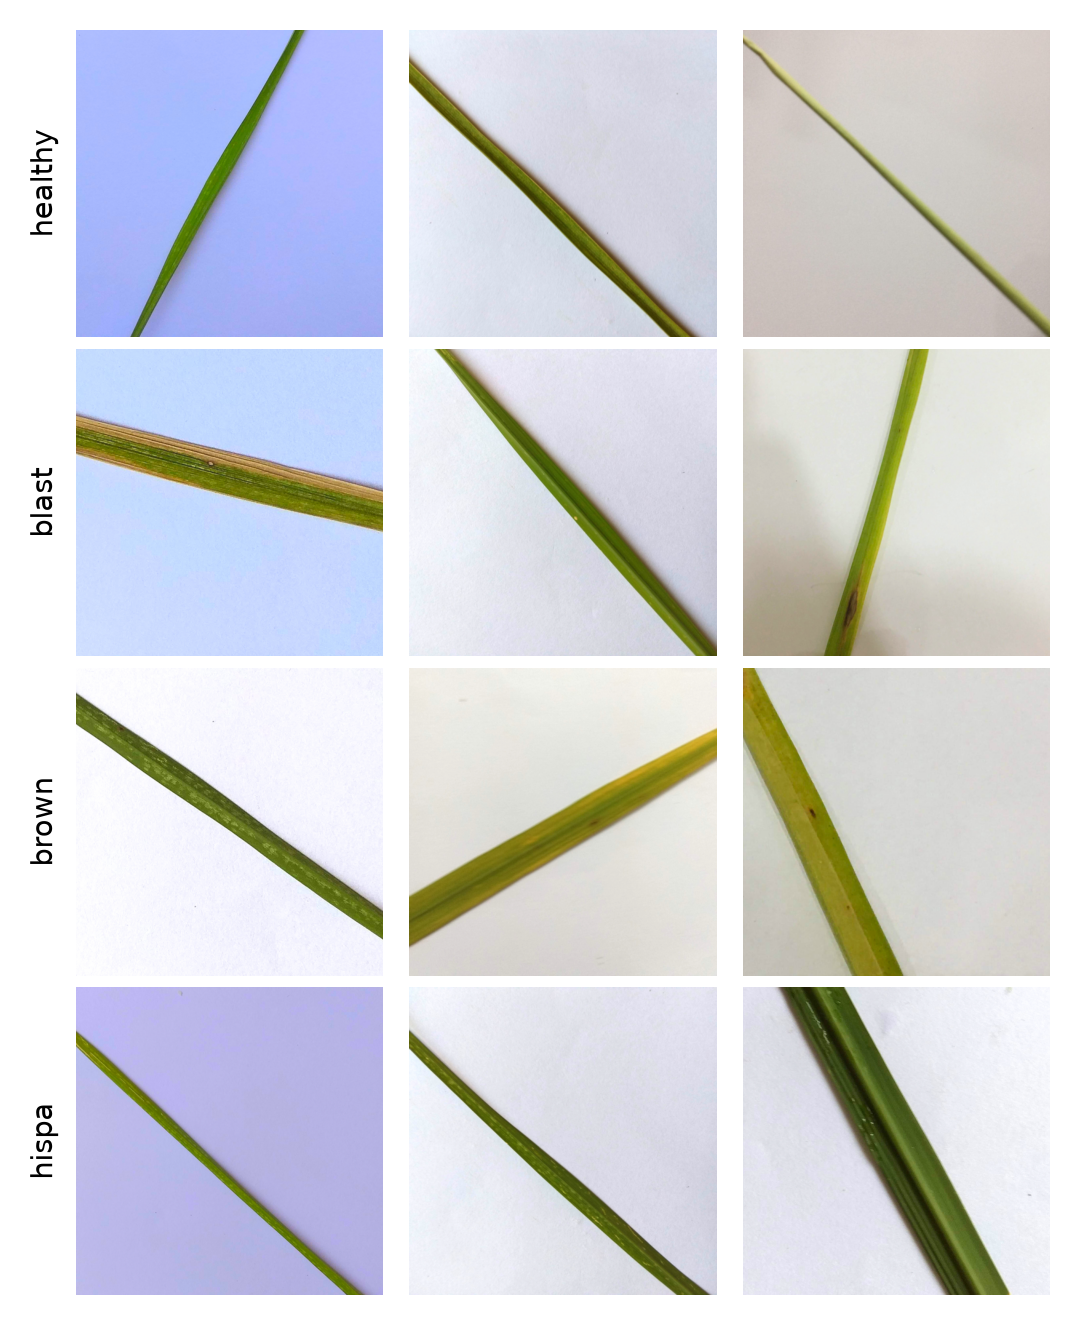

In [62]:
show_figure('results/figures/final_samples.png')

### Figure: confusion (Stage 7)

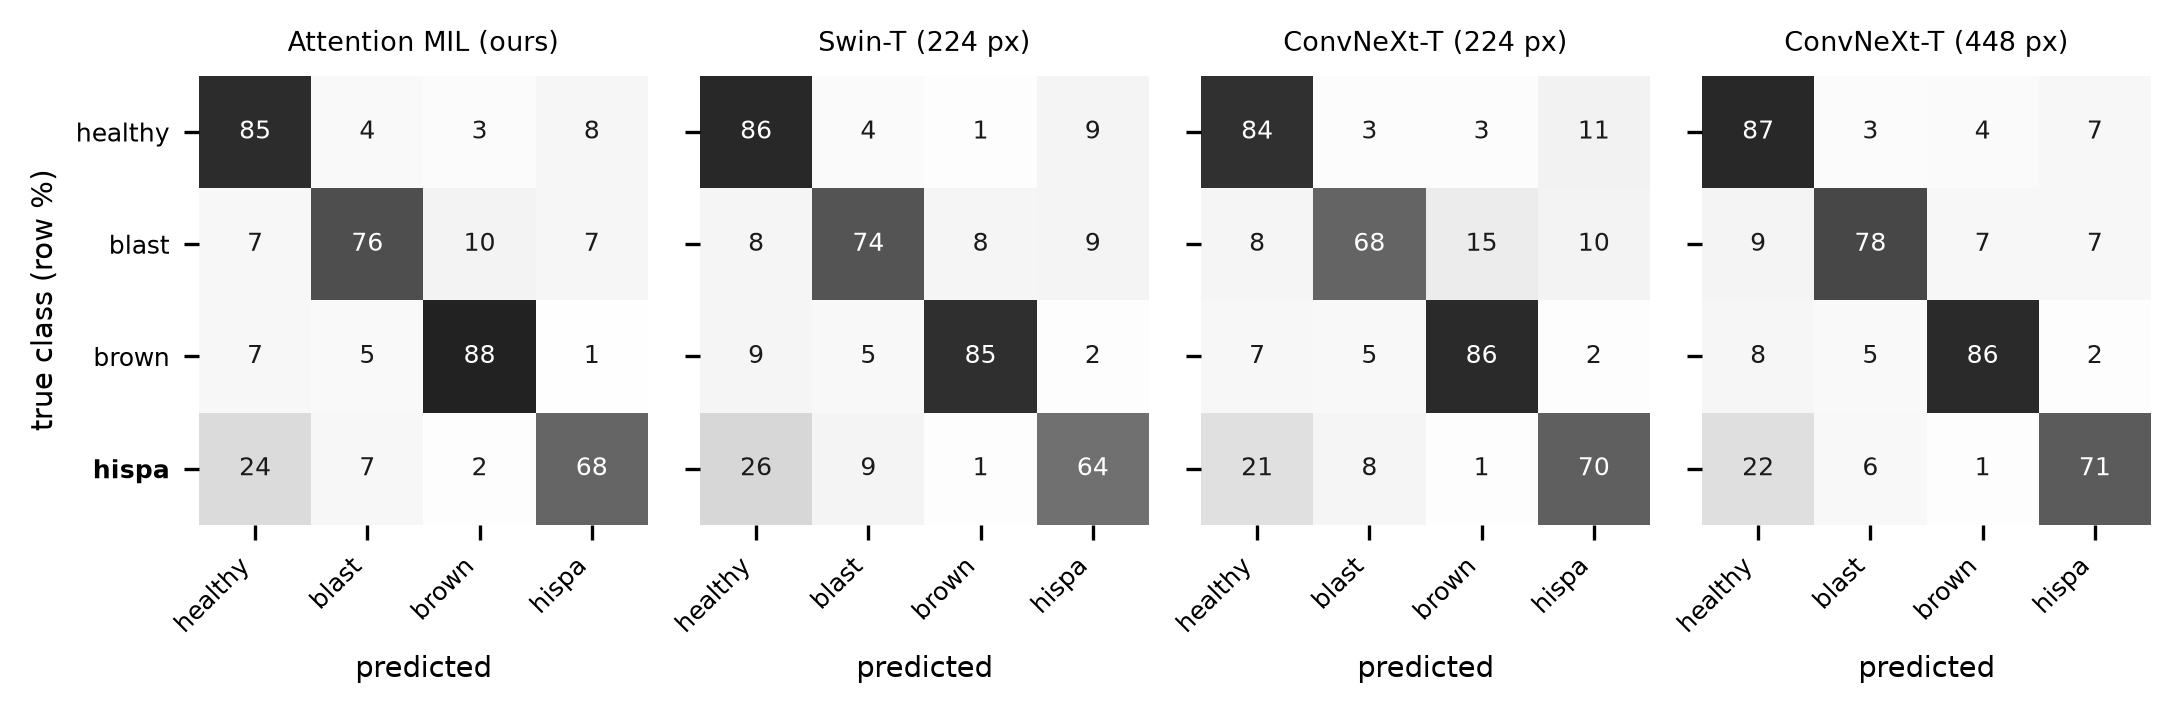

In [63]:
show_figure('results/figures/final_confusion.png')

### Figure: partition_order (Stage 9)

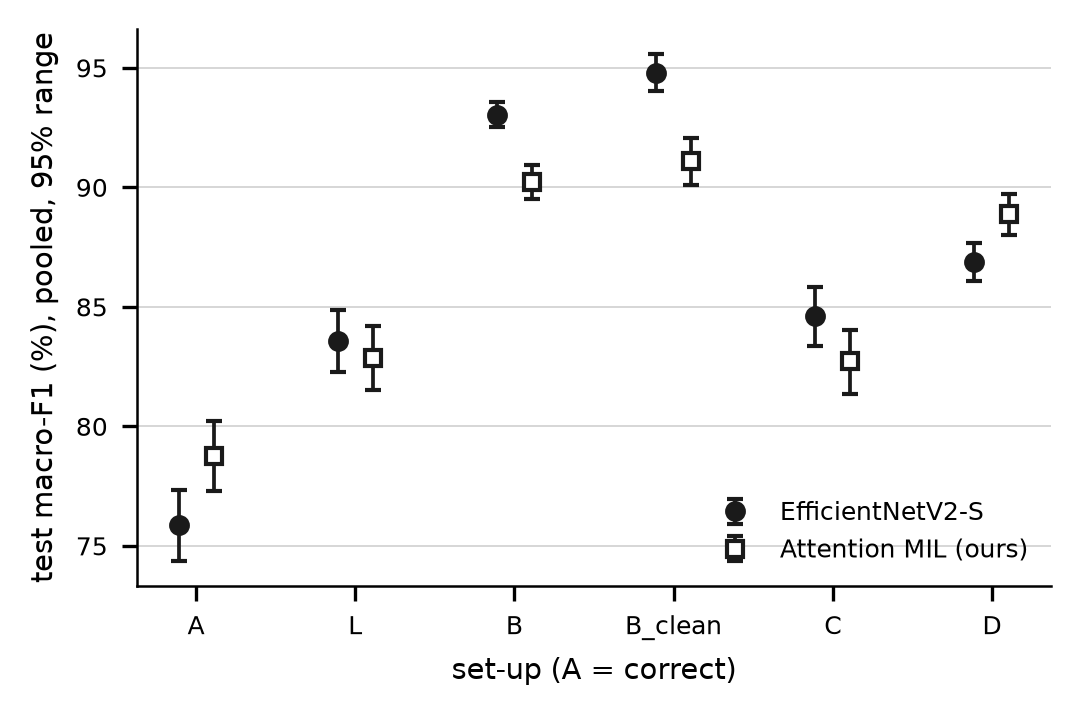

In [64]:
show_figure('results/figures/final_partition_order.png')

### Figure: ablations (Stage 8)

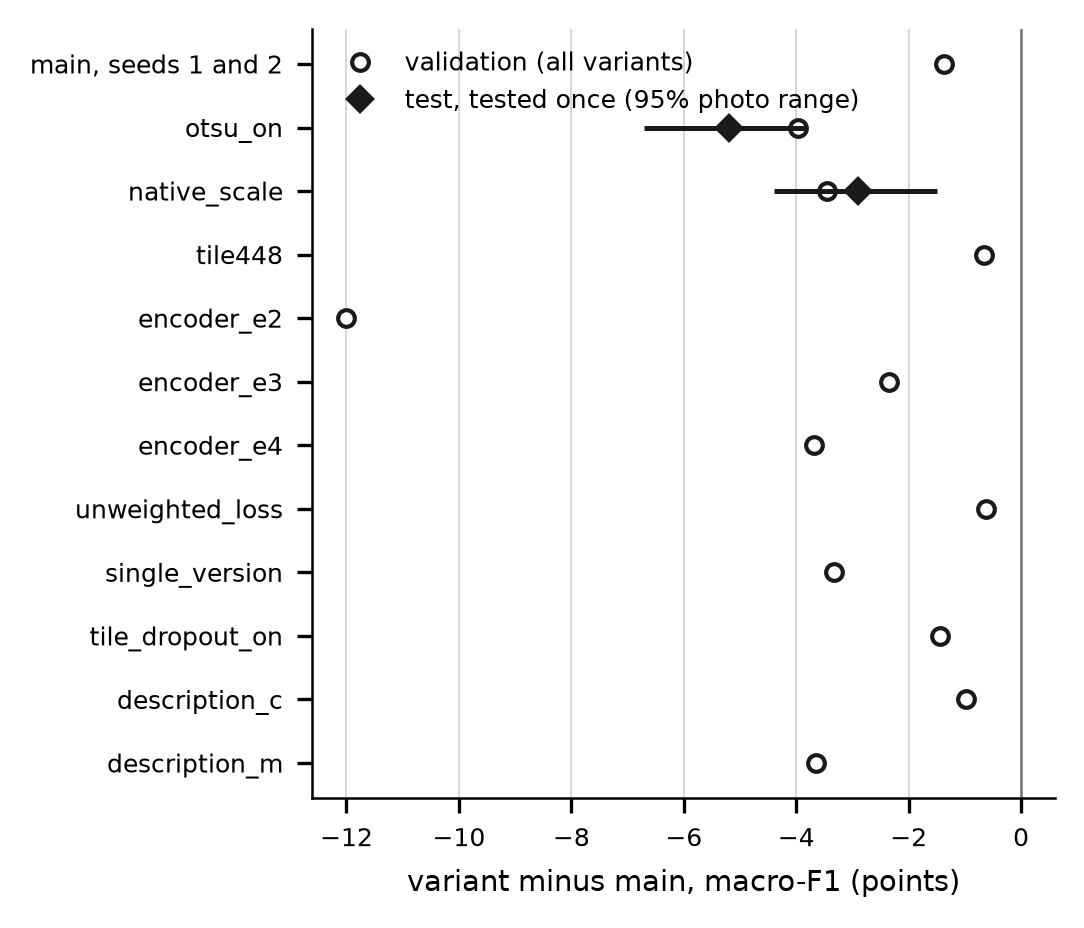

In [65]:
show_figure('results/figures/final_ablations.png')

### Figure: paddy_zoom (Stage 10)

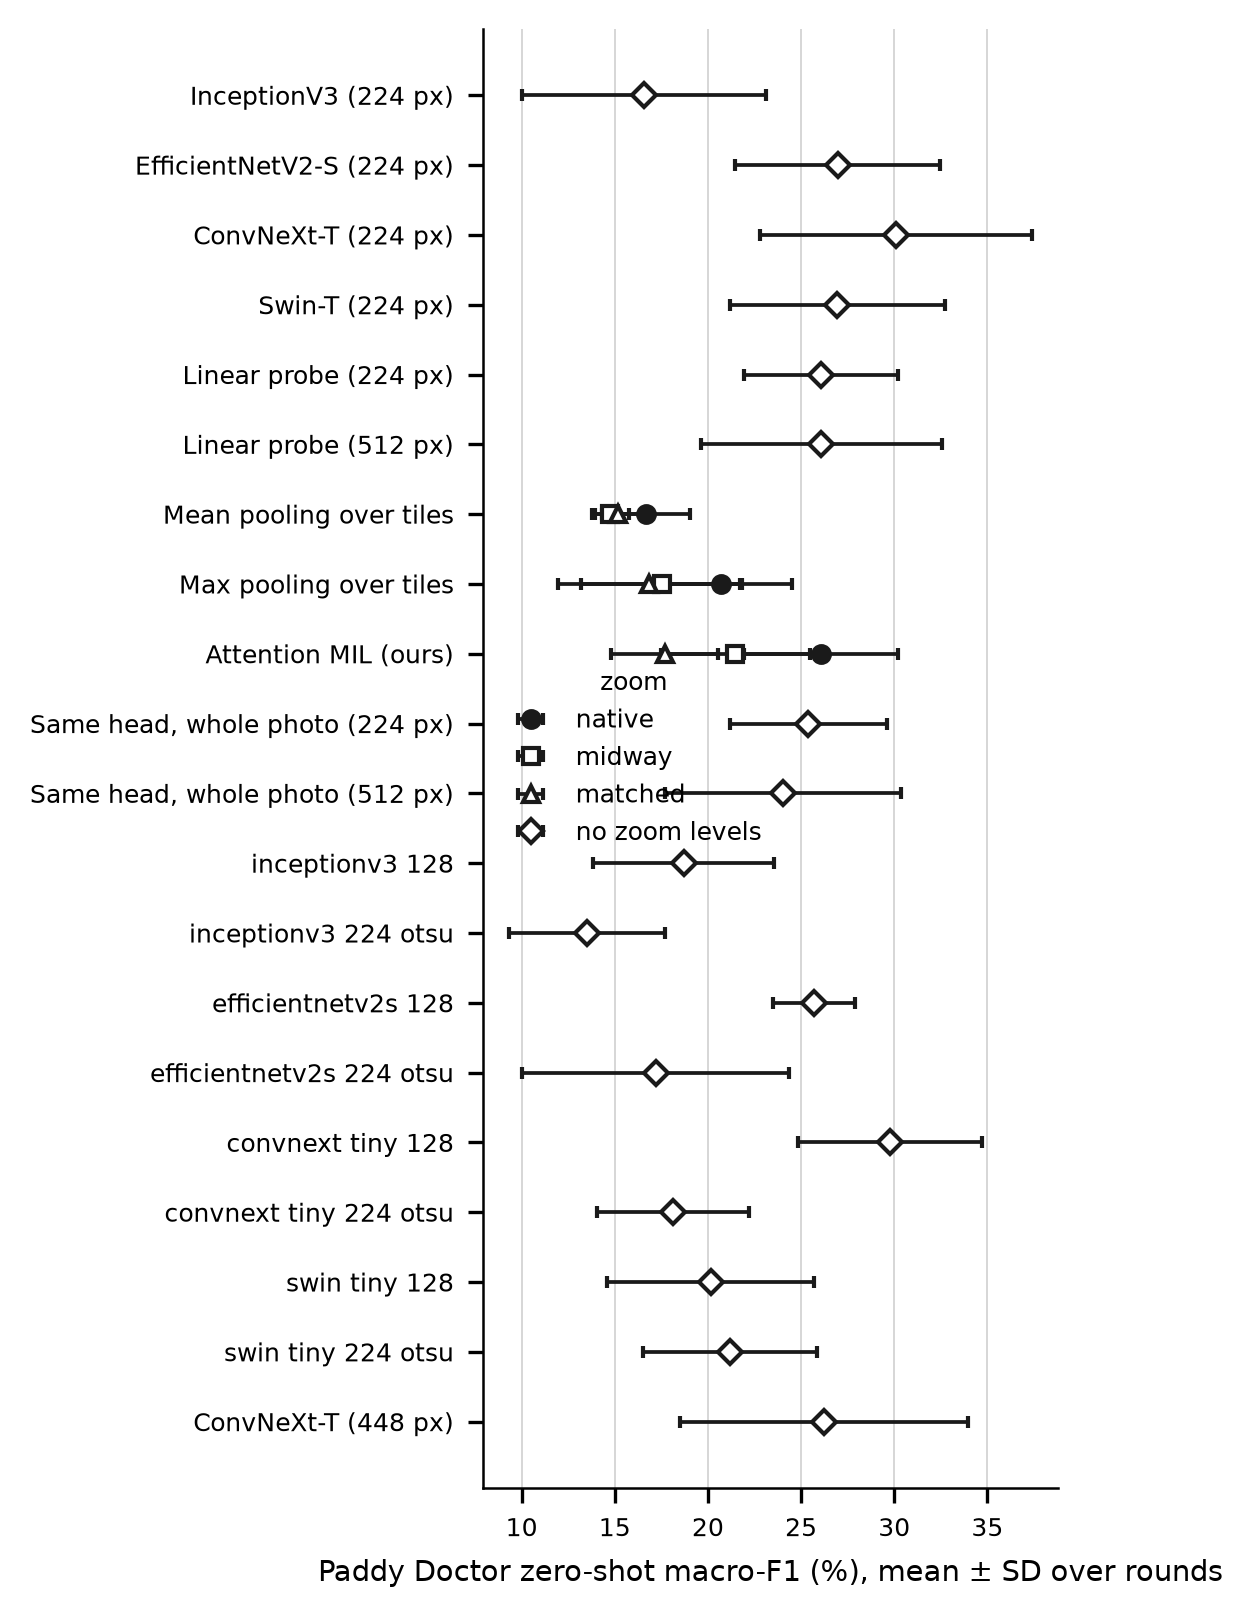

In [66]:
show_figure('results/figures/final_paddy_zoom.png')

### Figure: deletion (Stage 12)

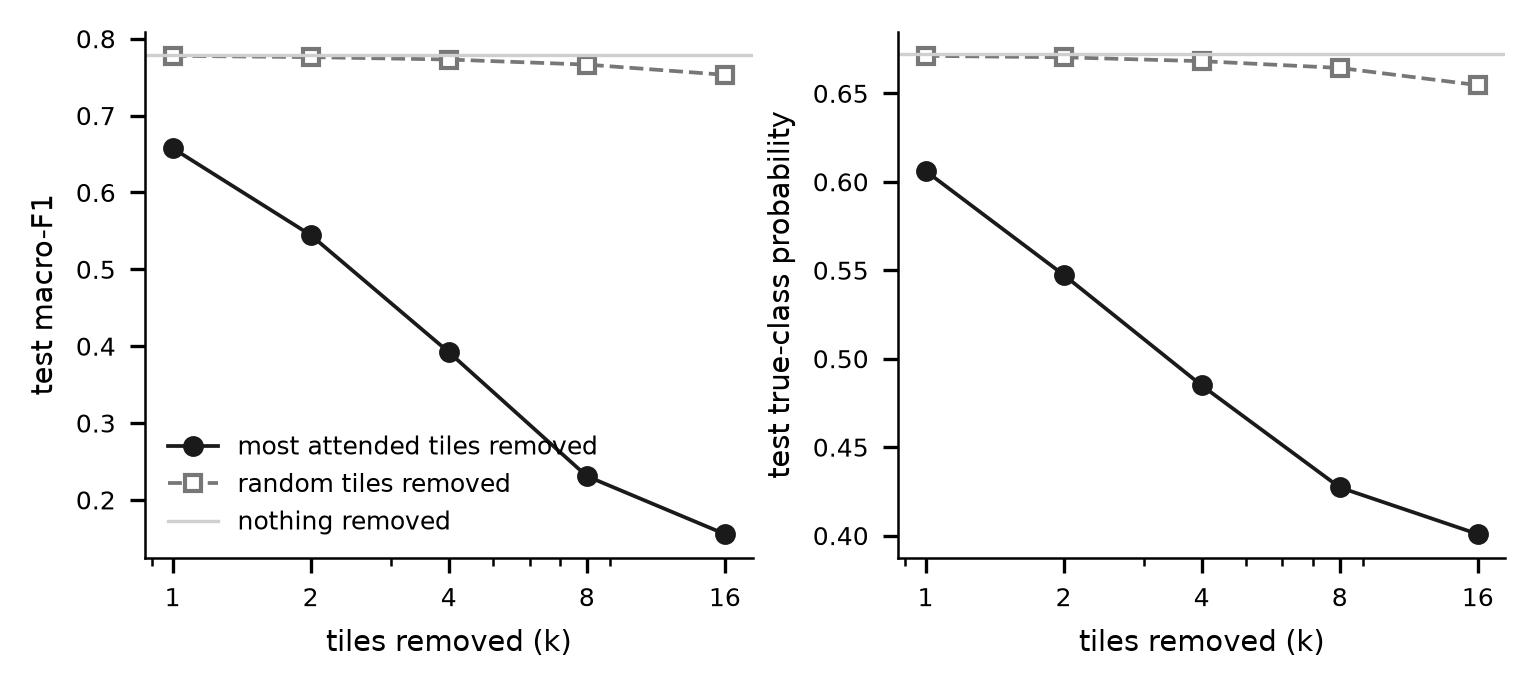

In [67]:
show_figure('results/figures/final_deletion.png')

### Figure: heatmaps (Stage 12)

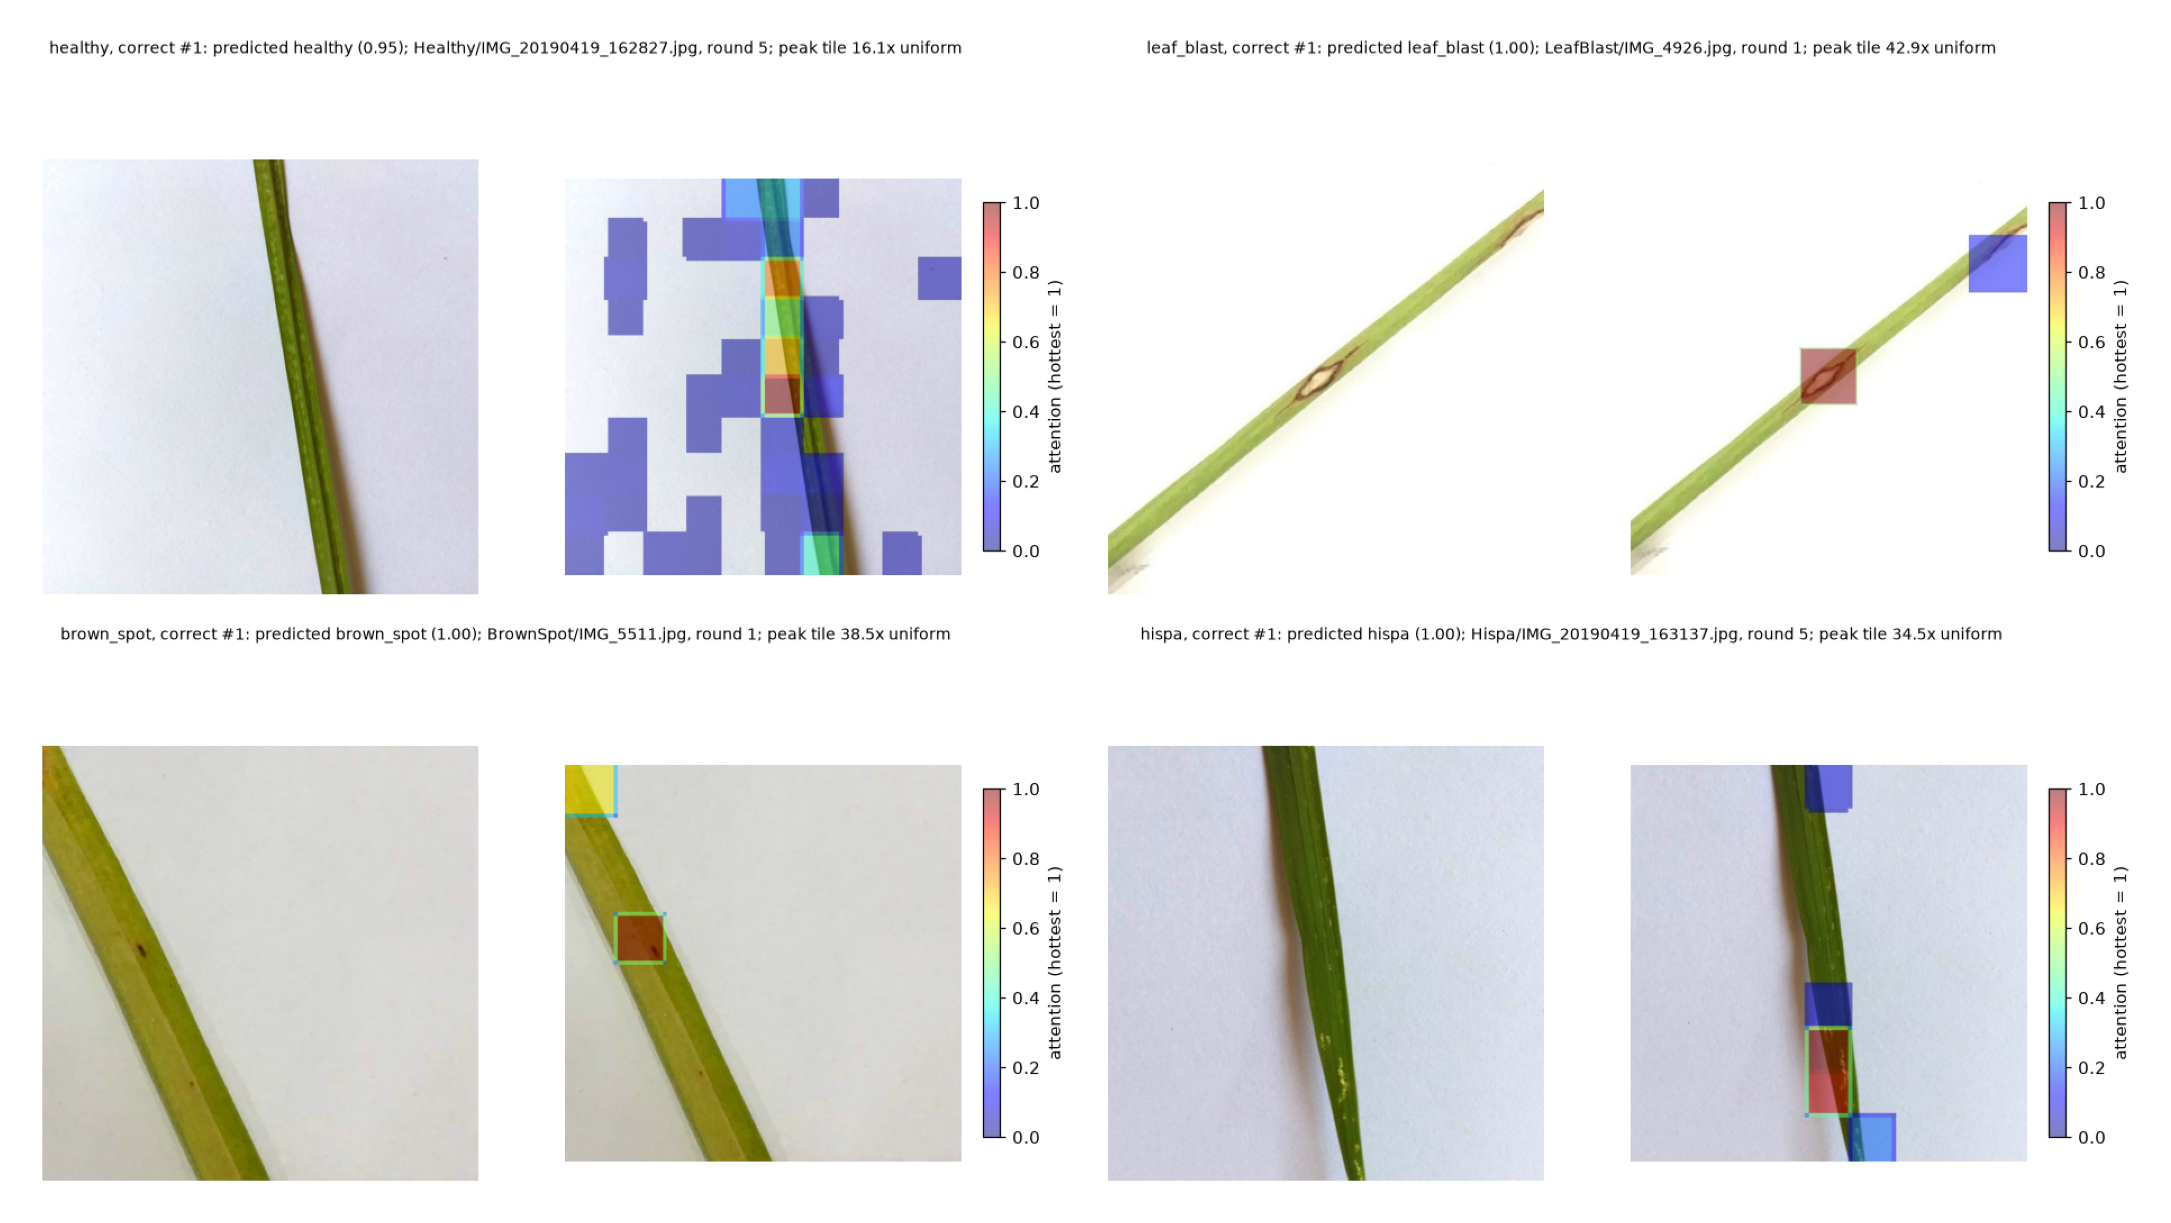

In [68]:
show_figure('results/figures/final_heatmaps.png')

### Figure: cost (Stage 13)

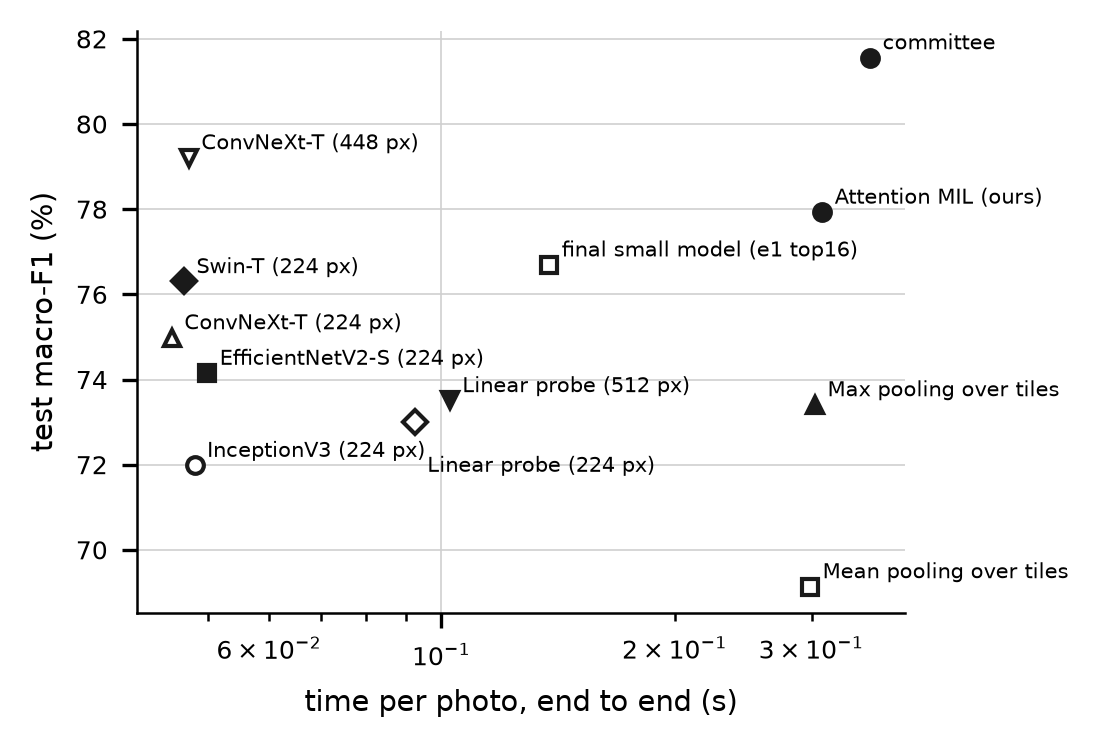

In [69]:
show_figure('results/figures/final_cost.png')

## Source appendix

Every module of `src/`, exactly as in the commit this notebook was built from (SHA-256 in each cell's metadata). Nothing here is executed.

#### `src/skeleton.py`

```python
"""Stage 0 walking skeleton: the whole pipeline, end to end, on about 20 photos.

Throwaway code (Stage 0). Load photos -> cut native-resolution tiles -> describe
every tile with the frozen encoder -> train a tiny gated-attention head for a few steps ->
predict -> score -> write a run record. It scores badly (20 photos, 50 steps); it exists to
prove the pipeline runs and gives the same numbers on the local machine and on Kaggle.

    uv run python -m src.skeleton --config configs/skeleton.yaml --run-name stage0_skeleton_halo
    uv run python -m src.skeleton --compare runs/stage0_skeleton_halo runs/stage0_skeleton_kaggle
"""

from __future__ import annotations

import argparse
import json
import subprocess
import sys
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from torch import nn

from src.config import REPO_ROOT, dataset_dir, load_config, path_for
from src.kaggle_bootstrap import pinned_pretrained
from src.records import CODE_PATHS, RunRecorder
from src.seeding import seed_everything


# ---------------------------------------------------------------- data
def sample_photos(config: dict[str, Any]) -> list[dict[str, Any]]:
    """A fixed, seeded sample per class; the first ``train_per_class`` are training photos."""
    sk = config["skeleton"]
    root = dataset_dir(config, "primary")
    ext = config["datasets"]["primary"]["image_extension"]
    rng = np.random.default_rng(config["seed"])
    photos = []
    for label, name in enumerate(config["classes"]):
        folder = config["datasets"]["primary"]["class_folders"][name]
        files = sorted((root / folder).glob(f"*{ext}"))
        for rank, index in enumerate(rng.choice(len(files), sk["photos_per_class"], replace=False)):
            photos.append({
                "photo_id": f"{folder}/{files[index].name}",
                "path": files[index],
                "label": label,
                "partition": "train" if rank < sk["train_per_class"] else "test",
            })
    return photos


def tile_starts(length: int, tile: int) -> list[int]:
    """Smallest number of tiles covering ``length``, evenly spread, first and last touching the edges."""
    if length <= tile:
        return [0]
    n = -(-length // tile)  # ceil(L / t), the same as the methodology's ceil((L - t) / t) + 1
    return [i * (length - tile) // (n - 1) for i in range(n)]


def cut_tiles(image: np.ndarray, tile: int) -> np.ndarray:
    """All tiles of an (H, W, 3) image as an (N, tile, tile, 3) array, row by row."""
    height, width = image.shape[:2]
    return np.stack([
        image[top:top + tile, left:left + tile]
        for top in tile_starts(height, tile)
        for left in tile_starts(width, tile)
    ])


# ---------------------------------------------------------------- encoder
def load_encoder(config: dict[str, Any], device: torch.device) -> nn.Module:
    from transformers import AutoModel

    spec = config["encoders"][config["skeleton"]["encoder"]]
    source, pinned = pinned_pretrained(spec["name"], spec["revision"])
    return AutoModel.from_pretrained(source, dtype=torch.float32, **pinned).eval().to(device)


@torch.inference_mode()
def describe_tiles(
    model: nn.Module, tiles: np.ndarray, config: dict[str, Any], device: torch.device
) -> torch.Tensor:
    """Class-token description of every tile, (N, dim), on the CPU."""
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)
    batch_size = config["skeleton"]["encode_batch"]
    out = []
    for start in range(0, len(tiles), batch_size):
        batch = torch.from_numpy(tiles[start:start + batch_size]).to(device)
        pixels = (batch.permute(0, 3, 1, 2).float() / 255 - mean) / std
        out.append(model(pixel_values=pixels).last_hidden_state[:, 0].cpu())
    return torch.cat(out)


# ---------------------------------------------------------------- MIL head
class GatedAttentionHead(nn.Module):
    """Gated-attention multiple instance learning (Ilse et al. 2018): bag of tiles -> class scores."""

    def __init__(self, in_dim: int, projection_dim: int, attention_dim: int, n_classes: int) -> None:
        super().__init__()
        self.project = nn.Sequential(nn.Linear(in_dim, projection_dim), nn.ReLU())
        self.attention_v = nn.Linear(projection_dim, attention_dim)
        self.attention_u = nn.Linear(projection_dim, attention_dim)
        # No bias (as in Ilse et al.): softmax ignores a shift shared by all tiles, so its
        # gradient is pure rounding noise, which Adam would blow up into full-size steps.
        self.attention_w = nn.Linear(attention_dim, 1, bias=False)
        self.classify = nn.Linear(projection_dim, n_classes)

    def forward(self, tiles: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """tiles (B, N, in_dim), mask (B, N) True for real tiles -> logits (B, n_classes)."""
        h = self.project(tiles)
        gated = torch.tanh(self.attention_v(h)) * torch.sigmoid(self.attention_u(h))
        scores = self.attention_w(gated).squeeze(-1).masked_fill(~mask, float("-inf"))
        return self.classify((torch.softmax(scores, dim=1).unsqueeze(-1) * h).sum(dim=1))


def pad_bags(bags: list[torch.Tensor]) -> tuple[torch.Tensor, torch.Tensor]:
    """Stack bags of different sizes into (B, N_max, dim) plus a mask of the real tiles."""
    longest = max(len(b) for b in bags)
    x = torch.zeros(len(bags), longest, bags[0].shape[1])
    mask = torch.zeros(len(bags), longest, dtype=torch.bool)
    for i, bag in enumerate(bags):
        x[i, :len(bag)] = bag
        mask[i, :len(bag)] = True
    return x, mask


def train_head(photos: list[dict[str, Any]], config: dict[str, Any], rec: RunRecorder,
               device: torch.device) -> GatedAttentionHead:
    """Full batch over the training photos: one AdamW step per epoch."""
    sk, training = config["skeleton"], config["skeleton"]["training"]
    x, mask = (t.to(device) for t in pad_bags([p["features"] for p in photos]))
    y = torch.tensor([p["label"] for p in photos], device=device)
    # Built on the CPU first, so its starting weights match on every machine.
    head = GatedAttentionHead(x.shape[-1], n_classes=len(config["classes"]), **sk["head"]).to(device)
    # Training is balanced (train_per_class of each class), so class weights would all be 1.
    loss_fn = nn.CrossEntropyLoss(label_smoothing=config["loss"]["label_smoothing"])
    optimiser = torch.optim.AdamW(
        head.parameters(), lr=training["lr"], weight_decay=training["weight_decay"], eps=training["adam_eps"]
    )
    for epoch in range(1, training["steps"] + 1):
        optimiser.zero_grad()
        loss = loss_fn(head(x, mask), y)
        loss.backward()
        optimiser.step()
        rec.log_epoch(epoch, {"train_loss": loss.item()})
    return head.eval()


@torch.inference_mode()
def predict(head: GatedAttentionHead, photos: list[dict[str, Any]], classes: list[str],
            device: torch.device) -> pd.DataFrame:
    x, mask = (t.to(device) for t in pad_bags([p["features"] for p in photos]))
    probs = torch.softmax(head(x, mask), dim=1).cpu()
    return pd.DataFrame([{
        "photo_id": p["photo_id"], "partition": p["partition"], "true_class": classes[p["label"]],
        "pred_class": classes[int(row.argmax())], **{f"prob_{c}": float(v) for c, v in zip(classes, row)},
        "n_tiles": len(p["features"]),
    } for p, row in zip(photos, probs)])


# ---------------------------------------------------------------- run
def run(config_path: str, run_name: str) -> dict[str, Any]:
    config = load_config(config_path)
    seed_everything(config["seed"], config["determinism"])
    classes = config["classes"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    photos = sample_photos(config)
    encoder = load_encoder(config, device)

    rec = RunRecorder(
        run_name, config=config, base_dir=path_for(config, "runs"),
        data_version={"primary": config["datasets"]["primary"]["version"]},
    )
    for photo in photos:  # one photo at a time keeps memory low (photos are up to 3120 x 3120)
        with Image.open(photo["path"]) as img:
            image = np.asarray(ImageOps.exif_transpose(img).convert("RGB"))
        tiles = cut_tiles(image, config["tiling"]["tile_size"])
        photo["features"] = describe_tiles(encoder, tiles, config, device)
        rec.logger.info(f"{photo['photo_id']}: {image.shape[1]} x {image.shape[0]} px -> {len(tiles)} tiles")
    del encoder
    # Kept (git-ignored) so --compare can tell encoder differences from training differences.
    torch.save({p["photo_id"]: p["features"] for p in photos}, rec.run_dir / "features.pt")

    head = train_head([p for p in photos if p["partition"] == "train"], config, rec, device)
    predictions = predict(head, photos, classes, device)
    rec.save_predictions(predictions)

    test = predictions[predictions["partition"] == "test"]
    truth, pred = test["true_class"], test["pred_class"]
    metrics = {
        "partition": "test",
        "note": "walking skeleton: throwaway 3+2 per class split, not a real result",
        "n_photos": len(test),
        "macro_f1": f1_score(truth, pred, labels=classes, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(truth, pred),
        "accuracy": accuracy_score(truth, pred),
        "n_tiles_total": int(predictions["n_tiles"].sum()),
    }
    rec.save_metrics(metrics)
    rec.finish()
    print(f"| {run_name} | macro-F1 {metrics['macro_f1']:.3f} "
          f"| balanced acc {metrics['balanced_accuracy']:.3f} | acc {metrics['accuracy']:.3f} "
          f"| {metrics['n_tiles_total']} tiles |")
    return metrics


# ---------------------------------------------------------------- compare
def same_code(va: str, vb: str) -> tuple[bool, str]:
    """Both runs come from committed code, and the code paths do not differ between the commits."""
    if any(v == "unknown" or v.endswith("-dirty") for v in (va, vb)):
        return False, f"{va} vs {vb}: only runs from committed code can be compared"
    if va == vb:
        return True, f"{va}"
    try:
        result = subprocess.run(["git", "diff", "--quiet", va, vb, "--", *CODE_PATHS],
                                cwd=REPO_ROOT, capture_output=True)
    except FileNotFoundError:
        return False, f"{va} vs {vb}: git is not available"
    if result.returncode == 1:
        return False, f"{va} vs {vb}: the code differs"
    if result.returncode != 0:
        return False, f"{va} vs {vb}: git cannot resolve one of the commits"
    return True, f"{va} vs {vb}: code paths identical"


def compare_runs(run_a: str | Path, run_b: str | Path, atol: float) -> bool:
    """Stage 0 'done when': same predicted labels and scores, probabilities within ``atol``."""
    a, b = Path(run_a), Path(run_b)
    pa, pb = (pd.read_csv(r / "predictions.csv").sort_values("photo_id", ignore_index=True) for r in (a, b))
    ma, mb = (json.loads((r / "metrics.json").read_text()) for r in (a, b))
    ra, rb = (json.loads((r / "record.json").read_text()) for r in (a, b))

    checks: dict[str, bool] = {}
    checks["same photos, partitions, true classes and tile counts"] = all(
        pa[c].equals(pb[c]) for c in ("photo_id", "partition", "true_class", "n_tiles")
    )
    if checks["same photos, partitions, true classes and tile counts"]:
        prob_cols = [c for c in pa.columns if c.startswith("prob_")]
        diff = (pa[prob_cols] - pb[prob_cols]).to_numpy()
        finite = bool(np.isfinite(diff).all())
        max_diff = float(np.abs(diff).max()) if finite else float("nan")
        checks["same predicted labels"] = pa["pred_class"].equals(pb["pred_class"])
        checks[f"probabilities within {atol:g} (max diff {max_diff:.2e})"] = finite and max_diff <= atol
    checks["same scores"] = all(ma[k] == mb[k] for k in ("macro_f1", "balanced_accuracy", "accuracy"))
    ok, detail = same_code(ra["code_version"], rb["code_version"])
    checks[f"same code ({detail})"] = ok
    pya, pyb = ra["hardware"]["python"], rb["hardware"]["python"]
    checks[f"same Python ({pya} vs {pyb})"] = pya == pyb
    checks["same package versions"] = ra["packages"] == rb["packages"]
    checks["same determinism mode"] = ra["config"].get("determinism") == rb["config"].get("determinism")

    for name, passed in checks.items():
        print(f"  [{'ok' if passed else 'FAIL'}] {name}")
    if (a / "features.pt").exists() and (b / "features.pt").exists():  # diagnostic only
        fa, fb = torch.load(a / "features.pt"), torch.load(b / "features.pt")
        rels = [float((fa[k] - fb[k]).abs().max() / fb[k].abs().max())
                for k in fa if k in fb and fa[k].shape == fb[k].shape]
        if rels:
            print(f"  [info] max relative encoder feature difference: {max(rels):.2e}")
    return all(checks.values())


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/skeleton.yaml")
    parser.add_argument("--run-name")
    parser.add_argument("--compare", nargs=2, metavar=("RUN_A", "RUN_B"), help="check two run folders agree")
    args = parser.parse_args()
    if args.compare:
        atol = load_config(args.config)["skeleton"]["compare_atol"]
        sys.exit(0 if compare_runs(*args.compare, atol=atol) else 1)
    if not args.run_name:
        parser.error("--run-name is required (e.g. stage0_skeleton_halo)")
    run(args.config, args.run_name)


if __name__ == "__main__":
    main()
```


#### `src/config.py`

```python
"""Read settings files and turn their paths into real paths on this machine.

Every experiment settings file starts with ``extends: <file>`` (usually ``base.yaml``,
relative to the file's own folder) and only adds or overrides what it needs. Nested
sections are merged key by key; any other value (numbers, strings, lists) is replaced
as a whole.

Paths in settings files are relative to the repository root. On Kaggle the code
(``src/``, ``configs/``, ``splits/``) lives in the read-only ``ricetein-code`` dataset,
so outputs go under ``/kaggle/working/`` and datasets are found by name.

Print a merged settings file:  uv run python -m src.config configs/skeleton.yaml
"""

from __future__ import annotations

import argparse
from pathlib import Path
from typing import Any

import yaml

from src.kaggle_bootstrap import find_kaggle_input

REPO_ROOT = Path(__file__).resolve().parents[1]  # on Kaggle: the ricetein-code dataset folder
KAGGLE_WORKING = Path("/kaggle/working")
# Shipped inside ricetein-code (keep in step with scripts/kaggle_sync_code.sh); other `paths` are outputs.
READ_ONLY_PATHS = {"configs", "splits"}


def on_kaggle() -> bool:
    return KAGGLE_WORKING.exists()


def output_root() -> Path:
    """Where outputs go: ``/kaggle/working`` on Kaggle (the code there is read-only), else the repo."""
    return KAGGLE_WORKING if on_kaggle() else REPO_ROOT


def cache_folder(name: str, *, write: bool = False) -> Path:
    """Writable cache output, or a completed cache attached as ricetein-features on Kaggle."""
    folder = output_root() / "cache" / name
    if write or folder.exists() or not on_kaggle():
        return folder
    mounted = find_kaggle_input("ricetein-features")
    if mounted is not None:
        for candidate in (mounted / "cache" / name, mounted / name):
            if candidate.exists():
                return candidate
    raise FileNotFoundError(f"cache {name}: build it first or attach ricetein-features")


def read_yaml(path: str | Path) -> dict[str, Any]:
    with open(path, encoding="utf-8") as f:
        data = yaml.safe_load(f)
    if data is None:
        return {}
    if not isinstance(data, dict):
        raise ValueError(f"{path}: a settings file must be a mapping of names to values")
    return data


def deep_merge(base: dict[str, Any], override: dict[str, Any]) -> dict[str, Any]:
    """Return ``base`` updated by ``override``; nested dicts merge, everything else replaces.

    ``base`` itself is not modified (values are shared, not copied: settings are read-only).
    """
    merged = dict(base)
    for key, value in override.items():
        if isinstance(value, dict) and isinstance(merged.get(key), dict):
            merged[key] = deep_merge(merged[key], value)
        else:
            merged[key] = value
    return merged


def load_config(path: str | Path) -> dict[str, Any]:
    """Load a settings file, following its ``extends`` chain.

    The result records which file it came from as ``config_file`` (repo-relative).
    """
    path = Path(path)
    path = (path if path.is_absolute() else REPO_ROOT / path).resolve()
    chain: list[Path] = []
    layers: list[dict[str, Any]] = []
    while True:
        if path in chain:
            raise ValueError(f"Circular 'extends' in {[str(p) for p in chain + [path]]}")
        chain.append(path)
        layers.append(read_yaml(path))
        parent = layers[-1].pop("extends", None)
        if parent is None:
            break
        path = (path.parent / parent).resolve()

    config: dict[str, Any] = {}
    for layer in reversed(layers):  # base first, the experiment file last
        config = deep_merge(config, layer)
    try:
        config["config_file"] = str(chain[0].relative_to(REPO_ROOT))
    except ValueError:
        config["config_file"] = str(chain[0])
    return config


def path_for(config: dict[str, Any], key: str) -> Path:
    """Real folder for ``config['paths'][key]`` on this machine (e.g. ``runs``, ``splits``)."""
    root = REPO_ROOT if key in READ_ONLY_PATHS else output_root()
    return root / config["paths"][key]


def dataset_dir(config: dict[str, Any], name: str) -> Path:
    """Folder that holds the class folders of dataset ``name`` (``primary`` or ``paddy``)."""
    spec = config["datasets"][name]
    if on_kaggle():
        root = find_kaggle_input(spec["kaggle_slug"])
        if root is None:
            raise FileNotFoundError(f"Kaggle dataset '{spec['kaggle_slug']}' is not attached")
    else:
        root = REPO_ROOT / spec["local_dir"]
    folder = root / spec["image_subdir"]
    missing = [f for f in spec["class_folders"].values() if not (folder / f).is_dir()]
    if missing:
        raise FileNotFoundError(f"{name} dataset: class folders {missing} not found in {folder}")
    return folder


def main() -> None:
    parser = argparse.ArgumentParser(description="Print a settings file with its 'extends' chain merged.")
    parser.add_argument("config", help="settings file, e.g. configs/skeleton.yaml")
    args = parser.parse_args()
    print(yaml.safe_dump(load_config(args.config), sort_keys=False), end="")


if __name__ == "__main__":
    main()
```


#### `src/seeding.py`

```python
"""Control every source of randomness from one seed.

Call ``seed_everything(config["seed"], config["determinism"])`` once at the very start
of a run, before anything touches the GPU.

- ``strict`` (default): deterministic algorithms only, cuDNN autotuning off and full fp32
  precision (no TF32) for matmuls, convolutions and RNNs. A run then repeats exactly on
  one machine, and the local RTX 4060 and a Kaggle T4 agree within the Stage 0 tolerance
  (1e-3): the RTX 4060 supports TF32 but the T4 does not, so TF32 alone would make the
  two machines disagree. Some backward passes have no deterministic version on the GPU
  (e.g. ``adaptive_avg_pool2d`` to sizes above 1, ``scatter_add``); they raise an error
  in this mode rather than silently varying.
- ``fast``: cuDNN autotuning, non-deterministic kernels and TF32 (TF32 only on GPUs that
  have it; the T4 does not). Runs then repeat only approximately. For heavy fine-tuning
  where speed matters more than exact agreement; set ``determinism: fast`` in that
  stage's settings file.

Never mix in the legacy ``allow_tf32`` flags or ``torch.set_float32_matmul_precision``:
torch 2.11 rejects mixing them with the ``fp32_precision`` settings used here, and the
latter silently switches matmuls back to TF32.
"""

from __future__ import annotations

import os
import random

import numpy as np
import torch

MODES = ("strict", "fast")


def seed_everything(seed: int, determinism: str = "strict") -> None:
    if determinism not in MODES:
        raise ValueError(f"determinism must be one of {MODES}, got {determinism!r}")
    os.environ["PYTHONHASHSEED"] = str(seed)  # reaches only freshly started interpreters (spawn, subprocess)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds every CUDA device

    strict = determinism == "strict"
    if strict:
        # Older torch versions require this for deterministic cuBLAS; harmless on 2.11.
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.use_deterministic_algorithms(strict)
    torch.backends.cudnn.benchmark = not strict
    precision = "ieee" if strict else "tf32"
    # Each setting is needed: conv and rnn default to an explicit "tf32" and do not
    # inherit from torch.backends.cudnn.fp32_precision.
    torch.backends.cuda.matmul.fp32_precision = precision
    torch.backends.cudnn.fp32_precision = precision
    torch.backends.cudnn.conv.fp32_precision = precision
    torch.backends.cudnn.rnn.fp32_precision = precision
```


#### `src/records.py`

```python
"""Unified run recorder for experiments on the local machine and on Kaggle.

Every run writes the same files into ``runs/<run_name>/`` (``/kaggle/working/runs/<run_name>/``
on Kaggle):

    record.json      settings, code version, split checksum, data version, hardware,
                     package versions, start/end time, duration, peak GPU memory
    history.csv      one row per epoch
    metrics.json     final scores
    predictions.csv  one row per photo
    run.log          console log of the run
"""

from __future__ import annotations

import ast
import csv
import json
import logging
import os
import platform
import shutil
import subprocess
import time
from datetime import datetime, timezone
from importlib import metadata
from pathlib import Path
from typing import Any, Mapping

import psutil

from src.config import REPO_ROOT, on_kaggle, output_root
from src.kaggle_bootstrap import CODE_DATASET_SLUG, find_kaggle_input

# What counts as "the code" for a run's code version (also checked by scripts/kaggle_*.sh).
CODE_PATHS = ("src", "configs", "splits", "pyproject.toml", "uv.lock")

# The module whose code produces a run's numbers, by run-name prefix. A completed run stays reusable
# while that module and everything it imports are unchanged (declared 2026-11-14).
RUN_MODULES = {"stage4": "src.sanity_baselines", "stage4b": "src.shortcut_baselines",
               "stage5": "src.train_wholeimage", "stage7a": "src.linear_probe", "stage7": "src.train_mil",
               "stage9": "src.partition_order"}
BOOKKEEPING = {"src/records.py"}  # writes records and decides reuse; computes no score

# Package versions written into every record (missing ones are recorded as None).
TRACKED_PACKAGES = ("torch", "torchvision", "timm", "transformers", "numpy", "scikit-learn", "pandas")


def get_default_runs_dir() -> Path:
    """``/kaggle/working/runs`` on Kaggle, otherwise ``<repo>/runs`` (whatever the working directory)."""
    return output_root() / "runs"


def require_clean_code() -> str:
    version = get_code_version()
    if version == "unknown" or version.endswith("-dirty"):
        raise RuntimeError(f"code version {version}: commit before real experiments")
    return version


def completed_run(name: str, artifacts: tuple[str, ...] = ("metrics.json", "predictions.csv")) -> bool:
    folder = get_default_runs_dir() / name
    record = folder / "record.json"
    return (record.exists() and json.loads(record.read_text()).get("status") == "completed"
            and all((folder / artifact).exists() for artifact in artifacts))


def source_files(module: str) -> list[str]:
    """Repo-relative files of ``module`` and of every ``src`` module it imports, directly or not."""
    seen: dict[str, str] = {}
    todo = [module]
    while todo:
        name = todo.pop()
        path = REPO_ROOT / f"{name.replace('.', '/')}.py"
        if name in seen or not path.exists():
            continue
        seen[name] = str(path.relative_to(REPO_ROOT))
        for node in ast.walk(ast.parse(path.read_text(encoding="utf-8"))):
            if isinstance(node, ast.ImportFrom) and node.module and node.module.split(".")[0] == "src":
                todo += [node.module, *(f"{node.module}.{alias.name}" for alias in node.names)]
            elif isinstance(node, ast.Import):
                todo += [alias.name for alias in node.names if alias.name.startswith("src.")]
    return sorted(seen.values())


def code_paths(name: str) -> tuple[str, ...]:
    """What must be unchanged for run ``name`` to be reused. Settings and the split are compared
    separately, so a known run kind only depends on the code it executes and the locked packages."""
    module = RUN_MODULES.get(name.split("_")[0])
    if module is None:
        return CODE_PATHS
    return (*(f for f in source_files(module) if f not in BOOKKEEPING), "pyproject.toml", "uv.lock")


def reusable_run(name: str, config: Mapping[str, Any], checksum: str,
                 artifacts: tuple[str, ...] = ("metrics.json", "predictions.csv")) -> bool:
    """Completed runs may be reused only with the same settings, split and clean source code."""
    if not completed_run(name, artifacts):
        return False
    record = json.loads((get_default_runs_dir() / name / "record.json").read_text())
    expected = json.loads(json.dumps(config, default=_json_default))
    source = record["code_version"]
    if (record["config"] != expected or record["split_checksum"] != checksum
            or source == "unknown" or source.endswith("-dirty")):
        raise ValueError(f"{name}: existing results have different settings, split or untraceable code")
    current = require_clean_code()
    if source != current:
        try:
            differences = _git("diff", source, current, "--", *code_paths(name))
        except Exception as exc:
            raise ValueError(f"{name}: cannot verify the previous code") from exc
        if differences:
            raise ValueError(f"{name}: source code changed; archive affected runs after logging the fix")
    return True


def _git(*args: str) -> str:
    return subprocess.check_output(["git", *args], cwd=REPO_ROOT, stderr=subprocess.DEVNULL).decode().strip()


def get_code_version() -> str:
    """Return the code version the run is using.

    On Kaggle: the commit ID written into the ``ricetein-code`` dataset by
    ``scripts/kaggle_sync_code.sh``. On the local machine: the current git commit,
    with ``-dirty`` appended when tracked code has uncommitted changes.
    """
    if on_kaggle():
        code_dir = find_kaggle_input(CODE_DATASET_SLUG)
        if code_dir and (code_dir / "CODE_VERSION").exists():
            return (code_dir / "CODE_VERSION").read_text().strip()
        return "unknown"

    try:
        commit = _git("rev-parse", "--short", "HEAD")
        dirty = _git("status", "--porcelain", "--", *CODE_PATHS)
        return f"{commit}-dirty" if dirty else commit
    except Exception:
        return "unknown"


def get_package_versions() -> dict[str, str | None]:
    versions: dict[str, str | None] = {}
    for name in TRACKED_PACKAGES:
        try:
            versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            versions[name] = None
    return versions


def get_hardware_info() -> dict[str, Any]:
    """Describe the machine and accelerator the run is using."""
    info: dict[str, Any] = {
        "environment": "kaggle" if on_kaggle() else "local",
        "os": platform.platform(),
        "python": platform.python_version(),
        "cpu_count": os.cpu_count(),
        "ram_total_gb": round(psutil.virtual_memory().total / (1024**3), 2),
        "cuda_available": False,
    }
    try:
        import torch

        info["cuda_available"] = torch.cuda.is_available()
        if torch.cuda.is_available():
            props = torch.cuda.get_device_properties(0)
            info["gpu_name"] = torch.cuda.get_device_name(0)
            info["gpu_count"] = torch.cuda.device_count()
            info["gpu_total_memory_gb"] = round(props.total_memory / (1024**3), 2)
            info["cuda_version"] = torch.version.cuda
    except ImportError:
        pass
    return info


def _json_default(obj: Any) -> Any:
    """Make numpy numbers/arrays, paths and sets JSON-serialisable."""
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, (set, tuple)):
        return list(obj)
    if hasattr(obj, "tolist"):  # numpy scalars and arrays, torch tensors
        return obj.tolist()
    raise TypeError(f"Object of type {type(obj).__name__} is not JSON serialisable")


def _write_json(path: Path, data: Any) -> None:
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, default=_json_default)


class RunRecorder:
    """Records one experiment run.

    A run name may only be used once: if ``runs/<run_name>/`` already contains
    files, a ``FileExistsError`` is raised unless ``overwrite=True`` (which
    deletes the old folder first). This keeps results from different runs from
    being silently mixed.
    """

    def __init__(
        self,
        run_name: str,
        config: Mapping[str, Any] | None = None,
        split_checksum: str | None = None,
        data_version: str | Mapping[str, Any] | None = None,
        base_dir: str | Path | None = None,
        overwrite: bool = False,
    ) -> None:
        self.run_name = run_name
        self.config = dict(config) if config else {}
        self.split_checksum = split_checksum
        self.data_version = data_version

        base = Path(base_dir) if base_dir else get_default_runs_dir()
        self.run_dir = base / run_name
        if self.run_dir.exists() and any(self.run_dir.iterdir()):
            if not overwrite:
                raise FileExistsError(
                    f"{self.run_dir} already has results. Use a new run name, or pass overwrite=True "
                    "to delete the old results (only after a logged bug fix)."
                )
            shutil.rmtree(self.run_dir)
        self.run_dir.mkdir(parents=True, exist_ok=True)

        self.start_timestamp = datetime.now(timezone.utc).isoformat()
        self.start_time = time.time()
        self.code_version = get_code_version()
        self.hardware_info = get_hardware_info()
        self.package_versions = get_package_versions()

        # Peak GPU memory is measured from here, not from earlier runs in the same notebook.
        if self.hardware_info.get("cuda_available"):
            import torch

            torch.cuda.reset_peak_memory_stats()

        self.history_file = self.run_dir / "history.csv"
        self._history_headers: list[str] | None = None

        self.logger = self._setup_logger()
        self.logger.info("=" * 60)
        self.logger.info(f"Run: {self.run_name}")
        self.logger.info(f"Folder: {self.run_dir.resolve()}")
        self.logger.info(f"Code version: {self.code_version}")
        if self.code_version.endswith("-dirty") or self.code_version == "unknown":
            self.logger.warning("Code version is not a clean commit; this run cannot be traced exactly.")
        if self.hardware_info.get("cuda_available"):
            gpu, mem = self.hardware_info.get("gpu_name"), self.hardware_info.get("gpu_total_memory_gb")
            self.logger.info(f"GPU: {gpu} ({mem} GB)")
        else:
            self.logger.info("Device: CPU (CUDA not available)")
        self.logger.info("=" * 60)

    def _setup_logger(self) -> logging.Logger:
        logger = logging.getLogger(f"ricetein.{self.run_name}")
        logger.setLevel(logging.INFO)
        logger.propagate = False
        for handler in list(logger.handlers):
            logger.removeHandler(handler)
            handler.close()

        formatter = logging.Formatter(
            "[%(asctime)s] [%(levelname)s] %(message)s", datefmt="%Y-%m-%d %H:%M:%S"
        )
        file_handler = logging.FileHandler(self.run_dir / "run.log", mode="w", encoding="utf-8")
        file_handler.setFormatter(formatter)
        console_handler = logging.StreamHandler()
        console_handler.setFormatter(formatter)
        logger.addHandler(file_handler)
        logger.addHandler(console_handler)
        return logger

    def log_epoch(self, epoch: int, metrics: Mapping[str, Any]) -> None:
        """Append one epoch's metrics to history.csv (the first call fixes the columns)."""
        row: dict[str, Any] = {"epoch": epoch, **metrics}
        if self._history_headers is None:
            self._history_headers = list(row.keys())
            with open(self.history_file, "w", newline="", encoding="utf-8") as f:
                csv.DictWriter(f, fieldnames=self._history_headers).writeheader()
        elif set(row) != set(self._history_headers):
            raise ValueError(
                f"Epoch {epoch} metrics {sorted(row)} differ from the first epoch's columns "
                f"{sorted(self._history_headers)}"
            )
        with open(self.history_file, "a", newline="", encoding="utf-8") as f:
            csv.DictWriter(f, fieldnames=self._history_headers).writerow(row)

        shown = ", ".join(
            f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}" for k, v in metrics.items()
        )
        self.logger.info(f"Epoch {epoch:03d} -> {shown}")

    def save_metrics(self, metrics: Mapping[str, Any]) -> Path:
        """Write final scores to metrics.json; include which photos they come from ("partition": "test")."""
        target = self.run_dir / "metrics.json"
        _write_json(target, dict(metrics))
        self.logger.info(f"Saved {target.name}")
        return target

    def save_predictions(self, predictions: Any) -> Path:
        """Save per-photo predictions (a pandas DataFrame or a list of dicts) to predictions.csv."""
        target = self.run_dir / "predictions.csv"
        if hasattr(predictions, "to_csv"):
            predictions.to_csv(target, index=False)
        elif isinstance(predictions, list) and predictions and isinstance(predictions[0], dict):
            with open(target, "w", newline="", encoding="utf-8") as f:
                writer = csv.DictWriter(f, fieldnames=list(predictions[0].keys()))
                writer.writeheader()
                writer.writerows(predictions)
        else:
            raise ValueError("predictions must be a pandas DataFrame or a non-empty list of dicts")
        self.logger.info(f"Saved {target.name}")
        return target

    def finish(self, status: str = "completed") -> dict[str, Any]:
        """Write record.json with timing and peak GPU memory, and close the log file."""
        duration_seconds = round(time.time() - self.start_time, 2)

        peak_gpu_mb = None
        if self.hardware_info.get("cuda_available"):
            import torch

            peak_gpu_mb = round(torch.cuda.max_memory_allocated() / (1024**2), 2)

        record = {
            "run_name": self.run_name,
            "status": status,
            "start_time": self.start_timestamp,
            "end_time": datetime.now(timezone.utc).isoformat(),
            "duration_seconds": duration_seconds,
            "code_version": self.code_version,
            "split_checksum": self.split_checksum,
            "data_version": self.data_version,
            "hardware": {**self.hardware_info, "peak_gpu_memory_mb": peak_gpu_mb},
            "packages": self.package_versions,
            "config": self.config,
        }
        _write_json(self.run_dir / "record.json", record)

        self.logger.info(f"Run finished in {duration_seconds}s (status: {status}); saved record.json")
        for handler in list(self.logger.handlers):
            self.logger.removeHandler(handler)
            handler.close()
        return record
```


#### `src/kaggle_bootstrap.py`

```python
"""Run our code on Kaggle inside an isolated environment with the exact locked packages.

Why: Kaggle loads some packages (e.g. numpy) into the notebook's own Python process
before our first cell runs. Upgrading them in place leaves old and new versions mixed
in memory and breaks imports. So instead we build a separate virtual environment with
uv (fast, parallel downloads) and run our code in a fresh Python process inside it.

This module uses the standard library only: it runs before our dependencies exist.

Typical Kaggle notebook:

    from src.kaggle_bootstrap import setup_env, run
    setup_env()                                   # once per session, ~3-5 min
    run("src.some_stage", "--config", "configs/x.yaml", env={"HF_TOKEN": token})
"""

from __future__ import annotations

import os
import subprocess
import sys
import tempfile
from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input")
CODE_DATASET_SLUG = "ricetein-code"
WEIGHTS_DATASET_SLUG = "ricetein-weights"
DEFAULT_VENV = Path(tempfile.gettempdir()) / "ricetein-venv"  # not /kaggle/working: that is saved as output
PYTHON_PIN = Path(__file__).resolve().parents[1] / ".python-version"  # in the code dataset on Kaggle
UV_VERSION = "0.13.4"  # pinned: an older preinstalled uv may not know the pinned Python


def find_kaggle_input(slug: str, root: Path | None = None) -> Path | None:
    """Locate a mounted Kaggle dataset or notebook output by its slug.

    Kaggle has used both ``/kaggle/input/<slug>`` and ``/kaggle/input/<kind>/<owner>/<slug>``.
    """
    root = root or KAGGLE_INPUT
    if not root.exists():
        return None
    if (root / slug).is_dir():
        return root / slug
    matches = sorted(p for p in root.glob(f"*/*/{slug}") if p.is_dir())
    return matches[0] if matches else None


def pretrained_source(repo_id: str) -> str:
    """Where to load a pretrained model from.

    On Kaggle with the private ``ricetein-weights`` dataset attached: its local folder for
    ``repo_id`` (no token or download needed, and the exact pinned version is used).
    Otherwise: the Hugging Face id itself (the local machine uses its logged-in cache).
    """
    root = find_kaggle_input(WEIGHTS_DATASET_SLUG)
    if root is not None:
        folder = repo_id.replace("/", "--")
        for candidate in [root / folder, *sorted(root.glob(f"*/{folder}"))]:
            if (candidate / "config.json").exists():
                return str(candidate)
    return repo_id


def pinned_pretrained(repo_id: str, revision: str) -> tuple[str, dict[str, str]]:
    """``(source, from_pretrained kwargs)`` that load ``repo_id`` at exactly ``revision``.

    On the local machine: the Hugging Face id plus ``revision=``. On Kaggle: the copy in
    ``ricetein-weights``, after checking its REVISIONS.txt lists this exact commit (the upload
    script copies whatever commit Hugging Face had at upload time, which may not be the pin).
    """
    source = pretrained_source(repo_id)
    if source == repo_id:
        return source, {"revision": revision}
    folder = Path(source)
    listing = next((p / "REVISIONS.txt" for p in (folder.parent, folder.parent.parent)
                    if (p / "REVISIONS.txt").exists()), None)
    pins = {line.strip() for line in listing.read_text().splitlines()} if listing else set()
    if f"{repo_id} {revision}" not in pins:
        raise RuntimeError(f"{WEIGHTS_DATASET_SLUG} does not hold {repo_id} at pinned revision {revision}")
    return source, {}


def pinned_snapshot(repo_id: str, revision: str) -> str:
    """Pinned snapshot for timm too, with the same offline Kaggle revision check as DINO."""
    from huggingface_hub import snapshot_download

    source, kwargs = pinned_pretrained(repo_id, revision)
    return source if source != repo_id else snapshot_download(repo_id, **kwargs)


def code_dir() -> Path:
    found = find_kaggle_input(CODE_DATASET_SLUG)
    if found is None:
        raise FileNotFoundError(f"'{CODE_DATASET_SLUG}' is not attached (add it to dataset_sources).")
    return found


def _stream(cmd: list[str], env: dict[str, str] | None = None) -> None:
    """Run a command, printing its output live; raise if it fails."""
    print("$", " ".join(cmd), flush=True)
    proc = subprocess.Popen(
        cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1
    )
    assert proc.stdout is not None
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"Command failed with exit code {proc.returncode}: {' '.join(cmd)}")


def venv_python(venv_dir: Path = DEFAULT_VENV) -> Path:
    return venv_dir / "bin" / "python"


def setup_env(requirements: Path | None = None, venv_dir: Path = DEFAULT_VENV) -> Path:
    """Create the isolated environment (once per session) and return its Python.

    The interpreter is the one pinned in the code dataset's ``.python-version`` (uv downloads
    it), not Kaggle's own Python, which changes whenever Kaggle updates its image.
    """
    python = venv_python(venv_dir)
    if python.exists():
        return python
    requirements = requirements or code_dir() / "requirements-kaggle.txt"
    if not PYTHON_PIN.exists():
        raise FileNotFoundError(f"{PYTHON_PIN} missing: re-run scripts/kaggle_sync_code.sh")
    _stream([sys.executable, "-m", "pip", "install", "--quiet", f"uv=={UV_VERSION}"])
    uv = [sys.executable, "-m", "uv"]
    _stream([*uv, "venv", str(venv_dir), "--python", PYTHON_PIN.read_text().strip(), "--quiet"])
    # unsafe-best-match: every version is pinned, so take each package from whichever
    # index has that exact version (torch from the PyTorch index, the rest from PyPI).
    _stream(
        [*uv, "pip", "install", "--python", str(python), "--index-strategy", "unsafe-best-match"]
        + ["--requirement", str(requirements)]
    )
    return python


def run(module: str, *args: object, env: dict[str, str] | None = None, code_root: Path | None = None) -> None:
    """Run ``python -m <module> <args>`` in the isolated environment, with our code importable."""
    python = setup_env()
    root = code_root or code_dir()
    # PYTHONPATH is replaced, not extended, so none of Kaggle's own packages leak in.
    full_env = {**os.environ, "PYTHONPATH": str(root), **(env or {})}
    _stream([str(python), "-u", "-m", module, *map(str, args)], env=full_env)
```


#### `src/smoke_check.py`

```python
"""Environment smoke check: packages, GPU, datasets, run records and (optionally) DINOv3.

Kaggle:  run("src.smoke_check", "--require-dinov3")  (see the 00-smoke notebook)
Local:   uv run python -m src.smoke_check [--require-dinov3]
"""

from __future__ import annotations

import argparse
import importlib
import platform
import re
import sys
from importlib import metadata
from pathlib import Path

from src.config import REPO_ROOT, dataset_dir, load_config, on_kaggle
from src.kaggle_bootstrap import find_kaggle_input, pinned_pretrained
from src.records import RunRecorder

CHECKED_PACKAGES = {  # import name -> distribution name in the lock file
    "torch": "torch",
    "torchvision": "torchvision",
    "timm": "timm",
    "transformers": "transformers",
    "numpy": "numpy",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "PIL": "pillow",
    "cv2": "opencv-python-headless",
}


def locked_versions() -> dict[str, str] | None:
    """Pinned versions from the Kaggle requirements file (Kaggle only)."""
    code = find_kaggle_input("ricetein-code")
    if code is None:
        return None
    text = (code / "requirements-kaggle.txt").read_text()
    return dict(re.findall(r"^([A-Za-z0-9_.-]+)==(\S+)", text, re.M))


def check_packages() -> None:
    """Import everything (scipy/sklearn import chains included); check the installed versions
    match the lock and that each package is loaded from this environment, not Kaggle's own."""
    locked = locked_versions()
    problems = {}
    for module_name, dist in CHECKED_PACKAGES.items():
        module = importlib.import_module(module_name)
        installed = metadata.version(dist)
        want = locked.get(dist) if locked else None
        from_env = str(Path(module.__file__).resolve()).startswith(str(Path(sys.prefix).resolve()))
        ok = want in (None, installed) and from_env
        note = "" if ok else ("   <-- VERSION MISMATCH" if from_env else "   <-- LOADED FROM OUTSIDE THE ENV")
        print(f"  {dist:24s} installed {installed:22s} locked {want or '(local: uv.lock)'}{note}")
        if not ok:
            problems[dist] = (installed, want, module.__file__)
    importlib.import_module("scipy.sparse")
    importlib.import_module("sklearn.metrics")
    importlib.import_module("imagehash")
    assert not problems, f"Package problems: {problems}"


def check_gpu() -> None:
    import torch

    assert torch.cuda.is_available(), "No GPU visible"
    x = torch.randn(1024, 1024, device="cuda")
    torch.cuda.synchronize()
    total = float((x @ x).sum())
    print(f"  {torch.cuda.get_device_name(0)} | CUDA {torch.version.cuda} | matmul sum {total:.1f}")


def check_datasets(config: dict) -> None:
    """Both datasets are where base.yaml says (the same lookup every stage uses)."""
    labelled = dataset_dir(config, "primary")
    for cls in sorted(p.name for p in labelled.iterdir()):
        print(f"  primary {cls:10s} {sum(1 for _ in (labelled / cls).glob('*.jpg')):5d} images")
    paddy = dataset_dir(config, "paddy")
    assert (paddy / config["datasets"]["paddy"]["metadata_file"]).exists(), "Paddy Doctor metadata missing"
    print(f"  paddy   {paddy} ({sum(1 for p in paddy.iterdir() if p.is_dir())} classes)")


def check_dinov3(config: dict) -> None:
    import torch
    from transformers import AutoModel

    spec = config["encoders"]["E1"]
    source, pinned = pinned_pretrained(spec["name"], spec["revision"])
    if on_kaggle():
        assert source != spec["name"], "ricetein-weights dataset not attached (add it to dataset_sources)"
    print(f"  loading from: {source} {pinned or '(pinned copy, revision checked)'}")
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoModel.from_pretrained(source, **pinned).eval().to(device)
    with torch.no_grad():
        tokens = model(pixel_values=torch.randn(2, 3, 224, 224, device=device)).last_hidden_state
    assert tokens.shape[1:] == (201, 768), tokens.shape
    print(f"  DINOv3 ViT-B/16: output {tuple(tokens.shape)} = 1 summary + 4 registers + 196 patches")


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--require-dinov3", action="store_true")
    parser.add_argument("--run-name", default="smoke_test")
    args = parser.parse_args()
    config = load_config("configs/base.yaml")

    print("Python", platform.python_version(), "| on Kaggle:", on_kaggle())
    pin = REPO_ROOT / ".python-version"  # on Kaggle REPO_ROOT is the code dataset, which carries it
    assert pin.exists(), f"{pin} missing (on Kaggle: re-run scripts/kaggle_sync_code.sh)"
    assert platform.python_version() == pin.read_text().strip(), (
        f"Python {platform.python_version()} is not the pinned {pin.read_text().strip()}")
    print("1. Packages")
    check_packages()
    print("2. GPU")
    check_gpu()
    print("3. Datasets")
    check_datasets(config)
    if args.require_dinov3:
        print("4. DINOv3")
        check_dinov3(config)

    rec = RunRecorder(args.run_name, config={"purpose": "environment smoke check"}, overwrite=True)
    rec.log_epoch(1, {"dummy_metric": 1.0})
    rec.save_metrics({"smoke": "passed", "partition": "none", "dinov3_checked": args.require_dinov3})
    record = rec.finish()
    assert record["code_version"] != "unknown", "code version not found"
    print("Smoke test passed. Code version:", record["code_version"])


if __name__ == "__main__":
    main()
```


#### `src/inventory.py`

```python
"""Stage 1 inventory: one row per file, with everything later stages need to know about it.

For every file under a dataset (not only images): a stable ID (its path inside the dataset, e.g.
``Hispa/IMG_20190419_172808.jpg``), class, upright size, format, SHA-256, 64-bit perceptual hash,
whether it decodes fully, EXIF orientation, camera, capture time and JPEG quality. Camera and JPEG
quality are recorded because they can differ by class, which a model could exploit.

    uv run python -m src.inventory      # both datasets -> data/inventory.csv, data/paddy_inventory.csv
"""

from __future__ import annotations

import argparse
import hashlib
import io
import multiprocessing
import re
from concurrent.futures import ProcessPoolExecutor
from functools import partial
from pathlib import Path
from typing import Any, BinaryIO

import imagehash
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from PIL.ExifTags import IFD, Base

from src.config import REPO_ROOT, dataset_dir, load_config

COLUMNS = ["photo_id", "folder", "file_bytes", "sha256", "width", "height", "format", "mode",
           "exif_orientation", "camera", "taken_at", "jpeg_quality", "jpeg_quality_exact", "phash",
           "opened_ok", "error"]
INTEGER_COLUMNS = ["file_bytes", "width", "height", "exif_orientation", "jpeg_quality"]

# Luminance quantisation table of the JPEG standard (Annex K), natural order: the IJG reference.
_STD_LUMA = np.array([
    16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
    14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
    49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99,
])
_IJG_TABLES = {  # the luminance table the IJG library writes for each quality 1..100
    q: np.clip((_STD_LUMA * (5000 // q if q < 50 else 200 - 2 * q) + 50) // 100, 1, 255)
    for q in range(1, 101)
}


def jpeg_quality(image: Image.Image) -> tuple[int | None, bool | None]:
    """(closest IJG quality 1-100, whether the table matches it exactly); (None, None) if not a JPEG.

    Only the luminance table is compared, so "exact" means the table equals the IJG one for that
    quality, not that the IJG library wrote the file.
    """
    tables = getattr(image, "quantization", None)
    if not tables or 0 not in tables:
        return None, None
    luma = np.asarray(tables[0])  # Pillow returns tables in natural order, like _STD_LUMA
    errors = {q: int(np.abs(luma - table).sum()) for q, table in _IJG_TABLES.items()}
    best = min(errors, key=errors.get)
    return best, errors[best] == 0


def load_for_hash(source: str | Path | BinaryIO, draft_size: int) -> Image.Image:
    """The exact decode used for perceptual hashes; Stage 2 must hash the same way.

    JPEGs are decoded at a reduced scale (up to 8x smaller per side), which moves a 64-bit
    hash by 0-4 bits compared with a full decode.
    """
    with Image.open(source) as image:
        image.draft("RGB", (draft_size, draft_size))  # must come before decoding
        return ImageOps.exif_transpose(image).convert("RGB")


def perceptual_hash(image: Image.Image, hash_size: int) -> str:
    return str(imagehash.phash(image, hash_size=hash_size))


def describe_file(path: Path, root: Path, hash_size: int, draft_size: int) -> dict[str, Any]:
    """Everything recorded about one file. Never raises: failures are recorded in ``error``."""
    row: dict[str, Any] = {"photo_id": path.relative_to(root).as_posix(), "opened_ok": False}
    try:
        data = path.read_bytes()  # read once; both decodes below work from memory
        row.update(file_bytes=len(data), sha256=hashlib.sha256(data).hexdigest())
        with Image.open(io.BytesIO(data)) as image:
            exif = image.getexif()
            orientation = exif.get(Base.Orientation, 1)
            if not isinstance(orientation, int):  # malformed tag: treat as upright
                orientation = 1
            quality, exact = jpeg_quality(image)
            # Record the size as the pixels are used (rotation tag applied), like load_for_hash.
            upright = image.size[::-1] if orientation in (5, 6, 7, 8) else image.size
            camera = " ".join(str(exif.get(t, "")).strip() for t in (Base.Make, Base.Model)).strip()
            row.update({
                "width": upright[0], "height": upright[1], "format": image.format, "mode": image.mode,
                "exif_orientation": orientation,
                "camera": camera or None,
                "taken_at": exif.get_ifd(IFD.Exif).get(Base.DateTimeOriginal),
                "jpeg_quality": quality, "jpeg_quality_exact": exact,
            })
            image.load()  # forces a full decode: truncated or corrupt files fail here
        row["phash"] = perceptual_hash(load_for_hash(io.BytesIO(data), draft_size), hash_size)
        row["opened_ok"] = True
    except Exception as exc:  # recorded in the inventory and reported, never silently skipped
        # Drop object addresses ("<... at 0x7f...>") so the recorded text is the same on every run.
        row["error"] = re.sub(r" ?<[^<>]* at 0x[0-9a-f]+>", "", f"{type(exc).__name__}: {exc}")
    return row


def scan(root: Path, hash_size: int, draft_size: int, workers: int | None = None,
         exclude: set[str] | None = None) -> pd.DataFrame:
    """Describe every file under ``root`` except the IDs in ``exclude``, in ``photo_id`` order."""
    exclude = exclude or set()
    ids = sorted(p.relative_to(root).as_posix() for p in root.rglob("*") if p.is_file())
    files = [root / i for i in ids if i not in exclude]
    describe = partial(describe_file, root=root, hash_size=hash_size, draft_size=draft_size)
    if workers == 1:
        rows = [describe(p) for p in files]
    else:
        # spawn, not fork: forking a process that already runs threads (torch, Jupyter) can deadlock
        spawn = multiprocessing.get_context("spawn")
        with ProcessPoolExecutor(max_workers=workers, mp_context=spawn) as pool:
            rows = list(pool.map(describe, files, chunksize=16))
    frame = pd.DataFrame(rows, columns=COLUMNS)  # fixed columns, whatever the first file was
    frame["folder"] = frame["photo_id"].astype("string").str.extract(r"^([^/]+)/", expand=False)
    return frame.astype({c: "Int64" for c in INTEGER_COLUMNS})


def read_inventory(path: str | Path) -> pd.DataFrame:
    """Read an inventory CSV back with integer columns as integers (even where some are missing)."""
    return pd.read_csv(REPO_ROOT / path, dtype={c: "Int64" for c in INTEGER_COLUMNS})


def dataset_inventory(config: dict[str, Any], name: str, workers: int | None = None) -> pd.DataFrame:
    """Inventory of dataset ``name`` (base.yaml); ``class`` is set for folders mapped to our classes."""
    spec, hashing = config["datasets"][name], config["hashing"]
    root = dataset_dir(config, name)
    metadata = spec.get("metadata_file")
    frame = scan(root, hashing["hash_size"], hashing["draft_size"], workers,
                 exclude={metadata} if metadata else None)
    to_class = {folder: label for label, folder in spec["class_folders"].items()}
    frame.insert(2, "class", frame["folder"].map(to_class))
    if metadata:  # Paddy Doctor: join variety and age, and require a one-to-one match with the files
        meta = pd.read_csv(root / metadata)
        meta["photo_id"] = meta["label"] + "/" + meta["image_id"]
        frame = frame.merge(meta[["photo_id", "variety", "age"]], on="photo_id", how="outer",
                            indicator=True, validate="1:1")
        unmatched = frame.loc[frame["_merge"] != "both", ["photo_id", "_merge"]]
        if len(unmatched):
            raise ValueError(f"{metadata} and the files disagree: {unmatched.head().to_dict('records')}")
        frame = frame.drop(columns="_merge")
    return frame


def write_inventories(config: dict[str, Any], workers: int | None = None) -> dict[str, pd.DataFrame]:
    """Build and write the inventory of every dataset in ``inventory.files``."""
    frames = {}
    for name, relative in config["inventory"]["files"].items():
        frames[name] = dataset_inventory(config, name, workers)
        frames[name].to_csv(REPO_ROOT / relative, index=False)
        print(f"{name}: {len(frames[name]):,} files, {int(frames[name]['opened_ok'].sum()):,} decode fully "
              f"-> {relative}")
    return frames


def main() -> None:
    parser = argparse.ArgumentParser(description="Build the inventories of both datasets.")
    parser.add_argument("--config", default="configs/inventory.yaml")
    parser.add_argument("--workers", type=int, help="processes to use (default: all CPU cores)")
    args = parser.parse_args()
    write_inventories(load_config(args.config), args.workers)


if __name__ == "__main__":
    main()
```


#### `src/inventory_report.py`

```python
"""Stage 1 report: docs/reports/inventory_report.md, built from the inventories.

Every number is computed from the inventories. The only typed inputs are in ``configs/inventory.yaml``
under ``report`` (the published class counts and which hash groups were inspected by eye), and every
sentence that states a finding is only written when the numbers support it.

    uv run python -m src.inventory_report
"""

from __future__ import annotations

import argparse
import hashlib
from pathlib import Path
from typing import Any

import pandas as pd

from src.config import dataset_dir, load_config, path_for
from src.inventory import read_inventory
from src.leaf_width import evaluate, rescale_factor


# ---------------------------------------------------------------- formatting
def md_table(frame: pd.DataFrame) -> str:
    cells = frame.astype(object).where(frame.notna(), "–").astype(str)
    lines = ["| " + " | ".join(map(str, cells.columns)) + " |", "|" + "---|" * len(cells.columns)]
    return "\n".join(lines + ["| " + " | ".join(row) + " |" for row in cells.to_numpy()])


def nice(name: str) -> str:
    return name.replace("_", " ")


def counts_text(counts: pd.Series, unit: str) -> str:
    """'quality 100: 3,354, quality 90: 1' style text for a value -> count series."""
    return ", ".join(f"{unit}{value}: {int(n):,}" for value, n in counts.items())


def percent(part: float, whole: float) -> str:
    share = part / whole if whole else 0.0
    return "<1%" if 0 < share < 0.005 else f"{share:.0%}"


def duration(delta: pd.Timedelta) -> str:
    minutes = int(delta.total_seconds() // 60)
    if minutes == 0:
        return "under a minute"
    days, hours, mins = minutes // 1440, minutes % 1440 // 60, minutes % 60
    return " ".join(f"{n} {unit}" for n, unit in ((days, "d"), (hours, "h"), (mins, "min")) if n)


def duplicate_groups(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """One row per value of ``column`` shared by 2+ files: how many files, and which folders."""
    shared = frame[frame[column].duplicated(keep=False) & frame[column].notna()]
    return shared.groupby(column).agg(files=("photo_id", "size"),
                                      folders=("folder", lambda s: " + ".join(sorted(set(s)))))


def verify_ignored_copies(config: dict[str, Any], primary: pd.DataFrame) -> tuple[int, int, int]:
    """In the ignored folders: (files, exact copies of an inventoried photo, those with the same class)."""
    spec = config["datasets"]["primary"]
    images = dataset_dir(config, "primary")
    root = images.parents[len(Path(spec["image_subdir"]).parts) - 1]  # the dataset folder itself
    folder_of = dict(zip(primary["sha256"], primary["folder"]))
    files = [p for d in spec["ignored_subdirs"] for p in (root / d).rglob("*") if p.is_file()]
    found = [folder_of.get(hashlib.sha256(p.read_bytes()).hexdigest()) for p in files]
    same_class = sum(f == p.parent.name for f, p in zip(found, files))
    return len(files), sum(f is not None for f in found), same_class


# ---------------------------------------------------------------- sections
def counts_section(config: dict[str, Any], primary: pd.DataFrame, copies: tuple[int, int, int]) -> str:
    classes, spec = config["classes"], config["datasets"]["primary"]
    published = config["report"]["published_counts"]
    found = primary["class"].value_counts().reindex(classes, fill_value=0)
    table = pd.DataFrame({"class": [nice(c) for c in classes],
                          "folder": [spec["class_folders"][c] for c in classes],
                          "found": found.to_numpy(), "published (Do 2019)": [published[c] for c in classes]})
    table["difference"] = table["found"] - table["published (Do 2019)"]
    text = ("## 1. Primary dataset: class counts\n\n" + md_table(table) + "\n\n"
            f"Total **{len(primary):,}** files in `{spec['image_subdir']}/` (published: "
            f"{sum(published.values()):,}).")
    unexpected = [c for c in classes if found[c] != spec["expected_counts"][c]]
    if unexpected:
        text += f" **Warning:** {', '.join(map(nice, unexpected))} differ from `base.yaml`'s expected counts."
    extra = table[table["difference"] > 0]
    if len(extra) and not primary["sha256"].duplicated().any():
        listed = ", ".join(f"{r['class']} +{r['difference']}" for _, r in extra.iterrows())
        text += f" The extra photos ({listed}) are not exact copies of any other photo (section 3)."
    n_files, n_copies, n_same = copies
    if n_files:
        folders = ", ".join(f"`{d}/`" for d in spec["ignored_subdirs"])
        text += (f"\n\nThe download's other folder(s) ({folders}) hold {n_files:,} files: {n_copies:,} are "
                 f"byte-identical copies of inventoried photos and {n_same:,} of those carry the same class.")
        missing = " **Not all are copies: these photos are missing from the inventory.**"
        text += (" They add no photos, so they are ignored and no photo is counted twice."
                 if n_copies == n_files else missing)
    return text


def integrity_section(primary: pd.DataFrame, paddy: pd.DataFrame) -> str:
    frames = {"primary": primary, "Paddy Doctor": paddy}
    rows = [{"dataset": name, "files": f"{len(f):,}", "decode fully": f"{int(f['opened_ok'].sum()):,}",
             "formats": ", ".join(f["format"].dropna().unique()),
             "modes": ", ".join(f["mode"].dropna().unique()),
             "rotation tags": int((f["exif_orientation"].fillna(1) != 1).sum())}
            for name, f in frames.items()]
    both = pd.concat(frames.values())
    broken = both[~both["opened_ok"]]
    facts = ["Every file decodes fully" if broken.empty else
             f"**{len(broken)} file(s) fail to decode**: "
             + ", ".join(f"`{r.photo_id}` ({r.error})" for r in broken.itertuples())]
    facts.append(f"formats: {', '.join(sorted(set(both['format'].dropna())))}; colour modes: "
                 f"{', '.join(sorted(set(both['mode'].dropna())))}")
    rotated = int((both["exif_orientation"].fillna(1) != 1).sum())
    facts.append("no file carries a rotation tag, so photos are read as stored and orientation handling "
                 "cannot differ between machines" if rotated == 0 else
                 f"{rotated} files carry a rotation tag (their sizes and hashes are recorded upright)")
    return "## 2. File integrity\n\n" + md_table(pd.DataFrame(rows)) + "\n\n" + "; ".join(facts) + "."


def duplicates_section(config: dict[str, Any], primary: pd.DataFrame, paddy: pd.DataFrame) -> str:
    pdup, qdup = duplicate_groups(primary, "sha256"), duplicate_groups(paddy, "sha256")
    shared_files = len(set(primary["sha256"].dropna()) & set(paddy["sha256"].dropna()))
    lines = [f"- **Primary:** {len(pdup)} duplicate groups.",
             f"- **Between the datasets:** {shared_files} shared files."]
    if qdup.empty:
        lines.append("- **Paddy Doctor:** 0 duplicate groups.")
        return "## 3. Exact duplicates (same SHA-256)\n\n" + "\n".join(lines)
    shared = set(config["datasets"]["paddy"]["class_folders"].values())
    in_shared = paddy[paddy["sha256"].isin(qdup.index) & paddy["folder"].isin(shared)]
    conflicts = qdup[qdup["folders"].str.contains("+", regex=False)]
    conflict_files = paddy[paddy["sha256"].isin(conflicts.index)]
    test_conflicts = conflict_files[conflict_files["folder"].isin(shared)]
    meta = paddy[paddy["sha256"].isin(qdup.index)].groupby("sha256")[["variety", "age"]].nunique()
    sizes = counts_text(qdup["files"].value_counts().sort_index(), "groups of ")
    line = (f"- **Paddy Doctor:** {len(qdup)} groups covering {int(qdup['files'].sum()):,} files ({sizes}). "
            f"In the 4 classes used for zero-shot testing: {len(in_shared)} files in "
            f"{in_shared['sha256'].nunique()} groups, i.e. {len(in_shared) - in_shared['sha256'].nunique()} "
            "extra copies.")
    if len(conflicts):
        listed = ", ".join(f"`{p}`" for p in conflict_files["photo_id"])
        where = (f"{len(test_conflicts)} of these files are in the 4 test classes" if len(test_conflicts)
                 else "none of them is in the 4 test classes")
        line += f" {len(conflicts)} group(s) span more than one class ({listed}); {where}."
    if (meta.max(axis=1) == 1).all():
        line += (" Every group has the same variety and age in `metadata.csv`, so these look like files "
                 "stored twice in the release, not separate photos.")
    todo = "count each image once" + (" and drop images filed under two test classes" if len(test_conflicts)
                                       else "")
    lines += [line, f"\n**To decide in Stage 3** (`splits/paddy4.csv`): {todo}."]
    return "## 3. Exact duplicates (same SHA-256)\n\n" + "\n".join(lines)


def sizes_section(config: dict[str, Any], primary: pd.DataFrame) -> str:
    largest = int(primary["short_side"].max())

    def at_largest(sides: pd.Series) -> str:
        return percent((sides == largest).sum(), len(sides))

    sizes = primary.groupby("class").agg(
        photos=("photo_id", "size"), shortest=("short_side", "min"),
        median=("short_side", lambda s: int(s.median())),
        longest=("short_side", "max"), at_largest=("short_side", at_largest),
        **{"median MB": ("file_bytes", lambda s: round(s.median() / 1e6, 2))},
    ).reindex(config["classes"]).rename(columns={"at_largest": f"at {largest} px"})
    med = sizes["median"].dropna()
    aspect = (primary[["width", "height"]].max(axis=1) / primary["short_side"] - 1).max()
    shape = (f"Photos are square or nearly so (longer side at most {aspect:.2%} longer than the shorter)"
             if aspect < 0.01 else f"Photos are not all square (longer side up to {aspect:.0%} longer)")
    return ("## 4. Photo size by class (a possible shortcut)\n\nShorter side in pixels.\n\n"
            + md_table(sizes.rename(index=nice).rename_axis("class").reset_index()) + "\n\n"
            f"{shape}; the shorter side runs from {int(primary['short_side'].min())} to {largest} px (median "
            f"{int(primary['short_side'].median())}). The class with the smallest photos is "
            f"**{nice(med.idxmin())}** (median {int(med.min())} px, against {int(med.max())} px for "
            f"{nice(med.idxmax())}). A model could pick up size instead of disease; the photo-properties "
            "baseline (Stage 4b) measures how much.")


def camera_text(classes: list[str], primary: pd.DataFrame) -> str:
    cams = pd.crosstab(primary["class"], primary["camera"]).reindex(classes, fill_value=0)
    if not cams.shape[1]:
        return "**Camera:** no photo carries camera EXIF."
    totals = cams.sum(axis=1)
    cells = cams.apply(lambda col: [f"{n:,} ({percent(n, t)})" for n, t in zip(col, totals)])
    main = cams.sum().idxmax()
    others = ", ".join(f"{nice(c)} {percent(totals[c] - cams.loc[c, main], totals[c])}" for c in classes)
    table = md_table(cells.rename(index=nice).rename_axis("class").reset_index())
    return (f"**Camera (EXIF make and model).**\n\n{table}\n\n{cams.shape[1]} cameras appear. Share of "
            "photos "
            f"not taken with the most common one ({main}): {others}. A model could pick up the camera "
            "instead "
            "of the disease; Stage 4b adds a declared camera-only baseline next to the methodology's "
            "baselines.")


def capture_day_text(classes: list[str], primary: pd.DataFrame) -> str:
    day = primary["taken_at"].astype("string").str[:10].str.replace(":", "-")
    if not day.notna().any():
        return "**Capture day:** no photo carries a capture time."
    days = pd.crosstab(day.fillna("(none)"), primary["class"]).reindex(columns=classes, fill_value=0)
    modal = "; ".join(f"{nice(c)}: {percent(days[c].max(), days[c].sum())} on {days[c].idxmax()}"
                      for c in classes if days[c].sum())
    table = md_table(days.rename(columns=nice).rename_axis("capture day").reset_index())
    return (f"**Capture day (EXIF DateTimeOriginal).**\n\n{table}\n\nMost common capture day per class: "
            f"{modal}. "
            "Where classes were photographed on different days, lighting and session conditions are partly "
            "tied to the class; this is reported, not corrected, and is one more reason the zero-shot test "
            "matters.")


def quality_text(primary: pd.DataFrame) -> str:
    quality = primary["jpeg_quality"].dropna().astype(int).value_counts().sort_index()
    if quality.empty:
        return "**JPEG quality:** not available (no JPEG files)."
    exact = int(primary["jpeg_quality_exact"].fillna(False).astype(bool).sum())
    text = (f"**JPEG quality** (the IJG quality whose luminance table matches; exact for {exact:,} of "
            f"{len(primary):,} photos): {counts_text(quality, 'quality ')}.")
    main = quality.idxmax()
    if quality[main] / quality.sum() > 0.99:
        text += " Compression is practically uniform, so it cannot act as a shortcut."
    odd = primary[primary["jpeg_quality"].notna() & (primary["jpeg_quality"] != main)]
    if 0 < len(odd) <= 5:
        text += " Different from the rest: " + ", ".join(
            f"`{r.photo_id}` (quality {r.jpeg_quality}, capture time "
            f"{'missing' if pd.isna(r.taken_at) else r.taken_at})" for r in odd.itertuples()) + "."
    return text


def camera_section(config: dict[str, Any], primary: pd.DataFrame) -> str:
    classes = config["classes"]
    return "\n\n".join(["## 5. Camera, capture day and JPEG quality by class", camera_text(classes, primary),
                        capture_day_text(classes, primary), quality_text(primary)])


def phash_section(config: dict[str, Any], primary: pd.DataFrame) -> str:
    groups = duplicate_groups(primary, "phash")
    n_classes = primary.groupby("phash")["class"].nunique().reindex(groups.index)
    cross = groups[n_classes > 1]
    text = ("## 6. Identical perceptual hashes (preview for Stage 2b)\n\n"
            f"{len(groups)} groups of primary photos share an identical 64-bit perceptual hash "
            f"({int(groups['files'].sum())} photos); {len(cross)} of them contain more than one class.")
    if cross.empty:
        return text
    inspected = config["report"]["inspected_phash_groups"]
    seen = cross.index.intersection(inspected["hashes"])
    times = pd.to_datetime(primary["taken_at"], format="%Y:%m:%d %H:%M:%S", errors="coerce")
    spans = times.groupby(primary["phash"]).agg(lambda t: t.max() - t.min()).reindex(cross.index).dropna()
    text += (f" {len(seen)} of these {len(cross)} were inspected by eye ({inspected['date']}): "
             f"{inspected['verdict']}, not copies.")
    if len(spans):
        text += f" Their photos were taken {duration(spans.min())} to {duration(spans.max())} apart."
    return text + (" A hash match alone therefore means little on this dataset: the Stage 2b duplicate "
                   "search "
                   "will flag look-alike pairs, and the two-person review decides.")


def paddy_section(config: dict[str, Any], paddy: pd.DataFrame) -> str:
    per_folder = paddy["folder"].value_counts()
    dims = (paddy["width"].astype(str) + " x " + paddy["height"].astype(str)).value_counts()
    folders = config["datasets"]["paddy"]["class_folders"].values()
    shared = ", ".join(f"{f} {int(per_folder.get(f, 0)):,}" for f in folders)
    quality = paddy["jpeg_quality"].dropna().astype(int).value_counts().sort_index()
    return ("## 7. Paddy Doctor (held out; zero-shot only)\n\n"
            f"{len(paddy):,} photos in {paddy['folder'].nunique()} classes. Sizes: {counts_text(dims, '')}. "
            f"JPEG quality: {counts_text(quality, 'quality ')}. Camera EXIF on "
            f"{int(paddy['camera'].notna().sum()):,} photos. The 4 shared classes hold "
            f"{int(paddy['class'].notna().sum()):,} files: {shared}. `metadata.csv` matches the files "
            "one to one "
            "(checked when the inventory is built; variety and age are joined).")


def pixel_scale_section(config: dict[str, Any]) -> str:
    settings = config["pixel_scale"]
    result = evaluate(config)
    sides = result["selected"]["short_side"]
    text = ("## 8. Pixel scale: crops or resized photos?\n\n"
            f"Rule (pre-declared methodology): measure leaf width on {settings['n_photos']} photos drawn "
            "across the "
            f"size range; if Spearman's rho with the shorter side is >= {settings['spearman_threshold']}, "
            "rescale every photo to the median leaf width before tiling, otherwise keep native resolution. "
            "The photos are one random pick per equal-width band of photo size on a log scale (seed "
            f"{config['seed']}), covering {int(sides.min())}-{int(sides.max())} px, frozen in "
            f"`{settings['selection_file']}`. {settings['measurers']} measurers measure each photo "
            f"independently, in their own shuffled order; at least {settings['min_usable']} photos must be "
            "measurable (protocol in `src/leaf_width.py`). If rescaling is triggered, the median leaf width "
            f"comes from these {len(sides)} photos, some of which are later test photos; it is a label-free "
            "geometry calibration declared in advance.\n\n")
    if not result["complete"]:
        progress = ", ".join(f"{who} {n}/{len(sides)}" for who, n in result["answered"].items())
        return text + (f"**Pending.** Answered so far: {progress or 'nobody yet'}. Each measurer runs "
                       "`uv run python -m src.leaf_width measure --measurer <name>`; then "
                       "`uv run python -m src.leaf_width decide`.")
    columns = ["photo_id", "short_side", *result["measurers"], "leaf_width_px", "used"]
    table = result["table"][columns].round(1)
    if not result["applied"]:
        return text + f"**Rule not applied:** {result['reason']}.\n\n" + md_table(table)
    verdict = ("**rescale every photo to the median leaf width before tiling**" if result["rescale"]
               else "**keep native resolution** (photos behave like crops at the camera's own scale)")
    agreement = result["agreement_spearman"]
    per_measurer = ", ".join(f"{m} {'n/a' if r is None else f'{r:.3f}'}"
                             for m, r in result["rho_per_measurer"].items())
    low, high = result["leave_one_out_rho"]
    models = result["model_raters"]
    fit = result["size_fit"]
    fit_note = (f" How the rescale is applied: a log-log fit of leaf width on shorter side (slope "
                f"{fit['slope']:.2f}) estimates each photo's leaf width, and the photo is scaled so that "
                f"estimate becomes the median: factor {rescale_factor(sides.min(), result):.2f} at "
                f"{int(sides.min())} px to {rescale_factor(sides.max(), result):.2f} at "
                f"{int(sides.max())} px "
                "(`rescale_factor` in `src/leaf_width.py`)." if fit else "")
    model_note = (f" Model rater(s), not people: `{'`, `'.join(models)}` (an AI model measuring from "
                  "rendered images with a coordinate grid, through the same tool code)." if models else "")
    return text + (
        f"Spearman's rho = **{result['spearman_rho']:.3f}** (p = {result['p_value']:.3g}, "
        f"n = {result['n_used']}; {result['n_unmeasurable']} photos marked unmeasurable and left out), so: "
        f"{verdict}. Median leaf width {result['median_leaf_width_px']:.0f} px. The two measurers "
        f"({', '.join(result['measurers'])}) agree with Spearman "
        f"{'n/a' if agreement is None else f'{agreement:.2f}'}; their widths differ by "
        f"{result['median_relative_gap']:.1%} at the median (largest {result['max_relative_gap']:.1%}); "
        f"rho from each measurer alone: {per_measurer}. Leaving out one photo at a time gives rho "
        f"{low:.3f}-{high:.3f}; {result['leave_one_out_flips']} of {result['n_used']} single "
        f"removals would flip the verdict.{model_note}{fit_note} "
        f"Decision record: `{settings['decision_file']}`.\n\n" + md_table(table))


NEXT_STAGES = """## 9. What this means for the next stages

- **Stage 2a (backgrounds):** the photos inspected so far show single leaves on plain white; the audit
  measures how general that is. If it holds, robustness to clutter cannot be claimed from in-domain
  results.
- **Stage 2b (near-duplicates):** expect hash matches between different leaves (section 6); the two-person
  review decides. Hash with `src.inventory.load_for_hash` and the `hashing` settings in `base.yaml`.
- **Stage 3 (splits):** use `photo_id` from `data/inventory.csv` as the key. For `splits/paddy4.csv`, follow
  section 3.
- **Stage 4b (shortcuts):** sections 4 and 5 show how size, camera and capture day are spread over the
  classes; the declared baselines (plus the camera-only one) measure what a model can get from them.
- **Stage 6 (tiling):** depends on the pixel-scale result (section 8)."""


def build_report(config: dict[str, Any]) -> str:
    files = config["inventory"]["files"]
    primary, paddy = read_inventory(files["primary"]), read_inventory(files["paddy"])
    for frame in (primary, paddy):
        frame["short_side"] = frame[["width", "height"]].min(axis=1)
    header = ("# Stage 1 inventory report\n\nBuilt by `src/inventory_report.py` from "
              f"`{files['primary']}` and `{files['paddy']}`. Every number is computed; the only typed inputs "
              "are the published counts and the record of which hash groups were inspected by eye "
              "(`configs/inventory.yaml`, `report`).")
    sections = [
        header, counts_section(config, primary, verify_ignored_copies(config, primary)),
        integrity_section(primary, paddy), duplicates_section(config, primary, paddy),
        sizes_section(config, primary), camera_section(config, primary), phash_section(config, primary),
        paddy_section(config, paddy), pixel_scale_section(config), NEXT_STAGES,
    ]
    return "\n\n".join(sections) + "\n"


def write_report(config: dict[str, Any]) -> str:
    """Build the report, write docs/reports/inventory_report.md and return its text."""
    text = build_report(config)
    target = path_for(config, "reports") / "inventory_report.md"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(text)
    return text


def main() -> None:
    parser = argparse.ArgumentParser(description="Write docs/reports/inventory_report.md.")
    parser.add_argument("--config", default="configs/inventory.yaml")
    write_report(load_config(parser.parse_args().config))
    print("wrote docs/reports/inventory_report.md")


if __name__ == "__main__":
    main()
```


#### `src/leaf_width.py`

```python
"""Stage 1 pixel-scale check: are smaller photos crops (same zoom) or resized (zoomed out)?

The rule is fixed in the pre-declared methodology: on 30 photos drawn across the size range, measure
leaf width in pixels; if its Spearman correlation with the photo's shorter side is at least 0.5,
every photo is rescaled to the median leaf width before tiling, otherwise native resolution is kept.

Measuring protocol (declared before anyone measures):
- Measure the main leaf: the most central leaf that is in focus.
- Click its two edges (the blade margins, not lesion borders) straight across the blade at its
  widest visible point, perpendicular to the midrib.
- If no leaf can be measured that way (blade runs off the frame across its width, leaf folded or
  seen edge-on, nothing in focus, two leaves equally central), press U to mark it unmeasurable.
- A photo counts only if every measurer measured it; photos anyone marked unmeasurable are left out
  of the correlation, and how many were left out is reported. With fewer than 20 usable photos the
  rule is not applied (the result is logged and decided with the team).
- Each measurer works alone, in their own shuffled order, into their own file, and does not look at
  the others' numbers until both are done.

    uv run python -m src.leaf_width select                      # once: freeze the 30 photos (committed)
    uv run python -m src.leaf_width measure --measurer <name>   # each measurer, on their own
    uv run python -m src.leaf_width decide                      # applies the rule, writes the decision

Coordinates are in full-resolution pixels with matplotlib's pixel-centre convention (0.5 off PIL's
corner convention); widths use differences only, so they are unaffected.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import os
from collections.abc import Callable
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.config import REPO_ROOT, dataset_dir, load_config
from src.inventory import read_inventory

DATASET = "primary"  # Stage 10 adds Paddy Doctor measurements for the zoom calibration
COLUMNS = ["dataset", "photo_id", "measurer", "x1", "y1", "x2", "y2", "width_px", "status", "measured_at"]
INSTRUCTIONS = (
    "Main leaf (most central, in focus): click both blade edges across its widest visible point, "
    "perpendicular to the midrib.\n"
    "Enter = accept (2 points)   Backspace = undo   U = unmeasurable   Esc / close = stop (progress kept)   "
    "Zoom with the toolbar, then switch it off to click."
)


# ---------------------------------------------------------------- selection
def select_photos(inventory: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """One random photo from each of ``n`` equal-width bands of the shorter side (log scale, from the
    smallest to the largest photo), so the whole size range is covered evenly. An empty band takes
    the nearest photo not yet picked. Seeded and independent of row order; never repeats a photo."""
    photos = inventory[inventory["opened_ok"]].assign(short_side=lambda d: d[["width", "height"]].min(axis=1))
    photos = photos.sort_values(["short_side", "photo_id"], ignore_index=True)
    if n > len(photos):
        raise ValueError(f"cannot pick {n} photos from {len(photos)}")
    log_side = np.log(photos["short_side"].to_numpy(dtype=float))
    edges = np.linspace(log_side.min(), log_side.max(), n + 1)
    band = np.minimum(np.searchsorted(edges, log_side, side="right") - 1, n - 1)
    rng = np.random.default_rng(seed)
    taken = np.zeros(len(photos), dtype=bool)
    for b in range(n):
        members = np.flatnonzero((band == b) & ~taken)
        if len(members):
            pick = int(rng.choice(members))
        else:
            centre = (edges[b] + edges[b + 1]) / 2
            pick = int(next(i for i in np.argsort(np.abs(log_side - centre), kind="stable") if not taken[i]))
        taken[pick] = True
    chosen = photos[taken]  # already in size order
    return chosen[["photo_id", "class", "width", "height", "short_side"]].reset_index(drop=True)


def freeze_selection(config: dict[str, Any]) -> pd.DataFrame:
    """Write the selection once (later calls read the frozen file, never redraw it)."""
    target = REPO_ROOT / config["pixel_scale"]["selection_file"]
    if not target.exists():
        inventory = read_inventory(config["inventory"]["files"][DATASET])
        chosen = select_photos(inventory, config["pixel_scale"]["n_photos"], config["seed"])
        chosen.to_csv(target, index=False)
    return selection(config)


def selection(config: dict[str, Any]) -> pd.DataFrame:
    """The frozen selection (written once by ``select`` and committed)."""
    path = REPO_ROOT / config["pixel_scale"]["selection_file"]
    if not path.exists():
        raise FileNotFoundError(f"{path} missing: run `python -m src.leaf_width select` once and commit it")
    return pd.read_csv(path, dtype={"photo_id": str})


# ---------------------------------------------------------------- measuring
def measurer_file(config: dict[str, Any], measurer: str) -> Path:
    return REPO_ROOT / config["pixel_scale"]["measurements_dir"] / f"{measurer}.csv"


def read_measurements(path: Path) -> pd.DataFrame:
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame(columns=COLUMNS)
    frame = pd.read_csv(path, dtype={"dataset": str, "photo_id": str, "measurer": str, "status": str})
    if list(frame.columns) != COLUMNS:
        raise ValueError(f"{path} has columns {list(frame.columns)}, expected {COLUMNS}")
    return frame


def click_leaf_edges(image: Any, title: str) -> tuple[str, list[tuple[float, float]]]:
    """Show ``image``; return ("accept", [p1, p2]), ("unmeasurable", []) or ("stop", [])."""
    import matplotlib
    import matplotlib.pyplot as plt

    if matplotlib.get_backend().lower() in {"agg", "pdf", "svg", "ps", "pgf", "cairo", "template"}:
        raise RuntimeError("measuring needs a screen and an interactive matplotlib backend (e.g. TkAgg)")
    width, height = image.size
    settings = {k: [] for k in plt.rcParams if k.startswith("keymap.")}  # only our keys do anything
    settings["toolbar"] = "toolbar2"  # the classic toolbar, whose .mode tells us when zoom/pan is active
    with plt.rc_context(settings):
        fig, ax = plt.subplots(figsize=(10, 10))
        fig.subplots_adjust(0, 0, 1, 0.92)
        ax.imshow(image)
        ax.set_axis_off()
        ax.set_title(title, fontsize=9)
        points: list[tuple[float, float]] = []
        drawn: list[Any] = []
        outcome: dict[str, str | None] = {"action": None}

        def redraw() -> None:
            for artist in drawn:
                artist.remove()
            drawn.clear()
            if points:
                xs, ys = zip(*points)
                drawn.extend(ax.plot(xs, ys, "r+-", markersize=16, linewidth=1))
            fig.canvas.draw_idle()

        def finish(action: str) -> None:
            if outcome["action"] is None:  # the first answer wins: closing the window afterwards
                outcome["action"] = action  # (Tk fires close_event on plt.close) must not undo it
            fig.canvas.stop_event_loop()

        def on_click(event: Any) -> None:
            toolbar = getattr(fig.canvas, "toolbar", None)
            if event.inaxes is not ax or event.button != 1 or event.dblclick or getattr(toolbar, "mode", ""):
                return  # zooming, panning, double-clicks or clicks outside the plot are never measurements
            if not (-0.5 <= event.xdata <= width - 0.5 and -0.5 <= event.ydata <= height - 0.5):
                return  # the blank margin around the photo is inside the plot but not on the photo
            if len(points) < 2:
                points.append((float(event.xdata), float(event.ydata)))
                redraw()

        def on_key(event: Any) -> None:
            if event.key == "backspace" and points:
                points.pop()
                redraw()
            elif event.key == "enter" and len(points) == 2 and np.hypot(*np.subtract(*points)) >= 3:
                finish("accept")  # two distinct points (a slip that puts both on one spot is refused)
            elif event.key in ("u", "U"):
                finish("unmeasurable")
            elif event.key == "escape":
                finish("stop")

        fig.canvas.mpl_connect("button_press_event", on_click)
        fig.canvas.mpl_connect("key_press_event", on_key)
        fig.canvas.mpl_connect("close_event", lambda event: finish("stop"))
        plt.show(block=False)
        fig.canvas.start_event_loop(timeout=-1)
        plt.close(fig)
    action = outcome["action"] or "stop"
    return action, points if action == "accept" else []


Asker = Callable[[Any, str], tuple[str, list]]


def measure(config: dict[str, Any], measurer: str, ask: Asker = click_leaf_edges) -> None:
    """Show each selected photo (in this measurer's own shuffled order) and save every answer at once."""
    from PIL import Image, ImageOps

    selected = selection(config)
    target = measurer_file(config, measurer)
    target.parent.mkdir(parents=True, exist_ok=True)
    rows = read_measurements(target)
    mine = (rows["dataset"] == DATASET) & rows["photo_id"].isin(selected["photo_id"])
    done = set(rows.loc[mine, "photo_id"])
    # A shuffled order per measurer, so drift during a session cannot line up with photo size.
    name_seed = int.from_bytes(hashlib.sha256(measurer.encode()).digest()[:4], "big")
    order = np.random.default_rng([config["seed"], name_seed]).permutation(len(selected))
    todo = [p for p in selected["photo_id"].iloc[order] if p not in done]
    print(f"{measurer}: {len(done)} of {len(selected)} done.\n{INSTRUCTIONS}")
    root = dataset_dir(config, DATASET)
    for number, photo_id in enumerate(todo, start=len(done) + 1):
        with Image.open(root / photo_id) as img:
            image = ImageOps.exif_transpose(img).convert("RGB")
        action, points = ask(image, f"{number}/{len(selected)}   {photo_id}\n{INSTRUCTIONS}")
        if action == "stop":
            print("Stopped; progress saved.")
            return
        row = {"dataset": DATASET, "photo_id": photo_id, "measurer": measurer, "status": action,
               "measured_at": datetime.now(timezone.utc).isoformat(timespec="seconds")}
        if action == "accept":
            (x1, y1), (x2, y2) = points
            row.update(x1=round(x1, 1), y1=round(y1, 1), x2=round(x2, 1), y2=round(y2, 1),
                       width_px=round(float(np.hypot(x2 - x1, y2 - y1)), 1))
        rows = pd.concat([rows, pd.DataFrame([row], columns=COLUMNS)], ignore_index=True)
        partial = target.with_suffix(".tmp")  # rewritten whole after every photo, then swapped in atomically
        rows.to_csv(partial, index=False)
        os.replace(partial, target)
    print("All photos measured.")


# ---------------------------------------------------------------- decision
def spearman_or_none(a: pd.Series, b: pd.Series) -> float | None:
    """Spearman rho rounded to 4 places, or None when either side is constant (rho is undefined)."""
    return round(float(spearmanr(a, b)[0]), 4) if a.nunique() > 1 and b.nunique() > 1 else None


def evaluate(config: dict[str, Any]) -> dict[str, Any]:
    """Apply the pre-declared rule without writing anything (the report uses this).

    ``complete`` is False (with progress) until every measurer has answered every photo. When complete,
    ``applied`` says whether the rule could be applied; if not, ``reason`` says why (too few usable
    photos, or constant values).
    """
    settings = config["pixel_scale"]
    selected = selection(config)
    folder = REPO_ROOT / settings["measurements_dir"]
    files = sorted(folder.glob("*.csv")) if folder.exists() else []
    data = pd.concat([read_measurements(f) for f in files], ignore_index=True) if files \
        else pd.DataFrame(columns=COLUMNS)
    data = data[(data["dataset"] == DATASET) & data["photo_id"].isin(selected["photo_id"])]
    measurers = sorted(data["measurer"].unique())
    allowed = settings["team"] + settings["model_raters"]
    if any(m not in allowed for m in measurers) or len(measurers) > settings["measurers"]:
        raise ValueError(f"measurers {measurers}: expected {settings['measurers']} of {allowed}")
    if data.duplicated(["photo_id", "measurer"]).any():
        raise ValueError("a photo was answered twice by the same measurer; fix the measurer's file")
    answered = data.groupby("measurer")["photo_id"].nunique().to_dict()
    result: dict[str, Any] = {"selected": selected, "measurers": measurers, "answered": answered,
                              "complete": len(measurers) == settings["measurers"]
                              and all(n == len(selected) for n in answered.values())}
    if not result["complete"]:
        return result

    status = data.pivot(index="photo_id", columns="measurer", values="status")
    widths = data.pivot(index="photo_id", columns="measurer", values="width_px").astype(float)
    usable = (status == "accept").all(axis=1)
    table = selected.set_index("photo_id").join(widths)
    table["leaf_width_px"] = widths.mean(axis=1)
    table["used"] = usable.reindex(table.index)
    used = table[table["used"]]
    result.update(table=table.reset_index(), n_used=int(len(used)),
                  n_unmeasurable=int((~table["used"]).sum()))
    if len(used) < settings["min_usable"]:
        reason = (f"only {len(used)} usable photos (minimum {settings['min_usable']}): the rule cannot be "
                  "applied; log this and decide with the team")
        return {**result, "applied": False, "reason": reason}
    if used["leaf_width_px"].nunique() < 2 or used["short_side"].nunique() < 2:
        reason = "leaf widths or photo sizes are constant: the correlation is undefined"
        return {**result, "applied": False, "reason": reason}
    rho, p_value = spearmanr(used["leaf_width_px"], used["short_side"])
    first, second = (used[m] for m in measurers)
    gap = (first - second).abs() / used["leaf_width_px"]
    agreement = spearman_or_none(first, second)
    # How fragile the verdict is: rho with each photo left out in turn, and how many of those flip it.
    threshold = settings["spearman_threshold"]
    leave_one_out = [spearmanr(rest["leaf_width_px"], rest["short_side"])[0]
                     for rest in (used.drop(i) for i in used.index)]
    rescale = bool(rho >= threshold)
    # How a rescale is applied (decided 2026-11-07, option A): each photo's leaf width is estimated from its
    # shorter side with a log-log fit, and the photo is scaled so that estimate becomes the median leaf width.
    slope, intercept = np.polyfit(np.log(used["short_side"]), np.log(used["leaf_width_px"]), 1)
    median_width = float(used["leaf_width_px"].median())
    decision = {
        "rule": f"Spearman rho(leaf width, shorter side) >= {settings['spearman_threshold']} -> rescale",
        "spearman_rho": round(float(rho), 4), "p_value": float(p_value),
        "n_used": result["n_used"], "n_unmeasurable": result["n_unmeasurable"],
        "rescale": rescale,
        "median_leaf_width_px": round(median_width, 1),
        "measurers": measurers,
        "agreement_spearman": None if agreement is None else round(agreement, 4),
        "median_relative_gap": round(float(gap.median()), 4), "max_relative_gap": round(float(gap.max()), 4),
        "rho_per_measurer": {m: spearman_or_none(used[m], used["short_side"]) for m in measurers},
        "leave_one_out_rho": [round(float(min(leave_one_out)), 4), round(float(max(leave_one_out)), 4)],
        "leave_one_out_flips": sum(bool(r >= threshold) != rescale for r in leave_one_out),
        "model_raters": [m for m in measurers if m in settings["model_raters"]],
        # log(width) = intercept + slope * log(shorter side); only recorded when it is used
        "size_fit": ({"slope": round(float(slope), 6), "intercept": round(float(intercept), 6)}
                     if rescale else None),
    }
    return {**result, **decision, "applied": True, "data": data}


def rescale_factor(short_side: float, decision: dict[str, Any]) -> float:
    """Stage 6 scale factor for a photo: its fitted leaf width becomes the median leaf width (1 if native)."""
    if not decision["rescale"]:
        return 1.0
    fit = decision["size_fit"]
    return decision["median_leaf_width_px"] / np.exp(fit["intercept"] + fit["slope"] * np.log(short_side))


def decide(config: dict[str, Any]) -> dict[str, Any]:
    """Evaluate the rule and, once it can be applied, write the combined measurements and the decision
    record that Stage 6 reads. Raises if every photo is answered but the rule cannot be applied."""
    result = evaluate(config)
    if not result["complete"]:
        return result
    if not result["applied"]:
        raise ValueError(result["reason"])
    settings = config["pixel_scale"]
    keys = ["rule", "spearman_rho", "p_value", "n_used", "n_unmeasurable", "rescale", "median_leaf_width_px",
            "measurers", "model_raters", "agreement_spearman", "median_relative_gap", "max_relative_gap",
            "rho_per_measurer", "leave_one_out_rho", "leave_one_out_flips", "size_fit"]
    record = {k: result[k] for k in keys}
    record["decided_at"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    measurements = result["data"].sort_values(["photo_id", "measurer"])
    measurements.to_csv(REPO_ROOT / settings["measurements_file"], index=False)
    (REPO_ROOT / settings["decision_file"]).write_text(json.dumps(record, indent=2) + "\n")
    return result


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["select", "measure", "decide"])
    parser.add_argument("--measurer", help="your first name in lower case, e.g. ahsan (for 'measure')")
    parser.add_argument("--config", default="configs/inventory.yaml")
    args = parser.parse_args()
    config = load_config(args.config)
    settings = config["pixel_scale"]
    if args.action == "select":
        print(freeze_selection(config).to_string(), f"\nfrozen in {settings['selection_file']}")
    elif args.action == "measure":
        name = (args.measurer or "").strip().lower()
        if name not in settings["team"] + settings["model_raters"]:
            parser.error(f"--measurer must be one of {settings['team'] + settings['model_raters']}")
        measure(config, name)
    else:
        result = decide(config)
        if not result["complete"]:
            print(f"Not complete: answered so far {result['answered'] or 'nothing'} "
                  f"(need {settings['measurers']} measurers x {len(result['selected'])} photos).")
            return
        agreement = result["agreement_spearman"]
        verdict = "RESCALE to the median leaf width" if result["rescale"] else "keep NATIVE resolution"
        print(f"Spearman rho = {result['spearman_rho']:.3f} (p = {result['p_value']:.3g}, "
              f"n = {result['n_used']}, {result['n_unmeasurable']} unmeasurable) -> {verdict}\n"
              f"median leaf width {result['median_leaf_width_px']:.0f} px; measurers agree with Spearman "
              f"{'n/a' if agreement is None else f'{agreement:.2f}'}, "
              f"median gap {result['median_relative_gap']:.1%}\n"
              f"leaving out one photo at a time: rho {result['leave_one_out_rho'][0]:.3f}-"
              f"{result['leave_one_out_rho'][1]:.3f}; {result['leave_one_out_flips']} of {result['n_used']} "
              "single removals would flip the verdict\n"
              f"wrote {settings['measurements_file']} and {settings['decision_file']}")
        if result["size_fit"]:
            low, high = result["selected"]["short_side"].agg(["min", "max"])
            print(f"each photo is scaled by {rescale_factor(low, result):.2f} ({low} px) to "
                  f"{rescale_factor(high, result):.2f} ({high} px); see rescale_factor()")


if __name__ == "__main__":
    main()
```


#### `src/duplicates.py`

```python
"""Stage 2b/2c: near-duplicates within the primary dataset, and overlap with Paddy Doctor.

1. ``flag``: a pair is flagged by either pre-declared rule (pre-declared methodology, "Data audits"):
   64-bit perceptual hashes differ in at most ``max_hash_bits`` bits, comparing each photo with all
   8 rotations/flips of the other; or the whole-photo E1 class tokens have cosine > ``min_cosine``.
   Flagged pairs get an automatic check: SIFT keypoints matched with Lowe's ratio test, then a RANSAC
   similarity transform (also against the mirrored photo); a pair passes with at least ``min_inliers``
   distinct inlier keypoints.
   The review queue holds every passed pair plus a random sample of rejected ones (to measure what the
   check misses), shuffled and blind: reviewers see two photos, not classes or check results.
   Deviation from "review every flagged pair", decided 2026-11-07.
2. ``review --reviewer <name>``: two people each judge every queued pair alone (Y same leaf / N different).
3. ``settle``: both look together at the pairs they disagreed on.
4. ``extend``: the declared miss rule, applied once: if people confirmed any sampled rejected pair, every
   pair with at least the lowest inlier count among those misses is queued as round 2 (then 2-3 again).
5. ``combine``: confirmed primary pairs form groups (connected components; singletons included); the two
   photos of any confirmed pair with different classes are label conflicts (excluded from all experiments);
   confirmed cross-dataset pairs are the overlap list.

    uv run python -m src.duplicates flag                       # caches, flags, check, review queue
    uv run python -m src.duplicates review --reviewer <name>   # each reviewer, alone
    uv run python -m src.duplicates settle                     # both reviewers together
    uv run python -m src.duplicates extend                     # once, after round 1 is settled
    uv run python -m src.duplicates combine                    # pairs, groups, conflicts, overlap
"""

from __future__ import annotations

import argparse
import json
import os
from collections.abc import Callable
from datetime import datetime, timezone
from functools import partial
from multiprocessing import Pool, get_context
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from src import review_tool
from src.config import REPO_ROOT, dataset_dir, load_config
from src.inventory import load_for_hash, perceptual_hash, read_inventory

DATASETS = ("primary", "paddy")
REVIEW_COLUMNS = ["pair_id", "photo_a", "photo_b", "reviewer", "verdict", "reviewed_at"]
QUEUE_COLUMNS = ["pair_id", "comparison", "dataset_a", "photo_a", "dataset_b", "photo_b", "round"]
INSTRUCTIONS = ("Y same leaf (a copy, crop, resize, rotation, mirror or re-shot of one leaf)   "
                "N different leaf   Backspace = undo   Esc = stop")
T = Image.Transpose
D4 = [(), (T.ROTATE_90,), (T.ROTATE_180,), (T.ROTATE_270,),  # 4 rotations, each with and without a mirror
      (T.FLIP_LEFT_RIGHT,), (T.FLIP_LEFT_RIGHT, T.ROTATE_90), (T.FLIP_LEFT_RIGHT, T.ROTATE_180),
      (T.FLIP_LEFT_RIGHT, T.ROTATE_270)]


def photos(config: dict[str, Any], name: str) -> pd.DataFrame:
    """Every photo of a dataset that opened: photo_id, class (Paddy Doctor's untested classes: their
    folder name), path and the Stage 1 hash, sorted by photo_id."""
    inventory = read_inventory(config["inventory"]["files"][name])
    inventory = inventory[inventory["opened_ok"]].sort_values("photo_id", ignore_index=True)
    root = dataset_dir(config, name)
    return pd.DataFrame({"photo_id": inventory["photo_id"],
                         "class": inventory["class"].fillna(inventory["folder"]),
                         "path": [str(root / p) for p in inventory["photo_id"]], "phash": inventory["phash"]})


def path_lookup(lists: dict[str, pd.DataFrame]) -> dict[tuple[str, str], str]:
    return {(name, pid): path for name, frame in lists.items()
            for pid, path in zip(frame["photo_id"], frame["path"])}


def cached(target: Path, lists: dict[str, pd.DataFrame], made_with: dict[str, Any],
           build: Callable[[str, pd.DataFrame], np.ndarray]) -> dict[str, np.ndarray]:
    """{dataset: array} from a git-ignored cache; rebuilt when the photo lists or the settings it was made
    with (``made_with``) no longer match it."""
    key = json.dumps(made_with, sort_keys=True)
    if target.exists():
        with np.load(target, allow_pickle=False) as saved:
            same_photos = all(saved[f"{n}_ids"].tolist() == f["photo_id"].tolist() for n, f in lists.items())
            if same_photos and str(saved["made_with"]) == key:
                return {n: saved[n] for n in lists}
    arrays = {name: build(name, frame) for name, frame in lists.items()}
    target.parent.mkdir(parents=True, exist_ok=True)
    np.savez(target, made_with=np.array(key), **arrays,
             **{f"{n}_ids": f["photo_id"].to_numpy(str) for n, f in lists.items()})
    return arrays


# ---------------------------------------------------------------- hashes and descriptors
def orientation_hashes(path: str, hash_size: int, draft_size: int) -> list[int]:
    """Perceptual hash of each of the 8 orientations, decoded exactly as in Stage 1."""
    image = load_for_hash(path, draft_size)
    hashes = []
    for steps in D4:
        variant = image
        for step in steps:
            variant = variant.transpose(step)
        hashes.append(int(perceptual_hash(variant, hash_size), 16))
    return hashes


def hash_cache(config: dict[str, Any], lists: dict[str, pd.DataFrame],
               workers: int | None) -> dict[str, np.ndarray]:
    """{dataset: (N, 8) uint64}, the 8 orientation hashes of every photo (about a minute to build)."""
    work = partial(orientation_hashes, **config["hashing"])

    def build(name: str, frame: pd.DataFrame) -> np.ndarray:
        with Pool(workers) as pool:
            return np.array(pool.map(work, frame["path"], chunksize=32), dtype=np.uint64)

    hashes = cached(REPO_ROOT / config["duplicates"]["hash_cache"], lists, config["hashing"], build)
    for name, frame in lists.items():  # a different decode moves hashes by up to 4 of the 8 allowed bits
        if not np.array_equal(hashes[name][:, 0], np.array([int(h, 16) for h in frame["phash"]], np.uint64)):
            raise RuntimeError(f"{name}: upright hashes differ from the Stage 1 inventory")
    return hashes


class WholePhotos:
    """Torch dataset: each photo decoded at reduced scale and resized to a ``size`` x ``size`` uint8 array."""

    def __init__(self, paths: list[str], size: int) -> None:
        self.paths, self.size = paths, size

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int) -> np.ndarray:
        with Image.open(self.paths[i]) as image:
            image.draft("RGB", (self.size, self.size))
            image = ImageOps.exif_transpose(image).convert("RGB")
            return np.asarray(image.resize((self.size, self.size), Image.Resampling.BICUBIC))


def descriptor_cache(config: dict[str, Any], lists: dict[str, pd.DataFrame],
                     workers: int | None) -> dict[str, np.ndarray]:
    """{dataset: (N, dim) float32}, the unit-length whole-photo E1 class token (built on the GPU)."""
    import torch
    from torch.utils.data import DataLoader

    from src.encoders import describe, load_encoder
    from src.seeding import seed_everything

    settings, code = config["duplicates"], config["main_encoder"]
    state: dict[str, Any] = {}

    def build(name: str, frame: pd.DataFrame) -> np.ndarray:
        if not state:
            seed_everything(config["seed"], config["determinism"])
            state["device"] = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            state["model"] = load_encoder(config, code, state["device"])
        loader = DataLoader(WholePhotos(frame["path"].tolist(), settings["whole_size"]),
                            batch_size=settings["batch_size"], num_workers=workers or os.cpu_count() or 1)
        tokens = [describe(state["model"], batch, config["encoders"][code], config, state["device"])[0]
                  for batch in loader]
        vectors = torch.cat(tokens).numpy().astype(np.float32)
        return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

    made_with = {"encoder": config["encoders"][code], "size": settings["whole_size"],
                 "normalisation": config["normalisation"]}
    return cached(REPO_ROOT / settings["descriptor_cache"], lists, made_with, build)


# ---------------------------------------------------------------- flagging
def hash_bits(upright: np.ndarray, variants: np.ndarray) -> np.ndarray:
    """(n, m) uint8: fewest differing bits between each upright hash and any orientation of each photo."""
    out = np.empty((len(upright), len(variants)), dtype=np.uint8)
    for start in range(0, len(upright), 64):
        chunk = upright[start:start + 64, None, None] ^ variants[None]
        out[start:start + 64] = np.bitwise_count(chunk).min(axis=2)
    return out


def flag_pairs(lists: dict[str, pd.DataFrame], hashes: dict[str, np.ndarray], vectors: dict[str, np.ndarray],
               max_bits: int, min_cosine: float) -> pd.DataFrame:
    """Every pair flagged by either rule: within the primary dataset, and primary x Paddy Doctor."""
    p, q = hashes["primary"], hashes["paddy"]
    within = hash_bits(p[:, 0], p)
    comparisons = {  # name: (hash bits, cosine, dataset of photo b)
        "primary": (np.minimum(within, within.T), vectors["primary"] @ vectors["primary"].T, "primary"),
        "cross": (np.minimum(hash_bits(p[:, 0], q), hash_bits(q[:, 0], p).T),
                  vectors["primary"] @ vectors["paddy"].T, "paddy"),
    }
    first = lists["primary"]
    frames = []
    for comparison, (bits, cosine, other) in comparisons.items():
        flagged = (bits <= max_bits) | (cosine > min_cosine)
        if comparison == "primary":
            flagged = np.triu(flagged, k=1)  # each unordered pair once, never a photo with itself
        a, b = np.nonzero(flagged)
        frames.append(pd.DataFrame({
            "comparison": comparison, "dataset_a": "primary", "photo_a": first["photo_id"].to_numpy()[a],
            "class_a": first["class"].to_numpy()[a], "dataset_b": other,
            "photo_b": lists[other]["photo_id"].to_numpy()[b], "class_b": lists[other]["class"].to_numpy()[b],
            "hash_bits": bits[a, b].astype(int), "cosine": cosine[a, b].round(4),
            "by_hash": bits[a, b] <= max_bits, "by_cosine": cosine[a, b] > min_cosine}))
    pairs = pd.concat(frames, ignore_index=True).sort_values(["comparison", "photo_a", "photo_b"],
                                                             ignore_index=True)
    prefix = pairs["comparison"].map({"primary": "p", "cross": "x"})
    return pairs.assign(pair_id=prefix + pairs.groupby("comparison").cumcount().map("{:06d}".format))


# ---------------------------------------------------------------- automatic check
_CHECK: dict[str, Any] = {}  # settings, plus (in matching workers) memory-mapped keypoints and their index


def _init_check(check: dict[str, Any], features: dict[str, Any] | None = None) -> None:
    import cv2

    cv2.setNumThreads(1)
    _CHECK.update(check)
    if features:
        rows = features["rows"]
        _CHECK["points"] = np.memmap(features["points"], np.float32, "r", shape=(rows, 2))
        _CHECK["descriptors"] = np.memmap(features["descriptors"], np.uint8, "r", shape=(rows, 128))
        _CHECK["index"] = features["index"]


def keypoints(path: str) -> list[tuple[np.ndarray, np.ndarray]]:
    """SIFT keypoint positions and descriptors (uint8: SIFT values are whole numbers 0-255) of a photo shrunk
    to ``long_side``: [as is, mirrored]."""
    import cv2

    image = review_tool.load_photo(path, _CHECK["long_side"], "L")
    sift = cv2.SIFT_create(nfeatures=_CHECK["max_features"], contrastThreshold=_CHECK["contrast_threshold"])
    out = []
    for gray in (np.asarray(image), np.ascontiguousarray(np.asarray(image)[:, ::-1])):
        found, descriptors = sift.detectAndCompute(gray, None)
        descriptors = np.zeros((0, 128), np.uint8) if descriptors is None else descriptors.astype(np.uint8)
        out.append((np.float32([k.pt for k in found]).reshape(-1, 2), descriptors))
    return out


def stored(path: str, mirror: bool) -> tuple[np.ndarray, np.ndarray]:
    start, stop = _CHECK["index"][(path, mirror)]
    return _CHECK["points"][start:stop], _CHECK["descriptors"][start:stop]


def inliers(a: tuple[np.ndarray, np.ndarray], b: tuple[np.ndarray, np.ndarray]) -> int:
    """Distinct keypoints that agree with one similarity transform (rotation, scale, shift) from photo a to
    photo b: matches pass Lowe's ratio test, each point of b is used once, the transform's scale must be
    plausible, and inliers are counted as distinct positions in both photos. These guards matter: without
    them RANSAC accepted a near-zero scale that maps every point of a onto one spot of b (hundreds of
    "inliers" between different leaves)."""
    import cv2

    (points_a, desc_a), (points_b, desc_b) = a, b
    if len(desc_a) < 2 or len(desc_b) < 2:
        return 0
    matches = cv2.BFMatcher(cv2.NORM_L2).knnMatch(np.float32(desc_a), np.float32(desc_b), k=2)
    best: dict[int, Any] = {}
    passing = [m for m, n in matches if m.distance < _CHECK["ratio"] * n.distance]
    for m in sorted(passing, key=lambda m: m.distance):  # each point of b keeps only its closest match
        best.setdefault(m.trainIdx, m)
    if len(best) < 4:
        return 0
    pa = np.float32([points_a[m.queryIdx] for m in best.values()])
    pb = np.float32([points_b[m.trainIdx] for m in best.values()])
    cv2.setRNGSeed(0)  # RANSAC is random: same answer for a pair whatever order pairs are checked in
    transform, mask = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC,
                                                  ransacReprojThreshold=_CHECK["ransac_px"])
    if transform is None or not _CHECK["min_scale"] <= np.hypot(*transform[:, 0]) <= _CHECK["max_scale"]:
        return 0
    keep = mask.ravel().astype(bool)
    return min(len(np.unique(pa[keep].round(), axis=0)), len(np.unique(pb[keep].round(), axis=0)))


def check_pair(paths: tuple[str, str]) -> int:
    """Most inliers between photo a and photo b, or photo a and the mirrored photo b."""
    a = stored(paths[0], False)
    return max(inliers(a, stored(paths[1], False)), inliers(a, stored(paths[1], True)))


def keypoint_files(needed: list[str], check: dict[str, Any], folder: Path,
                   workers: int | None) -> dict[str, Any]:
    """Keypoints of every photo in ``needed`` (as is and mirrored), written to raw files in ``folder`` as they
    arrive (one photo in memory at a time) and reused while the photos and settings are unchanged. Returns
    what the matching workers need: file paths, row count and the (path, mirrored) -> rows index."""
    from tqdm import tqdm

    meta_path = folder / "meta.json"
    made_with = {"check": check, "photos": needed}
    if meta_path.exists():
        meta = json.loads(meta_path.read_text())
        if meta["made_with"] == made_with:
            return {**meta["files"], "index": {(p, m == "1"): tuple(v) for (p, m), v in meta["index"]}}
    folder.mkdir(parents=True, exist_ok=True)
    meta_path.unlink(missing_ok=True)  # a half-written cache must never look complete
    files = {"points": str(folder / "points.f32"), "descriptors": str(folder / "descriptors.u8")}
    index, rows = {}, 0
    with (open(files["points"], "wb") as points, open(files["descriptors"], "wb") as descriptors,
          get_context("spawn").Pool(workers, initializer=_init_check, initargs=(check,)) as pool):
        found = pool.imap(keypoints, needed, chunksize=8)
        for p, both in tqdm(zip(needed, found), total=len(needed), desc="keypoints"):
            for mirror, (pts, desc) in zip((False, True), both):
                index[(p, mirror)] = (rows, rows + len(desc))
                rows += len(desc)
                points.write(pts.tobytes())
                descriptors.write(desc.tobytes())
    files["rows"] = rows
    meta = {"made_with": made_with, "files": files,
            "index": [[(p, "1" if m else "0"), list(v)] for (p, m), v in index.items()]}
    meta_path.write_text(json.dumps(meta))
    return {**files, "index": index}


def run_check(pairs: pd.DataFrame, lists: dict[str, pd.DataFrame], check: dict[str, Any], folder: Path,
              workers: int | None = None) -> np.ndarray:
    """Inlier count for every pair. Keypoints are found once per photo (``keypoint_files``); the matching
    workers read them memory-mapped (shared, not copied). Spawned, not forked: the parent may already run
    GPU and loader threads."""
    from tqdm import tqdm

    path = path_lookup(lists)
    jobs = [(path[(da, a)], path[(db, b)])
            for da, a, db, b in pairs[["dataset_a", "photo_a", "dataset_b", "photo_b"]].itertuples(False)]
    features = keypoint_files(sorted({p for job in jobs for p in job}), check, folder, workers)
    with get_context("spawn").Pool(workers, initializer=_init_check, initargs=(check, features)) as pool:
        counts = list(tqdm(pool.imap(check_pair, jobs, chunksize=256), total=len(jobs), desc="pairs"))
    return np.array(counts, dtype=int)


# ---------------------------------------------------------------- review queue
def review_queue(candidates: pd.DataFrame, n_sample: int, seed: int) -> pd.DataFrame:
    """Every passed pair plus a random sample of rejected pairs per comparison, shuffled, without results."""
    rng = np.random.default_rng(seed)
    parts = [candidates[candidates["passed"]]]
    for _, group in candidates[~candidates["passed"]].groupby("comparison"):
        parts.append(group.iloc[np.sort(rng.choice(len(group), min(n_sample, len(group)), replace=False))])
    queue = pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True).assign(round=1)
    return queue[QUEUE_COLUMNS]


def flag(config: dict[str, Any], workers: int | None = None) -> dict[str, Any]:
    """Flag, check and queue. Refuses to replace a queue that anyone has started reviewing."""
    settings = config["duplicates"]
    queue_path = REPO_ROOT / settings["review_file"]
    if any((REPO_ROOT / settings["review_dir"]).glob("*.csv")):  # verdicts are tied to this exact queue
        raise RuntimeError(f"reviews exist in {settings['review_dir']}: the queue is frozen")
    lists = {name: photos(config, name) for name in DATASETS}
    hashes, vectors = hash_cache(config, lists, workers), descriptor_cache(config, lists, workers)
    candidates = flag_pairs(lists, hashes, vectors, settings["max_hash_bits"], settings["min_cosine"])
    candidates["inliers"] = run_check(candidates, lists, settings["check"],
                                      REPO_ROOT / settings["keypoint_cache"], workers)
    candidates["passed"] = candidates["inliers"] >= settings["check"]["min_inliers"]
    queue = review_queue(candidates, settings["rejected_sample"], config["seed"])
    candidates.to_csv(REPO_ROOT / settings["candidates_file"], index=False)
    queue.to_csv(queue_path, index=False)
    return {"candidates": candidates, "queue": queue}


# ---------------------------------------------------------------- reviewing
def ask_pairs(pairs: pd.DataFrame, config: dict[str, Any], who: str, ask: Any) -> bool:
    """Collect ``who``'s verdict on every pair (saved with both photo ids, so a verdict can never attach to a
    different pair); True when all are answered."""
    path = path_lookup({name: photos(config, name) for name in DATASETS})
    target = REPO_ROOT / config["duplicates"]["review_dir"] / f"{who}.csv"

    def make_row(pair: dict[str, Any], answer: str, flags: set[str]) -> dict[str, Any]:
        return {"pair_id": pair["pair_id"], "photo_a": pair["photo_a"], "photo_b": pair["photo_b"],
                "reviewer": who, "verdict": answer,
                "reviewed_at": datetime.now(timezone.utc).isoformat(timespec="seconds")}

    return review_tool.collect(
        pairs.to_dict("records"), "pair_id", target, REVIEW_COLUMNS,
        show=lambda pair: [review_tool.load_photo(path[(pair["dataset_a"], pair["photo_a"])], 1200),
                           review_tool.load_photo(path[(pair["dataset_b"], pair["photo_b"])], 1200)],
        title=lambda pair, n, total: f"{who}: pair {n}/{total}\n{INSTRUCTIONS}",
        choices={"y": "same", "n": "different"}, make_row=make_row, ask=ask)


def review(config: dict[str, Any], reviewer: str, ask: Any = review_tool.ask) -> None:
    """One reviewer judges every queued pair alone, in their own shuffled order."""
    settings = config["duplicates"]
    review_tool.refuse_newcomer(REPO_ROOT / settings["review_dir"], reviewer)
    queue = pd.read_csv(REPO_ROOT / settings["review_file"], dtype=str)
    if ask_pairs(queue.iloc[review_tool.person_order(config["seed"], reviewer, len(queue))], config,
                 reviewer, ask):
        print("All pairs reviewed.")


def verdicts(config: dict[str, Any]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """(queue, one row per queued pair with each reviewer's verdict). Raises on unknown or extra reviewers,
    and on any saved verdict whose photos do not match the queue."""
    settings = config["duplicates"]
    queue = pd.read_csv(REPO_ROOT / settings["review_file"], dtype=str)
    folder = REPO_ROOT / settings["review_dir"]
    data = review_tool.people_rows(folder, REVIEW_COLUMNS, "reviewer", review_tool.allowed_people(config),
                                   "pair_id")
    settled = review_tool.read_rows(folder / f"{review_tool.SETTLED}.csv", REVIEW_COLUMNS)
    expected = queue.set_index("pair_id")[["photo_a", "photo_b"]]
    for rows in (data, settled):
        saved = rows.set_index("pair_id")[["photo_a", "photo_b"]]
        if not (saved.to_numpy() == expected.reindex(saved.index).to_numpy()).all():
            raise ValueError("saved verdicts do not match the review queue's photos")
    return queue, data.pivot(index="pair_id", columns="reviewer", values="verdict").reindex(queue["pair_id"])


def settle(config: dict[str, Any], ask: Any = review_tool.ask) -> None:
    """Both reviewers together decide every pair they disagreed on."""
    queue, table = verdicts(config)
    if not review_tool.both_done(table):
        raise SystemExit("both reviewers must finish every pair before settling")
    split = queue[queue["pair_id"].isin(review_tool.disagreements(table))]
    if ask_pairs(split, config, review_tool.SETTLED, ask):
        print(f"All {len(split)} disagreements settled.")


# ---------------------------------------------------------------- results
def groups_of(photo_ids: pd.Series, confirmed: pd.DataFrame) -> pd.Series:
    """group_id per photo (photo_ids sorted): connected components of confirmed pairs, numbered in order
    of each group's first photo_id."""
    index = {pid: i for i, pid in enumerate(photo_ids)}
    a, b = confirmed["photo_a"].map(index).to_numpy(int), confirmed["photo_b"].map(index).to_numpy(int)
    _, labels = connected_components(coo_matrix((np.ones(len(a)), (a, b)), shape=(len(index),) * 2),
                                     directed=False)
    first = pd.Series(photo_ids.to_numpy(), index=photo_ids.index).groupby(labels).transform("min")
    numbers = {pid: n for n, pid in enumerate(sorted(first.unique()), start=1)}
    return first.map(lambda pid: f"g{numbers[pid]:04d}")


def outcome(config: dict[str, Any]) -> dict[str, Any]:
    """Final verdicts, groups, label conflicts and cross-dataset overlap (reads only)."""
    settings = config["duplicates"]
    queue, table = verdicts(config)
    folder = REPO_ROOT / settings["review_dir"]
    settled = review_tool.settled_answers(folder, REVIEW_COLUMNS, "pair_id", "verdict")
    status = review_tool.two_person(table, settled, table.notna().sum().to_dict())
    if not status["complete"]:
        return {**status, "queued": len(queue)}

    candidates = pd.read_csv(REPO_ROOT / settings["candidates_file"], dtype={"pair_id": str})
    pairs = (queue.merge(candidates[["pair_id", "class_a", "class_b", "hash_bits", "cosine", "by_hash",
                                     "by_cosine", "inliers", "passed"]], on="pair_id")
             .join(table.assign(settled=~status["agree"], final=status["final"]), on="pair_id")
             .sort_values("pair_id", ignore_index=True))
    confirmed = pairs[pairs["final"] == "same"]
    primary = photos(config, "primary")
    groups = primary[["photo_id", "class"]].assign(
        group_id=groups_of(primary["photo_id"], confirmed[confirmed["comparison"] == "primary"]))
    groups["group_size"] = groups.groupby("group_id")["photo_id"].transform("size")
    # Label conflicts (Ahsan, 2026-11-08): only the two photos of a confirmed pair with different classes
    # are excluded; the rest of their group stays.
    clash = confirmed[(confirmed["comparison"] == "primary") & (confirmed["class_a"] != confirmed["class_b"])]
    conflicts = groups[groups["photo_id"].isin(set(clash["photo_a"]) | set(clash["photo_b"]))]
    overlap = confirmed[confirmed["comparison"] == "cross"]
    return {"complete": True, "pairs": pairs, "groups": groups, "conflicts": conflicts, "overlap": overlap,
            "kappa": status["kappa"], "reviewers": status["people"], "misses": misses(pairs)}


def misses(pairs: pd.DataFrame) -> pd.DataFrame:
    """Per comparison: round-1 sampled rejected pairs, how many people confirmed (what the check missed),
    and the lowest inlier count among those confirmed."""
    sampled = pairs[~pairs["passed"] & (pairs["round"].astype(int) == 1)]
    same = sampled["final"] == "same"
    return pd.DataFrame({"sampled": sampled.groupby("comparison").size(),
                         "confirmed": same.groupby(sampled["comparison"]).sum(),
                         "lowest_inliers": sampled[same].groupby("comparison")["inliers"].min()})


def extend(config: dict[str, Any]) -> pd.DataFrame:
    """The declared miss rule (Ahsan, 2026-11-08), applied once after round 1 is reviewed and settled: if
    any sampled rejected pair was confirmed, every not-yet-queued pair with at least the lowest inlier count
    among those misses joins the queue as round 2. Returns the added pairs (empty when nothing was missed)."""
    settings = config["duplicates"]
    queue_path = REPO_ROOT / settings["review_file"]
    queue = pd.read_csv(queue_path, dtype=str)
    if (queue["round"] == "2").any():
        raise SystemExit("the miss rule was already applied (round 2 exists); it is applied once")
    result = outcome(config)
    if not result["complete"]:
        raise SystemExit("round 1 must be reviewed and settled first")
    candidates = pd.read_csv(REPO_ROOT / settings["candidates_file"], dtype={"pair_id": str})
    lowest = candidates["comparison"].map(result["misses"]["lowest_inliers"])  # NaN (no miss): never passes
    added = candidates[(candidates["inliers"] >= lowest) & ~candidates["pair_id"].isin(queue["pair_id"])]
    added = added.sample(frac=1, random_state=config["seed"]).assign(round=2)[QUEUE_COLUMNS]
    pd.concat([queue, added.astype(str)]).to_csv(queue_path, index=False)
    return added


def combine(config: dict[str, Any]) -> dict[str, Any]:
    """``outcome`` plus, once complete, the pairs, groups, conflicts and overlap files."""
    result = outcome(config)
    if result["complete"]:
        settings = config["duplicates"]
        for key, name in (("pairs", "pairs_file"), ("groups", "groups_file"), ("conflicts", "conflicts_file"),
                          ("overlap", "overlap_file")):
            result[key].to_csv(REPO_ROOT / settings[name], index=False)
    return result


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["flag", "review", "settle", "extend", "combine"])
    parser.add_argument("--reviewer", help="your first name in lower case (for 'review')")
    parser.add_argument("--config", default="configs/audits.yaml")
    parser.add_argument("--workers", type=int, help="processes to use (default: all CPU cores)")
    args = parser.parse_args()
    config = load_config(args.config)
    if args.action == "flag":
        result = flag(config, args.workers)
        for comparison, group in result["candidates"].groupby("comparison"):
            print(f"{comparison}: {len(group)} flagged ({int(group['by_hash'].sum())} by hash, "
                  f"{int(group['by_cosine'].sum())} by cosine), {int(group['passed'].sum())} pass the check")
        print(f"review queue: {len(result['queue'])} pairs -> {config['duplicates']['review_file']}")
    elif args.action == "review":
        allowed = review_tool.allowed_people(config)
        review(config, review_tool.person_name(parser, args.reviewer, allowed, "--reviewer"))
    elif args.action == "settle":
        settle(config)
    elif args.action == "extend":
        added = extend(config)
        print(f"{len(added)} pairs added as round 2" if len(added) else "No misses: nothing to add.")
    else:
        result = combine(config)
        if not result["complete"]:
            print(f"Not complete: {result}")
            return
        print(f"{int((result['pairs']['final'] == 'same').sum())} confirmed pairs; "
              f"{result['groups']['group_id'].nunique()} groups; {len(result['conflicts'])} photos in label "
              f"conflicts; {len(result['overlap'])} cross-dataset matches; kappa {result['kappa']:.2f}")


if __name__ == "__main__":
    main()
```


#### `src/background_audit.py`

```python
"""Stage 2a: how many photos have plain vs cluttered backgrounds, overall and per class.

A class-stratified random sample (``per_class`` photos per class, fixed seed) is frozen once. Two team
members label every photo alone, in their own shuffled order, without seeing its class: P plain /
C cluttered, plus yes/no flags for several leaves, a hand or fingers, and a strong shadow. Agreement is
Cohen's kappa; disagreements on the background are then settled together, and both original labels are kept.

    uv run python -m src.background_audit sample                    # once: freeze the sample (committed)
    uv run python -m src.background_audit label --rater <name>      # each rater, alone
    uv run python -m src.background_audit settle                    # both raters together
    uv run python -m src.background_audit results                   # writes data/background_audit.csv
"""

from __future__ import annotations

import argparse
from datetime import datetime, timezone
from typing import Any

import pandas as pd
from scipy.stats import binomtest

from src import review_tool
from src.config import REPO_ROOT, dataset_dir, load_config
from src.inventory import read_inventory

CHOICES = {"p": "plain", "c": "cluttered"}
FLAGS = {"m": "multiple_leaves", "h": "hand", "s": "strong_shadow"}
COLUMNS = ["photo_id", "rater", "background", *FLAGS.values(), "labelled_at"]
INSTRUCTIONS = ("Background: P plain/uniform   C cluttered (other leaves, soil, water, hands, objects)\n"
                "Flags: M several leaves   H hand or fingers   S strong shadow   Enter = accept   "
                "Backspace = undo   Esc = stop")


def draw_sample(config: dict[str, Any]) -> pd.DataFrame:
    """Draw and freeze the sample (the ``sample`` command); refuses to redraw an existing one."""
    path = REPO_ROOT / config["background"]["sample_file"]
    if path.exists():
        raise SystemExit(f"{path} is frozen; it is never redrawn")
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    chosen = review_tool.stratified_sample(inventory, config["background"]["per_class"], config["seed"])
    chosen.to_csv(path, index=False)
    return chosen


def sample(config: dict[str, Any]) -> pd.DataFrame | None:
    """The frozen sample, or None before ``sample`` has been run."""
    path = REPO_ROOT / config["background"]["sample_file"]
    return pd.read_csv(path, dtype=str) if path.exists() else None


def ask_photos(photo_ids: list[str], config: dict[str, Any], who: str, ask: Any) -> bool:
    """Collect ``who``'s label for every photo; True when all are labelled."""
    root = dataset_dir(config, "primary")

    def make_row(item: dict[str, Any], answer: str, flags: set[str]) -> dict[str, Any]:
        return {"photo_id": item["photo_id"], "rater": who, "background": answer,
                **{flag: flag in flags for flag in FLAGS.values()},
                "labelled_at": datetime.now(timezone.utc).isoformat(timespec="seconds")}

    return review_tool.collect(
        [{"photo_id": p} for p in photo_ids], "photo_id",
        REPO_ROOT / config["background"]["labels_dir"] / f"{who}.csv", COLUMNS,
        show=lambda item: [review_tool.load_photo(root / item["photo_id"], 1400)],
        title=lambda item, n, total: f"{who}: photo {n}/{total}\n{INSTRUCTIONS}",
        choices=CHOICES, make_row=make_row, toggles=FLAGS, ask=ask)


def label(config: dict[str, Any], rater: str, ask: Any = review_tool.ask) -> None:
    """One rater labels every sampled photo alone, in their own shuffled order (no class shown)."""
    review_tool.refuse_newcomer(REPO_ROOT / config["background"]["labels_dir"], rater)
    chosen = sample(config)
    if chosen is None:
        raise SystemExit("run `python -m src.background_audit sample` first")
    photo_ids = chosen["photo_id"].tolist()
    order = review_tool.person_order(config["seed"], rater, len(photo_ids))
    if ask_photos([photo_ids[i] for i in order], config, rater, ask):
        print("All photos labelled.")


def labels(config: dict[str, Any]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """(every rater's rows, one row per sampled photo with each rater's background)."""
    folder = REPO_ROOT / config["background"]["labels_dir"]
    data = review_tool.people_rows(folder, COLUMNS, "rater", review_tool.allowed_people(config),
                                   "photo_id")
    wide = data.pivot(index="photo_id", columns="rater", values="background")
    wide = wide.reindex(sample(config)["photo_id"])
    return data, wide


def settle(config: dict[str, Any], ask: Any = review_tool.ask) -> None:
    """Both raters together decide the background of every photo they disagreed on."""
    _, wide = labels(config)
    if not review_tool.both_done(wide):
        raise SystemExit("both raters must finish every photo before settling")
    split = review_tool.disagreements(wide)
    if ask_photos(split, config, review_tool.SETTLED, ask):
        print(f"All {len(split)} disagreements settled.")


def share(hits: int, n: int) -> dict[str, float]:
    """Proportion with its exact (Clopper-Pearson) 95% confidence range."""
    ci = binomtest(hits, n).proportion_ci(confidence_level=0.95)
    return {"n": n, "share": hits / n, "low": ci.low, "high": ci.high}


def results(config: dict[str, Any]) -> dict[str, Any]:
    """Kappa, plain shares overall and per class (settled labels), flag rates per rater (reads only)."""
    chosen = sample(config)
    if chosen is None:
        return {"complete": False, "answered": {}, "sampled": 0}
    data, wide = labels(config)
    folder = REPO_ROOT / config["background"]["labels_dir"]
    settled = review_tool.settled_answers(folder, COLUMNS, "photo_id", "background")
    status = review_tool.two_person(wide, settled, data.groupby("rater")["photo_id"].nunique().to_dict())
    if not status["complete"]:
        return {**status, "sampled": len(chosen)}
    first, second = status["people"]
    flags = data.pivot(index="photo_id", columns="rater", values=list(FLAGS.values())).reindex(wide.index)
    flags.columns = [f"{flag}_{rater}" for flag, rater in flags.columns]
    out = chosen.set_index("photo_id").assign(**{f"background_{r}": wide[r] for r in (first, second)},
                                              settled=~status["agree"], background=status["final"])
    out = out.join(flags).reset_index()
    plain = out["background"] == "plain"
    by_class = {c: share(int(plain[out["class"] == c].sum()), int((out["class"] == c).sum()))
                for c in sorted(out["class"].unique())}
    flag_rates = {flag: {r: float((out[f"{flag}_{r}"].astype(str) == "True").mean()) for r in (first, second)}
                  for flag in FLAGS.values()}
    return {"complete": True, "raters": [first, second], "kappa": status["kappa"],
            "agreement": float(status["agree"].mean()), "n_settled": int((~status["agree"]).sum()),
            "plain": share(int(plain.sum()), len(out)), "plain_by_class": by_class, "flag_rates": flag_rates,
            "table": out}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["sample", "label", "settle", "results"])
    parser.add_argument("--rater", help="your first name in lower case (for 'label')")
    parser.add_argument("--config", default="configs/audits.yaml")
    args = parser.parse_args()
    config = load_config(args.config)
    if args.action == "sample":
        chosen = draw_sample(config)
        print(f"{len(chosen)} photos ({chosen['class'].value_counts().to_dict()}) "
              f"-> {config['background']['sample_file']}")
    elif args.action == "label":
        allowed = review_tool.allowed_people(config)
        label(config, review_tool.person_name(parser, args.rater, allowed, "--rater"))
    elif args.action == "settle":
        settle(config)
    else:
        result = results(config)
        if not result["complete"]:
            print(f"Not complete: {result}")
            return
        result["table"].to_csv(REPO_ROOT / config["background"]["audit_file"], index=False)
        p = result["plain"]
        kappa = "n/a" if result["kappa"] is None else f"{result['kappa']:.2f}"
        print(f"plain {p['share']:.1%} (95% CI {p['low']:.1%}-{p['high']:.1%}, n = {p['n']}); "
              f"kappa {kappa}; {result['n_settled']} disagreements settled")


if __name__ == "__main__":
    main()
```


#### `src/label_check.py`

```python
"""Stage 2d: a light label sanity check, without changing any label.

Each team member looks at their own random ``per_class`` photos per class (seeded by their name), with
the dataset's label shown, and answers: K the label looks right, 1-4 it looks like another class, or U
unclear. Photos anyone thinks look like another class go to the suspects list. The main results always
use the original labels; if there are many suspects, one extra analysis without them is added later.

    uv run python -m src.label_check check --checker <name>    # each team member, alone
    uv run python -m src.label_check results                   # writes data/suspect_labels.csv
"""

from __future__ import annotations

import argparse
from datetime import datetime, timezone
from typing import Any

import numpy as np
import pandas as pd

from src import review_tool
from src.config import REPO_ROOT, dataset_dir, load_config
from src.inventory import read_inventory

COLUMNS = ["photo_id", "class", "checker", "answer", "checked_at"]


def choices(classes: list[str]) -> dict[str, str]:
    """K: the label looks right; U: unclear; 1-4: the photo looks like that class."""
    return {"k": "right", "u": "unclear", **{str(i): c for i, c in enumerate(classes, start=1)}}


def instructions(classes: list[str]) -> str:
    others = "   ".join(f"{i} {c}" for i, c in enumerate(classes, start=1))
    return f"K label looks right   U unclear   Looks like: {others}   Backspace = undo   Esc = stop"


def my_photos(config: dict[str, Any], checker: str) -> pd.DataFrame:
    """This checker's own random photos (``per_class`` per class), in their own shuffled order."""
    seed = review_tool.person_seed(config["seed"], checker)
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    chosen = review_tool.stratified_sample(inventory, config["label_check"]["per_class"], seed)
    return chosen.sample(frac=1, random_state=np.random.default_rng(seed)).reset_index(drop=True)


def check(config: dict[str, Any], checker: str, ask: Any = review_tool.ask) -> None:
    """Show each of this checker's photos with its label; save every answer at once."""
    def make_row(photo: dict[str, Any], answer: str, flags: set[str]) -> dict[str, Any]:
        return {"photo_id": photo["photo_id"], "class": photo["class"], "checker": checker, "answer": answer,
                "checked_at": datetime.now(timezone.utc).isoformat(timespec="seconds")}

    root = dataset_dir(config, "primary")
    done = review_tool.collect(
        my_photos(config, checker).to_dict("records"), "photo_id",
        REPO_ROOT / config["label_check"]["checks_dir"] / f"{checker}.csv", COLUMNS,
        show=lambda photo: [review_tool.load_photo(root / photo["photo_id"], 1400)],
        title=lambda photo, n, total: (f"{checker}: photo {n}/{total}   label: {photo['class'].upper()}\n"
                                       f"{instructions(config['classes'])}"),
        choices=choices(config["classes"]), make_row=make_row, ask=ask)
    if done:
        print("All photos checked.")


def results(config: dict[str, Any]) -> dict[str, Any]:
    """Answers per checker and the suspects list, once every team member has finished (reads only)."""
    settings = config["label_check"]
    people = settings["checkers"]
    data = review_tool.people_rows(REPO_ROOT / settings["checks_dir"], COLUMNS, "checker",
                                   review_tool.allowed_people(config), "photo_id", limit=len(people))
    expected = settings["per_class"] * len(config["classes"])
    done = data.groupby("checker")["photo_id"].nunique().to_dict()
    if sorted(done) != sorted(people) or any(n != expected for n in done.values()):
        return {"complete": False, "done": done, "expected": expected}
    other = data["answer"].isin(config["classes"]) & (data["answer"] != data["class"])
    suspects = data[other].rename(columns={"answer": "looks_like"})
    suspects = suspects[["photo_id", "class", "checker", "looks_like"]]
    return {"complete": True, "checked": len(data), "unique_photos": data["photo_id"].nunique(),
            "suspects": suspects.sort_values(["photo_id", "checker"], ignore_index=True)}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["check", "results"])
    parser.add_argument("--checker", help="your first name in lower case (for 'check')")
    parser.add_argument("--config", default="configs/audits.yaml")
    args = parser.parse_args()
    config = load_config(args.config)
    if args.action == "check":
        allowed = review_tool.allowed_people(config)
        check(config, review_tool.person_name(parser, args.checker, allowed, "--checker"))
    else:
        result = results(config)
        if not result["complete"]:
            print(f"Not complete: {result}")
            return
        result["suspects"].to_csv(REPO_ROOT / config["label_check"]["suspects_file"], index=False)
        print(f"{result['checked']} answers on {result['unique_photos']} photos; "
              f"{len(result['suspects'])} suspect answers -> {config['label_check']['suspects_file']}")


if __name__ == "__main__":
    main()
```


#### `src/audit_report.py`

```python
"""Stage 2 report: docs/reports/audit_report.md, built only from the audit files (every number computed).

The report only reads; each section shows its progress until the human part (labelling, reviewing,
checking) is finished.

    uv run python -m src.audit_report
"""

from __future__ import annotations

import argparse
from typing import Any

import pandas as pd

from src import background_audit, duplicates, label_check, review_tool
from src.config import REPO_ROOT, load_config, path_for
from src.inventory_report import md_table

COMPARISONS = {"primary": "within primary", "cross": "primary x Paddy Doctor"}


def pct(share: float) -> str:
    return f"{share:.1%}"


def pending(result: dict[str, Any], done_key: str, total: Any) -> str:
    unsettled = f"; {result['unsettled']} disagreements to settle" if "unsettled" in result else ""
    return f"**Pending.** Done so far: {result[done_key] or 'nobody yet'} of {total}{unsettled}.\n"


def background_section(config: dict[str, Any]) -> str:
    settings = config["background"]
    text = ("## 1. Backgrounds (2a)\n\n"
            f"Sample: {settings['per_class']} random photos per class (seed {config['seed']}), frozen in "
            f"`{settings['sample_file']}`. Two raters label every photo alone, in their own shuffled "
            "order, without seeing its class: plain or cluttered, plus several leaves, hand, strong shadow. "
            "Disagreements on the background are settled together; both original labels are kept.\n\n")
    result = background_audit.results(config)
    if not result["complete"]:
        return text + pending(result, "answered", result["sampled"])
    plain = result["plain"]
    rows = pd.DataFrame([{"class": c, "photos": s["n"], "plain": pct(s["share"]),
                          "95% CI": f"{pct(s['low'])}-{pct(s['high'])}"}
                         for c, s in result["plain_by_class"].items()])
    flags = pd.DataFrame([{"flag": f, **{r: pct(v) for r, v in rates.items()}}
                          for f, rates in result["flag_rates"].items()])
    first, second = result["raters"]
    kappa = "n/a" if result["kappa"] is None else f"{result['kappa']:.2f}"
    if result["kappa"] is not None and round(result["kappa"], 2) == 0 and result["agreement"] >= 0.99:
        kappa += "; not informative here: both raters used one category for almost every photo"
    return text + (
        f"**Plain background: {pct(plain['share'])}** of {plain['n']} photos (95% CI "
        f"{pct(plain['low'])}-{pct(plain['high'])}). Raters {first} and {second} agree on "
        f"{pct(result['agreement'])} of photos (Cohen's kappa {kappa}); {result['n_settled']} "
        f"disagreements were settled together.{review_tool.model_note(config, [first, second])} "
        f"File: `{settings['audit_file']}`.\n\n" + md_table(rows)
        + "\n\nFlags (share of photos, per rater):\n\n" + md_table(flags) + "\n")


def duplicates_section(config: dict[str, Any]) -> str:
    settings = config["duplicates"]
    check = settings["check"]
    text = ("## 2. Near-duplicates (2b) and overlap with Paddy Doctor (2c)\n\n"
            f"Flag rules (pre-declared methodology): perceptual hashes within {settings['max_hash_bits']} bits "
            f"(any of 8 rotations/flips), or whole-photo E1 class-token cosine > {settings['min_cosine']}. "
            f"Automatic check: SIFT keypoints (photos at {check['long_side']} px), ratio test "
            f"{check['ratio']}, each keypoint used once, RANSAC similarity transform (tolerance "
            f"{check['ransac_px']} px, scale {check['min_scale']}-{check['max_scale']}x, also against the "
            f"mirrored photo); a pair passes with >= {check['min_inliers']} distinct inliers. Raters review "
            "every "
            f"passed pair plus {settings['rejected_sample']} random rejected pairs per comparison, blind to "
            "class and check result (deviation from \"review every flagged pair\", decided "
            "2026-11-07).\n\n")
    path = REPO_ROOT / settings["candidates_file"]
    if not path.exists():
        return text + "**Pending.** Run `uv run python -m src.duplicates flag`.\n"
    candidates = pd.read_csv(path)
    queue = pd.read_csv(REPO_ROOT / settings["review_file"])
    rows = [{"comparison": COMPARISONS[name], "flagged": len(group),
             "hash only": int((group["by_hash"] & ~group["by_cosine"]).sum()),
             "cosine only": int((~group["by_hash"] & group["by_cosine"]).sum()),
             "both": int((group["by_hash"] & group["by_cosine"]).sum()),
             "pass check": int(group["passed"].sum()), "queued": int((queue["comparison"] == name).sum())}
            for name, group in candidates.groupby("comparison", sort=False)]
    text += (md_table(pd.DataFrame(rows))
             + f"\n\nFiles: `{settings['candidates_file']}`, `{settings['review_file']}`.\n\n")
    result = duplicates.outcome(config)
    if not result["complete"]:
        return text + pending(result, "answered", result["queued"])
    pairs, groups = result["pairs"], result["groups"]
    reviewed = pairs.groupby(["comparison", "round", "passed"])
    same = reviewed["final"].apply(lambda v: int((v == "same").sum()))
    outcome = pd.DataFrame({"reviewed": reviewed.size(), "confirmed same leaf": same})
    misses = [f"{COMPARISONS[c]}: {int(m['confirmed'])} of {int(m['sampled'])} sampled rejected pairs "
              f"confirmed (miss rate {pct(s['share'])}, 95% CI {pct(s['low'])}-{pct(s['high'])})"
              for c, m in result["misses"].iterrows()
              for s in [background_audit.share(int(m["confirmed"]), int(m["sampled"]))]]
    sizes = groups.drop_duplicates("group_id")["group_size"].value_counts().sort_index()
    first, second = result["reviewers"]
    kappa = "n/a" if result["kappa"] is None else f"{result['kappa']:.2f}"
    return text + (
        f"Reviewers {first} and {second}: Cohen's kappa {kappa}; "
        f"{int(pairs['settled'].sum())} disagreements adjudicated. "
        "Duplicate disagreements were adjudicated by model_rater_c with Ahsan's approval; original verdicts are "
        "preserved. Protocol and high-resolution rechecks: "
        "`data/duplicate_review/adjudication_protocol.json`."
        f"{review_tool.model_note(config, [first, second])}\n\n"
        + md_table(outcome.reset_index())
        + "\n\nWhat the automatic check misses: " + "; ".join(misses) + ".\n\n"
        f"**Groups:** {groups['group_id'].nunique()} groups for {len(groups)} photos; group sizes "
        + ", ".join(f"{size}: {n}" for size, n in sizes.items())
        + f". **Label conflicts:** {len(result['conflicts'])} photos in confirmed pairs with different "
        "classes "
        f"(excluded from all experiments; `{settings['conflicts_file']}`). **Overlap with Paddy Doctor:** "
        f"{len(result['overlap'])} confirmed matches (`{settings['overlap_file']}`).\n")


def label_section(config: dict[str, Any]) -> str:
    settings = config["label_check"]
    text = ("## 3. Label sanity check (2d)\n\n"
            f"Each configured checker looks at {settings['per_class']} random photos per class with the "
            "label shown, and says whether it looks right, looks like another class, or is unclear. "
            "No label is changed: the main results always use the original labels.\n\n")
    result = label_check.results(config)
    if not result["complete"]:
        return text + pending(result, "done", f"{result['expected']} each")
    suspects = result["suspects"]
    counts = suspects.groupby(["class", "looks_like"]).size().rename("answers").reset_index()
    note = review_tool.model_note(config, sorted(settings["checkers"]))
    return text + (f"Checkers: {', '.join(settings['checkers'])}.{note} "
                   f"{result['checked']} answers on {result['unique_photos']} photos; {len(suspects)} "
                   f"answers on {suspects['photo_id'].nunique()} photos look like another class "
                   f"(`{settings['suspects_file']}`).\n\n" + md_table(counts) + "\n")


def build_report(config: dict[str, Any]) -> str:
    return "\n".join(["# Stage 2 audit report\n",
                      "Built by `src/audit_report.py` from the audit files; do not edit by hand.\n",
                      background_section(config), duplicates_section(config), label_section(config)])


def write_report(config: dict[str, Any]) -> str:
    """Build the report, write docs/reports/audit_report.md and return its text."""
    text = build_report(config)
    target = path_for(config, "reports") / "audit_report.md"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(text)
    return text


def main() -> None:
    parser = argparse.ArgumentParser(description="Write docs/reports/audit_report.md.")
    parser.add_argument("--config", default="configs/audits.yaml")
    write_report(load_config(parser.parse_args().config))
    print("wrote docs/reports/audit_report.md")


if __name__ == "__main__":
    main()
```


#### `src/review_tool.py`

```python
"""Shared pieces for the Stage 2 human judgements (duplicate pairs, backgrounds, label checks).

- ``ask`` shows one or more photos side by side and returns the key-press answer.
- ``collect`` runs a whole session: each item not yet answered, in the person's own order, saving the
  file after every answer (resume by running again; Backspace undoes the last answer).
- ``people_rows`` reads everyone's answer files and refuses unknown people or a third person;
  ``refuse_newcomer`` does that check before a session starts.
- ``two_person`` turns two people's answers plus the settled ones into final answers and Cohen's kappa.
- ``load_photo``, ``stratified_sample`` and ``person_name`` are the small helpers every tool needs.
"""

from __future__ import annotations

import hashlib
import os
import time
from collections.abc import Callable
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.metrics import cohen_kappa_score

STOP, UNDO, SETTLED = "stop", "undo", "settled"
WARM_UP_S = 0.3  # keys pressed this soon after a photo appears are ignored (a held key cannot answer unseen)


def ask(images: list[Any], title: str, choices: dict[str, str],
        toggles: dict[str, str] | None = None) -> tuple[str, set[str]]:
    """Answer for one item: a ``choices`` value, ``UNDO`` (Backspace) or ``STOP`` (Esc / closing the window).

    Without ``toggles`` a choice key answers at once. With toggles (yes/no flags), the choice and flags can be
    changed freely and Enter accepts.
    """
    import matplotlib
    import matplotlib.pyplot as plt

    if matplotlib.get_backend().lower() in {"agg", "pdf", "svg", "ps", "pgf", "cairo", "template"}:
        raise RuntimeError("reviewing needs a screen and an interactive matplotlib backend (e.g. TkAgg)")
    toggles = toggles or {}
    state: dict[str, Any] = {"choice": None, "flags": set(), "done": None}
    settings = {k: [] for k in plt.rcParams if k.startswith("keymap.")}  # only our keys do anything
    with plt.rc_context(settings):
        fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7.5), squeeze=False)
        fig.subplots_adjust(0.01, 0.01, 0.99, 0.88, wspace=0.03)
        for ax, image in zip(axes[0], images):
            ax.imshow(image)
            ax.set_axis_off()

        def redraw() -> None:
            status = ""
            if toggles:
                flags = ", ".join(sorted(state["flags"])) or "none"
                status = f"\nchosen: {state['choice'] or '-'}   flags: {flags}   (Enter = accept)"
            fig.suptitle(title + status, fontsize=10)
            fig.canvas.draw_idle()

        def finish(answer: str) -> None:
            if state["done"] is None:  # the first answer wins: closing the window afterwards must not undo it
                state["done"] = answer
            fig.canvas.stop_event_loop()

        def on_key(event: Any) -> None:
            key = (event.key or "").lower()
            if key == "escape":
                finish(STOP)
            elif time.monotonic() - opened < WARM_UP_S:
                return
            elif key == "backspace":
                finish(UNDO)
            elif key in choices:
                state["choice"] = choices[key]
                if toggles:
                    redraw()
                else:
                    finish(choices[key])
            elif key in toggles:
                state["flags"] ^= {toggles[key]}
                redraw()
            elif key == "enter" and toggles and state["choice"]:
                finish(state["choice"])

        fig.canvas.mpl_connect("key_press_event", on_key)
        fig.canvas.mpl_connect("close_event", lambda event: finish(STOP))
        redraw()
        plt.show(block=False)
        opened = time.monotonic()
        fig.canvas.start_event_loop(timeout=-1)
        plt.close(fig)
    answer = state["done"] or STOP
    return answer, (state["flags"] if answer not in (STOP, UNDO) else set())


def person_seed(seed: int, name: str) -> list[int]:
    """A random seed that is fixed for each person and differs between people."""
    return [seed, int.from_bytes(hashlib.sha256(name.encode()).digest()[:4], "big")]


def person_order(seed: int, name: str, n: int) -> np.ndarray:
    """A shuffled order of n items that is fixed for each person and differs between people."""
    return np.random.default_rng(person_seed(seed, name)).permutation(n)


def read_rows(path: Path, columns: list[str]) -> pd.DataFrame:
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame(columns=columns)
    return pd.read_csv(path, dtype=str)


def collect(items: list[dict[str, Any]], key: str, target: Path, columns: list[str],
            show: Callable[[dict[str, Any]], list[Any]], title: Callable[[dict[str, Any], int, int], str],
            choices: dict[str, str], make_row: Callable[[dict[str, Any], str, set[str]], dict[str, Any]],
            toggles: dict[str, str] | None = None, ask: Callable[..., tuple[str, set[str]]] = ask) -> bool:
    """Ask about every item whose ``key`` is not yet in ``target``, in the given order; save after every
    answer (whole file, swapped in atomically). Backspace removes the last saved answer and asks again.
    True when every item is answered."""
    target.parent.mkdir(parents=True, exist_ok=True)
    rows = read_rows(target, columns)
    while True:
        done = set(rows[key])
        todo = [item for item in items if item[key] not in done]
        if not todo:
            return True
        item = todo[0]
        answer, flags = ask(show(item), title(item, len(items) - len(todo) + 1, len(items)), choices, toggles)
        if answer == STOP:
            print("Stopped; progress saved.")
            return False
        if answer == UNDO:
            rows = rows.iloc[:-1]
        else:
            rows = pd.concat([rows, pd.DataFrame([make_row(item, answer, flags)], columns=columns)],
                             ignore_index=True)
        rows.to_csv(target.with_suffix(".tmp"), index=False)
        os.replace(target.with_suffix(".tmp"), target)


def people_rows(folder: Path, columns: list[str], person: str, allowed: list[str], key: str,
                limit: int = 2) -> pd.DataFrame:
    """Every person's answers (the settled file left out); refuses unknown people, more than ``limit``
    people, or an item answered twice by one person."""
    frames = [read_rows(f, columns) for f in sorted(folder.glob("*.csv")) if f.stem != SETTLED]
    data = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=columns)
    names = sorted(data[person].unique())
    if any(n not in allowed for n in names) or len(names) > limit:
        raise ValueError(f"{person}s {names}: expected at most {limit} of {allowed}")
    if data.duplicated([key, person]).any():
        raise ValueError(f"an item was answered twice by the same {person}")
    return data


def refuse_newcomer(folder: Path, name: str, limit: int = 2) -> None:
    """Stop a person before they start if ``limit`` other people already have answer files."""
    others = [f.stem for f in folder.glob("*.csv") if f.stem not in (SETTLED, name)]
    if len(others) >= limit:
        raise SystemExit(f"{sorted(others)} are already doing this task; it needs exactly {limit} people")


def both_done(wide: pd.DataFrame) -> bool:
    """Exactly two people have answered every item (one column each, no gaps)."""
    return wide.shape[1] == 2 and not wide.isna().any().any()


def disagreements(wide: pd.DataFrame) -> list[str]:
    return wide.index[wide.iloc[:, 0] != wide.iloc[:, 1]].tolist()


def two_person(wide: pd.DataFrame, settled: pd.Series, answered: dict[str, int]) -> dict[str, Any]:
    """Final answers for a two-column table of answers (items x people): the agreed answer, or the settled
    one where they disagreed. Returns {"complete": False, ...progress} until both have finished and every
    disagreement is settled; then final, agree and Cohen's kappa (None when undefined: both people gave
    one same answer to everything)."""
    if not both_done(wide):
        return {"complete": False, "answered": answered}
    first, second = wide.columns
    agree = wide[first] == wide[second]
    final = wide[first].where(agree, settled.reindex(wide.index))
    if final.isna().any():
        return {"complete": False, "answered": answered, "unsettled": int(final.isna().sum())}
    kappa = float(cohen_kappa_score(wide[first], wide[second]))
    return {"complete": True, "final": final, "agree": agree, "kappa": None if np.isnan(kappa) else kappa,
            "people": [first, second]}


def settled_answers(folder: Path, columns: list[str], key: str, value: str) -> pd.Series:
    return read_rows(folder / f"{SETTLED}.csv", columns).set_index(key)[value]


def allowed_people(config: dict[str, Any]) -> list[str]:
    """Everyone who may label, review or check: the team, then any model raters (named as such)."""
    return config["reviewers"] + config.get("model_reviewers", [])


def model_note(config: dict[str, Any], names: list[str]) -> str:
    """A sentence naming the model raters among ``names`` (empty when all are people)."""
    models = [n for n in names if n in config.get("model_reviewers", [])]
    if not models:
        return ""
    family = ("independent instances of one AI model" if all(n in ("model_rater_a", "model_rater_b") for n in models)
              else "AI model instances")
    return (f" Model raters, not people: `{'`, `'.join(models)}` ({family}; initial reviews did not "
            "use each other's answers. Model agreement does not establish human inter-rater reliability).")


def person_name(parser: Any, value: str | None, allowed: list[str], flag: str) -> str:
    """The lower-case name given on the command line; stops with a usage error if it is not allowed."""
    name = (value or "").strip().lower()
    if name not in allowed:
        parser.error(f"{flag} must be one of {allowed}")
    return name


def load_photo(path: str | Path, side: int, mode: str = "RGB") -> Image.Image:
    """A photo decoded at reduced scale (JPEG draft), upright, in mode, shrunk to fit a side x side box."""
    with Image.open(path) as image:
        image.draft(mode, (side, side))
        image = ImageOps.exif_transpose(image).convert(mode)
    image.thumbnail((side, side), Image.Resampling.BICUBIC)
    return image


def stratified_sample(inventory: pd.DataFrame, per_class: int, seed: Any) -> pd.DataFrame:
    """``per_class`` random photos from each class (seeded, independent of row order), sorted by photo_id."""
    rng = np.random.default_rng(seed)
    opened = inventory[inventory["opened_ok"]].sort_values("photo_id", ignore_index=True)
    picks = [group.iloc[np.sort(rng.choice(len(group), per_class, replace=False))]
             for _, group in opened.groupby("class", sort=True)]
    return pd.concat(picks)[["photo_id", "class"]].sort_values("photo_id", ignore_index=True)
```


#### `src/otsu.py`

```python
"""Otsu background removal, re-implemented as the pre-declared methodology states it (for comparability with
earlier work): grayscale, 5 x 5 Gaussian blur, Otsu's threshold, the leaf side chosen as the class that does
not dominate the image border, morphological opening and closing with an elliptical element of 1% of the
shorter side, then background pixels set to black. A fixed, per-photo operation (no data is learnt), so it
is allowed before the split (leakage rule 2).
"""

from __future__ import annotations

import cv2
import numpy as np


def leaf_mask(rgb: np.ndarray) -> np.ndarray:
    """Boolean leaf mask (True = leaf) for an RGB uint8 image."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    _, bright = cv2.threshold(cv2.GaussianBlur(gray, (5, 5), 0), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    border = np.concatenate([bright[0], bright[-1], bright[:, 0], bright[:, -1]])
    leaf = bright if border.mean() < 0.5 else 1 - bright  # the class that dominates the border is background
    size = max(3, round(0.01 * min(rgb.shape[:2])))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    leaf = cv2.morphologyEx(leaf.astype(np.uint8), cv2.MORPH_OPEN, kernel)
    leaf = cv2.morphologyEx(leaf, cv2.MORPH_CLOSE, kernel)
    return leaf.astype(bool)


def clean(rgb: np.ndarray) -> np.ndarray:
    """The image with every background pixel set to black."""
    return np.where(leaf_mask(rgb)[..., None], rgb, 0).astype(np.uint8)
```


#### `src/otsu_gallery.py`

```python
"""Freeze a 50-photo sample and render original/cleaned pairs using Stage 5's actual preprocessing."""

from __future__ import annotations

import argparse

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

from src.config import REPO_ROOT, dataset_dir, load_config, output_root
from src.inventory import read_inventory
from src.photo_dataset import prepare


def run(config):
    target = REPO_ROOT / "data/otsu_review_sample.csv"
    ids = sorted(read_inventory(config["inventory"]["files"]["primary"]).photo_id)
    rng = np.random.default_rng(config["seed"])
    if target.exists():
        chosen = pd.read_csv(target).photo_id.tolist()
    else:
        chosen = [ids[i] for i in rng.choice(len(ids), 50, replace=False)]
        pd.DataFrame({"photo_id": chosen}).to_csv(target, index=False)
    root = dataset_dir(config, "primary")
    folder = output_root() / "cache/otsu_review"
    folder.mkdir(parents=True, exist_ok=True)
    for start in range(0, len(chosen), 8):
        canvas = Image.new("RGB", (2040, 1080), "#444444")
        for i, photo_id in enumerate(chosen[start : start + 8]):
            x, y = i % 4 * 510, i // 4 * 540
            for k, otsu in enumerate((False, True)):
                rgb = prepare(str(root / photo_id), 256, otsu)
                tile = Image.fromarray(rgb).resize((250, 250))
                canvas.paste(tile, (x + k * 255, y))
                ImageDraw.Draw(canvas).text(
                    (x + k * 255 + 3, y + 250),
                    f"{start + i + 1}: {'Otsu' if otsu else 'original'}",
                    fill="white",
                )
        canvas.crop((0, 0, 2040, 810)).save(folder / f"page_{start // 8 + 1:02}.jpg", quality=94)
    return chosen


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", default="configs/sanity.yaml")
    run(load_config(parser.parse_args().config))


if __name__ == "__main__":
    main()
```


#### `src/split.py`

```python
"""Stage 3: the locked 5-fold split, and the Paddy Doctor test list.

Primary dataset (methodology "Partitioning"): photos in a label conflict are dropped; the rest are cut into
5 folds that are stratified by class and keep every near-duplicate group whole (StratifiedGroupKFold,
``split_seed``). In round r, fold r is the test set; from the other four folds a stratified, grouped
one-eighth is validation; the rest is training. The table is written once and never regenerated.

Paddy Doctor: the photos of the 4 shared classes with their mapped labels, each byte-identical image
counted once (Stage 1 found 78 extra copies), minus any photo confirmed as overlapping the primary dataset.

    uv run python -m src.split            # writes splits/folds.csv, splits/paddy4.csv and the split report
"""

from __future__ import annotations

import argparse
import hashlib
from typing import Any

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from src.config import REPO_ROOT, load_config, path_for
from src.inventory import read_inventory
from src.inventory_report import md_table

ROLES = ("train", "val", "test")


def round_column(r: int) -> str:
    return f"round_{r}"


def make_folds(photos: pd.DataFrame, n_folds: int, val_fraction: float, seed: int) -> pd.DataFrame:
    """photos (photo_id, class, group_id) -> the same rows plus round_1..round_n role columns."""
    photos = photos.sort_values("photo_id", ignore_index=True)
    folds = np.empty(len(photos), dtype=int)
    outer = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for k, (_, test) in enumerate(outer.split(photos, photos["class"], photos["group_id"])):
        folds[test] = k
    table = photos.assign(fold=folds + 1)
    inner_splits = round(1 / val_fraction)
    for r in range(1, n_folds + 1):
        rest = table[table["fold"] != r]
        inner = StratifiedGroupKFold(n_splits=inner_splits, shuffle=True, random_state=seed + r)
        _, val = next(inner.split(rest, rest["class"], rest["group_id"]))
        role = pd.Series("train", index=table.index)
        role[table["fold"] == r] = "test"
        role[rest.index[val]] = "val"
        table[round_column(r)] = role
    return table


def check_folds(table: pd.DataFrame, n_folds: int, max_deviation: float) -> dict[str, Any]:
    """The four declared checks; each value is True when it holds, plus the worst class-share deviation."""
    rounds = [round_column(r) for r in range(1, n_folds + 1)]
    tested_once = bool(((table[rounds] == "test").sum(axis=1) == 1).all())
    groups_whole = all(table.groupby("group_id")[c].nunique().max() == 1 for c in rounds)
    overall = table["class"].value_counts(normalize=True)

    def deviation(members: pd.Series) -> float:
        shares = members.value_counts(normalize=True).reindex(overall.index, fill_value=0)
        return float((shares - overall).abs().max())

    worst = max(deviation(table.loc[table[c] == role, "class"]) for c in rounds for role in ROLES)
    val_test_apart = all(not ((table[c] == "val") & (table[c] == "test")).any() for c in rounds)
    return {"every photo tested exactly once": tested_once,
            "no group in two roles within a round": groups_whole,
            f"class shares within {max_deviation:.0%} points": worst <= max_deviation,
            "validation and test never overlap": val_test_apart, "worst class-share deviation": worst}


def paddy_list(paddy: pd.DataFrame, overlap: pd.DataFrame) -> pd.DataFrame:
    """Paddy Doctor photos of the shared classes, one per byte-identical image (the first photo_id),
    without photos confirmed as overlapping the primary dataset."""
    shared = paddy[paddy["opened_ok"] & paddy["class"].notna()].sort_values("photo_id")
    shared = shared.drop_duplicates("sha256")
    shared = shared[~shared["photo_id"].isin(overlap["photo_b"] if len(overlap) else [])]
    return shared[["photo_id", "class", "sha256"]].reset_index(drop=True)


def sha256(path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_folds(config: dict[str, Any]) -> tuple[pd.DataFrame, str]:
    """The locked split table and its SHA-256 (every run record stores the checksum)."""
    path = REPO_ROOT / config["split_files"]["folds"]
    return pd.read_csv(path, dtype=str), sha256(path)


def build(config: dict[str, Any]) -> dict[str, Any]:
    """Write the split files (refusing to replace an existing folds file) and return what the report needs."""
    files, settings = config["split_files"], config["split"]
    folds_path, paddy_path = REPO_ROOT / files["folds"], REPO_ROOT / files["paddy4"]
    if folds_path.exists():
        raise SystemExit(f"{folds_path} exists and is never regenerated (Stage 3)")
    groups = pd.read_csv(REPO_ROOT / config["duplicates"]["groups_file"], dtype=str)
    conflicts = pd.read_csv(REPO_ROOT / config["duplicates"]["conflicts_file"], dtype=str)
    kept = groups[~groups["photo_id"].isin(conflicts["photo_id"])][["photo_id", "class", "group_id"]]
    table = make_folds(kept, settings["n_folds"], settings["val_fraction"], config["split_seed"])
    checks = check_folds(table, settings["n_folds"], settings["max_class_share_deviation"])
    if not all(v for k, v in checks.items() if k != "worst class-share deviation"):
        raise SystemExit(f"split checks failed: {checks}")
    overlap = pd.read_csv(REPO_ROOT / config["duplicates"]["overlap_file"], dtype=str)
    paddy = paddy_list(read_inventory(config["inventory"]["files"]["paddy"]), overlap)
    folds_path.parent.mkdir(parents=True, exist_ok=True)
    table.drop(columns="fold").to_csv(folds_path, index=False)
    paddy.to_csv(paddy_path, index=False)
    return {"table": table, "checks": checks, "excluded": conflicts, "paddy": paddy,
            "folds_sha256": sha256(folds_path), "paddy_sha256": sha256(paddy_path)}


def report(config: dict[str, Any], result: dict[str, Any]) -> str:
    table, settings = result["table"], config["split"]
    counts = []
    for r in range(1, settings["n_folds"] + 1):
        for role in ROLES:
            members = table[table[round_column(r)] == role]
            counts.append({"round": r, "role": role, "photos": len(members),
                           **members["class"].value_counts().reindex(config["classes"],
                                                                     fill_value=0).to_dict()})
    checks = "\n".join(f"- {name}: **{'yes' if ok is True else ('no' if ok is False else f'{ok:.2%}')}**"
                       for name, ok in result["checks"].items())
    paddy = result["paddy"]["class"].value_counts().reindex(config["classes"], fill_value=0)
    text = (
        "# Stage 3 split report\n\nBuilt by `src/split.py`; do not edit by hand.\n\n"
        f"Primary dataset: {len(table)} photos in {table['group_id'].nunique()} near-duplicate groups "
        f"({len(result['excluded'])} photos excluded as label conflicts). StratifiedGroupKFold, "
        f"{settings['n_folds']} folds, seed {config['split_seed']}; validation = a stratified, grouped "
        f"1/{round(1 / settings['val_fraction'])} of the other four folds "
        f"(seed {config['split_seed']} + round).\n\n"
        f"**`{config['split_files']['folds']}` SHA-256:** `{result['folds_sha256']}`\n\n"
        f"Checks:\n\n{checks}\n\n" + md_table(pd.DataFrame(counts)) + "\n\n"
        f"Paddy Doctor test list `{config['split_files']['paddy4']}`: {len(result['paddy'])} photos "
        f"({', '.join(f'{c} {n}' for c, n in paddy.items())}); each byte-identical image once; SHA-256 "
        f"`{result['paddy_sha256']}`.\n")
    target = path_for(config, "reports") / "split_report.md"
    target.write_text(text)
    return text


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/split.yaml")
    config = load_config(parser.parse_args().config)
    result = build(config)
    report(config, result)
    print(f"folds: {len(result['table'])} photos, sha256 {result['folds_sha256']}; checks {result['checks']}")
    print(f"paddy4: {len(result['paddy'])} photos")


if __name__ == "__main__":
    main()
```


#### `src/session_split.py`

```python
"""The session-blocked sensitivity split (declared 2026-11-14).

Why: the primary photos were shot in long sessions, a few seconds apart, and the same leaf was often
photographed several times. The Stage 2 audit groups pixel-level copies only, so in the locked split most
test photos have a training photo taken seconds earlier or later. This module builds a second, clearly
separate split that keeps whole capture blocks together, to measure how much that matters.

A capture block is a run of consecutive photos from one camera with no pause longer than
``session.max_gap_seconds``; blocks that share a near-duplicate group are merged. The same photos, classes,
fold rule and seed as the locked split are used (``src.split.make_folds``); only the grouping changes. The
file has the columns of ``splits/folds.csv`` (``group_id`` holds the block), so every loader reads it
unchanged. ``splits/folds.csv`` itself is never touched.

    uv run python -m src.session_split        # writes splits/session_blocked/folds.csv and its report
"""

from __future__ import annotations

import argparse
from typing import Any

import numpy as np
import pandas as pd

from src.config import REPO_ROOT, load_config, path_for
from src.inventory import read_inventory
from src.inventory_report import md_table
from src.split import ROLES, check_folds, make_folds, round_column, sha256

TIME_FORMAT = "%Y:%m:%d %H:%M:%S"  # EXIF capture time, as stored in the inventory


def capture_seconds(taken_at: pd.Series) -> pd.Series:
    """Capture time in seconds since 2019-01-01 (NaN where the photo has no capture time)."""
    times = pd.to_datetime(taken_at, format=TIME_FORMAT, errors="coerce")
    return (times - pd.Timestamp("2019-01-01")).dt.total_seconds()


def capture_blocks(photos: pd.DataFrame, max_gap: float) -> pd.Series:
    """Block id per photo (indexed like ``photos``: photo_id, camera, taken_at, group_id).

    A new block starts when the camera changes, the pause exceeds ``max_gap`` seconds, or a capture time
    is missing. Blocks linked by a shared near-duplicate group become one block.
    """
    ordered = photos.assign(seconds=capture_seconds(photos["taken_at"]),
                            camera=photos["camera"].fillna("unknown"))
    ordered = ordered.sort_values(["camera", "seconds", "photo_id"])
    seconds, camera = ordered["seconds"].to_numpy(), ordered["camera"].to_numpy()
    pause = np.diff(seconds)
    starts = np.r_[True, (camera[1:] != camera[:-1]) | ~(pause <= max_gap)]  # a NaN pause starts a block
    parent: dict[str, str] = {}

    def find(key: str) -> str:
        parent.setdefault(key, key)
        while parent[key] != key:
            parent[key] = parent[parent[key]]
            key = parent[key]
        return key

    runs = [f"run{n}" for n in np.cumsum(starts)]
    for run, group in zip(runs, ordered["group_id"]):
        parent[find(run)] = find(f"group{group}")
    roots = pd.Series([find(run) for run in runs], index=ordered.index)
    first_photo = ordered["photo_id"].groupby(roots).min().sort_values()
    names = {root: f"b{n:03d}" for n, root in enumerate(first_photo.index, start=1)}
    return roots.map(names).reindex(photos.index)


def nearest_in_sorted(times: np.ndarray, query: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    """For each query time: the index of the nearest of the sorted ``times`` (the earlier one on a tie) and
    its distance (NaN when the query time is missing)."""
    at = np.searchsorted(times, query)
    before, after = np.clip(at - 1, 0, len(times) - 1), np.clip(at, 0, len(times) - 1)
    d_before, d_after = np.abs(query.to_numpy() - times[before]), np.abs(query.to_numpy() - times[after])
    return np.where(d_before <= d_after, before, after), np.fmin(d_before, d_after)


def nearest_training_gap(table: pd.DataFrame, r: int) -> pd.Series:
    """Per test photo of round ``r``: seconds to the nearest training photo from the same camera
    (inf when there is none or a time is missing). ``table`` has camera and seconds columns."""
    role = table[round_column(r)]
    gaps = pd.Series(np.inf, index=table.index[role == "test"])
    for camera, test in table[role == "test"].groupby("camera"):
        train = np.sort(table.loc[(role == "train") & (table["camera"] == camera), "seconds"].dropna())
        if not len(train):
            continue
        gaps[test.index] = np.nan_to_num(nearest_in_sorted(train, test["seconds"])[1], nan=np.inf)
    return gaps


def with_capture(folds: pd.DataFrame, config: dict[str, Any]) -> pd.DataFrame:
    """A fold table plus each photo's camera and capture time in seconds."""
    inventory = read_inventory(config["inventory"]["files"]["primary"]).set_index("photo_id")
    capture = inventory.loc[folds["photo_id"], ["camera", "taken_at"]].reset_index(drop=True)
    return folds.reset_index(drop=True).assign(camera=capture["camera"].fillna("unknown"),
                                               taken_at=capture["taken_at"],
                                               seconds=capture_seconds(capture["taken_at"]))


def exposure(table: pd.DataFrame, n_folds: int, windows: tuple[int, ...] = (5, 10, 60)) -> dict[int, float]:
    """Share of test photos (all rounds) with a same-camera training photo within each window of seconds."""
    gaps = pd.concat([nearest_training_gap(table, r) for r in range(1, n_folds + 1)])
    return {w: float((gaps <= w).mean()) for w in windows}


def build(config: dict[str, Any]) -> dict[str, Any]:
    """Write the session-blocked fold file (refusing to replace it) and return what the report needs."""
    settings, session = config["split"], config["session"]
    target = REPO_ROOT / config["split_files"]["folds"]
    if target.exists():
        raise SystemExit(f"{target} exists and is never regenerated")
    locked = with_capture(pd.read_csv(REPO_ROOT / session["source_folds"], dtype=str), config)
    blocks = capture_blocks(locked[["photo_id", "camera", "taken_at", "group_id"]], session["max_gap_seconds"])
    photos = locked[["photo_id", "class"]].assign(group_id=blocks)
    table = make_folds(photos, settings["n_folds"], settings["val_fraction"], config["split_seed"])
    checks = check_folds(table, settings["n_folds"], settings["max_class_share_deviation"])
    if not (checks["every photo tested exactly once"] and checks["no group in two roles within a round"]):
        raise SystemExit(f"split checks failed: {checks}")
    target.parent.mkdir(parents=True, exist_ok=True)
    table.drop(columns="fold").to_csv(target, index=False)
    return {"table": table, "locked": locked, "checks": checks, "sha256": sha256(target)}


def report(config: dict[str, Any], result: dict[str, Any]) -> str:
    table, settings, session = result["table"], config["split"], config["session"]
    n = settings["n_folds"]
    sizes = table["group_id"].value_counts()
    counts = [{"round": r, "role": role, "photos": int((table[round_column(r)] == role).sum()),
               **table.loc[table[round_column(r)] == role, "class"].value_counts()
               .reindex(config["classes"], fill_value=0).to_dict()}
              for r in range(1, n + 1) for role in ROLES]
    blocked = with_capture(table, config)
    shares = pd.DataFrame([{"split": name, **{f"within {w} s": f"{100 * share:.1f}%"
                                                for w, share in exposure(frame, n).items()}}
                           for name, frame in (("locked (`splits/folds.csv`)", result["locked"]),
                                               ("session-blocked", blocked))])
    checks = "\n".join(f"- {name}: **{'yes' if ok is True else ('no' if ok is False else f'{ok:.2%}')}**"
                       for name, ok in result["checks"].items())
    text = (
        "# Session-blocked split report\n\nBuilt by `src/session_split.py`; do not edit by hand. "
        "A sensitivity split declared on 2026-11-14. The locked split is unchanged.\n\n"
        f"The same {len(table)} photos as the locked split, grouped into {len(sizes)} capture blocks: runs "
        f"of consecutive photos from one camera with no pause longer than {session['max_gap_seconds']} s, "
        "merged where they share a near-duplicate group. Block sizes: largest "
        f"{int(sizes.iloc[0])} photos ({100 * sizes.iloc[0] / len(table):.1f}% of all), median "
        f"{int(sizes.median())}. StratifiedGroupKFold, {n} folds, seed {config['split_seed']}; validation = "
        f"a stratified, grouped 1/{round(1 / settings['val_fraction'])} of the other four folds.\n\n"
        f"**`{config['split_files']['folds']}` SHA-256:** `{result['sha256']}`\n\n"
        f"Checks (class shares are reported, not enforced: whole blocks limit how even they can be):\n\n"
        f"{checks}\n\n" + md_table(pd.DataFrame(counts)) + "\n\n"
        "Share of test photos with a training photo from the same camera taken close in time "
        "(all five rounds):\n\n" + md_table(shares) + "\n")
    (path_for(config, "reports") / "session_split_report.md").write_text(text)
    return text


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/session/split.yaml")
    config = load_config(parser.parse_args().config)
    result = build(config)
    report(config, result)
    print(f"session-blocked folds: {len(result['table'])} photos, sha256 {result['sha256']}; "
          f"checks {result['checks']}")


if __name__ == "__main__":
    main()
```


#### `src/metrics.py`

```python
"""Stage 4a: every score we report, from per-photo predictions (methodology "Evaluation").

Predictions are the run-record format: one row per photo with ``true_class``, ``pred_class`` and one
``prob_<class>`` column per class (class order fixed in base.yaml), plus ``round`` and ``partition`` when a
run covers several rounds. Main scores: macro-F1 and balanced accuracy; also accuracy, per-class precision,
recall and F1, and the confusion matrix (rows = true class, columns = predicted class).
"""

from __future__ import annotations

from typing import Any

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)


def scores(true: pd.Series | np.ndarray, pred: pd.Series | np.ndarray, classes: list[str]) -> dict[str, Any]:
    """All scores for one set of predictions. Classes never predicted get precision 0 (and F1 0)."""
    true, pred = np.asarray(true), np.asarray(pred)
    precision, recall, f1, support = precision_recall_fscore_support(true, pred, labels=classes,
                                                                     zero_division=0)
    return {
        "macro_f1": float(f1_score(true, pred, labels=classes, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(true, pred)),
        "accuracy": float(accuracy_score(true, pred)),
        "per_class": {c: {"precision": float(p), "recall": float(r), "f1": float(f), "support": int(s)}
                      for c, p, r, f, s in zip(classes, precision, recall, f1, support)},
        "confusion": confusion_matrix(true, pred, labels=classes).tolist(),
        "n": int(len(true)),
    }


def probabilities(predictions: pd.DataFrame, classes: list[str]) -> np.ndarray:
    """(n, k) array of the ``prob_<class>`` columns, in class order."""
    return predictions[[f"prob_{c}" for c in classes]].to_numpy(float)


def per_round(predictions: pd.DataFrame, classes: list[str], partition: str = "test") -> dict[str, Any]:
    """Scores of each round on ``partition``, and the mean and standard deviation of the main scores."""
    rows = predictions[predictions["partition"] == partition]
    rounds = {int(r): scores(g["true_class"], g["pred_class"], classes) for r, g in rows.groupby("round")}
    summary = {}
    for key in ("macro_f1", "balanced_accuracy", "accuracy"):
        values = np.array([s[key] for s in rounds.values()])
        spread = float(values.std(ddof=1)) if len(values) > 1 else 0.0
        summary[key] = {"mean": float(values.mean()), "std": spread}
    return {"rounds": rounds, "summary": summary}


def pooled(predictions: pd.DataFrame, classes: list[str]) -> dict[str, Any]:
    """Scores of the pooled out-of-fold test predictions: each photo once, from the round that tested it."""
    test = predictions[predictions["partition"] == "test"]
    if test["photo_id"].duplicated().any():
        raise ValueError("a photo appears in more than one test fold")
    return scores(test["true_class"], test["pred_class"], classes)
```


#### `src/stats.py`

```python
"""Stage 4a: confidence ranges, paired comparisons and calibration (methodology "Reporting", "Calibration").

- 95% percentile bootstrap intervals from 2,000 class-stratified resamples (base.yaml ``evaluation``).
- Paired comparison of two methods on the same photos: the bootstrap interval of the difference, plus the
  number of rounds each wins. "A beats B" only if the interval is entirely above 0 AND A wins at least
  4 of the 5 rounds (decision rule 4); otherwise "no clear difference".
- Expected calibration error over 15 equal-width confidence bins, and the reliability table behind it.
"""

from __future__ import annotations

from collections.abc import Callable
from typing import Any

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, f1_score

Metric = Callable[[np.ndarray, np.ndarray], float]


def macro_f1(classes: list[str]) -> Metric:
    return lambda true, pred: float(f1_score(true, pred, labels=classes, average="macro", zero_division=0))


def balanced_accuracy(true: np.ndarray, pred: np.ndarray) -> float:
    return float(balanced_accuracy_score(true, pred))


def resample_indices(true: np.ndarray, resamples: int, stratified: bool, seed: int) -> list[np.ndarray]:
    """Bootstrap index sets; stratified ones keep every class's count (resampled within each class)."""
    rng = np.random.default_rng(seed)
    if not stratified:
        return [rng.integers(0, len(true), len(true)) for _ in range(resamples)]
    groups = [np.flatnonzero(true == c) for c in np.unique(true)]
    return [np.concatenate([g[rng.integers(0, len(g), len(g))] for g in groups]) for _ in range(resamples)]


def interval(values: np.ndarray, confidence: float) -> tuple[float, float]:
    tail = (1 - confidence) / 2 * 100
    return float(np.percentile(values, tail)), float(np.percentile(values, 100 - tail))


def bootstrap(true: Any, pred: Any, metric: Metric, settings: dict[str, Any],
              seed: int = 0) -> dict[str, float]:
    """The metric, and its percentile bootstrap interval (``settings`` = base.yaml evaluation.bootstrap)."""
    true, pred = np.asarray(true), np.asarray(pred)
    values = np.array([metric(true[i], pred[i])
                       for i in resample_indices(true, settings["resamples"], settings["stratified"], seed)])
    low, high = interval(values, settings["confidence"])
    return {"value": metric(true, pred), "low": low, "high": high}


def paired(true: Any, pred_a: Any, pred_b: Any, metric: Metric, settings: dict[str, Any],
           seed: int = 0) -> dict[str, float]:
    """Difference metric(A) - metric(B) on the same photos, with its paired bootstrap interval."""
    true, pred_a, pred_b = np.asarray(true), np.asarray(pred_a), np.asarray(pred_b)
    diffs = np.array([metric(true[i], pred_a[i]) - metric(true[i], pred_b[i])
                      for i in resample_indices(true, settings["resamples"], settings["stratified"], seed)])
    low, high = interval(diffs, settings["confidence"])
    return {"difference": metric(true, pred_a) - metric(true, pred_b), "low": low, "high": high}


def compare(a: pd.DataFrame, b: pd.DataFrame, metric: Metric, settings: dict[str, Any],
            comparison: dict[str, Any], seed: int = 0) -> dict[str, Any]:
    """Pooled out-of-fold test predictions of two methods (same photos) -> difference, interval, round wins
    and the verdict under the declared rule."""
    test_a = a[a["partition"] == "test"].set_index("photo_id").sort_index()
    test_b = b[b["partition"] == "test"].set_index("photo_id").sort_index()
    if not test_a.index.equals(test_b.index) or not (test_a["round"] == test_b["round"]).all():
        raise ValueError("the two methods must be tested on the same photos in the same rounds")
    result = paired(test_a["true_class"], test_a["pred_class"], test_b["pred_class"], metric, settings, seed)
    wins = sum(metric(g["true_class"].to_numpy(), g["pred_class"].to_numpy())
               > metric(g["true_class"].to_numpy(), test_b.loc[g.index, "pred_class"].to_numpy())
               for _, g in test_a.groupby("round"))
    ci_ok = result["low"] > 0 if comparison["ci_excludes_zero"] else True
    better = bool(ci_ok and wins >= comparison["min_round_wins"])
    return {**result, "round_wins": int(wins), "rounds": int(test_a["round"].nunique()),
            "verdict": "A beats B" if better else "no clear difference"}


def reliability(probabilities: np.ndarray, true_index: np.ndarray, bins: int) -> pd.DataFrame:
    """Per confidence bin: photos, mean confidence and accuracy of the top prediction."""
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == true_index
    which = np.minimum((confidence * bins).astype(int), bins - 1)  # confidence 1.0 goes to the last bin
    table = pd.DataFrame({"bin": which, "confidence": confidence, "correct": correct})
    out = table.groupby("bin").agg(photos=("correct", "size"), confidence=("confidence", "mean"),
                                   accuracy=("correct", "mean"))
    return out.reindex(range(bins)).fillna({"photos": 0}).astype({"photos": int})


def ece(probabilities: np.ndarray, true_index: np.ndarray, bins: int) -> float:
    """Expected calibration error: sum over bins of (share of photos) x |accuracy - mean confidence|."""
    table = reliability(probabilities, true_index, bins).dropna()
    weight = table["photos"] / table["photos"].sum()
    return float((weight * (table["accuracy"] - table["confidence"]).abs()).sum())
```


#### `src/sanity_baselines.py`

```python
"""Stage 4b: floor scores and shortcut checks on the locked folds (methodology "Sanity ... baselines").

1. majority: always the most frequent training class;  2. random_prior: random guesses in the training
class proportions;  3. colour_only: logistic regression on an 8 x 8 x 8 HSV histogram of the photo;
4. background_only: the same, on the background pixels only (the Otsu leaf mask removed);  5. properties_only:
width, height, file size and tile count (at the common leaf scale);  6. camera_only (declared 2026-11-04):
the EXIF camera model.

Each model is fitted on the training role of every round and predicts that round's validation and test photos
with fixed settings (nothing is tuned). Logistic regressions use balanced class weights, so they are as strong
as a floor reasonably gets on balanced scores. Photos are decoded at 512 px for the histograms (global colour
statistics barely depend on resolution); this cache is git-ignored.

    uv run python -m src.sanity_baselines        # every baseline -> runs/stage4_<name>/ + sanity report
"""

from __future__ import annotations

import argparse
import json
from multiprocessing import Pool
from typing import Any

import cv2
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import metrics, otsu, stats
from src.config import REPO_ROOT, dataset_dir, load_config, output_root, path_for
from src.inventory import read_inventory
from src.inventory_report import md_table
from src.leaf_width import rescale_factor
from src.records import RunRecorder, get_default_runs_dir, require_clean_code, reusable_run
from src.review_tool import load_photo
from src.seeding import seed_everything
from src.split import read_folds, round_column

BASELINES = ("majority", "random_prior", "colour_only", "background_only", "properties_only", "camera_only")


# ---------------------------------------------------------------- features
def hsv_histogram(rgb: np.ndarray, keep: np.ndarray | None = None) -> np.ndarray:
    """Normalised 8 x 8 x 8 HSV histogram (512 values) of the pixels where ``keep`` is True (all if None)."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = None if keep is None else keep.astype(np.uint8)
    hist = cv2.calcHist([hsv], [0, 1, 2], mask, [8, 8, 8], [0, 180, 0, 256, 0, 256]).ravel()
    return hist / hist.sum() if hist.sum() else hist


def photo_histograms(path: str) -> np.ndarray:
    """[colour histogram of the whole photo, histogram of its background pixels] (1,024 values)."""
    rgb = np.asarray(load_photo(path, 512))
    return np.concatenate([hsv_histogram(rgb), hsv_histogram(rgb, ~otsu.leaf_mask(rgb))])


def histograms(config: dict[str, Any], photo_ids: list[str], workers: int | None = None) -> np.ndarray:
    """(n, 1024) histograms for ``photo_ids``, cached (git-ignored) and rebuilt if the photo list changes."""
    target = output_root() / config["sanity"]["histogram_cache"]
    if target.exists():
        with np.load(target, allow_pickle=False) as saved:
            if saved["ids"].tolist() == photo_ids:
                return saved["histograms"]
    root = dataset_dir(config, "primary")
    with Pool(workers) as pool:
        values = np.array(pool.map(photo_histograms, [str(root / p) for p in photo_ids], chunksize=16))
    target.parent.mkdir(parents=True, exist_ok=True)
    np.savez(target, ids=np.array(photo_ids), histograms=values)
    return values


def tile_count(width: int, height: int, factor: float, tile: int) -> int:
    return -(-round(width * factor) // tile) * -(-round(height * factor) // tile)


def features(config: dict[str, Any], folds: pd.DataFrame, workers: int | None = None) -> dict[str, Any]:
    """The inputs of each feature baseline, row-aligned with ``folds``."""
    inventory = read_inventory(config["inventory"]["files"]["primary"]).set_index("photo_id")
    inventory = inventory.loc[folds["photo_id"]]
    decision = json.loads((REPO_ROOT / config["pixel_scale"]["decision_file"]).read_text())
    short = inventory[["width", "height"]].min(axis=1)
    factors = short.map(lambda s: rescale_factor(s, decision))
    props = pd.DataFrame({"width": inventory["width"], "height": inventory["height"],
                          "file_bytes": inventory["file_bytes"],
                          "tiles": [tile_count(w, h, f, config["sanity"]["tile"])
                                    for w, h, f in zip(inventory["width"], inventory["height"], factors)]})
    hist = histograms(config, folds["photo_id"].tolist(), workers)
    return {"colour_only": hist[:, :512], "background_only": hist[:, 512:],
            "properties_only": props.to_numpy(float),
            "camera_only": inventory[["camera"]].fillna("unknown").to_numpy()}


def model(name: str, seed: int) -> Any:
    regression = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=seed)
    if name == "camera_only":
        return make_pipeline(OneHotEncoder(handle_unknown="ignore"), regression)
    return make_pipeline(StandardScaler(), regression)


# ---------------------------------------------------------------- running
def predict_round(name: str, table: pd.DataFrame, inputs: Any, r: int, classes: list[str],
                  seed: int) -> pd.DataFrame:
    """Fit on round r's training photos; probabilities for its validation and test photos."""
    role = table[round_column(r)]
    train, scored = role == "train", role.isin(["val", "test"])
    y = table.loc[train, "class"].to_numpy()
    prior = pd.Series(y).value_counts(normalize=True).reindex(classes, fill_value=0).to_numpy()
    n = int(scored.sum())
    if name == "majority":
        probs = np.tile(np.eye(len(classes))[prior.argmax()], (n, 1))
    elif name == "random_prior":
        rng = np.random.default_rng([seed, r])
        probs = np.eye(len(classes))[rng.choice(len(classes), n, p=prior)]
    else:
        fitted = model(name, seed).fit(inputs[train.to_numpy()], y)
        probs = pd.DataFrame(fitted.predict_proba(inputs[scored.to_numpy()]),
                             columns=fitted.classes_).reindex(columns=classes, fill_value=0).to_numpy()
    out = table.loc[scored, ["photo_id", "class"]].rename(columns={"class": "true_class"})
    out.insert(0, "round", r)
    out.insert(1, "partition", role[scored].to_numpy())
    out["pred_class"] = np.array(classes)[probs.argmax(axis=1)]
    for k, c in enumerate(classes):
        out[f"prob_{c}"] = probs[:, k]
    return out


def summarise(predictions: pd.DataFrame, config: dict[str, Any]) -> dict[str, Any]:
    """Per-round mean +- sd on test (and validation), pooled test scores with bootstrap intervals, ECE."""
    classes, evaluation = config["classes"], config["evaluation"]
    test = predictions[predictions["partition"] == "test"]
    true, pred, boot = test["true_class"], test["pred_class"], evaluation["bootstrap"]
    true_index = true.map({c: i for i, c in enumerate(classes)}).to_numpy()
    probs = metrics.probabilities(test, classes)
    return {"test": metrics.per_round(predictions, classes)["summary"],
            "val": metrics.per_round(predictions, classes, "val")["summary"],
            "pooled_test": metrics.pooled(predictions, classes),
            "pooled_macro_f1": stats.bootstrap(true, pred, stats.macro_f1(classes), boot),
            "pooled_balanced_accuracy": stats.bootstrap(true, pred, stats.balanced_accuracy, boot),
            "ece": stats.ece(probs, true_index, evaluation["calibration_bins"])}


def run(config: dict[str, Any], names: tuple[str, ...] = BASELINES,
        workers: int | None = None) -> dict[str, Any]:
    require_clean_code()
    seed_everything(config["seed"], config["determinism"])
    table, checksum = read_folds(config)
    inputs = features(config, table, workers)
    results = {}
    for name in names:
        if reusable_run(f"stage4_{name}", {**config, "baseline": name}, checksum):
            saved = get_default_runs_dir() / f"stage4_{name}" / "metrics.json"
            results[name] = json.loads(saved.read_text())
            continue
        recorder = RunRecorder(f"stage4_{name}", config={**config, "baseline": name}, split_checksum=checksum,
                               overwrite=True,
                               data_version={"primary": config["datasets"]["primary"]["version"]})
        rounds = range(1, config["split"]["n_folds"] + 1)
        predictions = pd.concat([predict_round(name, table, inputs.get(name), r, config["classes"],
                                               config["seed"]) for r in rounds], ignore_index=True)
        recorder.save_predictions(predictions)
        results[name] = summarise(predictions, config)
        recorder.save_metrics(results[name])
        recorder.finish()
    return results


def report(config: dict[str, Any], results: dict[str, Any]) -> str:
    def pm(s: dict[str, float]) -> str:
        return f"{100 * s['mean']:.1f} ± {100 * s['std']:.1f}"

    def ci(s: dict[str, float]) -> str:
        return f"{100 * s['value']:.1f} [{100 * s['low']:.1f}, {100 * s['high']:.1f}]"

    rows = pd.DataFrame([{"baseline": name, "test macro-F1": pm(r["test"]["macro_f1"]),
                          "test balanced acc.": pm(r["test"]["balanced_accuracy"]),
                          "test accuracy": pm(r["test"]["accuracy"]),
                          "pooled macro-F1 [95% CI]": ci(r["pooled_macro_f1"]),
                          "pooled balanced acc. [95% CI]": ci(r["pooled_balanced_accuracy"]),
                          "hispa recall": f"{100 * r['pooled_test']['per_class']['hispa']['recall']:.1f}",
                          "ECE": f"{r['ece']:.3f}"} for name, r in results.items()])
    text = ("# Stage 4 sanity baselines\n\nBuilt by `src/sanity_baselines.py` from `runs/stage4_*`; do not "
            "edit by hand. Scores in percent on the **test** folds of the locked split (mean ± sd, 5 rounds, "
            "and the pooled out-of-fold predictions with 95% bootstrap intervals). Nothing here is tuned, so "
            "test scores are reported directly. Chance: 25% balanced accuracy.\n\n" + md_table(rows) + "\n")
    path_for(config, "reports").mkdir(parents=True, exist_ok=True)
    (path_for(config, "reports") / "sanity_report.md").write_text(text)
    return text


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/sanity.yaml")
    parser.add_argument("--workers", type=int)
    args = parser.parse_args()
    config = load_config(args.config)
    print(report(config, run(config, workers=args.workers)))


if __name__ == "__main__":
    main()
```


#### `src/shortcut_baselines.py`

```python
"""Two more shortcut controls (declared 2026-11-14), for either split.

- ``time_neighbour``: no image at all. Each photo gets the class of the training photo from the same camera
  that was taken closest in time (the training majority class when there is none). It measures how much of
  a split's test score is reachable just because photos of one leaf, or one batch of leaves, sit on both
  sides of it.
- ``background_strict``: the colour-histogram model on paper pixels only: outside the Otsu leaf mask grown
  by 5% of the shorter side, and with low saturation. ``background_only`` (Stage 4b) keeps leaf pixels
  wherever the Otsu mask fails; this control keeps far fewer, so it separates "the paper looks different"
  from "some leaf leaked in".

A settings file lists which baselines to run (``shortcut.baselines``; the six Stage 4b ones are allowed, so
they can be repeated on the session-blocked split) and a tag for the run names: ``stage4b_<name><tag>``.
Nothing is tuned, so test scores are reported directly, as in Stage 4b.

    uv run python -m src.shortcut_baselines --config configs/shortcut.yaml
    uv run python -m src.shortcut_baselines --config configs/session/shortcut.yaml
"""

from __future__ import annotations

import argparse
import json
from multiprocessing import Pool
from typing import Any

import cv2
import numpy as np
import pandas as pd

from src import otsu
from src import sanity_baselines as sanity
from src.config import dataset_dir, load_config, output_root
from src.records import RunRecorder, get_default_runs_dir, require_clean_code, reusable_run
from src.review_tool import load_photo
from src.seeding import seed_everything
from src.session_split import nearest_in_sorted, with_capture
from src.split import read_folds, round_column

MAX_SATURATION = 51   # of 255: paper is nearly colourless, a leaf is not
MARGIN = 0.05         # the leaf mask is grown by this share of the shorter side


def paper_histogram(path: str) -> np.ndarray:
    """HSV histogram (512 values) of the low-saturation pixels well away from the leaf."""
    rgb = np.asarray(load_photo(path, 512))
    size = max(3, round(MARGIN * min(rgb.shape[:2])))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    near_leaf = cv2.dilate(otsu.leaf_mask(rgb).astype(np.uint8), kernel).astype(bool)
    pale = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1] < MAX_SATURATION
    return sanity.hsv_histogram(rgb, ~near_leaf & pale)


def paper_histograms(config: dict[str, Any], photo_ids: list[str], workers: int | None = None) -> np.ndarray:
    """(n, 512) paper histograms for ``photo_ids``, cached (git-ignored)."""
    target = output_root() / config["shortcut"]["histogram_cache"]
    if target.exists():
        with np.load(target, allow_pickle=False) as saved:
            if saved["ids"].tolist() == photo_ids:
                return saved["histograms"]
    root = dataset_dir(config, "primary")
    with Pool(workers) as pool:
        values = np.array(pool.map(paper_histogram, [str(root / p) for p in photo_ids], chunksize=16))
    target.parent.mkdir(parents=True, exist_ok=True)
    np.savez(target, ids=np.array(photo_ids), histograms=values)
    return values


def time_neighbour_round(table: pd.DataFrame, r: int, classes: list[str]) -> pd.DataFrame:
    """Round ``r``: validation and test photos get the class of the nearest-in-time training photo."""
    role = table[round_column(r)]
    train, scored = table[role == "train"], table[role.isin(["val", "test"])]
    predicted = pd.Series(train["class"].value_counts().idxmax(), index=scored.index)
    for camera, photos in scored.groupby("camera"):
        known = train[(train["camera"] == camera) & train["seconds"].notna()].sort_values("seconds")
        photos = photos[photos["seconds"].notna()]
        if not len(known) or not len(photos):
            continue
        times = known["seconds"].to_numpy()
        predicted[photos.index] = known["class"].to_numpy()[nearest_in_sorted(times, photos["seconds"])[0]]
    out = scored[["photo_id", "class"]].rename(columns={"class": "true_class"})
    out.insert(0, "round", r)
    out.insert(1, "partition", role[scored.index].to_numpy())
    out["pred_class"] = predicted.to_numpy()
    for c in classes:
        out[f"prob_{c}"] = (out["pred_class"] == c).astype(float)
    return out


def run(config: dict[str, Any], workers: int | None = None) -> dict[str, Any]:
    require_clean_code()
    seed_everything(config["seed"], config["determinism"])
    settings, classes = config["shortcut"], config["classes"]
    folds, checksum = read_folds(config)
    table = with_capture(folds, config)
    inputs: dict[str, Any] = {}
    if set(settings["baselines"]) & set(sanity.BASELINES[2:]):
        inputs = sanity.features(config, folds, workers)
    if "background_strict" in settings["baselines"]:
        inputs["background_strict"] = paper_histograms(config, folds["photo_id"].tolist(), workers)
    results = {}
    for name in settings["baselines"]:
        run_name = f"stage4b_{name}{settings['tag']}"
        run_config = {**config, "baseline": name}
        if not reusable_run(run_name, run_config, checksum):
            recorder = RunRecorder(run_name, config=run_config, split_checksum=checksum, overwrite=True,
                                   data_version={"primary": config["datasets"]["primary"]["version"]})
            rounds = range(1, config["split"]["n_folds"] + 1)
            if name == "time_neighbour":
                parts = [time_neighbour_round(table, r, classes) for r in rounds]
            else:
                parts = [sanity.predict_round(name, folds, inputs.get(name), r, classes, config["seed"])
                         for r in rounds]
            predictions = pd.concat(parts, ignore_index=True)
            recorder.save_predictions(predictions)
            recorder.save_metrics(sanity.summarise(predictions, config))
            recorder.finish()
        results[name] = json.loads((get_default_runs_dir() / run_name / "metrics.json").read_text())
    return results


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/shortcut.yaml")
    parser.add_argument("--workers", type=int)
    args = parser.parse_args()
    for name, result in run(load_config(args.config), args.workers).items():
        print(f"{name}: test macro-F1 {100 * result['test']['macro_f1']['mean']:.1f}, "
              f"balanced accuracy {100 * result['test']['balanced_accuracy']['mean']:.1f}")


if __name__ == "__main__":
    main()
```


#### `src/augment.py`

```python
"""The shared augmentation (Stage 5a; reused for the cached tile versions in Stage 6).

Training only: a random resized crop to the input size (scale 0.8-1.0, aspect 0.9-1.1), horizontal and
vertical flips, 90-degree rotations, rotations up to +-15 degrees, and colour jitter (brightness, contrast,
saturation +-0.2, hue +-0.02). Validation and test photos are only resized: ``evaluation`` has no randomness.
"""

from __future__ import annotations

import torch
from torchvision.transforms import v2


class RandomRot90(torch.nn.Module):
    """Rotate by 0, 90, 180 or 270 degrees, each with probability 1/4 (leaves have no "up")."""

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        return torch.rot90(image, int(torch.randint(4, (1,))), dims=(-2, -1))


def training(size: int) -> v2.Compose:
    return v2.Compose([
        v2.RandomResizedCrop(size, scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
        v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), RandomRot90(), v2.RandomRotation(15),
        v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    ])


def evaluation(size: int) -> v2.Compose:
    return v2.Compose([v2.Resize((size, size), antialias=True)])
```


#### `src/photo_dataset.py`

```python
"""Whole photos by split role, for the fine-tuned comparison models (Stage 5a).

Each photo is padded to square (black), optionally Otsu-cleaned, and resized once with area interpolation to
floor(8s/7) px (146, 256 or 512 for s = 128, 224, 448); the result is cached as one git-ignored uint8 array.
``PhotoDataset`` serves one role of one round. Only the training role is ever augmented: asking for
augmentation on validation or test photos raises (the leakage rule, enforced in code and tested).
"""

from __future__ import annotations

import hashlib
import json
import os
from multiprocessing import Pool
from typing import Any

import cv2
import numpy as np
import pandas as pd
import torch

from src import augment, otsu
from src.config import REPO_ROOT, dataset_dir, output_root
from src.inventory import read_inventory
from src.review_tool import load_photo
from src.split import round_column


def cache_size(size: int) -> int:
    return 8 * size // 7


def pad_square(rgb: np.ndarray) -> np.ndarray:
    """The image centred on a black square (non-square photos keep their shape)."""
    h, w = rgb.shape[:2]
    square = np.zeros((max(h, w), max(h, w), 3), np.uint8)
    square[(max(h, w) - h) // 2:(max(h, w) - h) // 2 + h, (max(h, w) - w) // 2:(max(h, w) - w) // 2 + w] = rgb
    return square


def prepare_square(rgb: np.ndarray, side: int) -> np.ndarray:
    """Padded to square and area-resized to ``side`` (whole-photo descriptions, Stage 6)."""
    return cv2.resize(pad_square(rgb), (side, side), interpolation=cv2.INTER_AREA)


def prepare(path: str, side: int, use_otsu: bool) -> np.ndarray:
    """One photo: decoded at reduced scale, padded to square, optionally Otsu-cleaned, area-resized."""
    square = pad_square(np.asarray(load_photo(path, max(1024, side))))
    if use_otsu:
        square = otsu.clean(square)
    return cv2.resize(square, (side, side), interpolation=cv2.INTER_AREA)


def _prepare(job: tuple[str, int, bool]) -> np.ndarray:
    return prepare(*job)


def photo_ids(config: dict[str, Any]) -> list[str]:
    """Every primary photo that opened, sorted: the rows of each image cache."""
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    return sorted(inventory.loc[inventory["opened_ok"], "photo_id"])


def photo_cache(config: dict[str, Any], size: int, use_otsu: bool, workers: int | None = None) -> np.ndarray:
    """(n, c, c, 3) uint8 memory-mapped cache of every photo (``photo_ids`` order, c = cache_size(size));
    built once."""
    photo_ids_ = photo_ids(config)
    side = cache_size(size)
    folder = output_root() / config["wholeimage"]["cache_dir"]
    stem = f"photos_{side}{'_otsu' if use_otsu else ''}"
    data, ids = folder / f"{stem}.u8", folder / f"{stem}.ids.txt"
    spec_path = folder / f"{stem}.spec.json"
    source = ["src/photo_dataset.py", "src/otsu.py", config["inventory"]["files"]["primary"]]
    spec = {"format": 1, "side": side, "otsu": use_otsu,
            "source": {p: hashlib.sha256((REPO_ROOT / p).read_bytes()).hexdigest() for p in source}}
    if spec_path.exists() and json.loads(spec_path.read_text()) != spec:
        raise ValueError(f"{data}: preprocessing changed; archive the old cache before rebuilding")
    if data.exists() and not spec_path.exists():
        raise ValueError(f"{data}: legacy cache lacks provenance; archive before rebuilding")
    if not (ids.exists() and ids.read_text().split("\n") == photo_ids_):
        folder.mkdir(parents=True, exist_ok=True)
        spec_path.write_text(json.dumps(spec, indent=2))
        ids.unlink(missing_ok=True)  # a half-written cache must never look complete
        root = dataset_dir(config, "primary")
        temporary = data.with_suffix(".tmp")
        out = np.memmap(temporary, np.uint8, "w+", shape=(len(photo_ids_), side, side, 3))
        jobs = [(str(root / p), side, use_otsu) for p in photo_ids_]
        with Pool(workers) as pool:
            for i, image in enumerate(pool.imap(_prepare, jobs, chunksize=16)):
                out[i] = image
        out.flush()
        del out
        os.replace(temporary, data)
        ids.write_text("\n".join(photo_ids_))
    if data.stat().st_size != len(photo_ids_) * side * side * 3:
        raise ValueError(f"{data}: resized photo cache has an invalid byte count")
    return np.memmap(data, np.uint8, "r", shape=(len(photo_ids_), side, side, 3))


class PhotoDataset(torch.utils.data.Dataset):
    """The photos of one role in one round: (uint8 CHW image, class index, row)."""

    def __init__(self, folds: pd.DataFrame, images: np.ndarray, image_ids: list[str], round_: int, role: str,
                 size: int, classes: list[str], augmented: bool) -> None:
        if augmented and role != "train":
            raise ValueError(f"augmentation is for training photos only, not {role}")
        self.rows = np.flatnonzero((folds[round_column(round_)] == role).to_numpy())
        self.labels = folds["class"].map({c: i for i, c in enumerate(classes)}).to_numpy()
        self.cache_row = pd.Index(image_ids).get_indexer(folds["photo_id"])  # folds row -> cache row
        if (self.cache_row[self.rows] < 0).any():
            raise ValueError("some photos of this round are not in the image cache")
        self.images, self.role = images, role
        self.transform = augment.training(size) if augmented else augment.evaluation(size)

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, int, int]:
        row = self.rows[i]
        image = torch.from_numpy(np.ascontiguousarray(self.images[self.cache_row[row]])).permute(2, 0, 1)
        return self.transform(image), int(self.labels[row]), int(row)
```


#### `src/train_wholeimage.py`

```python
"""Stage 5: fine-tune a whole-image model with the shared recipe (Stage 5a, methodology Table II).

One run = one model, input size, Otsu setting, learning rate and round. AdamW (weight decay 0.05), 2 warm-up
epochs then cosine, at most 40 epochs, early stopping on validation macro-F1 (patience 8) keeping the best
checkpoint, class-weighted cross-entropy with label smoothing 0.1, mixed precision, batch 32 (16 at 448 px).
Only validation predictions are written here; the test fold is scored once, later, by ``src.evaluate``.

    uv run python -m src.train_wholeimage --config configs/wholeimage/convnext_tiny_224.yaml # all lrs+rounds
    uv run python -m src.train_wholeimage --config ... --lr 1e-4 --round 3                   # one run
"""

from __future__ import annotations

import argparse
import math
import shutil
from typing import Any

import numpy as np
import pandas as pd
import torch
from torch import nn

from src import metrics
from src.config import load_config
from src.photo_dataset import PhotoDataset, photo_cache, photo_ids
from src.records import RunRecorder, completed_run, get_default_runs_dir, require_clean_code
from src.seeding import seed_everything
from src.split import read_folds


def build_model(config: dict[str, Any], size: int) -> nn.Module:
    """The pretrained model at its pinned revision, with a fresh 4-class head."""
    import timm

    from src.kaggle_bootstrap import pinned_snapshot

    spec = config["wholeimage"]["models"][config["wholeimage"]["model"]]
    folder = pinned_snapshot(spec["repo"], spec["revision"])
    kwargs = spec.get("size_kwargs", {}).get(size, {})
    return timm.create_model(spec["repo"].split("/")[1], pretrained=True, num_classes=len(config["classes"]),
                             pretrained_cfg_overlay={"file": f"{folder}/model.safetensors"}, **kwargs)


def run_name(config: dict[str, Any], lr: float, round_: int) -> str:
    w = config["wholeimage"]
    return f"stage5_{w['model']}_{w['size']}{'_otsu' if w['otsu'] else ''}_lr{lr:g}_r{round_}"


def class_weights(labels: np.ndarray, n_classes: int) -> torch.Tensor:
    """w_c = N / (K * N_c) from the training labels of this round (base.yaml loss.class_weighting)."""
    counts = np.bincount(labels, minlength=n_classes)
    return torch.tensor(len(labels) / (n_classes * counts), dtype=torch.float32)


@torch.inference_mode()
def predict(model: nn.Module, loader: torch.utils.data.DataLoader, config: dict[str, Any],
            device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    """(rows, probabilities) for every photo the loader serves."""
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)
    model.eval()
    rows, probs = [], []
    for images, _, row in loader:
        x = (images.to(device, non_blocking=True).float() / 255 - mean) / std
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            probs.append(torch.softmax(model(x).float(), dim=1).cpu())
        rows.append(row)
    return torch.cat(rows).numpy(), torch.cat(probs).numpy()


def prediction_table(folds: pd.DataFrame, rows: np.ndarray, probs: np.ndarray, round_: int, partition: str,
                     classes: list[str]) -> pd.DataFrame:
    out = pd.DataFrame({"round": round_, "partition": partition,
                        "photo_id": folds["photo_id"].to_numpy()[rows],
                        "true_class": folds["class"].to_numpy()[rows],
                        "pred_class": np.array(classes)[probs.argmax(axis=1)]})
    for k, c in enumerate(classes):
        out[f"prob_{c}"] = probs[:, k]
    return out


def loaders(config: dict[str, Any], folds: pd.DataFrame, round_: int, roles: tuple[str, ...],
            ) -> dict[str, torch.utils.data.DataLoader]:
    w = config["wholeimage"]
    images, ids = photo_cache(config, w["size"], w["otsu"]), photo_ids(config)
    batch = w["batch_size"][w["size"]]
    out = {}
    for role in roles:
        data = PhotoDataset(folds, images, ids, round_, role, w["size"], config["classes"],
                            augmented=role == "train")
        out[role] = torch.utils.data.DataLoader(data, batch_size=batch, shuffle=role == "train",
                                                num_workers=w["workers"], pin_memory=True,
                                                drop_last=role == "train", persistent_workers=True)
    return out


def train(config: dict[str, Any], lr: float, round_: int) -> dict[str, Any]:
    require_clean_code()
    w = config["wholeimage"]
    seed_everything(config["seed"], w["determinism"])
    folds, checksum = read_folds(config)
    name = run_name(config, lr, round_)
    recorder = RunRecorder(name, config={**config, "lr": lr, "round": round_}, split_checksum=checksum,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    device = torch.device("cuda")
    data = loaders(config, folds, round_, ("train", "val"))
    labels = data["train"].dataset.labels[data["train"].dataset.rows]
    model = build_model(config, w["size"]).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(labels, len(config["classes"])).to(device),
                                  label_smoothing=config["loss"]["label_smoothing"])
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=w["weight_decay"])
    steps_per_epoch = len(data["train"])
    total, warmup = w["max_epochs"] * steps_per_epoch, w["warmup_epochs"] * steps_per_epoch
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimiser, lambda s: (s + 1) / warmup if s < warmup
        else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))
    scaler = torch.amp.GradScaler()
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)
    best, best_epoch, best_probs, best_rows = -1.0, 0, None, None
    for epoch in range(1, w["max_epochs"] + 1):
        model.train()
        losses = []
        for images, y, _ in data["train"]:
            x = (images.to(device, non_blocking=True).float() / 255 - mean) / std
            with torch.autocast("cuda", dtype=torch.float16):
                loss = loss_fn(model(x), y.to(device))
            optimiser.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()
            schedule.step()
            losses.append(loss.item())
        rows, probs = predict(model, data["val"], config, device)
        val = metrics.scores(folds["class"].to_numpy()[rows], np.array(config["classes"])[probs.argmax(1)],
                             config["classes"])
        recorder.log_epoch(epoch, {"train_loss": float(np.mean(losses)), "val_macro_f1": val["macro_f1"],
                                   "val_balanced_accuracy": val["balanced_accuracy"],
                                   "lr": schedule.get_last_lr()[0]})
        if val["macro_f1"] > best:
            best, best_epoch, best_rows, best_probs = val["macro_f1"], epoch, rows, probs
            torch.save(model.state_dict(), recorder.run_dir / "model.pt")
        elif epoch - best_epoch >= w["patience"]:
            break
    predictions = prediction_table(folds, best_rows, best_probs, round_, "val", config["classes"])
    recorder.save_predictions(predictions)
    result = {"best_epoch": best_epoch, "epochs_run": epoch,
              "val": metrics.scores(predictions["true_class"], predictions["pred_class"], config["classes"])}
    recorder.save_metrics(result)
    recorder.finish()
    del model
    torch.cuda.empty_cache()
    return result


def done(name: str) -> bool:
    return completed_run(name, ("model.pt", "metrics.json", "predictions.csv"))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", required=True)
    parser.add_argument("--lr", type=float, help="one learning rate (default: every one in the config)")
    parser.add_argument("--round", type=int, help="one round (default: all)")
    args = parser.parse_args()
    config = load_config(args.config)
    if config["wholeimage"]["size"] != 224 or config["wholeimage"]["otsu"]:
        if args.lr is None:
            parser.error("128/Otsu/high-resolution runs require --lr selected on 224px validation; "
                         "use src.stage5")
    lrs = [args.lr] if args.lr else config["wholeimage"]["lrs"]
    rounds = [args.round] if args.round else range(1, config["split"]["n_folds"] + 1)
    for lr in lrs:
        for r in rounds:
            name = run_name(config, lr, r)
            if done(name):
                continue
            shutil.rmtree(get_default_runs_dir() / name, ignore_errors=True)  # an unfinished run starts again
            result = train(config, lr, r)
            print(f"{name}: val macro-F1 {result['val']['macro_f1']:.3f} (epoch {result['best_epoch']})")


if __name__ == "__main__":
    main()
```


#### `src/stage5.py`

```python
"""Stage 5 validation-only sweep: search at 224, reuse each architecture's LR, then high resolution."""

from __future__ import annotations

import argparse
import copy
import json

import numpy as np

from src import train_wholeimage as tw
from src.config import load_config
from src.records import get_default_runs_dir, require_clean_code, reusable_run
from src.split import read_folds

MODELS = ("inceptionv3", "efficientnetv2s", "convnext_tiny", "swin_tiny")


def run_one(config, lr, r):
    name = tw.run_name(config, lr, r)
    _, checksum = read_folds(config)
    if not reusable_run(
        name, {**config, "lr": lr, "round": r}, checksum, ("model.pt", "metrics.json", "predictions.csv")
    ):
        folder = get_default_runs_dir() / name
        if folder.exists():
            # Preserve interrupted artifacts rather than silently deleting run history.
            n = 1
            while folder.with_name(f"{name}_interrupted{n}").exists():
                n += 1
            folder.rename(folder.with_name(f"{name}_interrupted{n}"))
        tw.train(config, lr, r)
    return name, json.loads((get_default_runs_dir() / name / "metrics.json").read_text())["val"]["macro_f1"]


def select_lr(trials):
    """Trials contain only five-round validation scores. Ties follow the declared LR order."""
    if any(len(t["validation_scores"]) != 5 for t in trials):
        raise ValueError("learning-rate selection requires all five validation rounds")
    return max(trials, key=lambda t: float(np.mean(t["validation_scores"])))


def run():
    require_clean_code()
    selections, configurations = {}, []
    for model in MODELS:
        config = load_config(f"configs/wholeimage/{model}_224.yaml")
        trials = []
        for lr in config["wholeimage"]["lrs"]:
            results = [run_one(config, lr, r) for r in range(1, 6)]
            trials.append(
                {"lr": lr, "runs": [n for n, _ in results], "validation_scores": [s for _, s in results]}
            )
        best = select_lr(trials)
        selections[model] = {
            "trials": trials,
            "selected_lr": best["lr"],
            "mean_val_macro_f1": float(np.mean(best["validation_scores"])),
        }
        configurations.append({"name": f"{model}_224", "runs": best["runs"]})
        for suffix in ("128", "224_otsu"):
            other = load_config(f"configs/wholeimage/{model}_{suffix}.yaml")
            runs = [run_one(other, best["lr"], r)[0] for r in range(1, 6)]
            configurations.append({"name": f"{model}_{suffix}", "runs": runs})
    # Choose the high-resolution architecture at the common 224px, no-Otsu condition, on validation only.
    best_model = max(MODELS, key=lambda m: selections[m]["mean_val_macro_f1"])
    config = load_config("configs/wholeimage/best_448.yaml")
    config = copy.deepcopy(config)
    config["wholeimage"]["model"] = best_model
    lr = selections[best_model]["selected_lr"]
    runs = [run_one(config, lr, r)[0] for r in range(1, 6)]
    configurations.append({"name": f"{best_model}_448", "runs": runs})
    result = {
        "selection_partition": "val",
        "architectures": selections,
        "best_448_model": best_model,
        "configurations": configurations,
    }
    (get_default_runs_dir() / "stage5_selection.json").write_text(json.dumps(result, indent=2))
    return result


def main():
    argparse.ArgumentParser(description=__doc__).parse_args()
    print("Stage 5 validation sweeps complete:", run()["best_448_model"])


if __name__ == "__main__":
    main()
```


#### `src/session_conditions.py`

```python
"""Stage 5 other conditions on the session-blocked split (declared 2026-11-20).

Every model keeps the learning rate that was selected at 224 px on session-split validation photos
(runs/session_selection.json). It is trained again at 128 px and at 224 px with Otsu background removal. The
model with the best validation score at 224 px is also trained at 448 px. Nothing is searched here, and the
choice of the 448 px model reads validation scores only.

    uv run python -m src.session_conditions <action>

caches     build the resized-photo caches of the conditions once (CPU only), so no training run waits for one
fit        the runs of the two conditions and of the 448 px condition; writes runs/session_conditions_selection.json
evaluate   freeze runs/session_conditions_plan.json, then test each of these runs once

A later stage that fits and tests a fixed list of runs should import `planned`-style helpers from here rather
than copy the frozen-plan guard of `fit` (the older modules are not edited, so that finished runs stay reusable).
"""

from __future__ import annotations

import argparse
from typing import Any

from src import stage5
from src.photo_dataset import photo_cache
from src.config import load_config
from src.followup import MODELS, ROUNDS, evaluate_once, read_json, write_json
from src.records import get_default_runs_dir, require_clean_code
from src.session_study import require_intact

CONDITIONS = {"128": (128, False), "224_otsu": (224, True)}   # for every model: (input size, Otsu)
BEST_CONDITION = ("448", (448, False))                          # for the best model at 224 px only
PLAN = "session_conditions_plan.json"
SELECTION = "session_conditions_selection.json"


def selected_at_224(selection: dict[str, Any]) -> dict[str, tuple[float, float]]:
    """Each model's selected learning rate and its mean validation macro-F1 at 224 px."""
    chosen = {}
    for model in MODELS:
        entry = selection["methods"][f"{model}_224"]
        chosen[model] = (float(entry["selected"]), entry["searched"][entry["selected"]])
    return chosen


def best_model(chosen: dict[str, tuple[float, float]]) -> str:
    """The highest validation score; the model listed first in MODELS wins a tie."""
    return max(MODELS, key=lambda model: chosen[model][1])


def planned(best: str) -> list[tuple[str, str]]:
    """The (model, condition) pairs to fit and test: two conditions for every model, 448 px for the best one."""
    return [(m, c) for m in MODELS for c in CONDITIONS] + [(best, BEST_CONDITION[0])]


def condition_config(model: str, condition: str) -> dict[str, Any]:
    """The session config of the model at 224 px with the input size and Otsu setting of the condition."""
    size, otsu = {**CONDITIONS, **dict([BEST_CONDITION])}[condition]
    config = load_config(f"configs/session/{model}_224.yaml")
    config["wholeimage"].update(size=size, otsu=otsu)
    return config


def caches(workers: int = 3) -> None:
    for condition in (*CONDITIONS, BEST_CONDITION[0]):
        config = condition_config(MODELS[0], condition)
        photo_cache(config, config["wholeimage"]["size"], config["wholeimage"]["otsu"], workers)
        print(f"photo cache of {condition} ready", flush=True)


def fit() -> None:
    runs = get_default_runs_dir()
    chosen = selected_at_224(read_json(runs / "session_selection.json"))
    best = best_model(chosen)
    configurations = {}
    for model, condition in planned(best):
        config = condition_config(model, condition)
        configurations[f"{model}_{condition}"] = [stage5.run_one(config, chosen[model][0], r)[0] for r in ROUNDS]
    tested = [run for names in configurations.values() for run in names]
    if (runs / PLAN).exists() and set(read_json(runs / PLAN)["runs"]) != set(tested):
        raise RuntimeError(f"runs/{PLAN} is frozen with other runs: the selection cannot change after `evaluate`")
    write_json(SELECTION, {"partition": "val", "split": "splits/session_blocked/folds.csv",
                           "code_version": require_clean_code(), "best_448_model": best,
                           "learning_rates": {model: lr for model, (lr, _) in chosen.items()},
                           "configurations": configurations})


def evaluate_selected() -> None:
    runs = get_default_runs_dir()
    selection = read_json(runs / SELECTION)
    best = best_model(selected_at_224(read_json(runs / "session_selection.json")))
    configurations = selection["configurations"]
    if (set(configurations) != {f"{m}_{c}" for m, c in planned(best)}
            or any(len(names) != len(ROUNDS) for names in configurations.values())):
        raise RuntimeError(f"runs/{SELECTION} does not hold the declared runs; stop and report")
    evaluate_once([run for names in configurations.values() for run in names], PLAN)


ACTIONS = {"caches": caches, "fit": fit, "evaluate": evaluate_selected}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=ACTIONS)
    args = parser.parse_args()
    require_intact()
    ACTIONS[args.action]()
    print(f"SESSION CONDITIONS {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/session_conditions_report.py`

```python
"""Tables and the report of Stage 5 other conditions (declared 2026-11-20).

    uv run python -m src.session_conditions_report

Reads saved predictions only: it never fits or evaluates anything, so rerunning it is safe. It refuses to run until
every run in ``runs/session_conditions_plan.json`` has its test predictions. Each condition (128 px, 224 px + Otsu,
448 px) is set against the same model at 224 px (the run of ``runs/session_selection.json``), in both directions,
with the declared photo range and the block range.
"""

from __future__ import annotations

import json

import pandas as pd

from src import followup_report as fr
from src.config import REPO_ROOT, load_config
from src.followup import MODELS, read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir
from src.session_conditions import PLAN, SELECTION

TABLES = REPO_ROOT / "results/tables"
REPORT = REPO_ROOT / "docs/reports/session_conditions_report.md"
LABELS = {"224": "224 px", "128": "128 px", "224_otsu": "224 px + Otsu", "448": "448 px"}
AHEAD, BEHIND = "condition beats 224 px", "224 px beats condition"


def split_key(key: str) -> tuple[str, str]:
    """'convnext_tiny_224_otsu' -> ('convnext_tiny', '224_otsu'); the condition names are the keys of LABELS."""
    for condition in LABELS:
        if key.endswith(f"_{condition}"):
            return key[: -len(condition) - 1], condition
    raise ValueError(f"unknown condition in {key}")


def paired_both_ways(model: str, condition: str, tables: dict[str, pd.DataFrame], blocks: pd.Series,
                     config: dict) -> pd.DataFrame:
    """The condition against the same model at 224 px, and 224 px against the condition."""
    here, base = tables[f"{model}_{condition}"], tables[f"{model}_224"]
    rows = []
    for direction, a, b in ((AHEAD, here, base), (BEHIND, base, here)):
        frame = fr.paired_rows(a, {"other": b}, blocks, config).drop(columns="B")
        rows.append(frame.assign(model=model, condition=condition, direction=direction))
    return pd.concat(rows, ignore_index=True)


def build_report(tables: dict[str, pd.DataFrame], best_448: str) -> str:
    scores, paired = tables["scores"], tables["paired"]
    shown_scores = fr.final_text(scores.assign(method=scores["model"] + ", " + scores["condition"].map(LABELS)))
    shown = paired.assign(B=paired["model"] + ", " + paired["condition"].map(LABELS) + ": " + paired["direction"])

    def section(direction: str, first_column: str) -> str:
        part = shown[shown["direction"] == direction]
        table = fr.paired_text(part).rename(columns={"A (attention) vs": first_column})
        return f"{md_table(table)}\n\n{fr.changed_verdicts(part)}"

    return f"""# Stage 5 other conditions on the session-blocked split

Declared on 2026-11-20 before any of these runs. Each of the four whole-image models is trained at
128 px and at 224 px with Otsu background removal; the model with the best validation score at 224 px
({best_448}) is also trained at 448 px. Every model keeps the learning rate selected at 224 px on validation
photos, and the recipe and budget are those of the 224 px runs. Nothing was searched again. Every condition was
tested once, on the test photos of the 5 rounds. The 224 px rows are the runs of `docs/reports/session_report.md`.

Scores are test macro-F1 and balanced accuracy: mean ± SD over the 5 rounds, then the declared 95% photo range
and the 95% block range of the pooled test predictions (a block is a run of photos from one camera with no pause over
60 s; blocks are resampled together). In each comparison A is the run named first in the row: "A beats B" needs the
range above 0 **and** at least 4 of 5 round wins, and a row that fails either is "no clear difference". Differences are
in percentage points (A minus B). There are 9 conditions, 2 scores and 2 directions, so read a single row with that
number of comparisons in mind.

## Scores of every model and condition

{md_table(shown_scores)}

## Does the condition beat the same model at 224 px?

{section(AHEAD, "condition against 224 px of the same model")}

## Does 224 px beat the condition?

The same test with the two sides swapped (the ranges are mirrored; only the round wins can differ, through ties).

{section(BEHIND, "224 px against the condition")}

Tables: `results/tables/session_conditions_scores.csv` and `results/tables/session_conditions_paired.csv`.
"""


def main() -> None:
    fr.require_tested(PLAN)
    config, root = load_config("configs/pipeline.yaml"), get_default_runs_dir()
    selection, blocks = read_json(root / SELECTION), fr.block_of()
    configurations = selection["configurations"]
    if {run for names in configurations.values() for run in names} != set(read_json(root / PLAN)["runs"]):
        raise RuntimeError(f"runs/{SELECTION} and runs/{PLAN} name different runs")
    baseline = read_json(root / "session_selection.json")["methods"]
    models = [m for m in MODELS if any(split_key(key)[0] == m for key in configurations)]
    runs = {f"{m}_224": baseline[f"{m}_224"]["runs"] for m in models} | configurations
    predictions = {key: fr.read_predictions(names) for key, names in runs.items()}
    order = [f"{m}_{c}" for m in models for c in LABELS if f"{m}_{c}" in predictions]
    scores = pd.DataFrame([{"model": split_key(key)[0], "condition": split_key(key)[1],
                            **fr.method_scores(predictions[key], blocks, config)} for key in order])
    paired = pd.concat([paired_both_ways(*split_key(key), predictions, blocks, config) for key in configurations],
                       ignore_index=True)
    tables = {"scores": scores, "paired": paired}
    TABLES.mkdir(parents=True, exist_ok=True)
    for name, frame in tables.items():
        frame.to_csv(TABLES / f"session_conditions_{name}.csv", index=False)
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text(build_report(tables, selection["best_448_model"]), encoding="utf-8")
    print(json.dumps({name: len(frame) for name, frame in tables.items()}))


if __name__ == "__main__":
    main()
```


#### `src/paired_conditions.py`

```python
"""Attention against each of the nine Stage 5 conditions on the session-blocked split (declared 2026-11-21).

    uv run python -m src.paired_conditions report

Reads saved test predictions only: it never fits or evaluates anything, so rerunning it is safe. It refuses to run
until every run of ``runs/session_evaluation_plan.json`` (attention) and ``runs/session_conditions_plan.json`` (the
conditions) has its ``test_started.json`` and its test predictions. Each condition is compared with attention in both
directions, with the declared photo range and the block range. The comparison is post-hoc (declared after both methods'
test means were seen) and decides no selection.
"""

from __future__ import annotations

import argparse
import json

import pandas as pd

from src import followup_report as fr
from src.config import REPO_ROOT, load_config
from src.followup import read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir
from src.session_conditions import PLAN as CONDITIONS_PLAN, SELECTION
from src.session_conditions_report import LABELS, split_key
from src.session_study import PLAN as ATTENTION_PLAN

TABLE = REPO_ROOT / "results/tables/paired_conditions.csv"
REPORT = REPO_ROOT / "docs/reports/paired_conditions_report.md"
MODEL_NAMES = {"inceptionv3": "InceptionV3", "efficientnetv2s": "EfficientNetV2-S", "convnext_tiny": "ConvNeXt-T",
               "swin_tiny": "Swin-T"}
ATTENTION, NONE = "attention beats it", "no clear difference"
OTHER = "it beats attention"


def condition_name(key: str) -> str:
    model, condition = split_key(key)
    return f"{MODEL_NAMES[model]}, {LABELS[condition]}"


def ordered(keys: list[str]) -> list[str]:
    """The ConvNeXt-T 448 px condition first (the one with the higher mean), then the others in file order."""
    return sorted(keys, key=lambda key: split_key(key)[1] != "448")


def require_started(plan_name: str) -> None:
    """Every run of the plan was tested once: its test_started.json and test predictions exist."""
    root = get_default_runs_dir()
    for run in read_json(root / plan_name)["runs"]:
        if not (root / run / "test_started.json").exists():
            raise RuntimeError(f"{run} has no test_started.json: it was not tested under runs/{plan_name}")


def overall(ahead: str, behind: str) -> str:
    """One verdict from the two directions of the same test (A beats B, and B beats A)."""
    if ahead == "A beats B":
        return ATTENTION
    return OTHER if behind == "A beats B" else NONE


def paired_conditions(attention: pd.DataFrame, conditions: dict[str, pd.DataFrame], blocks: pd.Series,
                      config: dict) -> pd.DataFrame:
    """One row per condition and metric: attention minus the condition, both ranges, round wins on each side, verdicts."""
    rows = []
    for key, table in conditions.items():
        ahead = fr.paired_rows(attention, {key: table}, blocks, config).set_index("metric")
        behind = fr.paired_rows(table, {"attention": attention}, blocks, config).set_index("metric")
        for metric in ahead.index:
            a, b = ahead.loc[metric], behind.loc[metric]
            rows.append({"condition": key, "metric": metric, "difference": a["difference"],
                         "photo_low": a["photo_low"], "photo_high": a["photo_high"],
                         "block_low": a["block_low"], "block_high": a["block_high"],
                         "attention_round_wins": a["round_wins"], "condition_round_wins": b["round_wins"],
                         "rounds": a["rounds"],
                         "verdict_photo": overall(a["verdict_photo"], b["verdict_photo"]),
                         "verdict_block": overall(a["verdict_block"], b["verdict_block"])})
    return pd.DataFrame(rows)


def build_report(paired: pd.DataFrame, scores: pd.DataFrame) -> str:
    shown = pd.DataFrame({
        "condition": paired["condition"].map(condition_name), "metric": paired["metric"],
        "difference, attention minus condition (points)": paired["difference"].map(fr.percent),
        "photo range": [fr.interval_text(a, b) for a, b in zip(paired["photo_low"], paired["photo_high"])],
        "block range": [fr.interval_text(a, b) for a, b in zip(paired["block_low"], paired["block_high"])],
        "rounds won (attention / condition)": [f"{a}/{c} of {n}" for a, c, n in zip(
            paired["attention_round_wins"], paired["condition_round_wins"], paired["rounds"])],
        "verdict (photo range)": paired["verdict_photo"], "verdict (block range)": paired["verdict_block"]})
    return f"""# Attention against the nine Stage 5 conditions (session-blocked split, test)

Built by `src/paired_conditions.py` from `runs/`; do not edit by hand. Declared on 2026-11-21. All
scores are percentages, and differences are in percentage points.

**Which photos:** test photos of the session-blocked split (`splits/session_blocked/folds.csv`). Nothing was trained
or tested again: the predictions are those of the attention runs (tested 2026-11-17, `runs/session_evaluation_plan.json`)
and of the nine conditions (tested 2026-11-21, `runs/session_conditions_plan.json`).

**Limits to read first**

- The comparison was declared **after** both methods' test means were seen (ConvNeXt-T at 448 px has the higher mean),
  so it is post-hoc. It decides no selection.
- There are 9 conditions, 2 metrics and 2 ranges, so read a single row with that number of comparisons in mind.
- Test scores use one training seed. The two ranges are around the pooled score (every test photo once).
  "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks and is wider when
  neighbouring photos are alike.
- The conditions use the learning rate selected at 224 px; they were not tuned at their own size. Attention was tuned
  with its own search (`docs/reports/session_report.md`).

**Rule** (the decision rule, stated under both ranges). "Attention beats it" needs the 95% range of attention minus the
condition above 0 **and** attention winning at least 4 of 5 rounds. "It beats attention" is the same test with the sides
swapped. Otherwise: no clear difference. A claim that attention (or a condition) is best is made only where this rule
supports it.

## 1. Test scores (mean ± SD over the 5 rounds, then the photo range and the block range of the pooled test predictions)

{md_table(fr.final_text(scores))}

## 2. Attention against each condition

{md_table(shown)}

{verdict_summary(paired)}

Table: `results/tables/paired_conditions.csv`.
"""


def verdict_summary(paired: pd.DataFrame) -> str:
    lines = []
    for metric in fr.METRICS:
        part = paired[paired["metric"] == metric]
        for label, column in (("photo range", "verdict_photo"), ("block range", "verdict_block")):
            counts = ", ".join(f"{(part[column] == v).sum()} {v}" for v in (ATTENTION, NONE, OTHER))
            lines.append(f"- {metric}, {label}: {counts}.")
    return "Verdicts over the nine conditions:\n\n" + "\n".join(lines)


def report() -> None:
    for plan in (ATTENTION_PLAN, CONDITIONS_PLAN):
        fr.require_tested(plan)
        require_started(plan)
    config, root = load_config("configs/pipeline.yaml"), get_default_runs_dir()
    configurations = read_json(root / SELECTION)["configurations"]
    attention_runs = read_json(root / "session_selection.json")["methods"]["attention"]["runs"]
    if {r for names in configurations.values() for r in names} != set(read_json(root / CONDITIONS_PLAN)["runs"]):
        raise RuntimeError(f"runs/{SELECTION} and runs/{CONDITIONS_PLAN} name different runs")
    if not set(attention_runs) <= set(read_json(root / ATTENTION_PLAN)["runs"]):
        raise RuntimeError(f"the attention runs of runs/session_selection.json are not all in runs/{ATTENTION_PLAN}")
    blocks, keys = fr.block_of(), ordered(list(configurations))
    attention = fr.read_predictions(attention_runs)
    conditions = {key: fr.read_predictions(configurations[key]) for key in keys}
    paired = paired_conditions(attention, conditions, blocks, config)
    named = {"attention": attention} | {condition_name(key): table for key, table in conditions.items()}
    scores = pd.DataFrame([{"method": name, **fr.method_scores(table, blocks, config)} for name, table in named.items()])
    TABLE.parent.mkdir(parents=True, exist_ok=True)
    paired.to_csv(TABLE, index=False)
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text(build_report(paired, scores), encoding="utf-8")
    print(json.dumps({"rows": len(paired), "conditions": len(keys)}))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("command", choices=["report"])
    parser.parse_args()
    report()


if __name__ == "__main__":
    main()
```


#### `src/tiling.py`

```python
"""The tiling grid (Stage 6.1; methodology eq. ntiles).

Per side, the smallest number of tiles that covers the whole side, n(L) = ceil(L / t), spread evenly so the
first and last tiles touch the edges; overlap then follows from the size. A side shorter than a tile gets
one tile, padded with black.
"""

from __future__ import annotations

import numpy as np


def starts(length: int, tile: int) -> list[int]:
    """Tile start positions along one side."""
    if length <= tile:
        return [0]
    n = -(-length // tile)
    return [i * (length - tile) // (n - 1) for i in range(n)]


def boxes(width: int, height: int, tile: int) -> np.ndarray:
    """(n, 4) int array of tile boxes (x, y, row, col), row-major."""
    return np.array([(x, y, r, c) for r, y in enumerate(starts(height, tile))
                     for c, x in enumerate(starts(width, tile))], dtype=np.int32)


def cut(image: np.ndarray, tile: int) -> tuple[np.ndarray, np.ndarray]:
    """(tiles (n, tile, tile, 3) uint8, boxes) for an RGB image; sides shorter than ``tile`` are padded."""
    h, w = image.shape[:2]
    if h < tile or w < tile:
        padded = np.zeros((max(h, tile), max(w, tile), 3), np.uint8)
        padded[:h, :w] = image
        image = padded
    grid = boxes(image.shape[1], image.shape[0], tile)
    return np.stack([image[y:y + tile, x:x + tile] for x, y, _, _ in grid]), grid
```


#### `src/encoders.py`

```python
"""Frozen encoders (methodology Table I): load one at its pinned revision and describe images.

E1, E3, E4 and E5 are Hugging Face ``transformers`` vision transformers. Each returns its class token and
the average of its patch tokens; register tokens (DINOv3: 4, right after the class token) are internal
scratch space and are left out of the patch average. E2 (ConvNeXt-Tiny, ``timm``) returns its final pooled
output as the "class token" and no patch average.
"""

from __future__ import annotations

from typing import Any

import numpy as np
import torch
from torch import nn

from src.kaggle_bootstrap import pinned_pretrained, pinned_snapshot


def load_encoder(config: dict[str, Any], code: str, device: torch.device) -> nn.Module:
    """Encoder ``code`` (e.g. "E1") from ``config["encoders"]``, frozen, in eval mode, on ``device``."""
    spec = config["encoders"][code]
    if spec["library"] == "timm":
        import timm
        folder = pinned_snapshot(f"timm/{spec['name']}", spec["revision"])
        model = timm.create_model(spec["name"], pretrained=True, num_classes=0,
                                  pretrained_cfg_overlay={"file": f"{folder}/model.safetensors"})
    else:
        from transformers import AutoModel

        source, pinned = pinned_pretrained(spec["name"], spec["revision"])
        model = AutoModel.from_pretrained(source, dtype=torch.float32, **pinned)
    model = model.eval().to(device)
    model.requires_grad_(False)
    return model


@torch.inference_mode()
def describe(model: nn.Module, images: np.ndarray | torch.Tensor, spec: dict[str, Any],
             config: dict[str, Any], device: torch.device) -> tuple[torch.Tensor, torch.Tensor | None]:
    """``(class_token, patch_mean)``, each (N, dim) on the CPU, for uint8 images of shape (N, H, W, 3);
    for a timm encoder, ``(pooled, None)``.

    Images are scaled to [0, 1] and normalised with the encoder's statistics (``config["normalisation"]``).
    """
    pixels = torch.as_tensor(images).to(device).permute(0, 3, 1, 2).float() / 255
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)
    if spec["library"] == "timm":
        return model((pixels - mean) / std).float().cpu(), None
    tokens = model(pixel_values=(pixels - mean) / std).last_hidden_state
    first_patch = 1 + spec["register_tokens"]
    return tokens[:, 0].cpu(), tokens[:, first_patch:].mean(dim=1).cpu()
```


#### `src/embed.py`

```python
"""Stage 6: describe every tile (or whole photo) of every primary photo once, and cache the result.

A cache is one settings file in configs/embed/: an encoder, a tile size, a scale (``common``: each photo
first brought to the common leaf scale by ``rescale_factor``; ``native``: as stored), optional Otsu cleaning,
and the number of versions. Version 0 is the clean photo; versions 1-7 change the whole photo first (random
flip and 90-degree rotation, zoom +-15%, colour jitter: brightness, contrast, saturation +-0.2, hue +-0.02)
and are then re-tiled. Each version's randomness is seeded by (seed, version, photo), so every encoder sees
the same augmented photos. Augmented versions are for training photos only; the Stage 7 loaders enforce it.

Output: cache/<name>/v<k>/<photo key>.npz with ``cls`` (n, dim) and, for DINO encoders, ``mean`` (n, dim) in
half precision, plus ``boxes`` (x, y, row, col) in the scaled photo. Whole-photo caches store one row per
size. Resumable: finished files are skipped; each file is written whole, then renamed.

    uv run python -m src.embed --config configs/embed/e1_dinov3_vitb16.yaml
"""

from __future__ import annotations

import argparse
import hashlib
import json
import os
import time
import zlib
from typing import Any

import numpy as np
import torch
from PIL import Image, ImageOps
from torchvision.transforms.v2 import functional as F

from src import otsu, tiling
from src.config import REPO_ROOT, cache_folder, dataset_dir, load_config
from src.encoders import describe, load_encoder
from src.inventory import read_inventory
from src.leaf_width import rescale_factor
from src.photo_dataset import prepare_square
from src.records import get_code_version, get_hardware_info, require_clean_code
from src.seeding import seed_everything


def photo_key(photo_id: str) -> str:
    return photo_id.replace("/", "__").removesuffix(".jpg")


def version_settings(augment: dict[str, Any], seed: int, version: int, photo_id: str) -> dict[str, Any]:
    """The random whole-photo change of one version of one photo (version 0: none)."""
    if version == 0:
        return {"zoom": 1.0, "flip": False, "rot90": 0, "brightness": 1.0, "contrast": 1.0, "saturation": 1.0,
                "hue": 0.0}
    rng = np.random.default_rng([seed, version, zlib.crc32(photo_id.encode())])
    j = augment["jitter"]
    zoom = augment["zoom"]
    return {"zoom": float(rng.uniform(1 - zoom, 1 + zoom)), "flip": bool(rng.random() < 0.5),
            "rot90": int(rng.integers(4)), "brightness": float(rng.uniform(1 - j, 1 + j)),
            "contrast": float(rng.uniform(1 - j, 1 + j)), "saturation": float(rng.uniform(1 - j, 1 + j)),
            "hue": float(rng.uniform(-augment["hue"], augment["hue"]))}


def load_version(path: str, factor: float, change: dict[str, Any]) -> np.ndarray:
    """The photo scaled by ``factor`` x zoom, with the version's flip, rotation and colour change."""
    with Image.open(path) as image:
        scale = factor * change["zoom"]
        size = (round(image.width * scale), round(image.height * scale))
        image.draft("RGB", size)  # dimensions must refer to the original, before JPEG's reduced decode
        image = ImageOps.exif_transpose(image).convert("RGB")
        if image.size != size:
            image = image.resize(size, Image.Resampling.LANCZOS, reducing_gap=3.0)
    x = torch.from_numpy(np.array(image)).permute(2, 0, 1)
    if change["flip"]:
        x = torch.flip(x, dims=(2,))
    x = torch.rot90(x, change["rot90"], dims=(1, 2))
    if change["brightness"] != 1.0:
        x = F.adjust_brightness(x, change["brightness"])
        x = F.adjust_contrast(x, change["contrast"])
        x = F.adjust_saturation(x, change["saturation"])
        x = F.adjust_hue(x, change["hue"])
    return x.permute(1, 2, 0).contiguous().numpy()


class Jobs(torch.utils.data.Dataset):
    """One item per (photo, version) still to do: the tiles (or whole-photo images) and their boxes."""

    def __init__(self, config: dict[str, Any], todo: list[tuple[str, int]],
                 factors: dict[str, float]) -> None:
        self.config, self.todo, self.factors = config, todo, factors
        self.root = dataset_dir(config, "primary")

    def __len__(self) -> int:
        return len(self.todo)

    def __getitem__(self, i: int) -> tuple[str, int, np.ndarray, np.ndarray]:
        photo_id, version = self.todo[i]
        e = self.config["embed"]
        change = version_settings(self.config["augment"], self.config["seed"], version, photo_id)
        rgb = load_version(str(self.root / photo_id), self.factors[photo_id], change)
        if e["otsu"]:
            rgb = otsu.clean(rgb)
        if e.get("whole_sizes"):
            images = [prepare_square(rgb, s) for s in e["whole_sizes"]]
            return photo_id, version, images, np.zeros((len(images), 4), np.int32)
        tiles, boxes = tiling.cut(rgb, e["tile"])
        if e["input"] != e["tile"]:  # e.g. 448-px tiles shrunk to 224 (the big-tile ablation)
            tiles = np.stack([np.asarray(Image.fromarray(t).resize((e["input"],) * 2, Image.Resampling.BOX))
                              for t in tiles])
        return photo_id, version, tiles, boxes


def scale_factors(config: dict[str, Any], photo_ids: list[str]) -> dict[str, float]:
    if config["embed"]["scale"] == "native":
        return dict.fromkeys(photo_ids, 1.0)
    inventory = read_inventory(config["inventory"]["files"]["primary"]).set_index("photo_id")
    decision = json.loads((REPO_ROOT / config["pixel_scale"]["decision_file"]).read_text())
    short = inventory.loc[photo_ids, ["width", "height"]].min(axis=1)
    return {p: float(rescale_factor(s, decision)) for p, s in short.items()}


def save(target, cls: torch.Tensor, mean: torch.Tensor | None, boxes: np.ndarray) -> None:
    target.parent.mkdir(parents=True, exist_ok=True)
    arrays = {"cls": cls.half().numpy(), "boxes": boxes}
    if mean is not None:
        arrays["mean"] = mean.half().numpy()
    partial = target.with_name(target.stem + ".tmp.npz")
    np.savez(partial, **arrays)
    os.replace(partial, target)


def cache_spec(config: dict[str, Any]) -> dict[str, Any]:
    """Everything determining the descriptors; changing it requires a fresh cache."""
    e = config["embed"]
    inputs = [config["inventory"]["files"]["primary"]]
    if e["scale"] == "common":
        inputs.append(config["pixel_scale"]["decision_file"])
    source_files = ["src/embed.py", "src/encoders.py", "src/tiling.py", "src/otsu.py", "src/leaf_width.py",
                    "src/photo_dataset.py"]
    return {"format": 2, "embed": e, "encoder": config["encoders"][e["encoder"]],
            "determinism": config["determinism"],
            "source": {p: hashlib.sha256((REPO_ROOT / p).read_bytes()).hexdigest() for p in source_files},
            "normalisation": config["normalisation"], "augment": config["augment"], "seed": config["seed"],
            "inputs": {p: hashlib.sha256((REPO_ROOT / p).read_bytes()).hexdigest() for p in inputs}}


def validate_cache(config: dict[str, Any]) -> dict[str, Any]:
    """Check every photo/version, array shape and finite value, without loading the cache into RAM."""
    e = config["embed"]
    folder = cache_folder(e["name"])
    spec = json.loads((folder / "spec.json").read_text())
    if spec != cache_spec(config):
        raise ValueError(f"{folder}: cache settings differ")
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    ids = sorted(inventory.loc[inventory["opened_ok"], "photo_id"])
    rows, files, size = 0, 0, 0
    for version in range(e["versions"]):
        for photo_id in ids:
            path = folder / f"v{version}" / f"{photo_key(photo_id)}.npz"
            with np.load(path, allow_pickle=False) as data:
                arrays = [data["cls"]]
                if config["encoders"][e["encoder"]]["library"] != "timm":
                    arrays.append(data["mean"])
                n = len(arrays[0])
                if (n == 0 or data["boxes"].shape != (n, 4)
                        or any(a.shape != (n, config["encoders"][e["encoder"]]["dim"])
                               or a.dtype != np.float16 or not np.isfinite(a).all() for a in arrays)):
                    raise ValueError(f"{path}: invalid descriptor arrays")
                rows += n
            files += 1
            size += path.stat().st_size
    return {"name": e["name"], "photos": len(ids), "versions": e["versions"], "files": files,
            "descriptor_rows": rows, "bytes": size,
            "spec_sha256": hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()}


def completed_cache(config: dict[str, Any], name: str) -> dict[str, Any]:
    folder = cache_folder(name)
    complete = json.loads((folder / "complete.json").read_text())
    spec = json.loads((folder / "spec.json").read_text())
    fingerprint = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    if complete["spec_sha256"] != fingerprint or complete["name"] != name:
        raise ValueError(f"{name}: cache manifest does not match its settings")
    if (spec["encoder"] != config["encoders"][spec["embed"]["encoder"]]
            or spec["normalisation"] != config["normalisation"]):
        raise ValueError(f"{name}: encoder or normalisation differs from the recorded cache")
    for path, checksum in {**spec["inputs"], **spec["source"]}.items():
        if hashlib.sha256((REPO_ROOT / path).read_bytes()).hexdigest() != checksum:
            raise ValueError(f"{name}: cache source/input {path} changed")
    return complete


def run(config: dict[str, Any], workers: int = 6) -> int:
    from tqdm import tqdm

    require_clean_code()
    e = config["embed"]
    seed_everything(config["seed"], config["determinism"])
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    photo_ids = sorted(inventory.loc[inventory["opened_ok"], "photo_id"])
    folder = cache_folder(e["name"], write=True)
    folder.mkdir(parents=True, exist_ok=True)
    spec_path = folder / "spec.json"
    spec = cache_spec(config)
    if spec_path.exists():
        if json.loads(spec_path.read_text()) != spec:
            raise ValueError(f"{folder}: settings changed; archive this cache before rebuilding")
    elif any(folder.glob("v*/*.npz")):
        raise ValueError(f"{folder}: legacy cache has no provenance; archive before rebuilding")
    else:
        spec_path.write_text(json.dumps(spec, indent=2))
    todo = [(p, v) for v in range(e["versions"]) for p in photo_ids
            if not (folder / f"v{v}" / f"{photo_key(p)}.npz").exists()]
    if not todo:
        (folder / "complete.json").write_text(json.dumps(validate_cache(config), indent=2))
        return 0
    meta = {"config": config, "code_version": get_code_version(), "hardware": get_hardware_info(),
            "started": time.strftime("%Y-%m-%dT%H:%M:%S"), "to_do": len(todo)}
    device = torch.device("cuda")
    model = load_encoder(config, e["encoder"], device)
    spec = config["encoders"][e["encoder"]]
    jobs = Jobs(config, todo, scale_factors(config, photo_ids))
    options = {"prefetch_factor": 2} if workers else {}
    loader = torch.utils.data.DataLoader(jobs, batch_size=None, num_workers=workers, **options)
    for photo_id, version, images, boxes in tqdm(loader, total=len(todo), desc=e["name"]):
        with torch.autocast("cuda", dtype=torch.float16):
            if e.get("whole_sizes"):  # one image per size, each described on its own
                outputs = [describe(model, image[None], spec, config, device) for image in images]
            else:
                outputs = [describe(model, images[i:i + e["batch"]], spec, config, device)
                           for i in range(0, len(images), e["batch"])]
        cls = torch.cat([o[0] for o in outputs]).float()
        mean = None if outputs[0][1] is None else torch.cat([o[1] for o in outputs]).float()
        save(folder / f"v{version}" / f"{photo_key(photo_id)}.npz", cls, mean, np.asarray(boxes))
    meta["finished"] = time.strftime("%Y-%m-%dT%H:%M:%S")
    (folder / f"record_{meta['started'].replace(':', '')}.json").write_text(json.dumps(meta, indent=2,
                                                                                       default=str))
    (folder / "complete.json").write_text(json.dumps(validate_cache(config), indent=2))
    return len(todo)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", required=True)
    parser.add_argument("--workers", type=int, default=6)
    args = parser.parse_args()
    config = load_config(args.config)
    print(f"{config['embed']['name']}: {run(config, args.workers)} photo-versions described")


if __name__ == "__main__":
    main()
```


#### `src/cache_report.py`

```python
"""Stage 6 counts, storage, deterministic repeated descriptions and blinded tile-neighbour galleries."""

from __future__ import annotations

import json

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw

from src import embed
from src.config import cache_folder, load_config, output_root
from src.encoders import describe, load_encoder
from src.inventory import read_inventory
from src.inventory_report import md_table
from src.seeding import seed_everything


def check_example(config):
    """Re-describe one clean photo twice, checking repeatability and the saved output. Save a small
    nearest-neighbour gallery across several photos, so a person can inspect lesion/background matches."""
    e = config["embed"]
    inventory = read_inventory(config["inventory"]["files"]["primary"])
    ids = sorted(inventory.loc[inventory.opened_ok, "photo_id"])
    # Label-free fixed sample: no test/validation metric or symptom judgement influences selection.
    chosen = [ids[i] for i in np.linspace(0, len(ids) - 1, 6, dtype=int)]
    jobs = embed.Jobs(config, [(p, 0) for p in chosen], embed.scale_factors(config, chosen))
    seed_everything(config["seed"], config["determinism"])
    device = torch.device("cuda")
    model = load_encoder(config, e["encoder"], device)
    spec = config["encoders"][e["encoder"]]
    _, _, images, _ = jobs[0]

    def encode():
        with torch.autocast("cuda", dtype=torch.float16):
            batches = (
                [im[None] for im in images]
                if e.get("whole_sizes")
                else [images[i : i + e["batch"]] for i in range(0, len(images), e["batch"])]
            )
            outputs = [describe(model, batch, spec, config, device)[0] for batch in batches]
        return torch.cat(outputs).float().numpy()

    first, second = encode(), encode()
    np.testing.assert_array_equal(first, second)
    with np.load(cache_folder(e["name"]) / "v0" / f"{embed.photo_key(chosen[0])}.npz") as saved:
        np.testing.assert_allclose(first, saved["cls"], rtol=1e-3, atol=2e-3)
    model.to("cpu")
    torch.cuda.empty_cache()
    if not e.get("whole_sizes"):
        tiles, features, photo_rows = [], [], []
        for i, photo_id in enumerate(chosen):
            _, _, photo_tiles, _ = jobs[i]
            with np.load(cache_folder(e["name"]) / "v0" / f"{embed.photo_key(photo_id)}.npz") as saved:
                features.extend(saved["cls"].astype(np.float32))
            tiles.extend(photo_tiles)
            photo_rows.extend([i] * len(photo_tiles))
        x = np.asarray(features)
        x /= np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)
        canvas = Image.new("RGB", (5 * 150, 6 * 170), "white")
        for row, i in enumerate(np.linspace(0, len(x) - 1, 6, dtype=int)):
            similarity = x @ x[i]
            similarity[np.array(photo_rows) == photo_rows[i]] = -np.inf
            neighbours = np.argsort(-similarity)[:4]
            for col, tile_index in enumerate([i, *neighbours]):
                canvas.paste(Image.fromarray(tiles[tile_index]).resize((150, 150)), (col * 150, row * 170))
                ImageDraw.Draw(canvas).text(
                    (col * 150 + 3, row * 170 + 150),
                    "query" if col == 0 else f"{similarity[tile_index]:.3f}",
                    fill="black",
                )
        target = output_root() / "cache/neighbour_galleries"
        target.mkdir(parents=True, exist_ok=True)
        canvas.save(target / f"{e['name']}.jpg")
    return {"repeatable": True, "saved_output_matches": True, "sample_photos": chosen}


def run(config):
    results, checks = [], {}
    for name in config["pipeline"]["caches"]:
        c = load_config(f"configs/embed/{name}.yaml")
        result = embed.validate_cache(c)
        records = [json.loads(p.read_text()) for p in cache_folder(c["embed"]["name"]).glob("record_*.json")]
        result["run_records"] = len(records)
        results.append(result)
        checks[result["name"]] = check_example(c)
    root = output_root()
    manifest = root / "cache/manifest.csv"
    pd.DataFrame(results).to_csv(manifest, index=False)
    target = root / "docs/reports"
    target.mkdir(parents=True, exist_ok=True)
    (target / "cache_checks.json").write_text(json.dumps(checks, indent=2))
    (target / "cache_report.md").write_text(
        "# Stage 6 cache report\n\nAll listed photo/version files were checked for finite half-precision "
        "descriptors and consistent shapes. One clean photo per cache was described twice, with identical "
        "outputs, and checked against its saved descriptors. Label-free nearest-neighbour galleries are "
        "in the ignored `cache/neighbour_galleries/` folder; their visual review is recorded separately.\n\n"
        + md_table(pd.DataFrame(results))
        + "\n"
    )
```


#### `src/wholephoto_bags.py`

```python
"""Whole-photo descriptions re-filed as one-tile bags (declared 2026-11-14).

The Stage 7.1 probe is a linear model on the class token, while the tile models have a hidden layer and
choose their description by tuning, so "tiles vs whole photo" also compares two different heads. This
module copies one size of the whole-photo cache (Stage 6) into the tile-cache layout, one tile per photo,
so ``src.train_mil`` can train the *same* head with the *same* search on whole-photo descriptions. No
encoder is run and no number changes: each file is one row of its source file.

    uv run python -m src.wholephoto_bags --config configs/mil/whole224.yaml
"""

from __future__ import annotations

import argparse
import hashlib
import json
from typing import Any

import numpy as np
import torch

from src.config import cache_folder, load_config
from src.embed import completed_cache, save
from src.records import require_clean_code


def fingerprint(spec: dict[str, Any]) -> str:
    return hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()


def build(config: dict[str, Any]) -> dict[str, Any]:
    """Write cache/<mil.cache> from one size of cache/<whole_bag.source>; returns its completion record."""
    require_clean_code()
    name, source, size = config["mil"]["cache"], config["whole_bag"]["source"], config["whole_bag"]["size"]
    completed_cache(config, source)  # the source must be complete and made with the current code
    origin, target = cache_folder(source), cache_folder(name, write=True)
    parent = json.loads((origin / "spec.json").read_text())
    row = parent["embed"]["whole_sizes"].index(size)
    spec = {**parent, "embed": {**parent["embed"], "name": name},
            "derived": {"from": source, "from_spec_sha256": fingerprint(parent), "whole_size": size,
                        "by": "src/wholephoto_bags.py"}}
    if (target / "complete.json").exists():
        if json.loads((target / "spec.json").read_text()) != spec:
            raise ValueError(f"{target}: built from a different source; archive it before rebuilding")
        return json.loads((target / "complete.json").read_text())
    target.mkdir(parents=True, exist_ok=True)
    (target / "spec.json").write_text(json.dumps(spec, indent=2))
    files = rows = size_bytes = 0
    versions = parent["embed"]["versions"]
    for version in range(versions):
        for path in sorted((origin / f"v{version}").glob("*.npz")):
            with np.load(path, allow_pickle=False) as saved:
                cls, mean, boxes = (saved[key][row:row + 1] for key in ("cls", "mean", "boxes"))
            out = target / f"v{version}" / path.name
            save(out, torch.from_numpy(cls), torch.from_numpy(mean), boxes)
            files, rows, size_bytes = files + 1, rows + 1, size_bytes + out.stat().st_size
    complete = {"name": name, "photos": files // versions, "versions": versions, "files": files,
                "descriptor_rows": rows, "bytes": size_bytes, "spec_sha256": fingerprint(spec)}
    (target / "complete.json").write_text(json.dumps(complete, indent=2))
    return complete


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", required=True)
    print(build(load_config(parser.parse_args().config)))


if __name__ == "__main__":
    main()
```


#### `src/pipeline.py`

```python
"""Run the declared experiments through Stage 7, resumably. Stage 8 is intentionally separate.

    uv run python -m src.pipeline --config configs/pipeline.yaml --stage all

Complete the Stage 2 audit and commit the locked splits/code before starting. While this process runs,
do not edit src/: worker processes import it from disk. Failures stop the pipeline and preserve artifacts.
"""

from __future__ import annotations

import argparse
import json
import os
from datetime import datetime, timezone

import torch

from src.config import REPO_ROOT, load_config, output_root
from src.records import get_default_runs_dir, require_clean_code


def mark(stage, state):
    path = output_root() / "runs/pipeline_status.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "stage": stage,
        "state": state,
        "pid": os.getpid(),
        "updated_at": datetime.now(timezone.utc).isoformat(),
        "code_version": require_clean_code(),
    }
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(payload, indent=2))
    os.replace(temporary, path)
    print(f"Stage {stage}: {state}", flush=True)


def preflight(config):
    require_clean_code()
    for path in (
        "data/groups.csv",
        "data/label_conflicts.csv",
        "data/cross_dataset_overlap.csv",
        "splits/folds.csv",
        "splits/paddy4.csv",
        "data/duplicate_miss_rule.json",
    ):
        if not (REPO_ROOT / path).exists():
            raise FileNotFoundError(f"finish audits and locked splits before experiments: {path}")
    if not json.loads((REPO_ROOT / "data/duplicate_miss_rule.json").read_text())["applied"]:
        raise ValueError("duplicate miss rule must be applied before experiments")
    torch.set_num_threads(config["pipeline"]["cpu_threads"])


def execute(config, stage):
    preflight(config)
    workers = config["pipeline"]["workers"]
    if stage in ("all", "4"):
        mark("4", "running")
        from src import sanity_baselines as sanity

        c = load_config("configs/sanity.yaml")
        sanity.report(c, sanity.run(c, workers=workers))
        mark("4", "completed")
    if stage in ("all", "6"):
        mark("6", "running")
        from src import cache_report, embed

        for name in config["pipeline"]["caches"]:
            embed.run(load_config(f"configs/embed/{name}.yaml"), workers)
        cache_report.run(config)
        mark("6", "completed_checks_galleries_await_visual_review")
    if stage in ("all", "7"):
        mark("7", "training")
        from src import linear_probe, train_mil

        for size in (224, 512):
            linear_probe.run(load_config(f"configs/mil/probe_e1_{size}.yaml"))
        for aggregator in ("mean", "max", "attention"):
            c = load_config(f"configs/mil/{aggregator}.yaml")
            train_mil.tune(c)
            train_mil.final(c, [c["seed"], *c["mil"]["stability_seeds"]])
        mark("7", "validation_and_stability_fits_completed")
    if stage in ("all", "5"):
        mark("5", "training")
        from src import stage5

        stage5.run()
        mark("5", "validation_selection_completed")
    if stage in ("all", "evaluate"):
        mark("5_and_7", "freezing_test_plan")
        from src import evaluate, experiment_report

        five, seven = experiment_report.configurations()
        names = [name for item in five + seven for name in item["runs"]]
        path = get_default_runs_dir() / "evaluation_plan.json"
        evaluate.freeze_plan(names, path)
        for name in names:
            folder = get_default_runs_dir() / name
            if (folder / "test_metrics.json").exists() and (folder / "test_predictions.csv").exists():
                continue
            evaluate.evaluate(name, path)
        experiment_report.build(config)
        mark("5_and_7", "test_evaluation_and_reports_completed")
    if stage == "report":
        from src import experiment_report

        experiment_report.build(config)
    mark(stage, "action_completed")


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", default="configs/pipeline.yaml")
    parser.add_argument("--stage", choices=["all", "4", "5", "6", "7", "evaluate", "report"], default="all")
    args = parser.parse_args()
    execute(load_config(args.config), args.stage)


if __name__ == "__main__":
    main()
```


#### `src/preflight.py`

```python
"""Diagnostic GPU shape/memory checks on random tensors; never reads research photos or scores."""

import argparse
import json

import torch

from src.config import load_config, output_root
from src.stage5 import MODELS
from src.train_wholeimage import build_model


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", default="configs/pipeline.yaml")
    args = parser.parse_args()
    load_config(args.config)
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable; run outside the sandbox or on Kaggle")
    results = []
    for name in MODELS:
        for size, batch in ((128, 32), (224, 32), (448, 16)):
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            config = load_config(f"configs/wholeimage/{name}_224.yaml")
            model = build_model(config, size).cuda().train()
            x = torch.rand(batch, 3, size, size, device="cuda")
            try:
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = model(x).float().square().mean()
                loss.backward()
                torch.cuda.synchronize()
                result = {
                    "model": name,
                    "size": size,
                    "batch": batch,
                    "fits": True,
                    "peak_allocated_mb": torch.cuda.max_memory_allocated() / 2**20,
                }
            except torch.OutOfMemoryError:
                result = {"model": name, "size": size, "batch": batch, "fits": False}
            results.append(result)
            print(json.dumps(result), flush=True)
            model.cpu()
            del model, x
            if "loss" in locals():
                del loss
            torch.cuda.empty_cache()
    folder = output_root() / "runs"
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "gpu_preflight.json").write_text(
        json.dumps(
            {
                "kind": "random-tensor diagnostic, no research scores",
                "gpu": torch.cuda.get_device_name(0),
                "results": results,
            },
            indent=2,
        )
    )


if __name__ == "__main__":
    main()
```


#### `src/linear_probe.py`

```python
"""Stage 7.1: whole-photo linear probes; standardisation fitted on training descriptions only."""

from __future__ import annotations

import argparse
import json
import pickle

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src import metrics
from src.config import cache_folder, load_config
from src.embed import completed_cache, photo_key
from src.records import RunRecorder, get_default_runs_dir, require_clean_code, reusable_run
from src.seeding import seed_everything
from src.split import read_folds, round_column
from src.train_wholeimage import prediction_table


def descriptors(config, folds, versions):
    p = config["probe"]
    folder = cache_folder(p["cache"])
    complete = completed_cache(config, p["cache"])
    if complete["versions"] < versions:
        raise ValueError("whole-photo cache is incomplete")
    spec = json.loads((folder / "spec.json").read_text())
    if spec["embed"]["whole_sizes"] != p["sizes"]:
        raise ValueError("whole-photo cache size order differs from probe configuration")
    index = p["sizes"].index(p["size"])
    rows = []
    for v in range(versions):
        photos = []
        for photo_id in folds.photo_id:
            with np.load(folder / f"v{v}" / f"{photo_key(photo_id)}.npz") as saved:
                photos.append(saved[p["descriptor"]][index].astype(np.float32))
        rows.append(photos)
    return np.asarray(rows)


def fit_round(x, folds, round_, classes, strength, seed):
    role = folds[round_column(round_)]
    train = np.flatnonzero((role == "train").to_numpy())
    val = np.flatnonzero((role == "val").to_numpy())
    labels = folds["class"].map({c: k for k, c in enumerate(classes)}).to_numpy()
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1 / strength, class_weight="balanced", max_iter=5000, random_state=seed),
    )
    model.fit(x[:, train].reshape(-1, x.shape[-1]), np.tile(labels[train], len(x)))
    probs = model.predict_proba(x[0, val])[:, np.argsort(model.classes_)]
    return model, val, probs


def run(config):
    require_clean_code()
    config = {**config, "cache_spec_sha256": completed_cache(config, config["probe"]["cache"])["spec_sha256"]}
    seed_everything(config["seed"], config["determinism"])
    folds, checksum = read_folds(config)
    p, classes = config["probe"], config["classes"]
    x = descriptors(config, folds, p["versions"])
    trials = []
    for strength in p["l2_strengths"]:
        scores = []
        for r in range(1, config["split"]["n_folds"] + 1):
            name = f"stage7a_probe_{p['name']}_l2{strength:g}_r{r}"
            if not reusable_run(
                name,
                {**config, "round": r, "l2_strength": strength},
                checksum,
                ("model.pkl", "metrics.json", "predictions.csv"),
            ):
                rec = RunRecorder(
                    name,
                    config={**config, "round": r, "l2_strength": strength},
                    split_checksum=checksum,
                    overwrite=True,
                    data_version={"primary": config["datasets"]["primary"]["version"]},
                )
                model, rows, probs = fit_round(x, folds, r, classes, strength, config["seed"])
                with (rec.run_dir / "model.pkl").open("wb") as f:
                    pickle.dump(model, f)
                predictions = prediction_table(folds, rows, probs, r, "val", classes)
                rec.save_predictions(predictions)
                rec.save_metrics(
                    {
                        "partition": "val",
                        **metrics.scores(predictions.true_class, predictions.pred_class, classes),
                    }
                )
                rec.finish()
            result = json.loads((get_default_runs_dir() / name / "metrics.json").read_text())
            scores.append(result["macro_f1"])
        trials.append(
            {"l2_strength": strength, "mean_val_macro_f1": float(np.mean(scores)), "rounds": scores}
        )
    best = max(trials, key=lambda trial: trial["mean_val_macro_f1"])
    selection = {
        "name": p["name"],
        "partition": "val",
        "split_checksum": checksum,
        "trials": trials,
        "selected": best,
        "runs": [
            f"stage7a_probe_{p['name']}_l2{best['l2_strength']:g}_r{r}"
            for r in range(1, config["split"]["n_folds"] + 1)
        ],
    }
    (get_default_runs_dir() / f"stage7a_selection_{p['name']}.json").write_text(
        json.dumps(selection, indent=2)
    )
    return selection


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", required=True)
    print(run(load_config(parser.parse_args().config))["selected"])


if __name__ == "__main__":
    main()
```


#### `src/mil_models.py`

```python
"""The tile decision-makers (methodology "Aggregator"; Ilse et al. 2018).

Every tile description h_i is projected, g_i = ReLU(W_p h_i + b_p) (width D), with dropout. Then:
- ``attention``: e_i = w^T (tanh(V g_i) * sigmoid(U g_i)), a = softmax(e) over the bag's real tiles,
  z = sum_i a_i g_i (V, U: 128 x D; w has no bias, as in the Stage 0 skeleton);
- ``mean``: z = average of g_i;  ``max``: z = element-wise max of g_i.
All three share the projection and the classifier softmax(W_c z + b_c). Padded tiles are masked out.
"""

from __future__ import annotations

import torch
from torch import nn

ATTENTION_DIM = 128


class MILModel(nn.Module):
    def __init__(self, in_dim: int, width: int, dropout: float, aggregator: str, n_classes: int) -> None:
        super().__init__()
        if aggregator not in ("attention", "mean", "max"):
            raise ValueError(f"unknown aggregator {aggregator}")
        self.aggregator = aggregator
        self.project = nn.Sequential(nn.Linear(in_dim, width), nn.ReLU(), nn.Dropout(dropout))
        if aggregator == "attention":
            self.v = nn.Linear(width, ATTENTION_DIM)
            self.u = nn.Linear(width, ATTENTION_DIM)
            self.w = nn.Linear(ATTENTION_DIM, 1, bias=False)
        self.classify = nn.Linear(width, n_classes)

    def forward(self, tiles: torch.Tensor, mask: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor | None]:
        """(B,N,d) tiles and a real-tile mask -> class logits and optional per-tile attention."""
        g = self.project(tiles)
        if self.aggregator == "attention":
            scores = self.w(torch.tanh(self.v(g)) * torch.sigmoid(self.u(g))).squeeze(-1)
            weights = torch.softmax(scores.masked_fill(~mask, float("-inf")), dim=1)
            return self.classify((weights.unsqueeze(-1) * g).sum(1)), weights
        if self.aggregator == "mean":
            z = (g * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)
        else:
            z = g.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
        return self.classify(z), None
```


#### `src/train_mil.py`

```python
"""Stage 7: masked MIL training, persistent equal-budget tuning and three-seed final runs.

    uv run python -m src.train_mil --config configs/mil/attention.yaml tune
    uv run python -m src.train_mil --config configs/mil/attention.yaml final

Only validation scores are used here. Test evaluation is a separate, frozen-selection step.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import math
import os
import pickle
import shutil
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch
from torch import nn

from src import metrics
from src.config import cache_folder, load_config
from src.embed import completed_cache, photo_key
from src.mil_models import MILModel
from src.records import RunRecorder, get_default_runs_dir, require_clean_code, reusable_run
from src.seeding import seed_everything
from src.split import read_folds, round_column
from src.train_wholeimage import class_weights, prediction_table


class BagStore:
    """Read descriptors photo by photo through memory maps, never loading an entire cache into RAM."""

    def __init__(self, cache: str, descriptor: str, photo_ids: list[str], versions: int) -> None:
        self.parts = {"c": ["cls"], "m": ["mean"], "cm": ["cls", "mean"]}[descriptor]
        folder = cache_folder(cache)
        complete = json.loads((folder / "complete.json").read_text())
        if complete["versions"] < versions:
            raise ValueError(f"{cache}: requires {versions} versions")
        packed = cache_folder(f"packed/{cache}", write=True)
        packed.mkdir(parents=True, exist_ok=True)
        self.arrays, self.index = {}, None
        for key in self.parts:
            array, index = pack(folder, packed, key, photo_ids, versions, complete["spec_sha256"])
            if self.index is not None and index != self.index:
                raise ValueError("class-token and patch-mean bag indices differ")
            self.arrays[key], self.index = array, index
        self.dim = sum(a.shape[1] for a in self.arrays.values())

    def bag(self, photo_id: str, version: int) -> np.ndarray:
        start, stop = self.index[f"{photo_id}|{version}"]
        return np.concatenate([self.arrays[k][start:stop] for k in self.parts], axis=1)


def pack(
    folder: Path, target: Path, key: str, photo_ids: list[str], versions: int, fingerprint: str
) -> tuple[np.memmap, dict]:
    identity = {"photos": photo_ids, "versions": versions, "cache_spec": fingerprint, "key": key}
    tag = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    data, meta_path = target / f"{key}_{tag}.f16", target / f"{key}_{tag}.json"
    if meta_path.exists():
        meta = json.loads(meta_path.read_text())
        if meta["identity"] != identity or data.stat().st_size != math.prod(meta["shape"]) * 2:
            raise ValueError(f"{meta_path}: damaged packed cache; archive it before rebuilding")
    else:
        index, rows, dim = {}, 0, None
        temporary = data.with_suffix(".tmp")
        with temporary.open("wb") as out:
            for version in range(versions):
                for photo_id in photo_ids:
                    with np.load(folder / f"v{version}" / f"{photo_key(photo_id)}.npz") as saved:
                        values = saved[key]
                        if values.ndim != 2 or len(values) == 0 or not np.isfinite(values).all():
                            raise ValueError(f"{photo_id} version {version}: invalid {key} descriptors")
                        if dim is not None and values.shape[1] != dim:
                            raise ValueError("descriptor dimensions differ")
                        values = values.astype(np.float16)
                    index[f"{photo_id}|{version}"] = (rows, rows + len(values))
                    rows, dim = rows + len(values), values.shape[1]
                    out.write(values.tobytes())
        meta = {"identity": identity, "shape": [rows, dim], "index": index}
        os.replace(temporary, data)
        temporary_meta = meta_path.with_suffix(".tmp")
        temporary_meta.write_text(json.dumps(meta))
        os.replace(temporary_meta, meta_path)
    return np.memmap(data, np.float16, "r", shape=tuple(meta["shape"])), meta["index"]


class Bags:
    """One role in one round. Validation/test refuse augmented versions and tile dropout."""

    def __init__(
        self,
        store: BagStore,
        folds: pd.DataFrame,
        round_: int,
        role: str,
        classes: list[str],
        versions: int,
        tile_dropout: float,
        batch: int,
        seed: int,
    ) -> None:
        if role not in ("train", "val", "test"):
            raise ValueError(f"unknown split role {role}")
        if role != "train" and (versions != 1 or tile_dropout != 0):
            raise ValueError(f"{role} photos require version 0 with all tiles")
        if versions < 1 or batch < 1 or not 0 <= tile_dropout <= 1:
            raise ValueError("invalid versions, batch size or tile dropout")
        self.rows = np.flatnonzero((folds[round_column(round_)] == role).to_numpy())
        if not len(self.rows):
            raise ValueError(f"round {round_} has no {role} photos")
        self.photo_ids = folds["photo_id"].to_numpy()
        self.labels = folds["class"].map({c: i for i, c in enumerate(classes)}).to_numpy()
        self.store, self.role, self.versions = store, role, versions
        self.tile_dropout, self.batch = tile_dropout, batch
        self.rng = np.random.default_rng(seed)

    def __iter__(self):
        order = self.rng.permutation(self.rows) if self.role == "train" else self.rows
        for start in range(0, len(order), self.batch):
            rows = order[start : start + self.batch]
            bags = [self.store.bag(self.photo_ids[r], int(self.rng.integers(self.versions))) for r in rows]
            if self.tile_dropout > 0:
                kept = []
                for bag in bags:
                    mask = self.rng.random(len(bag)) >= self.tile_dropout
                    if not mask.any():
                        mask[self.rng.integers(len(bag))] = True
                    kept.append(bag[mask])
                bags = kept
            size = max(len(b) for b in bags)
            tiles = np.zeros((len(bags), size, self.store.dim), np.float32)
            mask = np.zeros((len(bags), size), bool)
            for i, bag in enumerate(bags):
                tiles[i, : len(bag)], mask[i, : len(bag)] = bag, True
            yield torch.from_numpy(tiles), torch.from_numpy(mask), torch.from_numpy(self.labels[rows]), rows


@torch.inference_mode()
def predict(model: MILModel, bags: Bags, device: torch.device) -> tuple[np.ndarray, np.ndarray, list]:
    model.eval()
    rows, probs, weights = [], [], []
    for tiles, mask, _, r in bags:
        logits, attention = model(tiles.to(device), mask.to(device))
        rows.append(r)
        probs.append(torch.softmax(logits, 1).cpu().numpy())
        n = mask.sum(1).tolist()
        weights += (
            [None] * len(r) if attention is None else [a[:k] for a, k in zip(attention.cpu().numpy(), n)]
        )
    return np.concatenate(rows), np.concatenate(probs), weights


def fit(
    store: BagStore,
    folds: pd.DataFrame,
    round_: int,
    params: dict[str, Any],
    config: dict[str, Any],
    seed: int,
    log=None,
) -> dict[str, Any]:
    mil, classes = config["mil"], config["classes"]
    seed_everything(seed, config["determinism"])
    torch.set_num_threads(mil.get("cpu_threads", 4))
    device = torch.device(mil.get("device", "cuda"))
    train = Bags(
        store, folds, round_, "train", classes, mil["versions"], params["tile_dropout"], mil["batch"], seed
    )
    val = Bags(store, folds, round_, "val", classes, 1, 0.0, mil["batch"], seed)
    model = MILModel(store.dim, params["width"], params["dropout"], mil["aggregator"], len(classes)).to(
        device
    )
    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights(train.labels[train.rows], len(classes)).to(device)
        if mil["class_weighting"]
        else None,
        label_smoothing=config["loss"]["label_smoothing"],
    )
    optimiser = torch.optim.AdamW(
        model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"], eps=mil["adam_eps"]
    )
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimiser, lambda e: 0.5 * (1 + math.cos(math.pi * e / mil["max_epochs"]))
    )
    best = {"f1": -1.0}
    for epoch in range(1, mil["max_epochs"] + 1):
        model.train()
        losses = []
        for tiles, mask, y, _ in train:
            logits, _ = model(tiles.to(device), mask.to(device))
            loss = loss_fn(logits, y.to(device))
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            losses.append(loss.item())
        schedule.step()
        rows, probs, weights = predict(model, val, device)
        f1 = metrics.scores(train.labels[rows], probs.argmax(1), list(range(len(classes))))["macro_f1"]
        if log:
            log(epoch, {"train_loss": float(np.mean(losses)), "val_macro_f1": f1})
        if f1 > best["f1"]:
            best = {
                "f1": f1,
                "epoch": epoch,
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                "rows": rows,
                "probs": probs,
                "weights": weights,
            }
        elif epoch - best["epoch"] >= mil["patience"]:
            break
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best


def store_for(config: dict[str, Any], folds: pd.DataFrame, descriptor: str) -> BagStore:
    return BagStore(config["mil"]["cache"], descriptor, sorted(folds.photo_id), config["mil"]["versions"])


def tune(config: dict[str, Any]) -> dict[str, Any]:
    """Persist trial parameters and five fold scores; a completed fold is never repeated on resume."""
    import optuna

    version = require_clean_code()
    config = {**config, "cache_spec_sha256": completed_cache(config, config["mil"]["cache"])["spec_sha256"]}
    mil, space = config["mil"], config["search"]
    folds, checksum = read_folds(config)
    name = f"stage7_tune_{mil['name']}"
    folder = get_default_runs_dir() / name
    folder.mkdir(parents=True, exist_ok=True)
    identity = {"config": config, "split_checksum": checksum, "code_version": version}
    identity_path = folder / "study_identity.json"
    if identity_path.exists() and json.loads(identity_path.read_text()) != identity:
        raise ValueError(f"{name}: cannot resume a study with different code, settings or split")
    identity_path.write_text(json.dumps(identity, indent=2))
    if reusable_run(name, config, checksum, ("metrics.json",)):
        return json.loads((folder / "metrics.json").read_text())
    sampler_path = folder / "sampler.pkl"
    if sampler_path.exists():
        with sampler_path.open("rb") as handle:
            sampler = pickle.load(handle)
    else:
        sampler = optuna.samplers.TPESampler(seed=space["seed"])
    study = optuna.create_study(
        study_name=name,
        storage=f"sqlite:///{folder / 'study.db'}",
        load_if_exists=True,
        direction="maximize",
        sampler=sampler,
    )
    # Recover the exact interrupted parameter set. Its cached fold results remain usable.
    recovered = {t.user_attrs.get("recovered_from") for t in study.trials}
    for trial in study.trials:
        running = trial.state == optuna.trial.TrialState.RUNNING
        if running:
            study.tell(trial.number, state=optuna.trial.TrialState.FAIL)
        if (
            (running or trial.state == optuna.trial.TrialState.FAIL)
            and trial.user_attrs.get("parameters_complete")
            and trial.number not in recovered
        ):
            study.enqueue_trial(trial.params, user_attrs={"recovered_from": trial.number})
    stores: dict[str, BagStore] = {}
    recorder = RunRecorder(
        name + "_record",
        config=config,
        split_checksum=checksum,
        data_version={"primary": config["datasets"]["primary"]["version"]},
        overwrite=True,
    )

    def objective(trial: optuna.Trial) -> float:
        params = {
            "lr": trial.suggest_float("lr", *space["lr"], log=True),
            "weight_decay": trial.suggest_float("weight_decay", *space["weight_decay"], log=True),
            **{
                key: trial.suggest_categorical(key, space[key])
                for key in ("width", "dropout", "tile_dropout", "descriptor")
            },
        }
        trial.set_user_attr("parameters_complete", True)
        with sampler_path.with_suffix(".tmp").open("wb") as handle:
            pickle.dump(study.sampler, handle)
        os.replace(sampler_path.with_suffix(".tmp"), sampler_path)
        if params["descriptor"] not in stores:
            stores[params["descriptor"]] = store_for(config, folds, params["descriptor"])
        tag = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()[:16]
        scores = []
        for r in range(1, config["split"]["n_folds"] + 1):
            path = folder / f"trial_{tag}_r{r}.json"
            if path.exists():
                f1 = json.loads(path.read_text())["val_macro_f1"]
            else:
                best = fit(stores[params["descriptor"]], folds, r, params, config, config["seed"])
                f1 = best["f1"]
                path.write_text(
                    json.dumps(
                        {"params": params, "round": r, "val_macro_f1": f1, "best_epoch": best["epoch"]}
                    )
                )
            scores.append(f1)
            trial.set_user_attr(f"val_macro_f1_r{r}", f1)
            print(f"{name} trial {trial.number} round {r}: validation F1 {f1:.4f}", flush=True)
        recorder.log_epoch(trial.number, {**params, "mean_val_macro_f1": float(np.mean(scores))})
        return float(np.mean(scores))

    remaining = space["trials"] - len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE,)))
    try:
        study.optimize(objective, n_trials=max(0, remaining))
    except BaseException:
        record = recorder.finish(status="interrupted")
        (folder / f"session_{record['start_time'].replace(':', '')}.json").write_text(
            json.dumps(record, indent=2)
        )
        raise
    result = {
        "best_params": study.best_params,
        "best_mean_val_macro_f1": study.best_value,
        "trials": len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))),
        "partition": "val",
    }
    recorder.save_metrics(result)
    record = recorder.finish()
    record["run_name"] = name
    record["timing_scope"] = "this tuning invocation; earlier resumed invocations have separate records"
    session = folder / f"session_{record['start_time'].replace(':', '')}.json"
    session.write_text(json.dumps(record, indent=2))
    (folder / "metrics.json").write_text(json.dumps(result, indent=2))
    (folder / "record.json").write_text(json.dumps(record, indent=2))
    for filename in ("run.log", "history.csv"):
        if (recorder.run_dir / filename).exists():
            shutil.copy2(recorder.run_dir / filename, folder / filename)
    study.trials_dataframe().to_csv(folder / "trials.csv", index=False)
    return result


def final(config: dict[str, Any], seeds: list[int]) -> None:
    require_clean_code()
    config = {**config, "cache_spec_sha256": completed_cache(config, config["mil"]["cache"])["spec_sha256"]}
    mil, classes = config["mil"], config["classes"]
    tune_name = f"stage7_tune_{mil['tuned_from']}"
    folds, checksum = read_folds(config)
    tuning_config = load_config(f"configs/mil/{mil['tuned_from']}.yaml")
    tuning_config["cache_spec_sha256"] = completed_cache(tuning_config, tuning_config["mil"]["cache"])[
        "spec_sha256"
    ]
    if not reusable_run(tune_name, tuning_config, checksum, ("metrics.json",)):
        raise ValueError("finish all declared tuning trials before final training")
    tuned = json.loads((get_default_runs_dir() / tune_name / "metrics.json").read_text())
    if tuned["trials"] != config["search"]["trials"]:
        raise ValueError("incomplete tuning budget")
    params = {**tuned["best_params"], **mil.get("override", {})}
    store = store_for(config, folds, params["descriptor"])
    for seed in seeds:
        for r in range(1, config["split"]["n_folds"] + 1):
            name = f"stage7_{mil['name']}{'' if seed == config['seed'] else f'_s{seed}'}_r{r}"
            if reusable_run(
                name,
                {**config, "params": params, "round": r, "run_seed": seed},
                checksum,
                ("model.pt", "metrics.json", "predictions.csv"),
            ):
                continue
            recorder = RunRecorder(
                name,
                config={**config, "params": params, "round": r, "run_seed": seed},
                split_checksum=checksum,
                overwrite=True,
                data_version={"primary": config["datasets"]["primary"]["version"]},
            )
            best = fit(store, folds, r, params, config, seed, log=recorder.log_epoch)
            torch.save(best["state"], recorder.run_dir / "model.pt")
            recorder.save_predictions(prediction_table(folds, best["rows"], best["probs"], r, "val", classes))
            if best["weights"][0] is not None:
                np.savez_compressed(
                    recorder.run_dir / "attention_val.npz",
                    **{folds.photo_id.iloc[row]: w for row, w in zip(best["rows"], best["weights"])},
                )
            recorder.save_metrics(
                {
                    "best_epoch": best["epoch"],
                    "val_macro_f1": best["f1"],
                    "params": params,
                    "partition": "val",
                }
            )
            recorder.finish()


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", required=True)
    parser.add_argument("action", choices=["tune", "final"])
    args = parser.parse_args()
    config = load_config(args.config)
    if args.action == "tune":
        print(tune(config))
    else:
        final(config, [config["seed"], *config["mil"]["stability_seeds"]])


if __name__ == "__main__":
    main()
```


#### `src/evaluate.py`

```python
"""One-time test evaluation of completed runs listed in a frozen evaluation plan.

Selection is based exclusively on validation. The plan pins checkpoint hashes and split checksums before
any test score is computed. A started marker prevents concurrent evaluation or silent retries after failure.
"""

from __future__ import annotations

import argparse
import copy
import hashlib
import json
import pickle
from pathlib import Path

import numpy as np
import torch

from src import metrics
from src.records import get_default_runs_dir, require_clean_code, reusable_run
from src.seeding import seed_everything
from src.split import read_folds


def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def checkpoint(run_dir):
    return run_dir / ("model.pkl" if run_dir.name.startswith("stage7a_") else "model.pt")


def freeze_plan(names: list[str], path: Path) -> dict:
    """Call only once all Stage 5 and Stage 7 validation searches/final fits are finished."""
    version = require_clean_code()
    entries = {}
    for name in names:
        folder = get_default_runs_dir() / name
        record = json.loads((folder / "record.json").read_text())
        if (
            record["status"] != "completed"
            or record["code_version"] == "unknown"
            or record["code_version"].endswith("-dirty")
        ):
            raise ValueError(f"{name}: incomplete or untraceable training run")
        if not reusable_run(name, record["config"], record["split_checksum"],
                            ("metrics.json", "predictions.csv", checkpoint(folder).name)):
            raise ValueError(f"{name}: missing completed training artifacts")
        entries[name] = {
            "record_sha256": digest(folder / "record.json"),
            "checkpoint_sha256": digest(checkpoint(folder)),
            "split_checksum": record["split_checksum"],
        }
    plan = {"selection_partition": "val", "code_version": version, "runs": entries}
    if path.exists():
        if json.loads(path.read_text()) != plan:
            raise ValueError("the frozen test plan cannot be changed")
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open("x") as out:
            json.dump(plan, out, indent=2)
    return plan


def restore_size_keys(config: dict) -> dict:
    """A copy of a recorded Stage 5 config whose size tables are keyed by integers again.

    record.json is JSON, which turns the integer keys of ``batch_size`` and of each model's
    ``size_kwargs`` into strings; looked up by an integer size, the first raises and the second
    silently returns nothing (a Swin model at 128 or 448 px would be built for 224 px).
    """
    config = copy.deepcopy(config)
    whole = config["wholeimage"]
    whole["batch_size"] = {int(size): batch for size, batch in whole["batch_size"].items()}
    for spec in whole["models"].values():
        if "size_kwargs" in spec:
            spec["size_kwargs"] = {int(size): kwargs for size, kwargs in spec["size_kwargs"].items()}
    return config


def evaluate_stage5(run_dir, record):
    from src import train_wholeimage as tw

    config = restore_size_keys(record["config"])
    round_ = config["round"]
    seed_everything(config["seed"], config["wholeimage"]["determinism"])
    folds, _ = read_folds(config)
    device = torch.device("cuda")
    model = tw.build_model(config, config["wholeimage"]["size"])
    model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu", weights_only=True))
    loader = tw.loaders(config, folds, round_, ("test",))["test"]
    rows, probs = tw.predict(model.to(device), loader, config, device)
    return tw.prediction_table(folds, rows, probs, round_, "test", config["classes"])


def evaluate_probe(run_dir, record):
    from src import linear_probe as lp
    from src.split import round_column
    from src.train_wholeimage import prediction_table

    config = record["config"]
    seed_everything(config["seed"], config["determinism"])
    folds, _ = read_folds(config)
    x = lp.descriptors(config, folds, 1)[0]
    with (run_dir / "model.pkl").open("rb") as f:
        model = pickle.load(f)  # only our own local, checksum-verified checkpoint
    rows = np.flatnonzero((folds[round_column(config["round"])] == "test").to_numpy())
    probs = model.predict_proba(x[rows])[:, np.argsort(model.classes_)]
    return prediction_table(folds, rows, probs, config["round"], "test", config["classes"])


def evaluate_mil(run_dir, record):
    from src import train_mil as tm
    from src.mil_models import MILModel
    from src.train_wholeimage import prediction_table

    config = record["config"]
    seed_everything(config.get("run_seed", config["seed"]), config["determinism"])
    mil, params, r = config["mil"], config["params"], config["round"]
    folds, _ = read_folds(config)
    clean_config = {**config, "mil": {**mil, "versions": 1}}
    store = tm.store_for(clean_config, folds, params["descriptor"])
    device = torch.device(mil.get("device", "cuda"))
    model = MILModel(store.dim, params["width"], params["dropout"], mil["aggregator"], len(config["classes"]))
    model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu", weights_only=True))
    bags = tm.Bags(store, folds, r, "test", config["classes"], 1, 0.0, mil["batch"], config["seed"])
    rows, probs, weights = tm.predict(model.to(device), bags, device)
    if weights[0] is not None:
        np.savez_compressed(
            run_dir / "attention.npz", **{folds.photo_id.iloc[row]: w for row, w in zip(rows, weights)}
        )
    return prediction_table(folds, rows, probs, r, "test", config["classes"])


EVALUATORS = {"stage5": evaluate_stage5, "stage7a": evaluate_probe, "stage7": evaluate_mil}


def evaluate(name: str, plan_path: Path | None = None) -> dict:
    version = require_clean_code()
    run_dir = get_default_runs_dir() / name
    if any(
        (run_dir / f).exists() for f in ("test_predictions.csv", "test_metrics.json", "test_started.json")
    ):
        raise ValueError(f"{name}: test already evaluated or started; no silent retry")
    plan_path = plan_path or get_default_runs_dir() / "evaluation_plan.json"
    plan = json.loads(plan_path.read_text())
    if plan["selection_partition"] != "val" or name not in plan["runs"]:
        raise ValueError(f"{name}: not selected in the frozen validation-only evaluation plan")
    expected = plan["runs"][name]
    record = json.loads((run_dir / "record.json").read_text())
    _, checksum = read_folds(record["config"])
    if checksum != expected["split_checksum"] or checksum != record["split_checksum"]:
        raise ValueError(f"{name}: trained on a different split")
    if (
        digest(run_dir / "record.json") != expected["record_sha256"]
        or digest(checkpoint(run_dir)) != expected["checkpoint_sha256"]
    ):
        raise ValueError(f"{name}: training record or checkpoint changed after selection")
    if (
        record["status"] != "completed"
        or record["code_version"] == "unknown"
        or record["code_version"].endswith("-dirty")
    ):
        raise ValueError(f"{name}: incomplete or untraceable training")
    with (run_dir / "test_started.json").open("x") as out:
        json.dump({"evaluation_code": version, "plan_sha256": digest(plan_path)}, out)
    predictions = EVALUATORS[name.split("_")[0]](run_dir, record)
    result = {
        "partition": "test",
        **metrics.scores(predictions.true_class, predictions.pred_class, record["config"]["classes"]),
    }
    predictions.to_csv(run_dir / "test_predictions.csv", index=False)
    (run_dir / "test_metrics.json").write_text(json.dumps({**result, "code_version": version}, indent=2))
    return result


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--runs", nargs="+", required=True)
    parser.add_argument("--plan", type=Path)
    args = parser.parse_args()
    for name in args.runs:
        evaluate(name, args.plan)
        print(f"{name}: test evaluated")  # scores are read by the reporting step after all tuning is frozen


if __name__ == "__main__":
    main()
```


#### `src/followup.py`

```python
"""The follow-up study declared on 2026-11-14.

    uv run python -m src.followup <action>

baselines       the extra shortcut controls on both splits
session-cnn     the four core whole-image models retrained on the session-blocked split
session-heads   the two core probes and three core MIL heads refitted on the session-blocked split
extend-cnn      edge rule for the whole-image learning rate (locked split)
extend-probes   edge rule for the probe L2 strength (locked split)
wide <name>     the second 40-trial study of one aggregator, then its final fits
whole <size>    the same-head whole-photo control: bag cache, 40-trial study, final fits
seeds           the declared stability seeds of the three core MIL heads (validation only)
select          write runs/followup_selection.json from validation scores only
evaluate        freeze runs/followup_evaluation_plan.json, then test each new configuration once
"""

from __future__ import annotations

import argparse
import json
from typing import Any

import numpy as np
import torch

from src import evaluate, linear_probe, shortcut_baselines, stage5, train_mil, wholephoto_bags
from src.config import REPO_ROOT, load_config
from src.embed import completed_cache
from src.records import RunRecorder, completed_run, get_default_runs_dir, require_clean_code, reusable_run
from src.split import read_folds
from src.train_wholeimage import prediction_table, run_name

MODELS = stage5.MODELS
AGGREGATORS = ("mean", "max", "attention")
SIZES = (224, 512)           # whole-photo sizes of the two probes and the two whole-photo controls
ROUNDS = range(1, 6)
LR_LADDER = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
L2_LADDER = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1e3, 1e4, 1e5]
MAX_EXTENSIONS = 3


def read_json(path) -> Any:
    return json.loads(path.read_text())


def write_json(name: str, data: Any) -> None:
    (get_default_runs_dir() / name).write_text(json.dumps(data, indent=2) + "\n")


def core_methods() -> dict[str, list[str]]:
    """The nine frozen configurations of the 2026-11-08 core study: method -> its five run names."""
    provenance = read_json(REPO_ROOT / "results/tables/deadline_report_provenance.json")
    return {method["name"]: method["runs"] for method in provenance["methods"]}


def core_config(method: str) -> dict[str, Any]:
    return read_json(get_default_runs_dir() / core_methods()[method][0] / "record.json")["config"]


def best_value(scores: dict[float, float]) -> float:
    """The value with the highest score; the smaller value wins a tie."""
    return max(sorted(scores), key=lambda value: scores[value])


def next_value(scores: dict[float, float], ladder: list[float], declared: list[float]) -> float | None:
    """The edge rule (D6): the next ladder value to try, or None when the search is finished."""
    values = sorted(scores)
    if len(values) - len(declared) >= MAX_EXTENSIONS:
        return None
    best = best_value(scores)
    at = ladder.index(best)
    if best == values[-1] and at + 1 < len(ladder):
        return ladder[at + 1]
    if best == values[0] and at > 0:
        return ladder[at - 1]
    return None


def edge_search(scores: dict[float, float], score, ladder: list[float], declared: list[float]) -> dict[float, float]:
    """Add ``score(value)`` for every value the edge rule (D6) asks for, starting from the given scores."""
    while (value := next_value(scores, ladder, declared)) is not None:
        scores[value] = score(value)
    return scores


def keyed(scores: dict[float, float]) -> dict[str, float]:
    """Scores by value, in increasing order, with text keys for a JSON file."""
    return {f"{value:g}": score for value, score in sorted(scores.items())}


def fit_rounds(config: dict[str, Any], params: dict[str, Any], seed: int) -> list[str]:
    """Five final fits of one MIL head with given settings. Same steps as train_mil.final, without its
    requirement that the tuning study used this config's split (the session runs reuse locked-split settings)."""
    require_clean_code()
    config = {**config, "cache_spec_sha256": completed_cache(config, config["mil"]["cache"])["spec_sha256"]}
    mil, classes = config["mil"], config["classes"]
    folds, checksum = read_folds(config)
    store = train_mil.store_for(config, folds, params["descriptor"])
    names = []
    for r in ROUNDS:
        name = f"stage7_{mil['name']}_r{r}"
        names.append(name)
        run_config = {**config, "params": params, "round": r, "run_seed": seed}
        if reusable_run(name, run_config, checksum, ("model.pt", "metrics.json", "predictions.csv")):
            continue
        recorder = RunRecorder(name, config=run_config, split_checksum=checksum, overwrite=True,
                               data_version={"primary": config["datasets"]["primary"]["version"]})
        best = train_mil.fit(store, folds, r, params, config, seed, log=recorder.log_epoch)
        torch.save(best["state"], recorder.run_dir / "model.pt")
        recorder.save_predictions(prediction_table(folds, best["rows"], best["probs"], r, "val", classes))
        if best["weights"][0] is not None:
            np.savez_compressed(recorder.run_dir / "attention_val.npz",
                                **{folds.photo_id.iloc[row]: w for row, w in zip(best["rows"], best["weights"])})
        recorder.save_metrics({"best_epoch": best["epoch"], "val_macro_f1": best["f1"], "params": params,
                               "partition": "val"})
        recorder.finish()
    return names


def baselines() -> None:
    for path in ("configs/shortcut.yaml", "configs/session/shortcut.yaml"):
        shortcut_baselines.run(load_config(path))


def session_cnn() -> None:
    for model in MODELS:
        lr = core_config(f"{model}_224")["lr"]
        config = load_config(f"configs/session/{model}_224.yaml")
        for r in ROUNDS:
            stage5.run_one(config, lr, r)


def session_heads() -> None:
    for size in SIZES:
        config = load_config(f"configs/session/probe_e1_{size}.yaml")
        strength = core_config(f"probe_{size}")["l2_strength"]
        config["probe"] = {**config["probe"], "l2_strengths": [strength]}
        linear_probe.run(config)
    for name in AGGREGATORS:
        params = read_json(get_default_runs_dir() / f"stage7_tune_{name}" / "metrics.json")["best_params"]
        config = load_config(f"configs/session/{name}.yaml")
        fit_rounds(config, params, config["seed"])


def search_cnn(folder: str, output: str) -> None:
    """The declared learning rates, then the edge rule, for the four 224 px configs in ``configs/<folder>/``.
    Runs that already exist with the same settings, split and code are reused, not retrained."""
    searched = {}
    for model in MODELS:
        config = load_config(f"configs/{folder}/{model}_224.yaml")
        declared = config["wholeimage"]["lrs"]

        def mean_score(lr: float) -> float:
            return float(np.mean([stage5.run_one(config, lr, r)[1] for r in ROUNDS]))

        scores = {lr: mean_score(lr) for lr in declared}
        searched[model] = keyed(edge_search(scores, mean_score, LR_LADDER, declared))
    write_json(output, searched)


def extend_cnn() -> None:
    search_cnn("wholeimage", "followup_extend_cnn.json")   # the 60 core runs are reused


def extend_probes() -> None:
    for size in SIZES:
        config = load_config(f"configs/mil/probe_e1_{size}.yaml")
        declared = config["probe"]["l2_strengths"]
        core = read_json(get_default_runs_dir() / f"stage7a_selection_e1_{size}.json")
        scores = {trial["l2_strength"]: trial["mean_val_macro_f1"] for trial in core["trials"]}

        def mean_score(strength: float) -> float:
            extra = {**config, "probe": {**config["probe"], "name": f"e1_{size}_ext", "l2_strengths": [strength]}}
            return linear_probe.run(extra)["trials"][0]["mean_val_macro_f1"]

        write_json(f"followup_extend_probe_{size}.json", keyed(edge_search(scores, mean_score, L2_LADDER, declared)))


def study(config_name: str) -> None:
    config = load_config(f"configs/mil/{config_name}.yaml")
    if "whole_bag" in config:
        wholephoto_bags.build(config)
    train_mil.tune(config)
    train_mil.final(config, [config["seed"]])


def seeds() -> None:
    for name in AGGREGATORS:
        config = load_config(f"configs/mil/{name}.yaml")
        train_mil.final(config, [config["seed"], *config["mil"]["stability_seeds"]])


def completed(name: str, checkpoint: str) -> bool:
    return completed_run(name, ("metrics.json", "predictions.csv", checkpoint))


def require_complete(names: list[str]) -> None:
    for run in names:
        if not completed(run, evaluate.checkpoint(get_default_runs_dir() / run).name):
            raise RuntimeError(f"{run}: not complete; finish every training action before selecting")


def better_study(stem: str) -> dict[str, Any]:
    """Rule D7: of the declared and the wide study of one head, the one with the higher best mean
    validation macro-F1; the declared study wins a tie."""
    studies = {kind: read_json(get_default_runs_dir() / f"stage7_tune_{stem}{suffix}" / "metrics.json")
               for kind, suffix in (("declared", ""), ("wide", "_wide"))}
    scores = {kind: s["best_mean_val_macro_f1"] for kind, s in studies.items()}
    kind = "wide" if scores["wide"] > scores["declared"] else "declared"
    name = f"{stem}_wide" if kind == "wide" else stem
    return {"searched": scores, "selected": kind, "study": name, "params": studies[kind]["best_params"],
            "runs": [f"stage7_{name}_r{r}" for r in ROUNDS]}


def select() -> dict[str, Any]:
    """Every choice below reads validation scores only."""
    runs, core = get_default_runs_dir(), core_methods()
    methods: dict[str, Any] = {}
    cnn = read_json(runs / "followup_extend_cnn.json")
    for model in MODELS:
        scores = {float(lr): score for lr, score in cnn[model].items()}
        chosen = best_value(scores)
        names = [run_name(load_config(f"configs/wholeimage/{model}_224.yaml"), chosen, r) for r in ROUNDS]
        methods[f"{model}_224"] = {"searched": cnn[model], "selected": f"{chosen:g}", "runs": names,
                                   "changed": names != core[f"{model}_224"]}
    for size in SIZES:
        searched = read_json(runs / f"followup_extend_probe_{size}.json")
        scores = {float(s): score for s, score in searched.items()}
        chosen = best_value(scores)
        declared = load_config(f"configs/mil/probe_e1_{size}.yaml")["probe"]["l2_strengths"]
        stem = f"e1_{size}" if chosen in declared else f"e1_{size}_ext"
        names = [f"stage7a_probe_{stem}_l2{chosen:g}_r{r}" for r in ROUNDS]
        methods[f"probe_{size}"] = {"searched": searched, "selected": f"{chosen:g}", "runs": names,
                                    "changed": names != core[f"probe_{size}"]}
    for name in AGGREGATORS:
        chosen = better_study(name)
        del chosen["study"]   # keeps runs/followup_selection.json as first written
        methods[name] = {**chosen, "changed": chosen["selected"] == "wide"}
    for size in SIZES:
        methods[f"whole{size}"] = {"runs": [f"stage7_whole{size}_r{r}" for r in ROUNDS], "changed": True}
    session = {}
    for model in MODELS:
        lr = core_config(f"{model}_224")["lr"]
        config = load_config(f"configs/session/{model}_224.yaml")
        session[f"{model}_224"] = [run_name(config, lr, r) for r in ROUNDS]
    for size in SIZES:
        strength = core_config(f"probe_{size}")["l2_strength"]
        session[f"probe_{size}"] = [f"stage7a_probe_e1_{size}_session_l2{strength:g}_r{r}" for r in ROUNDS]
    for name in AGGREGATORS:
        session[name] = [f"stage7_{name}_session_r{r}" for r in ROUNDS]
    require_complete([run for names in [m["runs"] for m in methods.values()] + list(session.values())
                      for run in names])
    selection = {"partition": "val", "code_version": require_clean_code(), "methods": methods, "session": session}
    write_json("followup_selection.json", selection)
    return selection


def evaluate_once(names: list[str], plan_name: str) -> None:
    """Freeze the plan for these runs, then test every run that has no test files yet."""
    plan = get_default_runs_dir() / plan_name
    evaluate.freeze_plan(names, plan)
    for name in names:
        folder = get_default_runs_dir() / name
        if (folder / "test_metrics.json").exists() and (folder / "test_predictions.csv").exists():
            continue
        evaluate.evaluate(name, plan)
        print(f"{name}: test evaluated", flush=True)   # scores are read by the report modules only


def evaluate_new() -> None:
    selection = read_json(get_default_runs_dir() / "followup_selection.json")
    names = [run for runs in selection["session"].values() for run in runs]
    names += [run for method in selection["methods"].values() if method["changed"] for run in method["runs"]]
    evaluate_once(names, "followup_evaluation_plan.json")


ACTIONS = {"baselines": baselines, "session-cnn": session_cnn, "session-heads": session_heads,
           "extend-cnn": extend_cnn, "extend-probes": extend_probes, "seeds": seeds, "select": select,
           "evaluate": evaluate_new}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=[*ACTIONS, "wide", "whole"])
    parser.add_argument("name", nargs="?", help="aggregator for 'wide'; 224 or 512 for 'whole'")
    args = parser.parse_args()
    if args.action == "wide":
        if args.name not in AGGREGATORS:
            parser.error("wide needs mean, max or attention")
        study(f"{args.name}_wide")
    elif args.action == "whole":
        if args.name not in ("224", "512"):
            parser.error("whole needs 224 or 512")
        study(f"whole{args.name}")
    else:
        ACTIONS[args.action]()
    print(f"FOLLOWUP {args.action} {args.name or ''} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/followup_report.py`

```python
"""Tables and the report of the follow-up study (declared 2026-11-14).

    uv run python -m src.followup_report

Reads saved predictions and run metrics only: it never fits or evaluates anything, so rerunning it is safe.
It refuses to run until every run in ``runs/followup_evaluation_plan.json`` has its test predictions.
"""

from __future__ import annotations

import json
from typing import Any

import numpy as np
import pandas as pd

from src import sanity_baselines, stats
from src.config import REPO_ROOT, load_config
from src.followup import AGGREGATORS, MAX_EXTENSIONS, MODELS, ROUNDS, core_methods, read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir

TABLES = REPO_ROOT / "results/tables"
REPORT = REPO_ROOT / "docs/reports/followup_report.md"
SHORTCUTS = ("majority", "random_prior", "colour_only", "background_only", "properties_only", "camera_only",
             "time_neighbour", "background_strict")
STAGE4_SIX = SHORTCUTS[:6]   # already run on the locked split in Stage 4b, under the name stage4_<baseline>
METRICS = ("macro_f1", "balanced_accuracy")


def block_of() -> pd.Series:
    """photo_id -> capture block (the group_id column of the session-blocked fold file)."""
    table = pd.read_csv(REPO_ROOT / "splits/session_blocked/folds.csv", dtype=str)
    return table.set_index("photo_id")["group_id"]


def block_samples(blocks: np.ndarray, resamples: int, seed: int) -> list[np.ndarray]:
    """Bootstrap index sets that resample whole capture blocks with replacement."""
    rng = np.random.default_rng(seed)
    ids, inverse = np.unique(blocks, return_inverse=True)
    members = [np.flatnonzero(inverse == i) for i in range(len(ids))]
    return [np.concatenate([members[i] for i in rng.integers(0, len(ids), len(ids))])
            for _ in range(resamples)]


def block_interval(true, pred, blocks, metric, settings, seed=0, other=None) -> dict[str, float]:
    """metric(pred), or metric(pred) - metric(other) on the same photos, with its block-bootstrap range."""
    true, pred, blocks = np.asarray(true), np.asarray(pred), np.asarray(blocks)
    other = None if other is None else np.asarray(other)

    def value(i):
        return metric(true[i], pred[i]) - (0.0 if other is None else metric(true[i], other[i]))

    draws = np.array([value(i) for i in block_samples(blocks, settings["resamples"], seed)])
    low, high = stats.interval(draws, settings["confidence"])
    return {"value": value(np.arange(len(true))), "low": low, "high": high}


def require_tested(plan_name: str = "followup_evaluation_plan.json") -> None:
    root = get_default_runs_dir()
    plan = root / plan_name
    if not plan.exists():
        raise RuntimeError(f"runs/{plan_name} is missing: run the study's `select` and `evaluate` first")
    missing = [name for name in read_json(plan)["runs"] if not (root / name / "test_predictions.csv").exists()]
    if missing:
        raise RuntimeError(f"{len(missing)} planned runs have no test predictions yet, e.g. {missing[0]}")


def read_predictions(names: list[str]) -> pd.DataFrame:
    """Validation and test predictions of the five runs of one method, as scripts/deadline_core.py does."""
    root = get_default_runs_dir()
    return pd.concat([pd.read_csv(root / name / filename) for name in names
                      for filename in ("predictions.csv", "test_predictions.csv")], ignore_index=True)


def pooled_test(table: pd.DataFrame) -> pd.DataFrame:
    return table[table["partition"] == "test"].set_index("photo_id").sort_index()


def scorers(classes: list[str]) -> dict[str, Any]:
    return {"macro_f1": stats.macro_f1(classes), "balanced_accuracy": stats.balanced_accuracy}


def verdict(low: float, wins: int, comparison: dict[str, Any]) -> str:
    """The declared rule of ``stats.compare``, with the range passed in: entirely above 0 and enough round wins."""
    ok = low > 0 if comparison["ci_excludes_zero"] else True
    return "A beats B" if ok and wins >= comparison["min_round_wins"] else "no clear difference"


def method_scores(table: pd.DataFrame, blocks: pd.Series, config: dict[str, Any]) -> dict[str, float]:
    """Per-round mean and SD, the declared photo range and the block range of one method on test."""
    summary = sanity_baselines.summarise(table, config)
    test, boot = pooled_test(table), config["evaluation"]["bootstrap"]
    row: dict[str, float] = {"ece": summary["ece"]}
    for metric, scorer in scorers(config["classes"]).items():
        photo = summary[f"pooled_{metric}"]
        block = block_interval(test["true_class"], test["pred_class"], blocks.loc[test.index], scorer, boot,
                               config["seed"])
        row.update({f"{metric}_mean": summary["test"][metric]["mean"], f"{metric}_sd": summary["test"][metric]["std"],
                    f"{metric}_pooled": photo["value"],
                    f"{metric}_photo_low": photo["low"], f"{metric}_photo_high": photo["high"],
                    f"{metric}_block_low": block["low"], f"{metric}_block_high": block["high"]})
    return row


def paired_rows(a: pd.DataFrame, others: dict[str, pd.DataFrame], blocks: pd.Series,
                config: dict[str, Any]) -> pd.DataFrame:
    """A against every other method: the declared paired rule and the same rule with the block range."""
    boot, comparison = config["evaluation"]["bootstrap"], config["evaluation"]["comparison"]
    test_a, rows, metric_scorers = pooled_test(a), [], scorers(config["classes"])
    for name, b in others.items():
        test_b = pooled_test(b).loc[test_a.index]
        for metric, scorer in metric_scorers.items():
            photo = stats.compare(a, b, scorer, boot, comparison, config["seed"])
            block = block_interval(test_a["true_class"], test_a["pred_class"], blocks.loc[test_a.index], scorer,
                                   boot, config["seed"], other=test_b["pred_class"])
            rows.append({"B": name, "metric": metric, "difference": photo["difference"],
                         "photo_low": photo["low"], "photo_high": photo["high"],
                         "block_low": block["low"], "block_high": block["high"],
                         "round_wins": photo["round_wins"], "rounds": photo["rounds"],
                         "verdict_photo": photo["verdict"],
                         "verdict_block": verdict(block["low"], photo["round_wins"], comparison)})
    return pd.DataFrame(rows)


def shortcut_table() -> pd.DataFrame:
    root, rows = get_default_runs_dir(), []
    for name in SHORTCUTS:
        row: dict[str, Any] = {"baseline": name}
        folders = {"locked": f"stage4_{name}" if name in STAGE4_SIX else f"stage4b_{name}",
                   "session": f"stage4b_{name}_session"}
        for split, folder in folders.items():
            test = read_json(root / folder / "metrics.json")["test"]
            for metric in METRICS:
                row[f"{split}_{metric}_mean"], row[f"{split}_{metric}_sd"] = test[metric]["mean"], test[metric]["std"]
        rows.append(row)
    return pd.DataFrame(rows)


def search_table(selection: dict[str, Any]) -> pd.DataFrame:
    declared = {f"{model}_224": load_config(f"configs/wholeimage/{model}_224.yaml")["wholeimage"]["lrs"]
                for model in MODELS}
    declared |= {f"probe_{size}": load_config(f"configs/mil/probe_e1_{size}.yaml")["probe"]["l2_strengths"]
                 for size in (224, 512)}
    rows = []
    for method, entry in selection["methods"].items():
        grid = declared.get(method)   # the aggregators have two studies instead of a grid
        for value, score in entry.get("searched", {}).items():
            rows.append({"method": method, "value": value, "mean_val_macro_f1": score,
                         "declared": value == "declared" if grid is None else float(value) in grid,
                         "selected": value == entry["selected"], "selection_changed": entry["changed"]})
    return pd.DataFrame(rows)


def stability_table(stems: dict[str, str]) -> pd.DataFrame:
    """Validation macro-F1 per seed and round. ``stems``: aggregator -> the name of its MIL config and runs."""
    root, rows = get_default_runs_dir(), []
    for name, stem in stems.items():
        config = load_config(f"configs/mil/{stem}.yaml")
        seeds = [config["seed"], *config["mil"]["stability_seeds"]]
        means = []
        for index, seed in enumerate(seeds):
            scores = [read_json(root / f"stage7_{stem}{'' if index == 0 else f'_s{seed}'}_r{r}" / "metrics.json")
                      ["val_macro_f1"] for r in ROUNDS]
            rows += [{"aggregator": name, "seed": seed, "round": r, "val_macro_f1": s}
                     for r, s in enumerate(scores, 1)]
            means.append(float(np.mean(scores)))
            rows.append({"aggregator": name, "seed": seed, "round": "mean", "val_macro_f1": means[-1]})
        rows.append({"aggregator": name, "seed": "all", "round": "mean ± SD over seeds",
                     "val_macro_f1": float(np.mean(means)), "sd": float(np.std(means, ddof=1))})
    return pd.DataFrame(rows)


def percent(value: float) -> str:
    return f"{100 * value:.1f}"


def plus_minus(mean: float, sd: float) -> str:
    return f"{percent(mean)} ± {percent(sd)}"


def interval_text(low: float, high: float) -> str:
    return f"[{percent(low)}, {percent(high)}]"


def score_columns(frame: pd.DataFrame, column: str, label: str) -> dict[str, list[str]]:
    """Display columns of one score: mean ± SD, the declared photo range and the block range."""
    def texts(make) -> list[str]:
        return [make(r) for r in frame.to_dict("records")]

    return {f"{label} (mean ± SD)": texts(lambda r: plus_minus(r[f"{column}_mean"], r[f"{column}_sd"])),
            f"{label} photo range": texts(lambda r: interval_text(r[f"{column}_photo_low"], r[f"{column}_photo_high"])),
            f"{label} block range": texts(lambda r: interval_text(r[f"{column}_block_low"], r[f"{column}_block_high"]))}


def paired_text(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({"A (attention) vs": frame["B"], "metric": frame["metric"],
                         "difference (points)": frame["difference"].map(percent),
                         "photo range": [interval_text(a, b) for a, b in zip(frame["photo_low"], frame["photo_high"])],
                         "block range": [interval_text(a, b) for a, b in zip(frame["block_low"], frame["block_high"])],
                         "rounds won": [f"{w}/{n}" for w, n in zip(frame["round_wins"], frame["rounds"])],
                         "verdict (photo range)": frame["verdict_photo"],
                         "verdict (block range)": frame["verdict_block"]})


def changed_verdicts(frame: pd.DataFrame) -> str:
    differing = frame[frame["verdict_photo"] != frame["verdict_block"]]
    if differing.empty:
        return "The verdict is the same under both ranges in every row."
    return "The verdict differs between the two ranges for: " + "; ".join(
        f"{r.B} ({r.metric}): photo range '{r.verdict_photo}', block range '{r.verdict_block}'"
        for r in differing.itertuples()) + "."


def search_text(search: pd.DataFrame, changed_label: str = "selection changed") -> pd.DataFrame:
    return pd.DataFrame({"method": search["method"], "value tried": search["value"],
                         "mean val macro-F1": search["mean_val_macro_f1"].map(percent),
                         "in declared grid / study": search["declared"].map({True: "yes", False: "added"}),
                         "selected": search["selected"].map({True: "yes", False: ""}),
                         changed_label: search["selection_changed"].map({True: "yes", False: "no"})})


def final_text(final: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({"method": final["method"]} | score_columns(final, "macro_f1", "macro-F1")
                        | score_columns(final, "balanced_accuracy", "balanced acc.")
                        | {"ECE": final["ece"].map(lambda x: f"{x:.3f}")})


def stability_text(stability: pd.DataFrame) -> pd.DataFrame:
    shown = stability.copy()
    shown["val macro-F1"] = [plus_minus(v, s) if pd.notna(s) else percent(v)
                             for v, s in zip(shown["val_macro_f1"], shown["sd"])]
    return shown[["aggregator", "seed", "round", "val macro-F1"]]


def build_report(tables: dict[str, pd.DataFrame]) -> str:
    shortcuts, sensitivity, final = tables["shortcuts"], tables["split_sensitivity"], tables["final"]
    shown_shortcuts = pd.DataFrame({"baseline": shortcuts["baseline"]} | {
        f"{split} {label}": [plus_minus(m, s) for m, s in zip(shortcuts[f"{split}_{metric}_mean"], shortcuts[f"{split}_{metric}_sd"])]
        for split in ("locked", "session") for metric, label in (("macro_f1", "macro-F1"), ("balanced_accuracy", "balanced acc."))})
    shown_sensitivity = pd.DataFrame({"method": sensitivity["method"]}
                                     | score_columns(sensitivity, "locked_macro_f1", "locked macro-F1")
                                     | score_columns(sensitivity, "session_macro_f1", "session macro-F1")
                                     | {"drop (points)": sensitivity["drop_points"].map(lambda x: f"{x:.1f}")})
    shown_search, shown_final = search_text(tables["search"]), final_text(final)
    shown_stability = stability_text(tables["stability"])
    return f"""# Follow-up study: split sensitivity, extended searches and controls

Built by `src/followup_report.py` from `runs/` and `splits/session_blocked/folds.csv`; do not edit by hand.
Study plan: declared 2026-11-14. All scores are percentages.

**Which photos each number comes from**

- Sections 3 and 7 are **validation** scores (used for selection only).
- Sections 4 and 5 are **test** scores of the **locked split** (`splits/folds.csv`).
- Section 6 is **test** scores of the **session-blocked split** (`splits/session_blocked/folds.csv`).
- Sections 1 and 2 show both splits side by side (test).
- "mean ± SD" is over the five rounds. Both ranges are around the pooled score (every test photo once), so a
  mean can sit slightly outside its range when the rounds differ a lot.
- "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks (photos
  shot without a pause of more than 60 s from one camera) and is wider when neighbouring photos are alike.

**Limits to read first**

- The wider searches (edge rule, second aggregator study) and the same-head whole-photo control were declared
  **after** the core test results were seen (2026-11-14). Their selections use validation scores only.
- The session split retrains the nine core configurations with the settings chosen on locked-split validation
  photos. Some of those photos are session-split test photos, so these scores are a sensitivity analysis, not a
  clean new tuning round.
- Class shares on the session split are reported, not enforced (`docs/reports/session_split_report.md`).
- Tuning budgets are not equal in section 5: each aggregator keeps the better of two 40-trial studies, the
  whole-photo controls had one 40-trial study, and a CNN may have up to {MAX_EXTENSIONS} added learning rates.
  Differences in section 5 therefore include a difference in search effort.
- The photo range is stratified by class; the block range resamples whole blocks and is not, so it also
  contains class-count variation. That is part of why it is wider.

## 1. Shortcut controls (test, mean ± SD over 5 rounds)

{md_table(shown_shortcuts)}

## 2. Locked split against session-blocked split (test macro-F1, nine core configurations)

{md_table(shown_sensitivity)}

## 3. Searches (validation macro-F1, mean over 5 rounds)

{md_table(shown_search)}

## 4. Final selections on the locked split (test)

Core runs where the selection is unchanged, new runs where it changed; plus the two whole-photo controls.

{md_table(shown_final)}

## 5. Attention against every other final method (locked split, test)

{md_table(paired_text(tables["paired"]))}

{changed_verdicts(tables["paired"])}

## 6. Attention against the other eight configurations (session-blocked split, test)

{md_table(paired_text(tables["paired_session"]))}

{changed_verdicts(tables["paired_session"])}

## 7. Stability seeds (validation macro-F1)

Seed 0 is the declared run; seeds 1 and 2 are the declared stability seeds. Validation only.

{md_table(shown_stability)}
"""


def main() -> None:
    require_tested()
    config, root = load_config("configs/pipeline.yaml"), get_default_runs_dir()
    selection, blocks = read_json(root / "followup_selection.json"), block_of()
    TABLES.mkdir(parents=True, exist_ok=True)
    predictions: dict[tuple[str, ...], pd.DataFrame] = {}
    scored: dict[tuple[str, ...], dict[str, float]] = {}

    def table(names: list[str]) -> pd.DataFrame:
        key = tuple(names)
        if key not in predictions:
            predictions[key] = read_predictions(names)
        return predictions[key]

    def scores(names: list[str]) -> dict[str, float]:
        key = tuple(names)
        if key not in scored:
            scored[key] = method_scores(table(names), blocks, config)
        return scored[key]

    # cheap and most likely to fail: do these two first
    shortcuts, stability = shortcut_table(), stability_table({name: name for name in AGGREGATORS})
    core = core_methods()
    sensitivity = pd.DataFrame([
        {"method": method,
         **{f"locked_{k}": v for k, v in scores(core[method]).items()},
         **{f"session_{k}": v for k, v in scores(selection["session"][method]).items()}} for method in core])
    sensitivity["drop_points"] = 100 * (sensitivity["locked_macro_f1_mean"] - sensitivity["session_macro_f1_mean"])
    search = search_table(selection)
    final = pd.DataFrame([{"method": method, **scores(entry["runs"])} for method, entry in selection["methods"].items()])
    runs_final = {method: table(entry["runs"]) for method, entry in selection["methods"].items()}
    paired = paired_rows(runs_final["attention"], {m: t for m, t in runs_final.items() if m != "attention"},
                         blocks, config)
    paired_session = paired_rows(table(selection["session"]["attention"]),
                                 {m: table(runs) for m, runs in selection["session"].items() if m != "attention"},
                                 blocks, config)
    tables = {"shortcuts": shortcuts, "split_sensitivity": sensitivity, "search": search, "final": final,
              "paired": paired, "paired_session": paired_session, "stability": stability}
    for name, frame in tables.items():
        frame.to_csv(TABLES / f"followup_{name}.csv", index=False)
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text(build_report(tables), encoding="utf-8")
    print(json.dumps({name: len(frame) for name, frame in tables.items()}))


if __name__ == "__main__":
    main()
```


#### `src/session_study.py`

```python
"""The session-split tuning protocol declared on 2026-11-16.

Every method is tuned on validation photos of the session-blocked split, with the search rules of the
2026-11-14 follow-up study (edge rule D6, two studies per head D7, same-head whole-photo controls D8).

    uv run python -m src.session_study <action>

cnn             learning-rate search of the four whole-image models (declared grid, then the edge rule)
probes          L2 search of the two whole-photo probes (declared grid, then the edge rule)
study <name>    one 40-trial study and its five final fits; <name> is a head, or a head followed by _wide
select          write runs/session_selection.json from validation scores only
seeds           the stability seeds of the selected mean, max and attention studies (validation only)
evaluate        freeze runs/session_evaluation_plan.json, then test each selected configuration once
"""

from __future__ import annotations

import argparse
from typing import Any

from src import evaluate, linear_probe, train_mil
from src.config import load_config
from src.followup import (
    AGGREGATORS,
    L2_LADDER,
    MODELS,
    ROUNDS,
    SIZES,
    best_value,
    better_study,
    completed,
    edge_search,
    evaluate_once,
    keyed,
    read_json,
    require_complete,
    search_cnn,
    study,
    write_json,
)
from src.records import get_default_runs_dir, require_clean_code
from src.train_wholeimage import run_name

HEADS = (*AGGREGATORS, "whole224", "whole512")   # the five methods that share the MIL head and its search
STUDIES = tuple(f"{head}{suffix}" for head in HEADS for suffix in ("", "_wide"))
PLAN = "session_evaluation_plan.json"


def require_intact() -> None:
    """Every run that was tested must still have its training files. The training code retrains a run whose
    checkpoint is missing under the same name, which would lose its test files or let it be tested twice."""
    for marker in sorted(get_default_runs_dir().glob("*/test_started.json")):
        if not completed(marker.parent.name, evaluate.checkpoint(marker.parent).name):
            raise RuntimeError(f"{marker.parent.name}: tested, but its training files are incomplete; stop and report")


def cnn() -> None:
    search_cnn("session", "session_search_cnn.json")   # the 20 session fits of 2026-11-15 are reused


def probes() -> None:
    for size in SIZES:
        config = load_config(f"configs/session/probe_e1_{size}.yaml")
        declared = config["probe"]["l2_strengths"]

        def mean_score(strength: float) -> float:
            # One strength per call, exactly as the session refit of 2026-11-15 did, so its runs are reused.
            one = {**config, "probe": {**config["probe"], "l2_strengths": [strength]}}
            return linear_probe.run(one)["trials"][0]["mean_val_macro_f1"]

        scores = {strength: mean_score(strength) for strength in declared}
        write_json(f"session_search_probe_{size}.json", keyed(edge_search(scores, mean_score, L2_LADDER, declared)))


def select() -> dict[str, Any]:
    """Every choice below reads validation scores only."""
    runs = get_default_runs_dir()
    methods: dict[str, Any] = {}
    searched_cnn = read_json(runs / "session_search_cnn.json")
    for model in MODELS:
        chosen = best_value({float(lr): score for lr, score in searched_cnn[model].items()})
        config = load_config(f"configs/session/{model}_224.yaml")
        methods[f"{model}_224"] = {"searched": searched_cnn[model], "selected": f"{chosen:g}",
                                   "runs": [run_name(config, chosen, r) for r in ROUNDS]}
    for size in SIZES:
        searched = read_json(runs / f"session_search_probe_{size}.json")
        chosen = best_value({float(strength): score for strength, score in searched.items()})
        methods[f"probe_{size}"] = {"searched": searched, "selected": f"{chosen:g}",
                                    "runs": [f"stage7a_probe_e1_{size}_session_l2{chosen:g}_r{r}" for r in ROUNDS]}
    for head in HEADS:
        methods[head] = better_study(f"session_{head}")
    refit = read_json(runs / "followup_selection.json")["session"]   # the locked-split settings, refitted (D11)
    for method, entry in methods.items():
        entry["changed"] = entry["runs"] != refit.get(method)   # False: these runs were tested on 2026-11-16
    selected = [run for entry in methods.values() for run in entry["runs"]]
    require_complete(selected)
    if (runs / PLAN).exists() and set(read_json(runs / PLAN)["runs"]) != set(selected):
        raise RuntimeError(f"runs/{PLAN} is frozen with other runs: the selection cannot change after `evaluate`")
    selection = {"partition": "val", "split": "splits/session_blocked/folds.csv",
                 "code_version": require_clean_code(), "methods": methods}
    write_json("session_selection.json", selection)
    return selection


def seeds() -> None:
    selection = read_json(get_default_runs_dir() / "session_selection.json")
    for name in AGGREGATORS:
        config = load_config(f"configs/mil/{selection['methods'][name]['study']}.yaml")
        train_mil.final(config, [config["seed"], *config["mil"]["stability_seeds"]])


def evaluate_selected() -> None:
    selection = read_json(get_default_runs_dir() / "session_selection.json")
    evaluate_once([run for entry in selection["methods"].values() for run in entry["runs"]], PLAN)


ACTIONS = {"cnn": cnn, "probes": probes, "select": select, "seeds": seeds, "evaluate": evaluate_selected}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=[*ACTIONS, "study"])
    parser.add_argument("name", nargs="?", help=f"for 'study': one of {', '.join(STUDIES)}")
    args = parser.parse_args()
    if args.action != "study" and args.name is not None:
        parser.error(f"{args.action} takes no name")
    require_intact()
    if args.action == "study":
        if args.name not in STUDIES:
            parser.error(f"study needs one of: {', '.join(STUDIES)}")
        study(f"session_{args.name}")
    else:
        ACTIONS[args.action]()
    print(f"SESSION {args.action} {args.name or ''} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/session_report.py`

```python
"""Tables and the report of the session-split tuning protocol (declared 2026-11-16).

    uv run python -m src.session_report

Reads saved predictions, run metrics and the follow-up tables only: it never fits or evaluates anything, so
rerunning it is safe. It refuses to run until every run in ``runs/session_evaluation_plan.json`` has its
test predictions.
"""

from __future__ import annotations

import json

import pandas as pd

from src import followup_report as fr
from src.config import REPO_ROOT, load_config
from src.followup import AGGREGATORS, MAX_EXTENSIONS, read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir
from src.session_study import PLAN

TABLES = REPO_ROOT / "results/tables"
REPORT = REPO_ROOT / "docs/reports/session_report.md"


def side_by_side(final: pd.DataFrame, locked: pd.DataFrame, refit: pd.DataFrame) -> pd.DataFrame:
    """Test macro-F1 (mean and SD over rounds) of each method under three set-ups: the locked split, the
    session-blocked split with the locked-split settings (nine methods), and the session-blocked split
    tuned on its own validation photos (``final``)."""
    locked, refit = locked.set_index("method"), refit.set_index("method")
    rows = []
    for row in final.to_dict("records"):
        method = row["method"]
        rows.append({"method": method,
                     "locked_mean": locked.loc[method, "macro_f1_mean"], "locked_sd": locked.loc[method, "macro_f1_sd"],
                     "refit_mean": refit["session_macro_f1_mean"].get(method),
                     "refit_sd": refit["session_macro_f1_sd"].get(method),
                     "tuned_mean": row["macro_f1_mean"], "tuned_sd": row["macro_f1_sd"]})
    return pd.DataFrame(rows)


def build_report(tables: dict[str, pd.DataFrame]) -> str:
    sides, shortcuts = tables["side_by_side"], tables["shortcuts"]
    shown_search = fr.search_text(tables["search"], "selected runs differ from those tested on 2026-11-16")
    shown_final = fr.final_text(tables["final"])

    def cell(mean: float, sd: float) -> str:
        return "—" if pd.isna(mean) else fr.plus_minus(mean, sd)

    shown_sides = pd.DataFrame({
        "method": sides["method"],
        "locked split": [cell(m, s) for m, s in zip(sides["locked_mean"], sides["locked_sd"])],
        "session split, locked-split settings": [cell(m, s) for m, s in zip(sides["refit_mean"], sides["refit_sd"])],
        "session split, tuned on it": [cell(m, s) for m, s in zip(sides["tuned_mean"], sides["tuned_sd"])]})
    shown_shortcuts = pd.DataFrame({"baseline": shortcuts["baseline"]} | {
        label: [fr.plus_minus(m, s)
                for m, s in zip(shortcuts[f"session_{metric}_mean"], shortcuts[f"session_{metric}_sd"])]
        for metric, label in (("macro_f1", "macro-F1"), ("balanced_accuracy", "balanced acc."))})
    return f"""# Session-blocked split: every method tuned on its own validation photos

Built by `src/session_report.py` from `runs/`, `splits/session_blocked/folds.csv` and the follow-up tables;
do not edit by hand. Protocol declared 2026-11-16. All scores are percentages.

**Which photos each number comes from**

- Sections 1 and 6 are **validation** scores of the session-blocked split (used for selection only).
- Sections 2, 3 and 5 are **test** scores of the session-blocked split (`splits/session_blocked/folds.csv`).
- Section 4 shows test scores of both splits side by side.
- "mean ± SD" is over the five rounds. Both ranges are around the pooled score (every test photo once), so a
  mean can sit slightly outside its range when the rounds differ a lot.
- "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks (photos
  shot without a pause of more than 60 s from one camera) and is wider when neighbouring photos are alike.

**Limits to read first**

- The session-blocked split was declared on 2026-11-14, **after** the test results of the locked split were seen.
- Before this protocol was declared (2026-11-16), the session-split test photos had been scored once, with the
  settings chosen on the locked split (`docs/reports/followup_report.md`, section 2). Every selection here
  uses session-split validation scores only, and each selected configuration was tested once.
- Class shares on the session split are reported, not enforced (`docs/reports/session_split_report.md`).
- Tuning budgets differ between method families: each of the five head methods keeps the better of two
  40-trial studies, a CNN has three learning rates plus up to {MAX_EXTENSIONS} added ones, and a probe has six
  L2 strengths plus up to {MAX_EXTENSIONS} added ones. Within a family the budget is the same.
  The head studies are widened only towards higher learning rates; a CNN or probe grid can grow at either end.
- A photo that is a validation photo in one round is a test photo in another round (41.9% of the photos). Settings
  chosen on the five-round validation mean are therefore not independent of the pooled test photos. This holds
  for every method, and a larger search can gain more from it.
- Test scores use one training seed (seed 0). The stability seeds are validation only and cover mean, max and
  attention, so the "4 of 5 rounds" rule does not include seed-to-seed variation.
- Section 1 column "selected runs differ from those tested on 2026-11-16": "no" means the search chose the
  locked-split setting again, so that method's test score was already known before this protocol was declared.
  It is always "yes" for the five head methods, whose runs are new.
- The photo range is stratified by class; the block range resamples whole blocks and is not, so it also
  contains class-count variation. That is part of why it is wider.

## 1. Searches (validation macro-F1, mean over 5 rounds)

{md_table(shown_search)}

## 2. Results on the session-blocked split (test)

{md_table(shown_final)}

## 3. Attention against every other method (session-blocked split, test)

{md_table(fr.paired_text(tables["paired"]))}

{fr.changed_verdicts(tables["paired"])}

## 4. Three set-ups side by side (test macro-F1, mean ± SD over 5 rounds)

The locked split column is the final locked-split configuration of the follow-up study. The middle column
refits the nine core settings chosen on the locked split; the whole-photo controls were not part of it.

{md_table(shown_sides)}

## 5. Shortcut controls on the session-blocked split (test, mean ± SD over 5 rounds)

{md_table(shown_shortcuts)}

## 6. Stability seeds of the selected tile studies (validation macro-F1)

Seed 0 is the declared run; seeds 1 and 2 are the declared stability seeds. Validation only.

{md_table(fr.stability_text(tables["stability"]))}
"""


def main() -> None:
    fr.require_tested(PLAN)
    config, root = load_config("configs/pipeline.yaml"), get_default_runs_dir()
    selection, blocks = read_json(root / "session_selection.json"), fr.block_of()
    methods = selection["methods"]
    if {run for entry in methods.values() for run in entry["runs"]} != set(read_json(root / PLAN)["runs"]):
        raise RuntimeError(f"runs/session_selection.json and runs/{PLAN} name different runs")
    # cheap and most likely to fail: do these first
    stability = fr.stability_table({name: methods[name]["study"] for name in AGGREGATORS})
    shortcuts = pd.read_csv(TABLES / "followup_shortcuts.csv")
    locked, refit = pd.read_csv(TABLES / "followup_final.csv"), pd.read_csv(TABLES / "followup_split_sensitivity.csv")
    predictions = {method: fr.read_predictions(entry["runs"]) for method, entry in methods.items()}
    final = pd.DataFrame([{"method": method, **fr.method_scores(table, blocks, config)}
                          for method, table in predictions.items()])
    paired = fr.paired_rows(predictions["attention"], {m: t for m, t in predictions.items() if m != "attention"},
                            blocks, config)
    tables = {"search": fr.search_table(selection), "final": final, "paired": paired,
              "side_by_side": side_by_side(final, locked, refit), "shortcuts": shortcuts, "stability": stability}
    TABLES.mkdir(parents=True, exist_ok=True)
    for name, frame in tables.items():
        if name != "shortcuts":   # unchanged copy of followup_shortcuts.csv
            frame.to_csv(TABLES / f"session_{name}.csv", index=False)
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text(build_report(tables), encoding="utf-8")
    print(json.dumps({name: len(frame) for name, frame in tables.items()}))


if __name__ == "__main__":
    main()
```


#### `src/experiment_report.py`

```python
"""Generate Stage 5 and 7 tables and paired comparisons solely from frozen, completed run records."""

from __future__ import annotations

import argparse
import json

import pandas as pd

from src import stats
from src.config import load_config, output_root
from src.inventory_report import md_table
from src.records import get_default_runs_dir
from src.sanity_baselines import summarise


def configurations():
    runs = get_default_runs_dir()
    stage5 = json.loads((runs / "stage5_selection.json").read_text())["configurations"]
    probes = [
        {
            "name": f"probe_{size}",
            "runs": json.loads((runs / f"stage7a_selection_e1_{size}.json").read_text())["runs"],
        }
        for size in (224, 512)
    ]
    mil = [
        {"name": aggregator, "runs": [f"stage7_{aggregator}_r{r}" for r in range(1, 6)]}
        for aggregator in ("mean", "max", "attention")
    ]
    return stage5, probes + mil


def predictions(names):
    runs = get_default_runs_dir()
    tables = []
    checksums = set()
    for name in names:
        folder = runs / name
        record = json.loads((folder / "record.json").read_text())
        if record["status"] != "completed":
            raise ValueError(f"{name}: incomplete run")
        checksums.add(record["split_checksum"])
        tables += [pd.read_csv(folder / "predictions.csv"), pd.read_csv(folder / "test_predictions.csv")]
    if len(checksums) != 1:
        raise ValueError("inconsistent split checksums")
    return pd.concat(tables, ignore_index=True)


def build(config):
    stage5, stage7 = configurations()
    tables, rows = {}, []
    for item in stage5 + stage7:
        table = predictions(item["runs"])
        tables[item["name"]] = table
        result = summarise(table, config)
        rows.append(
            {
                "method": item["name"],
                "partition": "test",
                **{key: result["test"][key]["mean"] for key in ("macro_f1", "balanced_accuracy", "accuracy")},
                "macro_f1_sd": result["test"]["macro_f1"]["std"],
                "balanced_accuracy_sd": result["test"]["balanced_accuracy"]["std"],
                "macro_f1_ci_low": result["pooled_macro_f1"]["low"],
                "macro_f1_ci_high": result["pooled_macro_f1"]["high"],
                "ece": result["ece"],
                "hispa_recall": result["pooled_test"]["per_class"]["hispa"]["recall"],
            }
        )
    frame = pd.DataFrame(rows)
    root = output_root()
    target = root / "results/tables"
    target.mkdir(parents=True, exist_ok=True)
    frame.to_csv(target / "stage7_main.csv", index=False)
    comparisons = []
    for name, table in tables.items():
        if name == "attention":
            continue
        for metric, scorer in (
            ("macro_f1", stats.macro_f1(config["classes"])),
            ("balanced_accuracy", stats.balanced_accuracy),
        ):
            result = stats.compare(
                tables["attention"],
                table,
                scorer,
                config["evaluation"]["bootstrap"],
                config["evaluation"]["comparison"],
                config["seed"],
            )
            comparisons.append({"A": "attention", "B": name, "metric": metric, "partition": "test", **result})
    paired = pd.DataFrame(comparisons)
    paired.to_csv(target / "stage7_paired.csv", index=False)
    stability = []
    for aggregator in ("mean", "max", "attention"):
        for seed in (config["seed"], 1, 2):
            for r in range(1, 6):
                name = f"stage7_{aggregator}{'' if seed == config['seed'] else f'_s{seed}'}_r{r}"
                scores = json.loads((get_default_runs_dir() / name / "metrics.json").read_text())
                stability.append(
                    {
                        "aggregator": aggregator,
                        "seed": seed,
                        "round": r,
                        "partition": "val",
                        "macro_f1": scores["val_macro_f1"],
                    }
                )
    stable = pd.DataFrame(stability)
    stable.to_csv(target / "stage7_stability.csv", index=False)
    report = root / "docs/reports"
    report.mkdir(parents=True, exist_ok=True)
    display = frame.copy()
    for column in display.columns:
        if column not in ("method", "partition", "ece"):
            display[column] = display[column].map(lambda x: f"{100 * x:.1f}")
    text = (
        "# Stage 7 main comparison\n\nGenerated from recorded runs selected on validation. "
        "Scores in percent on the locked **test** folds; SD is across five rounds and CIs are "
        "class-stratified pooled out-of-fold bootstrap intervals. Stability runs are reported on "
        "**validation**, separately. Attention weights are qualitative explanations, "
        "not disease severity.\n\n"
        + md_table(display)
        + "\n\n## Paired comparisons\n\n"
        + md_table(paired)
        + "\n\n## Stability (validation)\n\n"
        + md_table(stable.groupby(["aggregator", "seed"]).macro_f1.agg(["mean", "std"]).reset_index())
        + "\n"
    )
    (report / "mil_report.md").write_text(text)
    (report / "wholeimage_report.md").write_text(
        "# Stage 5 whole-image comparison\n\n"
        "Generated from frozen validation selections; **test** scores "
        "in percent over five rounds.\n\n" + md_table(display.iloc[: len(stage5)]) + "\n"
    )
    return text


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", default="configs/base.yaml")
    args = parser.parse_args()
    build(load_config(args.config))
    print("Stage 5 and Stage 7 reports written")


if __name__ == "__main__":
    main()
```


#### `src/session_ablations.py`

```python
"""Stage 8 ablations on the session-blocked split (declared 2026-11-20).

Each variant changes one thing in the main configuration (E1 + attention on the session-split selection) and
keeps everything else. **Every variant gets the same tuning budget: none.** All variants are trained with the
settings that the 40-trial study of the main configuration selected (``runs/session_selection.json``), five
rounds, one seed. The two headline ablations (Otsu, native resolution) are tested once; the others are
reported on validation photos and marked so.

    uv run python -m src.session_ablations fit [name ...]   # variants whose cache is complete (default: all); resumable
    uv run python -m src.session_ablations evaluate   # test the headline variants once
    uv run python -m src.session_ablations report     # docs/reports/session_ablation_report.md and its table
"""

from __future__ import annotations

import argparse
from typing import Any

import numpy as np
import pandas as pd

from src import followup_report as fr
from src import train_mil
from src.config import REPO_ROOT, cache_folder, load_config
from src.embed import completed_cache
from src.followup import ROUNDS, evaluate_once, read_json
from src.inventory_report import md_table
from src.records import completed_run, get_default_runs_dir
from src.session_study import require_intact
from src.split import read_folds

MAIN = "configs/mil/session_attention.yaml"
PLAN = "session_ablations_plan.json"
REPORT, TABLE = "docs/reports/session_ablation_report.md", "results/tables/session_ablations.csv"
PARTS = {"c": ["cls"], "m": ["mean"], "cm": ["cls", "mean"]}
# name -> what changes. mil: the changed training settings (cache = another description cache, override = other
# selected parameters); tested: evaluated on test (the headline ablations of Stage 8); the rest stay
# on validation.
VARIANTS: dict[str, dict[str, Any]] = {
    "otsu_on": {"mil": {"cache": "e1_otsu"}, "tested": True, "question": "Tiles of Otsu-cleaned photos"},
    "native_scale": {"mil": {"cache": "e1_native"}, "tested": True,
                     "question": "Native resolution instead of the common leaf scale"},
    "tile448": {"mil": {"cache": "e1_tile448"}, "question": "448 px tiles shrunk to 224 px"},
    "encoder_e2": {"mil": {"cache": "e2_convnext_tiny", "override": {"descriptor": "c"}},
                   "question": "Supervised ConvNeXt-T encoder (pooled output only, so the class-token description)"},
    "encoder_e3": {"mil": {"cache": "e3_dinov2_vitb14"}, "question": "DINOv2-B encoder"},
    "encoder_e4": {"mil": {"cache": "e4_dinov3_vits16"}, "question": "DINOv3-S encoder (384 dimensions)"},
    "unweighted_loss": {"mil": {"class_weighting": False}, "question": "Unweighted loss"},
    "single_version": {"mil": {"versions": 1}, "question": "Clean photos only (no cached augmentation)"},
    "tile_dropout_on": {"mil": {"override": {"tile_dropout": 0.15}},
                        "question": "Tile dropout 0.15 (the selected setting is 0)"},
    "description_c": {"mil": {"override": {"descriptor": "c"}}, "question": "Class token only"},
    "description_m": {"mil": {"override": {"descriptor": "m"}}, "question": "Patch average only"},
}
HEADLINE = [name for name, spec in VARIANTS.items() if spec.get("tested")]


def variant_config(name: str) -> dict[str, Any]:
    config = load_config(MAIN)
    config["mil"] = {**config["mil"], "name": f"session_ablate_{name}", **VARIANTS[name]["mil"]}
    return config


def runs_of(name: str) -> list[str]:
    return [f"stage7_session_ablate_{name}_r{r}" for r in ROUNDS]


def main_runs() -> list[str]:
    """The five runs of the main configuration; its selected study must be the declared one, whose settings
    every variant reuses (``tuned_from: session_attention``)."""
    entry = read_json(get_default_runs_dir() / "session_selection.json")["methods"]["attention"]
    if entry["selected"] != "declared":
        raise ValueError("the main attention configuration is the wide study; the variants reuse the declared one")
    return entry["runs"]


def pack_one_key_at_a_time(config: dict[str, Any]) -> None:
    """Build the packed descriptor files one kind at a time, before ``train_mil`` needs them: the frozen
    ``BagStore`` fails for good when one kind is on disk and the other has to be built."""
    mil = config["mil"]
    descriptor = {**read_json(get_default_runs_dir() / "stage7_tune_session_attention" / "metrics.json")["best_params"],
                  **mil.get("override", {})}["descriptor"]
    ids = sorted(read_folds(config)[0].photo_id)
    folder, fingerprint = cache_folder(mil["cache"]), completed_cache(config, mil["cache"])["spec_sha256"]
    target = cache_folder(f"packed/{mil['cache']}", write=True)
    target.mkdir(parents=True, exist_ok=True)                   # `train_mil.pack` does not create it
    for versions in {mil["versions"], 1}:                       # training reads `versions`, the test reads 1
        for key in PARTS[descriptor]:
            train_mil.pack(folder, target, key, ids, versions, fingerprint)


def fit(names: list[str] | None = None) -> None:
    """Train the variants whose cache is complete. Ends with an error if any is still waiting, so that a queue
    never prints DONE for work it skipped."""
    waiting = []
    for name in names or VARIANTS:
        config = variant_config(name)
        if not (cache_folder(config["mil"]["cache"]) / "complete.json").exists():
            waiting.append(name)
            print(f"{name}: waiting for cache {config['mil']['cache']}", flush=True)
            continue
        pack_one_key_at_a_time(config)
        train_mil.final(config, [config["seed"]])
        print(f"{name}: trained", flush=True)
    if waiting:
        raise SystemExit(f"NOT DONE: {len(waiting)} variants are waiting for their cache: {', '.join(waiting)}")


def trained() -> list[str]:
    return [name for name in VARIANTS if all(completed_run(run, ("metrics.json", "predictions.csv", "model.pt"))
                                             for run in runs_of(name))]


def evaluate_headline() -> None:
    """Test the headline variants once, after every one of them is trained (the plan cannot change later)."""
    if not set(HEADLINE) <= set(trained()):
        raise RuntimeError(f"train every headline variant first: {', '.join(HEADLINE)}")
    evaluate_once([run for name in HEADLINE for run in runs_of(name)], PLAN)


def validation_rows() -> list[dict[str, Any]]:
    """Validation macro-F1 of each round: the main configuration, its other training seeds (the noise floor), and
    every trained variant."""
    root, main = get_default_runs_dir(), main_runs()

    def val(runs: list[str]) -> np.ndarray:
        return np.array([read_json(root / run / "metrics.json")["val_macro_f1"] for run in runs])

    reference = val(main)
    seeds = [f"{main[0].rsplit('_r', 1)[0]}_s{seed}_r{r}" for seed in (1, 2) for r in ROUNDS]
    rows = [{"variant": "main", "question": "E1 + attention, selected settings", "scores": reference},
            {"variant": "main, seeds 1 and 2", "question": "The same configuration, other training seeds (noise floor)",
             "scores": np.array([val(seeds[:5]), val(seeds[5:])]).mean(0)}]
    rows += [{"variant": name, "question": VARIANTS[name]["question"], "scores": val(runs_of(name))} for name in trained()]
    return [{"variant": r["variant"], "question": r["question"], "val_macro_f1_mean": r["scores"].mean(),
             "val_macro_f1_sd": r["scores"].std(ddof=1), "difference_vs_main": r["scores"].mean() - reference.mean(),
             "rounds_better_than_main": "–" if r["variant"] == "main" else int((r["scores"] > reference).sum())}
            for r in rows]


def reading(row: Any) -> str:
    """Who is better, from the range and the round wins (A = main, B = variant)."""
    if row.photo_low > 0 and row.round_wins >= 4:
        return "main beats variant"
    if row.photo_high < 0 and row.round_wins <= 1:
        return "variant beats main"
    return "no clear difference"


def report() -> None:
    config = load_config(MAIN)
    table = pd.DataFrame(validation_rows())
    table.to_csv(REPO_ROOT / TABLE, index=False)
    pct = lambda x: f"{100 * x:.1f}"   # noqa: E731
    shown = pd.DataFrame({"variant": table["variant"], "what changes": table["question"],
                          "validation macro-F1": [f"{pct(m)} ± {pct(s)}" for m, s in zip(table.val_macro_f1_mean, table.val_macro_f1_sd)],
                          "difference vs main (points)": [f"{100 * d:+.1f}" for d in table.difference_vs_main],
                          "rounds better than main": table.rounds_better_than_main})
    lines = ["# Stage 8 ablations on the session-blocked split", "",
             "Built by `src/session_ablations.py` from `runs/`; do not edit by hand. Every variant changes one thing and "
             "uses the settings selected for the main configuration (no tuning for any variant, declared 2026-11-20). "
             "Five rounds, one seed.", "",
             "**Limits.** Validation scores favour the main configuration: its settings were chosen on these same validation "
             "photos, the variants' were not. The settings were also tuned for the E1 class-token plus patch-average "
             "description (1,536 numbers), so a variant on another encoder or description may be handicapped (E4 has 384 "
             "dimensions; E2 gives one pooled vector, so its variant changes the encoder and the description together). "
             "The row \"main, seeds 1 and 2\" shows how much the same configuration moves with the training seed.", "",
             "## 1. Validation macro-F1 (main and all trained variants)", "", md_table(shown)]
    lines += ["", "## 2. Headline ablations on test (main against variant)", ""]
    if (get_default_runs_dir() / PLAN).exists():
        fr.require_tested(PLAN)
        paired = fr.paired_rows(fr.read_predictions(main_runs()), {n: fr.read_predictions(runs_of(n)) for n in HEADLINE},
                                fr.block_of(), config)
        paired["difference (points)"] = (100 * paired.difference).round(1)
        paired["photo range"] = [f"[{pct(l)}, {pct(h)}]" for l, h in zip(paired.photo_low, paired.photo_high)]
        paired["block range"] = [f"[{pct(l)}, {pct(h)}]" for l, h in zip(paired.block_low, paired.block_high)]
        paired["reading (photo range)"] = [reading(r) for r in paired.itertuples()]
        paired["rounds won by main"] = paired.round_wins.astype(str) + "/" + paired.rounds.astype(str)
        paired["verdict (block range)"] = paired.verdict_block.replace({"A beats B": "main beats variant"})
        lines.append(md_table(paired.rename(columns={"B": "variant"})[
            ["variant", "metric", "difference (points)", "photo range", "block range", "rounds won by main",
             "reading (photo range)", "verdict (block range)"]]))
    else:
        lines.append("The headline variants are not tested yet.")
    (REPO_ROOT / REPORT).write_text("\n".join(lines) + "\n")
    print(f"report: {len(table)} rows")


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["fit", "evaluate", "report"])
    parser.add_argument("names", nargs="*", help="for fit: only these variants")
    args = parser.parse_args()
    if args.names and args.action != "fit":
        parser.error(f"{args.action} takes no names")
    require_intact()
    {"fit": lambda: fit(args.names or None), "evaluate": evaluate_headline, "report": report}[args.action]()
    print(f"SESSION ABLATIONS {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/partition_order.py`

```python
"""Stage 9: how much do testing mistakes inflate scores? (declared 2026-11-20)

Condition A is the correct protocol: the five existing session-blocked runs of each model, reused as they are.
B, C and D are DELIBERATELY WRONG demonstrations (src/partition_splits.py): B augments first and splits the copies
at random, C ignores near-duplicate groups and capture blocks, D trains and scores on every photo. They reuse
A's selected settings (no tuning), have their own split files, and write only runs named ``stage9_*``. Their
numbers feed no tuning, selection or other table.

    uv run python -m src.partition_order <action>

splits    write splits/partition_order/ once (no GPU; the leak counter is `python -m src.partition_report leaks`)
declare   freeze runs/stage9_declared.json: the settings, the split files and the A runs (once; never deleted)
cache     build the 8 fixed augmented copies of every photo that condition B needs (CPU)
fit       train the 30 runs (2 models x B, C, D x 5); resumable; refuses once scoring has been frozen
score     freeze runs/stage9_evaluation_plan.json, then score each run once (score_started.json is never deleted)

The inflation table and the report are built by ``python -m src.partition_report`` (a separate module, so that a fix to
the report text never makes a finished run look changed; ``records.code_paths`` hashes this module and what it imports).
"""

from __future__ import annotations

import argparse
import copy
import json
import math
import os
import zlib
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd
import torch
from torch import nn

from src import augment, metrics
from src import train_mil as tm
from src import train_wholeimage as tw
from src.config import REPO_ROOT, load_config, output_root
from src.embed import completed_cache
from src.mil_models import MILModel
from src.partition_splits import BOTH, FILENAMES, SPLIT_DIR, condition_tables, lock_tables, read_condition
from src.photo_dataset import PhotoDataset, photo_cache, photo_ids
from src.records import RunRecorder, completed_run, get_default_runs_dir, require_clean_code, reusable_run
from src.seeding import seed_everything
from src.split import read_folds, round_column, sha256

ROUNDS = range(1, 6)
DECLARED, PLAN = "stage9_declared.json", "stage9_evaluation_plan.json"
FULL = ("model.pt", "metrics.json", "predictions.csv")
ARTIFACTS = {"B": FULL, "C": FULL, "D": FULL[:2]}   # D has no validation photos: it trains for A's best epoch
TRAINING_KEYS = ("versions", "split_seed_offset", "d_seeds", "copy_cache")   # the settings that shape a run


def read_json(path: Path) -> Any:
    return json.loads(path.read_text())


def write_once(path: Path, data: Any) -> None:
    """Create the file with ``data``, all or nothing; an existing file must hold the same data."""
    text = json.dumps(data, indent=2, sort_keys=True) + "\n"
    if not path.exists():
        temporary = path.with_name(path.name + ".tmp")
        temporary.write_text(text)
        try:
            os.link(temporary, path)          # fails if another call created the file first
        except FileExistsError:
            pass
        finally:
            temporary.unlink()
    if read_json(path) != json.loads(text):
        raise ValueError(f"{path} exists with other content; it is frozen")


def int_size_keys(config: dict[str, Any]) -> dict[str, Any]:
    """A copy of a recorded whole-image config whose size tables are keyed by integers again (JSON turns them
    into text; a Swin-style ``size_kwargs`` lookup by integer would silently find nothing)."""
    config = copy.deepcopy(config)
    whole = config["wholeimage"]
    whole["batch_size"] = {int(size): batch for size, batch in whole["batch_size"].items()}
    for spec in whole["models"].values():
        if "size_kwargs" in spec:
            spec["size_kwargs"] = {int(size): kwargs for size, kwargs in spec["size_kwargs"].items()}
    return config


def run_name(model: str, condition: str, r: int) -> str:
    return f"stage9_{model}_{condition}_r{r}"


def reference_runs(config: dict[str, Any], model: str, which: str) -> list[str]:
    """The five runs of ``model`` in condition A (``which="a"``) or the locked-split reference L (``"l"``)."""
    po = config["partition_order"]
    selection = read_json(get_default_runs_dir() / po[f"{which}_selection"])
    return selection["methods"][po[f"{which}_methods"][model]]["runs"]


def with_role(units: pd.DataFrame, r: int, role: str) -> pd.DataFrame:
    """Condition D's ``train_and_test`` rows act as ``role`` (train or test only); the others are unchanged."""
    column = round_column(r)
    if role not in ("train", "test") and (units[column] == BOTH).any():
        raise ValueError(f"condition D has no {role} photos")
    return units.assign(**{column: units[column].replace(BOTH, role)})


# ---------------------------------------------------------------- declaration

def split_hashes(config: dict[str, Any]) -> dict[str, str]:
    return {c: sha256(REPO_ROOT / SPLIT_DIR / f) for c, f in FILENAMES.items()}


def protocol(config: dict[str, Any]) -> dict[str, Any]:
    """What the declaration freezes: the settings, the three split files, and the A and L runs by file hash."""
    root, runs = get_default_runs_dir(), {}
    for which in ("a", "l"):
        for model in config["partition_order"]["models"]:
            for name in reference_runs(config, model, which):
                runs[name] = {"record_sha256": sha256(root / name / "record.json"),
                              "test_predictions_sha256": sha256(root / name / "test_predictions.csv")}
                if which == "a":   # condition D trains for A's best epoch, read from metrics.json
                    runs[name]["metrics_sha256"] = sha256(root / name / "metrics.json")
    return {"partition_order": config["partition_order"], "split_files": split_hashes(config),
            "session_folds_sha256": read_folds(config)[1],
            "seed": config["seed"], "evaluation": config["evaluation"], "reference_runs": runs}


def declare(config: dict[str, Any]) -> None:
    write_once(get_default_runs_dir() / DECLARED, protocol(config))
    print(f"declared: {DECLARED}", flush=True)


def require_declared(config: dict[str, Any]) -> None:
    path = get_default_runs_dir() / DECLARED
    if not path.exists() or read_json(path) != json.loads(json.dumps(protocol(config))):
        raise RuntimeError(f"runs/{DECLARED} is missing or differs from the settings, split files or A runs")


# ---------------------------------------------------------------- data for condition B

def build_copies(images: np.ndarray, ids: list[str], folder: Path, config: dict[str, Any]) -> np.memmap:
    """Version 0 (clean) and 7 augmented copies of every photo at 224 px, made with the augmentation of the main
    protocol (``src.augment``), frozen before any split is drawn. Built once; a different identity refuses."""
    shape = (config["partition_order"]["versions"], len(ids), 224, 224, 3)
    identity = {"ids": ids, "shape": list(shape), "seed": config["seed"],
                "augment_sha256": sha256(REPO_ROOT / "src/augment.py"),
                "photos": sha256(REPO_ROOT / "src/photo_dataset.py")}
    folder.mkdir(parents=True, exist_ok=True)
    write_once(folder / "spec.json", identity)
    data = folder / "copies.u8"
    if not (folder / "complete.json").exists():
        temporary = data.with_suffix(".tmp")
        out = np.memmap(temporary, np.uint8, "w+", shape=shape)
        for version in range(shape[0]):
            transform = augment.evaluation(224) if version == 0 else augment.training(224)
            for i, photo_id in enumerate(ids):
                with torch.random.fork_rng(devices=[]):
                    torch.manual_seed((config["seed"] + version * 1000003 + zlib.crc32(photo_id.encode())) % 2**32)
                    x = torch.from_numpy(np.array(images[i])).permute(2, 0, 1)
                    out[version, i] = transform(x).permute(1, 2, 0).numpy()
        out.flush()
        del out
        temporary.replace(data)
        write_once(folder / "complete.json", identity)
    if data.stat().st_size != math.prod(shape):
        raise ValueError(f"{folder}: damaged or incompatible copy cache")
    return np.memmap(data, np.uint8, "r", shape=shape)


class CopyDataset(torch.utils.data.Dataset):
    """Fixed augmented copies (condition B): (uint8 CHW image, class index, row). Never augmented again."""

    def __init__(self, units: pd.DataFrame, copies: np.ndarray, image_ids: list[str], r: int, role: str,
                 classes: list[str]) -> None:
        self.rows = np.flatnonzero((units[round_column(r)] == role).to_numpy())
        self.labels = units["class"].map({c: i for i, c in enumerate(classes)}).to_numpy()
        self.cache_row = pd.Index(image_ids).get_indexer(units["photo_id"])
        if (self.cache_row[self.rows] < 0).any():
            raise ValueError("some photos of this round are not in the copy cache")
        self.version, self.copies = units["version"].to_numpy(int), copies

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, int, int]:
        row = self.rows[i]
        image = np.array(self.copies[self.version[row], self.cache_row[row]])
        return torch.from_numpy(image).permute(2, 0, 1), int(self.labels[row]), int(row)


class Images:
    """The photo caches whole-image runs read: the resized photos, and the fixed copies when B is wanted."""

    def __init__(self, config: dict[str, Any], copies: bool) -> None:
        self.photos, self.ids = photo_cache(config, 224, False, config["wholeimage"]["workers"]), photo_ids(config)
        self.copies = None
        if copies:
            folder = output_root() / config["partition_order"]["copy_cache"]
            self.copies = build_copies(self.photos, self.ids, folder, config)


def photo_data(config: dict[str, Any], units: pd.DataFrame, r: int, role: str, condition: str,
               images: Images) -> torch.utils.data.Dataset:
    units = with_role(units, r, role)
    if condition == "B":
        return CopyDataset(units, images.copies, images.ids, r, role, config["classes"])
    return PhotoDataset(units, images.photos, images.ids, r, role, 224, config["classes"], augmented=role == "train")


# ---------------------------------------------------------------- training loops

def snapshot(model: nn.Module) -> dict[str, torch.Tensor]:
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


class CopyStore:
    """Condition B's bags are named by sample id; Bags asks for ``bag(sample_id, 0)`` and gets that copy's bag."""

    def __init__(self, store: Any, units: pd.DataFrame) -> None:
        self.store, self.dim = store, store.dim
        self.copy_of = dict(zip(units["sample_id"], zip(units["photo_id"], units["version"].astype(int))))

    def bag(self, sample: str, version: int) -> np.ndarray:
        assert version == 0, "condition B reads one fixed copy per sample id"
        return self.store.bag(*self.copy_of[sample])


def mil_bags(store: Any, units: pd.DataFrame, r: int, role: str, condition: str, config: dict[str, Any],
             params: dict[str, Any], seed: int) -> tm.Bags:
    """The standard bags of ``train_mil``. B serves its fixed copies; the other conditions pick a random cached
    version of each training photo and read version 0 for scoring, exactly as in A."""
    mil, train = config["mil"], role == "train"
    units = with_role(units, r, role)
    if condition == "B":
        store, units = CopyStore(store, units), units.assign(photo_id=units["sample_id"])
    versions = mil["versions"] if train and condition != "B" else 1
    return tm.Bags(store, units, r, role, config["classes"], versions, params["tile_dropout"] if train else 0.0,
                   mil["batch"], seed)


def fit_mil(store: Any, units: pd.DataFrame, r: int, condition: str, config: dict[str, Any], seed: int,
            fixed_epochs: int | None = None, epoch_size: int | None = None,
            log: Callable[[int, dict[str, float]], None] | None = None) -> dict[str, Any]:
    """The loop of ``train_mil.fit`` (same loss, optimiser, schedule, early stopping on validation macro-F1), plus
    two options of the declared protocol: ``fixed_epochs`` (D: no validation photos, stop at A's best epoch) and
    ``epoch_size`` (B: each epoch draws this many training copies, so B takes as many steps per epoch as A)."""
    mil, classes, params = config["mil"], config["classes"], config["params"]
    seed_everything(seed, config["determinism"])
    torch.set_num_threads(mil.get("cpu_threads", 4))
    device = torch.device(mil.get("device", "cuda"))
    train = mil_bags(store, units, r, "train", condition, config, params, seed)
    val = None if fixed_epochs else mil_bags(store, units, r, "val", condition, config, params, seed)
    all_rows = train.rows
    model = MILModel(store.dim, params["width"], params["dropout"], mil["aggregator"], len(classes)).to(device)
    loss_fn = nn.CrossEntropyLoss(
        weight=tw.class_weights(train.labels[all_rows], len(classes)).to(device) if mil["class_weighting"] else None,
        label_smoothing=config["loss"]["label_smoothing"])
    optimiser = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"],
                                  eps=mil["adam_eps"])
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimiser, lambda e: 0.5 * (1 + math.cos(math.pi * e / mil["max_epochs"])))
    best: dict[str, Any] = {"f1": -1.0, "epoch": 0}
    for epoch in range(1, (fixed_epochs or mil["max_epochs"]) + 1):
        if epoch_size:
            train.rows = np.random.default_rng([seed, epoch]).choice(all_rows, epoch_size, replace=False)
        model.train()
        losses = []
        for tiles, mask, y, _ in train:
            logits, _ = model(tiles.to(device), mask.to(device))
            loss = loss_fn(logits, y.to(device))
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            losses.append(loss.item())
        schedule.step()
        entry = {"train_loss": float(np.mean(losses))}
        if fixed_epochs:
            if log:
                log(epoch, entry)
            continue
        rows, probs, _ = tm.predict(model, val, device)
        f1 = metrics.scores(train.labels[rows], probs.argmax(1), list(range(len(classes))))["macro_f1"]
        if log:
            log(epoch, {**entry, "val_macro_f1": f1})
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": snapshot(model), "rows": rows, "probs": probs}
        elif epoch - best["epoch"] >= mil["patience"]:
            break
    if fixed_epochs:
        best = {"f1": None, "epoch": fixed_epochs, "state": snapshot(model)}
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best


def loader(data: torch.utils.data.Dataset, config: dict[str, Any], train: bool, epoch_size: int | None,
           persistent: bool = True) -> Any:
    """One pass per epoch for training and validation (workers stay alive); scoring passes ``persistent=False``."""
    w = config["wholeimage"]
    sampler = torch.utils.data.RandomSampler(data, num_samples=epoch_size) if train and epoch_size else None
    return torch.utils.data.DataLoader(
        data, batch_size=w["batch_size"][224], shuffle=train and sampler is None, sampler=sampler,
        num_workers=w["workers"], pin_memory=torch.cuda.is_available(), drop_last=train,
        persistent_workers=persistent and w["workers"] > 0)


def fit_whole(config: dict[str, Any], units: pd.DataFrame, r: int, condition: str, images: Images, seed: int,
              fixed_epochs: int | None = None, epoch_size: int | None = None,
              log: Callable[[int, dict[str, float]], None] | None = None,
              make_model: Callable[[dict[str, Any], int], nn.Module] = tw.build_model) -> dict[str, Any]:
    """The loop of ``train_wholeimage.train`` (AdamW, warm-up then cosine, mixed precision, class-weighted loss with
    label smoothing, early stopping on validation macro-F1), with the same two options as ``fit_mil``."""
    w, classes = config["wholeimage"], config["classes"]
    device = torch.device(w.get("device", "cuda"))
    seed_everything(seed, w["determinism"])
    roles = ("train",) if fixed_epochs else ("train", "val")
    data = {role: loader(photo_data(config, units, r, role, condition, images), config, role == "train", epoch_size)
            for role in roles}
    model = make_model(config, 224).to(device)
    train = data["train"].dataset
    loss_fn = nn.CrossEntropyLoss(weight=tw.class_weights(train.labels[train.rows], len(classes)).to(device),
                                  label_smoothing=config["loss"]["label_smoothing"])
    optimiser = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=w["weight_decay"])
    steps, warmup = len(data["train"]), len(data["train"]) * w["warmup_epochs"]
    total = w["max_epochs"] * steps
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimiser, lambda s: (s + 1) / warmup if s < warmup
        else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)
    best: dict[str, Any] = {"f1": -1.0, "epoch": 0}
    for epoch in range(1, (fixed_epochs or w["max_epochs"]) + 1):
        model.train()
        losses = []
        for batch, y, _ in data["train"]:
            x = (batch.to(device, non_blocking=True).float() / 255 - mean) / std
            with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
                loss = loss_fn(model(x), y.to(device))
            optimiser.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()
            schedule.step()
            losses.append(loss.item())
        entry = {"train_loss": float(np.mean(losses))}
        if fixed_epochs:
            if log:
                log(epoch, entry)
            continue
        rows, probs = tw.predict(model, data["val"], config, device)
        true = units["class"].to_numpy()[rows]
        f1 = metrics.scores(true, np.array(classes)[probs.argmax(1)], classes)["macro_f1"]
        if log:
            log(epoch, {**entry, "val_macro_f1": f1})
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": snapshot(model), "rows": rows, "probs": probs}
        elif epoch - best["epoch"] >= w["patience"]:
            break
    if fixed_epochs:
        best = {"f1": None, "epoch": fixed_epochs, "state": snapshot(model)}
    del model, data
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best


# ---------------------------------------------------------------- the runs

def predictions(units: pd.DataFrame, rows: np.ndarray, probs: np.ndarray, r: int, partition: str,
                classes: list[str]) -> pd.DataFrame:
    out = tw.prediction_table(units, rows, probs, r, partition, classes)
    out.insert(3, "sample_id", units["sample_id"].to_numpy()[rows])
    out.insert(4, "version", units["version"].to_numpy()[rows])
    return out


def run_config(config: dict[str, Any], a_record: dict[str, Any], model: str, condition: str, r: int) -> dict[str, Any]:
    """A's recorded settings with the condition's split file and seed: nothing is tuned."""
    po = config["partition_order"]
    c = int_size_keys(a_record["config"]) if model == "efficientnetv2s" else copy.deepcopy(a_record["config"])
    c.update(condition=condition, round=r, partition_order={k: po[k] for k in TRAINING_KEYS},
             run_seed=po["d_seeds"][r - 1] if condition == "D" else config["seed"],
             split_files={**c["split_files"], "folds": f"{SPLIT_DIR}/{FILENAMES[condition]}"})
    return c


def archive_partial(name: str) -> None:
    folder = get_default_runs_dir() / name
    if folder.exists():
        n = 1
        while folder.with_name(f"{name}_interrupted{n}").exists():
            n += 1
        folder.rename(folder.with_name(f"{name}_interrupted{n}"))


def fit_all(config: dict[str, Any]) -> None:
    require_declared(config)
    require_clean_code()
    root, po = get_default_runs_dir(), config["partition_order"]
    if (root / PLAN).exists():
        raise RuntimeError(f"runs/{PLAN} is frozen: no run may be trained after scoring was declared")
    session_folds, session_sha = read_folds(config)
    for model in po["models"]:
        a_runs = reference_runs(config, model, "a")
        a_records = [read_json(root / name / "record.json") for name in a_runs]
        for r, record in enumerate(a_records, start=1):
            if record["config"]["round"] != r or record["split_checksum"] != session_sha:
                raise ValueError(f"{a_runs[r - 1]} is not round {r} of the declared session split")
        if model == "attention" and a_records[0]["config"]["mil"]["versions"] != po["versions"]:
            raise ValueError("partition_order.versions must equal the number of cached versions")
        store = images = None
        for condition in po["conditions"]:
            units = read_condition(condition)
            split_sha = sha256(REPO_ROOT / SPLIT_DIR / FILENAMES[condition])
            for r in ROUNDS:
                name, record = run_name(model, condition, r), a_records[r - 1]
                c = run_config(config, record, model, condition, r)
                fixed = read_json(root / a_runs[r - 1] / "metrics.json")["best_epoch"] if condition == "D" else None
                epoch_size = int((session_folds[round_column(r)] == "train").sum()) if condition == "B" else None
                c.update(fixed_epochs=fixed, epoch_size=epoch_size)
                if model == "attention":
                    c["cache_spec_sha256"] = completed_cache(c, c["mil"]["cache"])["spec_sha256"]
                    if c["cache_spec_sha256"] != record["config"]["cache_spec_sha256"]:
                        raise ValueError(f"{name}: the tile cache differs from the one A was trained on")
                if reusable_run(name, c, split_sha, ARTIFACTS[condition]):
                    continue
                archive_partial(name)
                recorder = RunRecorder(name, config=c, split_checksum=split_sha,
                                       data_version={"primary": c["datasets"]["primary"]["version"]})
                if model == "attention":
                    store = store or tm.BagStore(c["mil"]["cache"], c["params"]["descriptor"],
                                                 sorted(session_folds.photo_id), c["mil"]["versions"])
                    best = fit_mil(store, units, r, condition, c, c["run_seed"], fixed, epoch_size, recorder.log_epoch)
                else:
                    images = images or Images(c, "B" in po["conditions"])
                    best = fit_whole(c, units, r, condition, images, c["run_seed"], fixed, epoch_size,
                                     recorder.log_epoch)
                torch.save(best["state"], recorder.run_dir / "model.pt")
                if "rows" in best:
                    recorder.save_predictions(predictions(units, best["rows"], best["probs"], r, "val", c["classes"]))
                recorder.save_metrics({"best_epoch": best["epoch"], "val_macro_f1": best["f1"], "partition": "val",
                                       "deliberately_flawed_protocol": True,
                                       "checkpoint_selection": "A's best epoch" if fixed else "validation"})
                recorder.finish()
                print(f"{name}: done", flush=True)


def all_runs(config: dict[str, Any]) -> list[tuple[str, str, str, int]]:
    po = config["partition_order"]
    return [(run_name(m, c, r), m, c, r) for m in po["models"] for c in po["conditions"] for r in ROUNDS]


def score_run(name: str, model: str, condition: str, r: int) -> Callable[[], pd.DataFrame]:
    """Everything that can fail for lack of a file, a cache or GPU memory happens here, before the started marker is
    written; the returned function only runs the model on the scored photos."""
    folder = get_default_runs_dir() / name
    c = read_json(folder / "record.json")["config"]
    units = read_condition(condition)
    state = torch.load(folder / "model.pt", map_location="cpu", weights_only=True)
    if model == "attention":
        mil, params = c["mil"], c["params"]
        seed_everything(c["run_seed"], c["determinism"])
        store = tm.BagStore(mil["cache"], params["descriptor"], sorted(set(units["photo_id"])), mil["versions"])
        net = MILModel(store.dim, params["width"], params["dropout"], mil["aggregator"], len(c["classes"]))
        net.load_state_dict(state)
        device = torch.device(mil.get("device", "cuda"))
        net, bags = net.to(device), mil_bags(store, units, r, "test", condition, c, params, c["seed"])

        def run() -> pd.DataFrame:
            rows, probs, _ = tm.predict(net, bags, device)
            return predictions(units, rows, probs, r, "scored", c["classes"])
    else:
        c = int_size_keys(c)
        w = c["wholeimage"]
        seed_everything(c["run_seed"], w["determinism"])
        net, device = tw.build_model(c, 224), torch.device(w.get("device", "cuda"))
        net.load_state_dict(state)
        net = net.to(device).eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            net(torch.zeros(w["batch_size"][224], 3, 224, 224, device=device))   # a full batch: out-of-memory shows here
        data = loader(photo_data(c, units, r, "test", condition, Images(c, condition == "B")), c, False, None,
                      persistent=False)

        def run() -> pd.DataFrame:
            rows, probs = tw.predict(net, data, c, device)
            return predictions(units, rows, probs, r, "scored", c["classes"])
    return run


def score_all(config: dict[str, Any]) -> None:
    """Freeze every checkpoint and split file, then score each run once. Nothing is scored while any run is missing."""
    require_declared(config)
    root, version = get_default_runs_dir(), require_clean_code()
    runs = all_runs(config)
    missing = [n for n, _, c, _ in runs if not completed_run(n, ARTIFACTS[c])]
    if missing:
        raise RuntimeError(f"{len(missing)} runs are not trained yet, e.g. {missing[0]}")
    splits = split_hashes(config)
    for n, _, condition, _ in runs:
        if read_json(root / n / "record.json")["split_checksum"] != splits[condition]:
            raise ValueError(f"{n}: trained on another split file than the declared one")
    frozen = {"split_files": splits,
              "runs": {n: {"record_sha256": sha256(root / n / "record.json"),
                           "checkpoint_sha256": sha256(root / n / "model.pt")} for n, *_ in runs}}
    if (root / PLAN).exists() and read_json(root / PLAN) != frozen:
        raise ValueError("a run or a split file changed after the evaluation plan was frozen; stop and report to Ahsan")
    write_once(root / PLAN, frozen)
    plan_sha = sha256(root / PLAN)
    for name, model, condition, r in runs:
        folder = root / name
        if (folder / "score_metrics.json").exists():
            continue
        if (folder / "score_started.json").exists():
            raise RuntimeError(f"{name}: scoring started earlier and did not finish; stop and report to Ahsan")
        run = score_run(name, model, condition, r)
        with (folder / "score_started.json").open("x") as out:
            json.dump({"scoring_code": version, "plan_sha256": plan_sha}, out)
        table = run()
        del run                      # frees the model and its loader before the next run is prepared
        table.to_csv(folder / "score_predictions.csv", index=False)
        (folder / "score_metrics.json").write_text(json.dumps(
            {"partition": "scored", "deliberately_flawed_protocol": True,
             **metrics.scores(table.true_class, table.pred_class, config["classes"])}, indent=2))
        print(f"{name}: scored", flush=True)   # scores are read by `partition_report` only


def make_splits(config: dict[str, Any]) -> None:
    session, _ = read_folds(config)
    lock_tables(condition_tables(session, config), REPO_ROOT / SPLIT_DIR)
    print("written:", split_hashes(config), flush=True)   # the leak counter: python -m src.partition_report leaks


def build_cache(config: dict[str, Any]) -> None:
    Images(config, copies=True)


ACTIONS = {"splits": make_splits, "declare": declare, "cache": build_cache, "fit": fit_all, "score": score_all}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=ACTIONS)
    parser.add_argument("--config", default="configs/partition_order.yaml")
    args = parser.parse_args()
    ACTIONS[args.action](load_config(args.config))
    print(f"STAGE9 {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/partition_splits.py`

```python
"""Stage 9 split files and the leak counter (declared 2026-11-20).

Three split files, built from the photos of the session-blocked split and written once into
``splits/partition_order/``. They are used by Stage 9 only and never mixed with ``splits/folds.csv`` or
``splits/session_blocked/folds.csv``. All three are DELIBERATELY WRONG ways to test; each imitates one mistake.

B  every photo is copied 8 times (version 0 clean, 1-7 augmented) and the copies are split at random
C  photos are split at random: near-duplicate groups and capture blocks are ignored
D  every photo is both a training and a scoring photo (role ``train_and_test``)

Each file has ``photo_id, class, version, sample_id`` and the role columns ``round_1..round_5`` of the main
split files, so the loaders read them the same way. Role ``train_and_test`` is in no loader's vocabulary: D can
never be fed to a standard loader by mistake.

The leak counter that measures each mistake is in ``src.partition_report``.
"""

from __future__ import annotations

from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

from src.config import REPO_ROOT
from src.split import round_column

FILENAMES = {"B": "condition_B_augment_then_split.csv", "C": "condition_C_no_grouping.csv",
             "D": "condition_D_train_score_all.csv"}
BOTH = "train_and_test"          # the role of every photo in condition D
SPLIT_DIR = "splits/partition_order"   # the one place that names the folder


def random_roles(units: pd.DataFrame, n_folds: int, val_fraction: float, seed: int) -> pd.DataFrame:
    """Role columns of a stratified random split of the rows (the fold rule of ``src.split``, without groups)."""
    units = units.reset_index(drop=True)
    outer = StratifiedKFold(n_folds, shuffle=True, random_state=seed)
    for r, (rest, test) in enumerate(outer.split(units, units["class"]), start=1):
        inner = StratifiedShuffleSplit(1, test_size=val_fraction, random_state=seed + r)
        _, val = next(inner.split(rest, units["class"].iloc[rest]))
        role = np.full(len(units), "train", dtype=object)
        role[test], role[rest[val]] = "test", "val"
        units[round_column(r)] = role
    return units


def condition_tables(photos: pd.DataFrame, config: dict[str, Any]) -> dict[str, pd.DataFrame]:
    """B, C and D from a table with ``photo_id`` and ``class`` (one row per photo)."""
    po, split = config["partition_order"], config["split"]
    photos = photos[["photo_id", "class"]].sort_values("photo_id", ignore_index=True)
    one = photos.assign(version=0, sample_id=photos["photo_id"])
    copies = photos.merge(pd.DataFrame({"version": range(po["versions"])}), how="cross")
    copies["sample_id"] = copies["photo_id"] + "|v" + copies["version"].astype(str)
    seed = {c: config["split_seed"] + po["split_seed_offset"][c] for c in ("B", "C")}
    both = one.assign(**{round_column(r): BOTH for r in range(1, split["n_folds"] + 1)})
    return {"B": random_roles(copies, split["n_folds"], split["val_fraction"], seed["B"]),
            "C": random_roles(one, split["n_folds"], split["val_fraction"], seed["C"]),
            "D": both}


def lock_tables(tables: dict[str, pd.DataFrame], folder: Path) -> dict[str, Path]:
    """Write each file once. An existing file must be byte-identical: a split is never regenerated."""
    folder.mkdir(parents=True, exist_ok=True)
    paths = {}
    for condition, table in tables.items():
        path, text = folder / FILENAMES[condition], table.to_csv(index=False)
        if path.exists():
            if path.read_text() != text:
                raise ValueError(f"{path} exists with other content; split files are never regenerated")
        else:
            with path.open("x") as out:
                out.write(text)
        paths[condition] = path
    return paths


def read_condition(condition: str) -> pd.DataFrame:
    return pd.read_csv(REPO_ROOT / SPLIT_DIR / FILENAMES[condition], dtype=str).astype({"version": int})
```


#### `src/partition_report.py`

```python
"""Stage 9 inflation table and report (declared 2026-11-20). Reads scored predictions only.

    uv run python -m src.partition_report report   # results/tables/partition_order_inflation.csv and the report
    uv run python -m src.partition_report leaks    # the leak counter of every condition, from the split files alone

A separate module from ``src.partition_order`` on purpose: ``records.code_paths`` hashes the training module and
what it imports, so a fix to the report text never makes a finished run look changed.
"""

from __future__ import annotations

import argparse
from typing import Any

import numpy as np
import pandas as pd

from src import metrics, stats
from src.config import REPO_ROOT, load_config
from src.inventory import read_inventory
from src.inventory_report import md_table
from src.partition_order import ROUNDS, all_runs, reference_runs, require_declared, run_name
from src.partition_splits import BOTH, read_condition
from src.records import get_default_runs_dir
from src.session_split import capture_seconds, nearest_in_sorted
from src.split import read_folds, round_column

EXPOSURE_SECONDS = 10
TABLE, REPORT = "results/tables/partition_order_inflation.csv", "docs/reports/partition_order_report.md"


MEANING = {"A": "correct: grouped by capture block, augmentation on training photos only",
           "L": "reference: locked split (duplicates grouped, capture sessions not), its own selected settings",
           "B": "augment first, then split the copies at random",
           "B_clean": "as B, scored on the clean copy of each photo only",
           "C": "no grouping: photos split at random", "D": "train on every photo, score on every photo"}


def confusion_by_photo(table: pd.DataFrame, photos: pd.Index, classes: list[str]) -> np.ndarray:
    """(photos, k*k) counts: for each photo, how many of its scored rows fall in each (true, predicted) cell."""
    k, code = len(classes), {c: i for i, c in enumerate(classes)}
    at = photos.get_indexer(table["photo_id"])
    if (at < 0).any():
        raise ValueError("scored rows of photos that are not in the reference set")
    counts = np.zeros((len(photos), k * k))
    np.add.at(counts, (at, table["true_class"].map(code).to_numpy() * k + table["pred_class"].map(code).to_numpy()), 1)
    return counts


def scores_from_confusion(counts: np.ndarray, k: int) -> tuple[np.ndarray, np.ndarray]:
    """Macro-F1 (over all k classes, 0 where undefined) and balanced accuracy of confusion counts (..., k*k)."""
    c = counts.reshape(*counts.shape[:-1], k, k)
    tp, actual, predicted = np.diagonal(c, axis1=-2, axis2=-1), c.sum(-1), c.sum(-2)
    f1 = np.divide(2 * tp, actual + predicted, out=np.zeros_like(tp), where=actual + predicted > 0)
    recall = np.divide(tp, actual, out=np.zeros_like(tp), where=actual > 0)
    present = actual > 0
    return f1.mean(-1), (recall * present).sum(-1) / present.sum(-1)


def inflation_ranges(counts: dict[str, np.ndarray], photo_class: np.ndarray, settings: dict[str, Any], seed: int,
                     k: int) -> dict[str, dict[str, dict[str, float]]]:
    """Per label and metric: the pooled value with its range, and the difference to A with its range. The ranges
    come from one set of bootstrap draws over source photos (resampled within class, all copies and repeats of a
    photo kept together), so every difference is paired."""
    draws = np.stack([np.bincount(i, minlength=len(photo_class)) for i in
                      stats.resample_indices(photo_class, settings["resamples"], settings["stratified"], seed)])
    point = {label: scores_from_confusion(c.sum(0), k) for label, c in counts.items()}
    boot = {label: scores_from_confusion(draws @ c, k) for label, c in counts.items()}
    result: dict[str, dict[str, dict[str, float]]] = {}
    for label in counts:
        result[label] = {}
        for m, metric in enumerate(("macro_f1", "balanced_accuracy")):
            low, high = stats.interval(boot[label][m], settings["confidence"])
            d_low, d_high = stats.interval(boot[label][m] - boot["A"][m], settings["confidence"])
            result[label][metric] = {"value": float(point[label][m]), "low": low, "high": high,
                                     "difference": float(point[label][m] - point["A"][m]),
                                     "difference_low": d_low, "difference_high": d_high}
    return result


def round_scores(table: pd.DataFrame, classes: list[str]) -> pd.DataFrame:
    """Macro-F1 and balanced accuracy of each round (or repeat), indexed by round."""
    return pd.DataFrame({int(r): metrics.scores(g["true_class"], g["pred_class"], classes)
                         for r, g in table.groupby("round")}).T[["macro_f1", "balanced_accuracy"]].astype(float)


def reading(difference_low: float, difference_high: float, above: int, below: int, minimum: int) -> str:
    """The declared decision rule for 'higher than A': the range excludes 0 and at least
    ``minimum`` rounds agree. Otherwise there is no clear difference."""
    if difference_low > 0 and above >= minimum:
        return "clearly above A"
    if difference_high < 0 and below >= minimum:
        return "clearly below A"
    return "no clear difference"


def photo_keys(session_folds: pd.DataFrame, locked_folds: pd.DataFrame, inventory: pd.DataFrame) -> pd.DataFrame:
    """Per photo (index ``photo_id``): its near-duplicate group (locked split file), its capture block
    (session split file), camera and capture time in seconds (inventory)."""
    info = inventory.set_index("photo_id")
    keys = pd.DataFrame({"group": locked_folds.set_index("photo_id")["group_id"],
                         "block": session_folds.set_index("photo_id")["group_id"],
                         "camera": info["camera"].fillna("unknown"),
                         "seconds": capture_seconds(info["taken_at"])})
    return keys.loc[session_folds["photo_id"]]


def leak_counter(units: pd.DataFrame, round_: int, keys: pd.DataFrame,
                 scored_where: np.ndarray | None = None) -> dict[str, float]:
    """Leak shares of one round. ``units`` has ``photo_id`` and the role columns; ``keys`` is ``photo_keys``.

    A scored unit is a ``test`` unit (condition D: every unit). Each share is the fraction of scored units
    whose source photo / near-duplicate group / capture block has a training unit, and the fraction with a
    same-camera training photo taken within ``EXPOSURE_SECONDS`` (a photo without capture time counts as none).
    ``scored_where`` (a boolean per unit) narrows the scored units, e.g. to the clean copies of condition B.
    """
    role = units[round_column(round_)].to_numpy()
    train, scored = np.isin(role, ("train", BOTH)), np.isin(role, ("test", BOTH))
    if scored_where is not None:
        scored &= scored_where
    info = keys.loc[units["photo_id"]]
    shares = {"scored_units": int(scored.sum())}
    for name, values in (("source_photo", units["photo_id"].to_numpy()),
                         ("near_duplicate_group", info["group"].to_numpy()),
                         ("capture_block", info["block"].to_numpy())):
        shares[name] = float(np.isin(values[scored], values[train]).mean())
    near = np.zeros(len(units), bool)
    camera, seconds = info["camera"].to_numpy(), info["seconds"].to_numpy(float)
    for cam in np.unique(camera[scored]):
        times = np.sort(seconds[train & (camera == cam) & ~np.isnan(seconds)])
        pick = np.flatnonzero(scored & (camera == cam))
        if len(times) and len(pick):
            gap = nearest_in_sorted(times, pd.Series(seconds[pick]))[1]
            near[pick] = np.nan_to_num(gap, nan=np.inf) <= EXPOSURE_SECONDS
    shares[f"same_camera_within_{EXPOSURE_SECONDS}s"] = float(near[scored].mean())
    return shares


def leak_shares(units: pd.DataFrame, keys: pd.DataFrame, scored_where: np.ndarray | None = None) -> dict[str, float]:
    """The leak counter averaged over the five rounds, weighted by the number of scored units."""
    rows = [leak_counter(units, r, keys, scored_where) for r in ROUNDS]
    weight = np.array([row["scored_units"] for row in rows], float)
    return {key: float(np.average([row[key] for row in rows], weights=weight))
            for key in rows[0] if key != "scored_units"}


def read_scored(names: list[str], filename: str) -> pd.DataFrame:
    root = get_default_runs_dir()
    return pd.concat([pd.read_csv(root / n / filename) for n in names], ignore_index=True)


def inflation_table(config: dict[str, Any], tables: dict[str, pd.DataFrame], leaks: dict[str, dict[str, float]],
                    model: str) -> pd.DataFrame:
    """One row per condition for one model; ``tables`` maps a label to its scored predictions (A first)."""
    classes, boot = config["classes"], config["evaluation"]["bootstrap"]
    minimum = config["evaluation"]["comparison"]["min_round_wins"]
    photos = pd.Index(sorted(tables["A"]["photo_id"].unique()))
    counts = {label: confusion_by_photo(t, photos, classes) for label, t in tables.items()}
    for label, c in counts.items():
        if (c.sum(1) == 0).any():
            raise ValueError(f"{label}: some photos have no scored row; every condition must cover every photo")
    photo_class = tables["A"].drop_duplicates("photo_id").set_index("photo_id").loc[photos, "true_class"]
    ranges = inflation_ranges(counts, photo_class.map({c: i for i, c in enumerate(classes)}).to_numpy(), boot,
                              config["seed"], len(classes))
    per_round = {label: round_scores(t, classes) for label, t in tables.items()}
    rows = []
    for label, t in tables.items():
        row: dict[str, Any] = {"model": model, "condition": label, "meaning": MEANING[label], "scored_rows": len(t),
                               "photos": t["photo_id"].nunique(), "rounds": t["round"].nunique()}
        for metric in ("macro_f1", "balanced_accuracy"):
            mine = per_round[label][metric]
            ref = per_round["A"][metric].reindex(mine.index)
            above, below = int((mine > ref).sum()), int((mine < ref).sum())
            r = ranges[label][metric]
            row.update({f"{metric}_pooled": r["value"], f"{metric}_low": r["low"], f"{metric}_high": r["high"],
                        f"{metric}_round_mean": mine.mean(), f"{metric}_round_sd": mine.std(ddof=1),
                        f"{metric}_inflation": r["difference"], f"{metric}_inflation_low": r["difference_low"],
                        f"{metric}_inflation_high": r["difference_high"], f"{metric}_rounds_above_A": above,
                        f"{metric}_reading": "reference" if label == "A" else
                        reading(r["difference_low"], r["difference_high"], above, below, minimum)})
        rows.append({**row, **{f"leak_{k}": v for k, v in leaks[label].items()}})
    return pd.DataFrame(rows)


def report(config: dict[str, Any]) -> None:
    require_declared(config)
    root = get_default_runs_dir()
    missing = [n for n, *_ in all_runs(config) if not (root / n / "score_metrics.json").exists()]
    if missing:
        raise RuntimeError(f"{len(missing)} runs are not scored yet, e.g. {missing[0]}")
    leaks = leak_tables(config)
    frames = []
    for model in config["partition_order"]["models"]:
        scored = {c: read_scored([run_name(model, c, r) for r in ROUNDS], "score_predictions.csv") for c in "BCD"}
        tables = {"A": read_scored(reference_runs(config, model, "a"), "test_predictions.csv"),
                  "L": read_scored(reference_runs(config, model, "l"), "test_predictions.csv"),
                  "B": scored["B"], "B_clean": scored["B"][scored["B"]["version"] == 0],
                  "C": scored["C"], "D": scored["D"]}
        frames.append(inflation_table(config, tables, leaks, model))
    table = pd.concat(frames, ignore_index=True)
    (REPO_ROOT / TABLE).parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(REPO_ROOT / TABLE, index=False)
    (REPO_ROOT / REPORT).write_text(report_text(table))
    print(f"report: {len(table)} rows", flush=True)


def pct(x: float) -> str:
    return f"{100 * x:.1f}"


def span(value: float, low: float, high: float, signed: bool = False) -> str:
    """'75.9 [74.4, 77.3]' in percent, with signs for an inflation (points)."""
    f = (lambda x: f"{100 * x:+.1f}") if signed else pct
    return f"{f(value)} [{f(low)}, {f(high)}]"


def inflation_cells(part: pd.DataFrame, metric: str) -> list[str]:
    return ["–" if c == "A" else span(d, lo, hi, signed=True)
            for c, d, lo, hi in zip(part.condition, part[f"{metric}_inflation"], part[f"{metric}_inflation_low"],
                                    part[f"{metric}_inflation_high"])]


def report_text(table: pd.DataFrame) -> str:
    """The neutral report, built from the table only."""
    sections = []
    for model, title in (("efficientnetv2s", "EfficientNetV2-S, whole photo at 224 px"),
                         ("attention", "Main tile model (E1 tiles + gated-attention head)")):
        part = table[table["model"] == model]
        shown = pd.DataFrame({
            "condition": part["condition"], "what it does": part["meaning"],
            "scored rows": part["scored_rows"].map("{:,}".format),
            "macro-F1, pooled [95% range]": [span(v, lo, hi) for v, lo, hi in
                                             zip(part.macro_f1_pooled, part.macro_f1_low, part.macro_f1_high)],
            "mean ± SD over rounds": [f"{pct(m)} ± {pct(s)}"
                                      for m, s in zip(part.macro_f1_round_mean, part.macro_f1_round_sd)],
            "inflation vs A (points) [95% range]": inflation_cells(part, "macro_f1"),
            "rounds above A": ["–" if c == "A" else f"{n}/{r}"
                               for c, n, r in zip(part.condition, part.macro_f1_rounds_above_A, part.rounds)],
            "reading": part["macro_f1_reading"]})
        leak = pd.DataFrame({
            "condition": part["condition"], "same source photo": part["leak_source_photo"].map(pct),
            "same near-duplicate group": part["leak_near_duplicate_group"].map(pct),
            "same capture block": part["leak_capture_block"].map(pct),
            "same camera within 10 s": part["leak_same_camera_within_10s"].map(pct)})
        balanced = pd.DataFrame({
            "condition": part["condition"], "balanced accuracy, pooled": part["balanced_accuracy_pooled"].map(pct),
            "inflation vs A (points) [95% range]": inflation_cells(part, "balanced_accuracy"),
            "reading": part["balanced_accuracy_reading"]})
        sections += [f"## {title}", "", "Macro-F1 (percent, test photos of each condition):", "", md_table(shown), "",
                     "Balanced accuracy:", "", md_table(balanced), "",
                     "Leak counter: share of the scored rows (all five rounds) whose photo, group, block or neighbour "
                     "in time is also in training (percent):", "", md_table(leak), ""]
    return "\n".join([
        "# Partition-order experiment", "",
        "Built by `src/partition_report.py` from `runs/`; do not edit by hand. Declared on 2026-11-20.", "",
        "**What this is.** A general lesson about testing practice. Testing mistakes are common across plant-disease "
        "recognition work (Xu et al., 2024). Here we repeat three of them on our own photos and models and measure how "
        "much each raises the score, compared with the correct protocol. No published study is assessed.", "",
        "**Conditions.** A is the correct protocol: the session-blocked split, augmentation on training photos only "
        "(the five headline runs of each model, reused as they are). B makes eight copies of every photo with the same "
        "augmentation, then splits the copies at random, so copies of one photo land on both sides. C splits photos at "
        "random and ignores near-duplicate groups and capture blocks. D trains on every photo and scores on every "
        "photo. L is a reference row: the locked split, which groups pixel-level copies but not capture sessions, "
        "with the settings selected on it (not A's).", "",
        "**How to read it.** B, C and D are deliberately wrong. Their scores are not estimates of how the models "
        "perform on new photos, and they are used nowhere else. All of them reuse A's selected settings: nothing is "
        "tuned. B takes as many training steps per epoch as A. B is scored on its test copies, which include "
        "augmented copies; `B_clean` keeps only the clean copy of each photo. D stops at A's best epoch and its five "
        "repeats use five seeds on the same photos. Inflation is the pooled score of a condition minus the pooled "
        "score of A. Its range is a bootstrap over source photos (resampled within class; all copies and repeats of "
        "a photo stay together). A condition is called higher (or lower) than A only when the range excludes 0 and at "
        "least 4 of 5 rounds agree. \"Rounds above A\" pairs round r of a condition with round r of A; for D (every "
        "repeat scores all photos) and for L (another split) this is a convention, not a comparison on identical "
        "photos. The "
        "same-camera-within-10-s share counts a photo's own training copy, so it is about 100% by construction for B "
        "and D.",
        "One training seed per round and condition; the rounds are the repeats.", ""] + sections)


def leak_tables(config: dict[str, Any]) -> dict[str, dict[str, float]]:
    """The leak counter of A, the locked-split reference L and B, B_clean, C and D, from the split files alone."""
    session = read_folds(config)[0]
    locked = pd.read_csv(REPO_ROOT / config["session"]["source_folds"], dtype=str)
    keys = photo_keys(session, locked, read_inventory(config["inventory"]["files"]["primary"]))
    b = read_condition("B")
    return {"A": leak_shares(session, keys), "L": leak_shares(locked, keys), "B": leak_shares(b, keys),
            "B_clean": leak_shares(b, keys, (b["version"] == 0).to_numpy()),
            "C": leak_shares(read_condition("C"), keys), "D": leak_shares(read_condition("D"), keys)}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["report", "leaks"])
    parser.add_argument("--config", default="configs/partition_order.yaml")
    args = parser.parse_args()
    config = load_config(args.config)
    if args.action == "leaks":
        for label, shares in leak_tables(config).items():
            print(label, {k: round(v, 4) for k, v in shares.items()}, flush=True)
    else:
        report(config)
    print(f"STAGE9 {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/paddy_embed.py`

```python
"""Stage 10: describe every Paddy Doctor photo once and keep the result (plan: docs/reports/paddy_pre_declaration.md).

For the four tested classes of ``splits/paddy4.csv`` this builds, with the same frozen encoder and the same code
as the Stage 6 caches (clean photo only, no augmentation):

- three tile caches, ``paddy_e1_native``, ``paddy_e1_midway`` and ``paddy_e1_matched``: the photo scaled by the
  declared zoom factor, cut into 224 px tiles and described (same layout as a Stage 6 cache, one version);
- one whole-photo cache, ``paddy_e1_whole``: the photo padded to a square and resized, one description per size;
- the resized, padded photos the whole-image models need (``cache/paddy_photos/``). Otsu cleaning is applied to
  the photo **before** padding, which ``photo_dataset.prepare`` does not do (it pads first; harmless for the
  exactly square primary photos, wrong for 1080 x 1440 photos).

    uv run python -m src.paddy_embed --config configs/paddy_zero_shot.yaml --cache <name>|all|photos

Resumable: a finished photo file is skipped. Nothing here reads a label or a score. The provenance of a cache
names the frozen modules it depends on (``SOURCES``); this file is not one of them, so that a later edit of it
does not invalidate a cache that was built, or imported from Kaggle, with an earlier version.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import os
from multiprocessing import Pool
from typing import Any

import numpy as np
import pandas as pd
import torch

from src import otsu, tiling
from src.config import REPO_ROOT, cache_folder, dataset_dir, load_config, output_root
from src.embed import load_version, photo_key, save, version_settings
from src.encoders import describe, load_encoder
from src.photo_dataset import cache_size, prepare_square
from src.records import get_code_version, get_hardware_info, require_clean_code
from src.review_tool import load_photo
from src.seeding import seed_everything
from src.split import sha256

TILE, BATCH = 224, 128                      # as configs/embed/tiling.yaml
PHOTO_SETTINGS = [(128, False), (224, False), (224, True), (448, False)]   # (size, Otsu) of the whole-image models
SOURCES = ["src/embed.py", "src/encoders.py", "src/tiling.py", "src/otsu.py", "src/photo_dataset.py"]


def photo_ids(config: dict[str, Any]) -> list[str]:
    return sorted(pd.read_csv(REPO_ROOT / config["paddy"]["split_file"])["photo_id"])


def description_caches(config: dict[str, Any]) -> dict[str, dict[str, Any]]:
    """Cache name -> its settings: a tile cache with a zoom factor, or the whole-photo cache with its sizes."""
    p = config["paddy"]
    caches = {name: {"kind": "tiles", "zoom": zoom, "factor": p["zoom_factors"][zoom]}
              for zoom, name in p["caches"]["tiles"].items()}
    caches[p["caches"]["whole"]] = {"kind": "whole", "sizes": p["caches"]["whole_sizes"], "factor": 1.0}
    return caches


def provenance(config: dict[str, Any]) -> dict[str, Any]:
    """The frozen code and the photo list that every Paddy cache and array depends on."""
    return {"source": {path: sha256(REPO_ROOT / path) for path in SOURCES},
            "photos": sha256(REPO_ROOT / config["paddy"]["split_file"])}


def cache_spec(config: dict[str, Any], settings: dict[str, Any]) -> dict[str, Any]:
    """Everything that determines the descriptors; changing it needs a fresh cache."""
    return {"format": 1, "settings": settings, "tile": TILE, "encoder": config["encoders"][config["paddy"]["encoder"]],
            "normalisation": config["normalisation"], "determinism": config["determinism"], **provenance(config)}


class Jobs(torch.utils.data.Dataset):
    """One item per photo still to do: its tiles and boxes, or its whole-photo images."""

    def __init__(self, config: dict[str, Any], settings: dict[str, Any], todo: list[str]) -> None:
        self.settings, self.todo, self.seed = settings, todo, config["seed"]
        self.root = dataset_dir(config, "paddy")

    def __len__(self) -> int:
        return len(self.todo)

    def __getitem__(self, i: int) -> tuple[str, Any, np.ndarray]:
        photo_id = self.todo[i]
        clean = version_settings({}, self.seed, 0, photo_id)     # version 0: the photo as it is
        rgb = load_version(str(self.root / photo_id), self.settings["factor"], clean)
        if self.settings["kind"] == "whole":
            images = [prepare_square(rgb, s) for s in self.settings["sizes"]]   # a list: the sizes differ
            return photo_id, images, np.zeros((len(images), 4), np.int32)
        tiles, boxes = tiling.cut(rgb, TILE)
        return photo_id, tiles, boxes


def validate(config: dict[str, Any], name: str) -> dict[str, Any]:
    """Check the spec and every photo file of a cache; returns its manifest."""
    settings = description_caches(config)[name]
    folder = cache_folder(name)
    spec = json.loads((folder / "spec.json").read_text())
    if spec != cache_spec(config, settings):
        raise ValueError(f"{folder}: cache settings differ")
    encoder = config["encoders"][config["paddy"]["encoder"]]
    dim, ids = encoder["dim"], photo_ids(config)
    keys = ("cls",) if encoder["library"] == "timm" else ("cls", "mean")   # a timm encoder has no patch average
    if list((folder / "v0").glob("*.tmp.npz")):
        raise ValueError(f"{folder}: unfinished files (*.tmp.npz)")
    rows = size = 0
    for photo_id in ids:
        path = folder / "v0" / f"{photo_key(photo_id)}.npz"
        with np.load(path, allow_pickle=False) as data:
            n = len(data["cls"])
            ok = n > 0 and data["boxes"].shape == (n, 4)
            for key in keys:
                ok = ok and data[key].shape == (n, dim) and data[key].dtype == np.float16 and np.isfinite(data[key]).all()
            if not ok or (settings["kind"] == "whole" and n != len(settings["sizes"])):
                raise ValueError(f"{path}: invalid descriptor arrays")
            rows += n
        size += path.stat().st_size
    return {"name": name, "photos": len(ids), "versions": 1, "descriptor_rows": rows, "bytes": size,
            "spec_sha256": hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()}


def verify(config: dict[str, Any], name: str) -> dict[str, Any]:
    """Pre-flight before scoring: the cache is complete, matches the declared settings, and its files are valid."""
    complete = cache_folder(name) / "complete.json"
    if not complete.exists():
        raise ValueError(f"{name}: no complete.json; build or import this cache first")
    manifest = validate(config, name)
    if json.loads(complete.read_text())["spec_sha256"] != manifest["spec_sha256"]:
        raise ValueError(f"{name}: the manifest does not match the cache settings")
    return manifest


def describe_photos(config: dict[str, Any], name: str, workers: int = 6) -> int:
    """Describe the photos of one cache that have no file yet; returns how many were described."""
    from tqdm import tqdm

    require_clean_code()
    settings = description_caches(config)[name]
    seed_everything(config["seed"], config["determinism"])
    folder = cache_folder(name, write=True)
    folder.mkdir(parents=True, exist_ok=True)
    spec, spec_path = cache_spec(config, settings), folder / "spec.json"
    if spec_path.exists():
        if json.loads(spec_path.read_text()) != spec:
            raise ValueError(f"{folder}: settings changed; archive this cache before rebuilding")
    elif any(folder.glob("v0/*.npz")):
        raise ValueError(f"{folder}: files without provenance; archive before rebuilding")
    else:
        spec_path.write_text(json.dumps(spec, indent=2))
    todo = [p for p in photo_ids(config) if not (folder / "v0" / f"{photo_key(p)}.npz").exists()]
    if todo:
        device, encoder = torch.device("cuda"), config["paddy"]["encoder"]
        spec_e, model = config["encoders"][encoder], load_encoder(config, encoder, device)
        loader = torch.utils.data.DataLoader(Jobs(config, settings, todo), batch_size=None, num_workers=workers)
        for photo_id, images, boxes in tqdm(loader, total=len(todo), desc=name):
            with torch.autocast("cuda", dtype=torch.float16):   # as in src.embed, so the descriptors are comparable
                if settings["kind"] == "whole":
                    outputs = [describe(model, image[None], spec_e, config, device) for image in images]
                else:
                    outputs = [describe(model, images[i:i + BATCH], spec_e, config, device)
                               for i in range(0, len(images), BATCH)]
            mean = None if outputs[0][1] is None else torch.cat([o[1] for o in outputs]).float()
            save(folder / "v0" / f"{photo_key(photo_id)}.npz", torch.cat([o[0] for o in outputs]).float(), mean,
                 np.asarray(boxes))
        record = {"config": config, "code_version": get_code_version(), "hardware": get_hardware_info(),
                  "described": len(todo)}
        (folder / f"record_{len(list(folder.glob('record_*.json')))}.json").write_text(
            json.dumps(record, indent=2, default=str))
    (folder / "complete.json").write_text(json.dumps(validate(config, name), indent=2))
    return len(todo)


# --------------------------------------------------------------- resized photos for the whole-image models
def prepare_photo(job: tuple[str, int, bool]) -> np.ndarray:
    """One photo for a whole-image model: decoded, Otsu-cleaned **before** padding when asked, padded, resized."""
    path, side, use_otsu = job
    rgb = np.asarray(load_photo(path, max(1024, side)))
    return prepare_square(otsu.clean(rgb) if use_otsu else rgb, side)


def photo_array(config: dict[str, Any], size: int, use_otsu: bool, workers: int = 4) -> np.ndarray:
    """(n, c, c, 3) uint8 memory map of every Paddy photo in ``photo_ids`` order, c = cache_size(size); built once.

    A copy of ``photo_dataset.photo_cache`` with another photo list and the Otsu-before-padding order; the frozen
    original cannot take either change."""
    ids, side = photo_ids(config), cache_size(size)
    folder = output_root() / "cache" / "paddy_photos"
    stem = f"photos_{side}{'_otsu' if use_otsu else ''}"
    data, listing, spec_path = folder / f"{stem}.u8", folder / f"{stem}.ids.txt", folder / f"{stem}.spec.json"
    spec = {"format": 1, "side": side, "otsu": use_otsu, "otsu_before_padding": True, **provenance(config)}
    if spec_path.exists() and json.loads(spec_path.read_text()) != spec:
        raise ValueError(f"{data}: preprocessing changed; archive the old cache before rebuilding")
    if not (spec_path.exists() and listing.exists() and listing.read_text().split("\n") == ids):
        folder.mkdir(parents=True, exist_ok=True)
        spec_path.write_text(json.dumps(spec, indent=2))
        listing.unlink(missing_ok=True)   # a half-written array must never look complete
        root = dataset_dir(config, "paddy")
        temporary = data.with_suffix(".tmp")
        out = np.memmap(temporary, np.uint8, "w+", shape=(len(ids), side, side, 3))
        with Pool(workers) as pool:
            for i, image in enumerate(pool.imap(prepare_photo, [(str(root / p), side, use_otsu) for p in ids],
                                                chunksize=16)):
                out[i] = image
        out.flush()
        del out
        os.replace(temporary, data)
        listing.write_text("\n".join(ids))
    if data.stat().st_size != len(ids) * side * side * 3:
        raise ValueError(f"{data}: invalid byte count")
    return np.memmap(data, np.uint8, "r", shape=(len(ids), side, side, 3))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--config", default="configs/paddy_zero_shot.yaml")
    parser.add_argument("--cache", required=True, help="a cache name, 'all' (the four description caches) or 'photos'")
    parser.add_argument("--workers", type=int, default=6)
    args = parser.parse_args()
    config = load_config(args.config)
    if args.cache == "photos":
        for size, use_otsu in PHOTO_SETTINGS:
            print(f"photos {size} otsu {use_otsu}: {len(photo_array(config, size, use_otsu, args.workers))} ready")
        return
    caches = description_caches(config)
    for name in caches if args.cache == "all" else [args.cache]:
        print(f"{name}: {describe_photos(config, name, args.workers)} photos described", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/paddy_zero_shot.py`

```python
"""Stage 10: score every trained model on Paddy Doctor, once (plan: docs/reports/paddy_pre_declaration.md).

    uv run python -m src.paddy_zero_shot predict-heads   # mean, max, attention at three zooms; whole-photo heads and probes
    uv run python -m src.paddy_zero_shot predict-cnn     # the whole-image models
    uv run python -m src.paddy_zero_shot report          # tables and docs/reports/paddy_report.md

Nothing is trained, tuned or selected on Paddy Doctor. Each (run, zoom level) is scored once: a
``paddy_started.json`` marker is created before the predictions are written, a run that already has predictions
is skipped, and a run that has a marker but no predictions is refused (it crashed: stop and report, and do not
delete the marker). The methods, the zoom levels and the rules come from the frozen ``configs/paddy_zero_shot.yaml``.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import pickle
from typing import Any

import numpy as np
import pandas as pd
import torch

from src import evaluate, metrics, stats
from src import followup_report as fr
from src import train_wholeimage as tw
from src.config import REPO_ROOT, cache_folder, load_config
from src.embed import photo_key
from src.followup import read_json
from src.mil_models import MILModel
from src.paddy_embed import photo_array, photo_ids, verify
from src.photo_dataset import PhotoDataset
from src.records import get_default_runs_dir, require_clean_code
from src.seeding import seed_everything
from src.split import round_column

CONFIG = "configs/paddy_zero_shot.yaml"
PARTS = {"c": ["cls"], "m": ["mean"], "cm": ["cls", "mean"]}
PLAN_FILES = ("docs/reports/paddy_pre_declaration.md", CONFIG)


# ------------------------------------------------------------------------------------------- what is scored
def methods(config: dict[str, Any]) -> dict[str, list[str]]:
    """Method -> its five run names: the headline methods, then the Stage 5 conditions once they are trained."""
    files = config["paddy"]["methods"]
    found = {name: entry["runs"] for name, entry in read_json(REPO_ROOT / files["session_selection"])["methods"].items()}
    conditions = REPO_ROOT / files["condition_selection"]
    if conditions.exists():
        extra = read_json(conditions)["configurations"]
        if not isinstance(extra, dict) or set(extra) & set(found) or any(len(runs) != 5 for runs in extra.values()):
            raise ValueError(f"{conditions}: expected {{configuration: five runs}} with names not used by a headline method")
        found.update(extra)
    return found


def families(config: dict[str, Any]) -> dict[str, list[str]]:
    """The scored method names by how they read a photo: tile heads, whole-photo methods, whole-image models."""
    inputs, found = config["paddy"]["inputs"], methods(config)
    fixed = [*inputs["tile_methods"], *inputs["whole_photo_methods"]]
    return {"tile": list(inputs["tile_methods"]), "whole": list(inputs["whole_photo_methods"]),
            "cnn": [m for m in found if m not in fixed]}


def zooms(method: str, config: dict[str, Any]) -> list[str | None]:
    return list(config["paddy"]["zoom_factors"]) if method in config["paddy"]["inputs"]["tile_methods"] else [None]


def is_headline(zoom: str | None, config: dict[str, Any]) -> bool:
    return zoom in (None, config["paddy"]["headline_zoom"])


def truth(config: dict[str, Any]) -> pd.DataFrame:
    """The Paddy photos in the order of every description cache and prediction table, with their class."""
    split = pd.read_csv(REPO_ROOT / config["paddy"]["split_file"]).set_index("photo_id")
    return split.loc[photo_ids(config), ["class"]].reset_index()


def record(run: str) -> dict[str, Any]:
    """The settings a run was trained with; refuses a run that did not finish."""
    saved = read_json(get_default_runs_dir() / run / "record.json")
    if saved["status"] != "completed":
        raise ValueError(f"{run}: training did not complete")
    return saved["config"]


# ------------------------------------------------------------------------------------------- run-once guard
def paths(run: str, zoom: str | None):
    stem = "paddy_predictions" + (f"_{zoom}" if zoom else "")
    folder = get_default_runs_dir() / run
    return folder / f"{stem}.csv", folder / f"{stem}_started.json"


def pending(runs: list[str], zoom: str | None) -> list[str]:
    """The runs still to score. A run that has a marker but no predictions crashed and is refused."""
    todo = []
    for run in runs:
        table, marker = paths(run, zoom)
        if table.exists():
            continue
        if marker.exists():
            raise ValueError(f"{run} ({zoom}): started but has no predictions; stop and report, do not retry")
        todo.append(run)
    return todo


def save_once(config: dict[str, Any], folds: pd.DataFrame, run: str, zoom: str | None, round_: int,
              probs: np.ndarray, plan_sha256: str | None = None) -> None:
    """Create the marker (it cannot exist yet), then write the predictions in one step. The marker records the
    Stage 10 plan files unless a later stage passes the checksum of its own plan."""
    table_path, marker = paths(run, zoom)
    plan = plan_sha256 or hashlib.sha256(b"".join((REPO_ROOT / p).read_bytes() for p in PLAN_FILES)).hexdigest()
    with marker.open("x") as out:
        json.dump({"code_version": require_clean_code(), "plan_sha256": plan}, out, indent=2)
    table = tw.prediction_table(folds, np.arange(len(folds)), probs, round_, "paddy", config["classes"])
    partial = table_path.with_name(table_path.name + ".tmp")
    table.to_csv(partial, index=False)
    partial.replace(table_path)


# ------------------------------------------------------------------------------------------- heads and probes
def load_head(run: str, dim: int, device: torch.device) -> tuple[MILModel, list[str]]:
    config = record(run)
    parts = PARTS[config["params"]["descriptor"]]
    model = MILModel(dim * len(parts), config["params"]["width"], config["params"]["dropout"],
                     config["mil"]["aggregator"], len(config["classes"]))
    model.load_state_dict(torch.load(get_default_runs_dir() / run / "model.pt", map_location="cpu", weights_only=True))
    return model.eval().to(device), parts


@torch.inference_mode()
def predict_tile_heads(config: dict[str, Any], zoom: str, runs: list[str], device: torch.device,
                       batch: int = 8) -> dict[str, np.ndarray]:
    """Probabilities of every tile head for every Paddy photo at one zoom level, in one pass over the cache."""
    folder = cache_folder(config["paddy"]["caches"]["tiles"][zoom])
    dim = config["encoders"][config["paddy"]["encoder"]]["dim"]
    heads = {run: load_head(run, dim, device) for run in runs}
    ids, probs = photo_ids(config), {run: [] for run in runs}
    keys = sorted({key for _, parts in heads.values() for key in parts})   # a ConvNeXt (E2) cache has no "mean"
    for start in range(0, len(ids), batch):
        bags = []
        for photo_id in ids[start:start + batch]:
            with np.load(folder / "v0" / f"{photo_key(photo_id)}.npz") as saved:
                bags.append({key: saved[key].astype(np.float32) for key in keys})
        size = max(len(bag["cls"]) for bag in bags)
        padded = {key: torch.zeros(len(bags), size, dim) for key in keys}
        mask = torch.zeros(len(bags), size, dtype=torch.bool)
        for i, bag in enumerate(bags):
            for key in padded:
                padded[key][i, :len(bag[key])] = torch.from_numpy(bag[key])
            mask[i, :len(bag["cls"])] = True
        for run, (model, parts) in heads.items():
            logits, _ = model(torch.cat([padded[k] for k in parts], -1).to(device), mask.to(device))
            probs[run].append(torch.softmax(logits, 1).cpu().numpy())
    return {run: np.concatenate(p) for run, p in probs.items()}


def whole_descriptors(config: dict[str, Any]) -> dict[str, np.ndarray]:
    """{"cls": (n, sizes, dim), "mean": ...}: the whole-photo descriptions of every Paddy photo."""
    folder = cache_folder(config["paddy"]["caches"]["whole"])
    arrays: dict[str, list[np.ndarray]] = {"cls": [], "mean": []}
    for photo_id in photo_ids(config):
        with np.load(folder / "v0" / f"{photo_key(photo_id)}.npz") as saved:
            for key in arrays:
                arrays[key].append(saved[key].astype(np.float32))
    return {key: np.stack(value) for key, value in arrays.items()}


@torch.inference_mode()
def predict_whole(config: dict[str, Any], runs: list[str], device: torch.device) -> dict[str, np.ndarray]:
    """Probabilities of the whole-photo heads (one-tile bags) and probes (logistic regression on the class token)."""
    descriptors, sizes = whole_descriptors(config), config["paddy"]["caches"]["whole_sizes"]
    dim = config["encoders"][config["paddy"]["encoder"]]["dim"]
    out = {}
    for run in runs:
        cfg = record(run)
        if "probe" in cfg:
            x = descriptors[cfg["probe"]["descriptor"]][:, sizes.index(cfg["probe"]["size"])]
            with (get_default_runs_dir() / run / "model.pkl").open("rb") as f:
                model = pickle.load(f)  # our own local, checksum-verified checkpoint
            out[run] = model.predict_proba(x)[:, np.argsort(model.classes_)]
        else:
            model, parts = load_head(run, dim, device)
            index = sizes.index(cfg["whole_bag"]["size"])
            x = torch.from_numpy(np.concatenate([descriptors[k][:, index] for k in parts], -1))[:, None, :]
            logits, _ = model(x.to(device), torch.ones(len(x), 1, dtype=torch.bool, device=device))
            out[run] = torch.softmax(logits, 1).cpu().numpy()
    return out


# ------------------------------------------------------------------------------------------- whole-image models
def predict_cnn(config: dict[str, Any], folds: pd.DataFrame, run: str, device: torch.device) -> tuple[int, np.ndarray]:
    cfg = evaluate.restore_size_keys(record(run))
    w, round_ = cfg["wholeimage"], cfg["round"]
    seed_everything(cfg["seed"], w["determinism"])
    folds = folds.assign(**{round_column(round_): "test"})   # every Paddy photo is served as one unseen set
    data = PhotoDataset(folds, photo_array(config, w["size"], w["otsu"]), photo_ids(config), round_, "test",
                        w["size"], cfg["classes"], augmented=False)
    loader = torch.utils.data.DataLoader(data, batch_size=w["batch_size"][w["size"]], num_workers=4)
    model = tw.build_model(cfg, w["size"])
    model.load_state_dict(torch.load(get_default_runs_dir() / run / "model.pt", map_location="cpu", weights_only=True))
    rows, probs = tw.predict(model.to(device), loader, cfg, device)
    return round_, probs[np.argsort(rows)]


def predict_heads(config: dict[str, Any]) -> None:
    require_clean_code()
    seed_everything(config["seed"], config["determinism"])
    device, found, kinds, folds = torch.device("cuda"), methods(config), families(config), truth(config)
    for zoom in config["paddy"]["zoom_factors"]:
        runs = pending([run for m in kinds["tile"] for run in found[m]], zoom)
        if runs:
            verify(config, config["paddy"]["caches"]["tiles"][zoom])
            probs = predict_tile_heads(config, zoom, runs, device)
            for run in runs:
                save_once(config, folds, run, zoom, record(run)["round"], probs[run])
        print(f"tile heads at {zoom}: {len(runs)} runs scored now", flush=True)
    runs = pending([run for m in kinds["whole"] for run in found[m]], None)
    if runs:
        verify(config, config["paddy"]["caches"]["whole"])
        for run, p in predict_whole(config, runs, device).items():
            save_once(config, folds, run, None, record(run)["round"], p)
    print(f"whole-photo heads and probes: {len(runs)} runs scored now", flush=True)


def predict_cnns(config: dict[str, Any]) -> None:
    require_clean_code()
    device, found, folds = torch.device("cuda"), methods(config), truth(config)
    runs = pending([run for m in families(config)["cnn"] for run in found[m]], None)
    for run in runs:
        round_, probs = predict_cnn(config, folds, run, device)
        save_once(config, folds, run, None, round_, probs)
        print(f"{run}: scored", flush=True)
    print(f"whole-image models: {len(runs)} runs scored now", flush=True)


# ------------------------------------------------------------------------------------------- report
def load_frames(config: dict[str, Any]) -> tuple[dict[tuple[str, str | None], list[pd.DataFrame]], list[str]]:
    """The five round tables of every (method, zoom) that is fully scored, and the names of those that are not."""
    ids, frames, missing = photo_ids(config), {}, []
    for method, runs in methods(config).items():
        for zoom in zooms(method, config):
            files = [paths(run, zoom)[0] for run in runs]
            if not all(f.exists() for f in files):
                missing.append(f"{method}" + (f" ({zoom})" if zoom else ""))
                continue
            group = sorted((pd.read_csv(f) for f in files), key=lambda f: f["round"].iloc[0])
            if [int(f["round"].iloc[0]) for f in group] != [1, 2, 3, 4, 5] or any(f["photo_id"].tolist() != ids for f in group):
                raise ValueError(f"{method} ({zoom}): the tables do not cover rounds 1 to 5 on the Paddy photos in order")
            frames[(method, zoom)] = group
    return frames, missing


def committee(frames: list[pd.DataFrame], classes: list[str]) -> pd.DataFrame:
    """The average of the round-models' probabilities, and the class it picks, for every photo."""
    out = frames[0][["photo_id", "true_class"]].copy()
    mean = np.mean([metrics.probabilities(f, classes) for f in frames], axis=0)
    out["pred_class"] = np.array(classes)[mean.argmax(axis=1)]
    return out


def session_test_f1(runs: list[str]) -> list[float | None]:
    """The in-domain test macro-F1 of each round-model on the session-blocked split (for the drop)."""
    files = [get_default_runs_dir() / run / "test_metrics.json" for run in runs]
    return [read_json(f)["macro_f1"] if f.exists() else None for f in files]


def round_rows(config: dict[str, Any], frames: dict, found: dict[str, list[str]]) -> list[dict[str, Any]]:
    """One row per (method, zoom, round): the scores of that round-model, and its drop from the session test."""
    classes, rows = config["classes"], []
    for (method, zoom), group in frames.items():
        for f, before in zip(group, session_test_f1(found[method])):
            s = metrics.scores(f["true_class"], f["pred_class"], classes)
            rows.append({"method": method, "zoom": zoom or "-", "round": int(f["round"].iloc[0]),
                         "macro_f1": s["macro_f1"], "balanced_accuracy": s["balanced_accuracy"],
                         **{f"recall_{c}": s["per_class"][c]["recall"] for c in classes},
                         "session_test_macro_f1": np.nan if before is None else before,
                         "drop": np.nan if before is None else before - s["macro_f1"]})
    return rows


def result_rows(config: dict[str, Any], frames: dict, rounds: pd.DataFrame) -> tuple[list[dict], list[dict]]:
    """One row per (method, zoom): mean ± SD over the round-models and the committee; and the committee's confusion."""
    classes, rows, confusion = config["classes"], [], []
    for (method, zoom), group in frames.items():
        mine = rounds[(rounds["method"] == method) & (rounds["zoom"] == (zoom or "-"))]
        pooled = committee(group, classes)
        together = metrics.scores(pooled["true_class"], pooled["pred_class"], classes)
        row = {"method": method, "zoom": zoom or "-", "headline": is_headline(zoom, config)}
        for key in ("macro_f1", "balanced_accuracy", *(f"recall_{c}" for c in classes), "drop"):
            row[f"{key}_mean"], row[f"{key}_sd"] = mine[key].mean(), mine[key].std(ddof=1)
        row.update(session_test_macro_f1_mean=mine["session_test_macro_f1"].mean(),
                   committee_macro_f1=together["macro_f1"], committee_balanced_accuracy=together["balanced_accuracy"],
                   **{f"committee_recall_{c}": together["per_class"][c]["recall"] for c in classes})
        rows.append(row)
        for c, counts in zip(classes, together["confusion"]):
            confusion.append({"method": method, "zoom": zoom or "-", "true_class": c,
                              **{f"pred_{p}": n for p, n in zip(classes, counts)}})
    return rows, confusion


def paired_rows(config: dict[str, Any], frames: dict) -> list[dict[str, Any]]:
    """Attention at the headline zoom against every other method (at its headline setting)."""
    classes, rule = config["classes"], config["paddy"]["comparison"]
    metric, settings = stats.macro_f1(classes), config["evaluation"]["bootstrap"]
    a_key = ("attention", config["paddy"]["headline_zoom"])
    if a_key not in frames:
        return []
    a_frames, rows = frames[a_key], []
    a_pooled, a_scores = committee(a_frames, classes), [metric(f["true_class"], f["pred_class"]) for f in a_frames]
    for (method, zoom), group in frames.items():
        if method == "attention" or not is_headline(zoom, config):
            continue
        pooled = committee(group, classes)
        result = stats.paired(a_pooled["true_class"], a_pooled["pred_class"], pooled["pred_class"], metric, settings)
        wins = sum(a > metric(b["true_class"], b["pred_class"]) for a, b in zip(a_scores, group))
        rows.append({"B": method, "difference": result["difference"], "low": result["low"], "high": result["high"],
                     "round_wins": wins, "verdict": fr.verdict(result["low"], wins, rule)})
    return rows


def pct(x: float) -> str:
    return "–" if pd.isna(x) else f"{100 * x:.1f}"


def h3_sentence(config: dict[str, Any], paired: pd.DataFrame) -> str:
    """The pre-declared reading rule: attention beats each fine-tuned 224 px model, or H3 is not shown."""
    models = config["paddy"]["inputs"]["whole_image_models"]
    verdicts = {r.B: r.verdict for r in paired.itertuples()} if not paired.empty else {}
    left = [m for m in models if m not in verdicts]
    head = f"attention at the {config['paddy']['headline_zoom']} zoom beats each of the {len(models)} fine-tuned 224 px models"
    if left:
        return f"**H3 reading rule (pre-declaration, item 5):** not evaluable yet; no scores for {', '.join(left)}."
    ok = all(verdicts[m] == "A beats B" for m in models)
    return f"**H3 reading rule (pre-declaration, item 5):** {head}: {'yes, H3 is supported' if ok else 'no, H3 is not shown by this rule'}."


def report(config: dict[str, Any]) -> None:
    frames, missing = load_frames(config)
    found, classes, head = methods(config), config["classes"], config["paddy"]["headline_zoom"]
    rounds = pd.DataFrame(round_rows(config, frames, found))
    summary, confusion = result_rows(config, frames, rounds)
    results, paired = pd.DataFrame(summary), pd.DataFrame(paired_rows(config, frames))
    tables = REPO_ROOT / config["paddy"]["report"]["tables"].rsplit("/", 1)[0]
    tables.mkdir(parents=True, exist_ok=True)
    for name, table in (("results", results), ("rounds", rounds), ("confusion", pd.DataFrame(confusion)), ("paired", paired)):
        table.to_csv(tables / f"paddy_{name}.csv", index=False)
    lines = ["# Paddy Doctor zero-shot test", "",
             "Built by `src/paddy_zero_shot.py` from `runs/*/paddy_predictions*.csv`; do not edit by hand. Plan: "
             "`docs/reports/paddy_pre_declaration.md` (frozen before the run). All scores are percentages on the "
             f"{len(truth(config))} Paddy Doctor photos of the four tested classes; nothing was trained or tuned on them. "
             "Per-round scores, per-class recall of every round and the confusion matrices are in "
             "`results/tables/paddy_rounds.csv` and `paddy_confusion.csv`.", "",
             "## 1. Results (mean ± SD over the five round-models, and the 5-model committee)", "",
             "| method | zoom | macro-F1 | balanced acc. | committee macro-F1 | "
             + " | ".join(f"committee recall {c}" for c in classes) + " | session test macro-F1 | drop |",
             "|---|---|---|---|---|" + "---|" * len(classes) + "---|---|"]
    for r in results.itertuples():
        recalls = " | ".join(pct(getattr(r, f"committee_recall_{c}")) for c in classes)
        lines.append(f"| {r.method} | {r.zoom}{' (headline)' if r.headline and r.zoom != '-' else ''} | "
                     f"{pct(r.macro_f1_mean)} ± {pct(r.macro_f1_sd)} | {pct(r.balanced_accuracy_mean)} ± "
                     f"{pct(r.balanced_accuracy_sd)} | {pct(r.committee_macro_f1)} | {recalls} | "
                     f"{pct(r.session_test_macro_f1_mean)} | {pct(r.drop_mean)} ± {pct(r.drop_sd)} |")
    if missing:
        lines += ["", f"Not scored yet: {', '.join(missing)}."]
    lines += ["", f"## 2. Attention at the headline zoom ({head}) against every other method (committees, photo bootstrap)", ""]
    if paired.empty:
        lines.append("Attention was not scored.")
    else:
        lines += ["| B | difference (points) | photo range | rounds won | verdict |", "|---|---|---|---|---|"]
        lines += [f"| {r.B} | {100 * r.difference:.1f} | [{100 * r.low:.1f}, {100 * r.high:.1f}] | {r.round_wins}/5 | {r.verdict} |"
                  for r in paired.itertuples()]
    lines += ["", h3_sentence(config, paired)]
    (REPO_ROOT / config["paddy"]["report"]["markdown"]).write_text("\n".join(lines) + "\n")
    print(f"report: {len(results)} rows, {len(paired)} comparisons, {len(missing)} not scored")


ACTIONS = {"predict-heads": predict_heads, "predict-cnn": predict_cnns, "report": report}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=ACTIONS)
    parser.add_argument("--config", default=CONFIG)
    args = parser.parse_args()
    ACTIONS[args.action](load_config(args.config))
    print(f"PADDY {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/committee.py`

```python
"""Stage 11: does a committee of different models beat the best single model? (declared 2026-11-21)

    uv run python -m src.committee select     # validation files only: choose the members, write runs/committee_selection.json
    uv run python -m src.committee plan       # freeze runs/committee_plan.json, before any test file is read
    uv run python -m src.committee evaluate   # test the chosen E2/E3 heads once, then each committee once
    uv run python -m src.committee paddy      # score chosen E2/E3 heads on Paddy once; committees on Paddy
    uv run python -m src.committee tta        # eight-view test-time augmentation of the best whole-image member, once
    uv run python -m src.committee report     # tables and docs/reports/committee_report.md

A committee averages, for each round r, the round-r models of its members. Members and weights are chosen on
session-split validation predictions only. Each committee is tested once (``test_started.json`` marker, never
deleted); nothing is chosen on test or on Paddy Doctor.
"""

from __future__ import annotations

import argparse
import itertools
import json
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

from src import evaluate, metrics, stats
from src import followup_report as fr
from src.config import REPO_ROOT, load_config
from src.followup import read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir, require_clean_code
from src.split import sha256

CONFIG = "configs/committee.yaml"
TABLE_COLUMNS = ["round", "partition", "photo_id", "true_class", "pred_class"]


def path_of(config: dict[str, Any], key: str) -> Path:
    return REPO_ROOT / config["committee"]["files"][key]


def committee_dir(cid: str) -> Path:
    return get_default_runs_dir() / f"committee_{cid}"


# ----------------------------------------------------------------------------------------------- members
def member_runs(config: dict[str, Any]) -> dict[str, list[str]]:
    """Member -> its five run names, round 1 to 5, from the selection files or the declared pattern."""
    c, root = config["committee"], get_default_runs_dir()
    session = read_json(root / "session_selection.json")["methods"]
    conditions = read_json(root / "session_conditions_selection.json")["configurations"]
    found = {}
    for name, spec in c["members"].items():
        if "session" in spec:
            runs = session[spec["session"]]["runs"]
        elif "conditions" in spec:
            runs = conditions[spec["conditions"]]
        else:
            runs = [spec["pattern"].format(round=r) for r in c["rounds"]]
        if len(runs) != len(c["rounds"]):
            raise ValueError(f"{name}: expected {len(c['rounds'])} runs, found {len(runs)}")
        found[name] = list(runs)
    return found


def selected_runs(config: dict[str, Any]) -> dict[str, list[str]]:
    """The member run lists as the validation choice recorded them (what the plan froze)."""
    return read_json(path_of(config, "selection"))["member_runs"]


def read_round(run: str, filename: str, round_: int, partition: str) -> pd.DataFrame:
    """One run's prediction table in a fixed photo order, checked to be one round of one partition."""
    table = pd.read_csv(get_default_runs_dir() / run / filename)
    if set(table["round"]) != {round_} or set(table["partition"]) != {partition}:
        raise ValueError(f"{run}/{filename}: expected round {round_}, partition {partition}")
    return table.sort_values("photo_id", ignore_index=True)


def read_member(runs: list[str], filename: str, partition: str, rounds: list[int]) -> dict[int, pd.DataFrame]:
    return {r: read_round(run, filename, r, partition) for r, run in zip(rounds, runs)}


def average(tables: list[pd.DataFrame], weights: list[float] | None, classes: list[str]) -> pd.DataFrame:
    """The weighted mean of the members' probabilities for the same photos, as a prediction table."""
    first = tables[0]
    for other in tables[1:]:
        if other["photo_id"].tolist() != first["photo_id"].tolist() or other["true_class"].tolist() != first["true_class"].tolist():
            raise ValueError("the members must predict the same photos in the same round")
    mean = np.average([metrics.probabilities(t, classes) for t in tables], axis=0, weights=weights)
    out = first[["round", "partition", "photo_id", "true_class"]].copy()
    out["pred_class"] = np.array(classes)[mean.argmax(axis=1)]
    for k, c in enumerate(classes):
        out[f"prob_{c}"] = mean[:, k]
    return out[[*TABLE_COLUMNS, *[f"prob_{c}" for c in classes]]]


# ----------------------------------------------------------------------------------------------- validation choice
class Validation:
    """Validation predictions of every member: true labels per round, probabilities per member and round."""

    def __init__(self, tables: dict[str, dict[int, pd.DataFrame]], classes: list[str]) -> None:
        self.classes, self.rounds = classes, sorted(next(iter(tables.values())))
        self.members = list(tables)
        first = tables[self.members[0]]
        self.true = {r: first[r]["true_class"].to_numpy() for r in self.rounds}
        for m in self.members:
            for r in self.rounds:
                if tables[m][r]["photo_id"].tolist() != first[r]["photo_id"].tolist():
                    raise ValueError(f"{m} round {r}: other validation photos than {self.members[0]}")
        self.probs = {m: {r: metrics.probabilities(tables[m][r], classes) for r in self.rounds} for m in self.members}
        self.f1 = stats.macro_f1(classes)

    def score(self, members: list[str], weights: list[float] | None = None) -> float:
        """S: mean over the rounds of the validation macro-F1 of the (weighted) probability average."""
        labels, values = np.array(self.classes), []
        for r in self.rounds:
            mean = np.average([self.probs[m][r] for m in members], axis=0, weights=weights)
            values.append(self.f1(self.true[r], labels[mean.argmax(axis=1)]))
        return float(np.mean(values))


def first_best(scored: list[tuple[float, str]], tie: float) -> tuple[float, str]:
    """The highest score; among scores within ``tie`` of it, the member listed first."""
    top = max(s for s, _ in scored)
    return next((s, m) for s, m in scored if s >= top - tie)


def greedy(val: Validation, pool: list[str], choice: dict[str, Any], first: str | None = None) -> dict[str, Any]:
    """Greedy forward selection on S (declared rule): the second member is always added, later ones need
    ``min_gain``, at most ``max_members``."""
    chosen, steps = ([first] if first else []), []
    current = val.score(chosen) if chosen else None
    while len(chosen) < choice["max_members"]:
        options = [m for m in pool if m not in chosen]
        if not options:
            break
        s, best = first_best([(val.score([*chosen, m]), m) for m in options], choice["tie"])
        if len(chosen) >= choice["min_members"] and s - current < choice["min_gain"] - choice["tie"]:
            break
        steps.append({"added": best, "score": s, "gain": None if current is None else s - current})
        chosen.append(best)
        current = s
    return {"members": chosen, "score": current, "steps": steps}


def weighted(val: Validation, members: list[str], choice: dict[str, Any]) -> dict[str, Any]:
    """Integer weights from the declared grid. The smallest weights win ties; the plain average stays unless
    the best weights raise S by ``min_gain``."""
    plain, best, best_weights = val.score(members), -np.inf, None
    for w in sorted(itertools.product(choice["weights"], repeat=len(members)), key=lambda w: (sum(w), w)):
        s = val.score(members, list(w))
        if s > best + choice["tie"]:
            best, best_weights = s, list(w)
    if best - plain < choice["min_gain"] - choice["tie"]:
        return {"weights": [1] * len(members), "score": plain, "same_as_plain": True}
    return {"weights": best_weights, "score": best, "same_as_plain": False}


def disagreement(tables: dict[str, dict[int, pd.DataFrame]], committees: dict[str, list[str]]) -> pd.DataFrame:
    """Pairwise disagreement and double-fault rates of the members on validation photos (rounds pooled), and
    for each committee the mean pairwise disagreement, the share where every member is wrong (``double_fault``)
    and the share where at least one member is right (``oracle``)."""
    pooled = {m: pd.concat([t[r] for r in sorted(t)], ignore_index=True) for m, t in tables.items()}
    true = next(iter(pooled.values()))["true_class"].to_numpy()
    wrong = {m: p["pred_class"].to_numpy() != true for m, p in pooled.items()}
    pred = {m: p["pred_class"].to_numpy() for m, p in pooled.items()}
    rows = [{"kind": "pair", "a": a, "b": b, "disagreement": float((pred[a] != pred[b]).mean()),
             "double_fault": float((wrong[a] & wrong[b]).mean()), "oracle": np.nan}
            for a, b in itertools.combinations(pooled, 2)]
    for cid, members in committees.items():
        pairs = [(pred[a] != pred[b]).mean() for a, b in itertools.combinations(members, 2)]
        rows.append({"kind": "committee", "a": cid, "b": "+".join(members), "disagreement": float(np.mean(pairs)),
                     "double_fault": float(np.logical_and.reduce([wrong[m] for m in members]).mean()),
                     "oracle": float(np.logical_or.reduce([~wrong[m] for m in members]).mean())})
    return pd.DataFrame(rows)


def choose(config: dict[str, Any]) -> dict[str, Any]:
    """The whole validation-only choice: members of rows 2 and 3, weights, TTA member, disagreement."""
    c, classes = config["committee"], config["classes"]
    runs = member_runs(config)
    tables = {m: read_member(r, "predictions.csv", "val", c["rounds"]) for m, r in runs.items()}
    val, choice = Validation(tables, classes), c["choice"]
    row2 = greedy(val, c["pools"]["A"], choice)
    forced = not any(c["members"][m]["tile"] for m in row2["members"])
    if forced:
        row2 = greedy(val, c["pools"]["A"], choice, first=c["forced_first"])
    row3 = greedy(val, c["pools"]["B"], choice)
    committees = {}
    for row, found in ((2, row2), (3, row3)):
        plain = {"row": row, "variant": "plain", "members": found["members"], "weights": [1] * len(found["members"]),
                 "score": found["score"], "steps": found["steps"], "forced_first": row == 2 and forced}
        tuned = weighted(val, found["members"], choice)
        committees[f"row{row}_plain"] = plain
        committees[f"row{row}_weighted"] = {**plain, "variant": "weighted", **tuned}
    member_scores = {m: val.score([m]) for m in val.members}
    tta_member = first_best([(member_scores[m], m) for m in c["pools"][c["tta"]["pool"]]], choice["tie"])[1]
    table = disagreement(tables, {cid: e["members"] for cid, e in committees.items() if e["variant"] == "plain"})
    return {"partition": "val", "split": c["split_file"], "pools": c["pools"],
            "member_runs": runs, "member_scores": member_scores,
            "committees": committees, "tta_member": tta_member,
            "disagreement": table.to_dict("records")}


def without_version(record: dict[str, Any]) -> dict[str, Any]:
    """A record as JSON would store it, minus the code version (the same choice may be re-run at another commit)."""
    return json.loads(json.dumps({k: v for k, v in record.items() if k != "code_version"}))


def select(config: dict[str, Any]) -> None:
    result = {"code_version": require_clean_code(), **choose(config)}
    path = path_of(config, "selection")
    if not path.exists():
        path.write_text(json.dumps(result, indent=2))
    elif without_version(read_json(path)) != without_version(result):
        raise ValueError(f"{path} exists with another choice; the declared choice is never replaced")
    pd.DataFrame(result["disagreement"]).to_csv(path_of(config, "disagreement"), index=False)
    for cid, e in result["committees"].items():
        print(f"{cid}: {', '.join(f'{m} x{w}' for m, w in zip(e['members'], e['weights']))}; validation S {e['score']:.4f}"
              + ("; same as plain" if e.get("same_as_plain") else ""))
    print(f"TTA member: {result['tta_member']}")


def tested_committees(selection: dict[str, Any]) -> dict[str, dict[str, Any]]:
    """The committees that are tested: a weighted variant equal to its plain committee is not tested again."""
    return {cid: e for cid, e in selection["committees"].items() if not e.get("same_as_plain")}


# ----------------------------------------------------------------------------------------------- plan and test
def has_test(run: str) -> bool:
    return (get_default_runs_dir() / run / "test_predictions.csv").exists()


def head_entry(run: str) -> dict[str, str]:
    folder = get_default_runs_dir() / run
    record = read_json(folder / "record.json")
    if record["status"] != "completed" or record["code_version"] == "unknown" or record["code_version"].endswith("-dirty"):
        raise ValueError(f"{run}: incomplete or untraceable training run")
    return {"record_sha256": evaluate.digest(folder / "record.json"),
            "checkpoint_sha256": evaluate.digest(evaluate.checkpoint(folder)),
            "split_checksum": record["split_checksum"]}


def stage10_paddy_files(config: dict[str, Any], committees: dict[str, dict[str, Any]]) -> dict[str, str]:
    """Checksums of the Stage 10 Paddy prediction files of the chosen members (the E2 and E3 files do not exist yet)."""
    found = {}
    for spec in committees.values():
        for member, runs in spec["runs"].items():
            for run in runs:
                path = paddy_path(config, member, run)
                if "paddy" not in config["committee"]["members"][member] and path.exists():
                    found[run] = sha256(path)
    return found


def plan(config: dict[str, Any]) -> None:
    """Freeze what is tested, before any test file is opened. Heads that were never tested (the E2 and E3
    heads) enter in the ``src.evaluate`` plan format; already tested members are pinned by file checksum."""
    version, selection_path, path = require_clean_code(), path_of(config, "selection"), path_of(config, "plan")
    if path.exists():   # frozen once; later calls only check that the choice it rests on is unchanged
        if read_json(path)["selection_sha256"] != sha256(selection_path):
            raise ValueError(f"{path} was frozen for another selection; it is never replaced")
        print(f"{path}: already frozen")
        return
    selection = read_json(selection_path)
    committees = {cid: {"members": e["members"], "weights": e["weights"],
                        "runs": {m: selection["member_runs"][m] for m in e["members"]}}
                  for cid, e in tested_committees(selection).items()}
    root = get_default_runs_dir()
    used = sorted({run for e in committees.values() for runs in e["runs"].values() for run in runs})
    untested = [run for run in used if not has_test(run)]
    result = {"selection_partition": "val", "code_version": version, "selection_sha256": sha256(selection_path),
              "tta_member": selection["tta_member"], "committees": committees,
              "runs": {run: head_entry(run) for run in untested},
              "tested_members_test_sha256": {run: sha256(root / run / "test_predictions.csv") for run in used if has_test(run)},
              "validation_sha256": {run: sha256(root / run / "predictions.csv") for run in used},
              "stage10_paddy_sha256": stage10_paddy_files(config, committees)}
    with path.open("x") as out:
        json.dump(result, out, indent=2)
    print(f"{path}: {len(committees)} committees, {len(untested)} untested head runs")


def summary_of(table: pd.DataFrame, classes: list[str]) -> dict[str, Any]:
    return {"partition": "test", **metrics.scores(table["true_class"], table["pred_class"], classes)}


def create_marker(path: Path, payload: dict[str, Any], what: str) -> None:
    """The run-once marker: it can be created only once, and a second try means the first one crashed."""
    try:
        with path.open("x") as out:
            json.dump(payload, out, indent=2)
    except FileExistsError:
        raise ValueError(f"{what}: started but has no result; stop and report, do not retry") from None


def write_csv_atomic(table: pd.DataFrame, path: Path) -> None:
    """Write in one step, so that an existing file is always complete."""
    partial = path.with_name(path.name + ".tmp")
    table.to_csv(partial, index=False)
    partial.replace(path)


def combined(spec: dict[str, Any], filename: str, partition: str, config: dict[str, Any]) -> pd.DataFrame:
    """The committee's prediction table of one partition: the members' round tables, averaged round by round."""
    rounds, classes = config["committee"]["rounds"], config["classes"]
    members = {m: read_member(spec["runs"][m], filename, partition, rounds) for m in spec["members"]}
    return pd.concat([average([members[m][r] for m in spec["members"]], spec["weights"], classes) for r in rounds],
                     ignore_index=True)


def check_plan(config: dict[str, Any]) -> dict[str, Any]:
    """The frozen plan, after checking that the choice it rests on is unchanged."""
    frozen = read_json(path_of(config, "plan"))
    if frozen["selection_sha256"] != sha256(path_of(config, "selection")):
        raise ValueError("the selection changed after the plan was frozen")
    return frozen


def test_committee(config: dict[str, Any], cid: str, spec: dict[str, Any], plan_path: Path) -> None:
    """Test one committee, once. Everything that can fail is checked first without opening test content (files
    present and unchanged since the plan, validation tables aligned); then the marker is created, then the test
    tables are read, and ``test_predictions.csv`` is written last, so that its existence means "complete"."""
    folder, classes, root = committee_dir(cid), config["classes"], get_default_runs_dir()
    if (folder / "test_predictions.csv").exists():
        return
    frozen, version = read_json(plan_path), require_clean_code()
    runs = sorted({run for rs in spec["runs"].values() for run in rs})
    for run in runs:
        path = root / run / "test_predictions.csv"
        if not path.exists():
            raise ValueError(f"{run}: no test predictions; evaluate the members first")
        if run in frozen["tested_members_test_sha256"] and sha256(path) != frozen["tested_members_test_sha256"][run]:
            raise ValueError(f"{run}: test predictions changed after the plan was frozen")
    val_table = combined(spec, "predictions.csv", "val", config)
    folder.mkdir(parents=True, exist_ok=True)
    create_marker(folder / "test_started.json", {"evaluation_code": version, "plan_sha256": sha256(plan_path)}, cid)
    test_table = combined(spec, "test_predictions.csv", "test", config)
    val_table.to_csv(folder / "predictions.csv", index=False)
    (folder / "test_metrics.json").write_text(json.dumps(
        {**summary_of(test_table, classes), "per_round": {
            int(r): metrics.scores(g["true_class"], g["pred_class"], classes)["macro_f1"]
            for r, g in test_table.groupby("round")}}, indent=2))
    (folder / "committee.json").write_text(json.dumps(
        {"id": cid, **spec, "split_checksum": sorted({read_json(root / run / "record.json")["split_checksum"] for run in runs}),
         "record_sha256": {run: sha256(root / run / "record.json") for run in runs},
         "plan_sha256": sha256(plan_path), "selection_sha256": frozen["selection_sha256"],
         "evaluation_code": version}, indent=2))
    write_csv_atomic(test_table, folder / "test_predictions.csv")


def evaluate_all(config: dict[str, Any]) -> None:
    require_clean_code()
    plan_path = path_of(config, "plan")
    frozen = check_plan(config)
    for run in frozen["runs"]:
        if has_test(run):
            continue
        evaluate.evaluate(run, plan_path)
        print(f"{run}: test evaluated", flush=True)
    for cid, spec in frozen["committees"].items():
        test_committee(config, cid, spec, plan_path)
        print(f"{cid}: tested", flush=True)


# ----------------------------------------------------------------------------------------------- Paddy Doctor
def two_way(low: float, high: float, a_wins: int, b_wins: int, comparison: dict[str, Any]) -> str:
    """The declared rule read in both directions (A is the committee, B the single model): the range must be on
    one side of 0 and that side must win at least ``min_round_wins`` rounds (a tied round is won by neither)."""
    need = comparison["min_round_wins"]
    above, below = (low > 0, high < 0) if comparison["ci_excludes_zero"] else (True, True)
    if above and a_wins >= need:
        return "A beats B"
    if below and b_wins >= need:
        return "B beats A"
    return "no clear difference"


def paddy_path(config: dict[str, Any], member: str, run: str) -> Path:
    """Where this member's round-model keeps its Paddy predictions at the declared zoom."""
    from src import paddy_zero_shot as zp

    c = config["committee"]
    return zp.paths(run, c["paddy"]["zoom"] if c["members"][member]["tile"] else None)[0]


def paddy_member_rounds(config: dict[str, Any], member: str, runs: list[str]) -> dict[int, pd.DataFrame]:
    """Round -> the member's Paddy predictions at the declared zoom (Stage 10 files, or the new E2/E3 files)."""
    out, ids = {}, None
    for r, run in zip(config["committee"]["rounds"], runs):
        table = pd.read_csv(paddy_path(config, member, run))
        ids = ids or table["photo_id"].tolist()
        if set(table["round"]) != {r} or table["photo_id"].tolist() != ids:
            raise ValueError(f"{run}: Paddy predictions are not round {r} on the shared photo order")
        out[r] = table
    return out


def paddy_new_heads(config: dict[str, Any], plan_path: Path) -> None:
    """Score the chosen E2 and E3 heads on Paddy, once each, with the Stage 10 head code."""
    import torch

    from src import paddy_zero_shot as zp
    from src.seeding import seed_everything

    c, frozen, runs = config["committee"], check_plan(config), selected_runs(config)
    chosen = {m for e in frozen["committees"].values() for m in e["members"]}
    for member in sorted(m for m in chosen if "paddy" in c["members"][m]):
        pconfig, zoom = load_config(c["members"][member]["paddy"]), c["paddy"]["zoom"]
        todo = zp.pending(runs[member], zoom)
        if not todo:
            continue
        seed_everything(pconfig["seed"], pconfig["determinism"])
        zp.verify(pconfig, pconfig["paddy"]["caches"]["tiles"][zoom])
        probs = zp.predict_tile_heads(pconfig, zoom, todo, torch.device("cuda"))
        folds = zp.truth(pconfig)
        for run in todo:
            zp.save_once({"classes": config["classes"]}, folds, run, zoom, zp.record(run)["round"], probs[run],
                         plan_sha256=sha256(plan_path))
        print(f"{member}: {len(todo)} runs scored on Paddy at {zoom}", flush=True)


def paddy_summary(config: dict[str, Any], rounds: dict[int, pd.DataFrame]) -> dict[str, Any]:
    """Mean ± SD over the round committees, and the score of the five-round committee."""
    classes, found = config["classes"], {}
    pooled = average([rounds[r] for r in config["committee"]["rounds"]], None, classes)
    for m, scorer in fr.scorers(classes).items():
        values = [scorer(t["true_class"], t["pred_class"]) for t in rounds.values()]
        found |= {f"{m}_mean": float(np.mean(values)), f"{m}_sd": float(np.std(values, ddof=1)),
                  f"{m}_five_round": scorer(pooled["true_class"], pooled["pred_class"])}
    return found


def paddy_versus(config: dict[str, Any], rounds_a: dict[int, pd.DataFrame], rounds_b: dict[int, pd.DataFrame]) -> dict[str, Any]:
    """A against B on Paddy: paired photo bootstrap on the five-round committees, rounds each one wins."""
    classes, keys = config["classes"], config["committee"]["rounds"]
    boot, rule = config["evaluation"]["bootstrap"], config["evaluation"]["comparison"]
    pooled_a, pooled_b = (average([t[r] for r in keys], None, classes) for t in (rounds_a, rounds_b))
    found = {}
    for m, scorer in fr.scorers(classes).items():
        paired = stats.paired(pooled_a["true_class"], pooled_a["pred_class"], pooled_b["pred_class"], scorer, boot, config["seed"])
        mine = [scorer(rounds_a[r]["true_class"], rounds_a[r]["pred_class"]) for r in keys]
        theirs = [scorer(rounds_b[r]["true_class"], rounds_b[r]["pred_class"]) for r in keys]
        wins, lost = sum(a > b for a, b in zip(mine, theirs)), sum(a < b for a, b in zip(mine, theirs))
        found |= {f"{m}_difference": paired["difference"], f"{m}_low": paired["low"], f"{m}_high": paired["high"],
                  f"{m}_round_wins": wins, f"{m}_round_losses": lost,
                  f"{m}_verdict": two_way(paired["low"], paired["high"], wins, lost, rule)}
    return found


def paddy_all(config: dict[str, Any]) -> None:
    require_clean_code()
    paddy_new_heads(config, path_of(config, "plan"))
    frozen, c, runs = check_plan(config), config["committee"], selected_runs(config)
    single, loaded = c["paddy"]["comparison_member"], {}

    def rounds_of(member: str) -> dict[int, pd.DataFrame]:   # each member is read once
        if member not in loaded:
            loaded[member] = paddy_member_rounds(config, member, runs[member])
        return loaded[member]

    base = rounds_of(single)
    rows = [{"committee": single, **paddy_summary(config, base)}]
    for cid, spec in frozen["committees"].items():
        mine = {r: average([rounds_of(m)[r] for m in spec["members"]], spec["weights"], config["classes"])
                for r in c["rounds"]}
        rows.append({"committee": cid, **paddy_summary(config, mine), **paddy_versus(config, mine, base)})
    pd.DataFrame(rows).to_csv(path_of(config, "paddy"), index=False)
    print(f"{len(rows)} rows scored on Paddy at {c['paddy']['zoom']}")


# ----------------------------------------------------------------------------------------------- test-time augmentation
def views(x: Any) -> list[Any]:
    """The eight flip and rotation views of an image batch (n, c, h, w): four 90 degree turns, each also mirrored."""
    turned = [x.rot90(k, dims=(2, 3)) for k in range(4)]
    return turned + [v.flip(3) for v in turned]


def tta_run(run: str, device: Any, start: Any) -> pd.DataFrame:
    """Probabilities averaged over the eight views for one whole-image round-model, on its own test photos.
    ``start`` is called once the model and the photos are ready, just before the first test photo is scored."""
    import torch
    from torch import nn

    from src import train_wholeimage as tw
    from src.seeding import seed_everything
    from src.split import read_folds

    class Averaged(nn.Module):
        """The log of the mean softmax over the views, so ``tw.predict`` (which takes a softmax) returns the mean."""

        def __init__(self, model: nn.Module) -> None:
            super().__init__()
            self.model = model

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            seen = views(x)
            return (sum(torch.softmax(self.model(v).float(), dim=1) for v in seen) / len(seen)).clamp_min(1e-12).log()

    record = read_json(get_default_runs_dir() / run / "record.json")
    config = evaluate.restore_size_keys(record["config"])
    seed_everything(config["seed"], config["wholeimage"]["determinism"])
    folds, _ = read_folds(config)
    model = tw.build_model(config, config["wholeimage"]["size"])
    model.load_state_dict(torch.load(get_default_runs_dir() / run / "model.pt", map_location="cpu", weights_only=True))
    loader = tw.loaders(config, folds, config["round"], ("test",))["test"]
    start()
    rows, probs = tw.predict(Averaged(model).to(device), loader, config, device)
    return tw.prediction_table(folds, rows, probs, config["round"], "test", config["classes"])


def tta_all(config: dict[str, Any]) -> None:
    import functools

    import torch

    require_clean_code()
    plan_path, frozen = path_of(config, "plan"), check_plan(config)
    for run in selected_runs(config)[frozen["tta_member"]]:
        folder = get_default_runs_dir() / run
        if (folder / "test_tta_predictions.csv").exists():
            continue
        mark = functools.partial(create_marker, folder / "test_tta_started.json",
                                 {"code_version": require_clean_code(), "plan_sha256": sha256(plan_path), "views": 8}, run)
        if (folder / "test_tta_started.json").exists():
            mark()   # raises: a started run without predictions is never retried
        write_csv_atomic(tta_run(run, torch.device("cuda"), mark), folder / "test_tta_predictions.csv")
        print(f"{run}: TTA scored", flush=True)


# ----------------------------------------------------------------------------------------------- report
def pts(x: float) -> str:
    return "–" if pd.isna(x) else f"{100 * x:+.1f}"


def pct(x: float) -> str:
    return "–" if pd.isna(x) else f"{100 * x:.1f}"


def plus_minus(mean: float, sd: float) -> str:
    return fr.plus_minus(mean, sd)


def rng(low: float, high: float) -> str:
    return f"[{pts(low)}, {pts(high)}]"


def committee_table(cid: str) -> pd.DataFrame:
    folder = committee_dir(cid)
    return pd.concat([pd.read_csv(folder / "predictions.csv"), pd.read_csv(folder / "test_predictions.csv")], ignore_index=True)


def readable(verdict: str, a: str, b: str) -> str:
    return verdict.replace("A beats B", f"{a} beats {b}").replace("B beats A", f"{b} beats {a}")


def lost_rounds(a: pd.DataFrame, b: pd.DataFrame, scorer: Any) -> int:
    """Rounds of the test photos in which B scores strictly higher than A."""
    lost = 0
    for r, g in a[a["partition"] == "test"].groupby("round"):
        other = b[(b["partition"] == "test") & (b["round"] == r)].set_index("photo_id").loc[g["photo_id"]]
        lost += scorer(g["true_class"], g["pred_class"]) < scorer(g["true_class"], other["pred_class"])
    return int(lost)


def paired_with_two_way(a: pd.DataFrame, b: pd.DataFrame, a_name: str, b_name: str, blocks: pd.Series,
                        config: dict[str, Any]) -> pd.DataFrame:
    """A against B on test (both ranges, both metrics) with the declared rule read in both directions."""
    rule = config["evaluation"]["comparison"]
    rows = fr.paired_rows(a, {b_name: b}, blocks, config)
    rows.insert(0, "A", a_name)
    scorers = fr.scorers(config["classes"])
    rows["round_losses"] = [lost_rounds(a, b, scorers[m]) for m in rows["metric"]]
    for kind in ("photo", "block"):
        rows[f"verdict_{kind}"] = [two_way(r[f"{kind}_low"], r[f"{kind}_high"], r["round_wins"], r["round_losses"], rule)
                                   for _, r in rows.iterrows()]
    return rows


def tta_tables(config: dict[str, Any], blocks: pd.Series) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Scores of the TTA member with one view and with eight views, and the paired test of the two."""
    frozen = read_json(path_of(config, "plan"))
    runs = selected_runs(config)[frozen["tta_member"]]
    files = [get_default_runs_dir() / run / "test_tta_predictions.csv" for run in runs]
    if not all(f.exists() for f in files):
        return pd.DataFrame(), pd.DataFrame()
    plain = fr.read_predictions(runs)
    augmented = pd.concat([plain[plain["partition"] == "val"], *[pd.read_csv(f) for f in files]], ignore_index=True)
    scores = pd.DataFrame([{"name": f"{frozen['tta_member']}, one view", **fr.method_scores(plain, blocks, config)},
                           {"name": f"{frozen['tta_member']}, eight views", **fr.method_scores(augmented, blocks, config)}])
    return scores, paired_with_two_way(augmented, plain, "eight views", "one view", blocks, config)


def build_tables(config: dict[str, Any]) -> dict[str, pd.DataFrame]:
    """Every number of the report, from saved predictions only."""
    c, blocks = config["committee"], fr.block_of()
    selection, frozen = read_json(path_of(config, "selection")), read_json(path_of(config, "plan"))
    single = c["best_single"]
    tables = {single: fr.read_predictions(selection["member_runs"][single])}
    tables |= {cid: committee_table(cid) for cid in frozen["committees"]}
    scores = pd.DataFrame.from_dict({name: fr.method_scores(t, blocks, config) for name, t in tables.items()},
                                    orient="index").rename_axis("name").reset_index()
    pairs = [(cid, single) for cid in frozen["committees"]]
    if {"row2_plain", "row3_plain"} <= set(frozen["committees"]):
        pairs.append(("row2_plain", "row3_plain"))
    paired = pd.concat([paired_with_two_way(tables[a], tables[b], a, b, blocks, config) for a, b in pairs], ignore_index=True)
    paddy_file = path_of(config, "paddy")
    tta_scores, tta_paired = tta_tables(config, blocks)
    return {"scores": scores, "paired": paired, "tta_scores": tta_scores, "tta_paired": tta_paired,
            "paddy": pd.read_csv(paddy_file) if paddy_file.exists() else pd.DataFrame()}


ROW_NAMES = {"row2_plain": "2 committee with tile models", "row2_weighted": "2 committee with tile models, weighted",
             "row3_plain": "3 committee of whole-image models", "row3_weighted": "3 committee of whole-image models, weighted"}


def shown(name: str, single: str = "attention_e1") -> str:
    """The name of a committee row (or member) as the report prints it."""
    return "1 best single model (attention, E1)" if name == single else ROW_NAMES.get(name, name)


def label(members: list[str], weights: list[int]) -> str:
    return " + ".join(m if w == 1 else f"{m} x{w}" for m, w in zip(members, weights))


def results_rows(config: dict[str, Any], tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """committee_results.csv for src/make_tables.py: score columns are fractions (their names hold f1 or
    accuracy), every other column is text."""
    c, frozen = config["committee"], read_json(path_of(config, "plan"))
    scores, paired = tables["scores"].set_index("name"), tables["paired"]
    paddy = tables["paddy"].set_index("committee") if not tables["paddy"].empty else None
    single, rows = c["best_single"], []
    for name in [single, *frozen["committees"]]:
        spec = frozen["committees"].get(name)
        mine = paired[(paired["A"] == name) & (paired["B"] == single) & (paired["metric"] == "macro_f1")]
        row = {"row": "1 best single model" if spec is None else ROW_NAMES[name],
               "members": single if spec is None else label(spec["members"], spec["weights"]),
               **{f"test_{m}_{k}": scores.loc[name, f"{m}_{k}"] for m in ("macro_f1", "balanced_accuracy") for k in ("mean", "sd")}}
        if paddy is not None and name in paddy.index:
            row |= {f"paddy_{m}_{k}": paddy.loc[name, f"{m}_{k}"] for m in ("macro_f1", "balanced_accuracy") for k in ("mean", "sd")}
        versus = dict.fromkeys(["difference_vs_attention_points", "photo_range", "block_range", "rounds_won",
                                "verdict_photo", "verdict_block"], "–")
        if len(mine):
            m = mine.iloc[0]
            versus.update(difference_vs_attention_points=pts(m["difference"]), photo_range=rng(m["photo_low"], m["photo_high"]),
                          block_range=rng(m["block_low"], m["block_high"]), rounds_won=f"{m['round_wins']}/{m['rounds']}",
                          verdict_photo=readable(m["verdict_photo"], "committee", "attention"),
                          verdict_block=readable(m["verdict_block"], "committee", "attention"))
        rows.append({**row, **versus, "cost": c["cost"]})
    return pd.DataFrame(rows)


def paired_view(paired: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "A": [shown(a) for a in paired["A"]], "B": [shown(b) for b in paired["B"]], "metric": paired["metric"],
        "difference (points)": [pts(v) for v in paired["difference"]],
        "photo range": [rng(a, b) for a, b in zip(paired["photo_low"], paired["photo_high"])],
        "block range": [rng(a, b) for a, b in zip(paired["block_low"], paired["block_high"])],
        "rounds won (A)": [f"{w}/{n}" for w, n in zip(paired["round_wins"], paired["rounds"])],
        "verdict, photo range": [readable(v, "A", "B") for v in paired["verdict_photo"]],
        "verdict, block range": [readable(v, "A", "B") for v in paired["verdict_block"]]})


def score_view(scores: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({"model": [shown(n) for n in scores["name"]],
                         "macro-F1 (mean ± SD)": [plus_minus(m, s) for m, s in zip(scores["macro_f1_mean"], scores["macro_f1_sd"])],
                         "balanced acc. (mean ± SD)": [plus_minus(m, s) for m, s in zip(scores["balanced_accuracy_mean"], scores["balanced_accuracy_sd"])]})


def cell(value: Any, fmt: Any) -> str:
    return "–" if pd.isna(value) else fmt(value)


def paddy_view(paddy: pd.DataFrame, rounds: int) -> pd.DataFrame:
    """The Paddy table; the single model's row has no comparison columns (their cells are empty: a dash)."""
    nan = pd.Series(np.nan, index=paddy.index)
    low, high, wins, verdict, diff = (paddy.get(f"macro_f1_{k}", nan) for k in ("low", "high", "round_wins", "verdict", "difference"))
    return pd.DataFrame({
        "model": [shown(n) for n in paddy["committee"]],
        "macro-F1 (mean ± SD)": [plus_minus(m, s) for m, s in zip(paddy["macro_f1_mean"], paddy["macro_f1_sd"])],
        "balanced acc. (mean ± SD)": [plus_minus(m, s) for m, s in zip(paddy["balanced_accuracy_mean"], paddy["balanced_accuracy_sd"])],
        "five-round committee macro-F1": [pct(v) for v in paddy["macro_f1_five_round"]],
        "difference to attention (points)": [cell(v, pts) for v in diff],
        "photo range": [cell(a, lambda a, b=b: rng(a, b)) for a, b in zip(low, high)],
        "rounds won": [cell(w, lambda w: f"{int(w)}/{rounds}") for w in wins],
        "verdict": [cell(v, lambda v: readable(v, "committee", "attention")) for v in verdict]})


def report_text(config: dict[str, Any], tables: dict[str, pd.DataFrame]) -> str:
    selection, c = read_json(path_of(config, "selection")), config["committee"]
    chosen = pd.DataFrame([{"committee": shown(cid), "members (weight)": label(e["members"], e["weights"]), "S, validation": pct(e["score"]),
                            "note": "same as plain, not tested again" if e.get("same_as_plain") else ("E1 attention forced first" if e.get("forced_first") else "")}
                           for cid, e in selection["committees"].items()])
    singles = pd.DataFrame({"member": list(selection["member_scores"]),
                            "validation macro-F1, mean over rounds": [pct(v) for v in selection["member_scores"].values()]})
    disagree = pd.DataFrame(selection["disagreement"])
    disagree = disagree.assign(**{col: [pct(v) for v in disagree[col]] for col in ("disagreement", "double_fault", "oracle")})
    results = score_view(tables["scores"])
    paddy = md_table(paddy_view(tables["paddy"], len(c["rounds"]))) if not tables["paddy"].empty else "Not scored yet."
    tta = ("TTA was not run." if tables["tta_scores"].empty else
           md_table(score_view(tables["tta_scores"])) + "\n\n" + md_table(paired_view(tables["tta_paired"])))
    return f"""# Committee: does combining models beat the best single model? (Stage 11)

Built by `src/committee.py` from `runs/`; do not edit by hand. Declared 2026-11-21 ("Stage 11
committee"), written before any committee number. All scores are percentages on the session-blocked split
(`splits/session_blocked/folds.csv`) unless the heading says Paddy Doctor.

**Which photos each number comes from.** Sections 1 and 5 are **validation** photos (used for the choice).
Sections 2, 3 and 6 are **test** photos, each committee tested once (`runs/committee_*/test_started.json`).
Section 4 is **Paddy Doctor** (8,086 photos, zero-shot, native zoom); nothing was chosen or trained on it.

**Limits to read first**

- The test scores of the already tested members were known before the choice rule was written (disclosed in the
  declaration). The rule uses validation predictions only and was fixed before any committee number was computed.
- A photo that is a validation photo in one round is a test photo in another round, so settings chosen on
  validation are not independent of the pooled test photos (the limit of the session report applies).
- Members and committees use one training seed (seed 0). "Rounds won" counts the rounds in which the committee of
  that round beats the single model of that round.
- The cost column is not measured here: a committee costs the sum of its members; Stage 13 measures it.
- Test-time augmentation was done for the best whole-image member only; it was **not** done for attention (new
  tile descriptions of every flipped and rotated test photo would be needed).

## 1. Choice on validation photos

Single members (validation macro-F1, mean over the five rounds):

{md_table(singles)}

Chosen committees (S = mean over the rounds of the validation macro-F1 of the average):

{md_table(chosen)}

## 2. Test results (session-blocked split)

{md_table(results)}

The table file `results/tables/committee_results.csv` also holds balanced accuracy, the Paddy columns and the paired
verdicts of each row against attention.

## 3. Paired tests on test photos (A against B)

Rule (the decision rule, read in both directions): A beats B if the range is above 0 and A wins at least 4 of 5 rounds;
B beats A if the range is below 0 and B wins at least 4 (a tied round is won by neither); otherwise no clear difference.

{md_table(paired_view(tables["paired"]))}

## 4. Paddy Doctor (native zoom, zero-shot)

Committee rows: the round committees' mean ± SD, the five-round committee, and the paired test against attention
(photo range only: Paddy photos have no capture blocks).

{paddy}

## 5. Disagreement of the members on validation photos (rounds pooled)

`pair`: share of photos where two members predict different classes, and where both are wrong. `committee`: mean
pairwise disagreement of its members, the share of photos where every member is wrong, and the share where at
least one member is right (oracle).

{md_table(disagree)}

## 6. Test-time augmentation (eight views), best whole-image member

{tta}

Cost column: {c["cost"]}.
"""


def report(config: dict[str, Any]) -> None:
    tables = build_tables(config)
    results = results_rows(config, tables)
    tables["paired"].to_csv(path_of(config, "paired"), index=False)
    if not tables["tta_scores"].empty:
        pd.concat([tables["tta_scores"], tables["tta_paired"]], ignore_index=True).to_csv(path_of(config, "tta"), index=False)
    results.to_csv(path_of(config, "results"), index=False)
    path_of(config, "report").write_text(report_text(config, tables), encoding="utf-8")
    print(f"report: {len(results)} rows, {len(tables['paired'])} paired rows")


ACTIONS = {"select": select, "plan": plan, "evaluate": evaluate_all, "paddy": paddy_all, "tta": tta_all, "report": report}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=ACTIONS)
    parser.add_argument("--config", default=CONFIG)
    args = parser.parse_args()
    ACTIONS[args.action](load_config(args.config))
    print(f"COMMITTEE {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/paired_committee.py`

```python
"""The Stage 11 committee ``row2_plain`` against ConvNeXt-T at 448 px alone (declared 2026-11-21).

    uv run python -m src.paired_committee report

Reads saved test predictions only: it never fits or evaluates anything, so rerunning it is safe. It refuses to run
until the committee and the five ConvNeXt-T runs have their ``test_started.json`` (written under the current plan files)
and the ConvNeXt-T test predictions still match the hashes frozen in ``runs/committee_plan.json``.
Round r of the committee is compared with ConvNeXt-T round r on the same test photos, with the declared photo range
and the block range, and the Stage 11 verdict rule (``src.committee.two_way``) in both directions. The comparison is
post-hoc (declared after both test means were seen) and decides no selection. ConvNeXt-T at 448 px is a member of the
committee, so the two are not independent.
"""

from __future__ import annotations

import argparse
import json

import pandas as pd

from src import committee as cm
from src import followup_report as fr
from src.config import REPO_ROOT, load_config
from src.followup import read_json
from src.inventory_report import md_table
from src.records import get_default_runs_dir
from src.session_conditions import PLAN as CONDITIONS_PLAN
from src.split import sha256

COMMITTEE, SINGLE = "row2_plain", "convnext_tiny_448"
TABLE = REPO_ROOT / "results/tables/paired_committee.csv"
REPORT = REPO_ROOT / "docs/reports/paired_committee_report.md"
NAMES = {COMMITTEE: "Committee (ConvNeXt-T 448 px + attention)", SINGLE: "ConvNeXt-T 448 px alone"}


def require_started(runs: list[str], plan_name: str, planned: list[str]) -> None:
    """Every run is named by the plan file, and its test_started.json carries the hash of that plan file."""
    root = get_default_runs_dir()
    digest = sha256(root / plan_name)
    for run in runs:
        if run not in planned:
            raise RuntimeError(f"{run} is not in runs/{plan_name}")
        marker = root / run / "test_started.json"
        if not marker.exists():
            raise RuntimeError(f"{run} has no test_started.json: it was not tested under runs/{plan_name}")
        if read_json(marker).get("plan_sha256") != digest:
            raise RuntimeError(f"{run}: test_started.json was written under another version of runs/{plan_name}")


def require_declared_committee(plan: dict) -> None:
    """The committee folder holds the declared committee: its members, weights and runs equal the frozen plan's."""
    saved = read_json(cm.committee_dir(COMMITTEE) / "committee.json")
    declared = plan["committees"][COMMITTEE]
    if any(saved[key] != declared[key] for key in ("members", "weights", "runs")):
        raise RuntimeError(f"runs/committee_{COMMITTEE}/committee.json differs from the frozen committee plan")


def require_unchanged(runs: list[str], plan: dict) -> None:
    """The test predictions of the single model are those that were frozen when the committee was planned."""
    root = get_default_runs_dir()
    for run in runs:
        if sha256(root / run / "test_predictions.csv") != plan["tested_members_test_sha256"][run]:
            raise RuntimeError(f"{run}: test predictions changed after the committee plan was frozen")


def require_same_photos(a: pd.DataFrame, b: pd.DataFrame) -> None:
    """Every test round holds the same photos in A and B (``stats.compare`` enforces the same; this stops earlier)."""
    photos = [{r: sorted(g["photo_id"]) for r, g in t[t["partition"] == "test"].groupby("round")} for t in (a, b)]
    if photos[0].keys() != photos[1].keys():
        raise RuntimeError("the committee and ConvNeXt-T have different test rounds")
    for r, ids in photos[0].items():
        if ids != photos[1][r]:
            raise RuntimeError(f"round {r}: the test photos of the committee and ConvNeXt-T differ")


def say(verdict: str) -> str:
    return cm.readable(verdict, "committee", "ConvNeXt-T")


def verdict_summary(paired: pd.DataFrame) -> str:
    lines = [f"- {r.metric}, {kind} range: {say(getattr(r, f'verdict_{kind}'))}."
             for r in paired.itertuples() for kind in ("photo", "block")]
    return "Verdicts:\n\n" + "\n".join(lines)


def build_report(paired: pd.DataFrame, scores: pd.DataFrame) -> str:
    shown = pd.DataFrame({
        "metric": paired["metric"],
        "difference, committee minus ConvNeXt-T (points)": paired["difference"].map(cm.pts),
        "photo range": [cm.rng(a, b) for a, b in zip(paired["photo_low"], paired["photo_high"])],
        "block range": [cm.rng(a, b) for a, b in zip(paired["block_low"], paired["block_high"])],
        "rounds won (committee / ConvNeXt-T)": [f"{w}/{lost} of {n}" for w, lost, n in zip(
            paired["round_wins"], paired["round_losses"], paired["rounds"])],
        "verdict (photo range)": paired["verdict_photo"].map(say),
        "verdict (block range)": paired["verdict_block"].map(say)})
    return f"""# Committee against ConvNeXt-T at 448 px alone (session-blocked split, test)

Built by `src/paired_committee.py` from `runs/`; do not edit by hand. Declared on 2026-11-21. All
scores are percentages, and differences are in percentage points.

**Which photos:** test photos of the session-blocked split (`splits/session_blocked/folds.csv`). Nothing was trained
or tested again: the predictions are those of the committee `row2_plain` (tested once, `runs/committee_plan.json`) and of
the five ConvNeXt-T 448 px runs (tested once, `runs/{CONDITIONS_PLAN}`). Every test round holds the same photos in both.

**Limits to read first**

- The comparison was declared **after** both test means were seen (they are in section 1), so it is post-hoc. It
  decides no selection. Stage 11 tested the committee against attention only.
- ConvNeXt-T at 448 px is **one of the two members** of the committee, so the two are not independent. The comparison
  asks whether adding the tile model to the best whole-image model helps.
- There are 2 metrics and 2 ranges, so read a single row with that number of comparisons in mind.
- Test scores use one training seed. The two ranges are around the pooled score (every test photo once).
  "photo range" is the declared 95% photo bootstrap. "block range" resamples whole capture blocks and is wider when
  neighbouring photos are alike.

**Rule** (the decision rule with the Stage 11 refinement, stated under both ranges). "Committee beats ConvNeXt-T" needs the
95% range of the difference above 0 **and** the committee winning at least 4 of 5 rounds. "ConvNeXt-T beats committee"
needs the range below 0 and ConvNeXt-T winning at least 4 of 5 rounds (a tied round is won by neither). Otherwise: no
clear difference.

## 1. Test scores (mean ± SD over the 5 rounds, then the photo range and the block range of the pooled test predictions)

{md_table(fr.final_text(scores))}

## 2. Committee against ConvNeXt-T at 448 px

{md_table(shown)}

{verdict_summary(paired)}

Table: `results/tables/paired_committee.csv`.
"""


def report() -> None:
    root, config, blocks = get_default_runs_dir(), load_config(cm.CONFIG), fr.block_of()
    plan = cm.check_plan(config)                                  # also checks the selection hash
    runs = plan["committees"][COMMITTEE]["runs"][SINGLE]
    conditions = read_json(root / CONDITIONS_PLAN)
    require_started([f"committee_{COMMITTEE}"], cm.path_of(config, "plan").name,
                    [f"committee_{c}" for c in plan["committees"]])
    require_started(runs, CONDITIONS_PLAN, list(conditions["runs"]))
    require_declared_committee(plan)
    require_unchanged(runs, plan)
    committee = cm.committee_table(COMMITTEE)
    single = fr.read_predictions(runs)
    require_same_photos(committee, single)
    paired = cm.paired_with_two_way(committee, single, COMMITTEE, SINGLE, blocks, config)
    scores = pd.DataFrame([{"method": NAMES[name], **fr.method_scores(table, blocks, config)}
                           for name, table in ((COMMITTEE, committee), (SINGLE, single))])
    TABLE.parent.mkdir(parents=True, exist_ok=True)
    paired.to_csv(TABLE, index=False)
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text(build_report(paired, scores), encoding="utf-8")
    print(json.dumps({"rows": len(paired), "runs": len(runs)}))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("command", choices=["report"])
    parser.parse_args()
    report()


if __name__ == "__main__":
    main()
```


#### `src/explain.py`

```python
"""Stage 12: does the attention head look at real symptoms? (declared 2026-11-20)

    uv run python -m src.explain select   [--partition val|test|paddy]  # rule-based example list (CSV first)
    uv run python -m src.explain heatmaps [--partition val|test|paddy]  # labelled and blind heat maps
    uv run python -m src.explain plan                                   # freeze the declaration (once)
    uv run python -m src.explain deletion   --partition test|val|paddy  # remove top-k / random-k tiles
    uv run python -m src.explain background --partition test|val|paddy  # attention on background tiles
    uv run python -m src.explain report                                 # tables, figure and report

Models: the five session-split attention runs (``stage7_session_attention_r1..r5``, tested once) and, on
validation photos only, their two stability seeds. Every action is resumable and writes only under
``results/``, ``docs/reports/``, ``data/heatmap_ratings.csv`` (header only, created once) and (the
declaration and the run-once marker) ``runs/``. Test photos are read
by ``deletion`` and ``background`` only, after ``plan`` froze what is measured.

``--partition paddy`` (extension declared 2026-11-21) treats Paddy Doctor photos like test
photos: the same five models on the native-zoom cache ``paddy_e1_native``, after ``plan``, under run-once
markers ``runs/explain_paddy_<action>_started.json``. Paddy has no capture blocks: its verdict uses the photo
range only.
"""

from __future__ import annotations

import argparse
import json
import os
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from src import followup_report, metrics, otsu, stats, tiling
from src import paddy_zero_shot as pz
from src import train_mil as tm
from src.config import REPO_ROOT, cache_folder, dataset_dir, load_config
from src.embed import load_version, photo_key, scale_factors, version_settings
from src.evaluate import checkpoint, digest
from src.inventory import read_inventory
from src.inventory_report import md_table
from src.mil_models import MILModel
from src.paddy_embed import TILE as PADDY_TILE
from src.paddy_embed import verify as verify_paddy_cache
from src.records import get_default_runs_dir, require_clean_code
from src.seeding import seed_everything
from src.split import read_folds

EMBED_CONFIG = "configs/embed/e1_dinov3_vitb16.yaml"
SPLIT_CONFIG = "configs/mil/session_attention.yaml"  # for the session-blocked fold file
OUT = REPO_ROOT / "results/explain"
TABLES = REPO_ROOT / "results/tables"
FIGURES = REPO_ROOT / "results/figures"
REPORT = REPO_ROOT / "docs/reports/explain_report.md"
RATINGS = REPO_ROOT / "data/heatmap_ratings.csv"
RATING_COLUMNS = ["item_id", "rater", "rater_kind", "rating", "note"]  # rating: yes / partly / no
ANSWERS = ("yes", "partly", "no")
RATER_KINDS = ("model", "human")

PADDY_CONFIG = "configs/paddy_zero_shot.yaml"
PADDY_ZOOM = "native"  # the Stage 10 headline zoom; the only one used here
PADDY_TOLERANCE = 1e-3  # no-removal probabilities must match the saved Stage 10 ones to this
PREDICTION_FILES = {"val": "predictions.csv", "test": "test_predictions.csv"}  # an unknown partition raises
ATTENTION_FILES = {"val": "attention_val.npz", "test": "attention.npz"}
SEED_TAGS = {0: "", 1: "_s1", 2: "_s2"}  # model training seeds; only seed 0 was tested
ROUNDS = (1, 2, 3, 4, 5)
KS = (1, 2, 4, 8, 16)
RANDOM_SEEDS = (0, 1, 2, 3, 4)
PER_CELL = 3  # examples per class and category
EXTRA_ITEMS = 14  # 4 classes x 3 categories x 3 = 36 rule examples, plus 14 random ones = 50 rated heat maps
SELECT_SEED = 0
BACKGROUND_SHARE = 0.9  # a tile is background when more than this share of its pixels is
CATEGORIES = ("correct", "wrong", "random")
HEATMAP_LONG_SIDE = 900  # pixels of the longer side of a drawn heat map
# A leaf mask covering a share of the photo outside this range is only flagged, never changed: a thin leaf
# on a plain background can be a few per cent, but an inverted side guess gives a leaf share near 1 - real.
MASK_SANE = (0.02, 0.60)


def run_name(seed: int, round_: int) -> str:
    return f"stage7_session_attention{SEED_TAGS[seed]}_r{round_}"


def runs_for(partition: str) -> list[str]:
    """Test and Paddy: only the five runs that were tested. Validation: all three training seeds."""
    seeds = (0,) if partition in ("test", "paddy") else tuple(SEED_TAGS)
    return [run_name(s, r) for s in seeds for r in ROUNDS]


def write_once(path: Path, content: dict) -> None:
    """Create ``path`` whole or not at all; never replace an existing one (markers are never rewritten)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".tmp")
    partial.write_text(json.dumps(content, indent=2))
    try:
        os.link(partial, path)  # fails if ``path`` exists
    finally:
        partial.unlink()


def atomic(path: Path, write) -> None:
    """``write(partial_path)`` beside ``path``, then rename: a killed run never leaves a half-written file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".tmp" + path.suffix)
    write(partial)
    os.replace(partial, path)


def write_csv(frame: pd.DataFrame, path: Path) -> None:
    atomic(path, lambda partial: frame.to_csv(partial, index=False))


# ---------------------------------------------------------------- example selection (pure)


def rank_examples(predictions: pd.DataFrame, classes: list[str], per_cell: int, seed: int) -> pd.DataFrame:
    """Per true class: the most confident correct, the most confident wrong, and random photos.

    ``predictions`` has photo_id, round, true_class, pred_class and prob_<class>. A photo that appears in
    several rounds is taken once (its first pick wins); confidence is the probability of the predicted class.
    """
    table = predictions.copy()
    probs = table[[f"prob_{c}" for c in classes]].to_numpy()
    true_index = table["true_class"].map({c: i for i, c in enumerate(classes)}).to_numpy()
    table["confidence"] = probs.max(axis=1)
    table["prob_true"] = probs[np.arange(len(table)), true_index]
    table = table.sort_values(["confidence", "photo_id", "round"], ascending=[False, True, True])
    first = table.sort_values(["photo_id", "round"]).drop_duplicates("photo_id")
    chosen: list[pd.DataFrame] = []
    taken: set[str] = set()
    for k, name in enumerate(classes):
        rows = table[table["true_class"] == name]
        for category, pool in (
            ("correct", rows[rows["pred_class"] == name]),
            ("wrong", rows[rows["pred_class"] != name]),
        ):
            picked = pool[~pool["photo_id"].isin(taken)].drop_duplicates("photo_id").head(per_cell)
            chosen.append(picked.assign(category=category))
            taken |= set(picked["photo_id"])
        pool = first[(first["true_class"] == name) & ~first["photo_id"].isin(taken)].sort_values("photo_id")
        rng = np.random.default_rng([seed, k])
        picked = pool.iloc[np.sort(rng.choice(len(pool), min(per_cell, len(pool)), replace=False))]
        chosen.append(picked.assign(category="random"))
        taken |= set(picked["photo_id"])
    out = pd.concat(chosen, ignore_index=True)
    out["rank"] = out.groupby(["true_class", "category"]).cumcount() + 1
    return out[
        ["true_class", "category", "rank", "photo_id", "round", "pred_class", "confidence", "prob_true"]
    ]


def add_extras(examples: pd.DataFrame, predictions: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """Add ``n`` random photos (not yet chosen) and give all items a shuffled, blind ``item_id``."""
    first = predictions.sort_values(["photo_id", "round"]).drop_duplicates("photo_id")
    pool = first[~first["photo_id"].isin(examples["photo_id"])].reset_index(drop=True)
    rng = np.random.default_rng([seed, 99])
    extra = pool.iloc[np.sort(rng.choice(len(pool), n, replace=False))].assign(category="extra", rank=0)
    out = pd.concat(
        [examples, extra[["true_class", "category", "rank", "photo_id", "round", "pred_class"]]],
        ignore_index=True,
    )
    out["item_id"] = [f"H{i:02d}" for i in rng.permutation(len(out)) + 1]
    return out


# ---------------------------------------------------------------- deletion (pure on tensors)


def top_k_mask(weights: torch.Tensor, mask: torch.Tensor, k: int) -> torch.Tensor:
    """The real-tile mask with the ``k`` most-attended real tiles switched off."""
    check_removable(mask, k)
    top = weights.masked_fill(~mask, -1.0).topk(k, dim=1).indices
    return mask.clone().scatter_(1, top, False)


def random_k_mask(mask: torch.Tensor, k: int, generator: torch.Generator) -> torch.Tensor:
    """The mask with ``k`` randomly chosen real tiles switched off (padding is never chosen)."""
    check_removable(mask, k)
    noise = torch.rand(mask.shape, generator=generator).to(mask.device).masked_fill(~mask, -1.0)
    return mask.clone().scatter_(1, noise.topk(k, dim=1).indices, False)


def check_removable(mask: torch.Tensor, k: int) -> None:
    if (mask.sum(1) <= k).any():
        raise ValueError(f"cannot remove {k} tiles from a bag with {int(mask.sum(1).min())} real tiles")


@torch.inference_mode()
def delete_and_score(
    model: MILModel,
    bags,
    device: torch.device,
    stored: dict[str, np.ndarray] | None = None,
) -> pd.DataFrame:
    """One row per photo, condition (none/top/random), k and random seed: the prediction and true-class
    probability after the tiles are removed. ``stored`` (saved attention) must match the recomputed one."""
    model.eval()
    generators = {s: torch.Generator().manual_seed(s) for s in RANDOM_SEEDS}
    parts = []

    def record(condition, k, seed, ids, y, mask, tiles):
        probs = torch.softmax(model(tiles, mask)[0], 1).cpu().numpy()
        parts.append(
            pd.DataFrame(
                {
                    "photo_id": ids,
                    "condition": condition,
                    "k": k,
                    "seed": seed,
                    "true": y,
                    "pred": probs.argmax(1),
                    "p_true": probs[np.arange(len(y)), y],
                }
            )
        )

    for tiles, mask, labels, rows in bags:
        tiles, mask, y = tiles.to(device), mask.to(device), labels.numpy()
        ids = bags.photo_ids[rows]
        _, weights = model(tiles, mask)
        if stored is not None:
            for i, photo_id in enumerate(ids):
                n = int(mask[i].sum())
                if not np.allclose(weights[i, :n].cpu().numpy(), stored[photo_id], atol=1e-4, rtol=1e-2):
                    raise ValueError(f"{photo_id}: recomputed attention differs from the saved attention")
        record("none", 0, -1, ids, y, mask, tiles)
        for k in KS:
            record("top", k, -1, ids, y, top_k_mask(weights, mask, k), tiles)
            for seed in RANDOM_SEEDS:
                record("random", k, seed, ids, y, random_k_mask(mask, k, generators[seed]), tiles)
    return pd.concat(parts, ignore_index=True)


def score_conditions(long: pd.DataFrame, classes: list[str]) -> pd.DataFrame:
    """Accuracy, macro-F1 and mean true-class probability per condition, k and random seed."""
    rows = []
    for (condition, k, seed), g in long.groupby(["condition", "k", "seed"]):
        s = metrics.scores(np.array(classes)[g["true"]], np.array(classes)[g["pred"]], classes)
        rows.append(
            {
                "condition": condition,
                "k": k,
                "seed": seed,
                "n": s["n"],
                "accuracy": s["accuracy"],
                "macro_f1": s["macro_f1"],
                "p_true": g["p_true"].mean(),
            }
        )
    return pd.DataFrame(rows)


def photo_table(long: pd.DataFrame, classes: list[str]) -> pd.DataFrame:
    """Per photo and k: true-class probability after top-k removal, and after random-k removal (seed mean)."""
    full = long[long["condition"] == "none"].set_index("photo_id")
    top = long[long["condition"] == "top"].set_index(["photo_id", "k"])
    random = long[long["condition"] == "random"].groupby(["photo_id", "k"])["p_true"].mean()
    out = top[["p_true"]].rename(columns={"p_true": "p_top"}).join(random.rename("p_random"))
    out = out.reset_index()
    out["p_full"] = full.loc[out["photo_id"], "p_true"].to_numpy()
    out["true_class"] = np.array(classes)[full.loc[out["photo_id"], "true"].to_numpy()]
    return out


# ---------------------------------------------------------------- background (pure)


def tile_background_fraction(leaf: np.ndarray, boxes: np.ndarray, tile: int) -> np.ndarray:
    """Share of each tile's pixels that are background (leaf mask False); padding counts as background."""
    height, width = leaf.shape
    total = np.pad((~leaf).astype(np.int64).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    x0, y0 = boxes[:, 0], boxes[:, 1]
    x1, y1 = np.minimum(x0 + tile, width), np.minimum(y0 + tile, height)
    background = total[y1, x1] - total[y0, x1] - total[y1, x0] + total[y0, x0]
    outside = tile * tile - (x1 - x0) * (y1 - y0)
    return (background + outside) / (tile * tile)


def background_share(weights: np.ndarray, fraction: np.ndarray) -> dict:
    """Share of attention, and share of tiles, on tiles that are more than 90% background."""
    is_background = fraction > BACKGROUND_SHARE
    return {
        "attention_share": float(weights[is_background].sum() / weights.sum()),
        "tile_share": float(is_background.mean()),
    }


# ---------------------------------------------------------------- heat maps


def paint(
    boxes: np.ndarray, weights: np.ndarray, shape: tuple[int, int], tile: int, scale: float
) -> np.ndarray:
    """Attention laid back onto the tile grid: each pixel is the mean weight of the tiles covering it,
    scaled so the hottest pixel is 1. ``shape`` is the (height, width) of the photo; ``scale`` shrinks it."""
    height, width = round(shape[0] * scale), round(shape[1] * scale)
    heat, count = np.zeros((height, width)), np.zeros((height, width))
    for (x, y, _, _), w in zip(boxes, weights):
        ys, xs = (
            slice(round(y * scale), round((y + tile) * scale)),
            slice(round(x * scale), round((x + tile) * scale)),
        )
        heat[ys, xs] += w
        count[ys, xs] += 1
    heat = heat / np.maximum(count, 1)
    return heat / heat.max()


def check_grid(rgb: np.ndarray, boxes: np.ndarray, tile: int) -> None:
    if not np.array_equal(tiling.boxes(rgb.shape[1], rgb.shape[0], tile), boxes):
        raise ValueError("the rescaled photo does not give the cache's tile grid")


def draw_heatmap(
    rgb: np.ndarray,
    boxes: np.ndarray,
    weights: np.ndarray,
    tile: int,
    path: Path,
    title: str,
) -> None:
    """Photo and overlay side by side. Works for any photo, boxes and weights (primary or Paddy Doctor)."""
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from PIL import Image

    scale = HEATMAP_LONG_SIDE / max(rgb.shape[:2])
    small = np.asarray(
        Image.fromarray(rgb).resize((round(rgb.shape[1] * scale), round(rgb.shape[0] * scale)))
    )
    heat = paint(boxes, weights, rgb.shape[:2], tile, scale)[: small.shape[0], : small.shape[1]]
    figure, axes = plt.subplots(1, 2, figsize=(10, 5 * small.shape[0] / small.shape[1] + 0.6))
    axes[0].imshow(small)
    axes[1].imshow(small)
    image = axes[1].imshow(np.ma.masked_less(heat, 0.02), cmap="jet", alpha=0.5, vmin=0, vmax=1)
    for axis in axes:
        axis.axis("off")
    figure.colorbar(image, ax=axes[1], fraction=0.04, label="attention (hottest = 1)")
    figure.suptitle(title, fontsize=9)
    atomic(path, lambda partial: figure.savefig(partial, dpi=110, bbox_inches="tight"))
    plt.close(figure)


# ---------------------------------------------------------------- files of the runs


def paddy_predictions(run: str) -> Path:
    """The saved Stage 10 predictions of one run at the native zoom."""
    return pz.paths(run, PADDY_ZOOM)[0]


def read_run_predictions(partition: str) -> pd.DataFrame:
    """Seed-0 predictions of the five rounds on ``partition`` (Paddy: Stage 10 ones, native zoom)."""
    root = get_default_runs_dir()
    paths = [
        paddy_predictions(run_name(0, r))
        if partition == "paddy"
        else root / run_name(0, r) / PREDICTION_FILES[partition]
        for r in ROUNDS
    ]
    return pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)


def read_attention(run: str, partition: str) -> dict[str, np.ndarray]:
    path = get_default_runs_dir() / run / ATTENTION_FILES[partition]
    with np.load(path) as saved:
        return {key: saved[key] for key in saved.files}


def require_plan() -> Path:
    path = get_default_runs_dir() / "explain_plan.json"
    if not path.exists():
        raise RuntimeError(
            "run `python -m src.explain plan` first: test photos are read only after the declaration"
        )
    return path


def declaration_for(partition: str) -> dict:
    """The declaration, required before any test or Paddy photo is read; Paddy needs its extension in it."""
    declaration = json.loads(require_plan().read_text())
    if partition == "paddy" and "paddy" not in declaration:
        raise RuntimeError(
            "the declaration has no Paddy extension (declared 2026-11-21): it was written before it; "
            "a new dated declaration is needed, because the plan file is never rewritten"
        )
    return declaration


class Photos:
    """Photo pixels at the common leaf scale (as the cache saw them) and the cache's tile boxes.

    ``Photos("paddy")``: Paddy Doctor photos at the native zoom, from ``paddy_e1_native``."""

    def __init__(self, partition: str = "primary") -> None:
        if partition == "paddy":
            self.config = load_config(PADDY_CONFIG)
            self.root = dataset_dir(self.config, "paddy")
            self.tile = PADDY_TILE
            self.cache = cache_folder(self.config["paddy"]["caches"]["tiles"][PADDY_ZOOM])
            self.factors = dict.fromkeys(
                pz.photo_ids(self.config), self.config["paddy"]["zoom_factors"][PADDY_ZOOM]
            )
            return
        self.config = load_config(EMBED_CONFIG)
        self.root = dataset_dir(self.config, "primary")
        self.tile = self.config["embed"]["tile"]
        self.cache = cache_folder(self.config["embed"]["name"])
        inventory = read_inventory(self.config["inventory"]["files"]["primary"])
        self.factors = scale_factors(self.config, sorted(inventory.loc[inventory["opened_ok"], "photo_id"]))

    def rgb(self, photo_id: str) -> np.ndarray:
        change = version_settings({}, self.config["seed"], 0, photo_id)
        return load_version(str(self.root / photo_id), self.factors[photo_id], change)

    def boxes(self, photo_id: str) -> np.ndarray:
        with np.load(self.cache / "v0" / f"{photo_key(photo_id)}.npz") as saved:
            return saved["boxes"]


# ---------------------------------------------------------------- Paddy Doctor photos


class PaddyBags:
    """Paddy photos' tile descriptions from the native-zoom cache, in the layout ``delete_and_score`` reads:
    iterating gives (tiles, mask, labels, rows) and ``photo_ids[rows]`` names the photos."""

    def __init__(self, config: dict, parts: list[str], ids: list[str] | None = None, batch: int = 8) -> None:
        self.folder = cache_folder(config["paddy"]["caches"]["tiles"][PADDY_ZOOM])
        truth = pz.truth(config).set_index("photo_id")["class"]
        self.photo_ids = np.array(pz.photo_ids(config) if ids is None else ids)
        self.labels = torch.tensor([config["classes"].index(truth[p]) for p in self.photo_ids])
        self.parts, self.batch = parts, batch

    def __iter__(self):
        for start in range(0, len(self.photo_ids), self.batch):
            rows = np.arange(start, min(start + self.batch, len(self.photo_ids)))
            bags = []
            for photo_id in self.photo_ids[rows]:
                with np.load(self.folder / "v0" / f"{photo_key(photo_id)}.npz") as saved:
                    bags.append(np.concatenate([saved[k].astype(np.float32) for k in self.parts], axis=1))
            tiles = torch.zeros(len(bags), max(map(len, bags)), bags[0].shape[1])
            mask = torch.zeros(tiles.shape[:2], dtype=torch.bool)
            for i, bag in enumerate(bags):
                tiles[i, : len(bag)], mask[i, : len(bag)] = torch.from_numpy(bag), True
            yield tiles, mask, self.labels[rows], rows


def check_paddy_predictions(declaration: dict) -> None:
    """The saved Stage 10 predictions (they pick examples, check deletion) are the declared ones."""
    for name, saved in declaration["paddy"]["predictions_sha256"].items():
        if digest(paddy_predictions(name)) != saved:
            raise ValueError(f"{name}: Paddy predictions changed after the declaration")


def paddy_setup(declaration: dict) -> dict:
    """The Paddy settings, after checking that the cache and the saved predictions are the declared ones."""
    check_paddy_predictions(declaration)
    config = load_config(PADDY_CONFIG)
    manifest = verify_paddy_cache(config, config["paddy"]["caches"]["tiles"][PADDY_ZOOM])
    if manifest["spec_sha256"] != declaration["paddy"]["cache_spec_sha256"]:
        raise ValueError("the Paddy description cache is not the one that was declared")
    return config


def paddy_run(name: str, declaration: dict, config: dict, device: torch.device, ids: list[str] | None = None):
    """One declared model with its Paddy bags (``ids`` limits the photos)."""
    check_declared(name, declaration)
    model, parts = pz.load_head(name, config["encoders"][config["paddy"]["encoder"]]["dim"], device)
    return model, PaddyBags(config, parts, ids)


def attention_of(model: MILModel, bags, device: torch.device) -> dict[str, np.ndarray]:
    """Attention weights over the real tiles of every photo of ``bags``."""
    rows, _, weights = tm.predict(model, bags, device)
    return {bags.photo_ids[row]: w for row, w in zip(rows, weights)}


def compute_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def check_against_stage10(long: pd.DataFrame, name: str, classes: list[str]) -> None:
    """With nothing removed, each photo's true-class probability must be the one Stage 10 saved."""
    saved = pd.read_csv(paddy_predictions(name)).set_index("photo_id")
    none = long[long["condition"] == "none"].set_index("photo_id")
    probs = saved.loc[none.index, [f"prob_{c}" for c in classes]].to_numpy()
    if not np.allclose(
        none["p_true"].to_numpy(), probs[np.arange(len(none)), none["true"].to_numpy()], atol=PADDY_TOLERANCE
    ):
        raise ValueError(
            f"{name}: probabilities with nothing removed differ from the saved Stage 10 predictions"
        )


# ---------------------------------------------------------------- actions


def select(partition: str) -> None:
    if partition in ("test", "paddy"):
        declaration = declaration_for(partition)
    config = load_config(EMBED_CONFIG)
    classes = config["classes"]
    if partition == "paddy":
        check_paddy_predictions(declaration)
    predictions = read_run_predictions(partition)
    extra = 0 if partition == "paddy" else EXTRA_ITEMS  # Paddy: the 36 labelled examples only, no blind sheet
    examples = rank_examples(predictions, classes, PER_CELL, SELECT_SEED)
    if partition != "paddy":
        examples = add_extras(examples, predictions, extra, SELECT_SEED)
    path = OUT / f"examples_{partition}.csv"
    if path.exists():
        pd.testing.assert_frame_equal(pd.read_csv(path), examples, check_dtype=False, atol=1e-6)  # same rule
    else:
        write_csv(examples, path)
    if not RATINGS.exists():
        write_csv(pd.DataFrame(columns=RATING_COLUMNS), RATINGS)
    wanted = len(classes) * len(CATEGORIES) * PER_CELL + extra
    if len(examples) != wanted:
        print(f"WARNING: {len(examples)} items instead of {wanted} (a class has too few wrong photos?)")
    print(f"{len(examples)} examples ({len(examples) - extra} by rule, {extra} extra) -> {path}")


def heatmaps(partition: str) -> None:
    paddy = partition == "paddy"
    if partition in ("test", "paddy"):
        declaration = declaration_for(partition)
    if paddy:
        select(partition)  # the list on disk must be the one the rule gives from the declared predictions
    examples = pd.read_csv(OUT / f"examples_{partition}.csv")
    photos = Photos(partition)
    if paddy:  # no saved attention for Paddy photos: the declared model is run on the chosen photos' bags
        config, device = paddy_setup(declaration), compute_device()
        attention = {
            r: attention_of(
                *paddy_run(run_name(0, r), declaration, config, device, list(chosen["photo_id"])), device
            )
            for r, chosen in examples.groupby("round")
        }
    else:
        attention = {r: read_attention(run_name(0, r), partition) for r in ROUNDS}
    for row in examples.itertuples():
        labelled = (
            OUT
            / "heatmaps"
            / partition
            / f"{row.true_class}_{row.category}_{row.rank}_{photo_key(row.photo_id)}.png"
        )
        blind = None if paddy else OUT / "blind" / partition / f"{row.item_id}.png"
        if (blind is None or blind.exists()) and (labelled.exists() or row.category == "extra"):
            continue
        weights, boxes, rgb = (
            attention[row.round][row.photo_id],
            photos.boxes(row.photo_id),
            photos.rgb(row.photo_id),
        )
        check_grid(rgb, boxes, photos.tile)
        if blind is not None:
            draw_heatmap(rgb, boxes, weights, photos.tile, blind, row.item_id)
        if row.category != "extra":
            title = (
                f"{row.true_class}, {row.category} #{row.rank}: predicted {row.pred_class} "
                f"({row.confidence:.2f}); {row.photo_id}, round {row.round}; peak tile "
                f"{weights.max() * len(weights):.1f}x uniform"
            )
            draw_heatmap(rgb, boxes, weights, photos.tile, labelled, title)
    print(
        f"heat maps -> {OUT / 'heatmaps' / partition}"
        + ("" if paddy else f" and {OUT / 'blind' / partition}")
    )


def plan() -> None:
    version = require_clean_code()
    base = load_config("configs/base.yaml")
    root = get_default_runs_dir()
    path = root / "explain_plan.json"
    if path.exists():
        print(f"{path} already declared; not changed")
        return
    paddy_config = load_config(PADDY_CONFIG)
    manifest = verify_paddy_cache(paddy_config, paddy_config["paddy"]["caches"]["tiles"][PADDY_ZOOM])
    runs = {}
    for name in runs_for("val"):
        tested = (root / name / "test_predictions.csv").exists()
        runs[name] = {
            "tested": tested,
            "record_sha256": digest(root / name / "record.json"),
            "checkpoint_sha256": digest(checkpoint(root / name)),
        }
    declaration = {
        "declared": time.strftime("%Y-%m-%d"),
        "code_version": version,
        "deletion": {
            "ks": list(KS),
            "random_seeds": list(RANDOM_SEEDS),
            "partitions": ["test", "val", "paddy"],
            "ranking": "the model's own attention on the full bag, taken once",
            "removal": "switch the tiles off in the real-tile mask (equal to removing them)",
            "scores": ["accuracy", "macro_f1", "true-class probability"],
        },
        "background": {
            "threshold": BACKGROUND_SHARE,
            "mask": "Otsu leaf mask of the photo at the common leaf scale, a measuring tool only",
            "mask_flag_outside": list(MASK_SANE),
            "partitions": ["test", "val", "paddy"],
        },
        "verdict": {
            "rule": "top-k matters more than random-k only if the photo-bootstrap and the capture-block-"
            "bootstrap ranges of the true-class-probability gap are both above 0 and the gap is positive "
            "in at least min_round_wins rounds",
            "bootstrap": base["evaluation"]["bootstrap"],
            "comparison": base["evaluation"]["comparison"],
        },
        "examples": {"per_cell": PER_CELL, "extra": EXTRA_ITEMS, "seed": SELECT_SEED},
        "paddy": {  # extension declared 2026-11-21: same models and measures
            "cache": paddy_config["paddy"]["caches"]["tiles"][PADDY_ZOOM],
            "zoom": PADDY_ZOOM,
            "cache_spec_sha256": manifest["spec_sha256"],
            "photos": manifest["photos"],
            "split_sha256": digest(REPO_ROOT / paddy_config["paddy"]["split_file"]),
            "bootstrap": "photo only: no capture blocks; a photo's gap is averaged over the five models",
            "predictions_sha256": {name: digest(paddy_predictions(name)) for name in runs_for("paddy")},
        },
        "explain_sha256": digest(Path(__file__)),
        "test_runs": [n for n, v in runs.items() if v["tested"]],
        "runs": runs,
    }
    write_once(path, declaration)
    print(f"declared {path}")


def start_marker(partition: str, action: str) -> dict:
    """The declaration, and (test, Paddy) the run-once marker: a later call may resume, never restart."""
    plan_path = require_plan()
    declaration = declaration_for(partition)
    version = require_clean_code()
    if partition in ("test", "paddy"):
        stem = f"explain_{action}" if partition == "test" else f"explain_paddy_{action}"
        marker, plan_sha = get_default_runs_dir() / f"{stem}_started.json", digest(plan_path)
        if not marker.exists():
            write_once(marker, {"evaluation_code": version, "plan_sha256": plan_sha})
        elif json.loads(marker.read_text())["plan_sha256"] != plan_sha:
            raise ValueError(f"{marker}: started under another plan")
    return declaration


def names_for(partition: str, declaration: dict) -> list[str]:
    """Test and Paddy photos: only the runs declared as tested. Validation: all three training seeds."""
    return declaration["test_runs"] if partition in ("test", "paddy") else runs_for("val")


def check_declared(name: str, declaration: dict) -> None:
    root, expected = get_default_runs_dir(), declaration["runs"][name]
    if (
        digest(root / name / "record.json") != expected["record_sha256"]
        or digest(checkpoint(root / name)) != expected["checkpoint_sha256"]
    ):
        raise ValueError(f"{name}: changed after the declaration")


def load_run(name: str, declaration: dict):
    """Model, folds and config of one run, after checking the files are the ones that were declared."""
    root = get_default_runs_dir()
    check_declared(name, declaration)
    record = json.loads((root / name / "record.json").read_text())
    config = record["config"]
    seed_everything(config.get("run_seed", config["seed"]), config["determinism"])
    folds, _ = read_folds(config)
    mil, params = config["mil"], config["params"]
    store = tm.store_for({**config, "mil": {**mil, "versions": 1}}, folds, params["descriptor"])
    model = MILModel(store.dim, params["width"], params["dropout"], mil["aggregator"], len(config["classes"]))
    model.load_state_dict(torch.load(root / name / "model.pt", map_location="cpu", weights_only=True))
    return model, store, folds, config


def deletion(partition: str) -> None:
    declaration = start_marker(partition, "deletion")
    names = names_for(partition, declaration)
    device, paddy = compute_device(), partition == "paddy"
    paddy_config = paddy_setup(declaration) if paddy else None
    for name in names:
        scores_path, photos_path = (
            OUT / f"deletion_{partition}_{name}.csv",
            OUT / f"deletion_photos_{partition}_{name}.csv",
        )
        if scores_path.exists() and photos_path.exists():
            continue
        if paddy:
            model, bags = paddy_run(name, declaration, paddy_config, device)
            r, classes = pz.record(name)["round"], paddy_config["classes"]
            long = delete_and_score(model, bags, device)  # no saved attention to compare with
            check_against_stage10(long, name, classes)
        else:
            model, store, folds, config = load_run(name, declaration)
            r, classes = config["round"], config["classes"]
            bags = tm.Bags(
                store, folds, r, partition, classes, 1, 0.0, config["mil"]["batch"], config["seed"]
            )
            stored = read_attention(name, partition)
            long = delete_and_score(model.to(device), bags, device, stored)
        write_csv(photo_table(long, classes).assign(run=name, round=r), photos_path)
        write_csv(score_conditions(long, classes).assign(run=name, round=r), scores_path)
        print(f"{name}: deletion test on {partition} photos done", flush=True)


def photo_background(photos: Photos, photo_id: str, folder: Path) -> tuple[np.ndarray, float]:
    """Background share of every tile of one photo, and the leaf share of the photo; cached per photo."""
    path = folder / f"{photo_key(photo_id)}.npz"
    if not path.exists():
        rgb, boxes = photos.rgb(photo_id), photos.boxes(photo_id)
        check_grid(rgb, boxes, photos.tile)
        leaf = otsu.leaf_mask(rgb)
        fraction = tile_background_fraction(leaf, boxes, photos.tile).astype(np.float32)
        atomic(path, lambda partial: np.savez(partial, fraction=fraction, leaf_share=leaf.mean()))
    with np.load(path) as saved:
        return saved["fraction"], float(saved["leaf_share"])


def background(partition: str) -> None:
    declaration = start_marker(partition, "background")
    names = names_for(partition, declaration)
    paddy = partition == "paddy"
    photos, folder = (
        Photos(partition),
        OUT / ("background_fraction_paddy" if paddy else "background_fraction"),
    )
    if paddy:
        paddy_config, device = paddy_setup(declaration), compute_device()
        attention = {
            name: attention_of(*paddy_run(name, declaration, paddy_config, device), device) for name in names
        }
    else:
        attention = {name: read_attention(name, partition) for name in names}
    wanted = sorted({photo_id for weights in attention.values() for photo_id in weights})
    with ThreadPoolExecutor(max_workers=8) as pool:  # decoding and the Otsu mask release the GIL
        measured = dict(
            zip(wanted, pool.map(lambda photo_id: photo_background(photos, photo_id, folder), wanted))
        )
    classes = (pz.truth(paddy_config) if paddy else read_folds(load_config(SPLIT_CONFIG))[0]).set_index(
        "photo_id"
    )["class"]
    rows = []
    for name in names:
        for photo_id, weights in attention[name].items():
            fraction, leaf_share = measured[photo_id]
            rows.append(
                {
                    "run": name,
                    "round": int(name.rsplit("_r", 1)[1]),
                    "photo_id": photo_id,
                    "true_class": classes[photo_id],
                    **background_share(weights, fraction),
                    "n_tiles": len(weights),
                    "leaf_share": leaf_share,
                    "mask_suspect": not MASK_SANE[0] < leaf_share < MASK_SANE[1],
                }
            )
    write_csv(pd.DataFrame(rows), OUT / f"background_{partition}.csv")
    print(f"background score on {partition} photos done: {len(wanted)} photos, {len(names)} runs")


# ---------------------------------------------------------------- report


def seed0(frame: pd.DataFrame) -> pd.DataFrame:
    """The rows of the seed-0 runs (the headline models); the `_s1`, `_s2` runs are stability checks."""
    return frame[~frame["run"].str.contains("_s[12]_")]


def read_all(pattern: str) -> pd.DataFrame | None:
    files = sorted(OUT.glob(pattern))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else None


def bootstrap_range(
    values: np.ndarray, index_sets: list[np.ndarray], confidence: float
) -> tuple[float, float]:
    """Percentile range of the mean of ``values`` over the resampled index sets."""
    return stats.interval(np.array([values[i].mean() for i in index_sets]), confidence)


def deletion_summary(
    scores: pd.DataFrame, photos: pd.DataFrame, blocks: pd.Series | None, settings: dict, comparison: dict
) -> pd.DataFrame:
    """Per k on the pooled photos of the runs given: top-k against random-k, and the verdict of rule 9.

    ``blocks`` maps photo_id to capture block. The range is given twice (decision D9): resampling photos
    and resampling whole capture blocks; the verdict needs both above 0 and the round wins. All five
    rounds must be present. Probabilities are means over photos, like the gap.

    ``blocks=None`` (Paddy Doctor has no capture blocks): the five round-models score the same photos, so
    each photo's values are averaged over them first; the photos are resampled; the verdict needs the photo
    range above 0 and the round wins (declared 2026-11-21).
    """
    if scores["round"].nunique() != len(ROUNDS):
        raise ValueError(f"deletion results of {scores['round'].nunique()} rounds, expected {len(ROUNDS)}")
    random = scores[scores["condition"] == "random"].groupby(["run", "round", "k"]).mean(numeric_only=True)
    top = scores[scores["condition"] == "top"].set_index(["run", "round", "k"])
    full_f1 = scores[scores["condition"] == "none"]["macro_f1"].mean()
    rows, suffix = [], "" if blocks is not None else " (photo range only)"
    for k in sorted(top.index.get_level_values("k").unique()):
        t, rnd = top.xs(k, level="k"), random.xs(k, level="k")
        p = photos[photos["k"] == k]
        if blocks is None:
            p = p.groupby("photo_id", as_index=False).agg(
                true_class=("true_class", "first"),
                p_full=("p_full", "mean"),
                p_top=("p_top", "mean"),
                p_random=("p_random", "mean"),
            )
        gap = (p["p_random"] - p["p_top"]).to_numpy()
        photo_sets = stats.resample_indices(
            p["true_class"].to_numpy(), settings["resamples"], settings["stratified"], 0
        )
        low, high = bootstrap_range(gap, photo_sets, settings["confidence"])
        ranges, lows = {"gap_low": low, "gap_high": high}, [low]
        if blocks is not None:
            block_sets = followup_report.block_samples(
                p["photo_id"].map(blocks).to_numpy(), settings["resamples"], 0
            )
            block_low, block_high = bootstrap_range(gap, block_sets, settings["confidence"])
            ranges |= {"gap_block_low": block_low, "gap_block_high": block_high}
            lows.append(block_low)
        wins = int((rnd["p_true"] > t["p_true"]).sum())
        better = min(lows) > 0 and wins >= comparison["min_round_wins"]
        rows.append(
            {
                "k": k,
                "full_macro_f1": full_f1,
                "top_macro_f1": t["macro_f1"].mean(),
                "random_macro_f1": rnd["macro_f1"].mean(),
                "full_p_true": p["p_full"].mean(),
                "top_p_true": p["p_top"].mean(),
                "random_p_true": p["p_random"].mean(),
                "gap_p_true": gap.mean(),
                **ranges,
                "round_wins": wins,
                "rounds": len(t),
                "verdict": ("top-k matters more than random-k" if better else "no clear difference") + suffix,
            }
        )
    return pd.DataFrame(rows)


def gap_by_class(photos: pd.DataFrame) -> pd.DataFrame:
    """Mean true-class-probability gap (random-k minus top-k) per true class and k, in the photos' own units.
    Healthy photos have no symptoms to find, so read their row apart from the disease classes."""
    table = photos.assign(gap=photos["p_random"] - photos["p_top"])
    return table.pivot_table(index="true_class", columns="k", values="gap", aggfunc="mean").reset_index()


def deletion_figure(summary: pd.DataFrame, path: Path, partition: str) -> None:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for axis, key, label in zip(
        axes, ("macro_f1", "p_true"), (f"{partition} macro-F1", f"{partition} true-class probability")
    ):
        axis.plot(summary["k"], summary[f"top_{key}"], "o-", label="top-k attended removed")
        axis.plot(summary["k"], summary[f"random_{key}"], "s--", label="random k removed")
        axis.axhline(summary[f"full_{key}"].iloc[0], color="grey", lw=0.8, label="nothing removed")
        axis.set(xscale="log", xlabel="tiles removed (k)", ylabel=label)
        axis.set_xticks(list(summary["k"]), [str(k) for k in summary["k"]])
    axes[0].legend(fontsize=8)
    figure.tight_layout()
    atomic(path, lambda partial: figure.savefig(partial, dpi=130))
    plt.close(figure)


def photos_label(partition: str) -> str:
    return "Paddy Doctor photos at native zoom" if partition == "paddy" else f"{partition} photos"


def deletion_section(partition: str, settings: dict, comparison: dict) -> list[str]:
    scores = read_all(f"deletion_{partition}_*.csv")
    photos = read_all(f"deletion_photos_{partition}_*.csv")
    title = f"## Deletion test, {photos_label(partition)} (seed-0 models)"
    if scores is None:
        return [title, "", "Not run yet.", ""]
    if seed0(scores)["round"].nunique() != len(ROUNDS):
        return [
            title,
            "",
            f"Incomplete: {seed0(scores)['run'].nunique()} of {len(ROUNDS)} runs finished.",
            "",
        ]
    blocks = None if partition == "paddy" else followup_report.block_of()
    summary = deletion_summary(seed0(scores), seed0(photos), blocks, settings, comparison)
    TABLES.mkdir(parents=True, exist_ok=True)
    summary.to_csv(TABLES / f"explain_deletion_{partition}.csv", index=False)
    scores.to_csv(TABLES / f"explain_deletion_rounds_{partition}.csv", index=False)
    by_class = gap_by_class(seed0(photos))
    by_class.to_csv(TABLES / f"explain_deletion_by_class_{partition}.csv", index=False)
    deletion_figure(summary, FIGURES / f"explain_deletion_{partition}.png", partition)
    percent = [c for c in summary.columns if c.startswith(("full_", "top_", "random_", "gap_"))]
    by_class[[c for c in by_class.columns if c != "true_class"]] *= 100
    return [
        title,
        "",
        "Percentages. `gap` = true-class probability with random-k removed minus with top-k removed; "
        "ranges = "
        + (
            "95% paired bootstrap over photos only (Paddy Doctor has no capture blocks; each photo's five "
            "round-model values are averaged first; near-duplicate photos are not grouped, so the range is "
            "narrower than it would be with groups). Rule: top-k matters more than random-k only if the "
            "photo range is above 0 and the gap is positive in at least "
            if partition == "paddy"
            else "95% paired bootstrap over photos and over whole capture blocks (decision D9). Rule: top-k "
            "matters more than random-k only if both ranges are above 0 and the gap is positive in at least "
        )
        + f"{comparison['min_round_wins']} of {len(ROUNDS)} rounds."
        + (
            " A validation photo can be in several rounds; each appearance counts."
            if partition == "val"
            else ""
        ),
        "",
        md_table(summary.assign(**{c: (summary[c] * 100).round(1) for c in percent})),
        "",
        f"![deletion curves](../../results/figures/explain_deletion_{partition}.png)",
        "",
        "A big gap shows that the head's decision rests on the tiles it attends to. It does not by itself "
        "show that those tiles are symptoms (that is the human check), and healthy photos have none. "
        "Gap by true class (percentage points, per k):",
        "",
        md_table(by_class.round(1)),
        "",
    ]


def background_section(partition: str) -> list[str]:
    table = OUT / f"background_{partition}.csv"
    title = f"## Attention on background tiles, {photos_label(partition)} (seed-0 models)"
    if not table.exists():
        return [title, "", "Not run yet.", ""]
    data = seed0(pd.read_csv(table))
    by_class = data.groupby("true_class")[["attention_share", "tile_share"]].mean()
    by_class.loc["all"] = data[["attention_share", "tile_share"]].mean()
    by_class["attention_per_tile_share"] = by_class["attention_share"] / by_class["tile_share"]
    TABLES.mkdir(parents=True, exist_ok=True)
    by_class.reset_index().to_csv(TABLES / f"explain_background_{partition}.csv", index=False)
    shown = by_class.reset_index().assign(
        attention_share=lambda t: (t["attention_share"] * 100).round(1),
        tile_share=lambda t: (t["tile_share"] * 100).round(1),
        attention_per_tile_share=lambda t: t["attention_per_tile_share"].round(2),
    )
    suspect = data.drop_duplicates("photo_id")["mask_suspect"].sum()
    return [
        title,
        "",
        f"A tile is background when more than {BACKGROUND_SHARE:.0%} of its pixels are outside the Otsu leaf "
        "mask. `attention_per_tile_share` below 1 means background tiles get less than their share. "
        f"Mask check: {suspect} photos have a leaf mask covering less than {MASK_SANE[0]:.0%} or more than "
        f"{MASK_SANE[1]:.0%} of the photo (the side guess may be inverted there).",
        "",
        md_table(shown),
        "",
    ]


def fleiss_kappa(counts: np.ndarray) -> float:
    """Fleiss' kappa; ``counts[i, j]`` = raters who gave item i answer j (same number of raters per item)."""
    raters = counts.sum(axis=1)
    if len(set(raters)) != 1 or raters[0] < 2:
        raise ValueError("Fleiss' kappa needs the same number (at least 2) of raters for every item")
    n = raters[0]
    agreement = ((counts**2).sum(1) - n) / (n * (n - 1))
    chance = ((counts.sum(0) / counts.sum()) ** 2).sum()
    return float("nan") if chance == 1 else float((agreement.mean() - chance) / (1 - chance))


def rating_summary(ratings: pd.DataFrame, examples: pd.DataFrame) -> dict:
    """Checks the ratings file against the blind sheet and gives shares and agreement.

    Every rater must have rated every item once, with a valid answer and one kind per rater."""
    if not set(RATING_COLUMNS) <= set(ratings):
        raise ValueError(f"the ratings file needs the columns {RATING_COLUMNS}")
    if ratings["rater"].isna().any():
        raise ValueError("every rating needs a rater id")
    if not ratings["rating"].isin(ANSWERS).all() or not ratings["rater_kind"].isin(RATER_KINDS).all():
        raise ValueError(f"ratings must be one of {ANSWERS} and rater_kind one of {RATER_KINDS}")
    if (
        ratings.duplicated(["item_id", "rater"]).any()
        or (ratings.groupby("rater")["rater_kind"].nunique() > 1).any()
    ):
        raise ValueError("a rater rated an item twice, or has two kinds")
    items = set(examples["item_id"])
    if (
        not set(ratings["item_id"]) <= items
        or (ratings.groupby("rater")["item_id"].nunique() != len(items)).any()
    ):
        raise ValueError("every rater must rate every blind item, and only those")
    wide = ratings.pivot(index="item_id", columns="rater", values="rating")
    counts = np.stack([(wide == a).sum(1).to_numpy() for a in ANSWERS], axis=1)
    shares = pd.crosstab(ratings["rater"], ratings["rating"], normalize="index").reindex(
        columns=list(ANSWERS), fill_value=0
    )
    shares.loc["all ratings"] = (
        ratings["rating"].value_counts(normalize=True).reindex(list(ANSWERS), fill_value=0)
    )
    by_category = (
        ratings.merge(examples[["item_id", "category"]], on="item_id")
        .groupby("category")["rating"]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .reindex(columns=list(ANSWERS), fill_value=0)
    )
    return {
        "shares": shares,
        "by_category": by_category,
        "raters": ratings.drop_duplicates("rater").set_index("rater")["rater_kind"],
        "items": len(items),
        "all_agree": float((wide.nunique(axis=1) == 1).mean()),
        "kappa": fleiss_kappa(counts),
    }


def ratings_section() -> list[str]:
    title = "## Blind rating of the heat maps (Objective 6)"
    examples_path = OUT / "examples_val.csv"
    ratings = pd.read_csv(RATINGS) if RATINGS.exists() else pd.DataFrame()
    if ratings.empty or not examples_path.exists():
        return [title, "", "No ratings yet.", ""]
    summary = rating_summary(ratings, pd.read_csv(examples_path))
    TABLES.mkdir(parents=True, exist_ok=True)
    summary["shares"].reset_index().to_csv(TABLES / "explain_ratings.csv", index=False)

    def show(table: pd.DataFrame) -> str:
        return md_table((table * 100).round(1).reset_index())

    raters = ", ".join(f"`{name}` ({kind})" for name, kind in summary["raters"].items())
    return [
        title,
        "",
        f"{summary['items']} blind heat maps (the rule's validation examples and random extras, shown "
        f"without the true class or the prediction). Raters, all disclosed: {raters}. Question: does the hot "
        "area cover visible symptoms? Percentages of ratings.",
        "",
        show(summary["shares"]),
        "",
        f"All raters gave the same answer on {summary['all_agree']:.1%} of the maps; Fleiss' kappa "
        f"{summary['kappa']:.2f} (three answers; 0 = chance level, 1 = perfect agreement). By example "
        "category (`extra` = random photos; `wrong` = the rule's confident mistakes), seen only after "
        "rating:",
        "",
        show(summary["by_category"]),
        "",
    ]


def report() -> None:
    evaluation = load_config("configs/base.yaml")["evaluation"]
    text = [
        "# Stage 12: does the attention head look at real symptoms?",
        "",
        "Generated by `python -m src.explain report` from the files in `results/explain/`; nothing is typed "
        "by hand. The declaration is `runs/explain_plan.json` (declared 2026-11-20; the Paddy Doctor "
        "extension, 2026-11-21).",
        "",
    ]
    for partition in ("test", "val", "paddy"):
        text += deletion_section(partition, evaluation["bootstrap"], evaluation["comparison"])
    for partition in ("test", "val", "paddy"):
        text += background_section(partition)
    text += ratings_section()
    for partition in ("val", "test", "paddy"):
        path = OUT / f"examples_{partition}.csv"
        if path.exists():
            text += [
                f"## Examples chosen by the rule ({partition} predictions)",
                "",
                md_table(pd.read_csv(path).round(3)),
                "",
            ]
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    REPORT.write_text("\n".join(text))
    print(f"report -> {REPORT}")


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["select", "heatmaps", "plan", "deletion", "background", "report"])
    parser.add_argument("--partition", choices=["val", "test", "paddy"], default="val")
    args = parser.parse_args()
    {
        "select": lambda: select(args.partition),
        "heatmaps": lambda: heatmaps(args.partition),
        "plan": plan,
        "deletion": lambda: deletion(args.partition),
        "background": lambda: background(args.partition),
        "report": report,
    }[args.action]()


if __name__ == "__main__":
    main()
```


#### `src/heatmap_ratings.py`

```python
"""Stage 12 step 4: import the three human heat-map ratings and report them next to the model ratings.

    python -m src.heatmap_ratings import    # reads cache/rating_kit/returned/ratings_*.csv (three files)
    python -m src.heatmap_ratings report    # needs all three imported; reads examples_val.csv for the categories

``import`` only checks the returned files and appends them to ``data/heatmap_ratings.csv`` (model rows are never
rewritten). Which file got which id is drawn at random and kept only in ``cache/rating_kit/rater_map.csv``
(git-ignored); no name appears in the code or in the tracked files.
"""

from __future__ import annotations

import argparse
import csv
import io
import os
import random
from pathlib import Path

import pandas as pd

from src.config import REPO_ROOT
from src.explain import ANSWERS, RATINGS, TABLES, rating_summary
from src.inventory_report import md_table

KIT = REPO_ROOT / "cache/rating_kit"
EXAMPLES = REPO_ROOT / "results/explain/examples_val.csv"
REPORT = REPO_ROOT / "docs/reports/heatmap_ratings_report.md"
PROVENANCE = REPO_ROOT / "data/heatmap_ratings_provenance.txt"   # who really filled the human-kind files; shown first in the report
BY_KIND = TABLES / "explain_ratings_by_kind.csv"
ITEMS = [f"H{i:02d}" for i in range(1, 51)]
HUMAN_IDS = ["human_rater_1", "human_rater_2", "human_rater_3"]
FILES = "ratings_*.csv"   # the three returned files; the rater ids are assigned to them at random
COLUMNS = ["item_id", "rater", "rater_kind", "rating", "note"]


# ------------------------------------------------------------------------------------------------ import
def read_text(path) -> str:
    """UTF-8 (with or without BOM) or, for Excel's plain "CSV" on Windows, cp1252. UTF-16 is refused with a clear error."""
    raw = path.read_bytes()
    if raw[:2] in (b"\xff\xfe", b"\xfe\xff"):
        raise ValueError(f"{path.name}: saved as UTF-16; save it again as CSV (comma delimited) or CSV UTF-8")
    try:
        return raw.decode("utf-8-sig")
    except UnicodeDecodeError:
        return raw.decode("cp1252", errors="replace")


def read_returned(path) -> pd.DataFrame:
    """One returned file, checked: 50 rows H01..H50 once each, every answer yes / partly / no (case and spaces
    normalised). Anything else stops with the file and the row (as a spreadsheet shows it: header = row 1).
    Rows that are completely empty and empty extra columns (Excel adds them) are ignored."""
    if not path.exists():
        raise ValueError(f"{path.name}: file not found")
    try:
        frame = pd.read_csv(
            io.StringIO(read_text(path)), dtype=str, keep_default_na=False, skipinitialspace=True,
            skip_blank_lines=False, index_col=False,
        )
    except pd.errors.ParserError as error:
        raise ValueError(f"{path.name}: not a 3-column CSV (a comma inside a note needs quotes): {error}") from None
    frame.columns = [c.strip().lower() for c in frame.columns]
    frame = frame.loc[:, [not (c.startswith("unnamed") and (frame[c].str.strip() == "").all()) for c in frame.columns]]
    if list(frame.columns) != ["item_id", "rating", "note"]:
        raise ValueError(f"{path.name}: the header must be item_id,rating,note, found {','.join(frame.columns)}")
    frame = frame[(frame.apply(lambda c: c.str.strip()) != "").any(axis=1)]   # the index stays the spreadsheet row - 2
    frame["item_id"] = frame["item_id"].str.strip().str.upper()
    frame["rating"] = frame["rating"].str.strip().str.lower()
    frame["note"] = frame["note"].str.replace(r"\s+", " ", regex=True).str.strip()
    bad = frame[~frame["rating"].isin(ANSWERS)]
    if not bad.empty:
        first = bad.iloc[0]
        raise ValueError(
            f"{path.name}, row {bad.index[0] + 2} ({first['item_id']}): rating {first['rating']!r} is not one of {', '.join(ANSWERS)}"
        )
    if frame["item_id"].duplicated().any():
        raise ValueError(f"{path.name}: item {frame.loc[frame['item_id'].duplicated(), 'item_id'].iloc[0]} is rated twice")
    if sorted(frame["item_id"]) != ITEMS:
        missing = sorted(set(ITEMS) - set(frame["item_id"]))
        extra = sorted(set(frame["item_id"]) - set(ITEMS))
        raise ValueError(f"{path.name}: needs exactly H01 to H50 once each (missing {missing}, unknown {extra})")
    return frame.sort_values("item_id").reset_index(drop=True)


def import_ratings(returned, ratings_path=None, kit=None) -> int:
    """Validate all three files, then add them in one step. Nothing is written when any check fails, and the ratings
    file is replaced in one move, so it is never left half written."""
    ratings_path, kit = ratings_path or RATINGS, kit or KIT
    map_path = kit / "rater_map.csv"
    existing = ratings_path.read_text(encoding="utf-8") if ratings_path.exists() else ""
    if map_path.exists() or any(rater in existing for rater in HUMAN_IDS):
        raise ValueError("human ratings are already imported; nothing was changed")
    paths = sorted(returned.glob(FILES))
    if len(paths) != len(HUMAN_IDS):
        raise ValueError(f"expected {len(HUMAN_IDS)} files {FILES} in {returned}, found {len(paths)}")
    files = [read_returned(path) for path in paths]
    ids = random.SystemRandom().sample(HUMAN_IDS, len(HUMAN_IDS))
    rows = [
        {"item_id": r.item_id, "rater": rater, "rater_kind": "human", "rating": r.rating, "note": r.note}
        for rater, frame in zip(ids, files)
        for r in frame.itertuples()
    ]
    out = io.StringIO()
    csv.DictWriter(out, COLUMNS, lineterminator="\n").writerows(rows)
    new_text = existing + ("\n" if existing and not existing.endswith("\n") else "") + out.getvalue()
    kit.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"file": [p.name for p in paths], "rater": ids}).to_csv(map_path, index=False)
    temp = ratings_path.with_suffix(".tmp")
    try:
        temp.write_text(new_text, encoding="utf-8", newline="")
        os.replace(temp, ratings_path)
    except BaseException:
        map_path.unlink(missing_ok=True)
        temp.unlink(missing_ok=True)
        raise
    return len(rows)


# ------------------------------------------------------------------------------------------------ report
def majority(wide: pd.DataFrame) -> pd.Series:
    """The answer given most often per item; NaN when two or more answers tie for the top."""
    modes = wide.mode(axis=1)   # one column per answer tied for the top, the rest NaN
    return modes.iloc[:, 0].where(modes.notna().sum(axis=1) == 1)


def wide_of(ratings: pd.DataFrame) -> pd.DataFrame:
    return ratings.pivot(index="item_id", columns="rater", values="rating")


def human_against_model(human: pd.DataFrame, model: pd.DataFrame) -> dict:
    h = majority(wide_of(human))
    m = majority(wide_of(model)).reindex(h.index)
    both = h.notna() & m.notna()
    return {
        "maps": len(h),
        "equal": int((h[both] == m[both]).sum()),
        "with_majority": int(both.sum()),
        "human_ties": int(h.isna().sum()),
        "model_ties": int(m.isna().sum()),
    }


def by_kind_table(summaries: dict[str, dict]) -> pd.DataFrame:
    rows = []
    for kind, s in summaries.items():
        shares = s["shares"].loc["all ratings"]
        rows.append({"kind": kind, "raters": len(s["raters"]), "maps": s["items"],
                     **{a: float(shares[a]) for a in ANSWERS},
                     "all_agree": s["all_agree"], "kappa": s["kappa"]})
    return pd.DataFrame(rows)


def percent(table: pd.DataFrame) -> pd.DataFrame:
    return (table * 100).round(1).reset_index()


def report(ratings_path=None, examples_path=None) -> None:
    ratings = pd.read_csv(ratings_path or RATINGS, dtype=str, keep_default_na=False)
    examples = pd.read_csv(examples_path or EXAMPLES)
    kinds = {k: ratings[ratings["rater_kind"] == k] for k in ("human", "model")}
    if any(kinds[k]["rater"].nunique() != len(HUMAN_IDS) for k in kinds):
        raise ValueError("the report needs the three human raters and the three model raters in the ratings file")
    summaries = {k: rating_summary(frame, examples) for k, frame in kinds.items()}
    table = by_kind_table(summaries)
    TABLES.mkdir(parents=True, exist_ok=True)
    table.to_csv(BY_KIND, index=False)
    link = human_against_model(kinds["human"], kinds["model"])
    same_majority = (
        f"- The human majority equals the model majority on {link['equal']} of {link['with_majority']} maps that have "
        f"a majority on both sides ({link['equal'] / link['with_majority']:.1%})."
        if link["with_majority"]
        else "- No map has a majority on both sides."
    )
    text = [
        "# Stage 12: human ratings of the 50 blind heat maps",
        "",
        "Generated by `python -m src.heatmap_ratings report` from `data/heatmap_ratings.csv`; nothing is typed by "
        "hand. `human_rater_1..3` are the raters of kind `human`; `model_rater_1..3` are disclosed model judgements "
        "(declared 2026-11-08). Question: does the hot area "
        "cover visible symptoms? Each rater saw the same 50 blind sheets (validation photos, chosen by the Stage 12 rule), "
        "without the true class or the prediction. "
        "Percentages of ratings. The table is also `results/tables/explain_ratings_by_kind.csv`.",
        "",
        *([f"**Provenance.** {PROVENANCE.read_text().strip()}", ""] if PROVENANCE.exists() else []),
    ]
    for kind in ("human", "model"):
        s = summaries[kind]
        text += [
            f"## Shares of answers: {kind} raters",
            "",
            md_table(percent(s["shares"])),
            "",
            f"All {len(s['raters'])} {kind} raters gave the same answer on {s['all_agree']:.1%} of the maps; "
            f"Fleiss' kappa {s['kappa']:.2f} (0 = chance level, 1 = perfect agreement).",
            "",
        ]
    text += [
        "## Human against model",
        "",
        "The majority answer of a map is the answer at least two of the three raters gave; when all three differ "
        "there is no majority (a tie).",
        "",
        same_majority,
        f"- Ties: {link['human_ties']} maps have no human majority and {link['model_ties']} have no model majority "
        f"(of {link['maps']}).",
        f"- Counting a tie as a difference, they agree on {link['equal']} of {link['maps']} maps "
        f"({link['equal'] / link['maps']:.1%}).",
        "",
        "## Human raters by example category",
        "",
        "`correct` and `wrong` = the rule's confident right and wrong answers; `random` = random photos of each class; `extra` = further random photos. "
        "Seen only after rating. Percentages of the human ratings in each category.",
        "",
        md_table(percent(summaries["human"]["by_category"]).merge(
            examples["category"].value_counts().rename("maps"), left_on="category", right_index=True)),
        "",
        "Limits: 50 maps; the model raters are one model family.",
        "",
    ]
    REPORT.write_text("\n".join(text))
    print(f"report -> {REPORT}\ntable  -> {BY_KIND}")


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=["import", "report"])
    parser.add_argument("--returned", type=Path, default=KIT / "returned", help="folder with the three filled CSVs")
    args = parser.parse_args()
    if args.action == "import":
        print(f"appended {import_ratings(args.returned)} human ratings to {RATINGS}")
    else:
        report()


if __name__ == "__main__":
    main()
```


#### `src/cost.py`

```python
"""Stage 13 cost: size, speed and memory of every main method, and the one tested small model (declared
2026-11-21).

    uv run python -m src.cost sizes                  # parameters, files, cache bytes (no timing)
    uv run python -m src.cost time --device gpu      # end-to-end seconds per photo, each method in its own process
    uv run python -m src.cost time --device cpu      # (nothing else may run on the machine)
    uv run python -m src.cost time --device cpu --methods final_onnx   # after `select` and `compress export`
    uv run python -m src.cost select                 # the final small model, chosen on validation by the declared rule
    uv run python -m src.cost plan                   # freeze runs/cost_plan.json and the model's validation run
    uv run python -m src.cost test                   # test it ONCE (runs/cost_final/test_started.json, never deleted)
    uv run python -m src.cost report                 # results/tables/cost_*.csv and docs/reports/cost_report.md

Compression variants and distillation have their own modules (``src.compress``, ``src.distill``). Test scores of the
main methods are read from their existing test runs; the only new test evaluation is the final small model.
"""

from __future__ import annotations

import argparse
import io
import json
import resource
import shutil
import subprocess
import sys
import time
from collections.abc import Callable
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import psutil
import torch

from src import compress, metrics
from src.compress import CACHES, ENCODER, PARTS, VARIANTS, head_runs, selected_runs
from src.config import REPO_ROOT, cache_folder, dataset_dir, load_config, output_root
from src.encoders import describe, load_encoder
from src.followup import read_json
from src.records import RunRecorder, get_default_runs_dir, require_clean_code
from src.split import read_folds, round_column, sha256

# method -> how it is run. Keys are those of src/make_tables.py, so the cost chart can name them.
METHODS: dict[str, dict[str, Any]] = {
    "attention": {"kind": "tiles", "head": "attention", "tiles": "all"},
    "mean": {"kind": "tiles", "head": "mean", "tiles": "all"},
    "max": {"kind": "tiles", "head": "max", "tiles": "all"},
    "probe_224": {"kind": "probe", "size": 224},
    "probe_512": {"kind": "probe", "size": 512},
    **{f"{m}_224": {"kind": "cnn", "model": m, "condition": "224"}
       for m in ("inceptionv3", "efficientnetv2s", "convnext_tiny", "swin_tiny")},
    "convnext_tiny_448": {"kind": "cnn", "model": "convnext_tiny", "condition": "448"},
}
# compression variants that are timed, and the two that only run on the CPU
VARIANT_TIMING = {"e1_top16": {"kind": "tiles", "head": "attention", "tiles": "top16"},
                  "e4": {"kind": "tiles", "head": "e4", "tiles": "all"},
                  "e4_top16": {"kind": "tiles", "head": "e4", "tiles": "top16"},
                  "attention_int8": {"kind": "tiles", "head": "attention", "tiles": "all", "int8": True},
                  "final_onnx": {"kind": "onnx"}}
CPU_ONLY = ("attention_int8", "final_onnx")
TIMED = {**METHODS, **VARIANT_TIMING}
# the distilled head has the architecture of the E4 head, so it takes that timing
TIMING_KEY = {"distilled_e4": "e4", "distilled_e4_top16": "e4_top16"}


# ---------------------------------------------------------------------------------------------- timing harness
class Laps:
    """Splits one photo's time into named parts. ``sync`` makes the GPU finish before each clock reading."""

    def __init__(self, sync: Callable[[], None], clock: Callable[[], float] = time.perf_counter) -> None:
        self.sync, self.clock, self.parts = sync, clock, {}
        sync()
        self.start = self.last = clock()

    def mark(self, name: str) -> None:
        self.sync()
        now = self.clock()
        self.parts[name], self.last = self.parts.get(name, 0.0) + now - self.last, now

    def total(self) -> float:
        return self.last - self.start


def time_photos(run: Callable[[str, Laps], Any], timed: list[str], warmup: list[str], sync: Callable[[], None],
                clock: Callable[[], float] = time.perf_counter) -> list[dict[str, Any]]:
    """Run every warm-up photo (discarded), then each timed photo once, one at a time."""
    for path in warmup:
        run(path, Laps(sync, clock))
    rows = []
    for path in timed:
        laps = Laps(sync, clock)
        run(path, laps)
        rows.append({"photo": Path(path).name, **laps.parts, "total": laps.total()})
    return rows


def summarise(rows: list[dict[str, Any]]) -> dict[str, float]:
    """Median and quartiles of the total, and the median of each part."""
    frame = pd.DataFrame(rows)
    out = {"n": len(frame), "median": float(frame["total"].median()),
           "q1": float(frame["total"].quantile(0.25)), "q3": float(frame["total"].quantile(0.75))}
    return out | {f"median_{c}": float(frame[c].median()) for c in frame.columns if c not in ("photo", "total")}


def timing_photos(config: dict[str, Any]) -> tuple[list[str], list[str]]:
    """(timed, warm-up) photo ids: a seeded draw from the training photos of the source round. No label is read."""
    t = config["cost"]["timing"]
    folds, _ = read_folds(config)
    train = sorted(folds["photo_id"][folds[round_column(t["source_round"])] == "train"])
    chosen = np.random.default_rng(t["seed"]).choice(train, t["photos"] + t["warmup"], replace=False).tolist()
    return chosen[:t["photos"]], chosen[t["photos"]:]


def machine_state(full: bool = False) -> dict[str, Any]:
    """What else runs on the machine: processes using the CPU over two seconds, python processes, GPU memory."""
    me = psutil.Process()
    processes = [p for p in psutil.process_iter(["pid", "name"]) if p.pid != me.pid]
    for p in processes:
        try:
            p.cpu_percent(None)
        except psutil.Error:
            pass
    psutil.cpu_percent(None)
    time.sleep(2)
    busy, python = [], []
    for p in processes:
        try:
            usage = p.cpu_percent(None)
            if usage > 1:
                busy.append({"pid": p.pid, "name": p.info["name"], "cpu_percent": usage})
            if "python" in (p.info["name"] or ""):
                python.append({"pid": p.pid, "cmdline": " ".join(p.cmdline())[:200]})
        except psutil.Error:
            pass
    state: dict[str, Any] = {"total_cpu_percent": psutil.cpu_percent(None), "busy_processes": busy,
                             "python_processes": python, "gpu_mib_used": None, "nvidia_smi": None}
    try:
        used = subprocess.check_output(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                                       text=True, timeout=20)
        state["gpu_mib_used"] = int(used.split()[0])
        if full:
            state["nvidia_smi"] = subprocess.check_output(["nvidia-smi"], text=True, timeout=20)
    except (OSError, subprocess.SubprocessError, ValueError):
        pass
    return state


def require_quiet(state: dict[str, Any], quiet: dict[str, float]) -> None:
    """Refuse to time on a busy machine (thresholds from configs/cost.yaml)."""
    problems = [f"{p['name']} (pid {p['pid']}) uses {p['cpu_percent']:.0f}% of a core" for p in state["busy_processes"]
                if p["cpu_percent"] > quiet["max_process_cpu_percent"]]
    if state["total_cpu_percent"] > quiet["max_total_cpu_percent"]:
        problems.append(f"total CPU use is {state['total_cpu_percent']:.0f}%")
    if state["gpu_mib_used"] is not None and state["gpu_mib_used"] > quiet["max_gpu_mib"]:
        problems.append(f"{state['gpu_mib_used']} MiB of GPU memory are in use")
    if problems:
        raise RuntimeError("the machine is not quiet: " + "; ".join(problems))


# ---------------------------------------------------------------------------------------------- pipelines
def decision_of(config: dict[str, Any]) -> dict[str, Any]:
    return read_json(REPO_ROOT / config["pixel_scale"]["decision_file"])


def descriptor_of(cls: torch.Tensor, mean: torch.Tensor, descriptor: str) -> torch.Tensor:
    parts = {"cls": cls, "mean": mean}
    return torch.cat([parts[k] for k in PARTS[descriptor]], dim=1)


def tile_pipeline(config: dict[str, Any], device: torch.device, spec: dict[str, Any]) -> Callable:
    """Open, rescale to the leaf scale, (pick and) cut tiles, describe in batches, decide with the round-1 head."""
    head = spec["head"]
    code, rule = ENCODER[head], compress.rule_of(config)
    encoder = load_encoder(config, code, torch.device("cpu"))
    encoder = compress.quantise(encoder) if spec.get("int8") else encoder.to(device)
    model, params = compress.load_head(head_runs(head)[0])
    model.to(device)
    decision, batch = decision_of(config), config["cost"]["timing"]["tile_batch"][device.type]
    encoder_spec = config["encoders"][code]

    def run(path: str, laps: Laps) -> None:
        tiles = compress.photo_tiles(path, decision, rule, spec["tiles"] == "top16")
        laps.mark("prepare")
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda" and not spec.get("int8")):
            cls, mean = compress.describe_batches(encoder, tiles, encoder_spec, config, device, batch)
        laps.mark("describe")
        bag = descriptor_of(cls, mean, params["descriptor"])[None].to(device).float()
        with torch.inference_mode():
            torch.softmax(model(bag, torch.ones(1, bag.shape[1], dtype=torch.bool, device=device))[0], 1).cpu()
        laps.mark("decide")
    return run


def probe_pipeline(config: dict[str, Any], device: torch.device, spec: dict[str, Any]) -> Callable:
    """Open, rescale, pad to square at 224 or 512 px, one E1 description, the probe's prediction."""
    from src.photo_dataset import prepare_square

    encoder = load_encoder(config, "E1", device)
    model = compress.load_probe(f"probe_{spec['size']}", 1)
    decision = decision_of(config)

    def run(path: str, laps: Laps) -> None:
        square = prepare_square(compress.leaf_scale_photo(path, decision), spec["size"])
        laps.mark("prepare")
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            cls, _ = describe(encoder, square[None], config["encoders"]["E1"], config, device)
        laps.mark("describe")
        model.predict_proba(cls.float().numpy())
        laps.mark("decide")
    return run


def cnn_config(spec: dict[str, Any]) -> dict[str, Any]:
    from src.session_conditions import condition_config

    if spec["condition"] == "448":
        return condition_config(spec["model"], "448")
    return load_config(f"configs/session/{spec['model']}_224.yaml")


def cnn_pipeline(config: dict[str, Any], device: torch.device, spec: dict[str, Any], method: str) -> Callable:
    """Open (reduced-scale decode), pad to square, resize, predict: how the whole-image models were trained."""
    from src import augment, photo_dataset
    from src import train_wholeimage as tw

    own = cnn_config(spec)
    w = own["wholeimage"]
    model = tw.build_model(own, w["size"])
    model.load_state_dict(torch.load(get_default_runs_dir() / selected_runs(method)[0] / "model.pt",
                                     map_location="cpu", weights_only=True))
    model = model.to(device).eval()
    transform, side = augment.evaluation(w["size"]), photo_dataset.cache_size(w["size"])
    mean = torch.tensor(config["normalisation"]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(config["normalisation"]["std"], device=device).view(1, 3, 1, 1)

    def run(path: str, laps: Laps) -> None:
        image = transform(torch.from_numpy(photo_dataset.prepare(path, side, w["otsu"])).permute(2, 0, 1))
        laps.mark("prepare")
        x = (image[None].to(device).float() / 255 - mean) / std
        with torch.inference_mode(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            torch.softmax(model(x).float(), 1).cpu()
        laps.mark("decide")
    return run


def onnx_pipeline(config: dict[str, Any]) -> Callable:
    """The final small model from its two ONNX files on onnxruntime (CPU)."""
    selection = read_json(get_default_runs_dir() / "cost_selection.json")["selected"]
    folder, threads = cache_folder("compress/onnx"), config["cost"]["timing"]["cpu_threads"]
    encoder = compress.onnx_session(folder / f"{selection}_encoder.onnx", threads)
    head = compress.onnx_session(folder / f"{selection}_head.onnx", threads)
    decision, rule, batch = decision_of(config), compress.rule_of(config), config["cost"]["timing"]["tile_batch"]["cpu"]
    top16 = VARIANTS[selection][1] == "top16"

    def run(path: str, laps: Laps) -> None:
        tiles = compress.photo_tiles(path, decision, rule, top16)
        laps.mark("prepare")
        pixels = np.ascontiguousarray(tiles.transpose(0, 3, 1, 2), dtype=np.float32) / 255
        described = np.concatenate([encoder.run(None, {"pixels": pixels[i:i + batch]})[0] for i in range(0, len(pixels), batch)])
        laps.mark("describe")
        head.run(None, {"tiles": described[None], "mask": np.ones((1, len(described)), bool)})
        laps.mark("decide")
    return run


def build_run(method: str, config: dict[str, Any], device: torch.device) -> Callable:
    spec = TIMED[method]
    if spec["kind"] == "tiles":
        return tile_pipeline(config, device, spec)
    if spec["kind"] == "probe":
        return probe_pipeline(config, device, spec)
    if spec["kind"] == "cnn":
        return cnn_pipeline(config, device, spec, method)
    return onnx_pipeline(config)


def rss_mib() -> float:
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024    # Linux: kilobytes


def time_one(method: str, device_name: str, out: Path) -> None:
    """One method in this fresh process: so the memory peaks belong to it alone."""
    config = load_config("configs/cost.yaml")
    device = torch.device("cuda" if device_name == "gpu" else "cpu")
    if device.type == "cpu":
        torch.set_num_threads(config["cost"]["timing"]["cpu_threads"])
    else:
        torch.cuda.reset_peak_memory_stats()
    baseline = rss_mib()
    run = build_run(method, config, device)
    timed, warmup = timing_photos(config)
    root = dataset_dir(config, "primary")
    for photo in [*warmup, *timed]:           # photo files into the OS cache, untimed: only decoding is timed
        (root / photo).read_bytes()
    sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
    rows = time_photos(run, [str(root / p) for p in timed], [str(root / p) for p in warmup], sync)
    out.write_text(json.dumps({"method": method, "device": device_name, "rows": rows, "summary": summarise(rows),
                               "peak_gpu_mib": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None,
                               "peak_rss_mib": rss_mib(), "rss_before_model_mib": baseline}, indent=2))


def read_timing(device: str) -> dict[str, Any]:
    """The timing results of a device: ``cost_time_<device>`` and any ``cost_time_<device>_<methods>`` run (a later
    run of a few methods, e.g. the ONNX model after the export), merged by key."""
    merged: dict[str, Any] = {"median_seconds_per_photo": {}, "peak_gpu_mib": {}, "peak_rss_mib": {}, "summary": {}}
    for folder in sorted(get_default_runs_dir().glob(f"cost_time_{device}*")):
        if (folder / "metrics.json").exists():
            result = read_json(folder / "metrics.json")
            for key in merged:
                merged[key].update(result[key])
    return merged


def time_all(config: dict[str, Any], device_name: str, only: list[str] | None = None) -> None:
    """Time every method (or only ``only``, stored as its own run so that earlier timings stay untouched).
    The machine is checked before every method."""
    require_clean_code()
    runs = get_default_runs_dir()
    if only:
        methods, name = only, f"cost_time_{device_name}_{'_'.join(only)}"
    else:
        methods, name = [m for m in TIMED if m != "final_onnx" and not (device_name == "gpu" and m in CPU_ONLY)], f"cost_time_{device_name}"
    if device_name == "gpu" and (bad := [m for m in methods if m in CPU_ONLY]):
        raise ValueError(f"{', '.join(bad)}: timed on the CPU only")
    if "final_onnx" in methods and not (runs / "cost_export" / "metrics.json").exists():
        raise RuntimeError("run `python -m src.compress export` before timing the ONNX model")
    start = machine_state(full=True)
    require_quiet(start, config["cost"]["quiet"])
    _, checksum = read_folds(config)
    recorder = RunRecorder(name, config=config, split_checksum=checksum, overwrite=True,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    results: dict[str, Any] = {}

    def save(end: dict[str, Any] | None) -> None:       # after every method, so a late failure loses nothing
        recorder.save_metrics({"partition": "none", "device": device_name, "methods": methods,
                               "median_seconds_per_photo": {m: r["summary"]["median"] for m, r in results.items()},
                               "summary": {m: r["summary"] for m, r in results.items()},
                               "peak_gpu_mib": {m: r["peak_gpu_mib"] for m, r in results.items()},
                               "peak_rss_mib": {m: r["peak_rss_mib"] for m, r in results.items()},
                               "machine_state_start": start, "machine_state_end": end})
        pd.DataFrame([{"method": m, "device": device_name, **row} for m, res in results.items() for row in res["rows"]]
                     ).to_csv(recorder.run_dir / "timing.csv", index=False)

    for method in methods:
        require_quiet(machine_state(), config["cost"]["quiet"])
        out = recorder.run_dir / f"{method}.json"
        subprocess.run([sys.executable, "-m", "src.cost", "time-one", "--method", method, "--device", device_name,
                        "--out", str(out)], check=True, cwd=REPO_ROOT)
        results[method] = read_json(out)
        save(None)
        print(f"{method}: median {results[method]['summary']['median']:.3f} s per photo ({device_name})", flush=True)
    save(machine_state(full=True))
    recorder.finish()


# ---------------------------------------------------------------------------------------------- sizes
def dir_bytes(path: Path) -> int:
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file())


def encoder_file_bytes(config: dict[str, Any], code: str) -> int:
    from huggingface_hub import snapshot_download

    spec = config["encoders"][code]
    folder = Path(snapshot_download(spec["name"], revision=spec["revision"], local_files_only=True))
    return sum(f.stat().st_size for f in folder.glob("*.safetensors"))


def count(parameters) -> int:
    return int(sum(p.numel() for p in parameters))


def size_row(method: str, config: dict[str, Any], memo: dict | None = None) -> dict[str, Any]:
    """Parameters (encoder, decision-maker), bytes on disk and cache bytes of one method. ``memo`` holds what depends
    on the encoder only (parameters, file, cache), so that ``sizes`` loads each encoder once."""
    runs, memo = get_default_runs_dir(), {} if memo is None else memo
    spec = TIMED.get(method) or {"kind": "tiles", "head": VARIANTS[method][0]}    # a candidate name, e.g. distilled_e4
    if spec["kind"] == "tiles":
        code = ENCODER[spec["head"]]
        encoder = load_encoder(config, code, torch.device("cpu"))     # the 8-bit variant needs it anyway
        facts = memo.setdefault(code, {"params": count(encoder.parameters()), "file": encoder_file_bytes(config, code),
                                       "cache": dir_bytes(cache_folder(CACHES[code]))})
        state = torch.load(runs / head_runs(spec["head"])[0] / "model.pt", map_location="cpu", weights_only=True)
        if spec.get("int8"):
            buffer = io.BytesIO()
            torch.save(compress.quantise(encoder).state_dict(), buffer)
            encoder_bytes = buffer.getbuffer().nbytes
        else:
            encoder_bytes = facts["file"]
        return {"method": method, "params_encoder": facts["params"], "params_decider": count(state.values()),
                "disk_bytes": encoder_bytes + (runs / head_runs(spec["head"])[0] / "model.pt").stat().st_size,
                "cache_bytes": facts["cache"]}
    if spec["kind"] == "probe":
        facts = memo.setdefault("E1", {"params": count(load_encoder(config, "E1", torch.device("cpu")).parameters()),
                                       "file": encoder_file_bytes(config, "E1")})
        scaler, logistic = (step for _, step in compress.load_probe(method, 1).steps)
        stored = [scaler.mean_, scaler.scale_, logistic.coef_, logistic.intercept_]
        return {"method": method, "params_encoder": facts["params"], "params_decider": int(sum(a.size for a in stored)),
                "disk_bytes": facts["file"] + (runs / selected_runs(method)[0] / "model.pkl").stat().st_size,
                "cache_bytes": dir_bytes(cache_folder("e1_wholephoto"))}
    if spec["kind"] == "cnn":
        from src import photo_dataset
        from src import train_wholeimage as tw

        own = cnn_config(spec)
        w = own["wholeimage"]
        model = tw.build_model(own, w["size"])
        decider = count(model.get_classifier().parameters())
        photos = output_root() / w["cache_dir"] / f"photos_{photo_dataset.cache_size(w['size'])}{'_otsu' if w['otsu'] else ''}.u8"
        return {"method": method, "params_encoder": count(model.parameters()) - decider, "params_decider": decider,
                "disk_bytes": (runs / selected_runs(method)[0] / "model.pt").stat().st_size, "cache_bytes": photos.stat().st_size}
    exported = read_json(runs / "cost_export" / "metrics.json")
    return {**size_row(exported["candidate"], config, memo), "method": method, "disk_bytes": sum(exported["bytes"].values())}


def sizes(config: dict[str, Any]) -> None:
    require_clean_code()
    names = [*METHODS, "e1_top16", "e4", "e4_top16", "distilled_e4", "attention_int8"]
    if (get_default_runs_dir() / "cost_export" / "metrics.json").exists():
        names.append("final_onnx")
    memo: dict = {}
    rows = [size_row(m, config, memo) for m in names]
    by = {r["method"]: r for r in rows}
    if by["distilled_e4"]["params_decider"] != by["e4"]["params_decider"]:
        raise RuntimeError("the distilled head is not the architecture of the E4 head: it cannot take its timing")
    recorder = RunRecorder("cost_sizes", config=config, overwrite=True,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    pd.DataFrame(rows).to_csv(recorder.run_dir / "sizes.csv", index=False)
    recorder.save_metrics({"partition": "none", "rows": rows})
    recorder.finish()


# ---------------------------------------------------------------------------------------------- the final model
def choose_final(val_f1: dict[str, float], cpu_seconds: dict[str, float], reference_f1: float, reference_seconds: float,
                 margin_points: float, order: list[str]) -> tuple[str, str]:
    """The declared rule. Eligible: validation macro-F1 within ``margin_points`` of the reference; the one with the
    lowest CPU time wins. If none is eligible: the best validation macro-F1 among those faster than the reference.
    Ties go to the higher validation macro-F1, then to ``order``."""
    def best(names: list[str], key: Callable[[str], tuple]) -> str:
        return min(names, key=lambda n: (*key(n), -val_f1[n], order.index(n)))

    eligible = [n for n in order if val_f1[n] >= reference_f1 - margin_points / 100 - 1e-9]
    if eligible:
        return best(eligible, lambda n: (cpu_seconds[n],)), "fastest on the CPU among those within the margin"
    faster = [n for n in order if cpu_seconds[n] < reference_seconds]
    if not faster:
        raise RuntimeError("no candidate is faster than E1 + attention on the CPU")
    return best(faster, lambda n: (-val_f1[n],)), "none within the margin: best validation macro-F1 among the faster ones"


def select(config: dict[str, Any]) -> None:
    version = require_clean_code()
    root = get_default_runs_dir()
    variants = read_json(root / "cost_fewer_tiles" / "metrics.json")["variants"]
    cpu = read_timing("cpu")["median_seconds_per_photo"]
    val = {n: variants[n]["val_macro_f1_mean"] for n in compress.CANDIDATES}
    seconds = {n: cpu[TIMING_KEY.get(n, n)] for n in compress.CANDIDATES}
    reference, reference_seconds = variants["attention"]["val_macro_f1_mean"], cpu["attention"]
    chosen, why = choose_final(val, seconds, reference, reference_seconds, config["compress"]["final_margin_points"],
                               compress.CANDIDATES)
    (root / "cost_selection.json").write_text(json.dumps(
        {"partition": "val", "selected": chosen, "reason": why, "code_version": version,
         "reference": {"val_macro_f1": reference, "cpu_seconds": reference_seconds},
         "candidates": {n: {"val_macro_f1": val[n], "cpu_seconds": seconds[n]} for n in compress.CANDIDATES}}, indent=2) + "\n")
    print(f"final small model: {chosen} ({why})", flush=True)


def plan_entries(selected: str) -> dict[str, dict[str, str]]:
    root = get_default_runs_dir()
    return {run: {"record_sha256": sha256(root / run / "record.json"), "checkpoint_sha256": sha256(root / run / "model.pt")}
            for run in head_runs(VARIANTS[selected][0])}


def plan(config: dict[str, Any]) -> None:
    """Freeze the choice (validation only) with the hashes of the five round-models, and make the final run's
    validation record. Safe to repeat: the plan cannot change, and the run folder is made once."""
    version = require_clean_code()
    root = get_default_runs_dir()
    selection = read_json(root / "cost_selection.json")
    _, checksum = read_folds(config)
    frozen = {"selection_partition": "val", "code_version": version, "selected": selection["selected"],
              "selection_sha256": sha256(root / "cost_selection.json"), "rule": compress.rule_of(config),
              "split_checksum": checksum, "runs": plan_entries(selection["selected"])}
    path = root / "cost_plan.json"
    if path.exists():
        if {k: v for k, v in read_json(path).items() if k != "code_version"} != {k: v for k, v in frozen.items() if k != "code_version"}:
            raise ValueError("the frozen test plan cannot be changed")
    else:
        with path.open("x") as out:
            json.dump(frozen, out, indent=2)
    if (root / "cost_final" / "record.json").exists():
        return
    recorder = RunRecorder("cost_final", config={**config, "selected": selection["selected"]}, split_checksum=checksum,
                           overwrite=not (root / "cost_final" / "test_started.json").exists(),
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    recorder.save_predictions(pd.read_csv(root / "cost_fewer_tiles" / f"predictions_{selection['selected']}.csv"))
    # the round-1 head as the run's checkpoint: session_study.require_intact wants one in every tested run folder
    shutil.copy2(root / head_runs(VARIANTS[selection["selected"]][0])[0] / "model.pt", recorder.run_dir / "model.pt")
    recorder.save_metrics({"partition": "val", **{k: v for k, v in selection.items() if k != "partition"}})
    recorder.finish()


def evaluate_final(config: dict[str, Any]) -> None:
    """The one test evaluation of Stage 13. Everything that needs no test score (the checks against the plan, the
    five heads, the descriptions, the tile selection of the test photos: pixels only) is done first; the marker is
    written last, just before the first test prediction, so that a crash in the preparation does not use it up."""
    version = require_clean_code()
    root = get_default_runs_dir()
    frozen = read_json(root / "cost_plan.json")
    folds, checksum = read_folds(config)
    if frozen["selection_sha256"] != sha256(root / "cost_selection.json") or frozen["runs"] != plan_entries(frozen["selected"]):
        raise ValueError("the selection or a round-model changed after the plan was frozen")
    if frozen["rule"] != compress.rule_of(config) or frozen["split_checksum"] != checksum:
        raise ValueError("the tile rule or the split changed after the plan was frozen")
    name, folder = frozen["selected"], root / "cost_final"
    rows = compress.role_rows(folds, "test")
    ids = folds["photo_id"].to_numpy()
    photos = sorted({ids[r] for rs in rows.values() for r in rs})
    selection = compress.tile_selection(config, photos) if VARIANTS[name][1] == "top16" else None
    variant = compress.Variant(config, name, folds, selection)
    try:
        marker = (folder / "test_started.json").open("x")
    except FileExistsError:
        raise RuntimeError("the final small model was already tested or its test was started; no retry") from None
    with marker:
        json.dump({"evaluation_code": version, "plan_sha256": sha256(root / "cost_plan.json")}, marker)
    result = compress.score_variant(variant, folds, rows, config["classes"], "test")
    table = result["predictions"]
    table.to_csv(folder / "test_predictions.csv", index=False)
    scores = metrics.scores(table["true_class"], table["pred_class"], config["classes"])
    (folder / "test_metrics.json").write_text(json.dumps(
        {"partition": "test", **scores, "macro_f1_rounds": result["scores"], "macro_f1_mean": float(np.mean(result["scores"])),
         "tiles_used": result["tiles_used"], "code_version": version}, indent=2))


# ---------------------------------------------------------------------------------------------- report
def cost_row(label: str, sizes_row: dict[str, Any], timing: dict[str, Any], key: str, macro_f1: float | None) -> dict[str, Any]:
    """One row of the cost table: sizes, timing under ``key`` on both devices, and the test macro-F1."""
    return {"method": label, "params_encoder_m": sizes_row["params_encoder"] / 1e6, "params_decider_m": sizes_row["params_decider"] / 1e6,
            "disk_mb": sizes_row["disk_bytes"] / 2**20, "cache_gb": sizes_row["cache_bytes"] / 2**30,
            "seconds_per_photo": timing["gpu"]["median_seconds_per_photo"][key],
            "seconds_per_photo_cpu": timing["cpu"]["median_seconds_per_photo"][key],
            "peak_gpu_mb": timing["gpu"]["peak_gpu_mib"][key], "peak_cpu_rss_mb": timing["cpu"]["peak_rss_mib"][key],
            "macro_f1": macro_f1, "partition": "test"}


def method_rows(config: dict[str, Any]) -> pd.DataFrame:
    """The cost table: every main method (and the committee, if Stage 11 gave one), test macro-F1 from its test runs."""
    root = get_default_runs_dir()
    sizes_ = {r["method"]: r for r in read_json(root / "cost_sizes" / "metrics.json")["rows"]}
    timing = {d: read_timing(d) for d in ("gpu", "cpu")}
    rows = [cost_row(m, sizes_[m], timing, m, float(np.mean([read_json(root / run / "test_metrics.json")["macro_f1"]
                                                              for run in selected_runs(m)]))) for m in METHODS]
    members = config["cost"]["committee"]["members"]
    if members:
        parts = [r for r in rows if r["method"] in members]
        rows.append({"method": "committee", **{k: sum(p[k] for p in parts) for k in
                     ("params_encoder_m", "params_decider_m", "disk_mb", "cache_gb", "seconds_per_photo", "seconds_per_photo_cpu")},
                     "peak_gpu_mb": max(p["peak_gpu_mb"] for p in parts), "peak_cpu_rss_mb": max(p["peak_cpu_rss_mb"] for p in parts),
                     "macro_f1": config["cost"]["committee"]["test_macro_f1"], "partition": "test"})
    name = read_json(root / "cost_plan.json")["selected"]
    final = read_json(root / "cost_final" / "test_metrics.json")["macro_f1_mean"]
    # both distilled candidates have the one head's size
    rows.append(cost_row(f"final_small_model ({name})", sizes_.get(name) or sizes_["distilled_e4"], timing,
                         TIMING_KEY.get(name, name), final))
    return pd.DataFrame(rows)


def compression_rows(config: dict[str, Any]) -> pd.DataFrame:
    """Each variant: validation macro-F1 against seconds per photo (GPU and CPU)."""
    root = get_default_runs_dir()
    variants = read_json(root / "cost_fewer_tiles" / "metrics.json")["variants"]
    timing = {d: read_timing(d)["median_seconds_per_photo"] for d in ("gpu", "cpu")}
    reference = variants["attention"]["val_macro_f1_mean"]
    rows = []
    for name, v in variants.items():
        key = TIMING_KEY.get(name, name)
        rows.append({"variant": name, "what": "E1 + attention, all tiles (the reference)" if name == "attention" else name.replace("_", " "),
                     "val_macro_f1": v["val_macro_f1_mean"], "val_macro_f1_sd": v["val_macro_f1_sd"],
                     "difference_points": 100 * (v["val_macro_f1_mean"] - reference), "tiles_used": v["tiles_used"],
                     "seconds_per_photo": timing["gpu"].get(key), "seconds_per_photo_cpu": timing["cpu"].get(key),
                     "note": "control (not a candidate)" if "even" in name else "", "partition": "val"})
    int8 = read_json(root / "cost_int8" / "metrics.json")
    rows.append({"variant": "attention_int8", "what": f"E1 with 8-bit linear layers, on a subset of {int8['photos']} validation photos",
                 "val_macro_f1": int8["int8_macro_f1_mean"], "val_macro_f1_sd": float(np.std(int8["int8_macro_f1_rounds"], ddof=1)),
                 "difference_points": 100 * (int8["int8_macro_f1_mean"] - int8["float_macro_f1_mean"]), "tiles_used": None,
                 "seconds_per_photo": None, "seconds_per_photo_cpu": timing["cpu"].get("attention_int8"),
                 "note": (f"difference is against the float descriptions of the same subset ({100 * int8['float_macro_f1_mean']:.1f}%); "
                          f"mean cosine of float and 8-bit tile descriptions {int8['description_cosine']:.2f}"),
                 "partition": "val"})
    if "final_onnx" in timing["cpu"]:
        chosen = read_json(root / "cost_plan.json")["selected"]
        v = variants[chosen]
        rows.append({"variant": "final_onnx", "what": f"{chosen} exported to ONNX (onnxruntime, CPU)", "val_macro_f1": v["val_macro_f1_mean"],
                     "val_macro_f1_sd": v["val_macro_f1_sd"], "difference_points": 100 * (v["val_macro_f1_mean"] - reference),
                     "tiles_used": v["tiles_used"], "seconds_per_photo": None,
                     "seconds_per_photo_cpu": timing["cpu"]["final_onnx"], "note": "same model, other runtime", "partition": "val"})
    return pd.DataFrame(rows)


def report(config: dict[str, Any]) -> None:
    from src import followup_report as fr
    from src.inventory_report import md_table

    root = get_default_runs_dir()
    t = config["cost"]["timing"]
    fmt = lambda x, f: "–" if pd.isna(x) else f.format(x)   # noqa: E731
    cost, compression = method_rows(config), compression_rows(config)
    tables = REPO_ROOT / "results/tables"
    tables.mkdir(parents=True, exist_ok=True)
    cost.to_csv(tables / "cost_results.csv", index=False)
    compression.to_csv(tables / "cost_compression.csv", index=False)
    final_name = read_json(root / "cost_plan.json")["selected"]
    attention = fr.read_predictions(selected_runs("attention"))
    final = pd.concat([pd.read_csv(root / "cost_final" / f) for f in ("predictions.csv", "test_predictions.csv")], ignore_index=True)
    paired = fr.paired_rows(attention, {final_name: final}, fr.block_of(), config)
    shown = pd.DataFrame({"method": cost["method"].map(lambda m: m.replace("_", " ")),
                          "encoder params (M, frozen)": cost["params_encoder_m"].map("{:.1f}".format),
                          "decision-maker params (M)": cost["params_decider_m"].map("{:.2f}".format),
                          "files (MB)": cost["disk_mb"].map("{:.0f}".format), "training cache (GB)": cost["cache_gb"].map("{:.1f}".format),
                          "GPU s/photo": cost["seconds_per_photo"].map("{:.3f}".format),
                          "CPU s/photo": cost["seconds_per_photo_cpu"].map("{:.2f}".format),
                          "peak GPU (MB)": cost["peak_gpu_mb"].map("{:.0f}".format), "peak CPU RAM (MB)": cost["peak_cpu_rss_mb"].map("{:.0f}".format),
                          "test macro-F1 (%)": cost["macro_f1"].map(lambda x: fmt(100 * x, "{:.1f}"))})
    shown_c = pd.DataFrame({"variant": compression["variant"], "what": compression["what"],
                            "validation macro-F1 (%)": [f"{100 * m:.1f} ± {100 * s:.1f}" for m, s in zip(compression["val_macro_f1"], compression["val_macro_f1_sd"])],
                            "difference (points)": compression["difference_points"].map("{:+.1f}".format),
                            "tiles per photo": compression["tiles_used"].map(lambda x: fmt(x, "{:.0f}")),
                            "GPU s/photo": compression["seconds_per_photo"].map(lambda x: fmt(x, "{:.3f}")),
                            "CPU s/photo": compression["seconds_per_photo_cpu"].map(lambda x: fmt(x, "{:.2f}")),
                            "note": compression["note"]})
    p = paired.iloc[0]
    committee_note = ("" if config["cost"]["committee"]["members"] else
                      "\nThere is no committee row: Stage 11 had not produced a committee when this was built.\n")
    text = f"""# Stage 13: cost and compression

Built by `src/cost.py` from `runs/`; do not edit by hand. Declared 2026-11-21.

**Hardware dependence.** Every time and every memory figure comes from one machine, `halo` (RTX 4060 8 GB, Ryzen 7 7700,
{t["cpu_threads"]} threads for torch and onnxruntime), and depends on it. Times are medians over {t["photos"]} training photos of round {t["source_round"]}, one photo
at a time from the file on disk (decoding included, cold-disk reads not), after {t["warmup"]} discarded warm-up photos. GPU: fp16
autocast, {t["tile_batch"]["cuda"]} tiles per pass; CPU: fp32, {t["tile_batch"]["cpu"]} tiles per pass. Each method ran in its own process.

## 1. Cost of every main method

Accuracy is **test** macro-F1 (mean over 5 rounds) of the method's existing test runs; times, sizes and memory are measured here.
The tile method describes about 79 tiles per photo, so it is **slower per photo than a whole-image model**. The training
cache is the description cache (all 8 versions) or the resized-photo cache.

{md_table(shown)}
{committee_note}
## 2. Compression variants (validation macro-F1)

Validation photos only (session split, mean ± SD over 5 rounds); no variant was tested except the final small model.
The round-models are applied as they are (nothing retrained, nothing tuned), except the distilled head.

{md_table(shown_c)}

## 3. The final small model: {final_name}

Chosen on validation by the declared rule (`runs/cost_selection.json`), frozen in `runs/cost_plan.json`, tested once
(`runs/cost_final/test_started.json`). Test, session split. Attention is A and the small model is B, so a positive
difference means attention is better.

{md_table(pd.DataFrame([{"metric": r.metric, "difference A - B (points)": f"{100 * r.difference:+.1f}",
                         "photo range": fr.interval_text(r.photo_low, r.photo_high), "block range": fr.interval_text(r.block_low, r.block_high),
                         "rounds won by attention": f"{r.round_wins}/{r.rounds}", "verdict (photo range)": r.verdict_photo,
                         "verdict (block range)": r.verdict_block} for r in paired.itertuples()]))}

**Limits.** One machine; one seed per round; the 8-bit row rests on a subset of validation photos; the distillation teacher
answers on its own training photos, so its answers are close to the labels; the tile rule is a simple colour heuristic.
"""
    (REPO_ROOT / "docs/reports/cost_report.md").write_text(text)
    print(f"report: {len(cost)} methods, {len(compression)} variants; first row of the paired test: {p.verdict_photo}")


ACTIONS = {"sizes": sizes, "select": select, "plan": plan, "test": evaluate_final, "report": report}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=[*ACTIONS, "time", "time-one"])
    parser.add_argument("--device", choices=["gpu", "cpu"])
    parser.add_argument("--method", choices=list(TIMED))
    parser.add_argument("--methods", nargs="+", choices=list(TIMED), help="for time: only these (stored as their own run)")
    parser.add_argument("--out", type=Path)
    args = parser.parse_args()
    if args.action == "time-one":
        time_one(args.method, args.device, args.out)
        return
    config = load_config("configs/cost.yaml")
    if args.action == "time":
        if not args.device:
            parser.error("time needs --device gpu or cpu")
        time_all(config, args.device, args.methods)
    else:
        ACTIONS[args.action](config)
    print(f"COST {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/compress.py`

```python
"""Stage 13 compression variants (declared 2026-11-21).

    uv run python -m src.compress fewer-tiles    # validation macro-F1 of every tile variant (needs distilled runs)
    uv run python -m src.compress int8-describe  # describe the 8-bit subset on the CPU (long, resumable)
    uv run python -m src.compress int8-score     # float against 8-bit descriptions on that subset
    uv run python -m src.compress export         # ONNX files of the final small model and the parity check

Every accuracy here is **validation** macro-F1 (session split, mean over the five rounds). The round-models are
applied as they are: nothing is retrained or tuned. The tile rule reads pixels only, never a label.
"""

from __future__ import annotations

import argparse
import json
from collections.abc import Callable
from multiprocessing import Pool
from typing import Any

import cv2
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn

from src import embed, metrics, otsu, tiling, train_mil
from src.config import REPO_ROOT, cache_folder, dataset_dir, load_config
from src.encoders import describe, load_encoder
from src.followup import ROUNDS, read_json
from src.leaf_width import rescale_factor
from src.mil_models import MILModel
from src.records import RunRecorder, completed_run, get_default_runs_dir, require_clean_code
from src.session_ablations import PARTS, pack_one_key_at_a_time
from src.split import read_folds, round_column, sha256
from src.train_wholeimage import prediction_table

TILE = 224
RULE_VERSION = 1
NEUTRAL = embed.version_settings({}, 0, 0, "")           # version 0: the photo as it is
CACHES = {"E1": "e1_dinov3_vitb16", "E4": "e4_dinov3_vits16"}
ENCODER = {"mean": "E1", "max": "E1", "attention": "E1", "e4": "E4", "distilled_e4": "E4"}
# variant -> (head, which tiles). The first is the reference; the others are measured; "even16" is a control.
VARIANTS = {"attention": ("attention", "all"), "e1_top16": ("attention", "top16"), "e1_even16": ("attention", "even16"),
            "e4": ("e4", "all"), "e4_top16": ("e4", "top16"), "e4_even16": ("e4", "even16"),
            "distilled_e4": ("distilled_e4", "all"), "distilled_e4_top16": ("distilled_e4", "top16")}
# the candidates for the final small model: those that run from cached descriptions (the 8-bit encoder is not one)
CANDIDATES = ["e1_top16", "e4", "e4_top16", "distilled_e4", "distilled_e4_top16"]
Policy = Callable[[str, int], "np.ndarray | None"]   # (photo, number of tiles) -> indices of the tiles kept, or None


# ---------------------------------------------------------------------------------------------- which runs
def selected_runs(method: str) -> list[str]:
    """The five run names of a main method, from the frozen validation-only selections."""
    root = get_default_runs_dir()
    if method == "convnext_tiny_448":
        return read_json(root / "session_conditions_selection.json")["configurations"][method]
    return read_json(root / "session_selection.json")["methods"][method]["runs"]


def head_runs(head: str) -> list[str]:
    """The five round-models of a tile head: a selected E1 head, the E4 ablation, or the distilled E4 head."""
    if head == "e4":
        return [f"stage7_session_ablate_encoder_e4_r{r}" for r in ROUNDS]
    if head == "distilled_e4":
        return [f"cost_distill_e4_r{r}" for r in ROUNDS]
    return selected_runs(head)


def load_head(run: str) -> tuple[MILModel, dict[str, Any]]:
    """A trained tile head from its run folder, in eval mode on the CPU, and the settings it was trained with."""
    folder = get_default_runs_dir() / run
    config = read_json(folder / "record.json")["config"]
    state = torch.load(folder / "model.pt", map_location="cpu", weights_only=True)
    params = config["params"]
    model = MILModel(state["project.0.weight"].shape[1], params["width"], params["dropout"],
                     config["mil"]["aggregator"], len(config["classes"]))
    model.load_state_dict(state)
    return model.eval(), params


# ---------------------------------------------------------------------------------------------- the tile rule
def leaf_scale_photo(path: str, decision: dict[str, Any]) -> np.ndarray:
    """Open a photo and bring it to the common leaf scale (the Stage 6 step, version 0)."""
    with Image.open(path) as image:
        short = min(image.size)
    return embed.load_version(path, float(rescale_factor(short, decision)), NEUTRAL)


def grid_of(rgb: np.ndarray) -> np.ndarray:
    """The tile boxes ``tiling.cut`` would use for this photo."""
    h, w = rgb.shape[:2]
    return tiling.boxes(max(w, TILE), max(h, TILE), TILE)


def top_tiles(rgb: np.ndarray, rule: dict[str, Any]) -> np.ndarray:
    """Indices (ascending) of the tiles to describe, from a shrunk view of the photo only.

    Shrink by ``shrink`` (area), find the leaf with Otsu, and score each tile of the normal grid by the mean colour
    distance of its leaf pixels from the photo's median leaf colour. Tiles with less than ``min_leaf_share`` leaf
    are not eligible. The ``tiles`` highest scores win (ties by tile order); if fewer are eligible, the rest are
    filled by leaf share. No label and no model is used.
    """
    grid, shrink = grid_of(rgb), rule["shrink"]
    if len(grid) <= rule["tiles"]:
        return np.arange(len(grid))
    h, w = rgb.shape[:2]
    small = cv2.resize(rgb, (max(1, w // shrink), max(1, h // shrink)), interpolation=cv2.INTER_AREA)
    leaf = otsu.leaf_mask(small)
    pixels = small[leaf] if leaf.any() else small.reshape(-1, 3)
    distance = np.linalg.norm(small.astype(np.float32) - np.median(pixels, axis=0), axis=2) * leaf
    score, share = np.zeros(len(grid)), np.zeros(len(grid))
    for i, (x, y, _, _) in enumerate(grid):
        window = (slice(y // shrink, (y + TILE) // shrink), slice(x // shrink, (x + TILE) // shrink))
        count = leaf[window].sum()
        share[i] = leaf[window].mean() if leaf[window].size else 0.0
        score[i] = distance[window].sum() / max(count, 1)
    eligible = np.flatnonzero(share >= rule["min_leaf_share"])
    first = eligible[np.lexsort((eligible, -score[eligible]))][:rule["tiles"]]
    if len(first) < rule["tiles"]:
        rest = np.setdiff1d(np.arange(len(grid)), first)
        first = np.concatenate([first, rest[np.lexsort((rest, -share[rest]))][:rule["tiles"] - len(first)]])
    return np.sort(first)


def even_tiles(n: int, k: int) -> np.ndarray:
    """The control: ``k`` evenly spaced tiles of ``n`` (all of them if there are no more than ``k``)."""
    return np.arange(n) if n <= k else np.unique(np.linspace(0, n - 1, k).round().astype(int))


def cut_selected(rgb: np.ndarray, indices: np.ndarray) -> np.ndarray:
    """The chosen tiles only (same pixels as ``tiling.cut``)."""
    if min(rgb.shape[:2]) < TILE:
        return tiling.cut(rgb, TILE)[0][indices]
    return np.stack([rgb[y:y + TILE, x:x + TILE] for x, y, _, _ in grid_of(rgb)[indices]])


def rule_of(config: dict[str, Any]) -> dict[str, Any]:
    c = config["compress"]
    return {"version": RULE_VERSION, "tile": TILE, "tiles": c["tiles"], "shrink": c["shrink"],
            "min_leaf_share": c["min_leaf_share"]}


def _select_one(job: tuple[str, str, dict, dict]) -> tuple[str, int, list[int]]:
    photo_id, path, decision, rule = job
    rgb = leaf_scale_photo(path, decision)
    return photo_id, len(grid_of(rgb)), top_tiles(rgb, rule).tolist()


def tile_selection(config: dict[str, Any], photo_ids: list[str], workers: int = 8) -> dict[str, dict[str, Any]]:
    """The tiles kept for each photo, cached in cache/compress/top_tiles.json. Only the photos asked for are
    opened, so a validation run never reads a test photo."""
    sources = {f: sha256(REPO_ROOT / f)
               for f in ("src/compress.py", "src/otsu.py", "src/embed.py", config["pixel_scale"]["decision_file"])}
    rule, path = {**rule_of(config), "sources": sources}, cache_folder("compress", write=True) / "top_tiles.json"
    cached = read_json(path) if path.exists() else {"rule": rule, "photos": {}}
    if cached["rule"] != rule:
        raise ValueError(f"{path}: made with another rule; archive it before rebuilding")
    todo = [p for p in photo_ids if p not in cached["photos"]]
    if todo:
        decision = read_json(REPO_ROOT / config["pixel_scale"]["decision_file"])
        root = dataset_dir(config, "primary")
        jobs = [(p, str(root / p), decision, rule_of(config)) for p in todo]
        if workers == 1:
            results = list(map(_select_one, jobs))
        else:
            with Pool(workers) as pool:
                results = list(pool.imap(_select_one, jobs, chunksize=8))
        for photo_id, n, tiles in results:
            cached["photos"][photo_id] = {"n": n, "tiles": tiles}
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(cached))
    return {p: cached["photos"][p] for p in photo_ids}


def photo_tiles(path: str, decision: dict[str, Any], rule: dict[str, Any], top16: bool) -> np.ndarray:
    """Open a photo, bring it to the leaf scale and cut the tiles to describe: the 16 chosen, or all of them."""
    rgb = leaf_scale_photo(path, decision)
    return cut_selected(rgb, top_tiles(rgb, rule)) if top16 else tiling.cut(rgb, TILE)[0]


def describe_batches(encoder: nn.Module, tiles: np.ndarray, spec: dict[str, Any], config: dict[str, Any],
                     device: torch.device, batch: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Class tokens and patch averages of all tiles, ``batch`` tiles per encoder pass."""
    parts = [describe(encoder, tiles[i:i + batch], spec, config, device) for i in range(0, len(tiles), batch)]
    return torch.cat([p[0] for p in parts]), torch.cat([p[1] for p in parts])


def load_probe(method: str, round_: int):
    """The fitted probe (a scikit-learn pipeline) of one round."""
    import pickle

    with (get_default_runs_dir() / selected_runs(method)[round_ - 1] / "model.pkl").open("rb") as f:
        return pickle.load(f)   # our own local, checksum-verified checkpoint


def all_tiles(photo: str, n: int) -> None:
    return None


def even_policy(k: int) -> Policy:
    return lambda photo, n: even_tiles(n, k)


def selected_policy(selection: dict[str, dict[str, Any]]) -> Policy:
    def policy(photo: str, n: int) -> np.ndarray:
        entry = selection[photo]
        if entry["n"] != n:
            raise ValueError(f"{photo}: the tile grid has {n} tiles in the cache but {entry['n']} here")
        return np.array(entry["tiles"])
    return policy


# ---------------------------------------------------------------------------------------------- accuracy
@torch.inference_mode()
def head_probs(model: MILModel, bag: np.ndarray) -> np.ndarray:
    """Class probabilities of one photo from its tile descriptions (n, d)."""
    tiles = torch.from_numpy(np.asarray(bag, np.float32))[None]
    logits, _ = model(tiles, torch.ones(1, len(bag), dtype=torch.bool))
    return torch.softmax(logits, 1)[0].numpy()


def evaluate_rows(heads: list[MILModel], bag_of: Callable[[str], np.ndarray], folds: pd.DataFrame,
                  round_rows: dict[int, np.ndarray], policy: Policy, classes: list[str],
                  role: str) -> tuple[list[float], pd.DataFrame, float]:
    """Macro-F1 of each round, the predictions, and the mean number of tiles used, for the given rows. Every row
    must have ``role`` in its round: validation work cannot touch test photos and the other way round."""
    scores, tables, used, ids = [], [], [], folds["photo_id"].to_numpy()
    for r, model in zip(ROUNDS, heads):
        rows = round_rows[r]
        if not (folds[round_column(r)].to_numpy()[rows] == role).all():
            raise ValueError(f"round {r}: some of these photos are not {role} photos")
        probs = []
        for row in rows:
            photo = ids[row]
            bag = bag_of(photo)
            keep = policy(photo, len(bag))
            bag = bag if keep is None else bag[keep]
            used.append(len(bag))
            probs.append(head_probs(model, bag))
        table = prediction_table(folds, rows, np.array(probs), r, role, classes)
        scores.append(metrics.scores(table["true_class"], table["pred_class"], classes)["macro_f1"])
        tables.append(table)
    return scores, pd.concat(tables, ignore_index=True), float(np.mean(used))


def role_rows(folds: pd.DataFrame, role: str) -> dict[int, np.ndarray]:
    return {r: np.flatnonzero((folds[round_column(r)] == role).to_numpy()) for r in ROUNDS}


def cached_bags(config: dict[str, Any], encoder: str, descriptor: str, folds: pd.DataFrame,
                shared: dict | None = None) -> Callable:
    """Clean (version 0) tile descriptions of the cache of ``encoder`` as a function photo -> (n, d). Pass the same
    ``shared`` dict to every call of one job and each (encoder, descriptor) store is built once."""
    key = (encoder, descriptor)
    if shared is not None and key in shared:
        return shared[key]
    cache = CACHES[encoder]
    packed = {**config, "mil": {**config["mil"], "cache": cache, "versions": 1,
                                "override": {"descriptor": descriptor}}}
    pack_one_key_at_a_time(packed)    # builds the packed files one kind at a time
    store = train_mil.BagStore(cache, descriptor, sorted(folds["photo_id"]), 1)

    def bag_of(photo: str) -> np.ndarray:
        return store.bag(photo, 0)

    if shared is not None:
        shared[key] = bag_of
    return bag_of


class Variant:
    """Everything a variant needs before any photo is scored: its five heads, its descriptions and its tile policy."""

    def __init__(self, config: dict[str, Any], name: str, folds: pd.DataFrame, selection: dict | None,
                 shared: dict | None = None) -> None:
        head, kind = VARIANTS[name]
        loaded = [load_head(run) for run in head_runs(head)]
        self.models = [m for m, _ in loaded]
        self.bag_of = cached_bags(config, ENCODER[head], loaded[0][1]["descriptor"], folds, shared)
        if kind == "all":
            self.policy = all_tiles
        elif kind == "even16":
            self.policy = even_policy(config["compress"]["tiles"])
        elif selection is None:
            raise ValueError(f"{name} needs the tile selection")
        else:
            self.policy = selected_policy(selection)


def score_variant(variant: Variant, folds: pd.DataFrame, rows: dict[int, np.ndarray], classes: list[str],
                  role: str) -> dict[str, Any]:
    scores, table, tiles = evaluate_rows(variant.models, variant.bag_of, folds, rows, variant.policy, classes, role)
    return {"scores": scores, "predictions": table, "tiles_used": tiles}


def agreement_with_runs(table: pd.DataFrame, runs: list[str]) -> float:
    """Share of photos on which these predictions equal the validation predictions recorded in the runs."""
    recorded = pd.concat([pd.read_csv(get_default_runs_dir() / run / "predictions.csv") for run in runs])
    merged = table.merge(recorded, on=["round", "photo_id"], suffixes=("", "_recorded"))
    if len(merged) != len(table):
        raise ValueError("the recorded validation predictions do not cover these photos")
    return float((merged["pred_class"] == merged["pred_class_recorded"]).mean())


def fewer_tiles(config: dict[str, Any]) -> None:
    waiting = [n for n, (head, _) in VARIANTS.items()
               if not all(completed_run(run, ("metrics.json", "model.pt")) for run in head_runs(head))]
    if waiting:
        raise SystemExit(f"NOT DONE: no complete runs yet for {', '.join(waiting)}")
    require_clean_code()
    folds, checksum = read_folds(config)
    rows = role_rows(folds, "val")
    union = sorted({folds["photo_id"].iloc[r] for rs in rows.values() for r in rs})
    selection, shared = tile_selection(config, union), {}
    result = {name: score_variant(Variant(config, name, folds, selection, shared), folds, rows, config["classes"], "val")
              for name in VARIANTS}
    recorder = RunRecorder("cost_fewer_tiles", config=config, split_checksum=checksum, overwrite=True,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    recorded = [read_json(get_default_runs_dir() / run / "metrics.json")["val_macro_f1"] for run in head_runs("attention")]
    gap = float(np.max(np.abs(np.array(recorded) - np.array(result["attention"]["scores"]))))
    agree = agreement_with_runs(result["attention"]["predictions"], head_runs("attention"))
    if gap > 0.005 or agree < 0.99:    # the same heads on the same descriptions must reproduce the recorded predictions
        raise RuntimeError(f"all tiles, attention: macro-F1 {gap:.3f} away from the runs, {100 * agree:.1f}% same predictions")
    summary = {}
    for name, entry in result.items():
        entry["predictions"].to_csv(recorder.run_dir / f"predictions_{name}.csv", index=False)
        scores = np.array(entry["scores"])
        summary[name] = {"val_macro_f1_rounds": scores.tolist(), "val_macro_f1_mean": float(scores.mean()),
                         "val_macro_f1_sd": float(scores.std(ddof=1)), "tiles_used": entry["tiles_used"]}
    recorder.save_metrics({"partition": "val", "variants": summary, "check_gap_attention_all_tiles": gap, "check_agreement_attention_all_tiles": agree,
                           "rule": rule_of(config)})
    recorder.finish()


# ---------------------------------------------------------------------------------------------- 8-bit encoder
def quantise(encoder: nn.Module) -> nn.Module:
    """Dynamic 8-bit weights for every linear layer (CPU); the input encoder is left as it is."""
    return torch.ao.quantization.quantize_dynamic(encoder, {nn.Linear}, dtype=torch.qint8)


def int8_subset(folds: pd.DataFrame, n: int, seed: int) -> list[str]:
    """A seeded, class-proportional sample of the photos that are validation photos in at least one round."""
    union = folds[(folds[[round_column(r) for r in ROUNDS]] == "val").any(axis=1)]
    sample = union.groupby("class", group_keys=False).sample(frac=n / len(union), random_state=seed)
    return sorted(sample["photo_id"])


def int8_describe(config: dict[str, Any]) -> None:
    from tqdm import tqdm

    require_clean_code()
    embed_config = load_config("configs/embed/e1_dinov3_vitb16.yaml")
    folds, _ = read_folds(config)
    settings = config["compress"]["int8"]
    subset = int8_subset(folds, settings["photos"], settings["seed"])
    folder = cache_folder(f"compress/{settings['cache']}", write=True)
    batch = config["cost"]["timing"]["tile_batch"]["cpu"]
    todo = [(p, 0) for p in subset if not (folder / f"{embed.photo_key(p)}.npz").exists()]
    spec = embed_config["encoders"]["E1"]
    model = quantise(load_encoder(embed_config, "E1", torch.device("cpu")))
    loader = torch.utils.data.DataLoader(embed.Jobs(embed_config, todo, embed.scale_factors(embed_config, subset)),
                                         batch_size=None, num_workers=4)
    for photo_id, _, tiles, boxes in tqdm(loader, total=len(todo), desc="int8"):
        cls, mean = describe_batches(model, tiles, spec, embed_config, torch.device("cpu"), batch)
        embed.save(folder / f"{embed.photo_key(photo_id)}.npz", cls.float(), mean.float(), np.asarray(boxes))


def int8_bags(folder, descriptor: str) -> Callable[[str], np.ndarray]:
    def bag(photo: str) -> np.ndarray:
        with np.load(folder / f"{embed.photo_key(photo)}.npz") as saved:
            return np.concatenate([saved[k].astype(np.float32) for k in PARTS[descriptor]], axis=1)
    return bag


def description_cosine(float_bag: Callable[[str], np.ndarray], int8_bag: Callable[[str], np.ndarray],
                       photos: list[str]) -> float:
    """Mean cosine similarity between the float and the 8-bit description of each tile (1.0: no damage)."""
    values = []
    for photo in photos:
        a, b = float_bag(photo).astype(np.float32), int8_bag(photo).astype(np.float32)
        values.append((a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)))
    return float(np.concatenate(values).mean())


def int8_score(config: dict[str, Any]) -> None:
    """The five attention round-models on the subset: with the cached float descriptions, and with 8-bit ones.
    A photo is scored only by the rounds in which it is a validation photo."""
    require_clean_code()
    folds, checksum = read_folds(config)
    settings = config["compress"]["int8"]
    subset = set(int8_subset(folds, settings["photos"], settings["seed"]))
    models = [load_head(run) for run in head_runs("attention")]
    descriptor = models[0][1]["descriptor"]
    rows = {r: np.array([i for i in rs if folds["photo_id"].iloc[i] in subset]) for r, rs in role_rows(folds, "val").items()}
    folder = cache_folder(f"compress/{settings['cache']}")
    heads = [m for m, _ in models]
    classes = config["classes"]
    float_bags, quantised_bags = cached_bags(config, "E1", descriptor, folds), int8_bags(folder, descriptor)
    float_scores, float_table, _ = evaluate_rows(heads, float_bags, folds, rows, all_tiles, classes, "val")
    int8_scores, int8_table, _ = evaluate_rows(heads, quantised_bags, folds, rows, all_tiles, classes, "val")
    recorder = RunRecorder("cost_int8", config=config, split_checksum=checksum, overwrite=True,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    recorder.save_predictions(int8_table)
    float_table.to_csv(recorder.run_dir / "predictions_float.csv", index=False)
    recorder.save_metrics({"partition": "val", "photos": len(subset), "photo_rounds": len(int8_table),
                           "float_macro_f1_rounds": float_scores, "int8_macro_f1_rounds": int8_scores,
                           "float_macro_f1_mean": float(np.mean(float_scores)),
                           "int8_macro_f1_mean": float(np.mean(int8_scores)),
                           "description_cosine": description_cosine(float_bags, quantised_bags, sorted(subset)),
                           "agreement": float((float_table["pred_class"].to_numpy()
                                               == int8_table["pred_class"].to_numpy()).mean())})
    recorder.finish()


# ---------------------------------------------------------------------------------------------- ONNX
class DescribeModule(nn.Module):
    """Uint8-scaled tiles (N, 3, 224, 224) in [0, 1] -> descriptions (N, d): normalisation inside, then the encoder's
    class token and/or patch average (register tokens skipped) as ``describe`` does."""

    def __init__(self, encoder: nn.Module, mean: list[float], std: list[float], first_patch: int, descriptor: str):
        super().__init__()
        self.encoder, self.first_patch, self.descriptor = encoder, first_patch, descriptor
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, pixels: torch.Tensor) -> torch.Tensor:
        tokens = self.encoder(pixel_values=(pixels - self.mean) / self.std).last_hidden_state
        parts = {"cls": tokens[:, 0], "mean": tokens[:, self.first_patch:].mean(1)}
        return torch.cat([parts[k] for k in PARTS[self.descriptor]], dim=1)


class HeadModule(nn.Module):
    """A tile head as one graph: (1, N, d) descriptions and a (1, N) mask -> class probabilities."""

    def __init__(self, head: MILModel):
        super().__init__()
        self.head = head

    def forward(self, tiles: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        return torch.softmax(self.head(tiles, mask)[0], dim=1)


def export_onnx(module: nn.Module, example: tuple, path, input_names: list[str], dynamic_axes: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.onnx.export(module.eval(), example, str(path), input_names=input_names, output_names=["output"],
                      dynamic_axes=dynamic_axes, opset_version=17, dynamo=False)


def onnx_session(path, threads: int):
    import onnxruntime

    options = onnxruntime.SessionOptions()
    options.intra_op_num_threads, options.inter_op_num_threads = threads, 1
    return onnxruntime.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


def max_difference(module: nn.Module, session, inputs: dict[str, np.ndarray]) -> float:
    """Largest absolute difference between torch and onnxruntime outputs on the same inputs."""
    with torch.inference_mode():
        expected = module.eval()(*[torch.from_numpy(v) for v in inputs.values()]).numpy()
    return float(np.abs(expected - session.run(None, inputs)[0]).max())


def export(config: dict[str, Any]) -> None:
    """ONNX files of the final small model (round 1) in cache/compress/onnx/, and the torch-against-onnx check."""
    require_clean_code()
    selection = read_json(get_default_runs_dir() / "cost_selection.json")
    head, _ = VARIANTS[selection["selected"]]
    model, params = load_head(head_runs(head)[0])
    code, folder = ENCODER[head], cache_folder("compress/onnx", write=True)
    spec = config["encoders"][code]
    encoder = DescribeModule(load_encoder(config, code, torch.device("cpu")), config["normalisation"]["mean"],
                             config["normalisation"]["std"], 1 + spec["register_tokens"], params["descriptor"])
    pixels = np.random.default_rng(0).random((4, 3, TILE, TILE), dtype=np.float32)
    names = {"encoder": folder / f"{selection['selected']}_encoder.onnx", "head": folder / f"{selection['selected']}_head.onnx"}
    export_onnx(encoder, (torch.from_numpy(pixels),), names["encoder"], ["pixels"], {"pixels": {0: "tiles"}, "output": {0: "tiles"}})
    dim = model.project[0].in_features
    tiles = np.random.default_rng(1).standard_normal((1, 7, dim)).astype(np.float32)
    mask = np.ones((1, 7), bool)
    head_module = HeadModule(model)
    export_onnx(head_module, (torch.from_numpy(tiles), torch.from_numpy(mask)), names["head"], ["tiles", "mask"],
                {"tiles": {1: "n"}, "mask": {1: "n"}})
    threads = config["cost"]["timing"]["cpu_threads"]
    sessions = {k: onnx_session(p, threads) for k, p in names.items()}
    rng = np.random.default_rng(2)
    more = rng.random((16, 3, TILE, TILE), dtype=np.float32)         # the batch the timing uses on the CPU
    many = rng.standard_normal((1, 79, dim)).astype(np.float32)      # a whole photo, with a partly empty mask
    partial = np.ones((1, 79), bool)
    partial[0, 60:] = False
    gaps = {"encoder": max(max_difference(encoder, sessions["encoder"], {"pixels": x}) for x in (pixels, more)),
            "head": max(max_difference(head_module, sessions["head"], inputs)
                        for inputs in ({"tiles": tiles, "mask": mask}, {"tiles": many, "mask": partial}))}
    recorder = RunRecorder("cost_export", config=config, overwrite=True,
                           data_version={"primary": config["datasets"]["primary"]["version"]})
    recorder.save_metrics({"partition": "none", "candidate": selection["selected"], "max_abs_difference": gaps,
                           "bytes": {k: p.stat().st_size for k, p in names.items()}, "opset": 17})
    recorder.finish()
    if max(gaps.values()) > 1e-3:
        raise RuntimeError(f"the ONNX files differ from torch by {gaps}")


ACTIONS = {"fewer-tiles": fewer_tiles, "int8-describe": int8_describe, "int8-score": int8_score, "export": export}


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("action", choices=ACTIONS)
    args = parser.parse_args()
    ACTIONS[args.action](load_config("configs/cost.yaml"))
    print(f"COMPRESS {args.action} DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/distill.py`

```python
"""Stage 13 distillation (declared 2026-11-21).

    uv run python -m src.distill

A small student (the E4 attention head, with the settings of the E4 ablation and nothing tuned) is trained, in each of
the five rounds, to imitate the soft answers of a teacher committee. **Training photos only:** the teacher answers on
the clean version of each training photo of the round; the student sees the cached versions of that photo (augmented
copies stay with their source photo) and the same answer. Validation photos stop the training and are scored;
test photos are never read. Loss: cross-entropy between the teacher's probabilities and the student's, temperature
from ``configs/cost.yaml``, no hard labels, no class weights.

The teacher is the Stage 11 committee: its answers on the training photos come from ``distill.teacher.soft_answers_file``
when Stage 11 saved them, else they are computed here as the mean probability of ``distill.teacher.members``
(selected tile heads on E1, probes, or fine-tuned whole-image models) with each member's own round-model. A
whole-image member is scored on the clean training photos of the round only (evaluation preprocessing, no
augmentation); its answers, like the heads', are in-sample. The temperature softens the teacher's answers
only. Run all five rounds in one go: ``reusable_run`` compares every file under ``src/`` and ``configs/``, so a resume
after an unrelated commit asks for the unfinished rounds to be archived.
"""

from __future__ import annotations

import argparse
import math
from collections.abc import Callable
from typing import Any

import numpy as np
import pandas as pd
import torch

from src import metrics, train_mil
from src.compress import cached_bags, head_probs, load_head, load_probe, role_rows, selected_runs
from src.config import REPO_ROOT, load_config
from src.followup import ROUNDS, read_json
from src.mil_models import MILModel
from src.records import RunRecorder, get_default_runs_dir, require_clean_code, reusable_run
from src.seeding import seed_everything
from src.split import read_folds
from src.train_wholeimage import prediction_table

STUDENT_ABLATION = "stage7_session_ablate_encoder_e4_r1"    # its record holds the settings the student reuses


def soften(probs: np.ndarray, temperature: float) -> np.ndarray:
    """Temperature on probabilities, renormalised (temperature 1 changes nothing)."""
    powered = np.power(np.clip(probs, 1e-12, 1.0), 1.0 / temperature)
    return powered / powered.sum(axis=1, keepdims=True)


def scatter(folds: pd.DataFrame, rows: np.ndarray, probs: np.ndarray, temperature: float) -> np.ndarray:
    """(photos, classes): the answers on ``rows`` (softened), NaN for every other photo."""
    targets = np.full((len(folds), probs.shape[1]), np.nan, np.float32)
    targets[rows] = soften(probs, temperature)
    return targets


def teacher_targets(folds: pd.DataFrame, round_: int, members: list[Callable[[np.ndarray], np.ndarray]],
                    temperature: float) -> np.ndarray:
    """The members' mean probability on the TRAINING photos of the round, NaN for every other photo. A member is
    asked about training rows only."""
    rows = role_rows(folds, "train")[round_]
    return scatter(folds, rows, np.mean([member(rows) for member in members], axis=0), temperature)


def file_targets(path, folds: pd.DataFrame, round_: int, classes: list[str], temperature: float) -> np.ndarray:
    """The same, from a CSV of Stage 11 (photo_id, round, prob_<class>). Every training photo of the round must be
    there, and no photo that is not a training photo of the round may be."""
    table = pd.read_csv(path, dtype={"photo_id": str})
    table = table[table["round"] == round_].set_index("photo_id")
    rows = role_rows(folds, "train")[round_]
    wanted = folds["photo_id"].to_numpy()[rows]
    if set(table.index) != set(wanted):
        raise ValueError(f"{path}: round {round_} must hold exactly the training photos of the round")
    return scatter(folds, rows, table.loc[wanted, [f"prob_{c}" for c in classes]].to_numpy(float), temperature)


def probe_member(method: str, round_: int, folds: pd.DataFrame, shared: dict) -> Callable[[np.ndarray], np.ndarray]:
    from src import linear_probe

    if method not in shared:      # the whole-photo descriptions do not depend on the round: read them once
        config = load_config(f"configs/session/probe_e1_{method.split('_')[1]}.yaml")   # probe_224 -> size 224
        shared[method] = linear_probe.descriptors(config, folds, 1)[0]
    x, model = shared[method], load_probe(method, round_)
    order = np.argsort(model.classes_)
    return lambda rows: model.predict_proba(x[rows])[:, order]


CNN_MEMBERS = ("inceptionv3_224", "efficientnetv2s_224", "convnext_tiny_224", "swin_tiny_224", "convnext_tiny_448")


def cnn_answers(model, config: dict[str, Any], folds: pd.DataFrame, round_: int, images: np.ndarray, ids: list[str],
                device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    """(rows, probabilities) of one round's whole-image model on the CLEAN TRAINING photos of the round: the
    evaluation preprocessing (resize only), no augmentation. No validation or test photo is in the dataset."""
    from src import photo_dataset
    from src import train_wholeimage as tw

    w = config["wholeimage"]
    data = photo_dataset.PhotoDataset(folds, images, ids, round_, "train", w["size"], config["classes"], augmented=False)
    loader = torch.utils.data.DataLoader(data, batch_size=w["batch_size"][w["size"]], shuffle=False,
                                         num_workers=w["workers"])
    return tw.predict(model.to(device), loader, config, device)


def cnn_member(method: str, round_: int, folds: pd.DataFrame) -> Callable[[np.ndarray], np.ndarray]:
    """A fine-tuned whole-image member: its round-r checkpoint, asked about the training photos of the round only."""
    from src import evaluate, photo_dataset
    from src import train_wholeimage as tw

    def member(rows: np.ndarray) -> np.ndarray:
        if not np.array_equal(rows, role_rows(folds, "train")[round_]):
            raise ValueError(f"{method}: asked about photos that are not exactly the training photos of round {round_}")
        run = selected_runs(method)[round_ - 1]
        config = evaluate.restore_size_keys(read_json(get_default_runs_dir() / run / "record.json")["config"])
        w, device = config["wholeimage"], torch.device("cuda")
        model = tw.build_model(config, w["size"])
        model.load_state_dict(torch.load(get_default_runs_dir() / run / "model.pt", map_location="cpu", weights_only=True))
        scored, probs = cnn_answers(model, config, folds, round_, photo_dataset.photo_cache(config, w["size"], w["otsu"]),
                                    photo_dataset.photo_ids(config), device)
        del model
        torch.cuda.empty_cache()
        if not np.array_equal(scored, rows):
            raise RuntimeError(f"{method}: the scored photos differ from the training photos of round {round_}")
        return probs
    return member


def tile_member(method: str, round_: int, config: dict[str, Any], folds: pd.DataFrame, shared: dict) -> Callable:
    model, params = load_head(selected_runs(method)[round_ - 1])
    bag_of, ids = cached_bags(config, "E1", params["descriptor"], folds, shared), folds["photo_id"].to_numpy()
    return lambda rows: np.array([head_probs(model, bag_of(ids[r])) for r in rows])


def build_members(names: list[str], round_: int, config: dict[str, Any], folds: pd.DataFrame,
                  shared: dict) -> list[Callable]:
    """``shared`` keeps what does not depend on the round (descriptions, packed stores) across the five rounds."""
    return [probe_member(n, round_, folds, shared) if n.startswith("probe")
            else cnn_member(n, round_, folds) if n in CNN_MEMBERS else tile_member(n, round_, config, folds, shared)
            for n in names]


def student_loss(logits: torch.Tensor, soft: torch.Tensor) -> torch.Tensor:
    """Cross-entropy between the teacher's probabilities and the student's."""
    return -(soft * torch.log_softmax(logits, dim=1)).sum(dim=1).mean()


def fit_student(store, folds: pd.DataFrame, round_: int, params: dict[str, Any], config: dict[str, Any],
                targets: np.ndarray, seed: int, log=None) -> dict[str, Any]:
    """Train one round's student. Same loop, optimiser, schedule and stopping as ``train_mil.fit``, with the soft
    loss. ``targets`` must be finite for every training photo of the round."""
    mil, classes = config["mil"], config["classes"]
    seed_everything(seed, config["determinism"])
    torch.set_num_threads(mil.get("cpu_threads", 4))
    device = torch.device(mil.get("device", "cuda"))
    train = train_mil.Bags(store, folds, round_, "train", classes, mil["versions"], params["tile_dropout"],
                           mil["batch"], seed)
    val = train_mil.Bags(store, folds, round_, "val", classes, 1, 0.0, mil["batch"], seed)
    if not np.isfinite(targets[train.rows]).all():
        raise ValueError("the teacher gave no answer for some training photos")
    soft = torch.from_numpy(targets)
    model = MILModel(store.dim, params["width"], params["dropout"], "attention", len(classes)).to(device)
    optimiser = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"],
                                  eps=mil["adam_eps"])
    schedule = torch.optim.lr_scheduler.LambdaLR(optimiser, lambda e: 0.5 * (1 + math.cos(math.pi * e / mil["max_epochs"])))
    best = {"f1": -1.0}
    for epoch in range(1, mil["max_epochs"] + 1):
        model.train()
        losses = []
        for tiles, mask, _, rows in train:
            loss = student_loss(model(tiles.to(device), mask.to(device))[0], soft[rows].to(device))
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            losses.append(loss.item())
        schedule.step()
        rows, probs, _ = train_mil.predict(model, val, device)
        f1 = metrics.scores(train.labels[rows], probs.argmax(1), list(range(len(classes))))["macro_f1"]
        if log:
            log(epoch, {"train_loss": float(np.mean(losses)), "val_macro_f1": f1})
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "rows": rows, "probs": probs,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        elif epoch - best["epoch"] >= mil["patience"]:
            break
    return best


def run(config: dict[str, Any]) -> None:
    from src.session_ablations import pack_one_key_at_a_time, variant_config

    require_clean_code()
    root = get_default_runs_dir()
    base = read_json(root / STUDENT_ABLATION / "record.json")["config"]
    params = base.pop("params")
    for key in ("round", "run_seed"):
        base.pop(key)
    d = config["distill"]
    folds, checksum = read_folds(base)
    pack_one_key_at_a_time(variant_config("encoder_e4"))
    store = train_mil.store_for(base, folds, params["descriptor"])
    classes, shared = base["classes"], {}
    for r in ROUNDS:
        name = f"cost_distill_e4_r{r}"
        run_config = {**base, "params": params, "round": r, "run_seed": base["seed"], "distill": d}
        if reusable_run(name, run_config, checksum, ("model.pt", "metrics.json", "predictions.csv")):
            continue
        if d["teacher"]["soft_answers_file"]:
            targets = file_targets(REPO_ROOT / d["teacher"]["soft_answers_file"], folds, r, classes, d["temperature"])
        else:
            members = build_members(d["teacher"]["members"], r, base, folds, shared)
            targets = teacher_targets(folds, r, members, d["temperature"])
        recorder = RunRecorder(name, config=run_config, split_checksum=checksum, overwrite=True,
                               data_version={"primary": base["datasets"]["primary"]["version"]})
        best = fit_student(store, folds, r, params, base, targets, base["seed"], log=recorder.log_epoch)
        torch.save(best["state"], recorder.run_dir / "model.pt")
        recorder.save_predictions(prediction_table(folds, best["rows"], best["probs"], r, "val", classes))
        recorder.save_metrics({"best_epoch": best["epoch"], "val_macro_f1": best["f1"], "params": params,
                               "partition": "val", "teacher": d["teacher"]})
        recorder.finish()
        print(f"{name}: validation macro-F1 {best['f1']:.3f}", flush=True)


def main() -> None:
    argparse.ArgumentParser(description=__doc__.splitlines()[0]).parse_args()
    run(load_config("configs/cost.yaml"))
    print("DISTILL DONE", flush=True)


if __name__ == "__main__":
    main()
```


#### `src/make_tables.py`

```python
"""Stage 14: the final tables, built only from run records and from per-stage tables that were themselves
generated from ``runs/``.

    uv run python -m src.make_tables            # writes results/tables/final_*.{csv,tex} and final_provenance.json
    uv run python -m src.make_tables --check    # lists every promised table and figure

Nothing is typed by hand: every number below is read from a file under ``runs/`` or from a ``results/tables``
file that a stage report generated from ``runs/``. A table whose source does not exist yet is still written, as
one line ``pending: <stage>``, so it is never left out silently. The test files of a run are opened only when
the run is listed in its study's frozen evaluation plan (test-set rule). Percentages have one decimal.
``results/tables/final_provenance.json`` lists the source files of every table with their SHA-256.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import re
import subprocess
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd

from src import metrics
from src.config import REPO_ROOT
from src.records import get_code_version

TABLES = "results/tables"
FIGURES = "results/figures"
CLASSES = ["healthy", "leaf_blast", "brown_spot", "hispa"]   # fixed forever (class-order rule)
DASH = "–"

NAMES = {
    "inceptionv3_224": "InceptionV3 (224 px)", "efficientnetv2s_224": "EfficientNetV2-S (224 px)",
    "convnext_tiny_224": "ConvNeXt-T (224 px)", "swin_tiny_224": "Swin-T (224 px)",
    "probe_224": "Linear probe (224 px)", "probe_512": "Linear probe (512 px)",
    "mean": "Mean pooling over tiles", "max": "Max pooling over tiles", "attention": "Attention MIL (ours)",
    "whole224": "Same head, whole photo (224 px)", "whole512": "Same head, whole photo (512 px)",
    "time_neighbour": "Time neighbour (no image)", "colour_only": "Colour only", "camera_only": "Camera only",
    "background_only": "Background only", "properties_only": "File properties only",
    "background_strict": "Background only (strict)", "random_prior": "Random by class share",
    "majority": "Majority class",
    "inceptionv3": "InceptionV3", "efficientnetv2s": "EfficientNetV2-S", "convnext_tiny": "ConvNeXt-T",
    "swin_tiny": "Swin-T", "convnext_tiny_448": "ConvNeXt-T (448 px)",
}
ROUNDS = 5
METRICS = {"macro_f1": "macro-F1", "balanced_accuracy": "balanced accuracy"}
HEADLINE_CONFUSION = ("attention", "swin_tiny_224", "convnext_tiny_224", "convnext_tiny_448")


# ------------------------------------------------------------------------------------------------ helpers
class Missing(Exception):
    """A source file does not exist yet; the table is written as pending."""

    def __init__(self, path: str):
        super().__init__(path)
        self.path = path


def pct(x: float) -> str:
    return DASH if pd.isna(x) else f"{100 * x:.1f}"


def pm(mean: float, sd: float) -> str:
    return DASH if pd.isna(mean) else f"{pct(mean)} ± {pct(sd)}"


def pts(x: float) -> str:
    return DASH if pd.isna(x) else f"{100 * x:+.1f}"


def rng(low: float, high: float) -> str:
    return f"[{pct(low)}, {pct(high)}]"


def name_of(key: str) -> str:
    return NAMES.get(key, key.replace("_", " "))


def read_table(root: Path, rel: str) -> pd.DataFrame:
    if not (root / rel).exists():
        raise Missing(rel)
    return pd.read_csv(root / rel)


def read_json(root: Path, rel: str) -> Any:
    if not (root / rel).exists():
        raise Missing(rel)
    return json.loads((root / rel).read_text())


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


# ------------------------------------------------------------------------------------------ run records
def tested_runs(root: Path, runs: list[str], plan_rel: str, files: tuple[str, ...]) -> list[Path]:
    """Paths of ``files`` of every run, after checking that the study's frozen plan lists the run: the test
    files of a run whose study has not finished its evaluate step are never opened."""
    planned = read_json(root, plan_rel)["runs"]
    if len(runs) != ROUNDS:
        raise ValueError(f"expected {ROUNDS} runs (one per round) for {plan_rel}, found {len(runs)}: {runs[:2]}")
    paths = []
    for run in runs:
        if run not in planned:
            raise ValueError(f"{run} is not in {plan_rel}: its test files must not be read")
        for name in files:
            if not (root / "runs" / run / name).exists():
                raise Missing(f"runs/{run}/{name}")
            paths.append(root / "runs" / run / name)
    return paths


def pooled_test(root: Path, runs: list[str], plan_rel: str) -> tuple[dict[str, Any], list[Path]]:
    """Scores of the pooled test predictions (every test photo once) of one method's five runs."""
    paths = tested_runs(root, runs, plan_rel, ("test_predictions.csv",))
    frame = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)
    return metrics.pooled(frame, CLASSES), paths


def session_runs(root: Path) -> dict[str, tuple[list[str], str]]:
    """Method -> (its five runs, the plan that tested them): the headline methods, then the Stage 5 conditions."""
    found = {m: (e["runs"], "runs/session_evaluation_plan.json")
             for m, e in read_json(root, "runs/session_selection.json")["methods"].items()}
    if (root / "runs/session_conditions_selection.json").exists():
        extra = read_json(root, "runs/session_conditions_selection.json")["configurations"]
        found.update({name: (runs, "runs/session_conditions_plan.json") for name, runs in extra.items()})
    return found


def session_scores(root: Path, methods: tuple[str, ...] | None = None) -> tuple[dict[str, dict[str, Any]], list[Path]]:
    """Pooled session-split test scores per method, and the files read."""
    found, scores, files = session_runs(root), {}, []
    for method in methods or tuple(found):
        if method not in found:
            raise Missing(f"runs/session_conditions_selection.json ({method})")
        scores[method], paths = pooled_test(root, *found[method])
        files += paths
    return scores, files


def test_round_scores(root: Path, runs: list[str], plan_rel: str) -> tuple[dict[str, tuple[float, float]], list[Path]]:
    """Mean and SD over the rounds of each main score, from the runs' own test_metrics.json."""
    paths = tested_runs(root, runs, plan_rel, ("test_metrics.json",))
    values = [json.loads(p.read_text()) for p in paths]
    out = {key: (float(np.mean([v[key] for v in values])), float(np.std([v[key] for v in values], ddof=1)))
           for key in METRICS}
    return out, paths


# ------------------------------------------------------------------------------------------- the builders
Built = tuple[pd.DataFrame, list[Path]]


def main_table(root: Path) -> Built:
    session, locked = read_table(root, f"{TABLES}/session_final.csv"), read_table(root, f"{TABLES}/followup_final.csv")
    sources = [root / f"{TABLES}/session_final.csv", root / f"{TABLES}/followup_final.csv"]
    locked = locked.set_index("method")
    paddy_path = root / f"{TABLES}/paddy_results.csv"
    paddy = pd.read_csv(paddy_path) if paddy_path.exists() else None
    if paddy is not None:
        sources.append(paddy_path)
    rows = []
    for r in session.itertuples():
        row = {"Method": name_of(r.method),
               "Session macro-F1": pm(r.macro_f1_mean, r.macro_f1_sd),
               "Session balanced acc.": pm(r.balanced_accuracy_mean, r.balanced_accuracy_sd)}
        if r.method in locked.index:
            lock = locked.loc[r.method]
            row["Locked macro-F1"] = pm(lock.macro_f1_mean, lock.macro_f1_sd)
            row["Locked balanced acc."] = pm(lock.balanced_accuracy_mean, lock.balanced_accuracy_sd)
        else:
            row["Locked macro-F1"] = row["Locked balanced acc."] = DASH
        row.update(paddy_cells(paddy, r.method))
        rows.append(row)
    conditions = root / f"{TABLES}/session_conditions_scores.csv"
    if conditions.exists():         # the best whole-image model at 448 px is a declared Stage 5 condition: shown, not hidden
        sources.append(conditions)
        big = pd.read_csv(conditions)
        for r in big[(big.model == "convnext_tiny") & (big.condition.astype(str) == "448")].itertuples():
            key = f"{r.model}_{r.condition}"
            rows.append({"Method": name_of(key), "Session macro-F1": pm(r.macro_f1_mean, r.macro_f1_sd),
                         "Session balanced acc.": pm(r.balanced_accuracy_mean, r.balanced_accuracy_sd),
                         "Locked macro-F1": DASH, "Locked balanced acc.": DASH, **paddy_cells(paddy, key)})
    frame = pd.DataFrame(rows).fillna(DASH)       # a method without that zoom level (no zoom levels) shows a dash
    if paddy is None:
        frame["Paddy native macro-F1"] = frame["Paddy native balanced acc."] = "pending: Stage 10"
        frame["Paddy other zooms macro-F1"] = "pending: Stage 10"
    return frame, sources


def paddy_cells(paddy: pd.DataFrame | None, method: str) -> dict[str, str]:
    """Paddy Doctor zero-shot cells of one method: the headline row, then one column per other zoom level."""
    if paddy is None:
        return {}
    mine = paddy[paddy["method"] == method]
    cells: dict[str, str] = {}
    head = mine[mine["headline"].astype(str).str.lower() == "true"]
    first = head.iloc[0] if len(head) else None
    cells["Paddy native macro-F1"] = pm(first.macro_f1_mean, first.macro_f1_sd) if first is not None else DASH
    cells["Paddy native balanced acc."] = pm(first.balanced_accuracy_mean, first.balanced_accuracy_sd) if first is not None else DASH
    other = mine[(mine["headline"].astype(str).str.lower() != "true") & (mine["zoom"].astype(str) != "-")]
    for row in other.itertuples():
        cells[f"Paddy {row.zoom} zoom macro-F1"] = pm(row.macro_f1_mean, row.macro_f1_sd)
    return cells


MODELS = ("inceptionv3", "efficientnetv2s", "convnext_tiny", "swin_tiny")


def condition_name(key: str) -> str:
    """"efficientnetv2s_224_otsu" -> "EfficientNetV2-S, 224 px + Otsu"; unknown keys are shown as written."""
    for model in MODELS:
        if key.startswith(model + "_"):
            return f"{NAMES[model]}, {condition_label(key[len(model) + 1:])}"
    return name_of(key)


def condition_label(condition: str) -> str:
    """"224_otsu" -> "224 px + Otsu"; "448" -> "448 px"."""
    size, _, extra = str(condition).partition("_")
    return f"{size} px" + (" + Otsu" if extra == "otsu" else "")


def conditions_table(root: Path) -> Built:
    path = f"{TABLES}/session_conditions_scores.csv"
    scores = read_table(root, path)
    frame = pd.DataFrame({
        "Model": [name_of(m) for m in scores.model], "Condition": [condition_label(c) for c in scores.condition],
        "Macro-F1": [pm(m, s) for m, s in zip(scores.macro_f1_mean, scores.macro_f1_sd)],
        "Balanced acc.": [pm(m, s) for m, s in zip(scores.balanced_accuracy_mean, scores.balanced_accuracy_sd)]})
    return frame, [root / path]


def per_class_table(root: Path) -> Built:
    scores, files = session_scores(root, tuple(read_json(root, "runs/session_selection.json")["methods"]))
    rows = [{"Method": name_of(m), **{c: pct(s["per_class"][c]["recall"]) for c in CLASSES}} for m, s in scores.items()]
    first = next(iter(scores.values()))
    rows.append({"Method": "Test photos (n)", **{c: str(first["per_class"][c]["support"]) for c in CLASSES}})
    frame = pd.DataFrame(rows).rename(columns={"hispa": "hispa (diagnostic)"})
    return frame, files + [root / "runs/session_selection.json", root / "runs/session_evaluation_plan.json"]


def confusion_table(root: Path) -> Built:
    scores, files = session_scores(root, HEADLINE_CONFUSION)
    rows = []
    for method, s in scores.items():
        for true, counts in zip(CLASSES, s["confusion"]):
            rows.append({"Method": name_of(method), "True class": true, **{f"pred. {c}": str(n) for c, n in zip(CLASSES, counts)}})
    return pd.DataFrame(rows), files


def paired_view(frame: pd.DataFrame, key: str, wins: str, other_wins: str | None = None, label=name_of) -> pd.DataFrame:
    """Every row of a paired-test table, with the verdict words copied as the source gives them."""
    rows = []
    for r in frame.to_dict("records"):
        row = {"Against": label(str(r[key])), "Metric": METRICS[r["metric"]],
               "Difference, pooled (points)": pts(r["difference"]),
               "Photo range": rng(r["photo_low"], r["photo_high"]), "Block range": rng(r["block_low"], r["block_high"]),
               "Rounds won by attention": f"{r[wins]}/{r['rounds']}"}
        if other_wins:
            row["Rounds won by the other"] = f"{r[other_wins]}/{r['rounds']}"
        row["Verdict (photo range)"], row["Verdict (block range)"] = r["verdict_photo"], r["verdict_block"]
        rows.append(row)
    return pd.DataFrame(rows)


def paired_table(rel: str) -> Callable[[Path], Built]:
    """Attention against every other method, from one paired-test table (columns B, round_wins)."""
    return lambda root: (paired_view(read_table(root, rel), "B", "round_wins"), [root / rel])


def paired_conditions_table(root: Path) -> Built:
    path = f"{TABLES}/paired_conditions.csv"          # written by the Stage 5 paired-conditions branch
    frame = read_table(root, path)
    return paired_view(frame, "condition", "attention_round_wins", "condition_round_wins", condition_name), [root / path]


def paired_committee_table(root: Path) -> Built:
    """The committee against ConvNeXt-T at 448 px alone (columns of src/paired_committee.py: A is the committee)."""
    path = f"{TABLES}/paired_committee.csv"
    frame = read_table(root, path)

    def words(verdict: str) -> str:
        return verdict.replace("A beats B", "committee beats ConvNeXt-T").replace("B beats A", "ConvNeXt-T beats committee")

    shown = pd.DataFrame({
        "Metric": [METRICS[m] for m in frame["metric"]], "Difference, pooled (points)": frame["difference"].map(pts),
        "Photo range": [rng(a, b) for a, b in zip(frame.photo_low, frame.photo_high)],
        "Block range": [rng(a, b) for a, b in zip(frame.block_low, frame.block_high)],
        "Rounds won by the committee": [f"{w}/{n}" for w, n in zip(frame.round_wins, frame.rounds)],
        "Rounds won by ConvNeXt-T": [f"{w}/{n}" for w, n in zip(frame.round_losses, frame.rounds)],
        "Verdict (photo range)": frame["verdict_photo"].map(words), "Verdict (block range)": frame["verdict_block"].map(words)})
    return shown, [root / path]


def ablations_table(root: Path) -> Built:
    path = f"{TABLES}/session_ablations.csv"
    ab = read_table(root, path)
    frame = pd.DataFrame({
        "Variant": ab["variant"], "What changes": ab["question"], "Partition": "validation",
        "Macro-F1": [pm(m, s) for m, s in zip(ab.val_macro_f1_mean, ab.val_macro_f1_sd)],
        "Variant minus main (points)": [pts(d) for d in ab.difference_vs_main],
        "Rounds better than main": ab["rounds_better_than_main"].astype(str)})
    return frame, [root / path]


def numbers(text: str) -> list[float]:
    """The numbers in a cell such as ``[3.8, 6.7]`` or ``+5.2``."""
    return [float(x) for x in re.findall(r"[-+]?\d+(?:\.\d+)?", text)]


def markdown_table(text: str, heading: str) -> pd.DataFrame | None:
    """The first pipe table after the line that starts with ``heading``; None when the section has no table."""
    lines, rows, started = text.splitlines(), [], False
    for line in lines:
        if line.startswith(heading):
            started = True
            continue
        if started and line.startswith("|"):
            rows.append([c.strip() for c in line.strip().strip("|").split("|")])
        elif started and rows:
            break
    if len(rows) < 3:
        return None
    return pd.DataFrame(rows[2:], columns=rows[0])


ABLATION_REPORT = "docs/reports/session_ablation_report.md"


def ablation_report_rows(root: Path) -> pd.DataFrame:
    """The test rows of the Stage 8 report (main minus variant), as the report wrote them."""
    if not (root / ABLATION_REPORT).exists():
        raise Missing(ABLATION_REPORT)
    rows = markdown_table((root / ABLATION_REPORT).read_text(), "## 2. Headline ablations on test")
    if rows is None:
        raise Missing(f"{ABLATION_REPORT} (test section)")
    return rows


def ablations_test_table(root: Path) -> Built:
    """The variants tested once on the session split: test scores from the runs, the readings of the report."""
    report, plan_rel = ABLATION_REPORT, "runs/session_ablations_plan.json"
    paired = ablation_report_rows(root)
    main = read_table(root, f"{TABLES}/session_final.csv").set_index("method").loc["attention"]
    plan = read_json(root, plan_rel)["runs"]
    rows, files = [], [root / report, root / plan_rel, root / f"{TABLES}/session_final.csv"]
    for r in paired.to_dict("records"):
        runs = sorted(run for run in plan if run.startswith(f"stage7_session_ablate_{r['variant']}_r"))
        own, paths = test_round_scores(root, runs, plan_rel)
        files += paths
        key = r["metric"]
        rows.append({"Variant": r["variant"], "Metric": METRICS[key],
                     "Variant test score": pm(*own[key]), "Main test score": pm(main[f"{key}_mean"], main[f"{key}_sd"]),
                     "Main minus variant, pooled (points)": r["difference (points)"], "Photo range": r["photo range"],
                     "Block range": r["block range"], "Rounds won by main": r["rounds won by main"],
                     "Reading (photo range)": r["reading (photo range)"], "Verdict (block range)": r["verdict (block range)"]})
    return pd.DataFrame(rows), files


def partition_order_table(root: Path) -> Built:
    path = f"{TABLES}/partition_order_inflation.csv"
    po = read_table(root, path)
    frame = pd.DataFrame({
        "Model": [name_of(m) for m in po.model], "Condition": po.condition, "What it is": po.meaning,
        "Macro-F1, pooled": [f"{pct(v)} {rng(lo, hi)}" for v, lo, hi in zip(po.macro_f1_pooled, po.macro_f1_low, po.macro_f1_high)],
        "Inflation vs A (points)": [f"{pts(v)} {rng(lo, hi)}" for v, lo, hi in
                                    zip(po.macro_f1_inflation, po.macro_f1_inflation_low, po.macro_f1_inflation_high)],
        "Reading": po.macro_f1_reading,
        "Balanced acc. (test, pooled)": [pct(v) for v in po.balanced_accuracy_pooled],
        "Balanced acc. inflation (points)": [pts(v) for v in po.balanced_accuracy_inflation]})
    frame.attrs["note"] = ("Set-ups: " + "; ".join(f"{c}: {m}" for c, m in dict(zip(po.condition, po.meaning)).items())
                           + ". Scores are pooled over all scored photos of the set-up (set-up D scores training photos too).")
    return frame, [root / path]


def shortcuts_table(root: Path) -> Built:
    path = f"{TABLES}/followup_shortcuts.csv"
    sc = read_table(root, path)
    frame = pd.DataFrame({"Baseline": [name_of(b) for b in sc.baseline]})
    for split in ("locked", "session"):
        for key, label in (("macro_f1", "macro-F1"), ("balanced_accuracy", "balanced acc.")):
            frame[f"{split.capitalize()} {label}"] = [pm(m, s) for m, s in zip(sc[f"{split}_{key}_mean"], sc[f"{split}_{key}_sd"])]
    return frame, [root / path]


def passthrough(candidates: tuple[str, ...]) -> Callable[[Path], Built]:
    """A stage that is not built yet (committee, cost): its first existing table is shown as written, floats
    of score columns as percentages. The stage's own session adapts this when it knows its columns."""
    def build(root: Path) -> Built:
        for rel in candidates:
            if (root / rel).exists():
                frame = pd.read_csv(root / rel)
                for col in frame.columns:
                    if pd.api.types.is_float_dtype(frame[col]):
                        score = re.search(r"f1|accuracy|recall|precision", col)
                        frame[col] = [DASH if pd.isna(v) else pct(v) if score else f"{v:.3g}" for v in frame[col]]
                return frame, [root / rel]
        raise Missing(candidates[0])
    return build


COMMITTEE_FILES = ("results/tables/committee_results.csv", "results/tables/committee.csv")
COMMITTEE_COST_ROW = {"1 best single model": "attention", "2 committee with tile models": "committee"}   # rows Stage 13 measured


def committee_table(root: Path) -> Built:
    """The Stage 11 table with its cost column read from Stage 13's ``cost_results.csv`` (sum of the members for the
    committee). A row Stage 13 did not measure says so; without ``cost_results.csv`` the column stays as written."""
    frame, sources = passthrough(COMMITTEE_FILES)(root)
    path = f"{TABLES}/cost_results.csv"
    if "cost" in frame.columns and (root / path).exists():
        cost = pd.read_csv(root / path).set_index("method")

        def text(row: str) -> str:
            if row not in COMMITTEE_COST_ROW:
                return "not measured"
            c = cost.loc[COMMITTEE_COST_ROW[row]]
            return f"{c.seconds_per_photo:.2f} s per photo (GPU), {c.seconds_per_photo_cpu:.2f} s (CPU), {c.disk_mb:.0f} MB"

        frame["cost"] = [text(r) for r in frame["row"]]
        sources = [*sources, root / path]
    return frame, sources


def deletion_table(root: Path) -> Built:
    path = f"{TABLES}/explain_deletion_test.csv"
    d = read_table(root, path)
    frame = pd.DataFrame({
        "Tiles removed (k)": d["k"].astype(str),
        "Macro-F1, nothing removed": [pct(v) for v in d.full_macro_f1],
        "Macro-F1, top-k attended removed": [pct(v) for v in d.top_macro_f1],
        "Macro-F1, random k removed": [pct(v) for v in d.random_macro_f1],
        "True-class probability, random minus top-k removed (points)": [pts(v) for v in d.gap_p_true],
        "Photo range": [rng(lo, hi) for lo, hi in zip(d.gap_low, d.gap_high)],
        "Block range": [rng(lo, hi) for lo, hi in zip(d.gap_block_low, d.gap_block_high)],
        "Rounds won": [f"{w}/{n}" for w, n in zip(d.round_wins, d.rounds)],
        "Verdict": d["verdict"]})
    return frame, [root / path]


RATER_SETS = {"model": "set 1", "human": "set 2"}


def ratings_table(root: Path) -> Built:
    """The two sets of model heat-map ratings side by side, from Stage 12's ``explain_ratings_by_kind.csv`` (written by
    ``src.heatmap_ratings report``). The importer's kind ``model`` is set 1 and its kind ``human`` is set 2; no person
    rated the maps, so the paper-facing label says model raters for both."""
    path = f"{TABLES}/explain_ratings_by_kind.csv"
    d = read_table(root, path)
    frame = pd.DataFrame({
        "Raters": [f"Model raters, {RATER_SETS[k]} ({n})" for k, n in zip(d.kind, d.raters)],
        "Maps": d.maps.astype(str),
        "Yes (%)": [pct(v) for v in d.yes],
        "Partly (%)": [pct(v) for v in d.partly],
        "No (%)": [pct(v) for v in d.no],
        "All raters agree (%)": [pct(v) for v in d.all_agree],
        "Fleiss' kappa": [DASH if pd.isna(v) else f"{v:.2f}" for v in d.kappa]})
    return frame, [root / path]


@dataclass(frozen=True)
class Spec:
    name: str
    stage: str
    caption: str
    build: Callable[[Path], Built]
    wide: bool = False
    bold: tuple[str, ...] = ()
    tex_skip: tuple[str, ...] = ()


SPECS = [
    Spec("main", "Stage 10 (Paddy Doctor columns)",
         "Main results: test macro-F1 and balanced accuracy (\\%), mean $\\pm$ SD over the 5 rounds. Session: "
         "session-blocked split, the headline (each method tuned on its own validation photos, each selected "
         "configuration tested once). ConvNeXt-T at 448 px is a Stage 5 condition (learning rate chosen at 224 px, tested "
         "once). Locked: the locked split of the follow-up study. Paddy Doctor: zero-shot, nothing trained or tuned on it.", main_table, wide=True),
    Spec("conditions", "Stage 5",
         "Whole-image models at other input conditions: test macro-F1 and balanced accuracy (\\%), mean $\\pm$ SD "
         "over 5 rounds, session-blocked split.", conditions_table),
    Spec("per_class", "Stage 7 (session evaluation)",
         "Per-class recall (\\%) on the session-blocked test photos, pooled over the 5 rounds (every test photo "
         "once). Hispa is the pre-declared diagnostic class.", per_class_table, bold=("hispa (diagnostic)",)),
    Spec("confusion", "Stage 7 (session evaluation)",
         "Confusion matrices (photo counts) of the headline methods on the session-blocked test photos, pooled "
         "over the 5 rounds. Rows are the true class.", confusion_table, wide=True),
    Spec("paired_session", "Stage 7 (session evaluation)",
         "Attention against every other method, session-blocked split, test. Difference of the pooled scores in points "
         "(attention minus the other; it can differ from the difference of the round means in the main table); 95\\% photo "
         "and block bootstrap ranges; verdict words as in the source.",
         paired_table(f"{TABLES}/session_paired.csv"), wide=True),
    Spec("paired_conditions", "Stage 5 paired test (branch stage5/paired-conditions)",
         "Attention against each Stage 5 condition, session-blocked split, test. Difference of the pooled scores in points (attention minus the condition).", paired_conditions_table, wide=True),
    Spec("paired_committee", "Stage 11 paired test (branch stage11/paired-committee-convnext)",
         "Committee (ConvNeXt-T at 448 px and attention) against ConvNeXt-T at 448 px alone, session-blocked split, test. "
         "Difference of the pooled scores in points (committee minus ConvNeXt-T). The two are not independent: ConvNeXt-T is a member of the committee.",
         paired_committee_table, wide=True),
    Spec("paired_locked", "Stage 7 (locked split)",
         "Attention against every other method, locked split, test. Difference of the pooled scores in points (attention minus the other).", paired_table(f"{TABLES}/followup_paired.csv"), wide=True),
    Spec("ablations", "Stage 8",
         "Stage 8 ablations, validation macro-F1 (\\%), mean $\\pm$ SD over the 5 rounds, session-blocked split. "
         "Validation scores favour the main configuration, whose settings were chosen on them.", ablations_table, wide=True),
    Spec("ablations_test", "Stage 8",
         "The two variants tested once on the session-blocked test photos: scores (\\%, mean $\\pm$ SD over 5 rounds) and "
         "the difference of the pooled scores, main minus variant, in points (so it can differ from the difference of the means).", ablations_test_table, wide=True),
    Spec("partition_order", "Stage 9",
         "Partition-order experiment: pooled macro-F1 (\\%) and its inflation over the correct set-up (A), with 95\\% ranges.", partition_order_table, wide=True, tex_skip=("What it is",)),
    Spec("shortcuts", "Stage 4 / follow-up",
         "Sanity and shortcut controls that never see the leaf: test scores (\\%), mean $\\pm$ SD over 5 rounds, "
         "on the locked and on the session-blocked split.", shortcuts_table, wide=True),
    Spec("committee", "Stage 11", "Committee of tile-head members. Cost: time per photo (GPU and CPU, `halo`) and disk size from Stage 13; "
         "a committee costs the sum of its members. Only the rows Stage 13 measured have a cost.", committee_table),
    Spec("explain", "Stage 12",
         "Deletion test on the session-blocked test photos: removing the most attended tiles against removing "
         "random tiles.", deletion_table, wide=True),
    Spec("explain_ratings", "Stage 12 (heat-map ratings)",
         "Blind ratings of 50 heat maps by two sets of three model raters (does the hot area cover visible "
         "symptoms?): share of each answer over all ratings, and how often all three raters of a set gave the same "
         "answer.", ratings_table),
    Spec("cost", "Stage 13", "Parameters, storage, time per photo and peak memory.",
         passthrough(("results/tables/cost_results.csv", "results/tables/cost.csv"))),
]


# ------------------------------------------------------------------------------------------------ output
LATEX = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{",
         "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}


def escape(text: str) -> str:
    """LaTeX-safe text: special characters escaped; ± and dashes turned into commands."""
    out = "".join(LATEX.get(ch, ch) for ch in str(text))
    out = out.replace("±", r"$\pm$").replace("–", "--").replace("—", "---")
    return re.sub(r"(?<![\w$])-(?=\d)", "$-$", out)       # a minus sign, not a hyphen


def column_spec(frame: pd.DataFrame) -> str:
    numeric = re.compile(r"^([+\-–]?\d|\[|–$|\d+/\d+)")
    return "l" + "".join("r" if all(numeric.match(str(v)) for v in frame[c]) else "l" for c in frame.columns[1:])


def comment_sources(sources: list[str]) -> list[str]:
    """Source files for the .tex header: the files of many runs are grouped (all are in final_provenance.json)."""
    kept, grouped = [], {}
    for s in sources:
        parts = s.split("/")
        if parts[0] == "runs" and len(parts) == 3:
            grouped[parts[2]] = grouped.get(parts[2], 0) + 1
        else:
            kept.append(s)
    return kept + [f"{n} files runs/<run>/{name} (listed with their SHA-256 in final_provenance.json)" for name, n in grouped.items()]


def to_latex(name: str, frame: pd.DataFrame, caption: str, sources: list[str], wide: bool,
             bold: tuple[str, ...], skip: tuple[str, ...]) -> str:
    """A booktabs table ready to ``\\input``. ``caption`` is LaTeX already; headers and cells are escaped here."""
    frame = frame.drop(columns=[c for c in skip if c in frame.columns])
    env = "table*" if wide else "table"
    lines = [f"% final_{name}.tex: built by src/make_tables.py; do not edit by hand."]
    lines += [f"% source: {s}" for s in comment_sources(sources)]
    lines += [f"\\begin{{{env}}}[t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{tab:final_{name.replace('_', '-')}}}",
              "\\footnotesize", "\\setlength{\\tabcolsep}{3pt}",
              f"\\begin{{tabular}}{{{column_spec(frame)}}}", "\\toprule",
              " & ".join(escape(c) for c in frame.columns) + r" \\", "\\midrule"]
    for row in frame.itertuples(index=False):
        cells = [f"\\textbf{{{escape(v)}}}" if c in bold else escape(v) for c, v in zip(frame.columns, row)]
        lines.append(" & ".join(cells) + r" \\")
    lines += ["\\bottomrule", "\\end{tabular}", f"\\end{{{env}}}", ""]
    return "\n".join(lines)


def build_one(root: Path, spec: Spec) -> tuple[pd.DataFrame, list[Path], str, str | None]:
    """The table of one spec with its status and reason. A missing source gives a one-line pending table; a guard
    error (a run outside its frozen plan, a wrong run count) gives an error table and is raised by ``build_all``."""
    try:
        frame, sources = spec.build(root)
    except Missing as missing:
        return pd.DataFrame({"status": [f"pending: {spec.stage}"]}), [], "pending", f"missing {missing.path}"
    except ValueError as error:
        return pd.DataFrame({"status": [f"error: {error}"]}), [], "error", str(error)
    partly = any(frame[c].astype(str).str.startswith("pending:").any() for c in frame.columns)
    return frame, sources, "partly pending" if partly else "present", None


def build_all(root: Path = REPO_ROOT, out: Path | None = None) -> dict[str, Any]:
    """Every table, even when one fails: errors are raised at the end, after the other tables are written."""
    out = out or root / TABLES
    out.mkdir(parents=True, exist_ok=True)
    provenance: dict[str, Any] = {"code_version": get_code_version(), "tables": {}}
    errors = []
    for spec in SPECS:
        frame, sources, status, reason = build_one(root, spec)
        rels = [str(p.relative_to(root)) for p in sources]
        caption = spec.caption + {"pending": f" Pending: {spec.stage}.", "partly pending": f" Cells marked pending wait for {spec.stage}."}.get(status, "")
        if note := frame.attrs.get("note"):
            caption += " " + escape(note)
        frame.to_csv(out / f"final_{spec.name}.csv", index=False)
        (out / f"final_{spec.name}.tex").write_text(to_latex(spec.name, frame, caption, rels, spec.wide, spec.bold, spec.tex_skip))
        provenance["tables"][spec.name] = {"status": status, "stage": spec.stage, "reason": reason, "rows": len(frame),
                                           "sources": {rel: sha256(root / rel) for rel in sorted(set(rels))}}
        if status == "error":
            errors.append(f"{spec.name}: {reason}")
        print(f"{spec.name:18s} {status:15s} {len(frame)} rows" + (f"  ({reason})" if reason else ""))
    (out / "final_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
    if errors:
        raise RuntimeError("tables with errors (the others were written): " + "; ".join(errors))
    return provenance


# ------------------------------------------------------------------------------------------- readiness
PROMISED_FIGURES = {   # name -> (stage that produces it, file stem under results/figures)
    "samples": ("Stage 1 data (main checkout only)", "final_samples"),
    "confusion": ("Stage 7", "final_confusion"),
    "partition_order": ("Stage 9", "final_partition_order"),
    "ablations": ("Stage 8", "final_ablations"),
    "paddy_zoom": ("Stage 10", "final_paddy_zoom"),
    "deletion": ("Stage 12", "final_deletion"),
    "heatmaps": ("Stage 12", "final_heatmaps"),
    "cost": ("Stage 13", "final_cost"),
}
def stale(root: Path, entry: dict[str, Any]) -> bool:
    """True when a source file of a built table or figure changed or vanished since it was built."""
    return any(not (root / rel).exists() or sha256(root / rel) != digest for rel, digest in entry.get("sources", {}).items())


def check(root: Path = REPO_ROOT) -> dict[str, Any]:
    """Every promised table and figure as present or pending, with the stage."""
    prov_path, fig_path = root / TABLES / "final_provenance.json", root / FIGURES / "final_figures.json"
    built = json.loads(prov_path.read_text())["tables"] if prov_path.exists() else {}
    figures = json.loads(fig_path.read_text())["figures"] if fig_path.exists() else {}
    ready: dict[str, Any] = {"tables": {}, "figures": {}}
    for spec in SPECS:
        state = built.get(spec.name, {"status": "not built"})
        ready["tables"][spec.name] = {"status": "stale: rebuild" if stale(root, state) else state["status"], "stage": spec.stage}
    for name, (stage, _) in PROMISED_FIGURES.items():
        state = figures.get(name, {"status": "not built"})
        ready["figures"][name] = {"status": "stale: rebuild" if stale(root, state) else state["status"], "stage": stage}
    pipeline = [p for pattern in ("paper/fig/pipeline*", f"{FIGURES}/final_pipeline*") for p in root.glob(pattern)]
    tikz = any("fig:pipeline" in p.read_text(errors="ignore") for p in (root / "paper").glob("**/*.tex") if "build" not in p.parts)
    ready["figures"]["pipeline_diagram"] = {"status": "present" if pipeline or tikz else "pending", "stage": "drawn by hand with the paper"}
    counts = {k: sum(v["status"] in ("present", "partly pending") for v in ready[k].values()) for k in ("tables", "figures")}
    ready["present_counts"] = counts
    return ready


def write_readiness(root: Path = REPO_ROOT) -> dict[str, Any]:
    ready = check(root)
    (root / TABLES / "final_readiness.json").write_text(json.dumps(ready, indent=2) + "\n")
    return ready


def print_readiness(ready: dict[str, Any]) -> None:
    for kind in ("tables", "figures"):
        print(f"\n{kind}:")
        for name, v in ready[kind].items():
            stage = v.get("stage", v.get("file", ""))
            print(f"  {v['status']:15s} {name}" + ("" if v["status"] == "present" else f"   <- {stage}"))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--check", action="store_true", help="list what is present and what is pending; write final_readiness.json")
    parser.add_argument("--root", type=Path, default=REPO_ROOT, help="the checkout to read and write (tests use a fixture)")
    args = parser.parse_args()
    root = args.root.resolve()
    if args.check:
        print_readiness(write_readiness(root))
    else:
        build_all(root)


if __name__ == "__main__":
    main()
```


#### `src/make_figures.py`

```python
"""Stage 14: the final figures, built from run records and the per-stage tables (same sources as make_tables).

    uv run python -m src.make_figures    # writes results/figures/final_*.{png,pdf} and final_figures.json

One style for every figure: matplotlib only, sized for a two-column IEEE paper (3.5 in for one column, 7.16 in for
the page), and readable in greyscale (marker shapes, line styles and grey levels carry the meaning, not colour).
A figure whose source does not exist yet is skipped and listed as pending in ``final_figures.json``; the sample
photos need ``data/raw/`` and are skipped where it is missing (a worktree). Nothing is evaluated here.
"""

from __future__ import annotations

import argparse
import json
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from src import make_tables as mt  # noqa: E402
from src.records import get_code_version  # noqa: E402
from src.make_tables import CLASSES, FIGURES, Missing  # noqa: E402

COLUMN, PAGE = 3.5, 7.16          # inches: one IEEE column, the full page width
INK, MID, LIGHT = "#1a1a1a", "#777777", "#cfcfcf"
MARKERS = ("o", "s", "^", "D", "v")
SHORT = {"healthy": "healthy", "leaf_blast": "blast", "brown_spot": "brown", "hispa": "hispa"}
PHOTOS = "data/raw/rice_diseases/LabelledRice/Labelled"
SAMPLES_PER_CLASS = 3
COST_COLUMNS = ("method", "seconds_per_photo", "macro_f1")   # what the Stage 13 table must give for the cost chart

plt.rcParams.update({
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7, "legend.fontsize": 6, "xtick.labelsize": 6,
    "ytick.labelsize": 6, "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "lines.linewidth": 0.9, "lines.markersize": 4, "figure.dpi": 100, "savefig.dpi": 300,
    "pdf.fonttype": 42, "ps.fonttype": 42, "axes.prop_cycle": plt.cycler(color=[INK, MID, "#444444", "#aaaaaa"]),
})


# -------------------------------------------------------------------------------------------- the figures
Result = tuple[plt.Figure, list[Path]]


def samples(root: Path) -> Result:
    from PIL import Image, ImageOps

    folder = root / PHOTOS
    if not folder.is_dir():
        raise Missing(f"{PHOTOS} (photos exist only in the main checkout)")
    folds = mt.read_table(root, "splits/folds.csv")
    figure, axes = plt.subplots(len(CLASSES), SAMPLES_PER_CLASS, figsize=(PAGE / 2, PAGE / 2 * 4 / 3 * 0.9))
    used = []
    for row, cls in enumerate(CLASSES):
        ids = sorted(folds.loc[folds["class"] == cls, "photo_id"])
        for col, i in enumerate(np.linspace(0, len(ids) - 1, SAMPLES_PER_CLASS).round().astype(int)):
            with Image.open(folder / ids[i]) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image.thumbnail((500, 500))
                axes[row, col].imshow(np.asarray(image))
            axes[row, col].set_xticks([]), axes[row, col].set_yticks([])
            axes[row, col].spines[:].set_visible(False)
            used.append(root / PHOTOS / ids[i])
        axes[row, 0].set_ylabel(SHORT[cls], rotation=90)
    figure.tight_layout(pad=0.4)
    return figure, [root / "splits/folds.csv", *used]


def confusion(root: Path) -> Result:
    scores, files = mt.session_scores(root, mt.HEADLINE_CONFUSION)
    figure, axes = plt.subplots(1, len(scores), figsize=(PAGE, 2.0))
    axes = np.atleast_1d(axes)
    first = axes[0]
    for axis, (method, s) in zip(axes, scores.items()):
        counts = np.array(s["confusion"])
        share = counts / counts.sum(axis=1, keepdims=True)
        axis.imshow(share, cmap="Greys", vmin=0, vmax=1)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                axis.text(j, i, f"{100 * share[i, j]:.0f}", ha="center", va="center", fontsize=6,
                          color="white" if share[i, j] > 0.5 else INK)
        axis.set_xticks(range(len(CLASSES)), [SHORT[c] for c in CLASSES], rotation=45, ha="right")
        axis.set_yticks(range(len(CLASSES)), [SHORT[c] for c in CLASSES] if axis is first else [])
        axis.set_title(mt.name_of(method), fontsize=6.5)
        axis.set_xlabel("predicted")
        axis.spines[:].set_visible(False)
    first.get_yticklabels()[-1].set_fontweight("bold")          # hispa, the pre-declared diagnostic
    first.set_ylabel("true class (row %)")
    figure.tight_layout(pad=0.5)
    return figure, files


def partition_order(root: Path) -> Result:
    path = f"{mt.TABLES}/partition_order_inflation.csv"
    po = mt.read_table(root, path)
    order = list(dict.fromkeys(po.condition))
    figure, axis = plt.subplots(figsize=(COLUMN, 2.3))
    models = list(dict.fromkeys(po.model))
    for k, model in enumerate(models):
        part = po[po.model == model].set_index("condition").loc[order]
        x = np.arange(len(order)) + (k - (len(models) - 1) / 2) * 0.22
        axis.errorbar(x, 100 * part.macro_f1_pooled,
                      yerr=[100 * (part.macro_f1_pooled - part.macro_f1_low), 100 * (part.macro_f1_high - part.macro_f1_pooled)],
                      fmt=MARKERS[k], color=INK, mfc=INK if k == 0 else "white", capsize=2, label=mt.name_of(model))
    axis.set_xticks(range(len(order)), order)
    axis.set_xlabel("set-up (A = correct)")
    axis.set_ylabel("test macro-F1 (%), pooled, 95% range")
    axis.legend(frameon=False, loc="lower right")
    axis.grid(axis="y", color=LIGHT, lw=0.4)
    figure.tight_layout(pad=0.5)
    return figure, [root / path]


def ablations(root: Path) -> Result:
    path = f"{mt.TABLES}/session_ablations.csv"
    val = mt.read_table(root, path).query("variant != 'main'").reset_index(drop=True)
    test = mt.ablation_report_rows(root)
    figure, axis = plt.subplots(figsize=(COLUMN, 3.0))
    y = np.arange(len(val))[::-1]
    axis.plot(100 * val["difference_vs_main"], y, "o", mfc="white", color=INK, label="validation (all variants)")
    for n, r in enumerate(test[test["metric"] == "macro_f1"].to_dict("records")):
        i = list(val["variant"]).index(r["variant"])
        low, high = mt.numbers(r["photo range"])            # the report gives main minus variant; the plot shows variant minus main
        axis.hlines(y[i], -high, -low, color=INK, lw=1.2)
        axis.plot(-mt.numbers(r["difference (points)"])[0], y[i], "D", color=INK,
                  label="test, tested once (95% photo range)" if n == 0 else None)
    axis.axvline(0, color=MID, lw=0.6)
    axis.set_yticks(y, val["variant"])
    axis.set_xlabel("variant minus main, macro-F1 (points)")
    axis.legend(frameon=False, loc="upper left")
    axis.grid(axis="x", color=LIGHT, lw=0.4)
    figure.tight_layout(pad=0.5)
    return figure, [root / path, root / mt.ABLATION_REPORT]


def paddy_zoom(root: Path) -> Result:
    path = f"{mt.TABLES}/paddy_results.csv"
    paddy = mt.read_table(root, path)
    zooms = list(dict.fromkeys(z for z in paddy.zoom.astype(str) if z != "-"))
    order = list(dict.fromkeys(paddy.method))
    figure, axis = plt.subplots(figsize=(COLUMN, 0.22 * len(order) + 0.9))
    for k, zoom in enumerate([*zooms, "-"]):
        part = paddy[paddy.zoom.astype(str) == zoom]
        y = [len(order) - 1 - order.index(m) for m in part.method]
        axis.errorbar(100 * part.macro_f1_mean, y, xerr=100 * part.macro_f1_sd, fmt=MARKERS[k % len(MARKERS)], color=INK,
                      mfc=INK if k == 0 else "white", capsize=1.5, label=zoom if zoom != "-" else "no zoom levels")
    axis.set_yticks(range(len(order)), [mt.name_of(m) for m in order[::-1]])
    axis.set_xlabel("Paddy Doctor zero-shot macro-F1 (%), mean ± SD over rounds")
    axis.legend(frameon=False, title="zoom", title_fontsize=6)
    axis.grid(axis="x", color=LIGHT, lw=0.4)
    figure.tight_layout(pad=0.5)
    return figure, [root / path]


def deletion(root: Path) -> Result:
    path = f"{mt.TABLES}/explain_deletion_test.csv"
    d = mt.read_table(root, path)
    figure, axes = plt.subplots(1, 2, figsize=(PAGE * 0.7, 2.2))
    for axis, key, label in zip(axes, ("macro_f1", "p_true"), ("test macro-F1", "test true-class probability")):
        axis.plot(d.k, d[f"top_{key}"], "o-", color=INK, label="most attended tiles removed")
        axis.plot(d.k, d[f"random_{key}"], "s--", color=MID, mfc="white", label="random tiles removed")
        axis.axhline(d[f"full_{key}"].iloc[0], color=LIGHT, lw=0.8, label="nothing removed")
        axis.set(xscale="log", xlabel="tiles removed (k)", ylabel=label)
        axis.set_xticks(list(d.k), [str(k) for k in d.k])
    axes[0].legend(frameon=False)
    figure.tight_layout(pad=0.5)
    return figure, [root / path]


def heatmaps(root: Path) -> Result:
    folder = root / "results/explain/heatmaps/val"
    files = sorted(folder.glob("*.png")) if folder.is_dir() else []
    if not files:
        raise Missing("results/explain/heatmaps/val/*.png")
    chosen = []
    for cls in CLASSES:
        mine = [f for f in files if f.name.startswith(f"{cls}_")]
        good = [f for f in mine if "_correct_1_" in f.name]
        if not mine:
            raise Missing(f"results/explain/heatmaps/val/{cls}_*.png")
        chosen.append((good or mine)[0])
    figure, axes = plt.subplots(2, 2, figsize=(PAGE, PAGE * 0.55))
    for axis, f in zip(axes.ravel(), chosen):
        axis.imshow(plt.imread(f))
        axis.axis("off")
    figure.tight_layout(pad=0.3)
    return figure, chosen


# the two linear-probe points are close together: the 224 px label goes below its point so the labels do not overlap
COST_LABEL_OFFSETS = {"probe_224": (3, -12)}


def cost(root: Path) -> Result:
    path = f"{mt.TABLES}/cost_results.csv"
    c = mt.read_table(root, path)
    lacking = [col for col in COST_COLUMNS if col not in c.columns]
    if lacking:
        raise Missing(f"{path} (needs columns {', '.join(lacking)})")
    figure, axis = plt.subplots(figsize=(COLUMN, 2.4))
    for k, row in enumerate(c.itertuples()):
        axis.plot(row.seconds_per_photo, 100 * row.macro_f1, MARKERS[k % len(MARKERS)], color=INK,
                  mfc=INK if k % 2 == 0 else "white")
        axis.annotate(mt.name_of(row.method), (row.seconds_per_photo, 100 * row.macro_f1), fontsize=5,
                      xytext=COST_LABEL_OFFSETS.get(row.method, (3, 2)), textcoords="offset points")
    axis.set(xscale="log", xlabel="time per photo, end to end (s)", ylabel="test macro-F1 (%)")
    axis.grid(color=LIGHT, lw=0.4)
    figure.tight_layout(pad=0.5)
    return figure, [root / path]


NOTES = {"heatmaps": "One example per class: the most confident correct photo ('correct, rank 1') of the Stage 12 example rule, "
                     "chosen from the validation predictions and drawn from validation photos. It is the best case of each class, "
                     "not a typical one; say so in the caption.",
         "confusion": "Row-normalised (% of the true class); the bold row is hispa, the pre-declared diagnostic."}


@dataclass(frozen=True)
class Spec:
    name: str
    stage: str
    build: Callable[[Path], Result]


SPECS = [Spec(name, mt.PROMISED_FIGURES[name][0], build) for name, build in (
    ("samples", samples), ("confusion", confusion), ("partition_order", partition_order), ("ablations", ablations),
    ("paddy_zoom", paddy_zoom), ("deletion", deletion), ("heatmaps", heatmaps), ("cost", cost))]


def build_all(root: Path = mt.REPO_ROOT, out: Path | None = None) -> dict:
    out = out or root / FIGURES
    out.mkdir(parents=True, exist_ok=True)
    report: dict = {"code_version": get_code_version(), "figures": {}}
    for spec in SPECS:
        stem = mt.PROMISED_FIGURES[spec.name][1]
        try:
            figure, sources = spec.build(root)
        except Missing as missing:
            for ext in ("png", "pdf"):                       # an older picture must not pass for the current one
                (out / f"{stem}.{ext}").unlink(missing_ok=True)
            report["figures"][spec.name] = {"status": "pending", "stage": spec.stage, "reason": f"missing {missing.path}"}
            print(f"{spec.name:16s} pending ({missing.path})")
            continue
        for ext in ("png", "pdf"):
            figure.savefig(out / f"{stem}.{ext}", bbox_inches="tight")
        plt.close(figure)
        rels = [str(p.relative_to(root)) for p in sources]
        report["figures"][spec.name] = {"status": "present", "stage": spec.stage, "files": [f"{stem}.png", f"{stem}.pdf"],
                                        "sources": {rel: mt.sha256(root / rel) for rel in sorted(set(rels))}}
        if spec.name in NOTES:
            report["figures"][spec.name]["note"] = NOTES[spec.name]
        print(f"{spec.name:16s} present -> {stem}.png/.pdf")
    (out / "final_figures.json").write_text(json.dumps(report, indent=2) + "\n")
    return report


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--root", type=Path, default=mt.REPO_ROOT, help="the checkout to read and write")
    build_all(parser.parse_args().root.resolve())


if __name__ == "__main__":
    main()
```


#### `src/build_notebook.py`

````python
"""Stage 14: assemble the project notebook from the real code of this checkout.

    uv run python -m src.build_notebook            # writes notebooks/ricetein.ipynb

The notebook goes from data preparation to the final results, in stage order. It is built from

* the launcher notebooks ``notebooks/NN_*.ipynb`` (their cells are kept, but guarded: a heavy step is shown and
  is **not** run unless ``RUN_STAGES = True``),
* the saved reports and the final tables and figures (``results/``), shown as they were saved, and
* every module under ``src/`` (a source appendix with checksums), so the notebook always matches the real code.

The notebook is written without outputs, and nothing in its default cells trains, splits or evaluates. The
committed copy is executed once with the defaults, and keeps its outputs (``.gitattributes`` exempts it from nbstripout).
"""

from __future__ import annotations

import argparse
import hashlib
import re
import subprocess
from pathlib import Path

import nbformat
from nbformat import v4

from src.config import REPO_ROOT
from src.make_figures import SPECS as FIGURE_SPECS   # the generators' own lists, so the notebook cannot drift
from src.make_tables import PROMISED_FIGURES
from src.make_tables import SPECS as TABLE_SPECS

ROOT = REPO_ROOT
OUTPUT = "notebooks/ricetein.ipynb"

# stage number -> (title, what it does, src modules, saved reports shown)
STAGES = {
    0: ("Groundwork", "Seeds, settings files, run records, environment check.",
        ["skeleton", "config", "seeding", "records", "kaggle_bootstrap", "smoke_check"], []),
    1: ("Inventory and the common leaf scale", "Counts, per-photo properties, leaf width and the rescale rule.",
        ["inventory", "inventory_report", "leaf_width"], ["docs/reports/inventory_report.md"]),
    2: ("Audits", "Near-duplicates, background audit, label check, Otsu review.",
        ["duplicates", "background_audit", "label_check", "audit_report", "review_tool", "otsu", "otsu_gallery"],
        ["docs/reports/audit_report.md", "docs/reports/otsu_report.md"]),
    3: ("Splits", "The locked grouped split and the session-blocked split (made once, never regenerated).",
        ["split", "session_split"], ["docs/reports/split_report.md", "docs/reports/session_split_report.md"]),
    4: ("Scoring and sanity baselines", "Metrics, bootstrap, and baselines that never see the leaf.",
        ["metrics", "stats", "sanity_baselines", "shortcut_baselines"], ["docs/reports/sanity_report.md"]),
    5: ("Whole-image models", "Fine-tuned InceptionV3, EfficientNetV2-S, ConvNeXt-T and Swin-T at 128, 224 and 448 px.",
        ["augment", "photo_dataset", "train_wholeimage", "stage5", "session_conditions", "session_conditions_report",
         "paired_conditions"],
        ["docs/reports/session_conditions_report.md", "docs/reports/paired_conditions_report.md"]),
    6: ("Tile descriptions", "Tiling at the common leaf scale and the cached frozen-encoder descriptions.",
        ["tiling", "encoders", "embed", "cache_report", "wholephoto_bags", "pipeline", "preflight"], []),
    7: ("Probes and tile heads", "Linear probes, mean and max pooling, gated attention, tuning and the follow-up study.",
        ["linear_probe", "mil_models", "train_mil", "evaluate", "followup", "followup_report", "session_study",
         "session_report", "experiment_report"],
        ["docs/reports/followup_report.md", "docs/reports/session_report.md"]),
    8: ("Ablations", "One change at a time on the session split.", ["session_ablations"],
        ["docs/reports/session_ablation_report.md"]),
    9: ("Partition order", "What happens to scores when augmentation or grouping comes in the wrong order.",
        ["partition_order", "partition_splits", "partition_report"], ["docs/reports/partition_order_report.md"]),
    10: ("Paddy Doctor zero-shot", "Every trained model scored once on the second dataset.",
         ["paddy_embed", "paddy_zero_shot"], ["docs/reports/paddy_report.md"]),
    11: ("Committee", "Combining members chosen on validation.", ["committee", "paired_committee"],
         ["docs/reports/committee_report.md", "docs/reports/paired_committee_report.md"]),
    12: ("Heat maps and the deletion test", "Do the attention weights point at the symptoms?", ["explain", "heatmap_ratings"],
         ["docs/reports/explain_report.md", "docs/reports/heatmap_ratings_report.md"]),
    13: ("Cost and compression", "Size, speed and memory.", ["cost", "compress", "distill"],
         ["docs/reports/cost_report.md"]),
    14: ("Final tables, figures and this notebook", "Everything below is generated from `runs/`.",
         ["make_tables", "make_figures", "build_notebook"], []),
}
# stage number -> a note shown under the stage heading; the wording agrees with the paper
NOTES = {
    1: "The leaf-width measurements were made by disclosed AI model raters, not by people; the report names them.",
    2: "Every judgement in this stage (duplicate review, background audit, label check, Otsu review) was made by "
       "disclosed AI model raters, not by people. Where a launcher cell below speaks of team members or human parts, "
       "it describes how the tool can be used by people; no person-made judgement is part of the results.",
    5: "The paired tests of Attention MIL against ConvNeXt-T at 448 px and against the 128 px and Otsu conditions were "
       "declared after the means were seen (post-hoc), and are marked so in the report.",
    11: "The paired test of the committee against ConvNeXt-T (448 px) alone was declared after both means were seen "
        "(post-hoc). ConvNeXt-T is a member of the committee, so the two are not independent. The last line of the "
        "committee report, \"Cost column: pending: Stage 13\", was written before Stage 13 ran; the committee's cost "
        "is in the cost table (`final_cost.csv`) shown below.",
    12: "Both sets of heat-map ratings (three raters each) are disclosed AI model raters; no person rated the maps. "
        "The importer's file and column names call the second set `human`, which only records how it was imported: "
        "the provenance note in the report below says that model agents filled it in. In the paper the two sets are "
        "called model raters, set 1 and set 2.",
}
LAUNCHERS = {0: "00", 1: "01", 2: "02", 3: "03", 4: "04", 5: "05", 6: "06", 7: "07", 10: "10", 11: "11", 12: "12",
             13: "13", 14: "14"}   # notebook file prefix of each stage (several files may match)

SETUP = '''import hashlib, json, os, sys
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd

# The checkout that holds runs/, results/ and docs/ (set RICETEIN_PROJECT_ROOT to point elsewhere).
PROJECT_ROOT = Path(os.environ.get("RICETEIN_PROJECT_ROOT", "..")).resolve()
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
RUN_STAGES = False      # True re-runs the stage launchers: hours of GPU time, and it needs the data and a clean commit

def show_report(relative):
    path = PROJECT_ROOT / relative
    display(Markdown(path.read_text()) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def show_table(relative):
    path = PROJECT_ROOT / relative
    display(pd.read_csv(path) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def show_figure(relative):
    path = PROJECT_ROOT / relative
    display(Image(filename=str(path)) if path.exists() else Markdown(f"*pending: `{relative}` does not exist yet*"))

def guard(label):
    print(f"Not re-run ({label}). Set RUN_STAGES = True to run it; the saved results are shown below.")

print("Project:", PROJECT_ROOT, "| re-running stages:", RUN_STAGES)
'''


def git(*args: str, root: Path = ROOT) -> str:
    try:
        return subprocess.check_output(["git", *args], cwd=root, text=True, stderr=subprocess.DEVNULL).strip()
    except (OSError, subprocess.CalledProcessError):
        return ""


def guarded(source: str, label: str) -> str:
    """The launcher cell's code, run only when RUN_STAGES is True."""
    if '"""' in source or "'''" in source:
        raise ValueError(f"{label}: a launcher cell with a multi-line string cannot be indented safely; split the string")
    body = "\n".join(("    " + line) if line.strip() else line for line in source.splitlines())
    return f"if RUN_STAGES:\n{body}\nelse:\n    guard({label!r})\n"


def launcher_cells(root: Path, stage: int) -> list:
    """Markdown cells as they are, code cells guarded, from every notebooks/<prefix>*.ipynb of the stage."""
    prefix = LAUNCHERS.get(stage)
    cells = []
    for path in sorted((root / "notebooks").glob(f"{prefix}*.ipynb")) if prefix else []:
        launcher = nbformat.read(path, as_version=4)
        for cell in launcher.cells:
            if cell.cell_type == "markdown":
                cells.append(v4.new_markdown_cell(cell.source))
            elif cell.cell_type == "code" and cell.source.strip():
                cells.append(v4.new_code_cell(guarded(cell.source, path.name), metadata={"launcher": path.name}))
    return cells


def source_cell(root: Path, module: str) -> object:
    relative = f"src/{module}.py"
    text = (root / relative).read_text()
    fence = "`" * max(3, max((len(run) for run in re.findall("`+", text)), default=0) + 1)   # longer than any run in the code
    return v4.new_markdown_cell(
        f"#### `{relative}`\n\n{fence}python\n{text}{'' if text.endswith(chr(10)) else chr(10)}{fence}\n",
        metadata={"bundle_path": relative, "sha256": hashlib.sha256(text.encode()).hexdigest(),
                  "trailing_newline": text.endswith("\n")})


def modules_present(root: Path) -> set[str]:
    return {p.stem for p in (root / "src").glob("*.py") if p.stem != "__init__"}


def tables_listing(root: Path) -> list[str]:
    return sorted(p.name for p in (root / "results/tables").glob("final_*.csv")) if (root / "results/tables").exists() else []


def build(root: Path = ROOT) -> nbformat.NotebookNode:
    present = modules_present(root)
    mapped = {m for s in STAGES.values() for m in s[2]}
    other = sorted(present - mapped)
    revision, dirty = git("rev-parse", "--short=7", "HEAD", root=root), bool(git("status", "--porcelain", "--", "src", "configs", "splits", root=root))
    cells = [
        v4.new_markdown_cell(
            "# Resolution-preserving weakly supervised rice leaf disease recognition\n\n"
            "This notebook goes from data preparation to the final results, in stage order. It is assembled by "
            "`src/build_notebook.py` from the code in `src/`, the stage launcher notebooks and the final "
            "tables and figures in `results/`, so it matches the code of the commit it was built from.\n\n"
            "**By default nothing heavy runs.** Every launcher cell is guarded by `RUN_STAGES = False`, so the cells "
            "show the code of each step and then the saved results (reports, tables, figures), which were generated "
            "from the run records in `runs/`. No cell splits, trains or evaluates on test unless `RUN_STAGES` is set. "
            "The permanent splits are never regenerated.\n\n"
            "Every number in a table or figure below was read from a run record; none is typed by hand. A result that "
            "does not exist yet is shown as *pending* and never filled with an estimate.\n\n"
            "**Names and disclosures.** The method is called Attention MIL: a gated-attention head trained on the cached "
            "descriptions of a frozen DINOv3 ViT-B/16 for the tiles of a photo. It is compared with InceptionV3, "
            "EfficientNetV2-S, ConvNeXt-T and Swin-T fine-tuned on whole photos. The headline split is the "
            "session-blocked split. All audits and heat-map ratings are disclosed AI model ratings, never human ratings. "
            "Comparisons declared after the means were seen are marked post-hoc. The photos themselves are not part of "
            "this repository; the only photo images are the two figures `final_samples` and `final_heatmaps` that the "
            "paper also shows. The pipeline diagram (Fig. 1) is drawn in TikZ inside the paper."),
        v4.new_markdown_cell("## Setup and helpers"),
        v4.new_code_cell(SETUP),
    ]
    for stage, (title, what, modules, reports) in STAGES.items():
        cells.append(v4.new_markdown_cell(f"## Stage {stage}: {title}\n\n{what}\n\nCode: "
                                          + (", ".join(f"`src/{m}.py`" for m in modules if m in present) or "none yet")
                                          + (f" (not written yet: {', '.join(f'`{m}`' for m in modules if m not in present)})"
                                             if any(m not in present for m in modules) and any(m in present for m in modules) else "")
                                          + ". The code itself is in the source appendix at the end."))
        if stage in NOTES:
            cells.append(v4.new_markdown_cell(f"**Note.** {NOTES[stage]}"))
        cells += launcher_cells(root, stage)
        for report in reports:
            cells.append(v4.new_code_cell(f"show_report({report!r})"))
    cells.append(v4.new_markdown_cell("## Final tables and figures\n\nGenerated by `python -m src.make_tables` and "
                                      "`python -m src.make_figures`; the check `python -m src.make_tables --check` "
                                      "lists what is present and what is pending."))
    cells.append(v4.new_code_cell("path = PROJECT_ROOT / 'results/tables/final_readiness.json'\n"
                                  "print(path.read_text() if path.exists() else 'readiness check not run yet')"))
    for spec in TABLE_SPECS:
        cells.append(v4.new_markdown_cell(f"### Table: {spec.name} ({spec.stage})"))
        cells.append(v4.new_code_cell(f"show_table('results/tables/final_{spec.name}.csv')"))
    for spec in FIGURE_SPECS:
        cells.append(v4.new_markdown_cell(f"### Figure: {spec.name} ({spec.stage})"))
        cells.append(v4.new_code_cell(f"show_figure('results/figures/{PROMISED_FIGURES[spec.name][1]}.png')"))
    cells.append(v4.new_markdown_cell("## Source appendix\n\nEvery module of `src/`, exactly as in the commit this notebook was "
                                      "built from (SHA-256 in each cell's metadata). Nothing here is executed."))
    for _, _, modules, _ in STAGES.values():
        for module in modules:
            if module in present:
                cells.append(source_cell(root, module))
    if other:
        cells.append(v4.new_markdown_cell("### Other modules"))
        cells += [source_cell(root, m) for m in other]
    pyproject = (root / "pyproject.toml").read_text()
    cells.append(v4.new_markdown_cell(f"#### `pyproject.toml`\n\n```toml\n{pyproject}```\n",
                                      metadata={"bundle_path": "pyproject.toml", "sha256": hashlib.sha256(pyproject.encode()).hexdigest()}))
    notebook = v4.new_notebook(cells=cells)
    notebook.metadata = {
        "kernelspec": {"display_name": "ricetein (.venv)", "language": "python", "name": "python3"},
        "language_info": {"name": "python", "version": "3.12.13"},
        "build": {"source_revision": revision + ("-dirty" if dirty else ""), "built_by": "src/build_notebook.py",
                       "stages_with_code": [s for s, v in STAGES.items() if any(m in present for m in v[2])],
                       "final_tables_present": tables_listing(root)},
    }
    for index, cell in enumerate(notebook.cells):
        cell["id"] = f"final-{index:04d}"
    nbformat.validate(notebook)
    return notebook


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--output", type=Path, default=None, help=f"default: <root>/{OUTPUT}")
    args = parser.parse_args()
    root = args.root.resolve()
    output = args.output or root / OUTPUT
    output.parent.mkdir(parents=True, exist_ok=True)
    notebook = build(root)
    nbformat.write(notebook, output)
    size = output.stat().st_size / 1e6
    print(f"Wrote {output}: {len(notebook.cells)} cells, {size:.1f} MB")


if __name__ == "__main__":
    main()
````


#### `pyproject.toml`

```toml
[project]
name = "ricetein"
version = "0.1.0"
description = "Resolution-preserving weakly supervised rice leaf disease recognition"
requires-python = "==3.12.*"
dependencies = [
    "huggingface-hub>=1.33.0",
    "imagehash>=4.3.2",
    "jinja2>=3.1.6",
    "kagglehub>=1.0.2",
    "matplotlib>=3.11.2",
    "numpy>=2.4.6",
    "onnx>=1.23.0",
    "onnxruntime>=1.30.0",
    "opencv-python-headless>=5.0.0.93",
    "optuna>=5.0.0",
    "pandas>=3.0.6",
    "pillow>=12.3.0",
    "psutil>=7.2.2",
    "pyyaml>=6.0.3",
    "safetensors>=0.8.0",
    "scikit-learn>=1.9.1",
    "scipy>=1.17.1",
    "timm>=1.0.30",
    "torch>=2.11.0",
    "torchvision>=0.26.0",
    "tqdm>=4.70.1",
    "transformers>=4.56",
    "umap-learn>=0.5.12",
]

[[tool.uv.index]]
name = "pytorch-cu128"
url = "https://download.pytorch.org/whl/cu128"
explicit = true

[tool.uv.sources]
torch = { index = "pytorch-cu128" }
torchvision = { index = "pytorch-cu128" }

# Installed on the local machine only (uv sync installs both groups by default).
# Kept out of the main dependencies so they are NOT exported to Kaggle:
# reinstalling Jupyter packages inside a running Kaggle notebook can break it.
[dependency-groups]
dev = [
    "kaggle>=2.2.4",
    "nbstripout>=0.9.1",
    "pytest>=9.1.1",
    "ruff>=0.16.9",
]
notebook = [
    "ipykernel>=7.3.0",
    "ipywidgets>=8.1.9",
    "jupyterlab>=4.6.4",
    "nbformat>=5.11.1",
]

[tool.uv]
default-groups = ["dev", "notebook"]

# Install the project itself (editable) so `import src` works from any folder,
# including notebooks/ where Jupyter's working directory is the notebook's folder.
[build-system]
requires = ["hatchling"]
build-backend = "hatchling.build"

[tool.hatch.build.targets.wheel]
packages = ["src"]
```
